In [1]:
# ============================================================
# STEP 1. 기본 라이브러리 설치
# DICOM과 annotation 검증에 필요한 라이브러리를 설치함
# ============================================================

%pip install -q pydicom pylibjpeg pylibjpeg-libjpeg scikit-image matplotlib

Note: you may need to restart the kernel to use updated packages.


In [3]:
# ============================================================
# STEP 2. 라이브러리 Import
# ============================================================

import os
import re
import json
import random
import zipfile
import plistlib
import warnings

from io import BytesIO
from pathlib import Path, PurePosixPath
from collections import Counter, defaultdict

import numpy as np
import matplotlib.pyplot as plt

import pydicom

from skimage.draw import polygon

import torch

print("====== Python Environment ======")
print("NumPy           :", np.__version__)
print("pydicom         :", pydicom.__version__)
print("PyTorch         :", torch.__version__)
print("CUDA Available  :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU             :", torch.cuda.get_device_name(0))

====== Python Environment ======
NumPy           : 2.5.1
pydicom         : 3.0.2
PyTorch         : 2.13.0+cu130
CUDA Available  : True
GPU             : NVIDIA GeForce RTX 5090


In [4]:
# ============================================================
# STEP 3. VSCode Workstation 경로 설정
# 워크스테이션에 저장된 COCA 데이터 경로를 사용한다.
# ============================================================

COCA_ROOT = "/home/korea1/workspace/datasets/COCA"

ZIP_PATH = os.path.join(COCA_ROOT, "coca.zip")

RAW_ROOT = os.path.join(COCA_ROOT, "raw")

print("====== COCA Workstation Path ======")
print("COCA ROOT :", COCA_ROOT)
print("ZIP PATH  :", ZIP_PATH)
print("RAW ROOT  :", RAW_ROOT)

print()
print("COCA ROOT 존재 :", os.path.isdir(COCA_ROOT))

====== COCA Workstation Path ======
COCA ROOT : /home/korea1/workspace/datasets/COCA
ZIP PATH  : /home/korea1/workspace/datasets/COCA/coca.zip
RAW ROOT  : /home/korea1/workspace/datasets/COCA/raw

COCA ROOT 존재 : True


In [5]:
# ============================================================
# STEP 4. COCA ZIP 파일 확인
# COCA ZIP 파일이 워크스테이션 경로에 정상적으로 존재하는지 확인한다.
# ============================================================

print("====== COCA ZIP File ======")
print("ZIP PATH :", ZIP_PATH)
print("파일 존재 :", os.path.exists(ZIP_PATH))

if os.path.exists(ZIP_PATH):
    file_size_gb = os.path.getsize(ZIP_PATH) / (1024 ** 3)
    print(f"ZIP 파일 크기 : {file_size_gb:.2f} GB")

else:
    raise FileNotFoundError(
        f"COCA ZIP 파일을 찾을 수 없습니다:\n{ZIP_PATH}"
    )

====== COCA ZIP File ======
ZIP PATH : /home/korea1/workspace/datasets/COCA/coca.zip
파일 존재 : True
ZIP 파일 크기 : 15.18 GB


In [6]:
# ============================================================
# STEP 5. Gated DICOM / Calcium XML 확인
# 사용할 COCA 데이터만 확인:
# - Gated cardiac CT
# - Calcium XML annotation
# ============================================================

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    all_names = z.namelist()

    gated_dicom_files = [
        name
        for name in all_names
        if (
            name.startswith("Gated_release_final/patient/")
            and name.lower().endswith(".dcm")
        )
    ]

    calcium_xml_files = [
        name
        for name in all_names
        if (
            name.startswith("Gated_release_final/calcium_xml/")
            and name.lower().endswith(".xml")
        )
    ]

print("====== COCA Gated Dataset ======")
print("Gated DICOM 수 :", len(gated_dicom_files))
print("Calcium XML 수 :", len(calcium_xml_files))

print("\n===== DICOM 경로 예시 =====")
for path in gated_dicom_files[:3]:
    print(path)

print("\n===== XML 경로 예시 =====")
for path in calcium_xml_files[:3]:
    print(path)

====== COCA Gated Dataset ======
Gated DICOM 수 : 40113
Calcium XML 수 : 451

===== DICOM 경로 예시 =====
Gated_release_final/patient/0/Pro_Gated_CS_3.0_I30f_3_70%/IM-6130-0001.dcm
Gated_release_final/patient/0/Pro_Gated_CS_3.0_I30f_3_70%/IM-6130-0002.dcm
Gated_release_final/patient/0/Pro_Gated_CS_3.0_I30f_3_70%/IM-6130-0003.dcm

===== XML 경로 예시 =====
Gated_release_final/calcium_xml/0.xml
Gated_release_final/calcium_xml/1.xml
Gated_release_final/calcium_xml/10.xml


In [7]:
# ============================================================
# STEP 6. 첫 테스트 환자 Patient 205 선택
# 새 파이프라인이 제대로 작동하는지 확인하는 기준 환자로 선택함
# - 데이터 확인 결과 XML의 calcium 위치와 DICOM 위치가 정확히 일치
# ============================================================

TEST_PATIENT_ID = "205"

PATIENT_PREFIX = (f"Gated_release_final/patient/{TEST_PATIENT_ID}/")

XML_PATH = (f"Gated_release_final/calcium_xml/{TEST_PATIENT_ID}.xml")

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    zip_names = z.namelist()

    patient_dicom_files = [
        name
        for name in zip_names
        if (
            name.startswith(PATIENT_PREFIX)
            and name.lower().endswith(".dcm")
        )
    ]

    xml_exists = XML_PATH in zip_names

print("====== Patient 파일 확인 ======")
print("Patient ID :", TEST_PATIENT_ID)
print("DICOM 파일 수 :", len(patient_dicom_files))
print("XML 존재 :", xml_exists)

print("\n===== DICOM 파일 예시 =====")
for path in patient_dicom_files[:5]:
    print(path)

print("\nXML :", XML_PATH)

====== Patient 파일 확인 ======
Patient ID : 205
DICOM 파일 수 : 47
XML 존재 : True

===== DICOM 파일 예시 =====
Gated_release_final/patient/205/Pro_Gated_Calcium_Score_(CS)_3.0_Qr36_2_BestDiast_72_%/IM-2319-0001.dcm
Gated_release_final/patient/205/Pro_Gated_Calcium_Score_(CS)_3.0_Qr36_2_BestDiast_72_%/IM-2319-0002.dcm
Gated_release_final/patient/205/Pro_Gated_Calcium_Score_(CS)_3.0_Qr36_2_BestDiast_72_%/IM-2319-0003.dcm
Gated_release_final/patient/205/Pro_Gated_Calcium_Score_(CS)_3.0_Qr36_2_BestDiast_72_%/IM-2319-0004.dcm
Gated_release_final/patient/205/Pro_Gated_Calcium_Score_(CS)_3.0_Qr36_2_BestDiast_72_%/IM-2319-0005.dcm

XML : Gated_release_final/calcium_xml/205.xml


In [8]:
# ============================================================
# STEP 7. Patient 205 DICOM Metadata 읽기
# Patient 205의 각 DICOM slice에서 geometry와 기본 metadata를 읽는다.
# ============================================================

dicom_metadata = []

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    for dicom_path in patient_dicom_files:
        dicom_bytes = z.read(dicom_path)

        ds = pydicom.dcmread(
            BytesIO(dicom_bytes),
            stop_before_pixels=True,
            force=True
        )

        # ImagePositionPatient
        image_position = getattr(
            ds,
            "ImagePositionPatient",
            None
        )

        if image_position is not None:
            image_position = [
                float(v)
                for v in image_position
            ]

        # ImageOrientationPatient
        image_orientation = getattr(
            ds,
            "ImageOrientationPatient",
            None
        )

        if image_orientation is not None:
            image_orientation = [
                float(v)
                for v in image_orientation
            ]

        # PixelSpacing
        pixel_spacing = getattr(
            ds,
            "PixelSpacing",
            None
        )

        if pixel_spacing is not None:
            pixel_spacing = [
                float(v)
                for v in pixel_spacing
            ]

        dicom_metadata.append({
            "path": dicom_path,

            "series_uid": str(
                getattr(
                    ds,
                    "SeriesInstanceUID",
                    ""
                )
            ),

            "series_description": str(
                getattr(
                    ds,
                    "SeriesDescription",
                    ""
                )
            ),

            "instance_number": int(
                getattr(
                    ds,
                    "InstanceNumber",
                    -1
                )
            ),

            "image_position": image_position,
            "image_orientation": image_orientation,
            "pixel_spacing": pixel_spacing,

            "slice_thickness": float(
                getattr(
                    ds,
                    "SliceThickness",
                    np.nan
                )
            ),

            "rows": int(
                getattr(
                    ds,
                    "Rows",
                    0
                )
            ),

            "columns": int(
                getattr(
                    ds,
                    "Columns",
                    0
                )
            ),

            "rescale_slope": float(
                getattr(
                    ds,
                    "RescaleSlope",
                    1.0
                )
            ),

            "rescale_intercept": float(
                getattr(
                    ds,
                    "RescaleIntercept",
                    0.0
                )
            ),
        })

print(
    "읽은 DICOM Metadata 수 :",
    len(dicom_metadata)
)

읽은 DICOM Metadata 수 : 47


In [9]:
# ============================================================
# STEP 8. DICOM Series / Geometry 확인
# Series와 기본 영상 정보를 확인한다.
# - ImagePositionPatient: 해당 CT slice의 공간상 위치
# - ImageOrientationPatient: CT slice가 어느 방향을 바라보고 있는지
# - ImageOrientationPatient + ImagePositionPatient:
#   실제 환자 공간에서의 slice 순서를 결정하는 핵심 정보
# ============================================================

series_counts = Counter(
    item["series_uid"]
    for item in dicom_metadata
)

print("====== DICOM Series 확인 ======")
print("전체 DICOM 수 :", len(dicom_metadata))
print("Series 개수 :", len(series_counts))

for series_uid, count in series_counts.items():

    example = next(
        item
        for item in dicom_metadata
        if item["series_uid"] == series_uid
    )

    print("\n--------------------------------")
    print("SeriesInstanceUID :", series_uid)
    print("SeriesDescription :", example["series_description"])
    print("DICOM 수 :", count)
    print(
        "Image Size :",
        example["rows"],
        "x",
        example["columns"]
    )
    print(
        "PixelSpacing :",
        example["pixel_spacing"]
    )
    print(
        "SliceThickness :",
        example["slice_thickness"]
    )
    print(
        "RescaleSlope :",
        example["rescale_slope"]
    )
    print(
        "RescaleIntercept :",
        example["rescale_intercept"]
    )
    print(
        "ImageOrientationPatient :",
        example["image_orientation"]
    )

====== DICOM Series 확인 ======
전체 DICOM 수 : 47
Series 개수 : 1

--------------------------------
SeriesInstanceUID : 3.91378622818591380432.84573189.68268673063614093892718436571526
SeriesDescription : 
DICOM 수 : 47
Image Size : 512 x 512
PixelSpacing : [0.3828125, 0.3828125]
SliceThickness : 3.0
RescaleSlope : 1.0
RescaleIntercept : -1024.0
ImageOrientationPatient : [1.0, 0.0, 0.0, 0.0, 1.0, 0.0]


In [10]:
# ============================================================
# STEP 9. DICOM Physical Slice Position 계산
# 각 slice의 실제 physical 위치를 계산한다.
# - ImageOrientationPatient에서 row direction, column direction을 구함
# - 두 방향 벡터의 외적 → slice normal vector
# - ImagePositionPatient · slice normal
# - 각 CT slice의 실제 physical position 계산
# ============================================================

def calculate_slice_position(
    image_position,
    image_orientation
):
    image_position = np.array(
        image_position,
        dtype=np.float64
    )

    image_orientation = np.array(
        image_orientation,
        dtype=np.float64
    )

    # DICOM image plane의 두 방향 벡터
    row_direction = image_orientation[:3]
    column_direction = image_orientation[3:]

    # Slice에 수직인 방향
    slice_normal = np.cross(
        row_direction,
        column_direction
    )

    # 실제 physical slice 위치
    slice_position = np.dot(
        image_position,
        slice_normal
    )

    return float(slice_position)

In [11]:
# ============================================================
# STEP 10. DICOM Slice 정렬 (Physical position 기준)
# 각 DICOM slice의 physical position을 계산한 뒤, 실제 환자 공간상의 위치를 기준으로 정렬한다.
# ============================================================

for item in dicom_metadata:

    if (
        item["image_position"] is not None
        and item["image_orientation"] is not None
    ):
        item["slice_position"] = calculate_slice_position(
            item["image_position"],
            item["image_orientation"]
        )

    else:
        item["slice_position"] = None


# Physical position 기준 정렬
dicom_sorted = sorted(
    dicom_metadata,
    key=lambda x: x["slice_position"]
)


print("Instance | Physical Position | Z Position")
print("-" * 55)

for item in dicom_sorted[:10]:
    print(
        f"{item['instance_number']:8d} | "
        f"{item['slice_position']:17.3f} | "
        f"{item['image_position'][2]:10.3f}"
    )

Instance | Physical Position | Z Position
-------------------------------------------------------
      47 |          -193.500 |   -193.500
      46 |          -190.500 |   -190.500
      45 |          -187.500 |   -187.500
      44 |          -184.500 |   -184.500
      43 |          -181.500 |   -181.500
      42 |          -178.500 |   -178.500
      41 |          -175.500 |   -175.500
      40 |          -172.500 |   -172.500
      39 |          -169.500 |   -169.500
      38 |          -166.500 |   -166.500


In [12]:
# ============================================================
# STEP 11. 실제 Slice Spacing 계산
# 실제 DICOM physical position 차이를 이용해 Z 방향 slice spacing을 확인한다.
# 선행 연구의 전처리에서도 Z 방향 spacing이 중요하므로 실제 간격이 일정한지 검증한다.
# ============================================================

slice_positions = np.array(
    [
        item["slice_position"]
        for item in dicom_sorted
    ],
    dtype=np.float64
)

slice_differences = np.diff(
    slice_positions
)

absolute_spacing = np.abs(
    slice_differences
)

print("====== 실제 Slice Spacing ======")
print(
    "평균 :",
    round(
        float(np.mean(absolute_spacing)),
        4
    ),
    "mm"
)

print(
    "최소 :",
    round(
        float(np.min(absolute_spacing)),
        4
    ),
    "mm"
)

print(
    "최대 :",
    round(
        float(np.max(absolute_spacing)),
        4
    ),
    "mm"
)

print(
    "\n처음 10개 spacing :",
    absolute_spacing[:10]
)

====== 실제 Slice Spacing ======
평균 : 3.0 mm
최소 : 3.0 mm
최대 : 3.0 mm

처음 10개 spacing : [3. 3. 3. 3. 3. 3. 3. 3. 3. 3.]


In [13]:
# ============================================================
# STEP 12. DICOM → HU Volume 생성
# DICOM의 raw pixel 값을 실제 HU로 변환한다.
# - HU = PixelValue × RescaleSlope + RescaleIntercept
# - 정렬된 slice를 쌓아 [Depth, Height, Width] 형태의 3D CT volume 생성
# ============================================================

ct_slices = []

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    for item in dicom_sorted:
        dicom_bytes = z.read(
            item["path"]
        )

        ds = pydicom.dcmread(
            BytesIO(dicom_bytes),
            force=True
        )

        # Raw pixel
        pixel_array = ds.pixel_array.astype(
            np.float32
        )

        slope = float(
            getattr(
                ds,
                "RescaleSlope",
                1.0
            )
        )

        intercept = float(
            getattr(
                ds,
                "RescaleIntercept",
                0.0
            )
        )

        # Pixel → Hounsfield Unit
        image_hu = (
            pixel_array * slope
            + intercept
        )

        ct_slices.append(
            image_hu
        )


# [Depth, Height, Width]
ct_hu = np.stack(
    ct_slices,
    axis=0
)

print("====== Original HU Volume ======")
print("Shape :", ct_hu.shape)
print("dtype :", ct_hu.dtype)
print("HU Min :", float(ct_hu.min()))
print("HU Max :", float(ct_hu.max()))
print(
    "HU Mean :",
    round(
        float(ct_hu.mean()),
        2
    )
)

====== Original HU Volume ======
Shape : (47, 512, 512)
dtype : float32
HU Min : -1022.0
HU Max : 2865.0
HU Mean : -214.48


In [14]:
# ============================================================
# STEP 13. Patient 205 Calcium XML 읽기
# COCA XML은 Apple plist 형식의 XML이므로 Python 기본 라이브러리 `plistlib`를 사용해 읽는다.
# ============================================================

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    xml_bytes = z.read(
        XML_PATH
    )

# plist XML → Python Dictionary
plist_data = plistlib.loads(
    xml_bytes
)

print("====== XML Parsing 결과 ======")
print(
    "자료형 :",
    type(plist_data)
)
print(
    "최상위 Key :",
    list(plist_data.keys())
)
print(
    "Annotation Image 수 :",
    len(plist_data["Images"])
)

====== XML Parsing 결과 ======
자료형 : <class 'dict'>
최상위 Key : ['Images']
Annotation Image 수 : 4


In [15]:
# ============================================================
# STEP 14. XML Image 단위 구조 확인
# calcium annotation이 어느 ImageIndex에 존재하는지 확인한다.
# ============================================================

images_info = plist_data["Images"]

print("====== XML Annotation Images ======")

for image_info in images_info:
    image_index = int(
        image_info["ImageIndex"]
    )

    number_of_rois = int(
        image_info["NumberOfROIs"]
    )

    print(
        f"ImageIndex = {image_index:3d}"
        f" | ROI 수 = {number_of_rois}"
    )

====== XML Annotation Images ======
ImageIndex =  29 | ROI 수 = 1
ImageIndex =  31 | ROI 수 = 1
ImageIndex =  32 | ROI 수 = 1
ImageIndex =  33 | ROI 수 = 1


In [16]:
# ============================================================
# STEP 15. XML ROI 기본 정보 확인
# 각 calcium ROI의 내용을 확인한다.
# - Artery → LAD / LCX / LM / RCA class 결정
# - Point_px → GT segmentation mask 생성
# - Point_mm → XML ↔ DICOM 공간 위치 검증
# - Min / Mean / Max → 실제 DICOM HU와 annotation 검증
# - Max → 나중에 Agatston density factor 검증
# - Area → annotation 참고값
# ============================================================

print("====== Calcium ROI 정보 ======")

for image_info in images_info:
    image_index = int(
        image_info["ImageIndex"]
    )

    rois = image_info["ROIs"]

    for roi_index, roi in enumerate(rois):

        print("\n----------------------------------------")
        print("ImageIndex :", image_index)
        print("ROI Index :", roi_index)
        print("Artery :", roi.get("Name", "Unknown"))
        print("Area :", roi.get("Area"))
        print("Center :", roi.get("Center"))
        print("Min HU :", roi.get("Min"))
        print("Mean HU :", roi.get("Mean"))
        print("Max HU :", roi.get("Max"))
        print(
            "Point 수 :",
            roi.get("NumberOfPoints")
        )

====== Calcium ROI 정보 ======

----------------------------------------
ImageIndex : 29
ROI Index : 0
Artery : Left Anterior Descending Artery
Area : 0.027843628078699112
Center : (53.624615, -187.366791, -106.500000)
Min HU : 130.0
Mean HU : 189.6842041015625
Max HU : 257.0
Point 수 : 20

----------------------------------------
ImageIndex : 31
ROI Index : 0
Artery : Left Anterior Descending Artery
Area : 0.030774535611271858
Center : (37.927563, -173.357605, -100.500000)
Min HU : 132.0
Mean HU : 196.4761962890625
Max HU : 283.0
Point 수 : 22

----------------------------------------
ImageIndex : 32
ROI Index : 0
Artery : Left Anterior Descending Artery
Area : 0.09085815399885178
Center : (35.251743, -172.091873, -97.500000)
Min HU : 133.0
Mean HU : 235.4193572998047
Max HU : 493.0
Point 수 : 54

----------------------------------------
ImageIndex : 33
ROI Index : 0
Artery : Left Anterior Descending Artery
Area : 0.05715271085500717
Center : (31.566414, -171.488281, -94.500000)
Min HU : 1

In [17]:
# ============================================================
# STEP 16. XML 좌표 문자열 → 숫자 Tuple 변환 함수
# COCA XML에 문자열 형태로 저장된 좌표를 Python에서 사용할 수 있는 숫자 tuple로 변환한다.
# ============================================================

def parse_coordinate_string(coordinate_string):
    values = re.findall(
        r"[-+]?\d*\.?\d+",
        coordinate_string
    )

    return tuple(
        float(value)
        for value in values
    )

In [18]:
# ============================================================
# STEP 17. Point_mm / Point_px 변환 확인
# 좌표 변환 함수가 제대로 작동하는지 실제 annotation 하나를 이용해 확인한다.
# ============================================================

first_image = images_info[0]
first_roi = first_image["ROIs"][0]

point_mm_example = first_roi["Point_mm"][0]
point_px_example = first_roi["Point_px"][0]

parsed_mm = parse_coordinate_string(
    point_mm_example
)

parsed_px = parse_coordinate_string(
    point_px_example
)

print("====== 좌표 Parsing 확인 ======")

print(
    "원본 Point_mm :",
    point_mm_example
)

print(
    "변환 Point_mm :",
    parsed_mm
)

print()

print(
    "원본 Point_px :",
    point_px_example
)

print(
    "변환 Point_px :",
    parsed_px
)

====== 좌표 Parsing 확인 ======
원본 Point_mm : (53.032745, -188.304688, -106.500000)
변환 Point_mm : (53.032745, -188.304688, -106.5)

원본 Point_px : (324.003922, 169.000000)
변환 Point_px : (324.003922, 169.0)


In [19]:
# ============================================================
# STEP 18. XML Annotation 구조화
# XML 전체 annotation을 사용하기 편한 구조로 정리한다.
# - 각 lesion을 하나의 dictionary로 저장
# - Point_mm → 실제 공간 좌표
# - Point_px → Pixel 좌표
# ============================================================

annotations = []

for image_info in images_info:
    image_index = int(
        image_info["ImageIndex"]
    )

    for roi_index, roi in enumerate(
        image_info["ROIs"]
    ):
        points_mm = [
            parse_coordinate_string(point)
            for point in roi["Point_mm"]
        ]

        points_px = [
            parse_coordinate_string(point)
            for point in roi["Point_px"]
        ]

        annotation = {
            "image_index": image_index,
            "roi_index": roi_index,
            "artery_name": str(
                roi.get("Name", "Unknown")
            ),
            "area": float(
                roi.get("Area", np.nan)
            ),
            "min_hu": float(
                roi.get("Min", np.nan)
            ),
            "mean_hu": float(
                roi.get("Mean", np.nan)
            ),
            "max_hu": float(
                roi.get("Max", np.nan)
            ),
            "points_mm": points_mm,
            "points_px": points_px,
        }

        annotations.append(
            annotation
        )

print(
    "전체 Calcium ROI 수 :",
    len(annotations)
)

전체 Calcium ROI 수 : 4


In [20]:
# ============================================================
# STEP 19. 구조화 결과 확인
# 구조화한 annotation의 주요 정보와 좌표가 정상적으로 저장되었는지 확인한다.
# ============================================================

for annotation in annotations:

    print("\n========================================")

    print(
        "ImageIndex :",
        annotation["image_index"]
    )

    print(
        "Artery :",
        annotation["artery_name"]
    )

    print(
        "Area :",
        annotation["area"]
    )

    print(
        "HU :",
        f"{annotation['min_hu']:.1f} / "
        f"{annotation['mean_hu']:.1f} / "
        f"{annotation['max_hu']:.1f}"
    )

    print(
        "Point_mm 수 :",
        len(annotation["points_mm"])
    )

    print(
        "Point_px 수 :",
        len(annotation["points_px"])
    )

    print(
        "첫 Point_mm :",
        annotation["points_mm"][0]
    )

    print(
        "첫 Point_px :",
        annotation["points_px"][0]
    )


ImageIndex : 29
Artery : Left Anterior Descending Artery
Area : 0.027843628078699112
HU : 130.0 / 189.7 / 257.0
Point_mm 수 : 20
Point_px 수 : 20
첫 Point_mm : (53.032745, -188.304688, -106.5)
첫 Point_px : (324.003922, 169.0)

ImageIndex : 31
Artery : Left Anterior Descending Artery
Area : 0.030774535611271858
HU : 132.0 / 196.5 / 283.0
Point_mm 수 : 22
Point_px 수 : 22
첫 Point_mm : (37.337433, -174.140625, -100.5)
첫 Point_px : (283.003922, 206.0)

ImageIndex : 32
Artery : Left Anterior Descending Artery
Area : 0.09085815399885178
HU : 133.0 / 235.4 / 493.0
Point_mm 수 : 54
Point_px 수 : 54
첫 Point_mm : (36.571808, -173.757812, -97.5)
첫 Point_px : (281.003922, 207.0)

ImageIndex : 33
Artery : Left Anterior Descending Artery
Area : 0.05715271085500717
HU : 142.0 / 262.3 / 458.0
Point_mm 수 : 28
Point_px 수 : 28
첫 Point_mm : (30.063995, -172.226562, -94.5)
첫 Point_px : (264.003922, 211.0)


In [21]:
# ============================================================
# STEP 20. XML에 존재하는 Artery Name 확인
# Patient 205의 annotation에 어떤 artery name이 존재하는지 확인한다.
# ============================================================

artery_names = sorted(
    set(
        annotation["artery_name"]
        for annotation in annotations
    )
)

print("====== Patient 205 Artery Names ======")

for artery_name in artery_names:
    print(artery_name)

====== Patient 205 Artery Names ======
Left Anterior Descending Artery


In [22]:
# ============================================================
# STEP 21. DICOM Orientation 일관성 확인
# XML의 Point_mm과 DICOM 위치를 비교하기 전 사전 검사를 수행한다.
# 같은 CT series 안에서 모든 slice가 동일한 방향으로 놓여 있는지 ImageOrientationPatient를 이용해 확인한다.
# ============================================================

orientations = np.array(
    [
        item["image_orientation"]
        for item in dicom_sorted
    ],
    dtype=np.float64
)

reference_orientation = orientations[0]

orientation_differences = np.max(
    np.abs(
        orientations - reference_orientation
    ),
    axis=1
)

print("====== Orientation 일관성 확인 ======")

print(
    "Reference Orientation :",
    reference_orientation
)

print(
    "최대 Orientation 차이 :",
    float(
        np.max(orientation_differences)
    )
)

if np.max(orientation_differences) < 1e-6:
    print(
        "결과 : 모든 Slice의 Orientation이 동일합니다."
    )

else:
    print(
        "주의 : Slice 간 Orientation 차이가 있습니다."
    )

====== Orientation 일관성 확인 ======
Reference Orientation : [1. 0. 0. 0. 1. 0.]
최대 Orientation 차이 : 0.0
결과 : 모든 Slice의 Orientation이 동일합니다.


In [23]:
# ============================================================
# STEP 22. XML Point_mm → DICOM Physical Slice 매칭
# XML과 CT 연결
# - XML의 Point_mm : 실제 3차원 공간 좌표
# - DICOM의 ImagePositionPatient : 같은 환자 공간 좌표계 사용
# - 실제 의료영상 좌표를 이용해 XML calcium ROI가 어느 CT slice에 위치하는지 찾는다.
# ============================================================

# 기준 Orientation
orientation = np.array(
    reference_orientation,
    dtype=np.float64
)

row_direction = orientation[:3]
column_direction = orientation[3:]

# Slice가 쌓이는 방향
slice_normal = np.cross(
    row_direction,
    column_direction
)

print(
    "Slice Normal :",
    slice_normal
)

# DICOM의 실제 slice 위치
dicom_slice_positions = np.array(
    [
        item["slice_position"]
        for item in dicom_sorted
    ],
    dtype=np.float64
)

matching_results = []

for annotation in annotations:

    # ROI를 구성하는 첫 번째 실제 mm 좌표
    first_point_mm = np.array(
        annotation["points_mm"][0],
        dtype=np.float64
    )

    # XML calcium point의 physical slice 위치
    xml_slice_position = float(
        np.dot(
            first_point_mm,
            slice_normal
        )
    )

    # XML 위치와 가장 가까운 DICOM slice 찾기
    distances = np.abs(
        dicom_slice_positions
        - xml_slice_position
    )

    matched_volume_index = int(
        np.argmin(distances)
    )

    matched_dicom = dicom_sorted[
        matched_volume_index
    ]

    matching_results.append({
        "image_index":
            annotation["image_index"],

        "artery":
            annotation["artery_name"],

        "xml_slice_position":
            xml_slice_position,

        "volume_index":
            matched_volume_index,

        "dicom_instance":
            matched_dicom["instance_number"],

        "dicom_slice_position":
            matched_dicom["slice_position"],

        "distance_mm":
            float(
                distances[
                    matched_volume_index
                ]
            ),
    })

Slice Normal : [0. 0. 1.]


In [24]:
# ============================================================
# STEP 23. XML ↔ DICOM Slice 매칭 결과 확인
# XML의 physical 위치와 가장 가까운 DICOM slice가 정확히 매칭되었는지 확인한다.
# ============================================================

print(
    "ImageIndex | Volume Index | DICOM Instance | "
    "XML Position | DICOM Position | Distance | Artery"
)

print("-" * 125)

for result in matching_results:
    print(
        f"{result['image_index']:10d} | "
        f"{result['volume_index']:12d} | "
        f"{result['dicom_instance']:14d} | "
        f"{result['xml_slice_position']:12.3f} | "
        f"{result['dicom_slice_position']:14.3f} | "
        f"{result['distance_mm']:8.4f} | "
        f"{result['artery']}"
    )

ImageIndex | Volume Index | DICOM Instance | XML Position | DICOM Position | Distance | Artery
-----------------------------------------------------------------------------------------------------------------------------
        29 |           29 |             18 |     -106.500 |       -106.500 |   0.0000 | Left Anterior Descending Artery
        31 |           31 |             16 |     -100.500 |       -100.500 |   0.0000 | Left Anterior Descending Artery
        32 |           32 |             15 |      -97.500 |        -97.500 |   0.0000 | Left Anterior Descending Artery
        33 |           33 |             14 |      -94.500 |        -94.500 |   0.0000 | Left Anterior Descending Artery


In [25]:
# ============================================================
# STEP 24. XML ImageIndex ↔ Volume Index 자동 검증
# ImageIndex와 Physical Matching 결과가 모두 일치하는지 자동으로 확인한다.
# - ImageIndex + Point_mm + DICOM physical coordinates 비교
# - 실제 calcium이 존재하는 CT slice인지 검증
# ============================================================

print("====== ImageIndex Mapping 검증 ======")

all_index_match = True
all_distance_match = True

for result in matching_results:
    image_index = result["image_index"]
    volume_index = result["volume_index"]
    distance_mm = result["distance_mm"]

    index_match = (
        image_index == volume_index
    )

    distance_match = (
        distance_mm < 1e-3
    )

    print(
        f"ImageIndex {image_index:3d}  → Volume Index {volume_index:3d}"
        f" | Index Match = {index_match}"
        f" | Distance = {distance_mm:.6f} mm"
    )

    if not index_match:
        all_index_match = False

    if not distance_match:
        all_distance_match = False


print("\n====== 최종 결과 ======")

print(
    "모든 ImageIndex 일치 :",
    all_index_match
)

print(
    "모든 Physical Position 일치 :",
    all_distance_match
)

====== ImageIndex Mapping 검증 ======
ImageIndex  29  → Volume Index  29 | Index Match = True | Distance = 0.000000 mm
ImageIndex  31  → Volume Index  31 | Index Match = True | Distance = 0.000000 mm
ImageIndex  32  → Volume Index  32 | Index Match = True | Distance = 0.000000 mm
ImageIndex  33  → Volume Index  33 | Index Match = True | Distance = 0.000000 mm

====== 최종 결과 ======
모든 ImageIndex 일치 : True
모든 Physical Position 일치 : True


In [26]:
# ============================================================
# STEP 25. XML Point_px 범위 검증
# XY 위치 확인
# - XML: Point_px (324.003922, 169.000000) → COCA XML (x, y)로 해석
# - x = column
# - y = row
# - NumPy: image[y, x]
# ============================================================

depth, height, width = ct_hu.shape

print("CT Shape :", ct_hu.shape)

print("\n====== Point_px 범위 확인 ======")

all_points_valid = True

for annotation in annotations:
    points_px = annotation["points_px"]

    x_values = [
        point[0]
        for point in points_px
    ]

    y_values = [
        point[1]
        for point in points_px
    ]

    x_min = min(x_values)
    x_max = max(x_values)

    y_min = min(y_values)
    y_max = max(y_values)

    valid = (
        x_min >= 0
        and x_max < width
        and y_min >= 0
        and y_max < height
    )

    print(
        f"ImageIndex {annotation['image_index']:3d}"
        f" | X = {x_min:.2f} ~ {x_max:.2f}"
        f" | Y = {y_min:.2f} ~ {y_max:.2f}"
        f" | Valid = {valid}"
    )

    if not valid:
        all_points_valid = False


print(
    "\n모든 Point_px가 CT 범위 내부 :",
    all_points_valid
)

CT Shape : (47, 512, 512)

====== Point_px 범위 확인 ======
ImageIndex  29 | X = 323.00 ~ 328.00 | Y = 168.00 ~ 175.00 | Valid = True
ImageIndex  31 | X = 281.00 ~ 288.00 | Y = 205.00 ~ 211.00 | Valid = True
ImageIndex  32 | X = 268.00 ~ 286.00 | Y = 206.00 ~ 215.00 | Valid = True
ImageIndex  33 | X = 263.00 ~ 273.00 | Y = 210.00 ~ 216.00 | Valid = True

모든 Point_px가 CT 범위 내부 : True


In [27]:
# ============================================================
# STEP 26. Point_px → Temporary ROI Mask 생성 함수
# Point_px Polygon을 실제 ROI로 채운다.
# - XML의 Point_px는 ROI의 경계 contour로 해석
# - 실제 segmentation에 필요한 것은 내부까지 채워진 mask
# - scikit-image의 polygon()을 사용해 ROI 내부를 채운다.
# ============================================================

def create_roi_mask(points_px, image_shape):

    # COCA XML Point_px = (x, y)
    x_coordinates = np.array(
        [point[0] for point in points_px],
        dtype=np.float64
    )

    y_coordinates = np.array(
        [point[1] for point in points_px],
        dtype=np.float64
    )

    # NumPy image indexing = [row(y), column(x)]
    rr, cc = polygon(
        y_coordinates,
        x_coordinates,
        shape=image_shape
    )

    roi_mask = np.zeros(
        image_shape,
        dtype=bool
    )

    roi_mask[rr, cc] = True

    return roi_mask

In [28]:
# ============================================================
# STEP 27. XML HU ↔ 실제 CT ROI HU 검증
# XML polygon을 실제 CT 위에 적용한 뒤 ROI 내부 pixel의 HU 값을 추출한다.
# - ct_hu[volume_index][roi_mask]에서 Min / Mean / Max 계산
# - 이후 XML에 기록된 HU와 실제 CT HU가 일치하는지 검증
# ============================================================

hu_validation_results = []

for annotation, matching in zip(
    annotations,
    matching_results
):
    volume_index = matching["volume_index"]

    ct_slice = ct_hu[
        volume_index
    ]

    roi_mask = create_roi_mask(
        annotation["points_px"],
        ct_slice.shape
    )

    roi_hu_values = ct_slice[
        roi_mask
    ]

    if len(roi_hu_values) == 0:
        print(
            "ROI가 비어 있습니다:",
            annotation["image_index"]
        )
        continue

    actual_min = float(
        np.min(roi_hu_values)
    )

    actual_mean = float(
        np.mean(roi_hu_values)
    )

    actual_max = float(
        np.max(roi_hu_values)
    )

    hu_validation_results.append({
        "image_index": annotation["image_index"],
        "artery": annotation["artery_name"],
        "pixel_count": int(
            np.sum(roi_mask)
        ),

        "xml_min": annotation["min_hu"],
        "actual_min": actual_min,

        "xml_mean": annotation["mean_hu"],
        "actual_mean": actual_mean,

        "xml_max": annotation["max_hu"],
        "actual_max": actual_max,
    })

In [29]:
# ============================================================
# STEP 28. HU 검증 결과 확인
# XML · CT Min / Mean / Max가 일치하는지 확인한다.

# 일치한다면 다음을 동시에 검증할 수 있다.
# - XML의 slice 위치 해석이 맞음
# - Point_px polygon 위치가 맞음
# - 실제 CT의 ROI 영역을 올바르게 추출하고 있음
# ============================================================

print("====== XML HU ↔ 실제 CT HU ======")

for result in hu_validation_results:

    print("\n----------------------------------------")
    print(
        "ImageIndex :",
        result["image_index"]
    )

    print(
        "Artery :",
        result["artery"]
    )

    print(
        "ROI Pixel 수 :",
        result["pixel_count"]
    )

    print(
        f"Min  | XML = {result['xml_min']:.3f}"
        f" | CT = {result['actual_min']:.3f}"
        f" | 차이 = "
        f"{abs(result['xml_min'] - result['actual_min']):.3f}"
    )

    print(
        f"Mean | XML = {result['xml_mean']:.3f}"
        f" | CT = {result['actual_mean']:.3f}"
        f" | 차이 = "
        f"{abs(result['xml_mean'] - result['actual_mean']):.3f}"
    )

    print(
        f"Max  | XML = {result['xml_max']:.3f}"
        f" | CT = {result['actual_max']:.3f}"
        f" | 차이 = "
        f"{abs(result['xml_max'] - result['actual_max']):.3f}"
    )

====== XML HU ↔ 실제 CT HU ======

----------------------------------------
ImageIndex : 29
Artery : Left Anterior Descending Artery
ROI Pixel 수 : 19
Min  | XML = 130.000 | CT = 130.000 | 차이 = 0.000
Mean | XML = 189.684 | CT = 189.684 | 차이 = 0.000
Max  | XML = 257.000 | CT = 257.000 | 차이 = 0.000

----------------------------------------
ImageIndex : 31
Artery : Left Anterior Descending Artery
ROI Pixel 수 : 21
Min  | XML = 132.000 | CT = 132.000 | 차이 = 0.000
Mean | XML = 196.476 | CT = 196.476 | 차이 = 0.000
Max  | XML = 283.000 | CT = 283.000 | 차이 = 0.000

----------------------------------------
ImageIndex : 32
Artery : Left Anterior Descending Artery
ROI Pixel 수 : 62
Min  | XML = 133.000 | CT = 133.000 | 차이 = 0.000
Mean | XML = 235.419 | CT = 235.419 | 차이 = 0.000
Max  | XML = 493.000 | CT = 493.000 | 차이 = 0.000

----------------------------------------
ImageIndex : 33
Artery : Left Anterior Descending Artery
ROI Pixel 수 : 39
Min  | XML = 142.000 | CT = 142.000 | 차이 = 0.000
Mean | XML = 2

In [30]:
# ============================================================
# STEP 29. XML Area ↔ PixelSpacing 기반 실제 면적 검증
# XML의 Area가 cm² 단위로 확인됨

# - 검증 이유 : Agatston 계산할 때 lesion area(mm²) 중요한 값으로 작용
# - 최종 Agatston 계산 시 prediction mask pixel 수 × PixelSpacing[0] × PixelSpacing[1]로 직접 면적 계산할 예정
# - XML의 Area는 현재 annotation 해석이 올바른지 검증하기 위한 참고값으로 사용
# ============================================================

print("====== XML Area ↔ 실제 ROI Area ======")

for annotation, matching in zip(
    annotations,
    matching_results
):
    volume_index = matching["volume_index"]
    dicom_info = dicom_sorted[volume_index]

    pixel_spacing = dicom_info["pixel_spacing"]

    row_spacing = float(
        pixel_spacing[0]
    )

    column_spacing = float(
        pixel_spacing[1]
    )

    pixel_area_mm2 = (
        row_spacing
        * column_spacing
    )

    ct_slice = ct_hu[
        volume_index
    ]

    roi_mask = create_roi_mask(
        annotation["points_px"],
        ct_slice.shape
    )

    pixel_count = int(
        np.sum(roi_mask)
    )

    calculated_area_mm2 = (
        pixel_count
        * pixel_area_mm2
    )

    # XML Area가 cm²라고 가정했을 때
    xml_area_mm2 = (
        annotation["area"]
        * 100.0
    )

    print(
        f"\nImageIndex "
        f"{annotation['image_index']}"
    )

    print(
        "Pixel 수 :",
        pixel_count
    )

    print(
        f"Pixel 기반 Area : "
        f"{calculated_area_mm2:.6f} mm²"
    )

    print(
        f"XML Area × 100 : "
        f"{xml_area_mm2:.6f} mm²"
    )

    print(
        f"차이 : "
        f"{abs(calculated_area_mm2 - xml_area_mm2):.6f} mm²"
    )

====== XML Area ↔ 실제 ROI Area ======

ImageIndex 29
Pixel 수 : 19
Pixel 기반 Area : 2.784363 mm²
XML Area × 100 : 2.784363 mm²
차이 : 0.000000 mm²

ImageIndex 31
Pixel 수 : 21
Pixel 기반 Area : 3.077454 mm²
XML Area × 100 : 3.077454 mm²
차이 : 0.000000 mm²

ImageIndex 32
Pixel 수 : 62
Pixel 기반 Area : 9.085815 mm²
XML Area × 100 : 9.085815 mm²
차이 : 0.000000 mm²

ImageIndex 33
Pixel 수 : 39
Pixel 기반 Area : 5.715271 mm²
XML Area × 100 : 5.715271 mm²
차이 : 0.000000 mm²


In [31]:
# ============================================================
# STEP 30. COCA 전체 XML의 Artery Name 확인
# Patient 205뿐만 아니라 COCA 전체 calcium XML을 조사하여 실제로 사용된 Artery Name과 각 등장 횟수를 확인한다.
# ============================================================

from collections import Counter

artery_name_counter = Counter()

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    for xml_path in calcium_xml_files:
        xml_bytes_temp = z.read(xml_path)

        try:
            plist_temp = plistlib.loads(xml_bytes_temp)

        except Exception as e:
            print("XML Parsing 실패 :", xml_path, e)
            continue

        for image_info in plist_temp.get("Images", []):
            for roi in image_info.get("ROIs", []):
                artery_name = str(
                    roi.get("Name", "Unknown")
                ).strip()

                artery_name_counter[
                    artery_name
                ] += 1

print("====== COCA 전체 Artery Name ======")
print(
    "고유 Artery 이름 수 :",
    len(artery_name_counter)
)

for artery_name, count in (
    artery_name_counter.most_common()
):
    print(
        f"{artery_name:45s} : {count:,}"
    )

====== COCA 전체 Artery Name ======
고유 Artery 이름 수 : 8
Left Anterior Descending Artery               : 3,549
Right Coronary Artery                         : 3,239
Left Circumflex Artery                        : 1,873
Left Coronary Artery                          : 486
Unnamed                                       : 2
1                                             : 1
555614876                                     : 1
555831064                                     : 1


In [32]:
# ============================================================
# STEP 30-1. 비정상 Artery Name의 환자 / ROI 위치 확인
# ============================================================

VALID_ARTERY_NAMES = {
    "Left Anterior Descending Artery",
    "Left Circumflex Artery",
    "Left Coronary Artery",
    "Right Coronary Artery",
}

abnormal_rois = []

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    for xml_path in calcium_xml_files:
        xml_bytes_temp = z.read(xml_path)

        try:
            plist_temp = plistlib.loads(
                xml_bytes_temp
            )

        except Exception as e:
            continue

        # 파일명 = Patient ID
        patient_id = PurePosixPath(
            xml_path
        ).stem

        for image_info in plist_temp.get(
            "Images",
            []
        ):
            image_index = int(
                image_info.get(
                    "ImageIndex",
                    -1
                )
            )

            for roi_index, roi in enumerate(
                image_info.get(
                    "ROIs",
                    []
                )
            ):
                artery_name = str(
                    roi.get(
                        "Name",
                        "Unknown"
                    )
                ).strip()

                if artery_name not in VALID_ARTERY_NAMES:
                    abnormal_rois.append({
                        "patient_id": patient_id,
                        "xml_path": xml_path,
                        "image_index": image_index,
                        "roi_index": roi_index,
                        "artery_name": artery_name,
                        "area": roi.get("Area"),
                        "min_hu": roi.get("Min"),
                        "mean_hu": roi.get("Mean"),
                        "max_hu": roi.get("Max"),
                        "number_of_points": roi.get(
                            "NumberOfPoints"
                        ),
                    })


print("====== 비정상 Artery Annotation ======")
print(
    "비정상 ROI 수 :",
    len(abnormal_rois)
)

for item in abnormal_rois:

    print("\n----------------------------------------")

    print(
        "Patient ID :",
        item["patient_id"]
    )

    print(
        "ImageIndex :",
        item["image_index"]
    )

    print(
        "ROI Index :",
        item["roi_index"]
    )

    print(
        "Artery Name :",
        repr(
            item["artery_name"]
        )
    )

    print(
        "Area :",
        item["area"]
    )

    print(
        "HU (Min / Mean / Max) :",
        item["min_hu"],
        "/",
        item["mean_hu"],
        "/",
        item["max_hu"]
    )

    print(
        "Point 수 :",
        item["number_of_points"]
    )

====== 비정상 Artery Annotation ======
비정상 ROI 수 : 5

----------------------------------------
Patient ID : 238
ImageIndex : 37
ROI Index : 2
Artery Name : '1'
Area : 0.2905839681625366
HU (Min / Mean / Max) : -365.0 / 54.58928680419922 / 105.0
Point 수 : 12

----------------------------------------
Patient ID : 238
ImageIndex : 38
ROI Index : 1
Artery Name : '555614876'
Area : 0.050761107355356216
HU (Min / Mean / Max) : 132.0 / 206.4642791748047 / 300.0
Point 수 : 26

----------------------------------------
Patient ID : 398
ImageIndex : 34
ROI Index : 0
Artery Name : '555831064'
Area : 0.07831054925918579
HU (Min / Mean / Max) : 131.0 / 247.40908813476562 / 417.0
Point 수 : 30

----------------------------------------
Patient ID : 415
ImageIndex : 32
ROI Index : 0
Artery Name : 'Unnamed'
Area : 0.0
HU (Min / Mean / Max) : 0.0 / 0.0 / 0.0
Point 수 : 2

----------------------------------------
Patient ID : 421
ImageIndex : 39
ROI Index : 1
Artery Name : 'Unnamed'
Area : 0.0
HU (Min / Mean / 

In [33]:
# ============================================================
# STEP 30-2. 비정상 Label 환자의 전체 ROI 확인
# 확인하는 이유: 이름만 이상하고 다른 변수들이 모두 정상이라면 calcium 자체의 segmentation annotation은 유효할 수 있음

# 진단 후 선택지
# - 정말 annotation 오류인 소수 환자: 해당 환자를 multiclass 학습 cohort에서 제외
# - 다른 정보로 artery를 확실히 복원할 수 있음: 근거를 검증한 뒤 수정
# ============================================================

CHECK_PATIENT_IDS = {
    "238",
    "398",
    "415",
    "421",
}

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    for patient_id in sorted(CHECK_PATIENT_IDS, key=int):

        xml_path = f"Gated_release_final/calcium_xml/{patient_id}.xml"

        xml_bytes_temp = z.read(xml_path)
        plist_temp = plistlib.loads(xml_bytes_temp)

        print("\n" + "=" * 80)
        print(f"Patient {patient_id}")
        print("=" * 80)

        for image_info in plist_temp.get("Images", []):

            image_index = int(
                image_info["ImageIndex"]
            )

            for roi_index, roi in enumerate(
                image_info.get("ROIs", [])
            ):

                print(
                    f"ImageIndex {image_index:3d} | ROI {roi_index}"
                    f" | Name = {repr(str(roi.get('Name', 'Unknown')))}"
                    f" | Area = {float(roi.get('Area', 0)):.6f}"
                    f" | HU = {float(roi.get('Min', 0)):.1f}"
                    f" / {float(roi.get('Mean', 0)):.1f}"
                    f" / {float(roi.get('Max', 0)):.1f}"
                    f" | Points = {roi.get('NumberOfPoints', 0)}"
                )


Patient 238
ImageIndex  12 | ROI 0 | Name = 'Right Coronary Artery' | Area = 0.025381 | HU = 134.0 / 196.8 / 263.0 | Points = 18
ImageIndex  13 | ROI 0 | Name = 'Right Coronary Artery' | Area = 0.061638 | HU = 131.0 / 169.4 / 231.0 | Points = 32
ImageIndex  15 | ROI 0 | Name = 'Right Coronary Artery' | Area = 0.039884 | HU = 130.0 / 239.4 / 387.0 | Points = 22
ImageIndex  16 | ROI 0 | Name = 'Right Coronary Artery' | Area = 0.088832 | HU = 147.0 / 298.9 / 525.0 | Points = 32
ImageIndex  17 | ROI 0 | Name = 'Right Coronary Artery' | Area = 0.039884 | HU = 147.0 / 234.8 / 363.0 | Points = 22
ImageIndex  18 | ROI 0 | Name = 'Right Coronary Artery' | Area = 0.061638 | HU = 139.0 / 326.1 / 617.0 | Points = 26
ImageIndex  20 | ROI 0 | Name = 'Right Coronary Artery' | Area = 0.014503 | HU = 134.0 / 161.2 / 200.0 | Points = 12
ImageIndex  21 | ROI 0 | Name = 'Right Coronary Artery' | Area = 0.021755 | HU = 144.0 / 188.8 / 244.0 | Points = 16
ImageIndex  21 | ROI 1 | Name = 'Left Circumflex Ar

In [34]:
# ============================================================
# STEP 30-3. 비정상 ROI 주변 Calcium 위치 비교
# ROI의 Center, Center_px 비교

# - 관상동맥 calcium이 여러 slice에 걸쳐 있다면 인접 slice에서 좌표도 비슷한 위치에 존재할 수 있음
# - 동일한 calcified lesion이 연속 slice에 걸친 것인지 판단 가능
# ============================================================

TARGET_PATIENT_IDS = {
    "238",
    "398",
}

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    for patient_id in sorted(TARGET_PATIENT_IDS, key=int):

        xml_path = f"Gated_release_final/calcium_xml/{patient_id}.xml"
        plist_temp = plistlib.loads(z.read(xml_path))

        print("\n" + "=" * 90)
        print(f"Patient {patient_id}")
        print("=" * 90)

        for image_info in plist_temp.get("Images", []):
            image_index = int(image_info["ImageIndex"])

            for roi_index, roi in enumerate(image_info.get("ROIs", [])):

                artery_name = str(
                    roi.get("Name", "Unknown")
                ).strip()

                center_raw = roi.get("Center", None)

                if center_raw is not None:
                    center = parse_coordinate_string(center_raw)
                else:
                    center = None

                # Point_px 평균 위치
                points_px = [
                    parse_coordinate_string(p)
                    for p in roi.get("Point_px", [])
                ]

                if len(points_px) > 0:
                    center_px = (
                        round(float(np.mean([p[0] for p in points_px])), 2),
                        round(float(np.mean([p[1] for p in points_px])), 2),
                    )
                else:
                    center_px = None

                print(
                    f"ImageIndex {image_index:3d} | ROI {roi_index}"
                    f" | {artery_name:35s}"
                    f" | Center_px = {center_px}"
                    f" | Max HU = {float(roi.get('Max', 0)):.1f}"
                )


Patient 238
ImageIndex  12 | ROI 0 | Right Coronary Artery               | Center_px = (229.89, 205.39) | Max HU = 263.0
ImageIndex  13 | ROI 0 | Right Coronary Artery               | Center_px = (138.62, 152.06) | Max HU = 231.0
ImageIndex  15 | ROI 0 | Right Coronary Artery               | Center_px = (131.5, 136.0) | Max HU = 387.0
ImageIndex  16 | ROI 0 | Right Coronary Artery               | Center_px = (129.47, 133.72) | Max HU = 525.0
ImageIndex  17 | ROI 0 | Right Coronary Artery               | Center_px = (127.5, 130.82) | Max HU = 363.0
ImageIndex  18 | ROI 0 | Right Coronary Artery               | Center_px = (125.92, 130.35) | Max HU = 617.0
ImageIndex  20 | ROI 0 | Right Coronary Artery               | Center_px = (126.08, 129.08) | Max HU = 200.0
ImageIndex  21 | ROI 0 | Right Coronary Artery               | Center_px = (126.5, 128.5) | Max HU = 244.0
ImageIndex  21 | ROI 1 | Left Circumflex Artery              | Center_px = (265.98, 299.83) | Max HU = 1365.0
ImageIndex

In [35]:
# ============================================================
# STEP 30-4A. 환자별 CT + XML 로드 함수
# Patient ID 입력 → DICOM 찾기 → 올바른 Series 선택 → Physical Sorting → HU 변환 → XML 읽기를 한 번에 수행하는 함수
# ============================================================

def load_patient_ct_and_xml(patient_id):

    patient_id = str(patient_id)

    patient_prefix = f"Gated_release_final/patient/{patient_id}/"
    xml_path = f"Gated_release_final/calcium_xml/{patient_id}.xml"

    # --------------------------------------------------------
    # 1. DICOM 경로 / XML 읽기
    # --------------------------------------------------------

    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        zip_names = z.namelist()

        dicom_paths = [
            name
            for name in zip_names
            if name.startswith(patient_prefix)
            and name.lower().endswith(".dcm")
        ]

        if xml_path not in zip_names:
            raise FileNotFoundError(
                f"XML 없음 : Patient {patient_id}"
            )

        plist_data_patient = plistlib.loads(
            z.read(xml_path)
        )

    if len(dicom_paths) == 0:
        raise FileNotFoundError(
            f"DICOM 없음 : Patient {patient_id}"
        )

    # --------------------------------------------------------
    # 2. DICOM Metadata 읽기
    # --------------------------------------------------------

    metadata = []

    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        for path in dicom_paths:

            ds = pydicom.dcmread(
                BytesIO(z.read(path)),
                stop_before_pixels=True,
                force=True
            )

            image_position = getattr(
                ds,
                "ImagePositionPatient",
                None
            )

            if image_position is not None:
                image_position = [
                    float(v)
                    for v in image_position
                ]

            image_orientation = getattr(
                ds,
                "ImageOrientationPatient",
                None
            )

            if image_orientation is not None:
                image_orientation = [
                    float(v)
                    for v in image_orientation
                ]

            pixel_spacing = getattr(
                ds,
                "PixelSpacing",
                None
            )

            if pixel_spacing is not None:
                pixel_spacing = [
                    float(v)
                    for v in pixel_spacing
                ]

            metadata.append({
                "path": path,
                "series_uid": str(
                    getattr(ds, "SeriesInstanceUID", "")
                ),
                "instance_number": int(
                    getattr(ds, "InstanceNumber", -1)
                ),
                "image_position": image_position,
                "image_orientation": image_orientation,
                "pixel_spacing": pixel_spacing,
                "slice_thickness": float(
                    getattr(ds, "SliceThickness", np.nan)
                ),
            })

    # --------------------------------------------------------
    # 3. Series별로 그룹화
    # --------------------------------------------------------

    series_groups = {}

    for item in metadata:
        series_uid = item["series_uid"]

        series_groups.setdefault(
            series_uid,
            []
        ).append(item)

    # --------------------------------------------------------
    # 4. XML Point_mm 위치 수집
    # --------------------------------------------------------

    xml_points_mm = []

    for image_info in plist_data_patient.get("Images", []):

        for roi in image_info.get("ROIs", []):
            points_mm_raw = roi.get("Point_mm", [])

            if len(points_mm_raw) > 0:
                first_point_mm = parse_coordinate_string(
                    points_mm_raw[0]
                )

                xml_points_mm.append(
                    np.array(
                        first_point_mm,
                        dtype=np.float64
                    )
                )

    # --------------------------------------------------------
    # 5. XML과 가장 잘 맞는 Series 선택
    # --------------------------------------------------------

    series_scores = []

    for series_uid, series_items in series_groups.items():

        valid_items = [
            item
            for item in series_items
            if item["image_position"] is not None
            and item["image_orientation"] is not None
        ]

        if len(valid_items) == 0:
            continue

        orientation = np.array(
            valid_items[0]["image_orientation"],
            dtype=np.float64
        )

        row_direction = orientation[:3]
        column_direction = orientation[3:]

        slice_normal = np.cross(
            row_direction,
            column_direction
        )

        # DICOM physical positions
        positions = []

        for item in valid_items:

            position = float(
                np.dot(
                    np.array(
                        item["image_position"],
                        dtype=np.float64
                    ),
                    slice_normal
                )
            )

            item["slice_position"] = position
            positions.append(position)

        positions = np.array(
            positions,
            dtype=np.float64
        )

        # XML point가 해당 Series와 얼마나 잘 맞는지
        distances = []

        for point_mm in xml_points_mm:

            xml_position = float(
                np.dot(
                    point_mm,
                    slice_normal
                )
            )

            nearest_distance = float(
                np.min(
                    np.abs(
                        positions - xml_position
                    )
                )
            )

            distances.append(
                nearest_distance
            )

        if len(distances) > 0:
            mean_distance = float(
                np.mean(distances)
            )
        else:
            mean_distance = np.inf

        series_scores.append({
            "series_uid": series_uid,
            "mean_distance": mean_distance,
            "slice_count": len(valid_items),
            "items": valid_items,
            "slice_normal": slice_normal,
        })

    if len(series_scores) == 0:
        raise RuntimeError(
            f"사용 가능한 DICOM Series 없음 : Patient {patient_id}"
        )

    # XML annotation과 가장 가까운 Series 선택
    best_series = min(
        series_scores,
        key=lambda x: (
            x["mean_distance"],
            -x["slice_count"]
        )
    )

    selected_metadata = best_series["items"]
    slice_normal = best_series["slice_normal"]

    # --------------------------------------------------------
    # 6. Physical position 기준 정렬
    # --------------------------------------------------------

    selected_metadata = sorted(
        selected_metadata,
        key=lambda x: x["slice_position"]
    )

    # --------------------------------------------------------
    # 7. Pixel → HU
    # --------------------------------------------------------

    ct_slices = []

    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        for item in selected_metadata:

            ds = pydicom.dcmread(
                BytesIO(z.read(item["path"])),
                force=True
            )

            pixel_array = ds.pixel_array.astype(
                np.float32
            )

            slope = float(
                getattr(ds, "RescaleSlope", 1.0)
            )

            intercept = float(
                getattr(ds, "RescaleIntercept", 0.0)
            )

            image_hu = (
                pixel_array * slope
                + intercept
            )

            ct_slices.append(
                image_hu
            )

    ct_volume = np.stack(
        ct_slices,
        axis=0
    )

    print(
        f"Patient {patient_id}"
        f" | Series 수 = {len(series_groups)}"
        f" | 선택 Slice = {len(selected_metadata)}"
        f" | XML 평균 위치 오차 = {best_series['mean_distance']:.6f} mm"
        f" | CT Shape = {ct_volume.shape}"
    )

    return {
        "patient_id": patient_id,
        "ct_hu": ct_volume,
        "metadata": selected_metadata,
        "plist": plist_data_patient,
        "slice_normal": slice_normal,
    }

In [36]:
# ============================================================
# STEP 30-4B. Patient 238 / 398 CT 로드
# ============================================================

patient_238 = load_patient_ct_and_xml("238")
patient_398 = load_patient_ct_and_xml("398")

Patient 238 | Series 수 = 1 | 선택 Slice = 43 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (43, 512, 512)
Patient 398 | Series 수 = 2 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)


In [37]:
# ============================================================
# STEP 30-4C. XML ROI의 실제 CT Volume Index 찾기
# ============================================================

def find_roi_volume_index(roi, patient_data):

    points_mm = roi.get("Point_mm", [])

    if len(points_mm) == 0:
        return None

    first_point_mm = np.array(
        parse_coordinate_string(points_mm[0]),
        dtype=np.float64
    )

    slice_normal = patient_data["slice_normal"]

    xml_position = float(
        np.dot(
            first_point_mm,
            slice_normal
        )
    )

    dicom_positions = np.array(
        [
            item["slice_position"]
            for item in patient_data["metadata"]
        ],
        dtype=np.float64
    )

    distances = np.abs(
        dicom_positions - xml_position
    )

    volume_index = int(
        np.argmin(distances)
    )

    return volume_index

In [38]:
# ============================================================
# STEP 30-4D. 특정 ImageIndex ROI 가져오기
# ============================================================

def get_image_rois(patient_data, target_image_index):

    results = []

    for image_info in patient_data["plist"].get("Images", []):
        image_index = int(image_info["ImageIndex"])

        if image_index != target_image_index:
            continue

        for roi_index, roi in enumerate(image_info.get("ROIs", [])):

            results.append({
                "roi_index": roi_index,
                "roi": roi,
                "name": str(
                    roi.get("Name", "Unknown")
                ).strip(),
            })

    return results

In [39]:
# ============================================================
# STEP 30-4E. CT + ROI Contour 시각화 함수
# ============================================================

def show_image_with_rois(patient_data, image_index, title=None):

    rois = get_image_rois(
        patient_data,
        image_index
    )

    if len(rois) == 0:
        print(
            f"ImageIndex {image_index}에 ROI가 없습니다."
        )
        return

    # 첫 ROI를 이용해서 실제 volume index 결정
    first_roi = rois[0]["roi"]

    volume_index = find_roi_volume_index(
        first_roi,
        patient_data
    )

    ct_slice = patient_data["ct_hu"][
        volume_index
    ]

    plt.figure(figsize=(8, 8))

    # Calcium을 보기 쉬운 CT window
    plt.imshow(
        ct_slice,
        cmap="gray",
        vmin=0,
        vmax=700
    )

    # ROI별 contour
    for item in rois:

        roi = item["roi"]
        name = item["name"]

        points_px = [
            parse_coordinate_string(p)
            for p in roi.get("Point_px", [])
        ]

        if len(points_px) < 3:
            continue

        roi_mask = create_roi_mask(
            points_px,
            ct_slice.shape
        )

        # 비정상 label은 더 두껍게 표시
        abnormal = (
            name not in VALID_ARTERY_NAMES
        )

        linewidth = (
            3.0 if abnormal else 1.5
        )

        plt.contour(
            roi_mask.astype(np.uint8),
            levels=[0.5],
            linewidths=linewidth
        )

        # ROI 중심 표시용
        x_values = [
            p[0] for p in points_px
        ]

        y_values = [
            p[1] for p in points_px
        ]

        center_x = float(
            np.mean(x_values)
        )

        center_y = float(
            np.mean(y_values)
        )

        label_text = (
            f"{item['roi_index']}: {name}"
        )

        plt.text(
            center_x + 4,
            center_y,
            label_text,
            fontsize=8
        )

    if title is None:
        title = (
            f"Patient {patient_data['patient_id']}"
            f" | XML ImageIndex {image_index}"
            f" | Volume Index {volume_index}"
        )

    plt.title(title)
    plt.axis("off")

    plt.show()

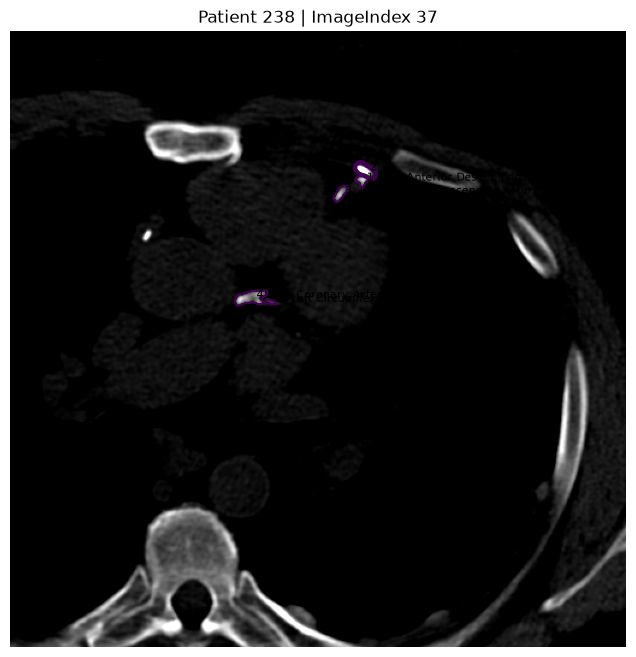

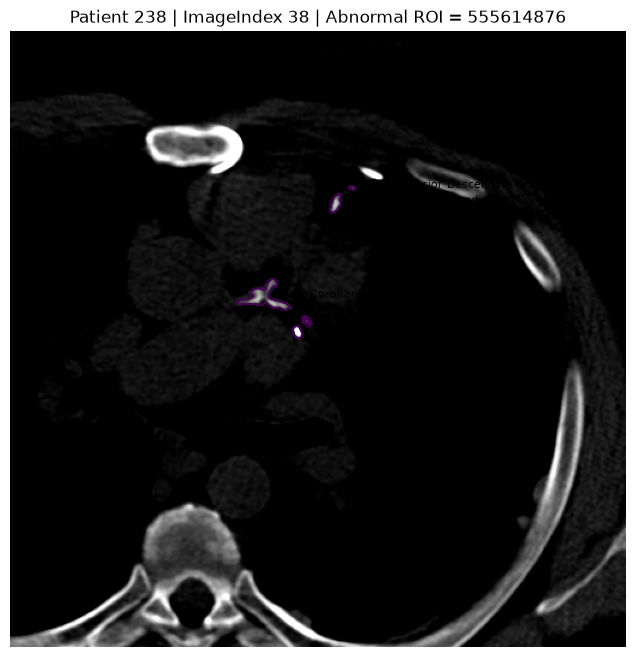

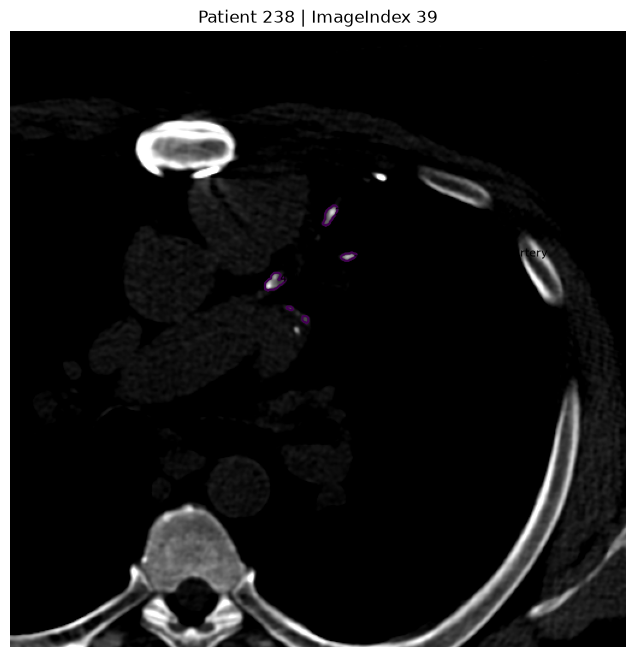

In [40]:
# ============================================================
# STEP 30-4F. Patient 238 문제 ROI 시각화
# - ImageIndex 37 → 이전 위치
# - ImageIndex 38 → 문제 ROI
# - ImageIndex 39 → 다음 slice LCX 존재
# ============================================================

show_image_with_rois(
    patient_238,
    37,
    title="Patient 238 | ImageIndex 37"
)

show_image_with_rois(
    patient_238,
    38,
    title="Patient 238 | ImageIndex 38 | Abnormal ROI = 555614876"
)

show_image_with_rois(
    patient_238,
    39,
    title="Patient 238 | ImageIndex 39"
)

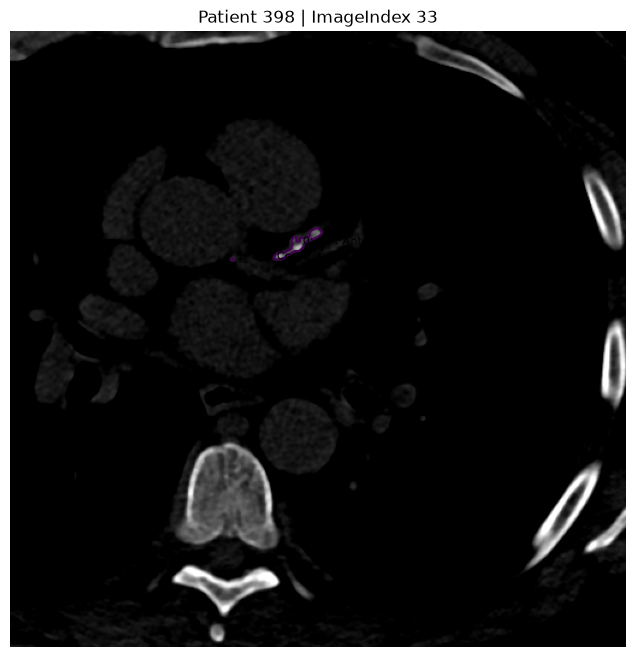

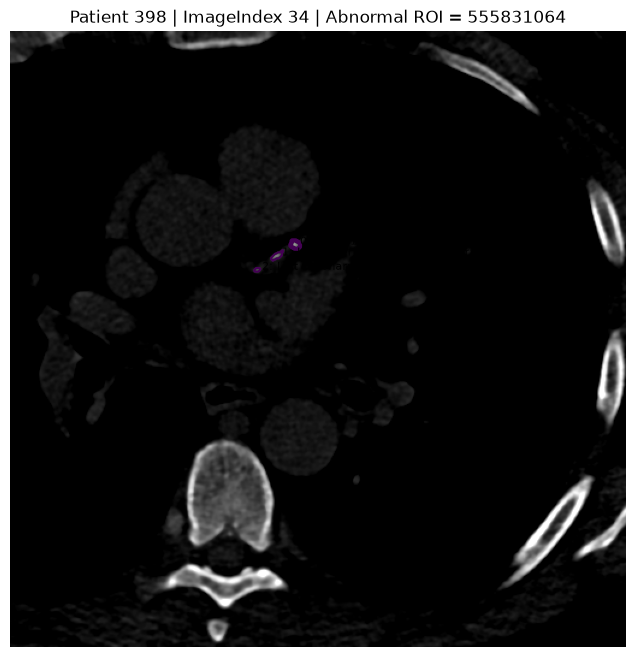

In [41]:
# ============================================================
# STEP 30-4G. Patient 398 문제 ROI 시각화
# - ImageIndex 33 → LAD
# - ImageIndex 34 → 문제 ROI
# ============================================================

show_image_with_rois(
    patient_398,
    33,
    title="Patient 398 | ImageIndex 33"
)

show_image_with_rois(
    patient_398,
    34,
    title="Patient 398 | ImageIndex 34 | Abnormal ROI = 555831064"
)

최종 QC 규칙

| Patient | 원본 Name | 최종 처리 | 근거 |
| ------- | --------- | --------- | ---- |
| 238 | `1` | Ignore | Max HU 105 < 130 |
| 238 | `555614876` | **LCX** | 인접 slice LCX와 위치·영상 연속성 |
| 398 | `555831064` | **LAD** | 이전 slice LAD와 위치·영상 연속성 |
| 415 | `Unnamed` | Ignore | Area=0, HU=0 |
| 421 | `Unnamed` | Ignore | Area=0, HU=0 |

In [42]:
# ============================================================
# STEP 30-5. Manual Annotation QC Rule 확정
# QC correction table: 변수로 명시적으로 남겨둠
# ============================================================

MANUAL_ARTERY_CORRECTIONS = {
    ("238", 38, 1): "Left Circumflex Artery",          # Patient 238
    ("398", 34, 0): "Left Anterior Descending Artery", # Patient 398
}

IGNORE_ROIS = {
    ("238", 37, 2),  # Patient 238 - Max HU = 105 (< 130 HU)
    ("415", 32, 0),  # Patient 415 - Empty / dummy ROI
    ("421", 39, 1),  # Patient 421 - Empty / dummy ROI
}

print("====== Manual QC Rules ======")
print("Correction ROI 수 :", len(MANUAL_ARTERY_CORRECTIONS))
print("Ignore ROI 수 :", len(IGNORE_ROIS))

print("\n[Corrections]")
for key, corrected_name in MANUAL_ARTERY_CORRECTIONS.items():
    patient_id, image_index, roi_index = key

    print(
        f"Patient {patient_id} | ImageIndex {image_index}"
        f" | ROI {roi_index} → {corrected_name}"
    )

print("\n[Ignore]")
for patient_id, image_index, roi_index in sorted(IGNORE_ROIS):
    print(
        f"Patient {patient_id} | ImageIndex {image_index}"
        f" | ROI {roi_index} → IGNORE"
    )

====== Manual QC Rules ======
Correction ROI 수 : 2
Ignore ROI 수 : 3

[Corrections]
Patient 238 | ImageIndex 38 | ROI 1 → Left Circumflex Artery
Patient 398 | ImageIndex 34 | ROI 0 → Left Anterior Descending Artery

[Ignore]
Patient 238 | ImageIndex 37 | ROI 2 → IGNORE
Patient 415 | ImageIndex 32 | ROI 0 → IGNORE
Patient 421 | ImageIndex 39 | ROI 1 → IGNORE


In [43]:
# ============================================================
# STEP 31-1. 최종 CAC Class 정의
# ============================================================

CLASS_NAMES = {
    0: "Background",
    1: "LAD",
    2: "LCX",
    3: "LCA",
    4: "RCA",
}

ARTERY_NAME_TO_CLASS = {
    "Left Anterior Descending Artery": 1,
    "Left Circumflex Artery": 2,
    "Left Coronary Artery": 3,
    "Right Coronary Artery": 4,
}

print("====== CAC Class Definition ======")

for class_id, class_name in CLASS_NAMES.items():
    print(f"{class_id} → {class_name}")

====== CAC Class Definition ======
0 → Background
1 → LAD
2 → LCX
3 → LCA
4 → RCA


In [44]:
# ============================================================
# STEP 31-1. 최종 ROI Label 결정 함수
# 모든 ROI는 이 함수를 통과한 뒤에만 GT mask에 들어감

# - 판단 순서
#   1. Ignore ROI
#   2. Manual Correction
#   3. 정상 Artery Name
#   4. 그 외는 unresolved
# ============================================================

def resolve_roi_class(patient_id, image_index, roi_index, artery_name):

    patient_id = str(patient_id)
    image_index = int(image_index)
    roi_index = int(roi_index)
    artery_name = str(artery_name).strip()

    roi_key = (
        patient_id,
        image_index,
        roi_index
    )

    # --------------------------------------------------------
    # 1. Ignore ROI
    # --------------------------------------------------------

    if roi_key in IGNORE_ROIS:
        return {
            "status": "ignored",
            "original_name": artery_name,
            "final_name": None,
            "class_id": None,
            "class_name": None,
        }

    # --------------------------------------------------------
    # 2. Manual Correction
    # --------------------------------------------------------

    if roi_key in MANUAL_ARTERY_CORRECTIONS:

        corrected_name = MANUAL_ARTERY_CORRECTIONS[
            roi_key
        ]

        class_id = ARTERY_NAME_TO_CLASS[
            corrected_name
        ]

        return {
            "status": "corrected",
            "original_name": artery_name,
            "final_name": corrected_name,
            "class_id": class_id,
            "class_name": CLASS_NAMES[class_id],
        }

    # --------------------------------------------------------
    # 3. 정상 Artery Name
    # --------------------------------------------------------

    if artery_name in ARTERY_NAME_TO_CLASS:

        class_id = ARTERY_NAME_TO_CLASS[
            artery_name
        ]

        return {
            "status": "normal",
            "original_name": artery_name,
            "final_name": artery_name,
            "class_id": class_id,
            "class_name": CLASS_NAMES[class_id],
        }

    # --------------------------------------------------------
    # 4. 알 수 없는 Label
    # --------------------------------------------------------

    return {
        "status": "unresolved",
        "original_name": artery_name,
        "final_name": None,
        "class_id": None,
        "class_name": None,
    }

In [45]:
# ============================================================
# STEP 31-2. QC 규칙 자체 테스트
# ============================================================

test_cases = [
    ("205", 29, 0, "Left Anterior Descending Artery"),  # 정상 LAD
    ("238", 38, 1, "555614876"),                        # numeric label → LCX
    ("398", 34, 0, "555831064"),                        # numeric label → LAD
    ("238", 37, 2, "1"),                                # non-CAC
    ("415", 32, 0, "Unnamed"),                          # dummy ROI
    ("421", 39, 1, "Unnamed"),                          # dummy ROI
]

print("====== ROI Class Resolution Test ======")

for patient_id, image_index, roi_index, artery_name in test_cases:

    result = resolve_roi_class(
        patient_id,
        image_index,
        roi_index,
        artery_name
    )

    print(
        f"\nPatient {patient_id}"
        f" | ImageIndex {image_index}"
        f" | ROI {roi_index}"
    )

    print("Original :", artery_name)
    print("Status   :", result["status"])
    print("Final    :", result["final_name"])
    print("Class    :", result["class_name"])

====== ROI Class Resolution Test ======

Patient 205 | ImageIndex 29 | ROI 0
Original : Left Anterior Descending Artery
Status   : normal
Final    : Left Anterior Descending Artery
Class    : LAD

Patient 238 | ImageIndex 38 | ROI 1
Original : 555614876
Status   : corrected
Final    : Left Circumflex Artery
Class    : LCX

Patient 398 | ImageIndex 34 | ROI 0
Original : 555831064
Status   : corrected
Final    : Left Anterior Descending Artery
Class    : LAD

Patient 238 | ImageIndex 37 | ROI 2
Original : 1
Status   : ignored
Final    : None
Class    : None

Patient 415 | ImageIndex 32 | ROI 0
Original : Unnamed
Status   : ignored
Final    : None
Class    : None

Patient 421 | ImageIndex 39 | ROI 1
Original : Unnamed
Status   : ignored
Final    : None
Class    : None


In [46]:
# ============================================================
# STEP 31-3. Annotation QC 결정사항 checkpoint 저장
# 지금까지 수동으로 검증한 annotation QC 결정사항을 JSON 파일로 저장
# - Artery class 정의
# - Manual correction
# - Ignore ROI
# - 각 결정의 근거
# ============================================================

import json
import os

QC_SAVE_PATH = os.path.join(
    COCA_ROOT,
    "coca_annotation_qc.json"
)

qc_checkpoint = {
    "class_names": {
        "0": "Background",
        "1": "LAD",
        "2": "LCX",
        "3": "LCA",
        "4": "RCA",
    },

    "manual_corrections": [
        {
            "patient_id": "238",
            "image_index": 38,
            "roi_index": 1,
            "original_name": "555614876",
            "corrected_name": "Left Circumflex Artery",
            "reason": "Spatial continuity with adjacent LCX ROI",
        },
        {
            "patient_id": "398",
            "image_index": 34,
            "roi_index": 0,
            "original_name": "555831064",
            "corrected_name": "Left Anterior Descending Artery",
            "reason": "Spatial continuity with adjacent LAD ROI",
        },
    ],

    "ignored_rois": [
        {
            "patient_id": "238",
            "image_index": 37,
            "roi_index": 2,
            "original_name": "1",
            "reason": "Max HU 105 < 130",
        },
        {
            "patient_id": "415",
            "image_index": 32,
            "roi_index": 0,
            "original_name": "Unnamed",
            "reason": "Zero-area dummy ROI",
        },
        {
            "patient_id": "421",
            "image_index": 39,
            "roi_index": 1,
            "original_name": "Unnamed",
            "reason": "Zero-area dummy ROI",
        },
    ],
}

with open(QC_SAVE_PATH, "w", encoding="utf-8") as f:
    json.dump(
        qc_checkpoint,
        f,
        ensure_ascii=False,
        indent=4
    )

print("====== QC Checkpoint 저장 완료 ======")
print("경로 :", QC_SAVE_PATH)
print("파일 존재 :", os.path.exists(QC_SAVE_PATH))

====== QC Checkpoint 저장 완료 ======
경로 : /home/korea1/workspace/datasets/COCA/coca_annotation_qc.json
파일 존재 : True


In [47]:
# ============================================================
# STEP 32-1. 전체 COCA XML Class Mapping 최종 검증
# ============================================================

mapping_status_counter = Counter()
class_roi_counter = Counter()
unresolved_rois = []
total_roi_count = 0

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    for xml_path in calcium_xml_files:

        # ----------------------------------------------------
        # Patient ID
        # 예: calcium_xml/205.xml → "205"
        # ----------------------------------------------------

        patient_id = PurePosixPath(xml_path).stem

        # ----------------------------------------------------
        # XML Parsing
        # ----------------------------------------------------

        try:
            plist_temp = plistlib.loads(
                z.read(xml_path)
            )

        except Exception as e:
            print(
                "XML Parsing 실패 :",
                xml_path,
                e
            )
            continue

        # ----------------------------------------------------
        # Image 단위 반복
        # ----------------------------------------------------

        for image_info in plist_temp.get("Images", []):
            image_index = int(
                image_info["ImageIndex"]
            )

            # ------------------------------------------------
            # ROI 단위 반복
            # ------------------------------------------------

            for roi_index, roi in enumerate(
                image_info.get("ROIs", [])
            ):
                total_roi_count += 1

                artery_name = str(
                    roi.get("Name", "Unknown")
                ).strip()

                # --------------------------------------------
                # 최종 QC 함수 적용
                # --------------------------------------------

                result = resolve_roi_class(
                    patient_id,
                    image_index,
                    roi_index,
                    artery_name
                )

                status = result["status"]

                # normal / corrected / ignored / unresolved
                mapping_status_counter[status] += 1

                # 실제 학습에 사용되는 artery class
                if result["class_id"] is not None:
                    class_name = result["class_name"]
                    class_roi_counter[class_name] += 1

                # 처리 방법을 모르는 ROI는 따로 저장
                if status == "unresolved":
                    unresolved_rois.append({
                        "patient_id": patient_id,
                        "image_index": image_index,
                        "roi_index": roi_index,
                        "artery_name": artery_name,
                        "area": roi.get("Area"),
                        "min_hu": roi.get("Min"),
                        "max_hu": roi.get("Max"),
                    })

In [48]:
# ============================================================
# STEP 32-2. 전체 Mapping QC 결과 확인
# ============================================================

print("====== COCA 전체 ROI Mapping 결과 ======")
print("\n전체 XML ROI 수 :", total_roi_count)

# ------------------------------------------------------------
# Status별 개수
# ------------------------------------------------------------

print("\n[Mapping Status]")

for status in [
    "normal",
    "corrected",
    "ignored",
    "unresolved",
]:
    print(
        f"{status:12s} : "
        f"{mapping_status_counter[status]:,}"
    )

# ------------------------------------------------------------
# 최종 Class별 ROI 수
# ------------------------------------------------------------

print("\n[Final Class ROI Count]")

for class_id in range(1, 5):
    class_name = CLASS_NAMES[class_id]

    print(
        f"{class_id} | "
        f"{class_name:5s} | "
        f"{class_roi_counter[class_name]:,}"
    )

# ------------------------------------------------------------
# Unresolved 확인
# ------------------------------------------------------------

print("\n[Unresolved ROI]")
print(
    "Unresolved ROI 수 :",
    len(unresolved_rois)
)

for item in unresolved_rois:
    print(item)

====== COCA 전체 ROI Mapping 결과 ======

전체 XML ROI 수 : 9152

[Mapping Status]
normal       : 9,147
corrected    : 2
ignored      : 3
unresolved   : 0

[Final Class ROI Count]
1 | LAD   | 3,550
2 | LCX   | 1,874
3 | LCA   | 486
4 | RCA   | 3,239

[Unresolved ROI]
Unresolved ROI 수 : 0


In [49]:
# ============================================================
# STEP 32-3. 전체 Mapping 자동 검증
# ============================================================

print("====== STEP 32 자동 검증 ======")

# ------------------------------------------------------------
# 1. Unresolved ROI
# ------------------------------------------------------------

unresolved_ok = (
    len(unresolved_rois) == 0
)

print(
    "Unresolved ROI = 0 :",
    unresolved_ok
)

# ------------------------------------------------------------
# 2. 전체 ROI 수 보존 확인
# ------------------------------------------------------------

status_total = sum(
    mapping_status_counter.values()
)

total_count_ok = (
    status_total == total_roi_count
)

print(
    "전체 ROI 수 보존 :",
    total_count_ok
)

print(
    f"  XML ROI = {total_roi_count:,}"
)

print(
    f"  Status 합계 = {status_total:,}"
)

# ------------------------------------------------------------
# 3. 사용 ROI + Ignore = 전체 ROI
# ------------------------------------------------------------

used_roi_count = sum(
    class_roi_counter.values()
)

ignored_roi_count = (
    mapping_status_counter["ignored"]
)

usage_count_ok = (
    used_roi_count
    + ignored_roi_count
    == total_roi_count
)

print(
    "사용 ROI + Ignore = 전체 :",
    usage_count_ok
)

print(
    f"  사용 ROI = {used_roi_count:,}"
)

print(
    f"  Ignore = {ignored_roi_count:,}"
)

# ------------------------------------------------------------
# 최종 판정
# ------------------------------------------------------------

step32_pass = (
    unresolved_ok
    and total_count_ok
    and usage_count_ok
)

print("\n==============================")

if step32_pass:
    print(
        "STEP 32 RESULT : PASS ✅"
    )

else:
    print(
        "STEP 32 RESULT : FAIL ❌"
    )

print("==============================")

====== STEP 32 자동 검증 ======
Unresolved ROI = 0 : True
전체 ROI 수 보존 : True
  XML ROI = 9,152
  Status 합계 = 9,152
사용 ROI + Ignore = 전체 : True
  사용 ROI = 9,149
  Ignore = 3

STEP 32 RESULT : PASS ✅


In [50]:
# ============================================================
# STEP 32-4. 전체 Mapping QC 결과 Checkpoint 저장
# ============================================================

import json

MAPPING_QC_PATH = os.path.join(
    COCA_ROOT,
    "coca_mapping_qc_summary.json"
)

mapping_qc_summary = {
    "total_roi_count": int(total_roi_count),

    "mapping_status": {
        key: int(value)
        for key, value in mapping_status_counter.items()
    },

    "class_roi_count": {
        key: int(value)
        for key, value in class_roi_counter.items()
    },

    "unresolved_roi_count": int(
        len(unresolved_rois)
    ),

    "step32_pass": bool(
        step32_pass
    ),
}

with open(
    MAPPING_QC_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        mapping_qc_summary,
        f,
        ensure_ascii=False,
        indent=4
    )

print("====== STEP 32 Checkpoint 저장 ======")
print("경로 :", MAPPING_QC_PATH)
print(
    "파일 존재 :",
    os.path.exists(MAPPING_QC_PATH)
)

====== STEP 32 Checkpoint 저장 ======
경로 : /home/korea1/workspace/datasets/COCA/coca_mapping_qc_summary.json
파일 존재 : True


In [51]:
# ============================================================
# STEP 33-1. Patient 205 Annotation → 최종 Class Mapping
# - 기존 annotation 리스트 그대로 유지
# - resolve_roi_class() 결과 붙인 새로운 리스트 생성
# ============================================================

resolved_annotations = []

for annotation in annotations:

    image_index = annotation["image_index"]
    roi_index = annotation["roi_index"]
    artery_name = annotation["artery_name"]

    result = resolve_roi_class(
        TEST_PATIENT_ID,
        image_index,
        roi_index,
        artery_name
    )

    resolved_annotation = annotation.copy()

    resolved_annotation.update({
        "mapping_status": result["status"],
        "final_artery_name": result["final_name"],
        "class_id": result["class_id"],
        "class_name": result["class_name"],
    })

    resolved_annotations.append(
        resolved_annotation
    )

print(
    "Resolved Annotation 수 :",
    len(resolved_annotations)
)

Resolved Annotation 수 : 4


In [52]:
# ============================================================
# STEP 33-2. Patient 205 Class Mapping 결과 확인
# ============================================================

print("====== Patient 205 Final Annotation Mapping ======")

for annotation in resolved_annotations:

    print("\n----------------------------------------")

    print(
        "ImageIndex :",
        annotation["image_index"]
    )

    print(
        "ROI Index :",
        annotation["roi_index"]
    )

    print(
        "Original Artery :",
        annotation["artery_name"]
    )

    print(
        "Mapping Status :",
        annotation["mapping_status"]
    )

    print(
        "Final Artery :",
        annotation["final_artery_name"]
    )

    print(
        "Class ID :",
        annotation["class_id"]
    )

    print(
        "Class Name :",
        annotation["class_name"]
    )

====== Patient 205 Final Annotation Mapping ======

----------------------------------------
ImageIndex : 29
ROI Index : 0
Original Artery : Left Anterior Descending Artery
Mapping Status : normal
Final Artery : Left Anterior Descending Artery
Class ID : 1
Class Name : LAD

----------------------------------------
ImageIndex : 31
ROI Index : 0
Original Artery : Left Anterior Descending Artery
Mapping Status : normal
Final Artery : Left Anterior Descending Artery
Class ID : 1
Class Name : LAD

----------------------------------------
ImageIndex : 32
ROI Index : 0
Original Artery : Left Anterior Descending Artery
Mapping Status : normal
Final Artery : Left Anterior Descending Artery
Class ID : 1
Class Name : LAD

----------------------------------------
ImageIndex : 33
ROI Index : 0
Original Artery : Left Anterior Descending Artery
Mapping Status : normal
Final Artery : Left Anterior Descending Artery
Class ID : 1
Class Name : LAD


In [53]:
# ============================================================
# STEP 33-3. Patient 205 Mapping 자동 검증
# ============================================================

print("====== STEP 33 자동 검증 ======")

# ------------------------------------------------------------
# 1. ROI 수
# ------------------------------------------------------------

roi_count_ok = (
    len(resolved_annotations) == 4
)

print(
    "ROI 수 = 4 :",
    roi_count_ok
)

# ------------------------------------------------------------
# 2. Unresolved 없음
# ------------------------------------------------------------

unresolved_count = sum(
    annotation["mapping_status"] == "unresolved"
    for annotation in resolved_annotations
)

unresolved_ok = (
    unresolved_count == 0
)

print(
    "Unresolved ROI = 0 :",
    unresolved_ok
)

# ------------------------------------------------------------
# 3. Ignore 없음
# ------------------------------------------------------------

ignored_count = sum(
    annotation["mapping_status"] == "ignored"
    for annotation in resolved_annotations
)

ignored_ok = (
    ignored_count == 0
)

print(
    "Ignored ROI = 0 :",
    ignored_ok
)

# ------------------------------------------------------------
# 4. 모든 Class가 LAD인지 확인
# ------------------------------------------------------------

all_lad = all(
    annotation["class_id"] == 1
    for annotation in resolved_annotations
)

print(
    "모든 ROI Class = LAD :",
    all_lad
)

# ------------------------------------------------------------
# 최종 판정
# ------------------------------------------------------------

step33_pass = (
    roi_count_ok
    and unresolved_ok
    and ignored_ok
    and all_lad
)

print("\n==============================")

if step33_pass:
    print("STEP 33 RESULT : PASS ✅")

else:
    print("STEP 33 RESULT : FAIL ❌")

print("==============================")

====== STEP 33 자동 검증 ======
ROI 수 = 4 : True
Unresolved ROI = 0 : True
Ignored ROI = 0 : True
모든 ROI Class = LAD : True

STEP 33 RESULT : PASS ✅


In [54]:
# ============================================================
# STEP 33-4. 최종 Annotation에 Volume Index 연결
# ============================================================

matching_lookup = {
    result["image_index"]: result["volume_index"]
    for result in matching_results
}

for annotation in resolved_annotations:
    image_index = annotation["image_index"]

    if image_index not in matching_lookup:
        raise ValueError(
            f"Volume Index를 찾을 수 없습니다. ImageIndex = {image_index}"
        )

    annotation["volume_index"] = matching_lookup[image_index]


print("====== Final Annotation + Volume Index ======")

for annotation in resolved_annotations:
    print(
        f"ImageIndex {annotation['image_index']:3d}"
        f" → Volume Index {annotation['volume_index']:3d}"
        f" | Class {annotation['class_id']} ({annotation['class_name']})"
    )

====== Final Annotation + Volume Index ======
ImageIndex  29 → Volume Index  29 | Class 1 (LAD)
ImageIndex  31 → Volume Index  31 | Class 1 (LAD)
ImageIndex  32 → Volume Index  32 | Class 1 (LAD)
ImageIndex  33 → Volume Index  33 | Class 1 (LAD)


In [55]:
# ============================================================
# STEP 34-1. 빈 3D Multi-class GT Mask 생성
# CT 원본이랑 완전히 같은 (Depth, Height, Width) 크기의 mask를 만듦

# mask 값
# - 0 = Background
# - 1 = LAD
# - 2 = LCX
# - 3 = LCA
# - 4 = RCA
# ============================================================

gt_mask = np.zeros(
    ct_hu.shape,
    dtype=np.uint8
)

print("====== Empty GT Mask ======")
print("CT Shape :", ct_hu.shape)
print("GT Shape :", gt_mask.shape)
print("GT dtype :", gt_mask.dtype)
print("Unique Class :", np.unique(gt_mask))

====== Empty GT Mask ======
CT Shape : (47, 512, 512)
GT Shape : (47, 512, 512)
GT dtype : uint8
Unique Class : [0]


In [56]:
# ============================================================
# STEP 34-2. XML ROI Polygon → 3D Multi-class GT Mask
# XML Polygon을 실제 GT Mask에 넣음
# - Point_px → Polygon 채우기
# - Volume Index 위치에 삽입
# - 해당 artery class 값으로 저장
# ============================================================

overlap_records = []
roi_creation_records = []

for annotation in resolved_annotations:

    # --------------------------------------------------------
    # 기본 정보
    # --------------------------------------------------------

    volume_index = annotation["volume_index"]
    image_index = annotation["image_index"]
    roi_index = annotation["roi_index"]
    class_id = annotation["class_id"]
    class_name = annotation["class_name"]

    # --------------------------------------------------------
    # Ignore / Unresolved 방어
    # --------------------------------------------------------

    if class_id is None:
        raise ValueError(
            f"Class ID가 없습니다. "
            f"ImageIndex={image_index} ROI={roi_index}"
        )

    # --------------------------------------------------------
    # XML Point_px → 2D Polygon Mask
    # --------------------------------------------------------

    roi_mask = create_roi_mask(
        annotation["points_px"],
        gt_mask[volume_index].shape
    )

    roi_pixel_count = int(
        np.sum(roi_mask)
    )

    if roi_pixel_count == 0:
        raise ValueError(
            f"빈 ROI Mask 발생: "
            f"ImageIndex={image_index} ROI={roi_index}"
        )

    # --------------------------------------------------------
    # 현재 GT slice
    # --------------------------------------------------------

    current_slice = gt_mask[volume_index]

    # --------------------------------------------------------
    # 이미 Label이 존재하는 영역 확인
    # --------------------------------------------------------

    existing_values = current_slice[roi_mask]

    overlap_values = np.unique(
        existing_values[
            existing_values != 0
        ]
    )

    if len(overlap_values) > 0:
        overlap_records.append({
            "image_index": image_index,
            "volume_index": volume_index,
            "roi_index": roi_index,
            "new_class": class_id,
            "existing_classes": overlap_values.tolist(),
        })

    # --------------------------------------------------------
    # GT에 Class ID 기록
    # --------------------------------------------------------

    current_slice[roi_mask] = class_id

    # --------------------------------------------------------
    # 생성 기록
    # --------------------------------------------------------

    roi_creation_records.append({
        "image_index": image_index,
        "volume_index": volume_index,
        "roi_index": roi_index,
        "class_id": class_id,
        "class_name": class_name,
        "pixel_count": roi_pixel_count,
    })

In [57]:
# ============================================================
# STEP 34-3. 생성된 GT ROI 확인
# 어떤 ROI가 몇 pixel로 만들어졌는지 확인
# ============================================================

print("====== GT ROI Creation Result ======")

for record in roi_creation_records:
    print(
        f"ImageIndex {record['image_index']:3d} | Volume Index {record['volume_index']:3d}"
        f" | ROI {record['roi_index']} | Class {record['class_id']} ({record['class_name']})"
        f" | Pixels = {record['pixel_count']}"
    )

print("\nOverlap ROI 수 :", len(overlap_records))

if len(overlap_records) > 0:
    print("\n[Overlap Detail]")

    for record in overlap_records:
        print(record)

====== GT ROI Creation Result ======
ImageIndex  29 | Volume Index  29 | ROI 0 | Class 1 (LAD) | Pixels = 19
ImageIndex  31 | Volume Index  31 | ROI 0 | Class 1 (LAD) | Pixels = 21
ImageIndex  32 | Volume Index  32 | ROI 0 | Class 1 (LAD) | Pixels = 62
ImageIndex  33 | Volume Index  33 | ROI 0 | Class 1 (LAD) | Pixels = 39

Overlap ROI 수 : 0


In [58]:
# ============================================================
# STEP 34-4. 3D Multi-class GT Mask 전체 확인
# 완성된 3D GT Mask 전체 검사
# ============================================================

unique_classes, class_counts = np.unique(
    gt_mask,
    return_counts=True
)

print("====== Final 3D GT Mask ======")
print("Shape :", gt_mask.shape)
print("dtype :", gt_mask.dtype)
print("Unique Classes :", unique_classes)

print("\n[Class Pixel Count]")

for class_id, pixel_count in zip(
    unique_classes,
    class_counts
):
    print(
        f"{class_id} | "
        f"{CLASS_NAMES[int(class_id)]:10s} | "
        f"{int(pixel_count):,} pixels"
    )

====== Final 3D GT Mask ======
Shape : (47, 512, 512)
dtype : uint8
Unique Classes : [0 1]

[Class Pixel Count]
0 | Background | 12,320,627 pixels
1 | LAD        | 141 pixels


In [59]:
# ============================================================
# STEP 34-5. Calcium이 존재하는 Slice 확인
# ============================================================

cac_slice_indices = []

for volume_index in range(gt_mask.shape[0]):
    positive_pixel_count = int(
        np.sum(gt_mask[volume_index] > 0)
    )

    if positive_pixel_count > 0:
        cac_slice_indices.append(volume_index)

        print(
            f"Volume Index {volume_index:3d}"
            f" | CAC Pixels = {positive_pixel_count}"
        )

print("\nCAC Slice :", cac_slice_indices)

Volume Index  29 | CAC Pixels = 19
Volume Index  31 | CAC Pixels = 21
Volume Index  32 | CAC Pixels = 62
Volume Index  33 | CAC Pixels = 39

CAC Slice : [29, 31, 32, 33]


In [60]:
# ============================================================
# STEP 34-6. GT Mask 자동 검증
# ============================================================

print("====== STEP 34 자동 검증 ======")

# Shape
shape_ok = (
    gt_mask.shape == ct_hu.shape
)

print(
    "CT / GT Shape 일치 :",
    shape_ok
)

# dtype
dtype_ok = (
    gt_mask.dtype == np.uint8
)

print(
    "GT dtype = uint8 :",
    dtype_ok
)

# Class
unique_ok = np.array_equal(
    np.unique(gt_mask),
    np.array([0, 1], dtype=np.uint8)
)

print(
    "Unique Class = [0, 1] :",
    unique_ok
)

# LAD Pixel
lad_pixel_count = int(
    np.sum(gt_mask == 1)
)

lad_pixel_ok = (
    lad_pixel_count == 141
)

print(
    "LAD Pixel = 141 :",
    lad_pixel_ok
)

print(
    "실제 LAD Pixel :",
    lad_pixel_count
)

# CAC Slice
expected_cac_slices = [
    29,
    31,
    32,
    33,
]

slice_ok = (
    cac_slice_indices == expected_cac_slices
)

print(
    "CAC Slice 일치 :",
    slice_ok
)

# Overlap
overlap_ok = (
    len(overlap_records) == 0
)

print(
    "ROI Overlap = 0 :",
    overlap_ok
)

# ------------------------------------------------------------
# 최종 판정
# ------------------------------------------------------------

step34_pass = (
    shape_ok
    and dtype_ok
    and unique_ok
    and lad_pixel_ok
    and slice_ok
    and overlap_ok
)

print("\n==============================")

if step34_pass:
    print("STEP 34 RESULT : PASS ✅")

else:
    print("STEP 34 RESULT : FAIL ❌")

print("==============================")

====== STEP 34 자동 검증 ======
CT / GT Shape 일치 : True
GT dtype = uint8 : True
Unique Class = [0, 1] : True
LAD Pixel = 141 : True
실제 LAD Pixel : 141
CAC Slice 일치 : True
ROI Overlap = 0 : True

STEP 34 RESULT : PASS ✅


In [61]:
# ============================================================
# STEP 35-1. QA 대상 Slice 선택
# ============================================================

QA_VOLUME_INDEX = 32

qa_ct_slice = ct_hu[QA_VOLUME_INDEX]
qa_gt_slice = gt_mask[QA_VOLUME_INDEX]

print("====== STEP 35 QA Slice ======")
print("Volume Index :", QA_VOLUME_INDEX)
print("CT Shape :", qa_ct_slice.shape)
print("GT Shape :", qa_gt_slice.shape)
print("GT Unique :", np.unique(qa_gt_slice))
print("CAC Pixel 수 :", int(np.sum(qa_gt_slice > 0)))

====== STEP 35 QA Slice ======
Volume Index : 32
CT Shape : (512, 512)
GT Shape : (512, 512)
GT Unique : [0 1]
CAC Pixel 수 : 62


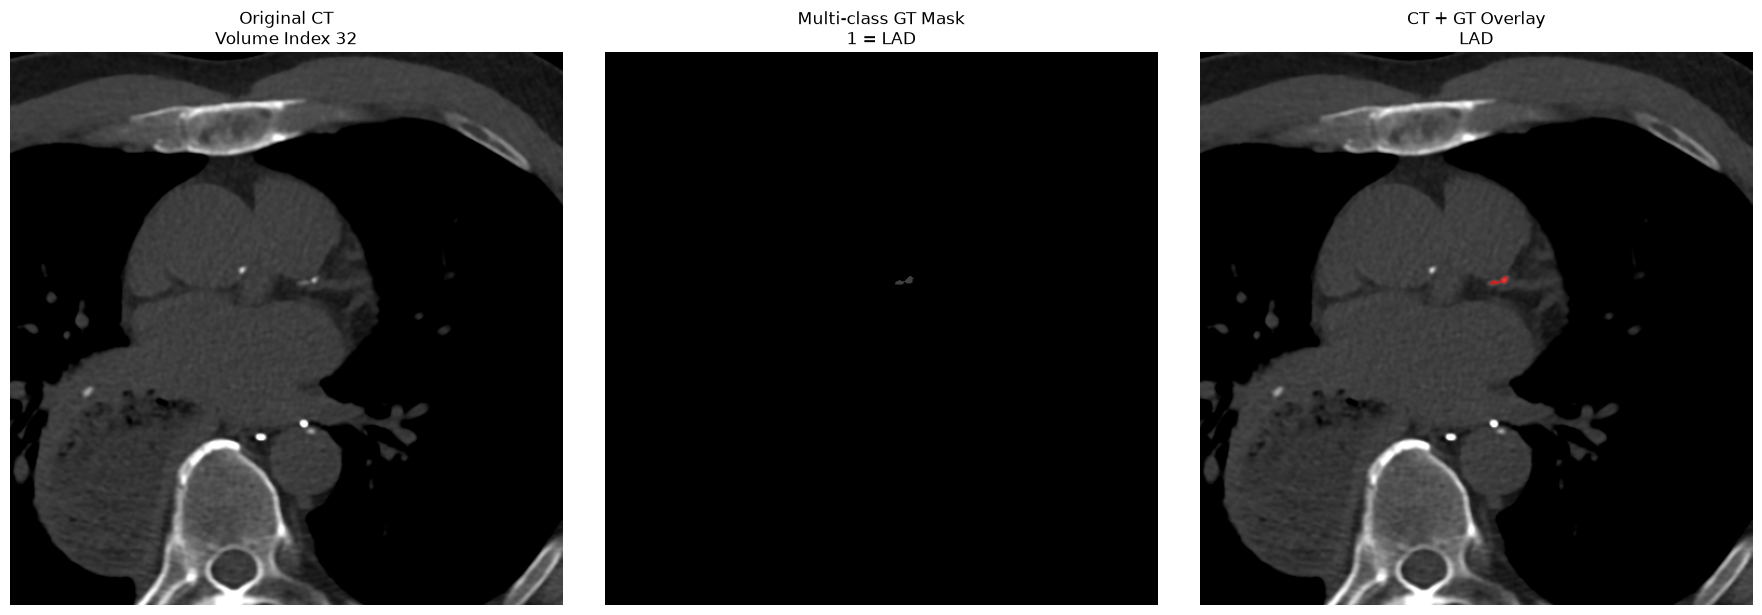

In [62]:
# ============================================================
# STEP 35-2. CT / GT / Overlay 시각화
# ① Original CT
# ② GT Mask
# ③ CT + GT Overlay
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# ------------------------------------------------------------
# 1. Original CT
# ------------------------------------------------------------

axes[0].imshow(
    qa_ct_slice,
    cmap="gray",
    vmin=-200,
    vmax=800
)

axes[0].set_title(
    "Original CT\nVolume Index 32"
)

axes[0].axis("off")

# ------------------------------------------------------------
# 2. Ground Truth Mask
# ------------------------------------------------------------

axes[1].imshow(
    qa_gt_slice,
    cmap="gray",
    vmin=0,
    vmax=4
)

axes[1].set_title(
    "Multi-class GT Mask\n1 = LAD"
)

axes[1].axis("off")

# ------------------------------------------------------------
# 3. CT + GT Overlay
# ------------------------------------------------------------

axes[2].imshow(
    qa_ct_slice,
    cmap="gray",
    vmin=-200,
    vmax=800
)

# Background(0)은 보이지 않게 처리
masked_gt = np.ma.masked_where(
    qa_gt_slice == 0,
    qa_gt_slice
)

axes[2].imshow(
    masked_gt,
    cmap="autumn",
    alpha=0.65,
    vmin=1,
    vmax=4
)

axes[2].set_title(
    "CT + GT Overlay\nLAD"
)

axes[2].axis("off")

plt.tight_layout()
plt.show()

In [63]:
# ============================================================
# STEP 35-3. GT 영역 자동 Bounding Box + Zoom
# Calcium 부분 자동 Zoom 해서 주변만 확대
# ============================================================

positive_y, positive_x = np.where(
    qa_gt_slice > 0
)

if len(positive_x) == 0:
    raise ValueError(
        "QA Slice에 CAC Mask가 없습니다."
    )

# ------------------------------------------------------------
# GT Bounding Box
# ------------------------------------------------------------

x_min = int(np.min(positive_x))
x_max = int(np.max(positive_x))

y_min = int(np.min(positive_y))
y_max = int(np.max(positive_y))

# ------------------------------------------------------------
# 주변 여백
# ------------------------------------------------------------

MARGIN = 30

x_start = max(
    0,
    x_min - MARGIN
)

x_end = min(
    qa_ct_slice.shape[1],
    x_max + MARGIN + 1
)

y_start = max(
    0,
    y_min - MARGIN
)

y_end = min(
    qa_ct_slice.shape[0],
    y_max + MARGIN + 1
)

print("====== GT Bounding Box ======")
print(f"X : {x_min} ~ {x_max}")
print(f"Y : {y_min} ~ {y_max}")

print("\nZoom Range")
print(f"X : {x_start} ~ {x_end}")
print(f"Y : {y_start} ~ {y_end}")

====== GT Bounding Box ======
X : 269 ~ 285
Y : 207 ~ 214

Zoom Range
X : 239 ~ 316
Y : 177 ~ 245


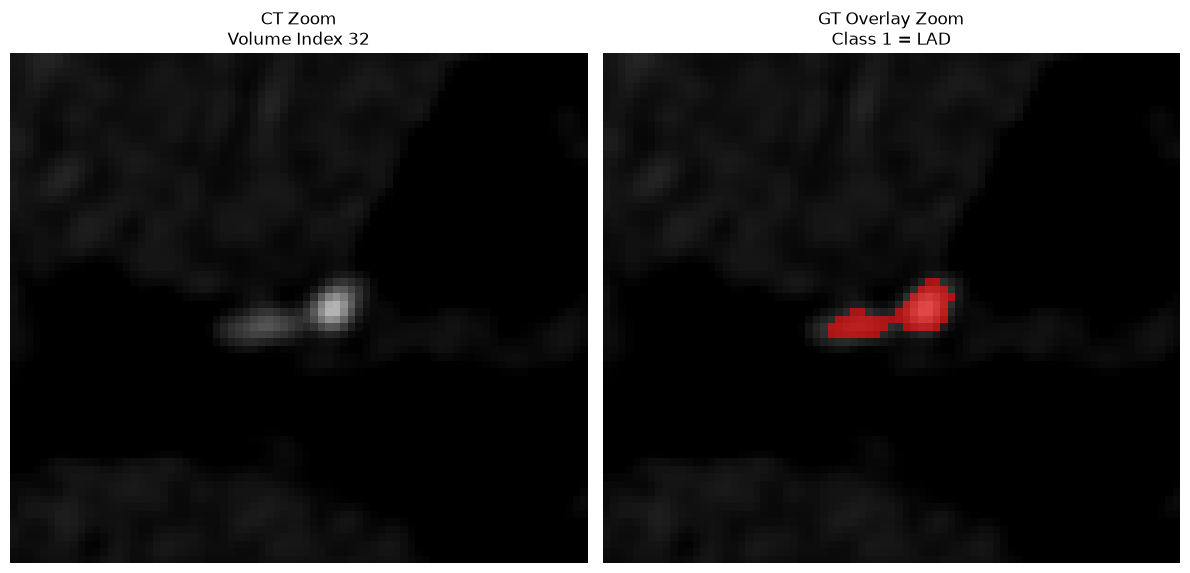

In [64]:
# ============================================================
# STEP 35-4. Zoom CT + Overlay 시각화
# ============================================================

ct_zoom = qa_ct_slice[
    y_start:y_end,
    x_start:x_end
]

gt_zoom = qa_gt_slice[
    y_start:y_end,
    x_start:x_end
]

masked_gt_zoom = np.ma.masked_where(
    gt_zoom == 0,
    gt_zoom
)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# ------------------------------------------------------------
# Original CT Zoom
# ------------------------------------------------------------

axes[0].imshow(
    ct_zoom,
    cmap="gray",
    vmin=0,
    vmax=700
)

axes[0].set_title(
    "CT Zoom\nVolume Index 32"
)

axes[0].axis("off")

# ------------------------------------------------------------
# Overlay Zoom
# ------------------------------------------------------------

axes[1].imshow(
    ct_zoom,
    cmap="gray",
    vmin=0,
    vmax=700
)

axes[1].imshow(
    masked_gt_zoom,
    cmap="autumn",
    alpha=0.60,
    vmin=1,
    vmax=4
)

axes[1].set_title(
    "GT Overlay Zoom\nClass 1 = LAD"
)

axes[1].axis("off")

plt.tight_layout()
plt.show()

In [65]:
# ============================================================
# STEP 35-5. 완성된 GT Mask 내부 HU 검증
# overlay를 눈으로만 확인하지 않고 HU 재검증
# - GT mask 내부 HU 직접 계산
# - 완성된 gt_mask 자체에서 값을 다시 추출
# ============================================================

gt_hu_values = qa_ct_slice[
    qa_gt_slice == 1
]

gt_pixel_count = len(
    gt_hu_values
)

gt_min_hu = float(
    np.min(gt_hu_values)
)

gt_mean_hu = float(
    np.mean(gt_hu_values)
)

gt_max_hu = float(
    np.max(gt_hu_values)
)

print("====== GT Mask 내부 HU ======")
print("Pixel 수 :", gt_pixel_count)
print(f"Min HU  : {gt_min_hu:.3f}")
print(f"Mean HU : {gt_mean_hu:.3f}")
print(f"Max HU  : {gt_max_hu:.3f}")

====== GT Mask 내부 HU ======
Pixel 수 : 62
Min HU  : 133.000
Mean HU : 235.419
Max HU  : 493.000


In [66]:
# ============================================================
# STEP 35-6. GT Overlay QA 수치 자동 검증
# ① Numerical QA: Pixel / HU → 코드로 자동 검사
# ② Visual QA: CT calcium과 GT mask가 실제로 겹치는가? → 사람이 직접 확인
# ============================================================

print("====== STEP 35 수치 자동 검증 ======")

pixel_ok = (gt_pixel_count == 62)
min_hu_ok = np.isclose(
    gt_min_hu,
    133.0,
    atol=1e-3
)
mean_hu_ok = np.isclose(
    gt_mean_hu,
    235.4193572998047,
    atol=1e-3
)
max_hu_ok = np.isclose(
    gt_max_hu,
    493.0,
    atol=1e-3
)

print("Pixel = 62 :", pixel_ok)
print("Min HU = 133 :", min_hu_ok)
print("Mean HU = 235.419 :", mean_hu_ok)
print("Max HU = 493 :", max_hu_ok)

step35_numeric_pass = (
    pixel_ok
    and min_hu_ok
    and mean_hu_ok
    and max_hu_ok
)

print("\n==============================")

if step35_numeric_pass:
    print("STEP 35 NUMERIC RESULT : PASS ✅")
else:
    print("STEP 35 NUMERIC RESULT : FAIL ❌")

print("==============================")

====== STEP 35 수치 자동 검증 ======
Pixel = 62 : True
Min HU = 133 : True
Mean HU = 235.419 : True
Max HU = 493 : True

STEP 35 NUMERIC RESULT : PASS ✅


In [67]:
# ============================================================
# STEP 35-7. Patient 205 Original-space GT Checkpoint 저장
# GT mask와 핵심 metadata만 저장
# ============================================================

PATIENT205_GT_PATH = os.path.join(
    COCA_ROOT,
    "patient205_gt_original_space.npz"
)

np.savez_compressed(
    PATIENT205_GT_PATH,
    gt_mask=gt_mask,

    patient_id=np.array(TEST_PATIENT_ID),
    ct_shape=np.array(ct_hu.shape, dtype=np.int32),

    class_ids=np.array(
        [0, 1, 2, 3, 4],
        dtype=np.uint8
    ),

    class_names=np.array(
        ["Background", "LAD", "LCX", "LCA", "RCA"]
    ),

    cac_slice_indices=np.array(
        cac_slice_indices,
        dtype=np.int32
    ),
)

print("====== Patient 205 GT Checkpoint ======")
print("경로 :", PATIENT205_GT_PATH)
print("파일 존재 :", os.path.exists(PATIENT205_GT_PATH))
print(
    "파일 크기 :",
    round(
        os.path.getsize(PATIENT205_GT_PATH) / (1024 ** 2),
        3
    ),
    "MB"
)

====== Patient 205 GT Checkpoint ======
경로 : /home/korea1/workspace/datasets/COCA/patient205_gt_original_space.npz
파일 존재 : True
파일 크기 : 0.013 MB


In [68]:
# ============================================================
# STEP 36-1. Empty Placeholder ROI 판별 함수
# ============================================================

def is_empty_placeholder_roi(roi):
    area = float(roi.get("Area", 0.0))

    min_hu = float(roi.get("Min", 0.0))
    mean_hu = float(roi.get("Mean", 0.0))
    max_hu = float(roi.get("Max", 0.0))

    points_px = roi.get("Point_px", [])
    points_mm = roi.get("Point_mm", [])

    number_of_points = int(
        roi.get("NumberOfPoints", len(points_px))
    )

    return (
        np.isclose(area, 0.0)
        and
        np.isclose(min_hu, 0.0)
        and np.isclose(mean_hu, 0.0)
        and np.isclose(max_hu, 0.0)
        and
        number_of_points == 0
        and
        len(points_px) == 0
        and len(points_mm) == 0
    )

In [69]:
# ============================================================
# STEP 36-1. 환자별 Multi-class GT 생성 함수
# ============================================================

def build_patient_multiclass_gt(patient_id):
    patient_id = str(patient_id)

    # --------------------------------------------------------
    # 1. CT + XML Load
    # --------------------------------------------------------

    patient_data = load_patient_ct_and_xml(patient_id)

    ct_volume = patient_data["ct_hu"]
    plist_patient = patient_data["plist"]

    # --------------------------------------------------------
    # 2. 빈 3D GT Mask
    # --------------------------------------------------------

    patient_gt = np.zeros(
        ct_volume.shape,
        dtype=np.uint8
    )

    # --------------------------------------------------------
    # QC 기록
    # --------------------------------------------------------

    qc_records = []
    overlap_records_patient = []
    ignored_records = []
    unresolved_records = []

    # --------------------------------------------------------
    # 3. XML Image 반복
    # --------------------------------------------------------

    for image_info in plist_patient.get("Images", []):
        image_index = int(
            image_info["ImageIndex"]
        )

        # ----------------------------------------------------
        # ROI 반복
        # ----------------------------------------------------

        for roi_index, roi in enumerate(
            image_info.get("ROIs", [])
        ):
            artery_name = str(
                roi.get("Name", "Unknown")
            ).strip()

            # ------------------------------------------------
            # 4. Empty Placeholder ROI 검사
            # ------------------------------------------------

            if is_empty_placeholder_roi(roi):
                ignored_records.append({
                    "image_index": image_index,
                    "roi_index": roi_index,
                    "artery_name": artery_name,
                    "reason": "empty_placeholder",
                })
                continue

            # ------------------------------------------------
            # 5. Final Artery Class 결정
            # ------------------------------------------------

            resolved = resolve_roi_class(
                patient_id,
                image_index,
                roi_index,
                artery_name
            )

            status = resolved["status"]

            # ------------------------------------------------
            # Manual / anomaly Ignore
            # ------------------------------------------------

            if status == "ignored":
                ignored_records.append({
                    "image_index": image_index,
                    "roi_index": roi_index,
                    "artery_name": artery_name,
                    "reason": "manual_ignore",
                })
                continue

            # ------------------------------------------------
            # Unresolved
            # ------------------------------------------------

            if status == "unresolved":
                unresolved_records.append({
                    "image_index": image_index,
                    "roi_index": roi_index,
                    "artery_name": artery_name,
                })
                continue

            class_id = resolved["class_id"]
            class_name = resolved["class_name"]

            # ------------------------------------------------
            # 6. Point_mm / Point_px Parsing
            # ------------------------------------------------

            points_mm = [
                parse_coordinate_string(point)
                for point in roi.get("Point_mm", [])
            ]

            points_px = [
                parse_coordinate_string(point)
                for point in roi.get("Point_px", [])
            ]

            # ------------------------------------------------
            # Empty가 아닌데 geometry가 없는 경우
            # ------------------------------------------------

            if len(points_mm) == 0:
                raise ValueError(
                    f"Non-empty ROI인데 Point_mm 없음"
                    f" | Patient {patient_id}"
                    f" | ImageIndex {image_index}"
                    f" | ROI {roi_index}"
                )

            if len(points_px) < 3:
                raise ValueError(
                    f"Non-empty ROI인데 Polygon Point 부족"
                    f" | Patient {patient_id}"
                    f" | ImageIndex {image_index}"
                    f" | ROI {roi_index}"
                )

            # ------------------------------------------------
            # 7. XML Physical Position
            # ------------------------------------------------

            first_point_mm = np.array(
                points_mm[0],
                dtype=np.float64
            )

            slice_normal = patient_data["slice_normal"]

            xml_position = float(
                np.dot(
                    first_point_mm,
                    slice_normal
                )
            )

            # ------------------------------------------------
            # 8. 가장 가까운 DICOM Slice
            # ------------------------------------------------

            dicom_positions = np.array(
                [
                    item["slice_position"]
                    for item in patient_data["metadata"]
                ],
                dtype=np.float64
            )

            distances = np.abs(
                dicom_positions - xml_position
            )

            volume_index = int(
                np.argmin(distances)
            )

            distance_mm = float(
                distances[volume_index]
            )

            # ------------------------------------------------
            # 9. ROI Polygon 생성
            # ------------------------------------------------

            roi_mask = create_roi_mask(
                points_px,
                patient_gt[volume_index].shape
            )

            pixel_count = int(
                np.sum(roi_mask)
            )

            if pixel_count == 0:
                raise ValueError(
                    f"빈 ROI Polygon 발생"
                    f" | Patient {patient_id}"
                    f" | ImageIndex {image_index}"
                    f" | ROI {roi_index}"
                )

            # ------------------------------------------------
            # 10. 다른 Artery Class와 Overlap 검사
            # ------------------------------------------------

            existing_values = patient_gt[
                volume_index
            ][roi_mask]

            existing_classes = np.unique(
                existing_values[
                    existing_values != 0
                ]
            )

            conflicting_classes = [
                int(value)
                for value in existing_classes
                if int(value) != int(class_id)
            ]

            if len(conflicting_classes) > 0:
                overlap_records_patient.append({
                    "image_index": image_index,
                    "volume_index": volume_index,
                    "roi_index": roi_index,
                    "new_class": int(class_id),
                    "existing_classes": conflicting_classes,
                })

            # ------------------------------------------------
            # 11. GT 기록
            # ------------------------------------------------

            patient_gt[
                volume_index
            ][roi_mask] = class_id

            # ------------------------------------------------
            # 12. QC 기록
            # ------------------------------------------------

            qc_records.append({
                "image_index": image_index,
                "volume_index": volume_index,
                "roi_index": roi_index,
                "status": status,
                "original_name": artery_name,
                "class_id": int(class_id),
                "class_name": class_name,
                "pixel_count": pixel_count,
                "distance_mm": distance_mm,
            })

    # --------------------------------------------------------
    # 13. Unresolved가 남아 있으면 실패
    # --------------------------------------------------------

    if len(unresolved_records) > 0:
        raise ValueError(
            f"Patient {patient_id}: "
            f"Unresolved ROI {len(unresolved_records)}개 발견"
        )

    # --------------------------------------------------------
    # 14. 결과 반환
    # --------------------------------------------------------

    return {
        "patient_id": patient_id,
        "ct_hu": ct_volume,
        "gt_mask": patient_gt,
        "metadata": patient_data["metadata"],
        "slice_normal": patient_data["slice_normal"],
        "qc_records": qc_records,
        "ignored_records": ignored_records,
        "overlap_records": overlap_records_patient,
    }

In [70]:
# ============================================================
# STEP 36-2. 범용 GT 함수 → Patient 205 재검증
# 이미 정답을 알고 있는 Patient 205에 다시 적용해서 기존 결과와 완전히 동일한지 확인
# ============================================================

patient205_result = build_patient_multiclass_gt("205")
patient205_gt_new = patient205_result["gt_mask"]

print("====== Generic GT Function Test ======")
print("Patient :", patient205_result["patient_id"])
print("CT Shape :", patient205_result["ct_hu"].shape)
print("GT Shape :", patient205_gt_new.shape)
print("Unique Class :", np.unique(patient205_gt_new))
print("LAD Pixel :", int(np.sum(patient205_gt_new == 1)))
print("QC ROI 수 :", len(patient205_result["qc_records"]))
print("Ignore ROI 수 :", len(patient205_result["ignored_records"]))
print("Class Conflict 수 :", len(patient205_result["overlap_records"]))

Patient 205 | Series 수 = 1 | 선택 Slice = 47 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (47, 512, 512)
====== Generic GT Function Test ======
Patient : 205
CT Shape : (47, 512, 512)
GT Shape : (47, 512, 512)
Unique Class : [0 1]
LAD Pixel : 141
QC ROI 수 : 4
Ignore ROI 수 : 0
Class Conflict 수 : 0


In [71]:
# ============================================================
# STEP 36-3. 기존 Patient205 GT ↔ 범용 함수 GT 비교
# 기존 GT와 새 GT가 완전히 같은지 검사
# ============================================================

exact_same = np.array_equal(
    gt_mask,
    patient205_gt_new
)

different_pixel_count = int(
    np.sum(gt_mask != patient205_gt_new)
)

print("====== Old GT vs Generic Function GT ======")
print("완전히 동일 :", exact_same)
print("다른 Pixel 수 :", different_pixel_count)

if exact_same and different_pixel_count == 0:
    print("\nSTEP 36 RESULT : PASS ✅")

else:
    print("\nSTEP 36 RESULT : FAIL ❌")

====== Old GT vs Generic Function GT ======
완전히 동일 : True
다른 Pixel 수 : 0

STEP 36 RESULT : PASS ✅


In [72]:
# ============================================================
# STEP 37-1. 특수 QC 환자 GT 생성
# 특수 케이스 4명을 범용 함수에 실제로 넣기
# - Patient 238 → correction + ignore
# - Patient 398 → correction
# - Patient 415 → dummy ignore
# - Patient 421 → dummy ignore
# ============================================================

SPECIAL_QC_PATIENT_IDS = [
    "238",
    "398",
    "415",
    "421",
]

special_patient_results = {}

for patient_id in SPECIAL_QC_PATIENT_IDS:
    print("\n" + "=" * 90)
    print(f"Patient {patient_id} 처리 시작")
    print("=" * 90)

    result = build_patient_multiclass_gt(
        patient_id
    )

    special_patient_results[
        patient_id
    ] = result


Patient 238 처리 시작
Patient 238 | Series 수 = 1 | 선택 Slice = 43 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (43, 512, 512)

Patient 398 처리 시작
Patient 398 | Series 수 = 2 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)

Patient 415 처리 시작
Patient 415 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)

Patient 421 처리 시작
Patient 421 | Series 수 = 1 | 선택 Slice = 51 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (51, 512, 512)


In [73]:
# ============================================================
# STEP 37-2. 특수 QC 환자 결과 요약
# ============================================================

print("====== Special Patient GT Summary ======")

for patient_id in SPECIAL_QC_PATIENT_IDS:
    result = special_patient_results[patient_id]

    ct_volume = result["ct_hu"]
    gt = result["gt_mask"]

    corrected_count = sum(
        record["status"] == "corrected"
        for record in result["qc_records"]
    )

    print("\n" + "-" * 60)
    print("Patient :", patient_id)
    print("CT Shape :", ct_volume.shape)
    print("GT Shape :", gt.shape)
    print("Unique Class :", np.unique(gt))
    print("사용 ROI 수 :", len(result["qc_records"]))
    print("Corrected ROI 수 :", corrected_count)
    print("Ignored ROI 수 :", len(result["ignored_records"]))
    print("Class Conflict 수 :", len(result["overlap_records"]))

====== Special Patient GT Summary ======

------------------------------------------------------------
Patient : 238
CT Shape : (43, 512, 512)
GT Shape : (43, 512, 512)
Unique Class : [0 1 2 3 4]
사용 ROI 수 : 58
Corrected ROI 수 : 1
Ignored ROI 수 : 1
Class Conflict 수 : 0

------------------------------------------------------------
Patient : 398
CT Shape : (46, 512, 512)
GT Shape : (46, 512, 512)
Unique Class : [0 1 2 3 4]
사용 ROI 수 : 22
Corrected ROI 수 : 1
Ignored ROI 수 : 0
Class Conflict 수 : 0

------------------------------------------------------------
Patient : 415
CT Shape : (46, 512, 512)
GT Shape : (46, 512, 512)
Unique Class : [0 1 2 4]
사용 ROI 수 : 22
Corrected ROI 수 : 0
Ignored ROI 수 : 1
Class Conflict 수 : 0

------------------------------------------------------------
Patient : 421
CT Shape : (51, 512, 512)
GT Shape : (51, 512, 512)
Unique Class : [0 1]
사용 ROI 수 : 2
Corrected ROI 수 : 0
Ignored ROI 수 : 1
Class Conflict 수 : 0


In [74]:
# ============================================================
# STEP 37-3. Manual Correction 실제 적용 확인
# Correction이 정말 원하는 혈관으로 들어갔는지 확인
# ============================================================

print("====== Applied Manual Corrections ======")

for patient_id in SPECIAL_QC_PATIENT_IDS:
    result = special_patient_results[patient_id]

    for record in result["qc_records"]:
        if record["status"] == "corrected":
            print(
                f"Patient {patient_id} | ImageIndex {record['image_index']} | ROI {record['roi_index']}"
                f" | Original = {record['original_name']} → Class {record['class_id']} ({record['class_name']})"
                f" | Distance = {record['distance_mm']:.6f} mm"
            )

====== Applied Manual Corrections ======
Patient 238 | ImageIndex 38 | ROI 1 | Original = 555614876 → Class 2 (LCX) | Distance = 0.000000 mm
Patient 398 | ImageIndex 34 | ROI 0 | Original = 555831064 → Class 1 (LAD) | Distance = 0.000000 mm


In [75]:
# ============================================================
# STEP 37-8. Ignore ROI 실제 적용 확인
# ============================================================

print("====== Applied Ignore Rules ======")

for patient_id in SPECIAL_QC_PATIENT_IDS:
    result = special_patient_results[patient_id]

    for record in result["ignored_records"]:
        print(
            f"Patient {patient_id} | ImageIndex {record['image_index']} | ROI {record['roi_index']}"
            f" | Original = {record['artery_name']} → IGNORE"
        )

====== Applied Ignore Rules ======
Patient 238 | ImageIndex 37 | ROI 2 | Original = 1 → IGNORE
Patient 415 | ImageIndex 32 | ROI 0 | Original = Unnamed → IGNORE
Patient 421 | ImageIndex 39 | ROI 1 | Original = Unnamed → IGNORE


In [76]:
# ============================================================
# STEP 37-9. 특수 환자 Physical Matching 거리 확인
# 각 특수 QC 환자의 모든 사용 ROI에 대해 XML annotation과 DICOM slice의 physical position matching 거리를 확인한다.

# - Patient 238
# - Patient 398
# - Patient 415
# - Patient 421

# 각 환자의 최대 XML ↔ DICOM matching distance를 계산한다.
# ============================================================

print("====== Physical Matching QC ======")

special_max_distances = {}

for patient_id in SPECIAL_QC_PATIENT_IDS:
    records = special_patient_results[patient_id]["qc_records"]

    distances = [
        record["distance_mm"]
        for record in records
    ]

    max_distance = (
        float(np.max(distances))
        if len(distances) > 0 else np.nan
    )

    special_max_distances[patient_id] = max_distance

    print(
        f"Patient {patient_id} | Max XML-DICOM Distance = {max_distance:.6f} mm"
    )

====== Physical Matching QC ======
Patient 238 | Max XML-DICOM Distance = 0.000000 mm
Patient 398 | Max XML-DICOM Distance = 0.000000 mm
Patient 415 | Max XML-DICOM Distance = 0.000000 mm
Patient 421 | Max XML-DICOM Distance = 0.000000 mm


In [77]:
# ============================================================
# STEP 37-8. Special Case 자동 검증
# ============================================================

EXPECTED_SPECIAL_QC = {
    "238": {"corrected": 1, "ignored": 1},
    "398": {"corrected": 1, "ignored": 0},
    "415": {"corrected": 0, "ignored": 1},
    "421": {"corrected": 0, "ignored": 1},
}

print("====== STEP 37 자동 검증 ======")

special_case_pass = True

for patient_id in SPECIAL_QC_PATIENT_IDS:
    result = special_patient_results[patient_id]
    gt = result["gt_mask"]

    corrected_count = sum(
        record["status"] == "corrected"
        for record in result["qc_records"]
    )

    ignored_count = len(result["ignored_records"])
    conflict_count = len(result["overlap_records"])

    expected = EXPECTED_SPECIAL_QC[patient_id]

    # --------------------------------------------------------
    # 조건별 검사
    # --------------------------------------------------------
    shape_ok = (result["ct_hu"].shape == gt.shape)
    class_ok = set(np.unique(gt).tolist()).issubset({0, 1, 2, 3, 4})
    correction_ok = (corrected_count == expected["corrected"])
    ignore_ok = (ignored_count == expected["ignored"])
    distance_ok = (special_max_distances[patient_id] < 1e-3)
    conflict_ok = (conflict_count == 0)

    patient_pass = (
        shape_ok
        and class_ok
        and correction_ok
        and ignore_ok
        and distance_ok
        and conflict_ok
    )

    print(f"\nPatient {patient_id}")
    print("CT / GT Shape 일치 :", shape_ok)
    print("GT Class 범위 정상 :", class_ok)
    print("Correction 수 일치 :", correction_ok)
    print("Ignore 수 일치 :", ignore_ok)
    print("Physical Distance < 0.001 mm :", distance_ok)
    print("Class Conflict = 0 :", conflict_ok)
    print("Patient Result :", "PASS ✅" if patient_pass else "FAIL ❌")

    if not patient_pass:
        special_case_pass = False

print("\n==============================")

if special_case_pass:
    print("STEP 37 RESULT : PASS ✅")
else:
    print("STEP 37 RESULT : FAIL ❌")

print("==============================")

====== STEP 37 자동 검증 ======

Patient 238
CT / GT Shape 일치 : True
GT Class 범위 정상 : True
Correction 수 일치 : True
Ignore 수 일치 : True
Physical Distance < 0.001 mm : True
Class Conflict = 0 : True
Patient Result : PASS ✅

Patient 398
CT / GT Shape 일치 : True
GT Class 범위 정상 : True
Correction 수 일치 : True
Ignore 수 일치 : True
Physical Distance < 0.001 mm : True
Class Conflict = 0 : True
Patient Result : PASS ✅

Patient 415
CT / GT Shape 일치 : True
GT Class 범위 정상 : True
Correction 수 일치 : True
Ignore 수 일치 : True
Physical Distance < 0.001 mm : True
Class Conflict = 0 : True
Patient Result : PASS ✅

Patient 421
CT / GT Shape 일치 : True
GT Class 범위 정상 : True
Correction 수 일치 : True
Ignore 수 일치 : True
Physical Distance < 0.001 mm : True
Class Conflict = 0 : True
Patient Result : PASS ✅

STEP 37 RESULT : PASS ✅


In [78]:
# ============================================================
# STEP 38-1. XML / DICOM 환자 ID 비교
# 전체 COCA에 대한 QC를 시작하기 전에 calcium XML과 Gated DICOM이 모두 존재하는 환자 ID를 확인한다.

# - XML Patient 수 확인
# - DICOM Patient 수 확인
# - XML + DICOM 모두 존재하는 Patient 확인
# - XML에만 존재하는 Patient 확인
# - DICOM에만 존재하는 Patient 확인
# ============================================================

from pathlib import Path

GATED_ROOT = Path(COCA_ROOT) / "raw" / "Gated_release_final"
PATIENT_DIR = GATED_ROOT / "patient"
CALCIUM_XML_DIR = GATED_ROOT / "calcium_xml"

# 실제 workstation 파일 목록
calcium_xml_files = sorted(CALCIUM_XML_DIR.glob("*.xml"))
gated_dicom_files = sorted(PATIENT_DIR.rglob("*.dcm"))

# XML Patient IDs
xml_patient_ids = {
    xml_path.stem
    for xml_path in calcium_xml_files
}

# DICOM Patient IDs
dicom_patient_ids = set()

for dicom_path in gated_dicom_files:
    relative_parts = dicom_path.relative_to(PATIENT_DIR).parts

    # patient / ID / Series / *.dcm 에서 ID 추출
    if len(relative_parts) >= 2:
        dicom_patient_ids.add(relative_parts[0])

# XML + DICOM 모두 존재
matched_patient_ids = sorted(
    xml_patient_ids & dicom_patient_ids,
    key=int
)

# XML만 존재
xml_only_patient_ids = sorted(
    xml_patient_ids - dicom_patient_ids,
    key=int
)

# DICOM만 존재
dicom_only_patient_ids = sorted(
    dicom_patient_ids - xml_patient_ids,
    key=int
)

print("====== XML / DICOM Patient Matching ======")
print("XML Patient 수 :", len(xml_patient_ids))
print("DICOM Patient 수 :", len(dicom_patient_ids))
print("XML + DICOM Match :", len(matched_patient_ids))
print("XML Only :", len(xml_only_patient_ids), xml_only_patient_ids)
print("DICOM Only :", len(dicom_only_patient_ids))

====== XML / DICOM Patient Matching ======
XML Patient 수 : 451
DICOM Patient 수 : 787
XML + DICOM Match : 449
XML Only : 2 ['12', '197']
DICOM Only : 338


In [90]:
# ============================================================
# STEP 38-2. Patient별 DICOM Path Index
# ============================================================

dicom_paths_by_patient = {}

for dicom_path in gated_dicom_files:
    path_str = str(dicom_path)
    parts = PurePosixPath(path_str).parts

    try:
        gated_idx = parts.index("Gated_release_final")
    except ValueError:
        continue

    if len(parts) <= gated_idx + 2 or parts[gated_idx + 1] != "patient":
        continue

    patient_id = parts[gated_idx + 2]
    dicom_paths_by_patient.setdefault(patient_id, []).append(path_str)

print("DICOM Index Patient 수 :", len(dicom_paths_by_patient))
print("Patient 205 DICOM 수 :", len(dicom_paths_by_patient["205"]))

DICOM Index Patient 수 : 787
Patient 205 DICOM 수 : 47


In [91]:
# ============================================================
# STEP 38-3. Patient Lightweight Geometry QC 함수
# pixel data 읽지 않음

# - `stop_before_pixels=True` 사용
# - 전체 CT pixel volume을 로드하지 않고 DICOM metadata만 확인
# - XML ROI와 가장 잘 맞는 DICOM Series를 physical coordinate 기준으로 선택
# - 현재 workstation의 압축 해제된 COCA raw 파일을 직접 사용
# ============================================================

def inspect_patient_geometry(patient_id):
    patient_id = str(patient_id)
    dicom_paths = dicom_paths_by_patient.get(patient_id, [])

    xml_path = os.path.join(
        COCA_ROOT, "raw", "Gated_release_final",
        "calcium_xml", f"{patient_id}.xml"
    )

    # --------------------------------------------------------
    # 기본 결과
    # --------------------------------------------------------
    result = {
        "patient_id": patient_id,
        "dicom_count": len(dicom_paths),
        "series_count": 0,
        "selected_slice_count": 0,
        "rows": None,
        "columns": None,
        "pixel_spacing": None,
        "slice_thickness": None,
        "mean_slice_spacing": None,
        "min_slice_spacing": None,
        "max_slice_spacing": None,
        "orientation_max_diff": None,
        "mean_xml_distance": None,
        "max_xml_distance": None,
        "normal_roi_count": 0,
        "corrected_roi_count": 0,
        "ignored_roi_count": 0,
        "unresolved_roi_count": 0,
        "status": "unknown",
        "error": None,
    }

    if len(dicom_paths) == 0:
        result["status"] = "no_dicom"
        return result

    try:
        # ----------------------------------------------------
        # XML
        # ----------------------------------------------------
        with open(xml_path, "rb") as f:
            plist_patient = plistlib.load(f)

        # ----------------------------------------------------
        # XML ROI / QC 상태
        # ----------------------------------------------------
        usable_xml_points = []

        for image_info in plist_patient.get("Images", []):
            image_index = int(image_info["ImageIndex"])

            for roi_index, roi in enumerate(image_info.get("ROIs", [])):
                artery_name = str(roi.get("Name", "Unknown")).strip()

                resolved = resolve_roi_class(
                    patient_id, image_index, roi_index, artery_name
                )

                status = resolved["status"]

                if status == "normal":
                    result["normal_roi_count"] += 1
                elif status == "corrected":
                    result["corrected_roi_count"] += 1
                elif status == "ignored":
                    result["ignored_roi_count"] += 1
                elif status == "unresolved":
                    result["unresolved_roi_count"] += 1

                # Ignore ROI는 Series 선택 기준에서 제외
                if status in {"normal", "corrected"}:
                    point_mm = roi.get("Point_mm", [])

                    if len(point_mm) > 0:
                        usable_xml_points.append(
                            np.array(
                                parse_coordinate_string(point_mm[0]),
                                dtype=np.float64
                            )
                        )

        # ----------------------------------------------------
        # DICOM Metadata 읽기
        # ----------------------------------------------------
        metadata = []

        for path in dicom_paths:
            ds = pydicom.dcmread(
                str(path),
                stop_before_pixels=True,
                force=True
            )

            image_position = getattr(ds, "ImagePositionPatient", None)
            image_orientation = getattr(ds, "ImageOrientationPatient", None)
            pixel_spacing = getattr(ds, "PixelSpacing", None)

            if image_position is not None:
                image_position = [float(v) for v in image_position]

            if image_orientation is not None:
                image_orientation = [float(v) for v in image_orientation]

            if pixel_spacing is not None:
                pixel_spacing = [float(v) for v in pixel_spacing]

            metadata.append({
                "series_uid": str(getattr(ds, "SeriesInstanceUID", "")),
                "image_position": image_position,
                "image_orientation": image_orientation,
                "pixel_spacing": pixel_spacing,
                "slice_thickness": float(
                    getattr(ds, "SliceThickness", np.nan)
                ),
                "rows": int(getattr(ds, "Rows", 0)),
                "columns": int(getattr(ds, "Columns", 0)),
            })

        # ----------------------------------------------------
        # Series grouping
        # ----------------------------------------------------
        series_groups = {}

        for item in metadata:
            series_groups.setdefault(
                item["series_uid"], []
            ).append(item)

        result["series_count"] = len(series_groups)

        # ----------------------------------------------------
        # XML과 가장 잘 맞는 Series 선택
        # ----------------------------------------------------
        series_candidates = []

        for series_uid, items in series_groups.items():
            valid_items = [
                item for item in items
                if (
                    item["image_position"] is not None
                    and item["image_orientation"] is not None
                )
            ]

            if len(valid_items) == 0:
                continue

            orientations = np.array(
                [item["image_orientation"] for item in valid_items],
                dtype=np.float64
            )

            reference_orientation = orientations[0]
            row_direction = reference_orientation[:3]
            column_direction = reference_orientation[3:]

            slice_normal = np.cross(
                row_direction,
                column_direction
            )

            positions = np.array(
                [
                    np.dot(
                        np.array(
                            item["image_position"],
                            dtype=np.float64
                        ),
                        slice_normal
                    )
                    for item in valid_items
                ],
                dtype=np.float64
            )

            # XML ↔ Series distance
            xml_distances = []

            for point_mm in usable_xml_points:
                xml_position = float(
                    np.dot(point_mm, slice_normal)
                )

                xml_distances.append(
                    float(
                        np.min(
                            np.abs(positions - xml_position)
                        )
                    )
                )

            mean_xml_distance = (
                float(np.mean(xml_distances))
                if len(xml_distances) > 0
                else np.inf
            )

            series_candidates.append({
                "items": valid_items,
                "positions": positions,
                "orientations": orientations,
                "mean_xml_distance": mean_xml_distance,
                "xml_distances": xml_distances,
            })

        if len(series_candidates) == 0:
            result["status"] = "no_valid_series"
            return result

        best_series = min(
            series_candidates,
            key=lambda x: (
                x["mean_xml_distance"],
                -len(x["items"])
            )
        )

        selected_items = best_series["items"]
        positions = np.sort(best_series["positions"])
        orientations = best_series["orientations"]

        # ----------------------------------------------------
        # Selected Series 정보
        # ----------------------------------------------------
        first_item = selected_items[0]

        result["selected_slice_count"] = len(selected_items)
        result["rows"] = first_item["rows"]
        result["columns"] = first_item["columns"]
        result["pixel_spacing"] = first_item["pixel_spacing"]
        result["slice_thickness"] = first_item["slice_thickness"]

        # ----------------------------------------------------
        # Orientation consistency
        # ----------------------------------------------------
        orientation_diff = np.max(
            np.abs(orientations - orientations[0]),
            axis=1
        )

        result["orientation_max_diff"] = float(
            np.max(orientation_diff)
        )

        # ----------------------------------------------------
        # 실제 Slice Spacing
        # ----------------------------------------------------
        if len(positions) >= 2:
            spacings = np.abs(np.diff(positions))

            result["mean_slice_spacing"] = float(
                np.mean(spacings)
            )
            result["min_slice_spacing"] = float(
                np.min(spacings)
            )
            result["max_slice_spacing"] = float(
                np.max(spacings)
            )

        # ----------------------------------------------------
        # XML ↔ DICOM distance
        # ----------------------------------------------------
        xml_distances = best_series["xml_distances"]

        if len(xml_distances) > 0:
            result["mean_xml_distance"] = float(
                np.mean(xml_distances)
            )
            result["max_xml_distance"] = float(
                np.max(xml_distances)
            )

        result["status"] = "ok"

    except Exception as e:
        result["status"] = "error"
        result["error"] = repr(e)

    return result

In [93]:
# ============================================================
# STEP 38-4. Lightweight QC Smoke Test
# ============================================================

# 이전 실패 셀에서 상대경로로 변경된 index를
# workstation 절대경로 기준으로 다시 복구
dicom_paths_by_patient = {}

for dicom_path in gated_dicom_files:
    path_str = str(dicom_path)
    parts = PurePosixPath(path_str).parts

    try:
        gated_idx = parts.index("Gated_release_final")
    except ValueError:
        continue

    if len(parts) <= gated_idx + 2 or parts[gated_idx + 1] != "patient":
        continue

    patient_id = parts[gated_idx + 2]
    dicom_paths_by_patient.setdefault(patient_id, []).append(path_str)


SMOKE_TEST_IDS = ["205", "238", "398", "415", "421"]

print("====== STEP 38-4 Lightweight QC Smoke Test ======")

for patient_id in SMOKE_TEST_IDS:
    result = inspect_patient_geometry(patient_id)

    print("\n" + "=" * 70)
    print("Patient :", patient_id)
    print("Status :", result["status"])
    print("Series :", result["series_count"])
    print("Selected Slices :", result["selected_slice_count"])
    print("Shape :", result["rows"], "x", result["columns"])
    print("PixelSpacing :", result["pixel_spacing"])
    print("SliceThickness :", result["slice_thickness"])
    print("Actual Spacing :", result["mean_slice_spacing"])
    print("Max XML Distance :", result["max_xml_distance"])
    print("Orientation Diff :", result["orientation_max_diff"])
    print("Error :", result["error"])

====== STEP 38-4 Lightweight QC Smoke Test ======

Patient : 205
Status : ok
Series : 1
Selected Slices : 47
Shape : 512 x 512
PixelSpacing : [0.3828125, 0.3828125]
SliceThickness : 3.0
Actual Spacing : 3.0
Max XML Distance : 0.0
Orientation Diff : 0.0
Error : None

Patient : 238
Status : ok
Series : 1
Selected Slices : 43
Shape : 512 x 512
PixelSpacing : [0.42578125, 0.42578125]
SliceThickness : 3.0
Actual Spacing : 3.0
Max XML Distance : 0.0
Orientation Diff : 0.0
Error : None

Patient : 398
Status : ok
Series : 2
Selected Slices : 46
Shape : 512 x 512
PixelSpacing : [0.421875, 0.421875]
SliceThickness : 3.0
Actual Spacing : 3.0
Max XML Distance : 0.0
Orientation Diff : 0.0
Error : None

Patient : 415
Status : ok
Series : 1
Selected Slices : 46
Shape : 512 x 512
PixelSpacing : [0.416015625, 0.416015625]
SliceThickness : 3.0
Actual Spacing : 3.0
Max XML Distance : 0.0
Orientation Diff : 0.0
Error : None

Patient : 421
Status : ok
Series : 1
Selected Slices : 51
Shape : 512 x 512
Pixel

In [94]:
# ============================================================
# STEP 38-5. 전체 Matched 449명 Lightweight QC
# ============================================================

geometry_qc_results = []

total_patients = len(matched_patient_ids)

for index, patient_id in enumerate(matched_patient_ids, start=1):
    result = inspect_patient_geometry(patient_id)
    geometry_qc_results.append(result)

    # 진행 상황
    if index % 25 == 0 or index == total_patients:
        print(f"[{index:3d} / {total_patients}] 완료")

[ 25 / 449] 완료
[ 50 / 449] 완료
[ 75 / 449] 완료
[100 / 449] 완료
[125 / 449] 완료
[150 / 449] 완료
[175 / 449] 완료
[200 / 449] 완료
[225 / 449] 완료
[250 / 449] 완료
[275 / 449] 완료
[300 / 449] 완료
[325 / 449] 완료
[350 / 449] 완료
[375 / 449] 완료
[400 / 449] 완료
[425 / 449] 완료
[449 / 449] 완료


In [95]:
# ============================================================
# STEP 38-6. 전체 Geometry QC 요약
# ============================================================

from collections import Counter

status_counter = Counter(
    result["status"]
    for result in geometry_qc_results
)

series_counter = Counter(
    result["series_count"]
    for result in geometry_qc_results
)

print("====== STEP 38 Geometry QC Summary ======")

print("\n[Status]")
for status, count in status_counter.items():
    print(f"{status:20s} : {count}")

print("\n[Series Count]")
for series_count, count in sorted(series_counter.items()):
    print(f"{series_count} Series : {count} patients")

====== STEP 38 Geometry QC Summary ======

[Status]
ok                   : 449

[Series Count]
1 Series : 431 patients
2 Series : 16 patients
3 Series : 2 patients


In [96]:
# ============================================================
# STEP 38-7. 핵심 Geometry 값 분포 확인
# 전체 449명에서 선택된 DICOM Series의 핵심 geometry 값을 확인한다.

# - Selected Slice Count 분포
# - SliceThickness 종류
# - 실제 ImagePositionPatient 기반 Slice Spacing 종류
# - XML ↔ DICOM 최대 physical distance
# - ImageOrientationPatient 최대 차이
# ============================================================

ok_results = [
    result
    for result in geometry_qc_results
    if result["status"] == "ok"
]

slice_counts = np.array(
    [
        result["selected_slice_count"]
        for result in ok_results
    ],
    dtype=np.float64
)

slice_thicknesses = np.array(
    [
        result["slice_thickness"]
        for result in ok_results
    ],
    dtype=np.float64
)

actual_spacings = np.array(
    [
        result["mean_slice_spacing"]
        for result in ok_results
        if result["mean_slice_spacing"] is not None
    ],
    dtype=np.float64
)

xml_distances = np.array(
    [
        result["max_xml_distance"]
        for result in ok_results
        if result["max_xml_distance"] is not None
    ],
    dtype=np.float64
)

orientation_diffs = np.array(
    [
        result["orientation_max_diff"]
        for result in ok_results
    ],
    dtype=np.float64
)

print("====== Geometry Distribution ======")

print("\nSelected Slice Count")
print("Min :", int(np.min(slice_counts)))
print("Median :", float(np.median(slice_counts)))
print("Max :", int(np.max(slice_counts)))

print("\nSliceThickness 종류 :", sorted(np.unique(slice_thicknesses).tolist()))

print(
    "\nActual Slice Spacing 종류 :",
    sorted(np.unique(np.round(actual_spacings, 6)).tolist())
)

print("\nMax XML-DICOM Distance :", float(np.max(xml_distances)), "mm")
print("Max Orientation Difference :", float(np.max(orientation_diffs)))

====== Geometry Distribution ======

Selected Slice Count
Min : 34
Median : 46.0
Max : 114

SliceThickness 종류 : [2.5, 3.0]

Actual Slice Spacing 종류 : [1.5, 2.5, 2.95, 3.0, 3.068182, 3.069767, 3.785714]

Max XML-DICOM Distance : 3.0 mm
Max Orientation Difference : 0.0


In [97]:
# ============================================================
# STEP 38-8A. 3 mm가 아닌 SliceThickness 환자 찾기
# 전체 Geometry QC 결과에서 SliceThickness가 기본값 3.0 mm가 아닌 환자를 확인한다.
# ============================================================

nonstandard_thickness_patients = [
    result
    for result in geometry_qc_results
    if (
        result["status"] == "ok"
        and
        not np.isclose(
            result["slice_thickness"],
            3.0,
            atol=1e-6
        )
    )
]

print("====== Non-standard SliceThickness ======")
print("환자 수 :", len(nonstandard_thickness_patients))

for result in nonstandard_thickness_patients:
    print(
        f"Patient {result['patient_id']:>3s}"
        f" | Thickness = {result['slice_thickness']:.6f}"
        f" | Actual Mean = {result['mean_slice_spacing']:.6f}"
        f" | Min = {result['min_slice_spacing']:.6f}"
        f" | Max = {result['max_slice_spacing']:.6f}"
        f" | Slices = {result['selected_slice_count']}"
    )

====== Non-standard SliceThickness ======
환자 수 : 4
Patient  19 | Thickness = 2.500000 | Actual Mean = 2.500000 | Min = 2.500000 | Max = 2.500000 | Slices = 56
Patient  28 | Thickness = 2.500000 | Actual Mean = 2.500000 | Min = 2.500000 | Max = 2.500000 | Slices = 88
Patient  76 | Thickness = 2.500000 | Actual Mean = 2.500000 | Min = 2.500000 | Max = 2.500000 | Slices = 72
Patient  77 | Thickness = 2.500000 | Actual Mean = 2.500000 | Min = 2.500000 | Max = 2.500000 | Slices = 64


In [98]:
# ============================================================
# STEP 38-8B. Actual spacing이 3 mm가 아닌 환자 찾기
# ============================================================

nonstandard_spacing_patients = [
    result
    for result in geometry_qc_results

    if (
        result["status"] == "ok"
        and
        result["mean_slice_spacing"] is not None
        and
        not np.isclose(
            result["mean_slice_spacing"],
            3.0,
            atol=1e-6
        )
    )
]

print("====== Non-standard Actual Slice Spacing ======")
print("환자 수 :", len(nonstandard_spacing_patients))

for result in nonstandard_spacing_patients:
    print(
        f"Patient {result['patient_id']:>3s}"
        f" | Thickness = {result['slice_thickness']:.6f}"
        f" | Mean = {result['mean_slice_spacing']:.6f}"
        f" | Min = {result['min_slice_spacing']:.6f}"
        f" | Max = {result['max_slice_spacing']:.6f}"
        f" | Slices = {result['selected_slice_count']}"
        f" | Series = {result['series_count']}"
    )

====== Non-standard Actual Slice Spacing ======
환자 수 : 9
Patient  19 | Thickness = 2.500000 | Mean = 2.500000 | Min = 2.500000 | Max = 2.500000 | Slices = 56 | Series = 1
Patient  28 | Thickness = 2.500000 | Mean = 2.500000 | Min = 2.500000 | Max = 2.500000 | Slices = 88 | Series = 1
Patient  33 | Thickness = 3.000000 | Mean = 1.500000 | Min = 1.500000 | Max = 1.500000 | Slices = 114 | Series = 1
Patient  38 | Thickness = 3.000000 | Mean = 2.950000 | Min = 2.950000 | Max = 2.950000 | Slices = 46 | Series = 1
Patient  76 | Thickness = 2.500000 | Mean = 2.500000 | Min = 2.500000 | Max = 2.500000 | Slices = 72 | Series = 1
Patient  77 | Thickness = 2.500000 | Mean = 2.500000 | Min = 2.500000 | Max = 2.500000 | Slices = 64 | Series = 1
Patient 135 | Thickness = 3.000000 | Mean = 3.068182 | Min = 3.000000 | Max = 6.000000 | Slices = 45 | Series = 2
Patient 159 | Thickness = 3.000000 | Mean = 3.785714 | Min = 3.000000 | Max = 15.000000 | Slices = 43 | Series = 3
Patient 388 | Thickness = 3.0

In [99]:
# ============================================================
# STEP 38-8C. XML ↔ DICOM 위치가 정확히 일치하지 않는 환자
# XML annotation의 physical position과 선택된 DICOM slice의 physical position 사이에
# 0이 아닌 거리 차이가 있는 환자를 확인한다.
# ============================================================

xml_distance_issue_patients = [
    result
    for result in geometry_qc_results

    if (
        result["status"] == "ok"
        and
        result["max_xml_distance"] is not None
        and
        result["max_xml_distance"] >= 1e-3
    )
]

print("====== XML-DICOM Distance Issue ======")
print("환자 수 :", len(xml_distance_issue_patients))

for result in xml_distance_issue_patients:
    print(
        f"Patient {result['patient_id']:>3s}"
        f" | Max Distance = {result['max_xml_distance']:.6f} mm"
        f" | Mean Distance = {result['mean_xml_distance']:.6f} mm"
        f" | Thickness = {result['slice_thickness']:.6f}"
        f" | Actual Spacing = {result['mean_slice_spacing']:.6f}"
        f" | Series = {result['series_count']}"
        f" | Slices = {result['selected_slice_count']}"
    )

====== XML-DICOM Distance Issue ======
환자 수 : 2
Patient 159 | Max Distance = 3.000000 mm | Mean Distance = 0.692308 mm | Thickness = 3.000000 | Actual Spacing = 3.785714 | Series = 3 | Slices = 43
Patient 268 | Max Distance = 0.750000 mm | Mean Distance = 0.750000 mm | Thickness = 3.000000 | Actual Spacing = 3.000000 | Series = 1 | Slices = 47


In [100]:
# ============================================================
# STEP 38-8D. Slice Gap 큰 환자 확인
# 평균 Slice Spacing과 별개로, 인접 DICOM slice 사이에 큰 gap이 존재하는 환자를 확인한다.

# - `max_slice_spacing > 3.1 mm`인 환자 추출
# - slice 누락 또는 비정상 간격 후보를 확인
# ============================================================

large_gap_patients = [
    result
    for result in geometry_qc_results

    if (
        result["status"] == "ok"
        and
        result["max_slice_spacing"] is not None
        and
        result["max_slice_spacing"] > 3.1
    )
]

print("====== Large Slice Gap ======")
print("환자 수 :", len(large_gap_patients))

for result in large_gap_patients:
    print(
        f"Patient {result['patient_id']:>3s}"
        f" | Mean = {result['mean_slice_spacing']:.6f}"
        f" | Min = {result['min_slice_spacing']:.6f}"
        f" | Max = {result['max_slice_spacing']:.6f}"
        f" | Thickness = {result['slice_thickness']:.6f}"
        f" | Slices = {result['selected_slice_count']}"
    )

====== Large Slice Gap ======
환자 수 : 3
Patient 135 | Mean = 3.068182 | Min = 3.000000 | Max = 6.000000 | Thickness = 3.000000 | Slices = 45
Patient 159 | Mean = 3.785714 | Min = 3.000000 | Max = 15.000000 | Thickness = 3.000000 | Slices = 43
Patient 388 | Mean = 3.069767 | Min = 3.000000 | Max = 6.000000 | Thickness = 3.000000 | Slices = 44


In [101]:
# ============================================================
# STEP 38-8E. Multi-series 환자 ID 확인
# DICOM Series가 2개 이상 존재하는 환자를 확인한다.

# - Series 수
# - 선택된 Slice 수
# - 선택된 Series와 XML annotation의 최대 physical distance

# 를 함께 확인한다.
# ============================================================

multi_series_patients = [
    result
    for result in geometry_qc_results
    if result["series_count"] > 1
]

print("====== Multi-series Patients ======")
print("환자 수 :", len(multi_series_patients))

for result in multi_series_patients:
    print(
        f"Patient {result['patient_id']:>3s}"
        f" | Series = {result['series_count']}"
        f" | Selected Slices = {result['selected_slice_count']}"
        f" | Max XML Distance = {result['max_xml_distance']:.6f}"
    )

====== Multi-series Patients ======
환자 수 : 18
Patient  78 | Series = 2 | Selected Slices = 34 | Max XML Distance = 0.000000
Patient 120 | Series = 2 | Selected Slices = 45 | Max XML Distance = 0.000000
Patient 135 | Series = 2 | Selected Slices = 45 | Max XML Distance = 0.000000
Patient 146 | Series = 3 | Selected Slices = 57 | Max XML Distance = 0.000000
Patient 155 | Series = 2 | Selected Slices = 46 | Max XML Distance = 0.000000
Patient 156 | Series = 2 | Selected Slices = 46 | Max XML Distance = 0.000000
Patient 159 | Series = 3 | Selected Slices = 43 | Max XML Distance = 3.000000
Patient 165 | Series = 2 | Selected Slices = 50 | Max XML Distance = 0.000000
Patient 189 | Series = 2 | Selected Slices = 60 | Max XML Distance = 0.000000
Patient 192 | Series = 2 | Selected Slices = 46 | Max XML Distance = 0.000000
Patient 194 | Series = 2 | Selected Slices = 45 | Max XML Distance = 0.000000
Patient 228 | Series = 2 | Selected Slices = 46 | Max XML Distance = 0.000000
Patient 276 | Seri

In [102]:
# ============================================================
# STEP 38-9A. Patient 268 XML ↔ CT HU 직접 검증
# Patient 268부터 확인한다.

# - slice 누락은 아니지만 XML과 CT의 z좌표가
#   모든 annotation에서 일정하게 0.75 mm 어긋나 있을 가능성이 있음
# - XML ROI의 HU 값과 nearest CT slice 및 ±1 slice의 실제 HU를 직접 비교
# ============================================================

patient268 = load_patient_ct_and_xml("268")

ct268 = patient268["ct_hu"]
plist268 = patient268["plist"]
slice_normal268 = patient268["slice_normal"]

dicom_positions268 = np.array(
    [
        item["slice_position"]
        for item in patient268["metadata"]
    ],
    dtype=np.float64
)

print("====== Patient 268 Detailed Matching ======")

for image_info in plist268.get("Images", []):
    image_index = int(image_info["ImageIndex"])

    for roi_index, roi in enumerate(image_info.get("ROIs", [])):
        artery_name = str(roi.get("Name", "Unknown")).strip()

        resolved = resolve_roi_class(
            "268",
            image_index,
            roi_index,
            artery_name
        )

        if resolved["status"] == "ignored":
            continue

        # ----------------------------------------------------
        # Point_mm / Point_px
        # ----------------------------------------------------

        points_mm = [
            parse_coordinate_string(p)
            for p in roi.get("Point_mm", [])
        ]

        points_px = [
            parse_coordinate_string(p)
            for p in roi.get("Point_px", [])
        ]

        first_point_mm = np.array(
            points_mm[0],
            dtype=np.float64
        )

        xml_position = float(
            np.dot(first_point_mm, slice_normal268)
        )

        distances = np.abs(
            dicom_positions268 - xml_position
        )

        nearest_index = int(
            np.argmin(distances)
        )

        # ----------------------------------------------------
        # Nearest slice ±1까지 검사
        # ----------------------------------------------------

        candidate_indices = [
            idx
            for idx in [
                nearest_index - 1,
                nearest_index,
                nearest_index + 1
            ]
            if 0 <= idx < ct268.shape[0]
        ]

        print("\n" + "-" * 75)
        print(
            f"ImageIndex {image_index} | "
            f"ROI {roi_index} | {artery_name}"
        )
        print(f"XML Position = {xml_position:.6f}")
        print(f"Nearest Volume Index = {nearest_index}")
        print(
            f"Nearest Distance = "
            f"{distances[nearest_index]:.6f} mm"
        )
        print(
            "XML HU = "
            f"{float(roi.get('Min')):.3f} / "
            f"{float(roi.get('Mean')):.3f} / "
            f"{float(roi.get('Max')):.3f}"
        )

        for candidate_index in candidate_indices:
            roi_mask = create_roi_mask(
                points_px,
                ct268[candidate_index].shape
            )

            hu_values = ct268[candidate_index][roi_mask]

            print(
                f"  Volume {candidate_index:3d}"
                f" | Pos = {dicom_positions268[candidate_index]:.3f}"
                f" | Dist = "
                f"{abs(dicom_positions268[candidate_index] - xml_position):.3f}"
                f" | HU = {float(np.min(hu_values)):.3f}"
                f" / {float(np.mean(hu_values)):.3f}"
                f" / {float(np.max(hu_values)):.3f}"
            )

Patient 268 | Series 수 = 1 | 선택 Slice = 47 | XML 평균 위치 오차 = 0.750000 mm | CT Shape = (47, 512, 512)
====== Patient 268 Detailed Matching ======

---------------------------------------------------------------------------
ImageIndex 58 | ROI 0 | Right Coronary Artery
XML Position = -166.250000
Nearest Volume Index = 29
Nearest Distance = 0.750000 mm
XML HU = 137.000 / 224.150 / 351.000
  Volume  28 | Pos = -168.500 | Dist = 2.250 | HU = -46.000 / 1.350 / 45.000
  Volume  29 | Pos = -165.500 | Dist = 0.750 | HU = -96.000 / -86.250 / -77.000
  Volume  30 | Pos = -162.500 | Dist = 3.750 | HU = -110.000 / -94.900 / -86.000

---------------------------------------------------------------------------
ImageIndex 59 | ROI 0 | Right Coronary Artery
XML Position = -164.750000
Nearest Volume Index = 29
Nearest Distance = 0.750000 mm
XML HU = 144.000 / 171.182 / 204.000
  Volume  28 | Pos = -168.500 | Dist = 3.750 | HU = -21.000 / 17.000 / 45.000
  Volume  29 | Pos = -165.500 | Dist = 0.750 | HU = 

In [103]:
# ============================================================
# STEP 38-9B. Slice Gap 위치 상세 확인
# Patient 135 / 159 / 388에서 발견된 비정상 slice spacing이
# 실제로 어느 volume index 사이에서 발생하는지 확인한다.
# ============================================================

GAP_PATIENT_IDS = ["135", "159", "388"]

for patient_id in GAP_PATIENT_IDS:
    patient_data = load_patient_ct_and_xml(patient_id)

    positions = np.array(
        [
            item["slice_position"]
            for item in patient_data["metadata"]
        ],
        dtype=np.float64
    )

    spacings = np.diff(positions)

    print("\n" + "=" * 80)
    print(f"Patient {patient_id}")
    print("=" * 80)

    for i, spacing in enumerate(spacings):
        if abs(spacing) > 3.1:
            print(
                f"Volume {i:3d} → {i+1:3d}"
                f" | {positions[i]:.3f} → {positions[i+1]:.3f}"
                f" | Gap = {abs(spacing):.3f} mm"
            )

Patient 135 | Series 수 = 2 | 선택 Slice = 45 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (45, 512, 512)

Patient 135
Volume   3 →   4 | -227.500 → -221.500 | Gap = 6.000 mm
Patient 159 | Series 수 = 3 | 선택 Slice = 43 | XML 평균 위치 오차 = 0.692308 mm | CT Shape = (43, 512, 512)

Patient 159
Volume  20 →  21 | -221.000 → -206.000 | Gap = 15.000 mm
Volume  22 →  23 | -203.000 → -188.000 | Gap = 15.000 mm
Volume  24 →  25 | -185.000 → -179.000 | Gap = 6.000 mm
Volume  25 →  26 | -179.000 → -170.000 | Gap = 9.000 mm
Patient 388 | Series 수 = 2 | 선택 Slice = 44 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (44, 512, 512)

Patient 388
Volume  29 →  30 | -177.500 → -171.500 | Gap = 6.000 mm


In [104]:
# ============================================================
# STEP 38-9C. Gap 환자 Annotation별 Physical Distance
# Patient 135 / 159 / 388의 slice gap이
# 실제 calcium annotation 위치에 영향을 주는지 확인한다.

# 각 ROI의 `Point_mm` physical position과
# 가장 가까운 DICOM slice의 거리를 계산한다.
# ============================================================

for patient_id in GAP_PATIENT_IDS:
    patient_data = load_patient_ct_and_xml(patient_id)

    plist_patient = patient_data["plist"]
    slice_normal = patient_data["slice_normal"]

    dicom_positions = np.array(
        [
            item["slice_position"]
            for item in patient_data["metadata"]
        ],
        dtype=np.float64
    )

    print("\n" + "=" * 80)
    print(f"Patient {patient_id}")
    print("=" * 80)

    for image_info in plist_patient.get("Images", []):
        image_index = int(image_info["ImageIndex"])

        for roi_index, roi in enumerate(image_info.get("ROIs", [])):
            artery_name = str(roi.get("Name", "Unknown")).strip()

            resolved = resolve_roi_class(
                patient_id,
                image_index,
                roi_index,
                artery_name
            )

            if resolved["status"] == "ignored":
                continue

            point_mm = roi.get("Point_mm", [])

            if len(point_mm) == 0:
                continue

            point_mm = np.array(
                parse_coordinate_string(point_mm[0]),
                dtype=np.float64
            )

            xml_position = float(
                np.dot(point_mm, slice_normal)
            )

            distance = float(
                np.min(
                    np.abs(dicom_positions - xml_position)
                )
            )

            if distance > 1e-3:
                print(
                    f"ImageIndex {image_index:3d}"
                    f" | ROI {roi_index}"
                    f" | {artery_name:35s}"
                    f" | Distance = {distance:.3f} mm"
                )

Patient 135 | Series 수 = 2 | 선택 Slice = 45 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (45, 512, 512)

Patient 135
Patient 159 | Series 수 = 3 | 선택 Slice = 43 | XML 평균 위치 오차 = 0.692308 mm | CT Shape = (43, 512, 512)

Patient 159
ImageIndex  30 | ROI 0 | Left Circumflex Artery              | Distance = 3.000 mm
ImageIndex  36 | ROI 0 | Left Circumflex Artery              | Distance = 3.000 mm
ImageIndex  36 | ROI 1 | Left Circumflex Artery              | Distance = 3.000 mm
Patient 388 | Series 수 = 2 | 선택 Slice = 44 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (44, 512, 512)

Patient 388


In [105]:
# ============================================================
# STEP 38-9D. 이상 환자 Blank Slice 검사
# 이상 환자 CT volume 안에
# 모든 pixel 값이 동일한 정보 없는 blank slice가 존재하는지 확인한다.
# ============================================================

PIXEL_QC_PATIENT_IDS = [
    "33",
    "38",
    "135",
    "159",
    "268",
    "388",
]

for patient_id in PIXEL_QC_PATIENT_IDS:
    patient_data = load_patient_ct_and_xml(patient_id)
    ct_volume = patient_data["ct_hu"]

    blank_slice_indices = []

    for volume_index in range(ct_volume.shape[0]):
        ct_slice = ct_volume[volume_index]

        # 모든 pixel 값이 동일한 경우 정보 없는 slice 가능성
        if np.ptp(ct_slice) == 0:
            blank_slice_indices.append(volume_index)

    print(
        f"Patient {patient_id}"
        f" | Slices = {ct_volume.shape[0]}"
        f" | Blank Slice 수 = {len(blank_slice_indices)}"
        f" | Index = {blank_slice_indices}"
    )

Patient 33 | Series 수 = 1 | 선택 Slice = 114 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (114, 512, 512)
Patient 33 | Slices = 114 | Blank Slice 수 = 0 | Index = []
Patient 38 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000003 mm | CT Shape = (46, 512, 512)
Patient 38 | Slices = 46 | Blank Slice 수 = 0 | Index = []
Patient 135 | Series 수 = 2 | 선택 Slice = 45 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (45, 512, 512)
Patient 135 | Slices = 45 | Blank Slice 수 = 0 | Index = []
Patient 159 | Series 수 = 3 | 선택 Slice = 43 | XML 평균 위치 오차 = 0.692308 mm | CT Shape = (43, 512, 512)
Patient 159 | Slices = 43 | Blank Slice 수 = 0 | Index = []
Patient 268 | Series 수 = 1 | 선택 Slice = 47 | XML 평균 위치 오차 = 0.750000 mm | CT Shape = (47, 512, 512)
Patient 268 | Slices = 47 | Blank Slice 수 = 0 | Index = []
Patient 388 | Series 수 = 2 | 선택 Slice = 44 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (44, 512, 512)
Patient 388 | Slices = 44 | Blank Slice 수 = 0 | Index = []


# 최종 환자 처리 방침
baseline 3D U-Net / V-Net용 cohort 확정
- physical geometry와 HU QA로 다시 확인 후 확정됨

| Patient | 문제 | 최종 처리 |
| ------- | ---- | -------- |
| 19 | 2.5 mm, 일정 | **KEEP ✅** |
| 28 | 2.5 mm, 일정 | **KEEP ✅** |
| **33** | Thickness 3 mm / increment 1.5 mm | **SPECIAL PROCESS ⚠️** |
| 38 | 실제 spacing 2.95 mm, 일정 | **KEEP ✅** |
| 76 | 2.5 mm, 일정 | **KEEP ✅** |
| 77 | 2.5 mm, 일정 | **KEEP ✅** |
| **135** | 중간 6 mm gap | **EXCLUDE ❌** |
| **159** | 15/15/6/9 mm gap + annotation 3 mm mismatch | **EXCLUDE ❌** |
| **268** | XML↔DICOM 0.75 mm offset + HU 불일치 | **EXCLUDE ❌** |
| **388** | 중간 6 mm gap | **EXCLUDE ❌** |

- 최종 supervised cohort

In [106]:
# ============================================================
# STEP 39-1. 최종 Supervised Cohort 정의
# 최종 Cohort 규칙 코드로 고정해 명시적으로 저장
# ============================================================

EXCLUDED_PATIENTS = {

    "135": ("Irregular z-spacing: single 6 mm slice gap"),

    "159": (
        "Severe irregular z-spacing (15/15/6/9 mm gaps) "
        "and XML-DICOM annotation mismatch (up to 3 mm)"
    ),

    "268": (
        "XML-DICOM geometry mismatch: constant 0.75 mm offset and "
        "XML ROI HU statistics not reproducible on available DICOM slices"
    ),

    "388": ("Irregular z-spacing: single 6 mm slice gap"),
}

SPECIAL_PROCESS_PATIENTS = {
    "33": (
        "SliceThickness 3.0 mm, "
        "slice increment 1.5 mm; "
        "requires special 3 mm volume handling"
    ),
}

final_patient_ids = [
    patient_id
    for patient_id in matched_patient_ids
    if patient_id not in EXCLUDED_PATIENTS
]

print("====== Final Supervised Cohort ======")
print("Matched Patient 수 :", len(matched_patient_ids))
print("Excluded Patient 수 :", len(EXCLUDED_PATIENTS))
print("Excluded IDs :", sorted(EXCLUDED_PATIENTS.keys(), key=int))
print("Special Process Patient 수 :", len(SPECIAL_PROCESS_PATIENTS))
print("Special IDs :", sorted(SPECIAL_PROCESS_PATIENTS.keys(), key=int))
print("Final Patient 수 :", len(final_patient_ids))

====== Final Supervised Cohort ======
Matched Patient 수 : 449
Excluded Patient 수 : 4
Excluded IDs : ['135', '159', '268', '388']
Special Process Patient 수 : 1
Special IDs : ['33']
Final Patient 수 : 445


In [107]:
# ============================================================
# STEP 39-2. Final Cohort 자동 검증
# 최종 supervised cohort 규칙이 정확히 적용되었는지 자동으로 확인한다.
# ============================================================

print("====== STEP 39 자동 검증 ======")

matched_ok = (len(matched_patient_ids) == 449)

excluded_ok = (
    set(EXCLUDED_PATIENTS.keys())
    == {"135", "159", "268", "388"}
)

final_count_ok = (len(final_patient_ids) == 445)

special_ok = (
    "33" in final_patient_ids
    and
    "33" in SPECIAL_PROCESS_PATIENTS
)

no_excluded_remain = all(
    patient_id not in EXCLUDED_PATIENTS
    for patient_id in final_patient_ids
)

print("Matched = 449 :", matched_ok)
print("Excluded 4명 일치 :", excluded_ok)
print("Final = 445 :", final_count_ok)
print("Patient 33 Special 유지 :", special_ok)
print("Excluded 환자 Final Cohort에 없음 :", no_excluded_remain)

step39_pass = (
    matched_ok
    and excluded_ok
    and final_count_ok
    and special_ok
    and no_excluded_remain
)

print("\n==============================")

if step39_pass:
    print("STEP 39 RESULT : PASS ✅")
else:
    print("STEP 39 RESULT : FAIL ❌")

print("==============================")

====== STEP 39 자동 검증 ======
Matched = 449 : True
Excluded 4명 일치 : True
Final = 445 : True
Patient 33 Special 유지 : True
Excluded 환자 Final Cohort에 없음 : True

STEP 39 RESULT : PASS ✅


In [108]:
# ============================================================
# STEP 39-3. Final Cohort Checkpoint 저장
# Cohort 결정 내용을 workstation에 JSON checkpoint로 저장한다.
# ============================================================

FINAL_COHORT_PATH = os.path.join(
    COCA_ROOT,
    "coca_final_supervised_cohort.json"
)

final_cohort_summary = {
    "matched_patient_count": len(matched_patient_ids),
    "excluded_patients": EXCLUDED_PATIENTS,
    "special_process_patients": SPECIAL_PROCESS_PATIENTS,
    "final_patient_count": len(final_patient_ids),
    "final_patient_ids": final_patient_ids,
}

with open(FINAL_COHORT_PATH, "w", encoding="utf-8") as f:
    json.dump(
        final_cohort_summary,
        f,
        ensure_ascii=False,
        indent=4
    )

print("====== Final Cohort Checkpoint ======")
print("경로 :", FINAL_COHORT_PATH)
print("파일 존재 :", os.path.exists(FINAL_COHORT_PATH))

====== Final Cohort Checkpoint ======
경로 : /home/korea1/workspace/datasets/COCA/coca_final_supervised_cohort.json
파일 존재 : True


In [109]:
# ============================================================
# STEP 40-1. Patient 33 Original Geometry 확인
# Patient 33 원본 다시 확인 → 원본 상태 고정
# ============================================================

patient33 = load_patient_ct_and_xml("33")

ct33 = patient33["ct_hu"]
metadata33 = patient33["metadata"]
plist33 = patient33["plist"]
slice_normal33 = patient33["slice_normal"]

positions33 = np.array(
    [
        item["slice_position"]
        for item in metadata33
    ],
    dtype=np.float64
)

spacing33 = np.diff(positions33)

print("====== Patient 33 Original Geometry ======")

print("CT Shape :", ct33.shape)
print("Slice 수 :", len(metadata33))
print(
    "Position Min / Max :",
    float(np.min(positions33)),
    "/",
    float(np.max(positions33))
)
print("Spacing Min :", float(np.min(spacing33)))
print("Spacing Mean :", float(np.mean(spacing33)))
print("Spacing Max :", float(np.max(spacing33)))

Patient 33 | Series 수 = 1 | 선택 Slice = 114 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (114, 512, 512)
====== Patient 33 Original Geometry ======
CT Shape : (114, 512, 512)
Slice 수 : 114
Position Min / Max : -316.75 / -147.25
Spacing Min : 1.5
Spacing Mean : 1.5
Spacing Max : 1.5


In [110]:
# ============================================================
# STEP 40-2. Patient 33 → 두 개의 3 mm Subvolume 생성
# Interleaved A/B Volume 생성
# - 원본의 짝수 index와 홀수 index를 각각 분리
# ============================================================

indices33_a = np.arange(0, ct33.shape[0], 2)
indices33_b = np.arange(1, ct33.shape[0], 2)

ct33_a = ct33[indices33_a]
ct33_b = ct33[indices33_b]

metadata33_a = [
    metadata33[i]
    for i in indices33_a
]

metadata33_b = [
    metadata33[i]
    for i in indices33_b
]

positions33_a = positions33[indices33_a]
positions33_b = positions33[indices33_b]

print("====== Patient 33 Interleaved Split ======")

print("Original Shape :", ct33.shape)
print("Volume A Shape :", ct33_a.shape)
print("Volume B Shape :", ct33_b.shape)

print("\nA Original Indices")
print(indices33_a[:10], "...", indices33_a[-5:])

print("\nB Original Indices")
print(indices33_b[:10], "...", indices33_b[-5:])

====== Patient 33 Interleaved Split ======
Original Shape : (114, 512, 512)
Volume A Shape : (57, 512, 512)
Volume B Shape : (57, 512, 512)

A Original Indices
[ 0  2  4  6  8 10 12 14 16 18] ... [104 106 108 110 112]

B Original Indices
[ 1  3  5  7  9 11 13 15 17 19] ... [105 107 109 111 113]


In [111]:
# ============================================================
# STEP 40-3. Subvolume A/B Physical Spacing 확인
# A/B 실제 spacing 검증
# ============================================================

spacing33_a = np.diff(positions33_a)
spacing33_b = np.diff(positions33_b)

print("====== Patient 33 Split Spacing ======")

print("\n[Volume A]")
print("Slices :", len(positions33_a))
print("Min Spacing :", float(np.min(spacing33_a)))
print("Mean Spacing :", float(np.mean(spacing33_a)))
print("Max Spacing :", float(np.max(spacing33_a)))

print("\n[Volume B]")
print("Slices :", len(positions33_b))
print("Min Spacing :", float(np.min(spacing33_b)))
print("Mean Spacing :", float(np.mean(spacing33_b)))
print("Max Spacing :", float(np.max(spacing33_b)))

====== Patient 33 Split Spacing ======

[Volume A]
Slices : 57
Min Spacing : 3.0
Mean Spacing : 3.0
Max Spacing : 3.0

[Volume B]
Slices : 57
Min Spacing : 3.0
Mean Spacing : 3.0
Max Spacing : 3.0


In [112]:
# ============================================================
# STEP 40-4. XML ROI → Subvolume A/B Physical Matching
# XML ROI가 A/B 어디에 속하는지 physical coordinate로 검증

# - 각 XML ROI의 `Point_mm` 위치를 이용해 A/B 중 가까운 subvolume에 배정
# ============================================================

# ------------------------------------------------------------
# 결과 저장용 변수 초기화
# ------------------------------------------------------------

patient33_roi_assignments = []
patient33_empty_records = []
patient33_manual_ignored_records = []

# ------------------------------------------------------------
# XML Image 반복
# ------------------------------------------------------------

for image_info in plist33.get("Images", []):
    image_index = int(image_info["ImageIndex"])

    # --------------------------------------------------------
    # ROI 반복
    # --------------------------------------------------------

    for roi_index, roi in enumerate(image_info.get("ROIs", [])):
        artery_name = str(roi.get("Name", "Unknown")).strip()

        # ----------------------------------------------------
        # 1. Empty Placeholder ROI
        # ----------------------------------------------------

        if is_empty_placeholder_roi(roi):
            patient33_empty_records.append({
                "image_index": image_index,
                "roi_index": roi_index,
                "artery_name": artery_name,
            })
            continue

        # ----------------------------------------------------
        # 2. 기존 artery/manual QC
        # ----------------------------------------------------

        resolved = resolve_roi_class(
            "33",
            image_index,
            roi_index,
            artery_name
        )

        # ----------------------------------------------------
        # Manual Ignore
        # ----------------------------------------------------

        if resolved["status"] == "ignored":
            patient33_manual_ignored_records.append({
                "image_index": image_index,
                "roi_index": roi_index,
                "artery_name": artery_name,
            })
            continue

        # ----------------------------------------------------
        # Unresolved 방어
        # ----------------------------------------------------

        if resolved["status"] == "unresolved":
            raise ValueError(
                f"Patient 33 unresolved ROI"
                f"| ImageIndex={image_index} | ROI={roi_index}"
            )

        # ----------------------------------------------------
        # 3. Point_mm / Point_px
        # ----------------------------------------------------

        points_mm = [
            parse_coordinate_string(point)
            for point in roi.get("Point_mm", [])
        ]

        points_px = [
            parse_coordinate_string(point)
            for point in roi.get("Point_px", [])
        ]

        if len(points_mm) == 0:
            raise ValueError(
                f"Non-empty ROI인데 Point_mm 없음"
                f" | ImageIndex={image_index} | ROI={roi_index}"
            )

        if len(points_px) < 3:
            raise ValueError(
                f"Non-empty ROI인데 Polygon 부족"
                f" | ImageIndex={image_index} | ROI={roi_index}"
            )

        # ----------------------------------------------------
        # 4. XML Physical Position
        # ----------------------------------------------------

        point_mm = np.array(
            points_mm[0],
            dtype=np.float64
        )

        xml_position = float(
            np.dot(point_mm, slice_normal33)
        )

        # ----------------------------------------------------
        # 5. Volume A와 거리
        # ----------------------------------------------------

        distances_a = np.abs(
            positions33_a - xml_position
        )

        nearest_a = int(np.argmin(distances_a))
        min_distance_a = float(distances_a[nearest_a])

        # ----------------------------------------------------
        # 6. Volume B와 거리
        # ----------------------------------------------------

        distances_b = np.abs(
            positions33_b - xml_position
        )

        nearest_b = int(np.argmin(distances_b))
        min_distance_b = float(distances_b[nearest_b])

        # ----------------------------------------------------
        # 7. A / B 결정
        # ----------------------------------------------------

        if min_distance_a < min_distance_b:
            assigned_volume = "A"
            assigned_index = nearest_a
            assigned_distance = min_distance_a

        else:
            assigned_volume = "B"
            assigned_index = nearest_b
            assigned_distance = min_distance_b

        # ----------------------------------------------------
        # 8. 결과 저장
        # ----------------------------------------------------

        patient33_roi_assignments.append({
            "image_index": image_index,
            "roi_index": roi_index,
            "artery_name": artery_name,
            "class_id": resolved["class_id"],
            "class_name": resolved["class_name"],
            "xml_position": xml_position,
            "volume": assigned_volume,
            "subvolume_index": assigned_index,
            "distance_mm": assigned_distance,
            "distance_a": min_distance_a,
            "distance_b": min_distance_b,
            "points_px": points_px,
        })

# ------------------------------------------------------------
# 결과 확인
# ------------------------------------------------------------

print("====== Patient 33 A/B Matching ======")

print("Empty Placeholder :", len(patient33_empty_records))
print("Manual Ignore :", len(patient33_manual_ignored_records))
print("Usable ROI :", len(patient33_roi_assignments))

====== Patient 33 A/B Matching ======
Empty Placeholder : 16
Manual Ignore : 0
Usable ROI : 8


In [113]:
# ============================================================
# STEP 40-4A. Patient 33 Point_mm 누락 ROI 상세 확인
# 문제 ROI 상세 확인
# ============================================================

print("====== Patient 33 Missing Point_mm QC ======")

missing_point_mm_records = []

for image_info in plist33.get("Images", []):
    image_index = int(image_info["ImageIndex"])

    for roi_index, roi in enumerate(image_info.get("ROIs", [])):
        artery_name = str(roi.get("Name", "Unknown")).strip()

        resolved = resolve_roi_class(
            "33",
            image_index,
            roi_index,
            artery_name
        )

        points_mm_raw = roi.get("Point_mm", [])

        # Point_mm가 정상적으로 존재하면 skip
        if len(points_mm_raw) > 0:
            continue

        record = {
            "image_index": image_index,
            "roi_index": roi_index,
            "artery_name": artery_name,
            "status": resolved["status"],
            "class_id": resolved["class_id"],
            "class_name": resolved["class_name"],
            "area": roi.get("Area"),
            "min_hu": roi.get("Min"),
            "mean_hu": roi.get("Mean"),
            "max_hu": roi.get("Max"),
            "point_px_count": len(roi.get("Point_px", [])),
            "point_mm_count": len(points_mm_raw),
            "roi_keys": list(roi.keys()),
            "image_keys": list(image_info.keys()),
        }

        missing_point_mm_records.append(record)

        print("\n" + "=" * 80)

        print("ImageIndex :", image_index)
        print("ROI Index :", roi_index)

        print("Artery :", artery_name)
        print("Mapping Status :", resolved["status"])
        print("Class :", resolved["class_id"], resolved["class_name"])
        print("Area :", roi.get("Area"))

        print(
            "HU Min / Mean / Max :",
            roi.get("Min"), "/",
            roi.get("Mean"), "/",
            roi.get("Max")
        )

        print("Point_px 수 :", len(roi.get("Point_px", [])))
        print("Point_mm 수 :", len(points_mm_raw))

        print("ROI Keys :", list(roi.keys()))
        print("Image Keys :", list(image_info.keys()))

print("\n총 Point_mm 누락 ROI 수 :", len(missing_point_mm_records))

====== Patient 33 Missing Point_mm QC ======

ImageIndex : 75
ROI Index : 0
Artery : Left Anterior Descending Artery
Mapping Status : normal
Class : 1 LAD
Area : 0.0
HU Min / Mean / Max : 0.0 / 0.0 / 0.0
Point_px 수 : 0
Point_mm 수 : 0
ROI Keys : ['Area', 'Center', 'Dev', 'IndexInImage', 'Length', 'Max', 'Mean', 'Min', 'Name', 'NumberOfPoints', 'Point_mm', 'Point_px', 'Total', 'Type']
Image Keys : ['ImageIndex', 'NumberOfROIs', 'ROIs']

ImageIndex : 88
ROI Index : 0
Artery : Left Anterior Descending Artery
Mapping Status : normal
Class : 1 LAD
Area : 0.0
HU Min / Mean / Max : 0.0 / 0.0 / 0.0
Point_px 수 : 0
Point_mm 수 : 0
ROI Keys : ['Area', 'Center', 'Dev', 'IndexInImage', 'Length', 'Max', 'Mean', 'Min', 'Name', 'NumberOfPoints', 'Point_mm', 'Point_px', 'Total', 'Type']
Image Keys : ['ImageIndex', 'NumberOfROIs', 'ROIs']

ImageIndex : 89
ROI Index : 1
Artery : Left Anterior Descending Artery
Mapping Status : normal
Class : 1 LAD
Area : 0.0
HU Min / Mean / Max : 0.0 / 0.0 / 0.0
Point_px 수

In [114]:
# ============================================================
# STEP 40-4B. ImageIndex 75 XML 원본 구조 확인
# 원본 Image의 원본 XML 구조 확인
# ============================================================

TARGET_IMAGE_INDEX = 75
TARGET_ROI_INDEX = 0

for image_info in plist33.get("Images", []):
    image_index = int(image_info["ImageIndex"])

    if image_index != TARGET_IMAGE_INDEX:
        continue

    print("====== Image-level Information ======")

    for key, value in image_info.items():

        if key == "ROIs":
            continue

        print(key, ":", value)

    rois = image_info.get("ROIs", [])
    target_roi = rois[TARGET_ROI_INDEX]

    print("\n====== ROI-level Information ======")

    for key, value in target_roi.items():
        print(key, ":", value)

====== Image-level Information ======
ImageIndex : 75
NumberOfROIs : 1

====== ROI-level Information ======
Area : 0.0
Center : (-57.500000, -257.000000, -204.250000)
Dev : 0.0
IndexInImage : 0
Length : 0.0
Max : 0.0
Mean : 0.0
Min : 0.0
Name : Left Anterior Descending Artery
NumberOfPoints : 0
Point_mm : []
Point_px : []
Total : 0.0
Type : 20


In [115]:
# ============================================================
# STEP 40-4C. Patient 33 XML ImageIndex 분포 확인
# - ImageIndex
# - Point_mm 존재 여부
# - A/B parity 후보
# ============================================================

print("====== Patient 33 Annotation ImageIndex ======")

for image_info in plist33.get("Images", []):
    image_index = int(image_info["ImageIndex"])
    rois = image_info.get("ROIs", [])

    for roi_index, roi in enumerate(rois):
        point_mm_count = len(roi.get("Point_mm", []))
        point_px_count = len(roi.get("Point_px", []))

        print(
            f"ImageIndex {image_index:3d}"
            f" | ROI {roi_index} | {str(roi.get('Name', 'Unknown')):35s}"
            f" | Point_mm = {point_mm_count:2d}"
            f" | Point_px = {point_px_count:2d}"
        )

====== Patient 33 Annotation ImageIndex ======
ImageIndex  75 | ROI 0 | Left Anterior Descending Artery     | Point_mm =  0 | Point_px =  0
ImageIndex  86 | ROI 0 | Left Anterior Descending Artery     | Point_mm = 10 | Point_px = 10
ImageIndex  87 | ROI 0 | Left Anterior Descending Artery     | Point_mm = 28 | Point_px = 28
ImageIndex  88 | ROI 0 | Left Anterior Descending Artery     | Point_mm =  0 | Point_px =  0
ImageIndex  88 | ROI 1 | Left Anterior Descending Artery     | Point_mm = 28 | Point_px = 28
ImageIndex  89 | ROI 0 | Left Anterior Descending Artery     | Point_mm = 14 | Point_px = 14
ImageIndex  89 | ROI 1 | Left Anterior Descending Artery     | Point_mm =  0 | Point_px =  0
ImageIndex  89 | ROI 2 | Left Anterior Descending Artery     | Point_mm = 10 | Point_px = 10
ImageIndex  90 | ROI 0 | Left Anterior Descending Artery     | Point_mm =  0 | Point_px =  0
ImageIndex  90 | ROI 1 | Left Anterior Descending Artery     | Point_mm = 10 | Point_px = 10
ImageIndex  90 | ROI 2 

In [116]:
# ============================================================
# STEP 40-4D. 전체 COCA Empty / Incomplete ROI 전수검사
# 16개는 실제 CAC lesion ROI가 아니라 빈 placeholder/dummy ROI로 처리
# - Name = Left Anterior Descending Artery라는 문자열만 들어 있고 실제 segmentation polygon 자체가 없는 레코드
# - => 전체 451 XML에서 같은 형태가 있는지 찾아야 함
# ============================================================

empty_roi_records = []
suspicious_geometry_records = []

CALCIUM_XML_DIR = os.path.join(
    COCA_ROOT,
    "raw",
    "Gated_release_final",
    "calcium_xml"
)

calcium_xml_paths = sorted(
    [
        os.path.join(CALCIUM_XML_DIR, name)
        for name in os.listdir(CALCIUM_XML_DIR)
        if name.lower().endswith(".xml")
    ],
    key=lambda path: int(os.path.splitext(os.path.basename(path))[0])
)

for xml_path in calcium_xml_paths:
    patient_id = os.path.splitext(
        os.path.basename(xml_path)
    )[0]

    with open(xml_path, "rb") as f:
        plist_patient = plistlib.load(f)

    for image_info in plist_patient.get("Images", []):
        image_index = int(image_info["ImageIndex"])

        for roi_index, roi in enumerate(image_info.get("ROIs", [])):
            artery_name = str(roi.get("Name", "Unknown")).strip()
            area = float(roi.get("Area", 0.0))
            min_hu = float(roi.get("Min", 0.0))
            mean_hu = float(roi.get("Mean", 0.0))
            max_hu = float(roi.get("Max", 0.0))
            points_px = roi.get("Point_px", [])
            points_mm = roi.get("Point_mm", [])
            number_of_points = int(
                roi.get("NumberOfPoints", len(points_px))
            )

            # ------------------------------------------------
            # 매우 엄격한 Empty ROI 기준
            # ------------------------------------------------

            is_empty_roi = (
                np.isclose(area, 0.0)
                and
                np.isclose(min_hu, 0.0)
                and
                np.isclose(mean_hu, 0.0)
                and
                np.isclose(max_hu, 0.0)
                and
                number_of_points == 0
                and
                len(points_px) == 0
                and
                len(points_mm) == 0
            )

            if is_empty_roi:
                empty_roi_records.append({
                    "patient_id": patient_id,
                    "image_index": image_index,
                    "roi_index": roi_index,
                    "artery_name": artery_name,
                    "area": area,
                    "number_of_points": number_of_points,
                })

                continue

            # ------------------------------------------------
            # Empty는 아닌데 GT 생성에 필요한 geometry가
            # 불완전한 ROI는 별도로 기록
            # ------------------------------------------------

            geometry_incomplete = (
                len(points_px) < 3
                or
                len(points_mm) == 0
            )

            if geometry_incomplete:
                suspicious_geometry_records.append({
                    "patient_id": patient_id,
                    "image_index": image_index,
                    "roi_index": roi_index,
                    "artery_name": artery_name,
                    "area": area,
                    "min_hu": min_hu,
                    "mean_hu": mean_hu,
                    "max_hu": max_hu,
                    "point_px_count": len(points_px),
                    "point_mm_count": len(points_mm),
                })

In [117]:
# ============================================================
# STEP 40-4E. Empty / Incomplete ROI 결과 확인
# ============================================================

print("====== COCA ROI Geometry QC ======")

print("\nEmpty ROI 수 :", len(empty_roi_records))

empty_patient_counter = Counter(
    record["patient_id"]
    for record in empty_roi_records
)

print("Empty ROI가 존재하는 Patient 수 :", len(empty_patient_counter))

print("\n[Empty ROI Patient별 개수]")

for patient_id, count in sorted(
    empty_patient_counter.items(),
    key=lambda x: int(x[0])
):
    print(f"Patient {patient_id:>3s} : {count}")

print("\n[Empty ROI Artery Name]")

empty_name_counter = Counter(
    record["artery_name"]
    for record in empty_roi_records
)

for name, count in empty_name_counter.most_common():
    print(f"{name:35s} : {count}")

print("\n==================================")

print(
    "Empty가 아닌 Geometry Incomplete ROI 수 :",
    len(suspicious_geometry_records)
)

for record in suspicious_geometry_records:
    print(record)

====== COCA ROI Geometry QC ======

Empty ROI 수 : 2915
Empty ROI가 존재하는 Patient 수 : 326

[Empty ROI Patient별 개수]
Patient   0 : 1
Patient   1 : 4
Patient   2 : 5
Patient   4 : 4
Patient   5 : 13
Patient   6 : 50
Patient   7 : 1
Patient   8 : 5
Patient   9 : 9
Patient  10 : 1
Patient  11 : 6
Patient  12 : 1
Patient  13 : 18
Patient  14 : 30
Patient  15 : 44
Patient  16 : 6
Patient  17 : 1
Patient  18 : 51
Patient  19 : 2
Patient  20 : 5
Patient  21 : 2
Patient  22 : 2
Patient  23 : 12
Patient  24 : 5
Patient  25 : 1
Patient  26 : 40
Patient  27 : 5
Patient  28 : 14
Patient  29 : 6
Patient  30 : 29
Patient  31 : 1
Patient  32 : 7
Patient  33 : 16
Patient  34 : 8
Patient  35 : 4
Patient  36 : 3
Patient  37 : 25
Patient  38 : 9
Patient  39 : 19
Patient  40 : 22
Patient  41 : 91
Patient  42 : 7
Patient  43 : 5
Patient  44 : 7
Patient  45 : 30
Patient  46 : 17
Patient  47 : 4
Patient  48 : 22
Patient  50 : 9
Patient  51 : 10
Patient  52 : 1
Patient  53 : 4
Patient  54 : 12
Patient  55 : 4
Pati

# STEP 40-4F. COCA Empty Placeholder ROI 판별 함수
기존 STEP 32 숫자 바로잡기
- 이름만 봤을 때 : 전체 ROI = 9,152 | usable = 9,149로 계산했으나 segmentation용 polygon 기준으로는 달라짐
- Empty placeholder 2,915개와 기존 ignore 3개는 GT로 만들지 않음
- 9,152 - 2,915 - 3 = 6,234 실제 GT ROI
- => segmentation annotation 통계는 6,234 usable polygon ROIs를 기준으로 진행

- Artery별 계산

| Class | 기존 final mapping | Empty | 실제 usable |
| --- | ---: | ---: | ---: |
| LAD | 3,550 | 1,228 | **2,322** |
| LCX | 1,874 | 544 | **1,330** |
| LCA | 486 | 208 | **278** |
| RCA | 3,239 | 935 | **2,304** |
| **합계** | 9,149 | 2,915 | **6,234** |

In [118]:
# ============================================================
# STEP 40-4G. Empty ROI Rule 자동 검증
# 함수가 2,915개를 정확히 잡는지 검증
# ============================================================

empty_rule_count = 0

for xml_path in calcium_xml_paths:
    with open(xml_path, "rb") as f:
        plist_patient = plistlib.load(f)

    for image_info in plist_patient.get("Images", []):
        for roi in image_info.get("ROIs", []):
            if is_empty_placeholder_roi(roi):
                empty_rule_count += 1

print("====== Empty ROI Rule Validation ======")

print("Detected Empty ROI :", empty_rule_count)
print("Expected Empty ROI :", 2915)
print("일치 :", empty_rule_count == 2915)

====== Empty ROI Rule Validation ======
Detected Empty ROI : 2915
Expected Empty ROI : 2915
일치 : True


In [119]:
# ============================================================
# STEP 40-4H-1. Patient 33 Empty Rule 적용 테스트
# ============================================================

patient33_test_result = (
    build_patient_multiclass_gt(
        "33"
    )
)


empty_ignore_count = sum(

    record.get(
        "reason"
    )
    == "empty_placeholder"

    for record in patient33_test_result[
        "ignored_records"
    ]
)


manual_ignore_count = sum(

    record.get(
        "reason"
    )
    == "manual_ignore"

    for record in patient33_test_result[
        "ignored_records"
    ]
)


print(
    "====== Patient 33 Final GT Function Test ======"
)

print(
    "CT Shape :",
    patient33_test_result[
        "ct_hu"
    ].shape
)

print(
    "GT Shape :",
    patient33_test_result[
        "gt_mask"
    ].shape
)

print(
    "Empty Placeholder Ignore :",
    empty_ignore_count
)

print(
    "Manual Ignore :",
    manual_ignore_count
)

print(
    "Usable ROI :",
    len(
        patient33_test_result[
            "qc_records"
        ]
    )
)

print(
    "Class Conflict :",
    len(
        patient33_test_result[
            "overlap_records"
        ]
    )
)

Patient 33 | Series 수 = 1 | 선택 Slice = 114 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (114, 512, 512)
====== Patient 33 Final GT Function Test ======
CT Shape : (114, 512, 512)
GT Shape : (114, 512, 512)
Empty Placeholder Ignore : 16
Manual Ignore : 0
Usable ROI : 8
Class Conflict : 0


In [120]:
# ============================================================
# STEP 40-5. Patient 33 ROI Subvolume Assignment 확인
# A/B 배정 결과 확인
# ============================================================

print(
    "====== Patient 33 ROI → A/B Assignment ======"
)

for record in patient33_roi_assignments:

    print(
        f"ImageIndex "
        f"{record['image_index']:3d}"
        f" | ROI "
        f"{record['roi_index']}"
        f" | "
        f"{record['class_name']:4s}"
        f" | XML Pos = "
        f"{record['xml_position']:.3f}"
        f" | → Volume "
        f"{record['volume']}"
        f" / Index "
        f"{record['subvolume_index']:2d}"
        f" | Distance = "
        f"{record['distance_mm']:.6f} mm"
    )

====== Patient 33 ROI → A/B Assignment ======
ImageIndex  86 | ROI 0 | LAD  | XML Pos = -187.750 | → Volume A / Index 43 | Distance = 0.000000 mm
ImageIndex  87 | ROI 0 | LAD  | XML Pos = -186.250 | → Volume B / Index 43 | Distance = 0.000000 mm
ImageIndex  88 | ROI 1 | LAD  | XML Pos = -184.750 | → Volume A / Index 44 | Distance = 0.000000 mm
ImageIndex  89 | ROI 0 | LAD  | XML Pos = -183.250 | → Volume B / Index 44 | Distance = 0.000000 mm
ImageIndex  89 | ROI 2 | LAD  | XML Pos = -183.250 | → Volume B / Index 44 | Distance = 0.000000 mm
ImageIndex  90 | ROI 1 | LAD  | XML Pos = -181.750 | → Volume A / Index 45 | Distance = 0.000000 mm
ImageIndex  90 | ROI 3 | LAD  | XML Pos = -181.750 | → Volume A / Index 45 | Distance = 0.000000 mm
ImageIndex  92 | ROI 2 | LAD  | XML Pos = -178.750 | → Volume A / Index 46 | Distance = 0.000000 mm


In [121]:
# ============================================================
# STEP 40-6. Subvolume별 ROI Count 확인
# A/B에 ROI가 각각 몇 개 들어갔는지 확인
# ============================================================

volume_a_records = [
    record
    for record in patient33_roi_assignments
    if record["volume"] == "A"
]

volume_b_records = [
    record
    for record in patient33_roi_assignments
    if record["volume"] == "B"
]

print("====== Patient 33 Annotation Distribution ======")

print(
    "전체 사용 ROI 수 :",
    len(patient33_roi_assignments)
)

print(
    "Volume A ROI 수 :",
    len(volume_a_records)
)

print(
    "Volume B ROI 수 :",
    len(volume_b_records)
)

print("\n[Class Count - Volume A]")

print(
    Counter(
        record["class_name"]
        for record in volume_a_records
    )
)

print("\n[Class Count - Volume B]")

print(
    Counter(
        record["class_name"]
        for record in volume_b_records
    )
)

====== Patient 33 Annotation Distribution ======
전체 사용 ROI 수 : 8
Volume A ROI 수 : 5
Volume B ROI 수 : 3

[Class Count - Volume A]
Counter({'LAD': 5})

[Class Count - Volume B]
Counter({'LAD': 3})


In [122]:
# ============================================================
# STEP 40-7. Patient 33 Special Handling 최종 자동 검증
# ============================================================

print("====== STEP 40 자동 검증 ======")

original_slice_ok = (
    ct33.shape[0]
    == 114
)

split_shape_ok = (
    ct33_a.shape
    == (57, 512, 512)
    and
    ct33_b.shape
    == (57, 512, 512)
)

spacing_a_ok = np.allclose(
    spacing33_a,
    3.0,
    atol=1e-6
)

spacing_b_ok = np.allclose(
    spacing33_b,
    3.0,
    atol=1e-6
)

empty_count_ok = (
    len(patient33_empty_records)
    == 16
)

all_roi_distance_ok = all(
    np.isclose(
        record["distance_mm"],
        0.0,
        atol=1e-6
    )
    for record
    in patient33_roi_assignments
)

roi_distribution_ok = (
    len(volume_a_records)
    +
    len(volume_b_records)
    ==
    len(patient33_roi_assignments)
)

print(
    "Original Slice = 114 :",
    original_slice_ok
)

print(
    "A/B Shape = 57 slices :",
    split_shape_ok
)

print(
    "Volume A Spacing = 3 mm :",
    spacing_a_ok
)

print(
    "Volume B Spacing = 3 mm :",
    spacing_b_ok
)

print(
    "Empty Placeholder = 16 :",
    empty_count_ok
)

print(
    "모든 실제 ROI Distance = 0 :",
    all_roi_distance_ok
)

print(
    "실제 ROI 유실 없음 :",
    roi_distribution_ok
)

step40_pass = (
    original_slice_ok
    and
    split_shape_ok
    and
    spacing_a_ok
    and
    spacing_b_ok
    and
    empty_count_ok
    and
    all_roi_distance_ok
    and
    roi_distribution_ok
)

print("\n==============================")

if step40_pass:
    print("STEP 40 RESULT : PASS ✅")
else:
    print("STEP 40 RESULT : FAIL ❌")

print("==============================")

====== STEP 40 자동 검증 ======
Original Slice = 114 : True
A/B Shape = 57 slices : True
Volume A Spacing = 3 mm : True
Volume B Spacing = 3 mm : True
Empty Placeholder = 16 : True
모든 실제 ROI Distance = 0 : True
실제 ROI 유실 없음 : True

STEP 40 RESULT : PASS ✅


In [123]:
# ============================================================
# STEP 41-1. Patient 33 Original GT 재사용
# Patient 33 원본 114-slice GT 생성 (방금 만든 거 재사용)
# ============================================================

patient33_original_result = (
    patient33_test_result
)

gt33_original = (
    patient33_original_result[
        "gt_mask"
    ]
)

print(
    "====== Patient 33 Original GT ======"
)

print(
    "CT Shape :",
    patient33_original_result[
        "ct_hu"
    ].shape
)

print(
    "GT Shape :",
    gt33_original.shape
)

print(
    "Unique Classes :",
    np.unique(
        gt33_original
    )
)

print(
    "Usable ROI :",
    len(
        patient33_original_result[
            "qc_records"
        ]
    )
)

print(
    "Ignored ROI :",
    len(
        patient33_original_result[
            "ignored_records"
        ]
    )
)

print(
    "Class Conflict :",
    len(
        patient33_original_result[
            "overlap_records"
        ]
    )
)

====== Patient 33 Original GT ======
CT Shape : (114, 512, 512)
GT Shape : (114, 512, 512)
Unique Classes : [0 1]
Usable ROI : 8
Ignored ROI : 16
Class Conflict : 0


In [124]:
# ============================================================
# STEP 41-2. Patient 33 A/B Empty GT 생성
# Volume A/B용 빈 GT 생성
# - 두 subvolume과 동일한 크기의 mask를 만듦
# ============================================================

gt33_a = np.zeros(
    ct33_a.shape,
    dtype=np.uint8
)

gt33_b = np.zeros(
    ct33_b.shape,
    dtype=np.uint8
)

print(
    "====== Patient 33 Subvolume GT ======"
)

print(
    "Volume A CT :",
    ct33_a.shape
)

print(
    "Volume A GT :",
    gt33_a.shape
)

print(
    "Volume B CT :",
    ct33_b.shape
)

print(
    "Volume B GT :",
    gt33_b.shape
)

====== Patient 33 Subvolume GT ======
Volume A CT : (57, 512, 512)
Volume A GT : (57, 512, 512)
Volume B CT : (57, 512, 512)
Volume B GT : (57, 512, 512)


In [ ]:
# ============================================================
# STEP 41-3. Patient 33 ROI → A/B Multi-class GT 생성
# 8개의 실제 ROI를 A/B GT에 기록
# ============================================================

patient33_ab_creation_records = []

patient33_ab_conflicts = []


for record in patient33_roi_assignments:

    assigned_volume = record[
        "volume"
    ]

    subvolume_index = int(
        record[
            "subvolume_index"
        ]
    )

    class_id = int(
        record[
            "class_id"
        ]
    )

    class_name = record[
        "class_name"
    ]

    points_px = record[
        "points_px"
    ]


    # --------------------------------------------------------
    # Target GT 선택
    # --------------------------------------------------------

    if assigned_volume == "A":

        target_gt = gt33_a

    elif assigned_volume == "B":

        target_gt = gt33_b

    else:

        raise ValueError(
            f"알 수 없는 subvolume: "
            f"{assigned_volume}"
        )


    # --------------------------------------------------------
    # Polygon 생성
    # --------------------------------------------------------

    roi_mask = create_roi_mask(
        points_px,
        target_gt[
            subvolume_index
        ].shape
    )


    pixel_count = int(
        np.sum(
            roi_mask
        )
    )


    if pixel_count == 0:

        raise ValueError(
            f"빈 Polygon 발생"
            f" | ImageIndex="
            f"{record['image_index']}"
            f" | ROI="
            f"{record['roi_index']}"
        )


    # --------------------------------------------------------
    # 다른 artery class와 overlap 검사
    # --------------------------------------------------------

    existing_values = target_gt[
        subvolume_index
    ][
        roi_mask
    ]


    existing_classes = np.unique(

        existing_values[
            existing_values != 0
        ]
    )


    conflicting_classes = [

        int(value)

        for value
        in existing_classes

        if int(value)
        != class_id
    ]


    if len(
        conflicting_classes
    ) > 0:

        patient33_ab_conflicts.append({

            "volume":
                assigned_volume,

            "subvolume_index":
                subvolume_index,

            "image_index":
                record[
                    "image_index"
                ],

            "roi_index":
                record[
                    "roi_index"
                ],

            "new_class":
                class_id,

            "existing_classes":
                conflicting_classes,
        })


    # --------------------------------------------------------
    # GT 기록
    # --------------------------------------------------------

    target_gt[
        subvolume_index
    ][
        roi_mask
    ] = class_id


    patient33_ab_creation_records.append({

        "volume":
            assigned_volume,

        "subvolume_index":
            subvolume_index,

        "image_index":
            record[
                "image_index"
            ],

        "roi_index":
            record[
                "roi_index"
            ],

        "class_id": class_id,
        "class_name": class_name,
        "pixel_count": pixel_count,
    })

In [126]:
# ============================================================
# STEP 41-4. Patient 33 A/B GT Summary
# A/B에 몇 개씩 들어갔는지 확인
# ============================================================

volume_a_roi_count = sum(
    record["volume"] == "A"
    for record in patient33_ab_creation_records
)

volume_b_roi_count = sum(
    record["volume"] == "B"
    for record in patient33_ab_creation_records
)

print("====== Patient 33 A/B GT Summary ======")

print("\n[Volume A]")

print(
    "Shape :",
    gt33_a.shape
)

print(
    "Unique Classes :",
    np.unique(gt33_a)
)

print(
    "Positive Pixels :",
    int(np.sum(gt33_a > 0))
)

print(
    "ROI 수 :",
    volume_a_roi_count
)

print(
    "\n[Volume B]"
)

print(
    "Shape :",
    gt33_b.shape
)

print(
    "Unique Classes :",
    np.unique(gt33_b)
)

print(
    "Positive Pixels :",
    int(np.sum(gt33_b > 0))
)

print(
    "ROI 수 :",
    volume_b_roi_count
)

print(
    "\n전체 생성 ROI :",
    len(patient33_ab_creation_records)
)

print(
    "Class Conflict :",
    len(patient33_ab_conflicts)
)

====== Patient 33 A/B GT Summary ======

[Volume A]
Shape : (57, 512, 512)
Unique Classes : [0 1]
Positive Pixels : 62
ROI 수 : 5

[Volume B]
Shape : (57, 512, 512)
Unique Classes : [0 1]
Positive Pixels : 50
ROI 수 : 3

전체 생성 ROI : 8
Class Conflict : 0


In [127]:
# ============================================================
# STEP 41-5. A/B GT → Original 114-slice Geometry 복원
# A/B GT를 원래 114 slice 위치로 되돌리기
# ============================================================

gt33_reconstructed = np.zeros(
    gt33_original.shape,
    dtype=np.uint8
)

gt33_reconstructed[
    indices33_a
] = gt33_a

gt33_reconstructed[
    indices33_b
] = gt33_b

print(
    "====== Patient 33 GT Reconstruction ======"
)

print(
    "Original GT Shape :",
    gt33_original.shape
)

print(
    "Reconstructed Shape :",
    gt33_reconstructed.shape
)

original_positive_pixels = int(
    np.sum(
        gt33_original > 0
    )
)

reconstructed_positive_pixels = int(
    np.sum(
        gt33_reconstructed > 0
    )
)

print(
    "Original Positive Pixels :",
    original_positive_pixels
)

print(
    "Reconstructed Positive Pixels :",
    reconstructed_positive_pixels
)

====== Patient 33 GT Reconstruction ======
Original GT Shape : (114, 512, 512)
Reconstructed Shape : (114, 512, 512)
Original Positive Pixels : 112
Reconstructed Positive Pixels : 112


In [128]:
# ============================================================
# STEP 41-6. Original GT ↔ A/B Reconstructed GT 비교
# Pixel 단위 비교
# ============================================================

exact_same = np.array_equal(
    gt33_original,
    gt33_reconstructed
)

different_pixel_count = int(
    np.sum(
        gt33_original
        !=
        gt33_reconstructed
    )
)

print(
    "====== Original GT vs A/B GT ======"
)

print(
    "완전히 동일 :",
    exact_same
)

print(
    "다른 Pixel 수 :",
    different_pixel_count
)

====== Original GT vs A/B GT ======
완전히 동일 : True
다른 Pixel 수 : 0


In [129]:
# ============================================================
# STEP 41-7. Patient 33 A/B GT 최종 자동 검증
# ============================================================

print(
    "====== STEP 41 자동 검증 ======"
)

shape_a_ok = (
    gt33_a.shape
    ==
    (57, 512, 512)
)

shape_b_ok = (
    gt33_b.shape
    ==
    (57, 512, 512)
)

roi_count_ok = (
    len(
        patient33_ab_creation_records
    )
    ==
    len(
        patient33_roi_assignments
    )
)

conflict_ok = (
    len(
        patient33_ab_conflicts
    )
    == 0
)

pixel_count_ok = (

    int(
        np.sum(
            gt33_original > 0
        )
    )

    ==

    int(
        np.sum(
            gt33_a > 0
        )
    )

    +

    int(
        np.sum(
            gt33_b > 0
        )
    )
)

exact_reconstruction_ok = (
    np.array_equal(
        gt33_original,
        gt33_reconstructed
    )
)

print(
    "Volume A Shape 정상 :",
    shape_a_ok
)

print(
    "Volume B Shape 정상 :",
    shape_b_ok
)

print(
    "Usable ROI 전부 생성 :",
    roi_count_ok
)

print(
    "Class Conflict = 0 :",
    conflict_ok
)

print(
    "Positive Pixel 보존 :",
    pixel_count_ok
)

print(
    "Original ↔ A/B Pixel 완전 일치 :",
    exact_reconstruction_ok
)

step41_pass = (
    shape_a_ok
    and
    shape_b_ok
    and
    roi_count_ok
    and
    conflict_ok
    and
    pixel_count_ok
    and
    exact_reconstruction_ok
)

print("\n==============================")

if step41_pass:
    print("STEP 41 RESULT : PASS ✅")

else:
    print("STEP 41 RESULT : FAIL ❌")

print("==============================")

====== STEP 41 자동 검증 ======
Volume A Shape 정상 : True
Volume B Shape 정상 : True
Usable ROI 전부 생성 : True
Class Conflict = 0 : True
Positive Pixel 보존 : True
Original ↔ A/B Pixel 완전 일치 : True

STEP 41 RESULT : PASS ✅


In [130]:
# ============================================================
# STEP 42-1. Final Patient → Training Volume 생성 함수
# 최종 Patient → Volume 생성 함수
# ============================================================

def build_final_patient_volumes(
    patient_id
):

    patient_id = str(
        patient_id
    )


    # --------------------------------------------------------
    # 1. 제외 환자 방어
    # --------------------------------------------------------

    if patient_id in EXCLUDED_PATIENTS:

        raise ValueError(
            f"Patient {patient_id}는 "
            f"Final Cohort 제외 환자입니다."
        )


    # --------------------------------------------------------
    # 2. Original-space CT + GT 생성
    # --------------------------------------------------------

    result = build_patient_multiclass_gt(
        patient_id
    )


    ct_volume = result[
        "ct_hu"
    ]

    gt_volume = result[
        "gt_mask"
    ]

    metadata = result[
        "metadata"
    ]


    # ========================================================
    # 3. Patient 33 Special Handling
    # ========================================================

    if patient_id == "33":

        # 114 slices → even / odd
        indices_a = np.arange(
            0,
            ct_volume.shape[0],
            2
        )

        indices_b = np.arange(
            1,
            ct_volume.shape[0],
            2
        )


        ct_a = ct_volume[
            indices_a
        ]

        ct_b = ct_volume[
            indices_b
        ]


        gt_a = gt_volume[
            indices_a
        ]

        gt_b = gt_volume[
            indices_b
        ]


        metadata_a = [
            metadata[i]
            for i in indices_a
        ]

        metadata_b = [
            metadata[i]
            for i in indices_b
        ]


        volumes = [

            {
                "patient_group_id":
                    "33",

                "volume_id":
                    "33_A",

                "source_patient_id":
                    "33",

                "volume_type":
                    "special_3mm_A",

                "ct_hu":
                    ct_a,

                "gt_mask":
                    gt_a,

                "metadata":
                    metadata_a,

                "source_indices":
                    indices_a,

                "qc_records":
                    [
                        record
                        for record
                        in result["qc_records"]
                    ],

                "ignored_records":
                    result[
                        "ignored_records"
                    ],

                "overlap_records":
                    result[
                        "overlap_records"
                    ],
            },


            {
                "patient_group_id":
                    "33",

                "volume_id":
                    "33_B",

                "source_patient_id":
                    "33",

                "volume_type":
                    "special_3mm_B",

                "ct_hu":
                    ct_b,

                "gt_mask":
                    gt_b,

                "metadata":
                    metadata_b,

                "source_indices":
                    indices_b,

                "qc_records":
                    [
                        record
                        for record
                        in result["qc_records"]
                    ],

                "ignored_records":
                    result[
                        "ignored_records"
                    ],

                "overlap_records":
                    result[
                        "overlap_records"
                    ],
            },
        ]


    # ========================================================
    # 4. 일반 환자
    # ========================================================

    else:

        volumes = [

            {
                "patient_group_id":
                    patient_id,

                "volume_id":
                    patient_id,

                "source_patient_id":
                    patient_id,

                "volume_type":
                    "standard",

                "ct_hu":
                    ct_volume,

                "gt_mask":
                    gt_volume,

                "metadata":
                    metadata,

                "source_indices":
                    np.arange(
                        ct_volume.shape[0]
                    ),

                "qc_records":
                    result[
                        "qc_records"
                    ],

                "ignored_records":
                    result[
                        "ignored_records"
                    ],

                "overlap_records":
                    result[
                        "overlap_records"
                    ],
            }
        ]


    return volumes

In [131]:
# ============================================================
# STEP 42-2. 일반 Patient Test - Patient 205
# ============================================================

test205_volumes = (
    build_final_patient_volumes(
        "205"
    )
)

print(
    "====== Patient 205 Final Volume Test ======"
)

print(
    "Volume 수 :",
    len(
        test205_volumes
    )
)

for volume in test205_volumes:

    print(
        "Volume ID :",
        volume[
            "volume_id"
        ]
    )

    print(
        "Patient Group :",
        volume[
            "patient_group_id"
        ]
    )

    print(
        "Type :",
        volume[
            "volume_type"
        ]
    )

    print(
        "CT Shape :",
        volume[
            "ct_hu"
        ].shape
    )

    print(
        "GT Shape :",
        volume[
            "gt_mask"
        ].shape
    )

    print(
        "Unique GT :",
        np.unique(
            volume[
                "gt_mask"
            ]
        )
    )

Patient 205 | Series 수 = 1 | 선택 Slice = 47 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (47, 512, 512)
====== Patient 205 Final Volume Test ======
Volume 수 : 1
Volume ID : 205
Patient Group : 205
Type : standard
CT Shape : (47, 512, 512)
GT Shape : (47, 512, 512)
Unique GT : [0 1]


In [132]:
# ============================================================
# STEP 42-3. Special Patient Test - Patient 33
# ============================================================

test33_volumes = (
    build_final_patient_volumes(
        "33"
    )
)

print(
    "====== Patient 33 Final Volume Test ======"
)

print(
    "Volume 수 :",
    len(
        test33_volumes
    )
)

for volume in test33_volumes:

    print(
        "\n----------------------------------------"
    )

    print(
        "Volume ID :",
        volume[
            "volume_id"
        ]
    )

    print(
        "Patient Group :",
        volume[
            "patient_group_id"
        ]
    )

    print(
        "Type :",
        volume[
            "volume_type"
        ]
    )

    print(
        "CT Shape :",
        volume[
            "ct_hu"
        ].shape
    )

    print(
        "GT Shape :",
        volume[
            "gt_mask"
        ].shape
    )

    print(
        "Positive Pixels :",
        int(
            np.sum(
                volume[
                    "gt_mask"
                ]
                > 0
            )
        )
    )

Patient 33 | Series 수 = 1 | 선택 Slice = 114 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (114, 512, 512)
====== Patient 33 Final Volume Test ======
Volume 수 : 2

----------------------------------------
Volume ID : 33_A
Patient Group : 33
Type : special_3mm_A
CT Shape : (57, 512, 512)
GT Shape : (57, 512, 512)
Positive Pixels : 62

----------------------------------------
Volume ID : 33_B
Patient Group : 33
Type : special_3mm_B
CT Shape : (57, 512, 512)
GT Shape : (57, 512, 512)
Positive Pixels : 50


In [133]:
# ============================================================
# STEP 42-4. Patient 33 Final Volume Spacing 검증
# ============================================================

print(
    "====== Patient 33 Final Volume Spacing ======"
)

spacing_results_33 = {}

for volume in test33_volumes:

    positions = np.array(
        [
            item[
                "slice_position"
            ]

            for item
            in volume[
                "metadata"
            ]
        ],
        dtype=np.float64
    )

    spacings = np.abs(
        np.diff(
            positions
        )
    )

    spacing_results_33[
        volume[
            "volume_id"
        ]
    ] = spacings

    print(
        f"{volume['volume_id']}"
        f" | Min = "
        f"{float(np.min(spacings)):.6f}"
        f" | Mean = "
        f"{float(np.mean(spacings)):.6f}"
        f" | Max = "
        f"{float(np.max(spacings)):.6f}"
    )

====== Patient 33 Final Volume Spacing ======
33_A | Min = 3.000000 | Mean = 3.000000 | Max = 3.000000
33_B | Min = 3.000000 | Mean = 3.000000 | Max = 3.000000


In [134]:
# ============================================================
# STEP 42-5. Final Volume Interface 자동 검증
# ============================================================

print(
    "====== STEP 42 자동 검증 ======"
)

# ------------------------------------------------------------
# Patient 205
# ------------------------------------------------------------

patient205_volume_count_ok = (
    len(
        test205_volumes
    )
    == 1
)

patient205_shape_ok = (
    test205_volumes[
        0
    ][
        "ct_hu"
    ].shape
    ==
    test205_volumes[
        0
    ][
        "gt_mask"
    ].shape
)

patient205_group_ok = (
    test205_volumes[
        0
    ][
        "patient_group_id"
    ]
    == "205"
)

# ------------------------------------------------------------
# Patient 33
# ------------------------------------------------------------

patient33_volume_count_ok = (
    len(
        test33_volumes
    )
    == 2
)

patient33_shapes_ok = all(

    volume[
        "ct_hu"
    ].shape
    ==
    volume[
        "gt_mask"
    ].shape
    ==
    (57, 512, 512)

    for volume
    in test33_volumes
)

patient33_group_ok = all(

    volume[
        "patient_group_id"
    ]
    == "33"

    for volume
    in test33_volumes
)

patient33_ids_ok = (
    {
        volume[
            "volume_id"
        ]

        for volume
        in test33_volumes
    }
    ==
    {
        "33_A",
        "33_B",
    }
)

patient33_spacing_ok = all(

    np.allclose(
        spacings,
        3.0,
        atol=1e-6
    )

    for spacings
    in spacing_results_33.values()
)

# ------------------------------------------------------------
# GT Class 범위
# ------------------------------------------------------------

class_range_ok = all(

    set(
        np.unique(
            volume[
                "gt_mask"
            ]
        ).tolist()
    ).issubset(
        {0, 1, 2, 3, 4}
    )

    for volume
    in (
        test205_volumes
        +
        test33_volumes
    )
)

print(
    "Patient 205 Volume = 1 :",
    patient205_volume_count_ok
)

print(
    "Patient 205 CT/GT Shape 일치 :",
    patient205_shape_ok
)

print(
    "Patient 205 Group ID 정상 :",
    patient205_group_ok
)

print(
    "Patient 33 Volume = 2 :",
    patient33_volume_count_ok
)

print(
    "Patient 33 A/B Shape 정상 :",
    patient33_shapes_ok
)

print(
    "Patient 33 Group ID 동일 :",
    patient33_group_ok
)

print(
    "Patient 33 Volume ID 정상 :",
    patient33_ids_ok
)

print(
    "Patient 33 A/B Spacing = 3 mm :",
    patient33_spacing_ok
)

print(
    "GT Class 범위 = 0~4 :",
    class_range_ok
)

step42_pass = (

    patient205_volume_count_ok
    and
    patient205_shape_ok
    and
    patient205_group_ok
    and
    patient33_volume_count_ok
    and
    patient33_shapes_ok
    and
    patient33_group_ok
    and
    patient33_ids_ok
    and
    patient33_spacing_ok
    and
    class_range_ok
)

print(
    "\n=============================="
)

if step42_pass:

    print(
        "STEP 42 RESULT : PASS ✅"
    )

else:

    print(
        "STEP 42 RESULT : FAIL ❌"
    )

print(
    "=============================="
)

====== STEP 42 자동 검증 ======
Patient 205 Volume = 1 : True
Patient 205 CT/GT Shape 일치 : True
Patient 205 Group ID 정상 : True
Patient 33 Volume = 2 : True
Patient 33 A/B Shape 정상 : True
Patient 33 Group ID 동일 : True
Patient 33 Volume ID 정상 : True
Patient 33 A/B Spacing = 3 mm : True
GT Class 범위 = 0~4 : True

STEP 42 RESULT : PASS ✅


In [135]:
# ============================================================
# STEP 42-6. Final Patient Group / Volume 수 계산
# ============================================================

final_patient_group_count = len(
    final_patient_ids
)

expected_final_volume_count = (

    final_patient_group_count

    +

    len(
        SPECIAL_PROCESS_PATIENTS
    )
)

print(
    "====== Final Dataset Structure ======"
)

print(
    "Patient Group 수 :",
    final_patient_group_count
)

print(
    "Special Patient 수 :",
    len(
        SPECIAL_PROCESS_PATIENTS
    )
)

print(
    "예상 Volume 수 :",
    expected_final_volume_count
)

====== Final Dataset Structure ======
Patient Group 수 : 445
Special Patient 수 : 1
예상 Volume 수 : 446


In [136]:
# ============================================================
# STEP 43-1. Final 445 Patients Annotation Expected QC
# 최종 445명 Annotation 기대 통계 계산
# - XML만 확인
# ============================================================

xml_path_by_patient = {
    os.path.splitext(
        os.path.basename(xml_path)
    )[0]: xml_path

    for xml_path
    in calcium_xml_paths
}


expected_total_roi_count = 0
expected_empty_count = 0
expected_manual_ignore_count = 0
expected_usable_roi_count = 0
expected_corrected_count = 0
expected_unresolved_count = 0

expected_class_roi_counter = Counter()


for patient_id in final_patient_ids:

    xml_path = xml_path_by_patient[
        patient_id
    ]

    with open(
        xml_path,
        "rb"
    ) as f:
        plist_patient = plistlib.load(
            f
        )

    for image_info in plist_patient.get(
        "Images",
        []
    ):

        image_index = int(
            image_info[
                "ImageIndex"
            ]
        )

        for roi_index, roi in enumerate(
            image_info.get(
                "ROIs",
                []
            )
        ):

            expected_total_roi_count += 1

            artery_name = str(
                roi.get(
                    "Name",
                    "Unknown"
                )
            ).strip()


            # ------------------------------------------------
            # Empty Placeholder
            # ------------------------------------------------

            if is_empty_placeholder_roi(
                roi
            ):

                expected_empty_count += 1

                continue


            # ------------------------------------------------
            # Artery / Manual QC
            # ------------------------------------------------

            resolved = resolve_roi_class(
                patient_id,
                image_index,
                roi_index,
                artery_name
            )

            status = resolved[
                "status"
            ]

            if status == "ignored":

                expected_manual_ignore_count += 1

                continue

            if status == "unresolved":

                expected_unresolved_count += 1

                continue


            # ------------------------------------------------
            # 실제 GT Polygon
            # ------------------------------------------------

            expected_usable_roi_count += 1

            if status == "corrected":

                expected_corrected_count += 1

            expected_class_roi_counter[
                resolved[
                    "class_name"
                ]
            ] += 1

In [137]:
# ============================================================
# STEP 43-2. Final Cohort Expected Annotation Summary
# 기대 통계 출력
# ============================================================

print(
    "====== Final 445 Annotation Expected QC ======"
)

print(
    "Patient 수 :",
    len(
        final_patient_ids
    )
)

print(
    "\n전체 XML ROI :",
    expected_total_roi_count
)

print(
    "Empty Placeholder :",
    expected_empty_count
)

print(
    "Manual Ignore :",
    expected_manual_ignore_count
)

print(
    "Corrected ROI :",
    expected_corrected_count
)

print(
    "Unresolved ROI :",
    expected_unresolved_count
)

print(
    "Usable Polygon ROI :",
    expected_usable_roi_count
)

print(
    "\n[Usable ROI Class Count]"
)

for class_id in range(
    1,
    5
):

    class_name = CLASS_NAMES[
        class_id
    ]

    print(
        f"{class_id}"
        f" | "
        f"{class_name:4s}"
        f" | "
        f"{expected_class_roi_counter[class_name]:,}"
    )

expected_count_sum_ok = (

    expected_empty_count
    +
    expected_manual_ignore_count
    +
    expected_unresolved_count
    +
    expected_usable_roi_count

    ==

    expected_total_roi_count
)

print(
    "\n전체 ROI 수 보존 :",
    expected_count_sum_ok
)

====== Final 445 Annotation Expected QC ======
Patient 수 : 445

전체 XML ROI : 9076
Empty Placeholder : 2896
Manual Ignore : 3
Corrected ROI : 2
Unresolved ROI : 0
Usable Polygon ROI : 6177

[Usable ROI Class Count]
1 | LAD  | 2,286
2 | LCX  | 1,320
3 | LCA  | 277
4 | RCA  | 2,294

전체 ROI 수 보존 : True


In [138]:
# ============================================================
# STEP 43-3. Streaming QC Checkpoint 준비
# 445명 CT+GT 생성
# - 환자 한 명이 끝날 때마다 QC 결과만 Drive에 저장
# - 원본 CT/GT 배열은 저장하지 않고 통계만 저장
# ============================================================

import gc
import json


STEP43_QC_PATH = os.path.join(
    COCA_ROOT,
    "coca_step43_streaming_qc.json"
)


# ------------------------------------------------------------
# 처음 실행할 때는 True
#
# 실행이 중단된 뒤 이어서 할 때는 False로 변경
# ------------------------------------------------------------

RESET_STEP43 = True


if (
    RESET_STEP43
    and
    os.path.exists(
        STEP43_QC_PATH
    )
):

    os.remove(
        STEP43_QC_PATH
    )


if os.path.exists(
    STEP43_QC_PATH
):

    with open(
        STEP43_QC_PATH,
        "r",
        encoding="utf-8"
    ) as f:

        step43_rows = json.load(
            f
        )

else:

    step43_rows = []


completed_patient_ids = {

    row[
        "patient_id"
    ]

    for row
    in step43_rows
}


print(
    "====== STEP 43 Checkpoint ======"
)

print(
    "이미 완료된 Patient :",
    len(
        completed_patient_ids
    )
)

print(
    "남은 Patient :",
    len(
        final_patient_ids
    )
    -
    len(
        completed_patient_ids
    )
)

====== STEP 43 Checkpoint ======
이미 완료된 Patient : 0
남은 Patient : 445


In [139]:
# ============================================================
# STEP 43-4. Final 445 Patients Streaming GT QC
# 445명 Streaming GT 생성 + QC
# - 환자 한 명씩
# ============================================================

total_final_patients = len(
    final_patient_ids
)


for patient_number, patient_id in enumerate(
    final_patient_ids,
    start=1
):

    # --------------------------------------------------------
    # 이미 checkpoint에 있으면 Skip
    # --------------------------------------------------------

    if patient_id in completed_patient_ids:

        continue


    try:

        volumes = build_final_patient_volumes(
            patient_id
        )


        # ----------------------------------------------------
        # Patient-level QC 기록은 첫 volume에서 한 번만 사용
        #
        # Patient 33은 A/B 양쪽에 동일 qc_records가 있으므로
        # 두 번 세면 안 됩니다.
        # ----------------------------------------------------

        patient_qc_records = (
            volumes[
                0
            ][
                "qc_records"
            ]
        )


        patient_ignored_records = (
            volumes[
                0
            ][
                "ignored_records"
            ]
        )


        patient_overlap_records = (
            volumes[
                0
            ][
                "overlap_records"
            ]
        )


        # ----------------------------------------------------
        # Ignore 종류
        # ----------------------------------------------------

        empty_count = sum(

            record.get(
                "reason"
            )
            == "empty_placeholder"

            for record
            in patient_ignored_records
        )


        manual_ignore_count = sum(

            record.get(
                "reason"
            )
            == "manual_ignore"

            for record
            in patient_ignored_records
        )


        # ----------------------------------------------------
        # Correction 수
        # ----------------------------------------------------

        corrected_count = sum(

            record[
                "status"
            ]
            == "corrected"

            for record
            in patient_qc_records
        )


        # ----------------------------------------------------
        # Class별 ROI 수
        # ----------------------------------------------------

        patient_class_counter = Counter(

            record[
                "class_name"
            ]

            for record
            in patient_qc_records
        )


        # ----------------------------------------------------
        # Physical Matching 최대 거리
        # ----------------------------------------------------

        patient_distances = [

            float(
                record[
                    "distance_mm"
                ]
            )

            for record
            in patient_qc_records
        ]


        max_distance_mm = (

            float(
                np.max(
                    patient_distances
                )
            )

            if len(
                patient_distances
            ) > 0

            else None
        )


        # ----------------------------------------------------
        # Volume-level 기본 검사
        # ----------------------------------------------------

        shape_ok = all(

            volume[
                "ct_hu"
            ].shape
            ==
            volume[
                "gt_mask"
            ].shape

            for volume
            in volumes
        )


        class_range_ok = all(

            set(
                np.unique(
                    volume[
                        "gt_mask"
                    ]
                ).tolist()
            ).issubset(
                {
                    0,
                    1,
                    2,
                    3,
                    4,
                }
            )

            for volume
            in volumes
        )


        # ----------------------------------------------------
        # Positive Pixel
        # ----------------------------------------------------

        positive_pixel_count = sum(

            int(
                np.sum(
                    volume[
                        "gt_mask"
                    ]
                    > 0
                )
            )

            for volume
            in volumes
        )


        # ----------------------------------------------------
        # Patient 33 A/B spacing 검증
        # ----------------------------------------------------

        special_spacing_ok = True


        if patient_id == "33":

            for volume in volumes:

                positions = np.array(

                    [
                        item[
                            "slice_position"
                        ]

                        for item
                        in volume[
                            "metadata"
                        ]
                    ],

                    dtype=np.float64
                )


                spacings = np.abs(
                    np.diff(
                        positions
                    )
                )


                if not np.allclose(
                    spacings,
                    3.0,
                    atol=1e-6
                ):

                    special_spacing_ok = False


        # ----------------------------------------------------
        # 한 환자의 QC Summary
        # ----------------------------------------------------

        row = {

            "patient_id":
                patient_id,

            "status":
                "ok",

            "volume_count":
                int(
                    len(
                        volumes
                    )
                ),

            "usable_roi_count":
                int(
                    len(
                        patient_qc_records
                    )
                ),

            "empty_placeholder_count":
                int(
                    empty_count
                ),

            "manual_ignore_count":
                int(
                    manual_ignore_count
                ),

            "corrected_count":
                int(
                    corrected_count
                ),

            "class_roi_count": {

                key:
                    int(
                        value
                    )

                for key, value
                in patient_class_counter.items()
            },

            "conflict_count":
                int(
                    len(
                        patient_overlap_records
                    )
                ),

            "max_distance_mm":
                max_distance_mm,

            "positive_pixel_count":
                int(
                    positive_pixel_count
                ),

            "shape_ok":
                bool(
                    shape_ok
                ),

            "class_range_ok":
                bool(
                    class_range_ok
                ),

            "special_spacing_ok":
                bool(
                    special_spacing_ok
                ),
        }


    except Exception as e:

        row = {

            "patient_id":
                patient_id,

            "status":
                "error",

            "error":
                repr(
                    e
                ),
        }


    # --------------------------------------------------------
    # 결과 추가
    # --------------------------------------------------------

    step43_rows.append(
        row
    )


    completed_patient_ids.add(
        patient_id
    )


    # --------------------------------------------------------
    # ★ 매 환자마다 Checkpoint 저장
    # --------------------------------------------------------

    with open(
        STEP43_QC_PATH,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            step43_rows,
            f,
            ensure_ascii=False,
            indent=2
        )


    # --------------------------------------------------------
    # RAM 해제
    # --------------------------------------------------------

    if "volumes" in locals():

        del volumes


    gc.collect()


    # --------------------------------------------------------
    # 진행 상황
    # --------------------------------------------------------

    if (
        patient_number % 10 == 0
        or
        patient_number == total_final_patients
    ):

        print(
            f"[{patient_number:3d}"
            f" / "
            f"{total_final_patients}]"
            f" 완료"
        )

Patient 0 | Series 수 = 1 | 선택 Slice = 57 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (57, 512, 512)
Patient 1 | Series 수 = 1 | 선택 Slice = 57 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (57, 512, 512)
Patient 2 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
Patient 3 | Series 수 = 1 | 선택 Slice = 57 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (57, 512, 512)
Patient 4 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
Patient 5 | Series 수 = 1 | 선택 Slice = 57 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (57, 512, 512)
Patient 6 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
Patient 7 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
Patient 8 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
Patient 9 | Series 수 = 1 | 선택 Slice = 57 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (57, 512, 512)
[ 10 / 445] 완료
Patie

In [140]:
# ============================================================
# STEP 43-5. Streaming QC Summary
# 전체 Streaming 결과 요약
# ============================================================

ok_rows = [
    row
    for row in step43_rows
    if row["status"] == "ok"
]

error_rows = [
    row
    for row in step43_rows
    if row["status"] == "error"
]

actual_patient_count = len(
    ok_rows
)

actual_volume_count = sum(
    row["volume_count"]
    for row in ok_rows
)

actual_usable_count = sum(
    row["usable_roi_count"]
    for row in ok_rows
)

actual_empty_count = sum(
    row["empty_placeholder_count"]
    for row in ok_rows
)

actual_manual_ignore_count = sum(
    row["manual_ignore_count"]
    for row in ok_rows
)

actual_corrected_count = sum(
    row["corrected_count"]
    for row in ok_rows
)

actual_conflict_count = sum(
    row["conflict_count"]
    for row in ok_rows
)

actual_class_roi_counter = Counter()

for row in ok_rows:
    for class_name, count in row["class_roi_count"].items():
        actual_class_roi_counter[class_name] += count

valid_distances = [
    row["max_distance_mm"]
    for row in ok_rows
    if row["max_distance_mm"] is not None
]

overall_max_distance = (
    float(np.max(valid_distances))
    if len(valid_distances) > 0
    else None
)

print(
    "====== STEP 43 Streaming QC Summary ======"
)

print(
    "\n정상 Patient :",
    actual_patient_count
)

print(
    "Error Patient :",
    len(error_rows)
)

print(
    "생성 Volume :",
    actual_volume_count
)

print(
    "\nUsable ROI :",
    actual_usable_count
)

print(
    "Empty Placeholder :",
    actual_empty_count
)

print(
    "Manual Ignore :",
    actual_manual_ignore_count
)

print(
    "Corrected :",
    actual_corrected_count
)

print(
    "\nClass Conflict :",
    actual_conflict_count
)

print(
    "전체 최대 XML-DICOM Distance :",
    overall_max_distance
)

print(
    "\n[Actual Class ROI Count]"
)

for class_id in range(1, 5):
    class_name = CLASS_NAMES[class_id]

    print(
        f"{class_id}"
        f" | "
        f"{class_name:4s}"
        f" | "
        f"{actual_class_roi_counter[class_name]:,}"
    )

if len(error_rows) > 0:

    print(
        "\n[ERROR PATIENT]"
    )

    for row in error_rows:
        print(row)

====== STEP 43 Streaming QC Summary ======

정상 Patient : 445
Error Patient : 0
생성 Volume : 446

Usable ROI : 6177
Empty Placeholder : 2896
Manual Ignore : 3
Corrected : 2

Class Conflict : 0
전체 최대 XML-DICOM Distance : 1.2000000026546331e-05

[Actual Class ROI Count]
1 | LAD  | 2,286
2 | LCX  | 1,320
3 | LCA  | 277
4 | RCA  | 2,294


In [141]:
# ============================================================
# STEP 43-6. Expected ↔ Actual 자동 검증
# 기대값 ↔ 실제 GT 생성 결과 자동 비교
# ============================================================

print(
    "====== STEP 43 자동 검증 ======"
)

patient_count_ok = (
    actual_patient_count
    == 445
)

volume_count_ok = (
    actual_volume_count
    == 446
)

error_ok = (
    len(
        error_rows
    )
    == 0
)

usable_count_ok = (
    actual_usable_count
    ==
    expected_usable_roi_count
)

empty_count_ok = (
    actual_empty_count
    ==
    expected_empty_count
)

manual_ignore_ok = (
    actual_manual_ignore_count
    ==
    expected_manual_ignore_count
)

corrected_count_ok = (
    actual_corrected_count
    ==
    expected_corrected_count
)

class_count_ok = all(

    actual_class_roi_counter[
        CLASS_NAMES[
            class_id
        ]
    ]

    ==

    expected_class_roi_counter[
        CLASS_NAMES[
            class_id
        ]
    ]

    for class_id in range(
        1,
        5
    )
)

shape_ok = all(

    row[
        "shape_ok"
    ]

    for row
    in ok_rows
)

class_range_ok = all(

    row[
        "class_range_ok"
    ]

    for row
    in ok_rows
)

special_spacing_ok = all(

    row[
        "special_spacing_ok"
    ]

    for row
    in ok_rows
)

conflict_ok = (
    actual_conflict_count
    == 0
)

distance_ok = (

    overall_max_distance is not None

    and

    overall_max_distance
    < 1e-3
)

print(
    "Patient = 445 :",
    patient_count_ok
)

print(
    "Volume = 446 :",
    volume_count_ok
)

print(
    "Error Patient = 0 :",
    error_ok
)

print(
    "Usable ROI 기대값 일치 :",
    usable_count_ok
)

print(
    "Empty Placeholder 기대값 일치 :",
    empty_count_ok
)

print(
    "Manual Ignore 기대값 일치 :",
    manual_ignore_ok
)

print(
    "Corrected ROI 기대값 일치 :",
    corrected_count_ok
)

print(
    "Class별 ROI 기대값 일치 :",
    class_count_ok
)

print(
    "모든 CT / GT Shape 정상 :",
    shape_ok
)

print(
    "모든 GT Class 범위 정상 :",
    class_range_ok
)

print(
    "Patient 33 Special Spacing 정상 :",
    special_spacing_ok
)

print(
    "Class Conflict = 0 :",
    conflict_ok
)

print(
    "전체 XML-DICOM Distance < 0.001 mm :",
    distance_ok
)

step43_pass = (

    patient_count_ok
    and
    volume_count_ok
    and
    error_ok
    and
    usable_count_ok
    and
    empty_count_ok
    and
    manual_ignore_ok
    and
    corrected_count_ok
    and
    class_count_ok
    and
    shape_ok
    and
    class_range_ok
    and
    special_spacing_ok
    and
    conflict_ok
    and
    distance_ok
)

print(
    "\n=============================="
)

if step43_pass:

    print(
        "STEP 43 RESULT : PASS ✅"
    )

else:

    print(
        "STEP 43 RESULT : FAIL ❌"
    )

print(
    "=============================="
)

====== STEP 43 자동 검증 ======
Patient = 445 : True
Volume = 446 : True
Error Patient = 0 : True
Usable ROI 기대값 일치 : True
Empty Placeholder 기대값 일치 : True
Manual Ignore 기대값 일치 : True
Corrected ROI 기대값 일치 : True
Class별 ROI 기대값 일치 : True
모든 CT / GT Shape 정상 : True
모든 GT Class 범위 정상 : True
Patient 33 Special Spacing 정상 : True
Class Conflict = 0 : True
전체 XML-DICOM Distance < 0.001 mm : True

STEP 43 RESULT : PASS ✅


In [142]:
# ============================================================
# STEP 44-1. Final COCA GT QC Summary 생성
# ============================================================

final_gt_qc_summary = {

    "dataset":
        "COCA",

    "task":
        "artery_specific_cac_segmentation",

    "class_map": {
        "0": "Background",
        "1": "LAD",
        "2": "LCX",
        "3": "LCA",
        "4": "RCA",
    },


    # --------------------------------------------------------
    # Cohort
    # --------------------------------------------------------

    "cohort": {

        "matched_patients_before_qc":
            449,

        "excluded_patients":
            sorted(
                list(
                    EXCLUDED_PATIENTS.keys()
                ),
                key=int
            ),

        "final_patient_groups":
            actual_patient_count,

        "final_volumes":
            actual_volume_count,
    },


    # --------------------------------------------------------
    # Special Processing
    # --------------------------------------------------------

    "special_processing": {

        "33": {
            "reason":
                "Original slice increment 1.5 mm",

            "processing":
                "Interleaved split into 33_A and 33_B",

            "subvolume_spacing_mm":
                3.0,

            "patient_group_id":
                "33",

            "same_fold_required":
                True,
        }
    },


    # --------------------------------------------------------
    # Annotation QC
    # --------------------------------------------------------

    "annotation_qc": {

        "total_xml_roi":
            expected_total_roi_count,

        "empty_placeholder_roi":
            actual_empty_count,

        "manual_ignore_roi":
            actual_manual_ignore_count,

        "corrected_roi":
            actual_corrected_count,

        "usable_polygon_roi":
            actual_usable_count,

        "unresolved_roi":
            expected_unresolved_count,

        "class_conflict":
            actual_conflict_count,
    },


    # --------------------------------------------------------
    # Class Distribution
    # --------------------------------------------------------

    "usable_roi_class_count": {

        "LAD":
            int(
                actual_class_roi_counter[
                    "LAD"
                ]
            ),

        "LCX":
            int(
                actual_class_roi_counter[
                    "LCX"
                ]
            ),

        "LCA":
            int(
                actual_class_roi_counter[
                    "LCA"
                ]
            ),

        "RCA":
            int(
                actual_class_roi_counter[
                    "RCA"
                ]
            ),
    },


    # --------------------------------------------------------
    # Geometry
    # --------------------------------------------------------

    "geometry_qc": {

        "overall_max_xml_dicom_distance_mm":
            float(
                overall_max_distance
            ),

        "patient33_ab_spacing_mm":
            3.0,

        "patient33_reconstruction_pass":
            True,
    },


    # --------------------------------------------------------
    # Final Result
    # --------------------------------------------------------

    "step43_pass":
        bool(
            step43_pass
        ),
}


print(
    "====== Final GT QC Summary ======"
)

print(
    json.dumps(
        final_gt_qc_summary,
        ensure_ascii=False,
        indent=2
    )
)

====== Final GT QC Summary ======
{
  "dataset": "COCA",
  "task": "artery_specific_cac_segmentation",
  "class_map": {
    "0": "Background",
    "1": "LAD",
    "2": "LCX",
    "3": "LCA",
    "4": "RCA"
  },
  "cohort": {
    "matched_patients_before_qc": 449,
    "excluded_patients": [
      "135",
      "159",
      "268",
      "388"
    ],
    "final_patient_groups": 445,
    "final_volumes": 446
  },
  "special_processing": {
    "33": {
      "reason": "Original slice increment 1.5 mm",
      "processing": "Interleaved split into 33_A and 33_B",
      "subvolume_spacing_mm": 3.0,
      "patient_group_id": "33",
      "same_fold_required": true
    }
  },
  "annotation_qc": {
    "total_xml_roi": 9076,
    "empty_placeholder_roi": 2896,
    "manual_ignore_roi": 3,
    "corrected_roi": 2,
    "usable_polygon_roi": 6177,
    "unresolved_roi": 0,
    "class_conflict": 0
  },
  "usable_roi_class_count": {
    "LAD": 2286,
    "LCX": 1320,
    "LCA": 277,
    "RCA": 2294
  },
  "geo

In [143]:
# ============================================================
# STEP 44-2. Final GT QC Summary 저장
# ============================================================

FINAL_GT_QC_PATH = os.path.join(
    COCA_ROOT,
    "coca_final_gt_qc_summary.json"
)

with open(
    FINAL_GT_QC_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        final_gt_qc_summary,
        f,
        ensure_ascii=False,
        indent=2
    )

print(
    "저장 완료 :",
    FINAL_GT_QC_PATH
)

저장 완료 : /home/korea1/workspace/datasets/COCA/coca_final_gt_qc_summary.json


In [144]:
# ============================================================
# STEP 44-3. Patient-level QC CSV 저장
# ============================================================

import pandas as pd


patient_qc_rows = []


for row in step43_rows:

    if row[
        "status"
    ] != "ok":

        continue


    class_counts = row.get(
        "class_roi_count",
        {}
    )


    patient_qc_rows.append({

        "patient_id":
            row[
                "patient_id"
            ],

        "volume_count":
            row[
                "volume_count"
            ],

        "usable_roi_count":
            row[
                "usable_roi_count"
            ],

        "empty_placeholder_count":
            row[
                "empty_placeholder_count"
            ],

        "manual_ignore_count":
            row[
                "manual_ignore_count"
            ],

        "corrected_count":
            row[
                "corrected_count"
            ],

        "lad_roi_count":
            class_counts.get(
                "LAD",
                0
            ),

        "lcx_roi_count":
            class_counts.get(
                "LCX",
                0
            ),

        "lca_roi_count":
            class_counts.get(
                "LCA",
                0
            ),

        "rca_roi_count":
            class_counts.get(
                "RCA",
                0
            ),

        "positive_pixel_count":
            row[
                "positive_pixel_count"
            ],

        "conflict_count":
            row[
                "conflict_count"
            ],

        "max_distance_mm":
            row[
                "max_distance_mm"
            ],

        "shape_ok":
            row[
                "shape_ok"
            ],

        "class_range_ok":
            row[
                "class_range_ok"
            ],

        "special_spacing_ok":
            row[
                "special_spacing_ok"
            ],
    })


patient_qc_df = pd.DataFrame(
    patient_qc_rows
)


PATIENT_QC_CSV_PATH = os.path.join(
    COCA_ROOT,
    "coca_final_patient_gt_qc.csv"
)


patient_qc_df.to_csv(
    PATIENT_QC_CSV_PATH,
    index=False
)


print(
    "Patient QC CSV 저장 완료 :",
    PATIENT_QC_CSV_PATH
)

print(
    "CSV Row 수 :",
    len(
        patient_qc_df
    )
)


display(
    patient_qc_df.head()
)

Patient QC CSV 저장 완료 : /home/korea1/workspace/datasets/COCA/coca_final_patient_gt_qc.csv
CSV Row 수 : 445


,patient_id,volume_count,usable_roi_count,empty_placeholder_count,manual_ignore_count,corrected_count,lad_roi_count,lcx_roi_count,lca_roi_count,rca_roi_count,positive_pixel_count,conflict_count,max_distance_mm,shape_ok,class_range_ok,special_spacing_ok
0,0,1,1,1,0,0,0,0,0,1,13,0,0.0,True,True,True
1,1,1,16,4,0,0,8,1,1,6,749,0,0.0,True,True,True
2,2,1,13,5,0,0,9,4,0,0,402,0,0.0,True,True,True
3,3,1,10,0,0,0,5,2,2,1,860,0,0.0,True,True,True
4,4,1,10,4,0,0,5,5,0,0,119,0,0.0,True,True,True


In [145]:
# ============================================================
# STEP 44-4. Final Checkpoint Reload 검증
# ============================================================

with open(
    FINAL_GT_QC_PATH,
    "r",
    encoding="utf-8"
) as f:

    reloaded_gt_qc = json.load(
        f
    )


reloaded_patient_qc = pd.read_csv(
    PATIENT_QC_CSV_PATH
)


json_patient_ok = (
    reloaded_gt_qc[
        "cohort"
    ][
        "final_patient_groups"
    ]
    == 445
)


json_volume_ok = (
    reloaded_gt_qc[
        "cohort"
    ][
        "final_volumes"
    ]
    == 446
)


json_roi_ok = (
    reloaded_gt_qc[
        "annotation_qc"
    ][
        "usable_polygon_roi"
    ]
    == 6177
)


json_conflict_ok = (
    reloaded_gt_qc[
        "annotation_qc"
    ][
        "class_conflict"
    ]
    == 0
)


csv_patient_ok = (
    len(
        reloaded_patient_qc
    )
    == 445
)


print(
    "====== STEP 44 자동 검증 ======"
)

print(
    "JSON Patient = 445 :",
    json_patient_ok
)

print(
    "JSON Volume = 446 :",
    json_volume_ok
)

print(
    "JSON Usable ROI = 6177 :",
    json_roi_ok
)

print(
    "JSON Conflict = 0 :",
    json_conflict_ok
)

print(
    "CSV Patient = 445 :",
    csv_patient_ok
)


step44_pass = (

    json_patient_ok
    and
    json_volume_ok
    and
    json_roi_ok
    and
    json_conflict_ok
    and
    csv_patient_ok
)


print(
    "\n=============================="
)


if step44_pass:

    print(
        "STEP 44 RESULT : PASS ✅"
    )

else:

    print(
        "STEP 44 RESULT : FAIL ❌"
    )


print(
    "=============================="
)

====== STEP 44 자동 검증 ======
JSON Patient = 445 : True
JSON Volume = 446 : True
JSON Usable ROI = 6177 : True
JSON Conflict = 0 : True
CSV Patient = 445 : True

STEP 44 RESULT : PASS ✅


In [146]:
# ============================================================
# STEP 45-1. Center Cardiac ROI 384×384 정의
# 중앙 384×384 Crop 함수 정의
# - 512 - 384 = 128
# - 양쪽으로 64 pixel씩 제거
# ============================================================

ORIGINAL_HW = 512
CARDIAC_ROI_HW = 384

CROP_MARGIN = (
    ORIGINAL_HW
    -
    CARDIAC_ROI_HW
) // 2

CROP_Y0 = CROP_MARGIN
CROP_Y1 = CROP_Y0 + CARDIAC_ROI_HW

CROP_X0 = CROP_MARGIN
CROP_X1 = CROP_X0 + CARDIAC_ROI_HW

print(
    "====== Cardiac ROI Definition ======"
)

print(
    "Original :",
    ORIGINAL_HW,
    "x",
    ORIGINAL_HW
)

print(
    "ROI :",
    CARDIAC_ROI_HW,
    "x",
    CARDIAC_ROI_HW
)

print(
    "Y Range :",
    CROP_Y0,
    "~",
    CROP_Y1 - 1
)

print(
    "X Range :",
    CROP_X0,
    "~",
    CROP_X1 - 1
)

====== Cardiac ROI Definition ======
Original : 512 x 512
ROI : 384 x 384
Y Range : 64 ~ 447
X Range : 64 ~ 447


In [147]:
# ============================================================
# STEP 45-2. Center 384×384 Crop 함수
# 실제 CT/GT Crop 함수
# - CT와 GT에 동일한 좌표를 적용
# ============================================================

def center_crop_384(
    volume
):

    if volume.ndim != 3:

        raise ValueError(
            f"3D Volume이 아닙니다: "
            f"shape={volume.shape}"
        )


    if (
        volume.shape[1] != 512
        or
        volume.shape[2] != 512
    ):

        raise ValueError(
            f"512×512 입력이 아닙니다: "
            f"shape={volume.shape}"
        )


    cropped = volume[
        :,
        CROP_Y0:CROP_Y1,
        CROP_X0:CROP_X1
    ]


    return cropped

In [148]:
# ============================================================
# STEP 45-3. Patient 205 Center Crop Test
# ============================================================

volume205 = test205_volumes[
    0
]

ct205_original = volume205[
    "ct_hu"
]

gt205_original = volume205[
    "gt_mask"
]

ct205_crop = center_crop_384(
    ct205_original
)

gt205_crop = center_crop_384(
    gt205_original
)

original_positive_205 = int(
    np.sum(
        gt205_original > 0
    )
)

cropped_positive_205 = int(
    np.sum(
        gt205_crop > 0
    )
)

print(
    "====== Patient 205 Center Crop ======"
)

print(
    "Original CT :",
    ct205_original.shape
)

print(
    "Cropped CT :",
    ct205_crop.shape
)

print(
    "Original GT :",
    gt205_original.shape
)

print(
    "Cropped GT :",
    gt205_crop.shape
)

print(
    "\nOriginal Positive Pixels :",
    original_positive_205
)

print(
    "Cropped Positive Pixels :",
    cropped_positive_205
)

print(
    "GT Pixel 완전 보존 :",
    original_positive_205
    ==
    cropped_positive_205
)

====== Patient 205 Center Crop ======
Original CT : (47, 512, 512)
Cropped CT : (47, 384, 384)
Original GT : (47, 512, 512)
Cropped GT : (47, 384, 384)

Original Positive Pixels : 141
Cropped Positive Pixels : 141
GT Pixel 완전 보존 : True


In [149]:
# ============================================================
# STEP 45-4. Patient 33 A/B Center Crop Test
# 특수 Patient 33 A/B도 검증
# - Patient 33은 A/B 두 volume이 있으므로 둘 다 검사
# ============================================================

patient33_crop_results = []


for volume in test33_volumes:

    original_gt = volume[
        "gt_mask"
    ]


    cropped_gt = center_crop_384(
        original_gt
    )


    original_positive = int(
        np.sum(
            original_gt > 0
        )
    )


    cropped_positive = int(
        np.sum(
            cropped_gt > 0
        )
    )


    preserved = (
        original_positive
        ==
        cropped_positive
    )


    patient33_crop_results.append({

        "volume_id":
            volume[
                "volume_id"
            ],

        "original_positive":
            original_positive,

        "cropped_positive":
            cropped_positive,

        "preserved":
            preserved,
    })


    print(
        "======",
        volume[
            "volume_id"
        ],
        "======"
    )

    print(
        "Original Shape :",
        original_gt.shape
    )

    print(
        "Cropped Shape :",
        cropped_gt.shape
    )

    print(
        "Original Positive :",
        original_positive
    )

    print(
        "Cropped Positive :",
        cropped_positive
    )

    print(
        "Pixel 보존 :",
        preserved
    )

====== 33_A ======
Original Shape : (57, 512, 512)
Cropped Shape : (57, 384, 384)
Original Positive : 62
Cropped Positive : 62
Pixel 보존 : True

====== 33_B ======
Original Shape : (57, 512, 512)
Cropped Shape : (57, 384, 384)
Original Positive : 50
Cropped Positive : 50
Pixel 보존 : True



In [ ]:
# ============================================================
# STEP 45-5. Final 445 Patients Central 384×384 ROI Geometry Audit
# 445명 XML 전수검사
# - XML의 실제 polygon 좌표 Point_px만 이용
# - 6,177개의 usable ROI가 중앙 384×384 안에 있는지 검사
# ============================================================

xy_total_usable_roi = 0

xy_inside_roi_count = 0

xy_outside_roi_records = []


global_min_x = np.inf
global_max_x = -np.inf

global_min_y = np.inf
global_max_y = -np.inf


for patient_id in final_patient_ids:

    xml_path = xml_path_by_patient[
        patient_id
    ]

    with open(
        xml_path,
        "rb"
    ) as f:

        plist_patient = plistlib.load(
            f
        )


    for image_info in plist_patient.get(
        "Images",
        []
    ):

        image_index = int(
            image_info[
                "ImageIndex"
            ]
        )


        for roi_index, roi in enumerate(
            image_info.get(
                "ROIs",
                []
            )
        ):

            artery_name = str(
                roi.get(
                    "Name",
                    "Unknown"
                )
            ).strip()


            # --------------------------------------------
            # Empty Placeholder 제외
            # --------------------------------------------

            if is_empty_placeholder_roi(
                roi
            ):

                continue


            # --------------------------------------------
            # Manual / artery QC
            # --------------------------------------------

            resolved = resolve_roi_class(
                patient_id,
                image_index,
                roi_index,
                artery_name
            )


            if resolved[
                "status"
            ] == "ignored":

                continue


            if resolved[
                "status"
            ] == "unresolved":

                raise ValueError(
                    f"Unresolved ROI"
                    f" | Patient={patient_id}"
                    f" | Image={image_index}"
                    f" | ROI={roi_index}"
                )


            # --------------------------------------------
            # Point_px
            # --------------------------------------------

            points_px = [

                parse_coordinate_string(
                    point
                )

                for point
                in roi.get(
                    "Point_px",
                    []
                )
            ]


            if len(
                points_px
            ) < 3:

                raise ValueError(
                    f"Polygon 부족"
                    f" | Patient={patient_id}"
                    f" | Image={image_index}"
                    f" | ROI={roi_index}"
                )


            points_array = np.asarray(
                points_px,
                dtype=np.float64
            )


            # COCA Point_px = (x, y)
            xs = points_array[
                :,
                0
            ]

            ys = points_array[
                :,
                1
            ]


            min_x = float(
                np.min(
                    xs
                )
            )

            max_x = float(
                np.max(
                    xs
                )
            )

            min_y = float(
                np.min(
                    ys
                )
            )

            max_y = float(
                np.max(
                    ys
                )
            )


            global_min_x = min(
                global_min_x,
                min_x
            )

            global_max_x = max(
                global_max_x,
                max_x
            )

            global_min_y = min(
                global_min_y,
                min_y
            )

            global_max_y = max(
                global_max_y,
                max_y
            )


            xy_total_usable_roi += 1


            # --------------------------------------------
            # Central 384 안에 완전히 포함되는지
            # --------------------------------------------

            completely_inside = (

                min_x
                >=
                CROP_X0

                and

                max_x
                <
                CROP_X1

                and

                min_y
                >=
                CROP_Y0

                and

                max_y
                <
                CROP_Y1
            )


            if completely_inside:
                xy_inside_roi_count += 1


            else:
                xy_outside_roi_records.append({
                    "patient_id": patient_id,
                    "image_index": image_index,
                    "roi_index": roi_index,
                    "class_name": resolved["class_name"],
                    "min_x": min_x,
                    "max_x": max_x,
                    "min_y": min_y,
                    "max_y": max_y,
                })

In [151]:
# ============================================================
# STEP 45-6. 384×384 ROI Audit Summary
# 전체 결과 확인
# ============================================================

xy_outside_count = len(
    xy_outside_roi_records
)

xy_retention_rate = (

    xy_inside_roi_count

    /

    xy_total_usable_roi

    if xy_total_usable_roi > 0

    else 0.0
)

print(
    "====== Central 384×384 ROI QC ======"
)

print(
    "Usable ROI :",
    xy_total_usable_roi
)

print(
    "Crop 내부 ROI :",
    xy_inside_roi_count
)

print(
    "Crop 밖으로 나가는 ROI :",
    xy_outside_count
)

print(
    "ROI 완전 포함률 :",
    f"{xy_retention_rate * 100:.4f}%"
)

print(
    "\n[전체 Annotation 좌표 범위]"
)

print(
    "X :",
    global_min_x,
    "~",
    global_max_x
)

print(
    "Y :",
    global_min_y,
    "~",
    global_max_y
)

print(
    "\n[Crop 범위]"
)

print(
    "X :",
    CROP_X0,
    "~",
    CROP_X1 - 1
)

print(
    "Y :",
    CROP_Y0,
    "~",
    CROP_Y1 - 1
)

====== Central 384×384 ROI QC ======
Usable ROI : 6177
Crop 내부 ROI : 6154
Crop 밖으로 나가는 ROI : 23
ROI 완전 포함률 : 99.6277%

[전체 Annotation 좌표 범위]
X : 64.003922 ~ 458.996078
Y : 45.003922 ~ 426.996078

[Crop 범위]
X : 64 ~ 447
Y : 64 ~ 447


In [152]:
# ============================================================
# STEP 45-7. Outside ROI 확인
# 밖으로 나가는 ROI가 있다면 확인
# ============================================================

print(
    "Outside ROI 수 :",
    len(
        xy_outside_roi_records
    )
)

for record in xy_outside_roi_records[
    :20
]:

    print(
        record
    )

Outside ROI 수 : 23
{'patient_id': '118', 'image_index': 22, 'roi_index': 0, 'class_name': 'RCA', 'min_x': 106.003922, 'max_x': 113.996078, 'min_y': 52.003922, 'max_y': 57.996078}
{'patient_id': '118', 'image_index': 23, 'roi_index': 0, 'class_name': 'RCA', 'min_x': 108.003922, 'max_x': 112.996078, 'min_y': 52.003922, 'max_y': 55.996078}
{'patient_id': '118', 'image_index': 25, 'roi_index': 0, 'class_name': 'RCA', 'min_x': 113.003922, 'max_x': 115.996078, 'min_y': 46.003922, 'max_y': 48.996078}
{'patient_id': '118', 'image_index': 26, 'roi_index': 0, 'class_name': 'RCA', 'min_x': 112.003922, 'max_x': 119.996078, 'min_y': 45.003922, 'max_y': 51.996078}
{'patient_id': '118', 'image_index': 27, 'roi_index': 0, 'class_name': 'RCA', 'min_x': 116.003922, 'max_x': 119.996078, 'min_y': 48.003922, 'max_y': 51.996078}
{'patient_id': '118', 'image_index': 28, 'roi_index': 2, 'class_name': 'RCA', 'min_x': 113.003922, 'max_x': 116.996078, 'min_y': 51.003922, 'max_y': 54.996078}
{'patient_id': '118',

In [153]:
# ============================================================
# STEP 45-7A. Outside ROI 전체 분포 요약
# ============================================================

from collections import Counter


outside_patient_counter = Counter(
    record["patient_id"]
    for record in xy_outside_roi_records
)


outside_class_counter = Counter(
    record["class_name"]
    for record in xy_outside_roi_records
)


boundary_counter = Counter()


for record in xy_outside_roi_records:

    if record["min_x"] < CROP_X0:
        boundary_counter["LEFT"] += 1

    if record["max_x"] >= CROP_X1:
        boundary_counter["RIGHT"] += 1

    if record["min_y"] < CROP_Y0:
        boundary_counter["TOP"] += 1

    if record["max_y"] >= CROP_Y1:
        boundary_counter["BOTTOM"] += 1


print(
    "====== Outside ROI 전체 요약 ======"
)

print(
    "Outside ROI :",
    len(xy_outside_roi_records)
)

print(
    "Outside Patient 수 :",
    len(outside_patient_counter)
)


print(
    "\n[Patient별]"
)

for patient_id, count in sorted(
    outside_patient_counter.items(),
    key=lambda x: int(x[0])
):

    print(
        f"Patient {patient_id:>3s} : {count}"
    )


print(
    "\n[Class별]"
)

for class_name, count in outside_class_counter.items():

    print(
        f"{class_name:4s} : {count}"
    )


print(
    "\n[벗어난 방향]"
)

for direction in [
    "LEFT",
    "RIGHT",
    "TOP",
    "BOTTOM"
]:

    print(
        f"{direction:6s} :",
        boundary_counter[
            direction
        ]
    )


print(
    "\n[23개 전체]"
)

for record in xy_outside_roi_records:

    print(
        record
    )

====== Outside ROI 전체 요약 ======
Outside ROI : 23
Outside Patient 수 : 8

[Patient별]
Patient 118 : 12
Patient 183 : 1
Patient 189 : 2
Patient 194 : 3
Patient 257 : 2
Patient 281 : 1
Patient 349 : 1
Patient 441 : 1

[Class별]
RCA  : 17
LCX  : 3
LAD  : 3

[벗어난 방향]
LEFT   : 0
RIGHT  : 3
TOP    : 20
BOTTOM : 0

[23개 전체]
{'patient_id': '118', 'image_index': 22, 'roi_index': 0, 'class_name': 'RCA', 'min_x': 106.003922, 'max_x': 113.996078, 'min_y': 52.003922, 'max_y': 57.996078}
{'patient_id': '118', 'image_index': 23, 'roi_index': 0, 'class_name': 'RCA', 'min_x': 108.003922, 'max_x': 112.996078, 'min_y': 52.003922, 'max_y': 55.996078}
{'patient_id': '118', 'image_index': 25, 'roi_index': 0, 'class_name': 'RCA', 'min_x': 113.003922, 'max_x': 115.996078, 'min_y': 46.003922, 'max_y': 48.996078}
{'patient_id': '118', 'image_index': 26, 'roi_index': 0, 'class_name': 'RCA', 'min_x': 112.003922, 'max_x': 119.996078, 'min_y': 45.003922, 'max_y': 51.996078}
{'patient_id': '118', 'image_index': 27, 'roi

In [154]:
# ============================================================
# STEP 46-1. Patient-level Stratification Label 생성
# 환자별 Positive / Negative 확인
# - STEP 44에서 만든 patient_qc_df를 사용
# ============================================================

split_df = patient_qc_df.copy()


split_df[
    "has_cac"
] = (
    split_df[
        "positive_pixel_count"
    ] > 0
).astype(
    int
)


print(
    "====== Patient-level CAC Status ======"
)

print(
    "전체 Patient :",
    len(
        split_df
    )
)

print(
    "CAC Positive :",
    int(
        np.sum(
            split_df[
                "has_cac"
            ] == 1
        )
    )
)

print(
    "CAC Negative :",
    int(
        np.sum(
            split_df[
                "has_cac"
            ] == 0
        )
    )
)


print("\n비율")

print(split_df["has_cac"].value_counts(normalize=True).sort_index())

====== Patient-level CAC Status ======
전체 Patient : 445
CAC Positive : 445
CAC Negative : 0

비율
has_cac
1    1.0
Name: proportion, dtype: float64


In [155]:
# ============================================================
# STEP 46-2. Train 80% / Temporary 20%
# ============================================================

from sklearn.model_selection import train_test_split


RANDOM_SEED = 42


train_df, temp_df = train_test_split(

    split_df,

    test_size=0.20,

    random_state=RANDOM_SEED,

    stratify=split_df[
        "has_cac"
    ]
)


print(
    "Train Patient :",
    len(
        train_df
    )
)

print(
    "Temporary Patient :",
    len(
        temp_df
    )
)

Train Patient : 356
Temporary Patient : 89


In [156]:
# ============================================================
# STEP 46-3. Validation / Test Split
# Temporary → Validation / Test
# - 89명을 반으로 나눔
# ============================================================

val_df, test_df = train_test_split(

    temp_df,

    test_size=0.50,

    random_state=RANDOM_SEED,

    stratify=temp_df[
        "has_cac"
    ]
)

print(
    "====== Final Patient Split ======"
)

print(
    "Train :",
    len(
        train_df
    )
)

print(
    "Validation :",
    len(
        val_df
    )
)

print(
    "Test :",
    len(
        test_df
    )
)

print("\nTotal :", (len(train_df) + len(val_df) + len(test_df)))

====== Final Patient Split ======
Train : 356
Validation : 44
Test : 45

Total : 445


In [157]:
# ============================================================
# STEP 46-4. Split별 CAC 분포 확인
# ============================================================

def print_split_summary(
    name,
    df
):

    positive = int(
        np.sum(
            df[
                "has_cac"
            ] == 1
        )
    )

    negative = int(
        np.sum(
            df[
                "has_cac"
            ] == 0
        )
    )

    print(
        f"[{name}]"
    )

    print(
        "Patient :",
        len(
            df
        )
    )

    print(
        "Positive :",
        positive
    )

    print(
        "Negative :",
        negative
    )

    print(
        "Positive Ratio :",
        f"{positive / len(df) * 100:.2f}%"
    )

    print()


print(
    "====== Split Distribution ======"
)

print_split_summary(
    "TRAIN",
    train_df
)

print_split_summary(
    "VALIDATION",
    val_df
)

print_split_summary(
    "TEST",
    test_df
)

====== Split Distribution ======
[TRAIN]
Patient : 356
Positive : 356
Negative : 0
Positive Ratio : 100.00%

[VALIDATION]
Patient : 44
Positive : 44
Negative : 0
Positive Ratio : 100.00%

[TEST]
Patient : 45
Positive : 45
Negative : 0
Positive Ratio : 100.00%



In [158]:
# ============================================================
# STEP 46-5. Patient Leakage 검사
# Patient ID 중복 검사
# ============================================================

train_ids = set(
    train_df[
        "patient_id"
    ].astype(
        str
    )
)

val_ids = set(
    val_df[
        "patient_id"
    ].astype(
        str
    )
)

test_ids = set(
    test_df[
        "patient_id"
    ].astype(
        str
    )
)

train_val_overlap = (
    train_ids
    &
    val_ids
)

train_test_overlap = (
    train_ids
    &
    test_ids
)

val_test_overlap = (
    val_ids
    &
    test_ids
)

print(
    "====== Patient Leakage QC ======"
)

print(
    "Train ∩ Val :",
    len(
        train_val_overlap
    )
)

print(
    "Train ∩ Test :",
    len(
        train_test_overlap
    )
)

print(
    "Val ∩ Test :",
    len(
        val_test_overlap
    )
)

====== Patient Leakage QC ======
Train ∩ Val : 0
Train ∩ Test : 0
Val ∩ Test : 0


In [159]:
# ============================================================
# STEP 46-6. Patient 33 Group Leakage 검사
# Patient 33 위치 확인
# - A/B를 따로 split한 게 아니라 Patient 33 자체를 split했기 때문에 하나에만 있어야 됨
# ============================================================

patient33_split = None


if "33" in train_ids:

    patient33_split = "train"

elif "33" in val_ids:

    patient33_split = "validation"

elif "33" in test_ids:

    patient33_split = "test"


print(
    "Patient 33 Split :",
    patient33_split
)


patient33_single_split_ok = (

    int(
        "33" in train_ids
    )

    +

    int(
        "33" in val_ids
    )

    +

    int(
        "33" in test_ids
    )

    == 1
)


print(
    "Patient 33 단일 Split :",
    patient33_single_split_ok
)

Patient 33 Split : train
Patient 33 단일 Split : True


In [160]:
# ============================================================
# STEP 46-7. Patient Split 저장
# checkpoint로 남겨둠
# ============================================================

PATIENT_SPLIT_PATH = os.path.join(
    COCA_ROOT,
    "coca_patient_split_80_10_10.json"
)


patient_split_checkpoint = {

    "random_seed":
        RANDOM_SEED,

    "split_method":
        "patient_level_stratified_by_cac_presence",

    "train_patient_ids":
        sorted(
            list(
                train_ids
            ),
            key=int
        ),

    "validation_patient_ids":
        sorted(
            list(
                val_ids
            ),
            key=int
        ),

    "test_patient_ids":
        sorted(
            list(
                test_ids
            ),
            key=int
        ),

    "patient33_split":
        patient33_split,
}


with open(
    PATIENT_SPLIT_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        patient_split_checkpoint,
        f,
        ensure_ascii=False,
        indent=2
    )


print("저장 완료 :", PATIENT_SPLIT_PATH)

저장 완료 : /home/korea1/workspace/datasets/COCA/coca_patient_split_80_10_10.json


In [161]:
# ============================================================
# STEP 46-8. Patient-level Split 자동 검증
# ============================================================

print(
    "====== STEP 46 자동 검증 ======"
)

total_patient_ok = (

    len(
        train_ids
    )

    +

    len(
        val_ids
    )

    +

    len(
        test_ids
    )

    == 445
)

no_overlap_ok = (

    len(
        train_val_overlap
    )
    == 0

    and

    len(
        train_test_overlap
    )
    == 0

    and

    len(
        val_test_overlap
    )
    == 0
)

all_patient_preserved_ok = (

    train_ids
    |
    val_ids
    |
    test_ids

    ==

    set(
        split_df[
            "patient_id"
        ].astype(
            str
        )
    )
)

print(
    "전체 Patient = 445 :",
    total_patient_ok
)

print(
    "Split 간 Patient 중복 없음 :",
    no_overlap_ok
)

print(
    "Patient 유실 없음 :",
    all_patient_preserved_ok
)

print(
    "Patient 33 단일 Split :",
    patient33_single_split_ok
)

step46_pass = (
    total_patient_ok
    and
    no_overlap_ok
    and
    all_patient_preserved_ok
    and
    patient33_single_split_ok
)

print("\n==============================")

if step46_pass:
    print("STEP 46 RESULT : PASS ✅")

else:
    print("STEP 46 RESULT : FAIL ❌")

print("==============================")

====== STEP 46 자동 검증 ======
전체 Patient = 445 : True
Split 간 Patient 중복 없음 : True
Patient 유실 없음 : True
Patient 33 단일 Split : True

STEP 46 RESULT : PASS ✅


In [162]:
# ============================================================
# STEP 46-9. Split Checkpoint Metadata 수정
# ============================================================

patient_split_checkpoint[
    "split_method"
] = (
    "patient_level_random_fixed_seed"
)


patient_split_checkpoint[
    "split_note"
] = (
    "All 445 supervised patients contain positive CAC GT. "
    "CAC-presence stratification is not informative because "
    "the cohort contains no patient-level CAC-negative cases."
)


patient_split_checkpoint[
    "cac_positive_patients"
] = 445


patient_split_checkpoint[
    "cac_negative_patients"
] = 0


with open(
    PATIENT_SPLIT_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        patient_split_checkpoint,
        f,
        ensure_ascii=False,
        indent=2
    )


print(
    "Split checkpoint metadata 수정 완료"
)

print(
    "Split Method :",
    patient_split_checkpoint[
        "split_method"
    ]
)

print(
    "Positive :",
    patient_split_checkpoint[
        "cac_positive_patients"
    ]
)

print(
    "Negative :",
    patient_split_checkpoint[
        "cac_negative_patients"
    ]
)

Split checkpoint metadata 수정 완료
Split Method : patient_level_random_fixed_seed
Positive : 445
Negative : 0


# STEP 47 Train 데이터만 이용해서 XY Crop 결정
규칙
- TRAIN GT → 전처리 설계에 사용 가능
- VALIDATION GT → 후보 검증/선택에 사용 가능
- TEST GT → 최종 방법 확정 전까지 보지 않음
- => 새로운 crop 좌표나 크기를 정할 때는 Train만 사용

In [163]:
# ============================================================
# STEP 47-1. TRAIN Patient Annotation XY Bounds 수집
# Train ROI만 좌표 수집
# ============================================================

train_xy_records = []


for patient_id in sorted(
    train_ids,
    key=int
):

    xml_path = xml_path_by_patient[
        patient_id
    ]


    with open(
        xml_path,
        "rb"
    ) as f:

        plist_patient = plistlib.load(
            f
        )


    for image_info in plist_patient.get(
        "Images",
        []
    ):

        image_index = int(
            image_info[
                "ImageIndex"
            ]
        )


        for roi_index, roi in enumerate(
            image_info.get(
                "ROIs",
                []
            )
        ):

            artery_name = str(
                roi.get(
                    "Name",
                    "Unknown"
                )
            ).strip()


            # --------------------------------------------
            # Empty Placeholder
            # --------------------------------------------

            if is_empty_placeholder_roi(
                roi
            ):

                continue


            # --------------------------------------------
            # Manual / Class QC
            # --------------------------------------------

            resolved = resolve_roi_class(
                patient_id,
                image_index,
                roi_index,
                artery_name
            )


            if resolved[
                "status"
            ] == "ignored":

                continue


            if resolved[
                "status"
            ] == "unresolved":

                raise ValueError(
                    f"Unresolved ROI"
                    f" | Patient={patient_id}"
                    f" | Image={image_index}"
                    f" | ROI={roi_index}"
                )


            # --------------------------------------------
            # Polygon
            # --------------------------------------------

            points_px = [

                parse_coordinate_string(
                    point
                )

                for point
                in roi.get(
                    "Point_px",
                    []
                )
            ]


            if len(
                points_px
            ) < 3:

                raise ValueError(
                    f"Polygon 부족"
                    f" | Patient={patient_id}"
                    f" | Image={image_index}"
                    f" | ROI={roi_index}"
                )


            points_array = np.asarray(
                points_px,
                dtype=np.float64
            )


            xs = points_array[
                :,
                0
            ]

            ys = points_array[
                :,
                1
            ]


            train_xy_records.append({

                "patient_id":
                    patient_id,

                "image_index":
                    image_index,

                "roi_index":
                    roi_index,

                "class_name":
                    resolved[
                        "class_name"
                    ],

                "min_x":
                    float(
                        np.min(xs)
                    ),

                "max_x":
                    float(
                        np.max(xs)
                    ),

                "min_y":
                    float(
                        np.min(ys)
                    ),

                "max_y":
                    float(
                        np.max(ys)
                    ),
            })

In [164]:
# ============================================================
# STEP 47-2. TRAIN XY Annotation Summary
# Train ROI 개수와 전체 범위 확인
# ============================================================

expected_train_usable_roi = int(

    patient_qc_df[
        patient_qc_df[
            "patient_id"
        ].astype(str).isin(
            train_ids
        )
    ][
        "usable_roi_count"
    ].sum()
)


train_min_x = min(
    record[
        "min_x"
    ]
    for record
    in train_xy_records
)


train_max_x = max(
    record[
        "max_x"
    ]
    for record
    in train_xy_records
)


train_min_y = min(
    record[
        "min_y"
    ]
    for record
    in train_xy_records
)


train_max_y = max(
    record[
        "max_y"
    ]
    for record
    in train_xy_records
)


print(
    "====== TRAIN XY Annotation QC ======"
)


print(
    "Train Patient :",
    len(
        train_ids
    )
)

print(
    "Expected Usable ROI :",
    expected_train_usable_roi
)

print(
    "Collected Usable ROI :",
    len(
        train_xy_records
    )
)


print(
    "\n[TRAIN Annotation Range]"
)

print(
    "X :",
    train_min_x,
    "~",
    train_max_x
)

print(
    "Y :",
    train_min_y,
    "~",
    train_max_y
)


print(
    "\nRequired Width :",
    train_max_x
    -
    train_min_x
)

print(
    "Required Height :",
    train_max_y
    -
    train_min_y
)


print(
    "\nROI Count 일치 :",
    len(
        train_xy_records
    )
    ==
    expected_train_usable_roi
)

====== TRAIN XY Annotation QC ======
Train Patient : 356
Expected Usable ROI : 4843
Collected Usable ROI : 4843

[TRAIN Annotation Range]
X : 64.003922 ~ 458.996078
Y : 45.003922 ~ 426.996078

Required Width : 394.992156
Required Height : 381.992156

ROI Count 일치 : True


In [165]:
# ============================================================
# STEP 47-3. Fixed Square Crop 후보
# Crop 크기 후보 정의
# - 384×384 바로 버리기보다는 source crop을 조금 넓힌 뒤 최종적으로 384×384로 resize하는 후보를 비교
# - 후보는 GPU 친화적인 16 pixel 단위로 구성
# ============================================================

CROP_SIZE_CANDIDATES = [

    384,
    400,
    416,
    432,
    448,
    464,
    480,
    496,
    512,
]


train_center_x = (
    train_min_x
    +
    train_max_x
) / 2.0


train_center_y = (
    train_min_y
    +
    train_max_y
) / 2.0


print(
    "Train Annotation Center X :",
    train_center_x
)

print(
    "Train Annotation Center Y :",
    train_center_y
)

Train Annotation Center X : 261.5
Train Annotation Center Y : 236.0


In [ ]:
# ============================================================
# STEP 47-4. Fixed Crop Bounds 계산
# 후보 Crop 좌표 계산 함수
# ============================================================

def get_fixed_crop_bounds(
    crop_size,
    center_x,
    center_y,
    image_size=512
):

    x0 = int(
        round(
            center_x
            -
            crop_size / 2
        )
    )

    y0 = int(
        round(
            center_y
            -
            crop_size / 2
        )
    )

    # 이미지 범위 밖으로 나가지 않게 보정
    x0 = max(
        0,
        min(
            x0,
            image_size
            -
            crop_size
        )
    )

    y0 = max(
        0,
        min(
            y0,
            image_size
            -
            crop_size
        )
    )

    x1 = (
        x0
        +
        crop_size
    )

    y1 = (
        y0
        +
        crop_size
    )

    return (x0, x1, y0, y1)

In [ ]:
# ============================================================
# STEP 47-5. TRAIN Crop Candidate Audit
# Train에서 모든 후보 전수 비교
# ============================================================

train_crop_candidate_results = []


for crop_size in CROP_SIZE_CANDIDATES:

    (
        x0,
        x1,
        y0,
        y1
    ) = get_fixed_crop_bounds(

        crop_size,

        train_center_x,

        train_center_y
    )


    inside_count = 0

    outside_records = []


    edge_margins = []


    for record in train_xy_records:

        completely_inside = (

            record[
                "min_x"
            ] >= x0

            and

            record[
                "max_x"
            ] < x1

            and

            record[
                "min_y"
            ] >= y0

            and

            record[
                "max_y"
            ] < y1
        )


        if completely_inside:

            inside_count += 1


            # ROI와 crop 경계 사이 최소 여유
            margin = min(

                record[
                    "min_x"
                ]
                -
                x0,

                (
                    x1
                    -
                    1
                )
                -
                record[
                    "max_x"
                ],

                record[
                    "min_y"
                ]
                -
                y0,

                (
                    y1
                    -
                    1
                )
                -
                record[
                    "max_y"
                ],
            )


            edge_margins.append(
                float(
                    margin
                )
            )


        else:

            outside_records.append(
                record
            )


    outside_count = len(
        outside_records
    )


    retention_rate = (

        inside_count

        /

        len(
            train_xy_records
        )
    )


    minimum_margin = (

        float(
            np.min(
                edge_margins
            )
        )

        if len(
            edge_margins
        ) > 0

        else None
    )


    train_crop_candidate_results.append({
        "crop_size": crop_size,
        "x0": x0,
        "x1": x1,
        "y0": y0,
        "y1": y1,
        "inside_count": inside_count,
        "outside_count": outside_count,
        "retention_rate": retention_rate,
        "minimum_margin": minimum_margin,
    })

In [168]:
# ============================================================
# STEP 47-6. TRAIN Crop Candidate Summary
# 후보 비교표 출력
# ============================================================

print(
    "====== TRAIN Crop Candidate Summary ======"
)

print(
    f"{'SIZE':>6}"
    f" {'X RANGE':>15}"
    f" {'Y RANGE':>15}"
    f" {'OUT':>6}"
    f" {'KEEP %':>10}"
    f" {'MIN MARGIN':>12}"
)

for result in train_crop_candidate_results:
    print(
        f"{result['crop_size']:>6}"

        f" "
        f"{result['x0']:>3}"
        f"~"
        f"{result['x1'] - 1:<3}"

        f" "
        f"{result['y0']:>3}"
        f"~"
        f"{result['y1'] - 1:<3}"

        f" "
        f"{result['outside_count']:>6}"

        f" "
        f"{result['retention_rate'] * 100:>9.4f}%"

        f" "
        f"{result['minimum_margin']:>12.3f}"
    )

====== TRAIN Crop Candidate Summary ======
  SIZE         X RANGE         Y RANGE    OUT     KEEP %   MIN MARGIN
   384  70~453  44~427      9   99.8142%        0.004
   400  62~461  36~435      0  100.0000%        2.004
   416  54~469  28~443      0  100.0000%       10.004
   432  46~477  20~451      0  100.0000%       18.004
   448  38~485  12~459      0  100.0000%       26.004
   464  30~493   4~467      0  100.0000%       34.004
   480  22~501   0~479      0  100.0000%       42.004
   496  14~509   0~495      0  100.0000%       45.004
   512   0~511   0~511      0  100.0000%       45.004


In [169]:
# ============================================================
# STEP 47-7. Smallest 100% TRAIN-retention Crop\
# 100% 보존 가능한 최소 후보 찾기
# ============================================================

perfect_train_candidates = [

    result

    for result
    in train_crop_candidate_results

    if result[
        "outside_count"
    ] == 0
]


if len(
    perfect_train_candidates
) == 0:

    print(
        "100% TRAIN 보존 후보 없음"
    )


else:

    smallest_perfect_train_crop = min(

        perfect_train_candidates,

        key=lambda result:
            result[
                "crop_size"
            ]
    )


    print(
        "====== Smallest 100% TRAIN Crop ======"
    )

    print(
        "Crop Size :",
        smallest_perfect_train_crop[
            "crop_size"
        ]
    )

    print(
        "X :",
        smallest_perfect_train_crop[
            "x0"
        ],
        "~",
        smallest_perfect_train_crop[
            "x1"
        ] - 1
    )

    print(
        "Y :",
        smallest_perfect_train_crop[
            "y0"
        ],
        "~",
        smallest_perfect_train_crop[
            "y1"
        ] - 1
    )

    print(
        "Outside ROI :",
        smallest_perfect_train_crop[
            "outside_count"
        ]
    )

    print(
        "Minimum Margin :",
        smallest_perfect_train_crop[
            "minimum_margin"
        ]
    )

====== Smallest 100% TRAIN Crop ======
Crop Size : 400
X : 62 ~ 461
Y : 36 ~ 435
Outside ROI : 0
Minimum Margin : 2.0039219999999887


# STEP 48 Validation에서 400 vs 416 검증
규칙
- Train → crop 위치와 후보 결정
- Validation → 후보 선택
- Test → 아직 사용하지 않음

In [170]:
# ============================================================
# STEP 48-1. TRAIN에서 결정한 Fixed Crop 후보 고정
# Train에서 결정한 400 / 416 좌표 고정
# ============================================================

CROP_CANDIDATES_FINAL = {
    400: {
        "x0": 62,
        "x1": 462,
        "y0": 36,
        "y1": 436,
    },

    416: {
        "x0": 54,
        "x1": 470,
        "y0": 28,
        "y1": 444,
    },
}


for crop_size, bounds in CROP_CANDIDATES_FINAL.items():
    print(
        f"{crop_size}×{crop_size}"
        f" | X={bounds['x0']}~{bounds['x1'] - 1}"
        f" | Y={bounds['y0']}~{bounds['y1'] - 1}"
    )

400×400 | X=62~461 | Y=36~435
416×416 | X=54~469 | Y=28~443


In [171]:
# ============================================================
# STEP 48-2. VALIDATION Annotation XY Bounds 수집
# Validation ROI 좌표 수집
# - Train 때와 동일한 방식이지만 이번에는 val_ids만 사용
# ============================================================

val_xy_records = []


for patient_id in sorted(
    val_ids,
    key=int
):

    xml_path = xml_path_by_patient[
        patient_id
    ]


    with open(
        xml_path,
        "rb"
    ) as f:

        plist_patient = plistlib.load(
            f
        )


    for image_info in plist_patient.get(
        "Images",
        []
    ):

        image_index = int(
            image_info[
                "ImageIndex"
            ]
        )


        for roi_index, roi in enumerate(
            image_info.get(
                "ROIs",
                []
            )
        ):

            artery_name = str(
                roi.get(
                    "Name",
                    "Unknown"
                )
            ).strip()


            # Empty Placeholder
            if is_empty_placeholder_roi(
                roi
            ):

                continue


            resolved = resolve_roi_class(
                patient_id,
                image_index,
                roi_index,
                artery_name
            )


            if resolved[
                "status"
            ] == "ignored":

                continue


            if resolved[
                "status"
            ] == "unresolved":

                raise ValueError(
                    f"Unresolved ROI"
                    f" | Patient={patient_id}"
                    f" | Image={image_index}"
                    f" | ROI={roi_index}"
                )


            points_px = [

                parse_coordinate_string(
                    point
                )

                for point
                in roi.get(
                    "Point_px",
                    []
                )
            ]


            if len(
                points_px
            ) < 3:

                raise ValueError(
                    f"Polygon 부족"
                    f" | Patient={patient_id}"
                    f" | Image={image_index}"
                    f" | ROI={roi_index}"
                )


            points_array = np.asarray(
                points_px,
                dtype=np.float64
            )


            xs = points_array[:, 0]
            ys = points_array[:, 1]


            val_xy_records.append({

                "patient_id":
                    patient_id,

                "image_index":
                    image_index,

                "roi_index":
                    roi_index,

                "class_name":
                    resolved[
                        "class_name"
                    ],

                "min_x":
                    float(
                        np.min(xs)
                    ),

                "max_x":
                    float(
                        np.max(xs)
                    ),

                "min_y":
                    float(
                        np.min(ys)
                    ),

                "max_y":
                    float(
                        np.max(ys)
                    ),
            })

In [172]:
# ============================================================
# STEP 48-3. VALIDATION ROI Count QC
# ============================================================

expected_val_usable_roi = int(

    patient_qc_df[
        patient_qc_df[
            "patient_id"
        ].astype(str).isin(
            val_ids
        )
    ][
        "usable_roi_count"
    ].sum()
)


print(
    "====== VALIDATION ROI QC ======"
)

print(
    "Validation Patient :",
    len(
        val_ids
    )
)

print(
    "Expected Usable ROI :",
    expected_val_usable_roi
)

print(
    "Collected Usable ROI :",
    len(
        val_xy_records
    )
)

print(
    "ROI Count 일치 :",
    expected_val_usable_roi
    ==
    len(
        val_xy_records
    )
)

====== VALIDATION ROI QC ======
Validation Patient : 44
Expected Usable ROI : 730
Collected Usable ROI : 730
ROI Count 일치 : True


In [ ]:
# ============================================================
# STEP 48-4. VALIDATION Fixed Crop Audit
# Validation에서 400 / 416 비교
# ============================================================

val_crop_results = []


for crop_size, bounds in CROP_CANDIDATES_FINAL.items():

    x0 = bounds["x0"]
    x1 = bounds["x1"]

    y0 = bounds["y0"]
    y1 = bounds["y1"]


    inside_count = 0

    outside_records = []

    margins = []


    for record in val_xy_records:

        inside = (

            record["min_x"] >= x0
            and
            record["max_x"] < x1

            and

            record["min_y"] >= y0
            and
            record["max_y"] < y1
        )


        if inside:

            inside_count += 1


            margin = min(

                record["min_x"] - x0,

                (x1 - 1)
                - record["max_x"],

                record["min_y"] - y0,

                (y1 - 1)
                - record["max_y"],
            )


            margins.append(
                float(
                    margin
                )
            )


        else:

            outside_records.append(
                record
            )


    result = {

        "crop_size":
            crop_size,

        "inside_count":
            inside_count,

        "outside_count":
            len(
                outside_records
            ),

        "retention_rate":
            inside_count
            /
            len(
                val_xy_records
            ),

        "minimum_margin":
            float(
                np.min(
                    margins
                )
            )
            if len(
                margins
            ) > 0
            else None,

        "outside_records": outside_records,
    }


    val_crop_results.append(result)

In [174]:
# ============================================================
# STEP 48-5. VALIDATION Crop Candidate Summary
# ============================================================

print(
    "====== VALIDATION Crop Candidate Summary ======"
)


print(
    f"{'SIZE':>6}"
    f" {'INSIDE':>8}"
    f" {'OUT':>6}"
    f" {'KEEP %':>10}"
    f" {'MIN MARGIN':>12}"
)


for result in val_crop_results:

    print(

        f"{result['crop_size']:>6}"

        f" "
        f"{result['inside_count']:>8}"

        f" "
        f"{result['outside_count']:>6}"

        f" "
        f"{result['retention_rate'] * 100:>9.4f}%"

        f" "
        f"{result['minimum_margin']:>12.3f}"
    )

====== VALIDATION Crop Candidate Summary ======
  SIZE   INSIDE    OUT     KEEP %   MIN MARGIN
   400      730      0  100.0000%       13.004
   416      730      0  100.0000%       21.004


In [175]:
# ============================================================
# STEP 48-6. VALIDATION Outside ROI 확인
# ============================================================

for result in val_crop_results:
    print(
        "\n=============================="
    )

    print(
        "Crop Size :",
        result[
            "crop_size"
        ]
    )

    print(
        "Outside ROI :",
        result[
            "outside_count"
        ]
    )

    for record in result["outside_records"][:20]:
        print(record)


Crop Size : 400
Outside ROI : 0

Crop Size : 416
Outside ROI : 0


# STEP 49 400×400 → 384×384 전처리 검증
- CT   → bilinear interpolation
- GT   → nearest-neighbor interpolation
- => GT에 bilinear를 쓰면 0,1,2,3,4 사이에 소수 class 값이 생겨버리므로 절대 안 됨

In [176]:
# ============================================================
# STEP 49-1. Final XY Crop Configuration
# 최종 XY Crop 설정 고정
# ============================================================

FINAL_CROP_SIZE = 400
FINAL_INPUT_HW = 384

FINAL_CROP_X0 = 62
FINAL_CROP_X1 = 462

FINAL_CROP_Y0 = 36
FINAL_CROP_Y1 = 436


XY_SCALE_FACTOR = (
    FINAL_INPUT_HW
    /
    FINAL_CROP_SIZE
)


print(
    "====== Final XY Configuration ======"
)

print(
    "Original : 512 × 512"
)

print(
    "Crop :",
    FINAL_CROP_SIZE,
    "×",
    FINAL_CROP_SIZE
)

print(
    "X :",
    FINAL_CROP_X0,
    "~",
    FINAL_CROP_X1 - 1
)

print(
    "Y :",
    FINAL_CROP_Y0,
    "~",
    FINAL_CROP_Y1 - 1
)

print(
    "Final :",
    FINAL_INPUT_HW,
    "×",
    FINAL_INPUT_HW
)

print(
    "XY Scale Factor :",
    XY_SCALE_FACTOR
)

====== Final XY Configuration ======
Original : 512 × 512
Crop : 400 × 400
X : 62 ~ 461
Y : 36 ~ 435
Final : 384 × 384
XY Scale Factor : 0.96


In [177]:
# ============================================================
# STEP 49-2. Final 400×400 Crop 함수
# ============================================================

def crop_final_xy(
    volume
):

    if volume.ndim != 3:

        raise ValueError(
            f"3D volume 필요 | shape={volume.shape}"
        )


    if (
        volume.shape[1] != 512
        or
        volume.shape[2] != 512
    ):

        raise ValueError(
            f"512×512 입력 필요 | shape={volume.shape}"
        )


    cropped = volume[
        :,
        FINAL_CROP_Y0:FINAL_CROP_Y1,
        FINAL_CROP_X0:FINAL_CROP_X1
    ]


    if cropped.shape[1:] != (
        FINAL_CROP_SIZE,
        FINAL_CROP_SIZE
    ):

        raise ValueError(
            f"Crop shape 오류: {cropped.shape}"
        )


    return cropped

In [ ]:
# ============================================================
# STEP 49-3. 400×400 → 384×384 Resize 함수
# CT / GT Resize 함수 : PyTorch 사용
# - [D,H,W]에서 D는 그대로 두고 H/W만 resize
# - 47×400×400 → 47×384×384처럼 Z-depth 건드리지 않음
# ============================================================

import torch
import torch.nn.functional as F


def resize_ct_xy_to_384(
    ct_volume
):

    # [D,H,W]
    tensor = torch.from_numpy(
        ct_volume.astype(
            np.float32
        )
    )


    # [1,D,H,W]
    tensor = tensor.unsqueeze(
        0
    )


    resized = F.interpolate(

        tensor,

        size=(
            FINAL_INPUT_HW,
            FINAL_INPUT_HW
        ),

        mode="bilinear",

        align_corners=False
    )


    # [D,H,W]
    return resized.squeeze(
        0
    ).cpu().numpy()


def resize_gt_xy_to_384(
    gt_volume
):

    tensor = torch.from_numpy(
        gt_volume.astype(
            np.float32
        )
    )


    tensor = tensor.unsqueeze(
        0
    )


    resized = F.interpolate(

        tensor,

        size=(
            FINAL_INPUT_HW,
            FINAL_INPUT_HW
        ),

        mode="nearest"
    )


    return resized.squeeze(0).cpu().numpy().astype(np.uint8)

In [179]:
# ============================================================
# STEP 49-4. Patient 205 Final XY Preprocessing Test
# ============================================================

ct205_crop400 = crop_final_xy(
    ct205_original
)

gt205_crop400 = crop_final_xy(
    gt205_original
)


ct205_384 = resize_ct_xy_to_384(
    ct205_crop400
)

gt205_384 = resize_gt_xy_to_384(
    gt205_crop400
)


print(
    "====== Patient 205 XY Preprocessing ======"
)

print(
    "Original CT :",
    ct205_original.shape
)

print(
    "Crop CT :",
    ct205_crop400.shape
)

print(
    "Final CT :",
    ct205_384.shape
)


print(
    "\nOriginal GT :",
    gt205_original.shape
)

print(
    "Crop GT :",
    gt205_crop400.shape
)

print(
    "Final GT :",
    gt205_384.shape
)


print(
    "\nOriginal GT Classes :",
    np.unique(
        gt205_original
    )
)

print("Final GT Classes :", np.unique(gt205_384))

====== Patient 205 XY Preprocessing ======
Original CT : (47, 512, 512)
Crop CT : (47, 400, 400)
Final CT : (47, 384, 384)

Original GT : (47, 512, 512)
Crop GT : (47, 400, 400)
Final GT : (47, 384, 384)

Original GT Classes : [0 1]
Final GT Classes : [0 1]


In [180]:
# ============================================================
# STEP 49-5. Patient 205 Positive Pixel Retention
# Patient 205 작은 CAC 손실 확인
# - 400 → 384로 공간 자체가 0.96배 (면적 기준 0.96² ≈ 0.9216 정도)
# - => pixel 수가 감소하는 것이 자연스러움
# ============================================================

patient205_crop_positive = int(
    np.sum(
        gt205_crop400 > 0
    )
)


patient205_resize_positive = int(
    np.sum(
        gt205_384 > 0
    )
)


patient205_retention_ratio = (

    patient205_resize_positive

    /

    patient205_crop_positive
)


print(
    "====== Patient 205 Resize GT QC ======"
)

print(
    "Before Resize Positive :",
    patient205_crop_positive
)

print(
    "After Resize Positive :",
    patient205_resize_positive
)

print(
    "Pixel Ratio :",
    f"{patient205_retention_ratio * 100:.2f}%"
)

print(
    "CAC 완전 소실 여부 :",
    patient205_resize_positive == 0
)

====== Patient 205 Resize GT QC ======
Before Resize Positive : 141
After Resize Positive : 130
Pixel Ratio : 92.20%
CAC 완전 소실 여부 : False


In [181]:
# ============================================================
# STEP 49-6. Patient 205 Slice-level CAC 보존
# ============================================================

original_positive_slices_205 = set(

    np.where(
        np.any(
            gt205_crop400 > 0,
            axis=(1, 2)
        )
    )[0].tolist()
)


resized_positive_slices_205 = set(

    np.where(
        np.any(
            gt205_384 > 0,
            axis=(1, 2)
        )
    )[0].tolist()
)


lost_slices_205 = (

    original_positive_slices_205

    -

    resized_positive_slices_205
)


print(
    "Original Positive Slices :",
    sorted(
        original_positive_slices_205
    )
)

print(
    "Resized Positive Slices :",
    sorted(
        resized_positive_slices_205
    )
)

print(
    "Lost Positive Slices :",
    sorted(
        lost_slices_205
    )
)

print(
    "Positive Slice 완전 보존 :",
    len(
        lost_slices_205
    )
    == 0
)

Original Positive Slices : [29, 31, 32, 33]
Resized Positive Slices : [29, 31, 32, 33]
Lost Positive Slices : []
Positive Slice 완전 보존 : True


In [182]:
# ============================================================
# STEP 49-7. Patient 33 A/B Resize QC
# ============================================================

patient33_resize_qc = []


for volume in test33_volumes:

    gt_original = volume[
        "gt_mask"
    ]


    gt_crop = crop_final_xy(
        gt_original
    )


    gt_resized = resize_gt_xy_to_384(
        gt_crop
    )


    before_pixels = int(
        np.sum(
            gt_crop > 0
        )
    )


    after_pixels = int(
        np.sum(
            gt_resized > 0
        )
    )


    positive_slices_before = set(

        np.where(
            np.any(
                gt_crop > 0,
                axis=(1, 2)
            )
        )[0].tolist()
    )


    positive_slices_after = set(

        np.where(
            np.any(
                gt_resized > 0,
                axis=(1, 2)
            )
        )[0].tolist()
    )


    lost_slices = (

        positive_slices_before

        -

        positive_slices_after
    )


    result = {

        "volume_id":
            volume[
                "volume_id"
            ],

        "before_pixels":
            before_pixels,

        "after_pixels":
            after_pixels,

        "lost_slices":
            sorted(
                lost_slices
            ),

        "class_before":
            np.unique(
                gt_crop
            ).tolist(),

        "class_after":
            np.unique(
                gt_resized
            ).tolist(),
    }


    patient33_resize_qc.append(
        result
    )


    print(
        "======",
        volume[
            "volume_id"
        ],
        "======"
    )

    print(
        "Before Pixel :",
        before_pixels
    )

    print(
        "After Pixel :",
        after_pixels
    )

    print(
        "Lost Slice :",
        sorted(
            lost_slices
        )
    )

    print(
        "Class Before :",
        result[
            "class_before"
        ]
    )

    print(
        "Class After :",
        result[
            "class_after"
        ]
    )

    print()

====== 33_A ======
Before Pixel : 62
After Pixel : 59
Lost Slice : []
Class Before : [0, 1]
Class After : [0, 1]

====== 33_B ======
Before Pixel : 50
After Pixel : 48
Lost Slice : []
Class Before : [0, 1]
Class After : [0, 1]



In [183]:
# ============================================================
# STEP 49-8. Train + Validation ROI 크기 분석
# Train + Validation 전체에서 Resize 손실 audit
# - GT만 patient별로 생성해서 400→384 resize 후 검사
# - ROI polygon 수준에서 theoretical resize 위험을 계산
# ============================================================

train_val_records = (
    train_xy_records
    +
    val_xy_records
)


roi_widths = np.array(

    [
        record[
            "max_x"
        ]
        -
        record[
            "min_x"
        ]
        +
        1

        for record
        in train_val_records
    ],

    dtype=np.float64
)


roi_heights = np.array(

    [
        record[
            "max_y"
        ]
        -
        record[
            "min_y"
        ]
        +
        1

        for record
        in train_val_records
    ],

    dtype=np.float64
)


print(
    "====== Train + Validation ROI Size QC ======"
)

print(
    "ROI 수 :",
    len(
        train_val_records
    )
)


print(
    "\nWidth"
)

print(
    "Min :",
    np.min(
        roi_widths
    )
)

print(
    "Median :",
    np.median(
        roi_widths
    )
)

print(
    "Max :",
    np.max(
        roi_widths
    )
)


print(
    "\nHeight"
)

print(
    "Min :",
    np.min(
        roi_heights
    )
)

print(
    "Median :",
    np.median(
        roi_heights
    )
)

print(
    "Max :",
    np.max(
        roi_heights
    )
)


print(
    "\n0.96 resize 후 최소 예상 크기"
)

print(
    "Width :",
    np.min(
        roi_widths
    )
    *
    XY_SCALE_FACTOR
)

print(
    "Height :",
    np.min(
        roi_heights
    )
    *
    XY_SCALE_FACTOR
)

====== Train + Validation ROI Size QC ======
ROI 수 : 5573

Width
Min : 2.9921560000000085
Median : 8.992156000000023
Max : 75.99215600000002

Height
Min : 2.9921559999999943
Median : 8.992156000000008
Max : 125.0

0.96 resize 후 최소 예상 크기
Width : 2.872469760000008
Height : 2.872469759999994


In [184]:
# ============================================================
# STEP 49-9. Train + Validation ROI-level 400→384 Resize Survival Audit
# Train + Validation 모든 ROI 실제 Resize 생존 검사
# - bounding box가 아니라 실제 polygon mask 자체를 resize
# - 하는 이유 : 정확하게 검증 가능
# ============================================================

train_val_ids = (
    train_ids
    |
    val_ids
)


resize_roi_qc_records = []

lost_resize_roi_records = []


for patient_id in sorted(
    train_val_ids,
    key=int
):

    xml_path = xml_path_by_patient[
        patient_id
    ]


    with open(
        xml_path,
        "rb"
    ) as f:

        plist_patient = plistlib.load(
            f
        )


    for image_info in plist_patient.get(
        "Images",
        []
    ):

        image_index = int(
            image_info[
                "ImageIndex"
            ]
        )


        for roi_index, roi in enumerate(
            image_info.get(
                "ROIs",
                []
            )
        ):

            artery_name = str(
                roi.get(
                    "Name",
                    "Unknown"
                )
            ).strip()


            # ------------------------------------------------
            # Empty Placeholder
            # ------------------------------------------------

            if is_empty_placeholder_roi(
                roi
            ):

                continue


            # ------------------------------------------------
            # Final Class / Manual QC
            # ------------------------------------------------

            resolved = resolve_roi_class(
                patient_id,
                image_index,
                roi_index,
                artery_name
            )


            if resolved[
                "status"
            ] == "ignored":

                continue


            if resolved[
                "status"
            ] == "unresolved":

                raise ValueError(
                    f"Unresolved ROI"
                    f" | Patient={patient_id}"
                    f" | Image={image_index}"
                    f" | ROI={roi_index}"
                )


            # ------------------------------------------------
            # Polygon
            # ------------------------------------------------

            points_px = [

                parse_coordinate_string(
                    point
                )

                for point in roi.get(
                    "Point_px",
                    []
                )
            ]


            if len(
                points_px
            ) < 3:

                raise ValueError(
                    f"Polygon 부족"
                    f" | Patient={patient_id}"
                    f" | Image={image_index}"
                    f" | ROI={roi_index}"
                )


            # ------------------------------------------------
            # Original 512×512 개별 ROI Mask
            # ------------------------------------------------

            roi_mask_512 = create_roi_mask(
                points_px,
                (
                    512,
                    512
                )
            ).astype(
                np.uint8
            )


            # [1,512,512]
            roi_mask_3d = roi_mask_512[
                None,
                ...
            ]


            # ------------------------------------------------
            # 400×400 Crop
            # ------------------------------------------------

            roi_mask_400 = crop_final_xy(
                roi_mask_3d
            )


            before_pixels = int(
                np.sum(
                    roi_mask_400 > 0
                )
            )


            if before_pixels == 0:

                raise ValueError(
                    f"400 Crop에서 ROI 소실"
                    f" | Patient={patient_id}"
                    f" | Image={image_index}"
                    f" | ROI={roi_index}"
                )


            # ------------------------------------------------
            # 400 → 384 Nearest Resize
            # ------------------------------------------------

            roi_mask_384 = resize_gt_xy_to_384(
                roi_mask_400
            )


            after_pixels = int(
                np.sum(
                    roi_mask_384 > 0
                )
            )


            retention_ratio = (
                after_pixels
                /
                before_pixels
            )


            record = {

                "patient_id":
                    patient_id,

                "image_index":
                    image_index,

                "roi_index":
                    roi_index,

                "class_name":
                    resolved[
                        "class_name"
                    ],

                "before_pixels":
                    before_pixels,

                "after_pixels":
                    after_pixels,

                "retention_ratio":
                    float(
                        retention_ratio
                    ),
            }


            resize_roi_qc_records.append(
                record
            )


            # ------------------------------------------------
            # 완전히 사라진 ROI
            # ------------------------------------------------

            if after_pixels == 0:

                lost_resize_roi_records.append(
                    record
                )

In [185]:
# ============================================================
# STEP 49-10. Resize ROI Survival Summary
# ============================================================

resize_before_pixels = np.array(
    [
        record[
            "before_pixels"
        ]
        for record
        in resize_roi_qc_records
    ],
    dtype=np.int64
)


resize_after_pixels = np.array(
    [
        record[
            "after_pixels"
        ]
        for record
        in resize_roi_qc_records
    ],
    dtype=np.int64
)


resize_retention_ratios = np.array(
    [
        record[
            "retention_ratio"
        ]
        for record
        in resize_roi_qc_records
    ],
    dtype=np.float64
)


print(
    "====== Train + Validation Resize Survival QC ======"
)


print(
    "Expected ROI :",
    len(
        train_val_records
    )
)

print(
    "Audited ROI :",
    len(
        resize_roi_qc_records
    )
)

print(
    "완전 소실 ROI :",
    len(
        lost_resize_roi_records
    )
)


print(
    "\n[Before Resize Pixel Count]"
)

print(
    "Min :",
    int(
        np.min(
            resize_before_pixels
        )
    )
)

print(
    "Median :",
    float(
        np.median(
            resize_before_pixels
        )
    )
)

print(
    "Max :",
    int(
        np.max(
            resize_before_pixels
        )
    )
)


print(
    "\n[After Resize Pixel Count]"
)

print(
    "Min :",
    int(
        np.min(
            resize_after_pixels
        )
    )
)

print(
    "Median :",
    float(
        np.median(
            resize_after_pixels
        )
    )
)

print(
    "Max :",
    int(
        np.max(
            resize_after_pixels
        )
    )
)


print(
    "\n[ROI Pixel Retention Ratio]"
)

print(
    "Min :",
    f"{np.min(resize_retention_ratios) * 100:.2f}%"
)

print(
    "Median :",
    f"{np.median(resize_retention_ratios) * 100:.2f}%"
)

print(
    "Mean :",
    f"{np.mean(resize_retention_ratios) * 100:.2f}%"
)

====== Train + Validation Resize Survival QC ======
Expected ROI : 5573
Audited ROI : 5573
완전 소실 ROI : 3

[Before Resize Pixel Count]
Min : 1
Median : 31.0
Max : 1457

[After Resize Pixel Count]
Min : 0
Median : 29.0
Max : 1373

[ROI Pixel Retention Ratio]
Min : 0.00%
Median : 97.78%
Mean : 92.45%


In [186]:
# ============================================================
# STEP 49-11. Small ROI Resize QC
# ============================================================

SMALL_ROI_PIXEL_THRESHOLD = 10


small_roi_records = [

    record

    for record
    in resize_roi_qc_records

    if record[
        "before_pixels"
    ]
    <=
    SMALL_ROI_PIXEL_THRESHOLD
]


small_roi_lost_records = [

    record

    for record
    in small_roi_records

    if record[
        "after_pixels"
    ]
    == 0
]


print(
    "====== Small ROI Resize QC ======"
)

print(
    "Before ≤ 10 pixels ROI :",
    len(
        small_roi_records
    )
)

print(
    "그중 완전 소실 :",
    len(
        small_roi_lost_records
    )
)


print(
    "\n[가장 작은 ROI 20개]"
)


smallest_roi_records = sorted(

    resize_roi_qc_records,

    key=lambda record:
        record[
            "before_pixels"
        ]

)[:20]


for record in smallest_roi_records:

    print(
        record
    )

====== Small ROI Resize QC ======
Before ≤ 10 pixels ROI : 901
그중 완전 소실 : 3

[가장 작은 ROI 20개]
{'patient_id': '10', 'image_index': 11, 'roi_index': 2, 'class_name': 'RCA', 'before_pixels': 1, 'after_pixels': 1, 'retention_ratio': 1.0}
{'patient_id': '16', 'image_index': 37, 'roi_index': 4, 'class_name': 'LAD', 'before_pixels': 1, 'after_pixels': 1, 'retention_ratio': 1.0}
{'patient_id': '18', 'image_index': 25, 'roi_index': 4, 'class_name': 'RCA', 'before_pixels': 1, 'after_pixels': 1, 'retention_ratio': 1.0}
{'patient_id': '40', 'image_index': 26, 'roi_index': 3, 'class_name': 'RCA', 'before_pixels': 1, 'after_pixels': 1, 'retention_ratio': 1.0}
{'patient_id': '42', 'image_index': 37, 'roi_index': 7, 'class_name': 'LAD', 'before_pixels': 1, 'after_pixels': 1, 'retention_ratio': 1.0}
{'patient_id': '66', 'image_index': 30, 'roi_index': 1, 'class_name': 'LAD', 'before_pixels': 1, 'after_pixels': 1, 'retention_ratio': 1.0}
{'patient_id': '99', 'image_index': 31, 'roi_index': 2, 'class_name

In [187]:
# ============================================================
# STEP 49-12. Class별 Resize Survival QC
# Class별 소실 여부 확인
# - LCA 같은 소수 class까지 확인
# ============================================================

from collections import defaultdict


class_resize_qc = defaultdict(
    lambda: {
        "total": 0,
        "lost": 0,
    }
)


for record in resize_roi_qc_records:

    class_name = record[
        "class_name"
    ]


    class_resize_qc[
        class_name
    ][
        "total"
    ] += 1


    if record[
        "after_pixels"
    ] == 0:

        class_resize_qc[
            class_name
        ][
            "lost"
        ] += 1


print(
    "====== Class-level Resize QC ======"
)


for class_name in [
    "LAD",
    "LCX",
    "LCA",
    "RCA",
]:

    result = class_resize_qc[
        class_name
    ]


    print(
        f"{class_name:4s}"
        f" | Total = {result['total']:4d}"
        f" | Lost = {result['lost']:3d}"
    )

====== Class-level Resize QC ======
LAD  | Total = 2078 | Lost =   1
LCX  | Total = 1186 | Lost =   0
LCA  | Total =  250 | Lost =   0
RCA  | Total = 2059 | Lost =   2


In [188]:
# ============================================================
# STEP 49-13. Final XY Resize 자동 검증
# ============================================================

print(
    "====== STEP 49 자동 검증 ======"
)


roi_count_ok = (
    len(
        resize_roi_qc_records
    )
    == 5573
)


no_complete_roi_loss_ok = (
    len(
        lost_resize_roi_records
    )
    == 0
)


small_roi_survival_ok = (
    len(
        small_roi_lost_records
    )
    == 0
)


class_survival_ok = all(

    class_resize_qc[
        class_name
    ][
        "lost"
    ]
    == 0

    for class_name in [
        "LAD",
        "LCX",
        "LCA",
        "RCA",
    ]
)


patient205_slice_ok = (
    len(
        lost_slices_205
    )
    == 0
)


patient33_slice_ok = all(

    len(
        result[
            "lost_slices"
        ]
    )
    == 0

    for result
    in patient33_resize_qc
)


print(
    "Train+Val ROI = 5573 :",
    roi_count_ok
)

print(
    "완전 소실 ROI = 0 :",
    no_complete_roi_loss_ok
)

print(
    "Small ROI 완전 소실 = 0 :",
    small_roi_survival_ok
)

print(
    "모든 Class ROI 생존 :",
    class_survival_ok
)

print(
    "Patient 205 Positive Slice 보존 :",
    patient205_slice_ok
)

print(
    "Patient 33 A/B Positive Slice 보존 :",
    patient33_slice_ok
)


step49_pass = (

    roi_count_ok
    and
    no_complete_roi_loss_ok
    and
    small_roi_survival_ok
    and
    class_survival_ok
    and
    patient205_slice_ok
    and
    patient33_slice_ok
)


print(
    "\n=============================="
)

if step49_pass:
    print(
        "STEP 49 RESULT : PASS ✅"
    )

else:
    print(
        "STEP 49 RESULT : REVIEW REQUIRED ⚠️"
    )

print(
    "=============================="
)

====== STEP 49 자동 검증 ======
Train+Val ROI = 5573 : True
완전 소실 ROI = 0 : False
Small ROI 완전 소실 = 0 : False
모든 Class ROI 생존 : False
Patient 205 Positive Slice 보존 : True
Patient 33 A/B Positive Slice 보존 : True

STEP 49 RESULT : REVIEW REQUIRED ⚠️


In [189]:
# ============================================================
# STEP 49-14. Resize에서 완전 소실된 3개 ROI 원본 XML 확인
# ============================================================

lost_roi_detail_records = []


for lost_record in lost_resize_roi_records:

    patient_id = lost_record[
        "patient_id"
    ]

    image_index = lost_record[
        "image_index"
    ]

    roi_index = lost_record[
        "roi_index"
    ]


    # ----------------------------------------------------
    # Patient XML
    # ----------------------------------------------------

    xml_path = xml_path_by_patient[
        patient_id
    ]


    with open(
        xml_path,
        "rb"
    ) as f:

        plist_patient = plistlib.load(
            f
        )


    # ----------------------------------------------------
    # ImageIndex 찾기
    # ----------------------------------------------------

    target_image = None


    for image_info in plist_patient.get(
        "Images",
        []
    ):

        if int(
            image_info[
                "ImageIndex"
            ]
        ) == image_index:

            target_image = image_info

            break


    if target_image is None:

        raise ValueError(
            f"ImageIndex 찾기 실패"
            f" | Patient={patient_id}"
            f" | Image={image_index}"
        )


    # ----------------------------------------------------
    # ROI
    # ----------------------------------------------------

    roi = target_image[
        "ROIs"
    ][
        roi_index
    ]


    area_cm2 = float(
        roi.get(
            "Area",
            0.0
        )
    )


    # 이전 검증에서 COCA XML Area는 cm²임을 확인
    area_mm2 = (
        area_cm2
        *
        100.0
    )


    detail = {

        "patient_id":
            patient_id,

        "image_index":
            image_index,

        "roi_index":
            roi_index,

        "class_name":
            lost_record[
                "class_name"
            ],

        "before_pixels":
            lost_record[
                "before_pixels"
            ],

        "after_pixels":
            lost_record[
                "after_pixels"
            ],

        "xml_area_cm2":
            area_cm2,

        "xml_area_mm2":
            area_mm2,

        "min_hu":
            float(
                roi.get(
                    "Min",
                    0.0
                )
            ),

        "mean_hu":
            float(
                roi.get(
                    "Mean",
                    0.0
                )
            ),

        "max_hu":
            float(
                roi.get(
                    "Max",
                    0.0
                )
            ),

        "number_of_points":
            int(
                roi.get(
                    "NumberOfPoints",
                    0
                )
            ),

        "point_px_count":
            len(
                roi.get(
                    "Point_px",
                    []
                )
            ),
    }


    lost_roi_detail_records.append(
        detail
    )


print(
    "====== Lost ROI Original XML QC ======"
)


for record in lost_roi_detail_records:

    print(
        "\n----------------------------------------"
    )

    for key, value in record.items():

        print(
            f"{key:20s} : {value}"
        )

====== Lost ROI Original XML QC ======

----------------------------------------
patient_id           : 99
image_index          : 31
roi_index            : 2
class_name           : RCA
before_pixels        : 1
after_pixels         : 0
xml_area_cm2         : 0.001812896691262722
xml_area_mm2         : 0.1812896691262722
min_hu               : 137.0
mean_hu              : 137.0
max_hu               : 137.0
number_of_points     : 4
point_px_count       : 4

----------------------------------------
patient_id           : 130
image_index          : 32
roi_index            : 5
class_name           : LAD
before_pixels        : 1
after_pixels         : 0
xml_area_cm2         : 0.0012497329153120518
xml_area_mm2         : 0.12497329153120518
min_hu               : 130.0
mean_hu              : 130.0
max_hu               : 130.0
number_of_points     : 4
point_px_count       : 4

----------------------------------------
patient_id           : 186
image_index          : 41
roi_index            : 0


In [190]:
# ============================================================
# STEP 49-15. Train + Validation Tiny ROI Distribution
# 전체에서 1~2 pixel ROI가 얼마나 있는지 확인
# - <3 pixel을 임상 기준으로 고려한다면 Train+Validation 전체에 동일한 규칙을 적용해야 함
# ============================================================

one_pixel_records = [

    record

    for record
    in resize_roi_qc_records

    if record[
        "before_pixels"
    ] == 1
]


two_pixel_records = [

    record

    for record
    in resize_roi_qc_records

    if record[
        "before_pixels"
    ] == 2
]


less_than_3_records = [

    record

    for record
    in resize_roi_qc_records

    if record[
        "before_pixels"
    ] < 3
]


print(
    "====== Tiny ROI Pixel Distribution ======"
)

print(
    "전체 ROI :",
    len(
        resize_roi_qc_records
    )
)

print(
    "1 pixel ROI :",
    len(
        one_pixel_records
    )
)

print(
    "2 pixel ROI :",
    len(
        two_pixel_records
    )
)

print(
    "< 3 pixel ROI :",
    len(
        less_than_3_records
    )
)

print(
    "Resize 후 완전 소실 :",
    len(
        lost_resize_roi_records
    )
)

====== Tiny ROI Pixel Distribution ======
전체 ROI : 5573
1 pixel ROI : 33
2 pixel ROI : 47
< 3 pixel ROI : 80
Resize 후 완전 소실 : 3


In [191]:
# ============================================================
# STEP 49-16. <3 Pixel ROI의 XML Area / HU QC
# Tiny ROI의 XML 면적도 같이 조사
# ============================================================

tiny_roi_xml_records = []


tiny_keys = {

    (
        record[
            "patient_id"
        ],
        record[
            "image_index"
        ],
        record[
            "roi_index"
        ]
    )

    for record
    in less_than_3_records
}


for patient_id in sorted(
    train_val_ids,
    key=int
):

    xml_path = xml_path_by_patient[
        patient_id
    ]


    with open(
        xml_path,
        "rb"
    ) as f:

        plist_patient = plistlib.load(
            f
        )


    for image_info in plist_patient.get(
        "Images",
        []
    ):

        image_index = int(
            image_info[
                "ImageIndex"
            ]
        )


        for roi_index, roi in enumerate(
            image_info.get(
                "ROIs",
                []
            )
        ):

            key = (
                patient_id,
                image_index,
                roi_index
            )


            if key not in tiny_keys:

                continue


            corresponding_qc = next(

                record

                for record
                in less_than_3_records

                if (
                    record[
                        "patient_id"
                    ],
                    record[
                        "image_index"
                    ],
                    record[
                        "roi_index"
                    ]
                ) == key
            )


            area_mm2 = (

                float(
                    roi.get(
                        "Area",
                        0.0
                    )
                )

                *

                100.0
            )


            tiny_roi_xml_records.append({

                "patient_id":
                    patient_id,

                "image_index":
                    image_index,

                "roi_index":
                    roi_index,

                "class_name":
                    corresponding_qc[
                        "class_name"
                    ],

                "pixels":
                    corresponding_qc[
                        "before_pixels"
                    ],

                "after_pixels":
                    corresponding_qc[
                        "after_pixels"
                    ],

                "area_mm2":
                    area_mm2,

                "min_hu":
                    float(
                        roi.get(
                            "Min",
                            0.0
                        )
                    ),

                "max_hu":
                    float(
                        roi.get(
                            "Max",
                            0.0
                        )
                    ),
            })

In [192]:
# ============================================================
# STEP 49-16B. Tiny ROI Clinical-size Summary
# ============================================================

tiny_under_1mm2 = [

    record

    for record
    in tiny_roi_xml_records

    if record[
        "area_mm2"
    ] < 1.0
]


tiny_at_least_1mm2 = [

    record

    for record
    in tiny_roi_xml_records

    if record[
        "area_mm2"
    ] >= 1.0
]


print(
    "====== Tiny ROI XML Area Summary ======"
)

print(
    "<3 Pixel ROI :",
    len(
        tiny_roi_xml_records
    )
)

print(
    "XML Area < 1 mm² :",
    len(
        tiny_under_1mm2
    )
)

print(
    "XML Area >= 1 mm² :",
    len(
        tiny_at_least_1mm2
    )
)

print(
    "\n[Area >= 1 mm²인데 <3 pixel인 ROI]"
)

for record in tiny_at_least_1mm2[:20]:
    print(record)

====== Tiny ROI XML Area Summary ======
<3 Pixel ROI : 80
XML Area < 1 mm² : 80
XML Area >= 1 mm² : 0

[Area >= 1 mm²인데 <3 pixel인 ROI]


In [193]:
# ============================================================
# STEP 49-17. Train + Validation 전체 Usable ROI Physical Area Audit
# Train+Validation 전체 XML Area 분포 확인
# ============================================================

clinical_area_records = []


for patient_id in sorted(
    train_val_ids,
    key=int
):

    xml_path = xml_path_by_patient[
        patient_id
    ]


    with open(
        xml_path,
        "rb"
    ) as f:

        plist_patient = plistlib.load(
            f
        )


    for image_info in plist_patient.get(
        "Images",
        []
    ):

        image_index = int(
            image_info[
                "ImageIndex"
            ]
        )


        for roi_index, roi in enumerate(
            image_info.get(
                "ROIs",
                []
            )
        ):

            artery_name = str(
                roi.get(
                    "Name",
                    "Unknown"
                )
            ).strip()


            # ------------------------------------------------
            # Empty Placeholder
            # ------------------------------------------------

            if is_empty_placeholder_roi(
                roi
            ):

                continue


            # ------------------------------------------------
            # Final Annotation QC
            # ------------------------------------------------

            resolved = resolve_roi_class(
                patient_id,
                image_index,
                roi_index,
                artery_name
            )


            if resolved[
                "status"
            ] == "ignored":

                continue


            if resolved[
                "status"
            ] == "unresolved":

                raise ValueError(
                    f"Unresolved ROI"
                    f" | Patient={patient_id}"
                    f" | Image={image_index}"
                    f" | ROI={roi_index}"
                )


            # ------------------------------------------------
            # XML Area
            #
            # COCA Area는 이전 검증에서 cm²였으므로
            # ×100 → mm²
            # ------------------------------------------------

            area_cm2 = float(
                roi.get(
                    "Area",
                    0.0
                )
            )


            area_mm2 = (
                area_cm2
                *
                100.0
            )


            clinical_area_records.append({

                "patient_id":
                    patient_id,

                "image_index":
                    image_index,

                "roi_index":
                    roi_index,

                "class_name":
                    resolved[
                        "class_name"
                    ],

                "area_mm2":
                    area_mm2,

                "min_hu":
                    float(
                        roi.get(
                            "Min",
                            0.0
                        )
                    ),

                "mean_hu":
                    float(
                        roi.get(
                            "Mean",
                            0.0
                        )
                    ),

                "max_hu":
                    float(
                        roi.get(
                            "Max",
                            0.0
                        )
                    ),
            })

In [194]:
# ============================================================
# STEP 49-18. Clinical Area Threshold Summary
# 실제 <1 mm² ROI 개수 확인
# ============================================================

subthreshold_area_records = [
    record
    for record in clinical_area_records
    if record["area_mm2"] < 1.0
]

clinical_area_valid_records = [
    record
    for record in clinical_area_records
    if record["area_mm2"] >= 1.0
]

print("====== Train + Validation Clinical Area QC ======")

print("전체 Usable XML ROI :", len(clinical_area_records))
print("Area < 1 mm² :", len(subthreshold_area_records))
print("Area >= 1 mm² :", len(clinical_area_valid_records))

areas = np.array(
    [
        record["area_mm2"]
        for record in clinical_area_records
    ],
    dtype=np.float64
)

print("\n[Area Distribution]")

print("Min :", float(np.min(areas)))
print("Median :", float(np.median(areas)))
print("Max :", float(np.max(areas)))

====== Train + Validation Clinical Area QC ======
전체 Usable XML ROI : 5573
Area < 1 mm² : 436
Area >= 1 mm² : 5137

[Area Distribution]
Min : 0.10011291597038507
Median : 4.624012112617493
Max : 213.45276832580566


In [195]:
# ============================================================
# STEP 49-19. Class별 <1 mm² ROI
# Class별 sub-threshold 분포 확인
# ============================================================

clinical_area_class_summary = {}


for class_name in [
    "LAD",
    "LCX",
    "LCA",
    "RCA",
]:

    class_records = [

        record

        for record
        in clinical_area_records

        if record[
            "class_name"
        ] == class_name
    ]


    sub_records = [

        record

        for record
        in class_records

        if record[
            "area_mm2"
        ] < 1.0
    ]


    clinical_area_class_summary[
        class_name
    ] = {

        "total":
            len(
                class_records
            ),

        "sub_1mm2":
            len(
                sub_records
            ),

        "valid":
            len(
                class_records
            )
            -
            len(
                sub_records
            ),
    }


print(
    "====== Class-level Clinical Area QC ======"
)


for class_name in [
    "LAD",
    "LCX",
    "LCA",
    "RCA",
]:

    result = clinical_area_class_summary[
        class_name
    ]


    print(
        f"{class_name:4s}"
        f" | Total = {result['total']:4d}"
        f" | <1mm² = {result['sub_1mm2']:4d}"
        f" | Valid = {result['valid']:4d}"
    )

====== Class-level Clinical Area QC ======
LAD  | Total = 2078 | <1mm² =  199 | Valid = 1879
LCX  | Total = 1186 | <1mm² =   86 | Valid = 1100
LCA  | Total =  250 | <1mm² =   13 | Valid =  237
RCA  | Total = 2059 | <1mm² =  138 | Valid = 1921


In [196]:
# ============================================================
# STEP 49-20. Clinical Area Filter 후 Patient-level Positive 유지 여부
# 환자 자체가 Negative로 바뀌는 경우가 있는지 확인
# - 현재 445명 : 모두 annotation-positive
# - ≥1 mm² criterion을 적용하면 어떤 환자는 모든 annotation이 빠질 수도 있음
# - Train+Val에서 먼저 확인
# ============================================================

train_val_patient_ids = sorted(
    train_val_ids,
    key=int
)

valid_roi_count_by_patient = Counter(
    record["patient_id"]
    for record in clinical_area_valid_records
)

clinical_negative_patients = [
    patient_id
    for patient_id in train_val_patient_ids
    if valid_roi_count_by_patient[patient_id] == 0
]

print(
    "====== Clinical Area Filter Patient QC ======"
)

print(
    "Train + Validation Patient :",
    len(train_val_patient_ids)
)

print(
    "Area >=1 mm² CAC 유지 Patient :",
    len(train_val_patient_ids)
    -
    len(clinical_negative_patients)
)

print(
    "모든 ROI가 <1 mm²인 Patient :",
    len(clinical_negative_patients)
)

print(
    "\nPatient IDs :",
    clinical_negative_patients
)

====== Clinical Area Filter Patient QC ======
Train + Validation Patient : 400
Area >=1 mm² CAC 유지 Patient : 391
모든 ROI가 <1 mm²인 Patient : 9

Patient IDs : ['17', '179', '188', '307', '357', '383', '384', '411', '429']


In [197]:
# ============================================================
# STEP 49-21. 최종 XY 설정 저장
# 기존 FINAL_INPUT_HW = 384 설정 채택 X
# ============================================================

FINAL_XY_CROP_SIZE = 400

FINAL_CROP_X0 = 62
FINAL_CROP_X1 = 462

FINAL_CROP_Y0 = 36
FINAL_CROP_Y1 = 436

FINAL_XY_RESIZE = False


final_xy_config = {

    "original_hw": [512, 512],

    "crop_hw": [
        FINAL_XY_CROP_SIZE,
        FINAL_XY_CROP_SIZE
    ],

    "crop_x": [
        FINAL_CROP_X0,
        FINAL_CROP_X1
    ],

    "crop_y": [
        FINAL_CROP_Y0,
        FINAL_CROP_Y1
    ],

    "resize_after_crop":
        FINAL_XY_RESIZE,

    "selection_basis":
        (
            "Fixed crop selected using TRAIN data "
            "and validated on VALIDATION data."
        ),

    "train_roi_retention": 1.0,
    "validation_roi_retention": 1.0,

    "gt_area_filter_applied": False,

    "note":
        (
            "All usable COCA XML segmentation labels are preserved. "
            "Clinical lesion-size filtering is deferred to "
            "prediction post-processing / Agatston scoring."
        ),
}


print(
    "====== FINAL XY CONFIG ======"
)

print(
    "Input : 512 × 512"
)

print(
    "Crop X :",
    FINAL_CROP_X0,
    "~",
    FINAL_CROP_X1 - 1
)

print(
    "Crop Y :",
    FINAL_CROP_Y0,
    "~",
    FINAL_CROP_Y1 - 1
)

print(
    "Output :",
    FINAL_XY_CROP_SIZE,
    "×",
    FINAL_XY_CROP_SIZE
)

print(
    "Resize :",
    FINAL_XY_RESIZE
)

print(
    "GT Area Filter :",
    final_xy_config[
        "gt_area_filter_applied"
    ]
)

====== FINAL XY CONFIG ======
Input : 512 × 512
Crop X : 62 ~ 461
Crop Y : 36 ~ 435
Output : 400 × 400
Resize : False
GT Area Filter : False


In [198]:
# ============================================================
# STEP 49-22. Final XY Config Checkpoint 저장
# ============================================================

FINAL_XY_CONFIG_PATH = os.path.join(
    COCA_ROOT,
    "coca_final_xy_preprocessing.json"
)


with open(
    FINAL_XY_CONFIG_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        final_xy_config,
        f,
        ensure_ascii=False,
        indent=2
    )


print(
    "저장 완료 :",
    FINAL_XY_CONFIG_PATH
)

저장 완료 : /home/korea1/workspace/datasets/COCA/coca_final_xy_preprocessing.json


In [199]:
# ============================================================
# STEP 49-23. 최종 결정
# ============================================================

train_crop_ok = (
    smallest_perfect_train_crop[
        "crop_size"
    ] == 400
)


val_400_result = next(

    result

    for result
    in val_crop_results

    if result[
        "crop_size"
    ] == 400
)


val_crop_ok = (
    val_400_result[
        "outside_count"
    ] == 0
)


no_resize_ok = (
    FINAL_XY_RESIZE is False
)


gt_filter_ok = (
    final_xy_config[
        "gt_area_filter_applied"
    ] is False
)


step49_final_pass = (
    train_crop_ok
    and
    val_crop_ok
    and
    no_resize_ok
    and
    gt_filter_ok
)


print(
    "====== STEP 49 FINAL QC ======"
)


print(
    "TRAIN 400 Crop ROI 보존 :",
    train_crop_ok
)

print(
    "VALIDATION 400 Crop ROI 보존 :",
    val_crop_ok
)

print(
    "XY Resize 미사용 :",
    no_resize_ok
)

print(
    "XML GT Area Filter 미사용 :",
    gt_filter_ok
)


print(
    "\n=============================="
)


if step49_final_pass:

    print(
        "STEP 49 RESULT : PASS ✅"
    )

else:

    print(
        "STEP 49 RESULT : FAIL ❌"
    )


print(
    "=============================="
)

====== STEP 49 FINAL QC ======
TRAIN 400 Crop ROI 보존 : True
VALIDATION 400 Crop ROI 보존 : True
XY Resize 미사용 : True
XML GT Area Filter 미사용 : True

STEP 49 RESULT : PASS ✅


In [200]:
# ============================================================
# STEP 50-1. Train Z-depth QC 설정
# ============================================================

TARGET_DEPTH = 40

STEP50_QC_PATH = os.path.join(
    COCA_ROOT,
    "coca_step50_train_z_qc.json"
)

# 첫 실행은 True
# 중간에 끊겨서 이어서 돌릴 때 False
RESET_STEP50 = False


print(
    "====== STEP 50 Configuration ======"
)

print(
    "Train Patient :",
    len(train_ids)
)

print(
    "Target Depth :",
    TARGET_DEPTH
)

print(
    "Checkpoint :",
    STEP50_QC_PATH
)

====== STEP 50 Configuration ======
Train Patient : 356
Target Depth : 40
Checkpoint : /home/korea1/workspace/datasets/COCA/coca_step50_train_z_qc.json


In [201]:
# ============================================================
# STEP 50-2. Volume별 Z-depth 요약 함수
# - GT를 이용해서 분석만
# ============================================================

def summarize_volume_z(
    volume,
    target_depth=40
):

    gt_mask = volume[
        "gt_mask"
    ]

    if gt_mask.ndim != 3:
        raise ValueError(
            f"GT가 3D가 아닙니다 | shape={gt_mask.shape}"
        )

    depth = int(
        gt_mask.shape[0]
    )

    # --------------------------------------------------------
    # Positive CAC slice
    # --------------------------------------------------------

    positive_slice_flags = np.any(
        gt_mask > 0,
        axis=(1, 2)
    )

    positive_indices = np.flatnonzero(
        positive_slice_flags
    )

    positive_pixel_count = int(
        np.sum(
            gt_mask > 0
        )
    )

    positive_slice_count = int(
        len(
            positive_indices
        )
    )

    if positive_slice_count > 0:

        first_positive_z = int(
            positive_indices[0]
        )

        last_positive_z = int(
            positive_indices[-1]
        )

        positive_span = int(
            last_positive_z
            -
            first_positive_z
            +
            1
        )

    else:

        first_positive_z = None
        last_positive_z = None
        positive_span = 0

    # --------------------------------------------------------
    # 40 slices 안에 CAC 전체가 이론적으로 들어갈 수 있는지
    # --------------------------------------------------------

    fits_within_target = (
        positive_span
        <=
        target_depth
    )

    # --------------------------------------------------------
    # 단순 Center-40 후보
    # --------------------------------------------------------

    if depth > target_depth:

        center_start = (
            depth
            -
            target_depth
        ) // 2

        center_end = (
            center_start
            +
            target_depth
        )

        center_gt = gt_mask[
            center_start:center_end
        ]

        pad_before = 0
        pad_after = 0

    else:

        center_start = 0
        center_end = depth

        center_gt = gt_mask

        total_padding = (
            target_depth
            -
            depth
        )

        pad_before = (
            total_padding // 2
        )

        pad_after = (
            total_padding
            -
            pad_before
        )

    center_positive_pixels = int(
        np.sum(
            center_gt > 0
        )
    )

    center_preserves_all_cac = (
        center_positive_pixels
        ==
        positive_pixel_count
    )

    # --------------------------------------------------------
    # 결과
    # --------------------------------------------------------

    return {

        "patient_id":
            str(
                volume[
                    "patient_group_id"
                ]
            ),

        "volume_id":
            str(
                volume[
                    "volume_id"
                ]
            ),

        "volume_type":
            str(
                volume.get(
                    "source_type",
                    volume.get(
                        "type",
                        "unknown"
                    )
                )
            ),

        "depth":
            depth,

        "positive_pixel_count":
            positive_pixel_count,

        "positive_slice_count":
            positive_slice_count,

        "first_positive_z":
            first_positive_z,

        "last_positive_z":
            last_positive_z,

        "positive_span":
            positive_span,

        "fits_within_40":
            bool(
                fits_within_target
            ),

        "center40_start":
            int(
                center_start
            ),

        "center40_end_exclusive":
            int(
                center_end
            ),

        "center40_positive_pixels":
            center_positive_pixels,

        "center40_preserves_all_cac":
            bool(
                center_preserves_all_cac
            ),

        "pad_before":
            int(
                pad_before
            ),

        "pad_after":
            int(
                pad_after
            ),
    }

In [202]:
# ============================================================
# STEP 50-3. TRAIN Whole-cohort Streaming Z QC
# build_final_patient_volumes() 사용
# - 환자 1명씩 처리하고 바로 메모리에서 삭제
# ============================================================

import os
import gc
import json


# ------------------------------------------------------------
# Checkpoint 초기화 / Resume
# ------------------------------------------------------------

if (
    os.path.exists(
        STEP50_QC_PATH
    )
    and
    not RESET_STEP50
):

    with open(
        STEP50_QC_PATH,
        "r",
        encoding="utf-8"
    ) as f:

        step50_rows = json.load(
            f
        )

    print(
        "기존 Checkpoint Load :",
        len(
            step50_rows
        ),
        "volume rows"
    )


else:

    step50_rows = []

    print(
        "STEP 50 새로 시작"
    )


# ------------------------------------------------------------
# 이미 완료된 patient 확인
# ------------------------------------------------------------

completed_patient_ids = {

    str(
        row[
            "patient_id"
        ]
    )

    for row
    in step50_rows

    if row.get(
        "status"
    ) == "ok"
}


sorted_train_ids = sorted(
    train_ids,
    key=int
)


total_train_patients = len(
    sorted_train_ids
)


# ------------------------------------------------------------
# Streaming
# ------------------------------------------------------------

for patient_index, patient_id in enumerate(
    sorted_train_ids,
    start=1
):

    patient_id = str(
        patient_id
    )


    if patient_id in completed_patient_ids:

        print(
            f"[{patient_index:3d} / "
            f"{total_train_patients:3d}] "
            f"Patient {patient_id} "
            f"SKIP"
        )

        continue


    print(
        f"[{patient_index:3d} / "
        f"{total_train_patients:3d}] "
        f"Patient {patient_id}"
    )


    try:

        volumes = build_final_patient_volumes(
            patient_id
        )


        patient_rows = []


        for volume in volumes:

            z_summary = summarize_volume_z(
                volume,
                TARGET_DEPTH
            )


            z_summary[
                "status"
            ] = "ok"


            patient_rows.append(
                z_summary
            )


        # Patient 처리 성공 후에만 append
        step50_rows.extend(
            patient_rows
        )


        # --------------------------------------------
        # 매 Patient마다 checkpoint 저장
        # --------------------------------------------

        with open(
            STEP50_QC_PATH,
            "w",
            encoding="utf-8"
        ) as f:

            json.dump(
                step50_rows,
                f,
                ensure_ascii=False,
                indent=2
            )


        completed_patient_ids.add(
            patient_id
        )


        print(
            "   Volume :",
            len(
                patient_rows
            )
        )


        for row in patient_rows:

            print(
                "   ",
                row[
                    "volume_id"
                ],
                "| depth =",
                row[
                    "depth"
                ],
                "| CAC span =",
                row[
                    "positive_span"
                ],
                "| center40 preserve =",
                row[
                    "center40_preserves_all_cac"
                ]
            )


    except Exception as e:

        print(
            "   ERROR :",
            repr(
                e
            )
        )

        raise


    finally:

        if "volumes" in locals():

            del volumes

        gc.collect()

STEP 50 새로 시작
[  1 / 356] Patient 0
Patient 0 | Series 수 = 1 | 선택 Slice = 57 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (57, 512, 512)
   Volume : 1
    0 | depth = 57 | CAC span = 1 | center40 preserve = True
[  2 / 356] Patient 2
Patient 2 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
   Volume : 1
    2 | depth = 46 | CAC span = 14 | center40 preserve = True
[  3 / 356] Patient 3
Patient 3 | Series 수 = 1 | 선택 Slice = 57 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (57, 512, 512)
   Volume : 1
    3 | depth = 57 | CAC span = 9 | center40 preserve = True
[  4 / 356] Patient 4
Patient 4 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
   Volume : 1
    4 | depth = 46 | CAC span = 20 | center40 preserve = True
[  5 / 356] Patient 5
Patient 5 | Series 수 = 1 | 선택 Slice = 57 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (57, 512, 512)
   Volume : 1
    5 | depth = 57 | CAC span = 27 | center40 preserve = True
[  6 / 3

In [203]:
# ============================================================
# STEP 50-4. TRAIN Z QC Completion Check
# ============================================================

step50_ok_rows = [

    row

    for row
    in step50_rows

    if row.get(
        "status"
    ) == "ok"
]


step50_patient_ids = {

    str(
        row[
            "patient_id"
        ]
    )

    for row
    in step50_ok_rows
}


print(
    "====== STEP 50 Completion ======"
)

print(
    "Train Patient Expected :",
    len(
        train_ids
    )
)

print(
    "Train Patient Completed :",
    len(
        step50_patient_ids
    )
)

print(
    "Volume Count :",
    len(
        step50_ok_rows
    )
)

print(
    "Patient Complete :",
    step50_patient_ids
    ==
    set(
        map(
            str,
            train_ids
        )
    )
)

====== STEP 50 Completion ======
Train Patient Expected : 356
Train Patient Completed : 356
Volume Count : 357
Patient Complete : True


In [204]:
# ============================================================
# STEP 50-5. TRAIN Volume Depth Distribution
# ============================================================

depth_values = np.array(

    [
        row[
            "depth"
        ]

        for row
        in step50_ok_rows
    ],

    dtype=np.int64
)


depth_lt_40 = int(
    np.sum(
        depth_values < TARGET_DEPTH
    )
)

depth_eq_40 = int(
    np.sum(
        depth_values == TARGET_DEPTH
    )
)

depth_gt_40 = int(
    np.sum(
        depth_values > TARGET_DEPTH
    )
)


print(
    "====== TRAIN Depth Distribution ======"
)

print(
    "Volume :",
    len(
        depth_values
    )
)

print(
    "Min Depth :",
    int(
        np.min(
            depth_values
        )
    )
)

print(
    "Median Depth :",
    float(
        np.median(
            depth_values
        )
    )
)

print(
    "Max Depth :",
    int(
        np.max(
            depth_values
        )
    )
)


print(
    "\nDepth < 40 :",
    depth_lt_40
)

print(
    "Depth = 40 :",
    depth_eq_40
)

print(
    "Depth > 40 :",
    depth_gt_40
)

====== TRAIN Depth Distribution ======
Volume : 357
Min Depth : 34
Median Depth : 47.0
Max Depth : 96

Depth < 40 : 17
Depth = 40 : 3
Depth > 40 : 337


In [205]:
# ============================================================
# STEP 50-6. TRAIN CAC Z-span Distribution
# ============================================================

positive_span_values = np.array(
    [
        row[
            "positive_span"
        ]
        for row
        in step50_ok_rows
    ],
    dtype=np.int64
)


span_over_40_rows = [
    row
    for row
    in step50_ok_rows
    if row[
        "positive_span"
    ] > TARGET_DEPTH
]


print(
    "====== TRAIN CAC Z-span ======"
)

print(
    "Min CAC Span :",
    int(
        np.min(
            positive_span_values
        )
    )
)

print(
    "Median CAC Span :",
    float(
        np.median(
            positive_span_values
        )
    )
)

print(
    "Max CAC Span :",
    int(
        np.max(
            positive_span_values
        )
    )
)


print(
    "\nCAC Span > 40 Volume :",
    len(
        span_over_40_rows
    )
)


for row in span_over_40_rows[
    :20
]:

    print(
        row[
            "volume_id"
        ],
        "| depth =",
        row[
            "depth"
        ],
        "| first =",
        row[
            "first_positive_z"
        ],
        "| last =",
        row[
            "last_positive_z"
        ],
        "| span =",
        row[
            "positive_span"
        ]
    )

====== TRAIN CAC Z-span ======
Min CAC Span : 1
Median CAC Span : 11.0
Max CAC Span : 35

CAC Span > 40 Volume : 0


In [206]:
# ============================================================
# STEP 50-7. TRAIN Center-40 Retention Audit
# 실제로 Volume 가운데 40 slices만 사용했을 때 CAC 잘리는지 확인
# ============================================================

center40_failed_rows = [

    row

    for row
    in step50_ok_rows

    if not row[
        "center40_preserves_all_cac"
    ]
]


center40_success_count = (

    len(
        step50_ok_rows
    )

    -

    len(
        center40_failed_rows
    )
)


center40_retention_rate = (

    center40_success_count

    /

    len(
        step50_ok_rows
    )
)


print(
    "====== TRAIN Center-40 QC ======"
)

print(
    "전체 Volume :",
    len(
        step50_ok_rows
    )
)

print(
    "CAC 완전 보존 Volume :",
    center40_success_count
)

print(
    "CAC 손실 Volume :",
    len(
        center40_failed_rows
    )
)

print(
    "완전 보존률 :",
    f"{center40_retention_rate * 100:.4f}%"
)


print(
    "\n[Center-40 실패 Volume]"
)


for row in center40_failed_rows[
    :30
]:

    print(
        row[
            "volume_id"
        ],
        "| depth =",
        row[
            "depth"
        ],
        "| CAC =",
        row[
            "first_positive_z"
        ],
        "~",
        row[
            "last_positive_z"
        ],
        "| span =",
        row[
            "positive_span"
        ],
        "| center40 =",
        row[
            "center40_start"
        ],
        "~",
        row[
            "center40_end_exclusive"
        ] - 1,
        "| pixels =",
        row[
            "positive_pixel_count"
        ],
        "→",
        row[
            "center40_positive_pixels"
        ]
    )

====== TRAIN Center-40 QC ======
전체 Volume : 357
CAC 완전 보존 Volume : 349
CAC 손실 Volume : 8
완전 보존률 : 97.7591%

[Center-40 실패 Volume]
126 | depth = 51 | CAC = 16 ~ 46 | span = 31 | center40 = 5 ~ 44 | pixels = 2286 → 2173
196 | depth = 57 | CAC = 26 ~ 49 | span = 24 | center40 = 8 ~ 47 | pixels = 4088 → 3747
233 | depth = 60 | CAC = 53 ~ 53 | span = 1 | center40 = 10 ~ 49 | pixels = 9 → 0
238 | depth = 43 | CAC = 12 ~ 41 | span = 30 | center40 = 1 ~ 40 | pixels = 4245 → 3771
357 | depth = 57 | CAC = 50 ~ 50 | span = 1 | center40 = 8 ~ 47 | pixels = 7 → 0
408 | depth = 53 | CAC = 22 ~ 47 | span = 26 | center40 = 6 ~ 45 | pixels = 871 → 694
414 | depth = 57 | CAC = 41 ~ 49 | span = 9 | center40 = 8 ~ 47 | pixels = 72 → 35
432 | depth = 57 | CAC = 47 ~ 48 | span = 2 | center40 = 8 ~ 47 | pixels = 62 → 19


In [207]:
# ============================================================
# STEP 50-8. 중요한 결과 4개만 요약
# ============================================================

print(
    "====== STEP 50 DECISION SUMMARY ======"
)

print(
    "Train Patient :",
    len(
        step50_patient_ids
    )
)

print(
    "Train Volume :",
    len(
        step50_ok_rows
    )
)


print(
    "\n[Original Depth]"
)

print(
    "< 40 :",
    depth_lt_40
)

print(
    "= 40 :",
    depth_eq_40
)

print(
    "> 40 :",
    depth_gt_40
)


print(
    "\n[CAC Span]"
)

print(
    "Max CAC Span :",
    int(
        np.max(
            positive_span_values
        )
    )
)

print(
    "CAC Span > 40 :",
    len(
        span_over_40_rows
    )
)


print(
    "\n[Naive Center-40]"
)

print(
    "CAC 손실 Volume :",
    len(
        center40_failed_rows
    )
)

print(
    "CAC 완전 보존률 :",
    f"{center40_retention_rate * 100:.4f}%"
)

====== STEP 50 DECISION SUMMARY ======
Train Patient : 356
Train Volume : 357

[Original Depth]
< 40 : 17
= 40 : 3
> 40 : 337

[CAC Span]
Max CAC Span : 35
CAC Span > 40 : 0

[Naive Center-40]
CAC 손실 Volume : 8
CAC 완전 보존률 : 97.7591%


# STEP 51 — Z-window 위치 후보 비교
비교 후보
- Start-40   : volume 앞쪽 40장
- Center-40  : 가운데 40장
- End-40     : volume 마지막 40장
- 0~100% 사이 상대 위치를 1% 단위로 전수 탐색

In [208]:
# ============================================================
# STEP 51-1. Fixed Relative Z-window QC 함수
# alpha 의미
# - alpha = 0.0 → 앞쪽 40장
# - alpha = 0.5 → 가운데 40장
# - alpha = 1.0 → 마지막 40장
# ============================================================

def audit_relative_z_window(
    rows,
    alpha,
    target_depth=40
):

    result_rows = []

    failure_rows = []


    for row in rows:

        depth = int(
            row["depth"]
        )


        first_z = row[
            "first_positive_z"
        ]

        last_z = row[
            "last_positive_z"
        ]


        # ----------------------------------------------------
        # Depth <= 40
        # → crop하지 않고 padding하므로 전부 보존
        # ----------------------------------------------------

        if depth <= target_depth:

            start = 0
            end = depth

            preserved = True


        else:

            available_shift = (
                depth
                -
                target_depth
            )


            start = int(
                round(
                    alpha
                    *
                    available_shift
                )
            )


            start = max(
                0,
                min(
                    start,
                    available_shift
                )
            )


            end = (
                start
                +
                target_depth
            )


            # 모든 positive slice가 window 내부인지
            preserved = (

                first_z >= start

                and

                last_z < end
            )


        result = {

            "patient_id":
                row[
                    "patient_id"
                ],

            "volume_id":
                row[
                    "volume_id"
                ],

            "depth":
                depth,

            "first_positive_z":
                first_z,

            "last_positive_z":
                last_z,

            "positive_span":
                row[
                    "positive_span"
                ],

            "window_start":
                int(
                    start
                ),

            "window_end_exclusive":
                int(
                    end
                ),

            "alpha":
                float(
                    alpha
                ),

            "preserved":
                bool(
                    preserved
                ),
        }


        result_rows.append(
            result
        )


        if not preserved:

            failure_rows.append(
                result
            )


    return {

        "alpha":
            float(
                alpha
            ),

        "total":
            len(
                result_rows
            ),

        "success":
            len(
                result_rows
            )
            -
            len(
                failure_rows
            ),

        "failure":
            len(
                failure_rows
            ),

        "retention_rate":
            (
                len(
                    result_rows
                )
                -
                len(
                    failure_rows
                )
            )
            /
            len(
                result_rows
            ),

        "failure_rows":
            failure_rows,
    }

In [209]:
# ============================================================
# STEP 51-2. Start / Center / End 40 비교
# ============================================================

basic_z_candidates = {

    "START_40": 0.0,

    "CENTER_40": 0.5,

    "END_40": 1.0,
}


basic_z_results = {}


print(
    "====== Basic Z-window Comparison ======"
)


for name, alpha in basic_z_candidates.items():
    result = audit_relative_z_window(
        step50_ok_rows,
        alpha,
        TARGET_DEPTH
    )

    basic_z_results[name] = result

    print(
        f"{name:10s}"
        f" | Success = {result['success']:3d}"
        f" | Failure = {result['failure']:3d}"
        f" | Keep = {result['retention_rate'] * 100:8.4f}%"
    )

====== Basic Z-window Comparison ======
START_40   | Success = 247 | Failure = 110 | Keep =  69.1877%
CENTER_40  | Success = 350 | Failure =   7 | Keep =  98.0392%
END_40     | Success = 331 | Failure =  26 | Keep =  92.7171%


In [210]:
# ============================================================
# STEP 51-3. Relative Z-window Alpha Grid Search
# Relative position 0~100% 전수 탐색
# - 1% 단위로 검사
# ============================================================

alpha_grid_results = []


for alpha_percent in range(
    0,
    101
):

    alpha = (
        alpha_percent
        /
        100.0
    )


    result = audit_relative_z_window(

        step50_ok_rows,

        alpha,

        TARGET_DEPTH
    )


    alpha_grid_results.append({

        "alpha":
            alpha,

        "alpha_percent":
            alpha_percent,

        "failure":
            result[
                "failure"
            ],

        "success":
            result[
                "success"
            ],

        "retention_rate":
            result[
                "retention_rate"
            ],
    })

In [211]:
# ============================================================
# STEP 51-4. Best Fixed Relative Z-window
# 가장 좋은 Alpha 확인
# ============================================================

minimum_failure_count = min(

    result[
        "failure"
    ]

    for result
    in alpha_grid_results
)


best_alpha_results = [

    result

    for result
    in alpha_grid_results

    if result[
        "failure"
    ]
    ==
    minimum_failure_count
]


print(
    "====== Best Z-window Alpha ======"
)

print(
    "Minimum Failure :",
    minimum_failure_count
)

print(
    "Best Alpha 수 :",
    len(
        best_alpha_results
    )
)


print(
    "\n[Best Alpha]"
)


for result in best_alpha_results:

    print(
        f"Alpha = "
        f"{result['alpha']:.2f}"

        f" ({result['alpha_percent']}%)"

        f" | Failure = "
        f"{result['failure']}"

        f" | Keep = "
        f"{result['retention_rate'] * 100:.4f}%"
    )

====== Best Z-window Alpha ======
Minimum Failure : 6
Best Alpha 수 : 4

[Best Alpha]
Alpha = 0.58 (58%) | Failure = 6 | Keep = 98.3193%
Alpha = 0.59 (59%) | Failure = 6 | Keep = 98.3193%
Alpha = 0.60 (60%) | Failure = 6 | Keep = 98.3193%
Alpha = 0.61 (61%) | Failure = 6 | Keep = 98.3193%


In [212]:
# ============================================================
# STEP 51-5. 100% TRAIN Retention Alpha Range
# 100% 보존 Alpha 구간 확인
# ============================================================

perfect_alpha_results = [

    result

    for result
    in alpha_grid_results

    if result[
        "failure"
    ] == 0
]


print(
    "====== 100% TRAIN Retention Alpha ======"
)

print(
    "100% Alpha 수 :",
    len(
        perfect_alpha_results
    )
)


if len(
    perfect_alpha_results
) > 0:

    perfect_alpha_values = [

        result[
            "alpha"
        ]

        for result
        in perfect_alpha_results
    ]


    print(
        "Minimum Alpha :",
        min(
            perfect_alpha_values
        )
    )

    print(
        "Maximum Alpha :",
        max(
            perfect_alpha_values
        )
    )


    print(
        "\nAlpha List :"
    )

    print(
        perfect_alpha_values
    )


else:
    print("100% 보존 가능한 고정 상대 위치가 없습니다.")

====== 100% TRAIN Retention Alpha ======
100% Alpha 수 : 0
100% 보존 가능한 고정 상대 위치가 없습니다.


In [213]:
# ============================================================
# STEP 51-6. Best Alpha Top 15
# 실패 수가 적은 후보 Top 15
# ============================================================

sorted_alpha_results = sorted(

    alpha_grid_results,

    key=lambda result: (

        result[
            "failure"
        ],

        abs(
            result[
                "alpha"
            ]
            -
            0.5
        )
    )
)


print(
    "====== Best Alpha Top 15 ======"
)


for result in sorted_alpha_results[
    :15
]:

    print(
        f"Alpha = {result['alpha']:.2f}"

        f" | Failure = "
        f"{result['failure']:3d}"

        f" | Keep = "
        f"{result['retention_rate'] * 100:8.4f}%"
    )

====== Best Alpha Top 15 ======
Alpha = 0.58 | Failure =   6 | Keep =  98.3193%
Alpha = 0.59 | Failure =   6 | Keep =  98.3193%
Alpha = 0.60 | Failure =   6 | Keep =  98.3193%
Alpha = 0.61 | Failure =   6 | Keep =  98.3193%
Alpha = 0.50 | Failure =   7 | Keep =  98.0392%
Alpha = 0.56 | Failure =   7 | Keep =  98.0392%
Alpha = 0.57 | Failure =   7 | Keep =  98.0392%
Alpha = 0.62 | Failure =   7 | Keep =  98.0392%
Alpha = 0.63 | Failure =   7 | Keep =  98.0392%
Alpha = 0.64 | Failure =   7 | Keep =  98.0392%
Alpha = 0.65 | Failure =   7 | Keep =  98.0392%
Alpha = 0.66 | Failure =   7 | Keep =  98.0392%
Alpha = 0.67 | Failure =   7 | Keep =  98.0392%
Alpha = 0.68 | Failure =   7 | Keep =  98.0392%
Alpha = 0.69 | Failure =   7 | Keep =  98.0392%


In [214]:
# ============================================================
# STEP 51-7. END-40 Failure Inspection
# ============================================================

end40_result = basic_z_results[
    "END_40"
]


print(
    "====== END-40 Failure QC ======"
)

print(
    "Failure :",
    end40_result[
        "failure"
    ]
)


for row in end40_result[
    "failure_rows"
][:30]:

    print(

        row[
            "volume_id"
        ],

        "| depth =",
        row[
            "depth"
        ],

        "| CAC =",
        row[
            "first_positive_z"
        ],
        "~",
        row[
            "last_positive_z"
        ],

        "| window =",
        row[
            "window_start"
        ],
        "~",
        row[
            "window_end_exclusive"
        ] - 1
    )

====== END-40 Failure QC ======
Failure : 26
5 | depth = 57 | CAC = 8 ~ 34 | window = 17 ~ 56
28 | depth = 88 | CAC = 41 ~ 53 | window = 48 ~ 87
37 | depth = 57 | CAC = 9 ~ 34 | window = 17 ~ 56
90 | depth = 57 | CAC = 14 ~ 38 | window = 17 ~ 56
98 | depth = 57 | CAC = 11 ~ 42 | window = 17 ~ 56
132 | depth = 49 | CAC = 6 ~ 34 | window = 9 ~ 48
165 | depth = 50 | CAC = 9 ~ 36 | window = 10 ~ 49
184 | depth = 95 | CAC = 41 ~ 57 | window = 55 ~ 94
201 | depth = 51 | CAC = 10 ~ 36 | window = 11 ~ 50
223 | depth = 51 | CAC = 6 ~ 33 | window = 11 ~ 50
277 | depth = 57 | CAC = 8 ~ 35 | window = 17 ~ 56
289 | depth = 61 | CAC = 17 ~ 42 | window = 21 ~ 60
301 | depth = 58 | CAC = 12 ~ 38 | window = 18 ~ 57
303 | depth = 57 | CAC = 16 ~ 46 | window = 17 ~ 56
306 | depth = 57 | CAC = 15 ~ 42 | window = 17 ~ 56
312 | depth = 57 | CAC = 13 ~ 45 | window = 17 ~ 56
321 | depth = 46 | CAC = 4 ~ 38 | window = 6 ~ 45
326 | depth = 51 | CAC = 10 ~ 38 | window = 11 ~ 50
331 | depth = 49 | CAC = 6 ~ 36 | 

In [215]:
# ============================================================
# STEP 52-1. Z Sliding Window Configuration
# 50% overlap을 baseline으로 사용
# ============================================================

Z_WINDOW_SIZE = 40

Z_WINDOW_STRIDE = 20


Z_OVERLAP = (
    Z_WINDOW_SIZE
    -
    Z_WINDOW_STRIDE
)


print(
    "====== Z Sliding Window Config ======"
)

print(
    "Window Size :",
    Z_WINDOW_SIZE
)

print(
    "Stride :",
    Z_WINDOW_STRIDE
)

print(
    "Overlap :",
    Z_OVERLAP
)

print(
    "Overlap Ratio :",
    f"{Z_OVERLAP / Z_WINDOW_SIZE * 100:.1f}%"
)

====== Z Sliding Window Config ======
Window Size : 40
Stride : 20
Overlap : 20
Overlap Ratio : 50.0%


In [216]:
# ============================================================
# STEP 52-2. Z Sliding Window Start 생성 함수
# 마지막 slice까지 반드시 포함
# ============================================================

def generate_z_window_starts(
    depth,
    window_size=40,
    stride=20
):

    if depth <= 0:

        raise ValueError(
            f"잘못된 depth: {depth}"
        )


    # --------------------------------------------------------
    # Depth <= Window
    # → 하나의 padded window
    # --------------------------------------------------------

    if depth <= window_size:

        return [0]


    # --------------------------------------------------------
    # Sliding windows
    # --------------------------------------------------------

    max_start = (
        depth
        -
        window_size
    )


    starts = list(
        range(
            0,
            max_start + 1,
            stride
        )
    )


    # --------------------------------------------------------
    # 마지막 slice까지 반드시 포함
    # --------------------------------------------------------

    if starts[-1] != max_start:

        starts.append(
            max_start
        )


    return starts

In [217]:
# ============================================================
# STEP 52-3. Sliding Window Start Test
# 몇 가지 depth로 함수 테스트
# ============================================================

test_depths = [
    34,
    40,
    43,
    47,
    57,
    60,
    88,
    96,
]


print(
    "====== Sliding Window Test ======"
)


for depth in test_depths:

    starts = generate_z_window_starts(
        depth,
        Z_WINDOW_SIZE,
        Z_WINDOW_STRIDE
    )


    windows = []


    for start in starts:

        if depth <= Z_WINDOW_SIZE:

            end = depth - 1

        else:

            end = (
                start
                +
                Z_WINDOW_SIZE
                -
                1
            )


        windows.append(
            (
                start,
                end
            )
        )


    print(
        f"Depth {depth:3d} | Starts = {starts} | Windows = {windows}"
    )

====== Sliding Window Test ======
Depth  34 | Starts = [0] | Windows = [(0, 33)]
Depth  40 | Starts = [0] | Windows = [(0, 39)]
Depth  43 | Starts = [0, 3] | Windows = [(0, 39), (3, 42)]
Depth  47 | Starts = [0, 7] | Windows = [(0, 39), (7, 46)]
Depth  57 | Starts = [0, 17] | Windows = [(0, 39), (17, 56)]
Depth  60 | Starts = [0, 20] | Windows = [(0, 39), (20, 59)]
Depth  88 | Starts = [0, 20, 40, 48] | Windows = [(0, 39), (20, 59), (40, 79), (48, 87)]
Depth  96 | Starts = [0, 20, 40, 56] | Windows = [(0, 39), (20, 59), (40, 79), (56, 95)]


In [ ]:
# ============================================================
# STEP 52-4. Window Coverage 검사 함수
# 모든 original slice가 실제로 덮이는지 검사
# ============================================================

def audit_z_window_coverage(
    depth,
    window_size=40,
    stride=20
):

    starts = generate_z_window_starts(
        depth,
        window_size,
        stride
    )

    coverage = np.zeros(
        depth,
        dtype=np.int32
    )

    # --------------------------------------------------------
    # Depth <= 40
    # Original slices는 모두 하나의 padded window에 들어감
    # --------------------------------------------------------

    if depth <= window_size:

        coverage[:] += 1

    else:

        for start in starts:

            end = (
                start
                +
                window_size
            )

            coverage[
                start:end
            ] += 1


    uncovered_indices = np.where(
        coverage == 0
    )[0]


    return {

        "depth":
            int(
                depth
            ),

        "starts":
            starts,

        "window_count":
            len(
                starts
            ),

        "coverage_min":
            int(
                np.min(
                    coverage
                )
            ),

        "coverage_max":
            int(
                np.max(
                    coverage
                )
            ),

        "uncovered_indices": uncovered_indices.tolist(),

        "all_slices_covered": len(uncovered_indices) == 0,
    }

In [ ]:
# ============================================================
# STEP 52-5. Train 357 volume 전체 Window Coverage Audit
# ============================================================

step52_window_rows = []


for row in step50_ok_rows:

    coverage_result = audit_z_window_coverage(
        row["depth"],
        Z_WINDOW_SIZE,
        Z_WINDOW_STRIDE
    )


    coverage_result["patient_id"] = row["patient_id"]
    coverage_result["volume_id"] = row["volume_id"]

    step52_window_rows.append(coverage_result)

In [220]:
# ============================================================
# STEP 52-6. 전체 결과 확인
# ============================================================

coverage_failed_rows = [
    row
    for row in step52_window_rows
    if not row["all_slices_covered"]
]


window_counts = np.array(
    [
        row["window_count"]
        for row in step52_window_rows
    ],
    dtype=np.int64
)


print(
    "====== TRAIN Sliding Window QC ======"
)

print(
    "Volume :",
    len(
        step52_window_rows
    )
)

print(
    "Coverage 실패 Volume :",
    len(
        coverage_failed_rows
    )
)


print(
    "\n[Window Count]"
)

print(
    "Min :",
    int(
        np.min(
            window_counts
        )
    )
)

print(
    "Median :",
    float(
        np.median(
            window_counts
        )
    )
)

print(
    "Max :",
    int(
        np.max(
            window_counts
        )
    )
)

print("Total Windows :", int(np.sum(window_counts)))

====== TRAIN Sliding Window QC ======
Volume : 357
Coverage 실패 Volume : 0

[Window Count]
Min : 1
Median : 2.0
Max : 4
Total Windows : 710


In [221]:
# ============================================================
# STEP 52-7. Window 개수 분포
# ============================================================

from collections import Counter


window_count_distribution = Counter(
    window_counts.tolist()
)


print(
    "====== Window Count Distribution ======"
)


for window_count in sorted(
    window_count_distribution
):

    print(
        f"{window_count} window(s) : "
        f"{window_count_distribution[window_count]} volume(s)"
    )

====== Window Count Distribution ======
1 window(s) : 20 volume(s)
2 window(s) : 324 volume(s)
3 window(s) : 10 volume(s)
4 window(s) : 3 volume(s)


In [222]:
# ============================================================
# STEP 52-8. TRAIN CAC Z Coverage Audit
# ============================================================

cac_coverage_failed_rows = []


for source_row in step50_ok_rows:

    depth = int(
        source_row[
            "depth"
        ]
    )

    first_z = source_row[
        "first_positive_z"
    ]

    last_z = source_row[
        "last_positive_z"
    ]

    starts = generate_z_window_starts(
        depth,
        Z_WINDOW_SIZE,
        Z_WINDOW_STRIDE
    )


    # --------------------------------------------------------
    # Original depth <=40 → padded window에 전체 포함
    # --------------------------------------------------------

    if depth <= Z_WINDOW_SIZE:

        cac_fully_covered = True


    else:

        coverage = np.zeros(
            depth,
            dtype=np.int32
        )


        for start in starts:

            coverage[
                start:
                start + Z_WINDOW_SIZE
            ] += 1


        cac_fully_covered = bool(
            np.all(
                coverage[
                    first_z:
                    last_z + 1
                ] > 0
            )
        )


    if not cac_fully_covered:

        cac_coverage_failed_rows.append({

            "patient_id":
                source_row[
                    "patient_id"
                ],

            "volume_id":
                source_row[
                    "volume_id"
                ],

            "depth":
                depth,

            "first_positive_z":
                first_z,

            "last_positive_z":
                last_z,

            "starts":
                starts,
        })


print(
    "====== TRAIN CAC Coverage ======"
)

print(
    "Volume :",
    len(
        step50_ok_rows
    )
)

print(
    "CAC Coverage 실패 :",
    len(
        cac_coverage_failed_rows
    )
)

====== TRAIN CAC Coverage ======
Volume : 357
CAC Coverage 실패 : 0


In [ ]:
# ============================================================
# STEP 52-9. Z Padding 계산 함수
# Depth < 40 환자 Padding 계획
# - GT 원칙 : GT padded slice = Background class 0
# - 원본 slice가 가운데 오도록 symmetric padding
# ============================================================

def get_z_padding(
    depth,
    target_depth=40
):

    if depth >= target_depth:

        return (0, 0)


    total_padding = (
        target_depth
        -
        depth
    )


    pad_before = (
        total_padding
        //
        2
    )


    pad_after = (
        total_padding
        -
        pad_before
    )


    return (pad_before, pad_after)

In [224]:
# ============================================================
# STEP 52-10. TRAIN Padding 대상 확인
# ============================================================

padding_rows = []


for row in step50_ok_rows:

    depth = int(
        row[
            "depth"
        ]
    )


    if depth >= Z_WINDOW_SIZE:

        continue


    pad_before, pad_after = get_z_padding(
        depth,
        Z_WINDOW_SIZE
    )


    padding_rows.append({

        "volume_id":
            row[
                "volume_id"
            ],

        "depth":
            depth,

        "pad_before":
            pad_before,

        "pad_after":
            pad_after,

        "final_depth":
            depth
            +
            pad_before
            +
            pad_after,
    })


print(
    "====== TRAIN Z Padding ======"
)

print(
    "Padding Volume :",
    len(
        padding_rows
    )
)


for row in padding_rows:

    print(
        row[
            "volume_id"
        ],
        "| depth =",
        row[
            "depth"
        ],
        "| pad =",
        row[
            "pad_before"
        ],
        "+",
        row["pad_after"],
        "| final =", row["final_depth"]
    )

====== TRAIN Z Padding ======
Padding Volume : 17
36 | depth = 34 | pad = 3 + 3 | final = 40
78 | depth = 34 | pad = 3 + 3 | final = 40
102 | depth = 37 | pad = 1 + 2 | final = 40
128 | depth = 39 | pad = 0 + 1 | final = 40
147 | depth = 39 | pad = 0 + 1 | final = 40
167 | depth = 34 | pad = 3 + 3 | final = 40
226 | depth = 34 | pad = 3 + 3 | final = 40
232 | depth = 37 | pad = 1 + 2 | final = 40
237 | depth = 35 | pad = 2 + 3 | final = 40
279 | depth = 34 | pad = 3 + 3 | final = 40
293 | depth = 34 | pad = 3 + 3 | final = 40
317 | depth = 39 | pad = 0 + 1 | final = 40
343 | depth = 34 | pad = 3 + 3 | final = 40
351 | depth = 34 | pad = 3 + 3 | final = 40
354 | depth = 39 | pad = 0 + 1 | final = 40
390 | depth = 34 | pad = 3 + 3 | final = 40
416 | depth = 34 | pad = 3 + 3 | final = 40


In [225]:
# ============================================================
# STEP 52-11. 자동 검증
# ============================================================

print(
    "====== STEP 52 자동 검증 ======"
)

all_volume_coverage_ok = (
    len(
        coverage_failed_rows
    )
    == 0
)

all_cac_coverage_ok = (
    len(
        cac_coverage_failed_rows
    )
    == 0
)

padding_count_ok = (
    len(
        padding_rows
    )
    ==
    depth_lt_40
)

padding_depth_ok = all(
    row[
        "final_depth"
    ] == Z_WINDOW_SIZE
    for row in padding_rows
)


print(
    "모든 Original Slice Coverage :",
    all_volume_coverage_ok
)

print(
    "모든 CAC Z Coverage :",
    all_cac_coverage_ok
)

print(
    "Padding Volume 수 일치 :",
    padding_count_ok
)

print(
    "Padding 후 Depth=40 :",
    padding_depth_ok
)

step52_pass = (
    all_volume_coverage_ok
    and
    all_cac_coverage_ok
    and
    padding_count_ok
    and
    padding_depth_ok
)

print("\n==============================")

if step52_pass:
    print("STEP 52 RESULT : PASS ✅")

else:
    print("STEP 52 RESULT : FAIL ❌")

print("==============================")

====== STEP 52 자동 검증 ======
모든 Original Slice Coverage : True
모든 CAC Z Coverage : True
Padding Volume 수 일치 : True
Padding 후 Depth=40 : True

STEP 52 RESULT : PASS ✅


In [226]:
# ============================================================
# STEP 53-1. HU Intensity 설정 고정
# ============================================================

HU_CLIP_MIN = -1000.0
HU_CLIP_MAX = 2000.0

HU_SCALE_DIVISOR = 1000.0

CT_Z_PADDING_HU = -1000.0
GT_Z_PADDING_VALUE = 0


print(
    "====== Intensity Configuration ======"
)

print(
    "HU Clip :",
    HU_CLIP_MIN,
    "~",
    HU_CLIP_MAX
)

print(
    "Scale Divisor :",
    HU_SCALE_DIVISOR
)

print(
    "Normalized Range :",
    HU_CLIP_MIN / HU_SCALE_DIVISOR,
    "~",
    HU_CLIP_MAX / HU_SCALE_DIVISOR
)

print("CT Z Padding HU :", CT_Z_PADDING_HU)
print("GT Z Padding :", GT_Z_PADDING_VALUE)

====== Intensity Configuration ======
HU Clip : -1000.0 ~ 2000.0
Scale Divisor : 1000.0
Normalized Range : -1.0 ~ 2.0
CT Z Padding HU : -1000.0
GT Z Padding : 0


In [ ]:
# ============================================================
# STEP 53-2. HU Clip + Scaling 함수
# ============================================================

def normalize_ct_hu(ct_hu):

    ct_hu = ct_hu.astype(
        np.float32,
        copy=False
    )

    ct_clipped = np.clip(
        ct_hu,
        HU_CLIP_MIN,
        HU_CLIP_MAX
    )

    ct_normalized = (ct_clipped / HU_SCALE_DIVISOR)

    return ct_normalized.astype(
        np.float32,
        copy=False
    )

In [228]:
# ============================================================
# STEP 53-3. Patient 205 HU Preprocessing Test
# 기존 원본 CT에 512×512 → 400×400 crop → normalization까지 적용
# ============================================================

ct205_crop400 = crop_final_xy(
    ct205_original
)

ct205_normalized = normalize_ct_hu(
    ct205_crop400
)


print(
    "====== Patient 205 Intensity QC ======"
)

print(
    "Shape :",
    ct205_normalized.shape
)


print(
    "\n[Original Cropped HU]"
)

print(
    "Min :",
    float(
        np.min(
            ct205_crop400
        )
    )
)

print(
    "Max :",
    float(
        np.max(
            ct205_crop400
        )
    )
)


print(
    "\n[Normalized]"
)

print(
    "Min :",
    float(
        np.min(
            ct205_normalized
        )
    )
)

print(
    "Max :",
    float(
        np.max(
            ct205_normalized
        )
    )
)

print(
    "NaN :",
    int(
        np.isnan(
            ct205_normalized
        ).sum()
    )
)

print(
    "Inf :",
    int(
        np.isinf(
            ct205_normalized
        ).sum()
    )
)

====== Patient 205 Intensity QC ======
Shape : (47, 400, 400)

[Original Cropped HU]
Min : -1015.0
Max : 2865.0

[Normalized]
Min : -1.0
Max : 2.0
NaN : 0
Inf : 0


In [ ]:
# ============================================================
# STEP 53-4. Short Volume Z Padding 함수
# Depth < 40일 때 CT와 GT를 동시에 padding
# ============================================================

def pad_volume_z_to_40(ct_volume, gt_volume, target_depth=40):
    
    if ct_volume.ndim != 3:
        raise ValueError(f"CT가 3D가 아닙니다: {ct_volume.shape}")


    if gt_volume.ndim != 3:
        raise ValueError(f"GT가 3D가 아닙니다: {gt_volume.shape}")


    if ct_volume.shape != gt_volume.shape:

        raise ValueError(
            f"CT/GT shape 불일치"
            f" | CT={ct_volume.shape}"
            f" | GT={gt_volume.shape}"
        )


    depth = int(ct_volume.shape[0])


    if depth > target_depth:

        raise ValueError(
            f"Padding 함수에 depth>{target_depth} "
            f"volume이 들어왔습니다 | depth={depth}"
        )


    if depth == target_depth:

        return (
            ct_volume.copy(),
            gt_volume.copy(),
            0,
            0
        )


    (
        pad_before,
        pad_after
    ) = get_z_padding(
        depth,
        target_depth
    )


    ct_padded = np.pad(
        ct_volume,
        (
            (
                pad_before,
                pad_after
            ),
            (
                0,
                0
            ),
            (
                0,
                0
            ),
        ),
        mode="constant",
        constant_values=CT_Z_PADDING_HU
    )


    gt_padded = np.pad(
        gt_volume,
        (
            (
                pad_before,
                pad_after
            ),
            (
                0,
                0
            ),
            (
                0,
                0
            ),
        ),
        mode="constant",
        constant_values=GT_Z_PADDING_VALUE
    )

    return (ct_padded, gt_padded, pad_before, pad_after)

In [230]:
# ============================================================
# STEP 53-5. Patient 36 Z Padding Test
# Train에서 Depth 34였던 Patient 36을 검사 대상으로 설정
# - depth = 34
# - pad = 3 + 3
# - final = 40
# ============================================================

test36_volumes = build_final_patient_volumes("36")

if len(test36_volumes) != 1:
    raise ValueError(f"Patient 36 volume 수 이상: {len(test36_volumes)}")

volume36 = test36_volumes[0]

ct36_original = volume36["ct_hu"]
gt36_original = volume36["gt_mask"]


# ------------------------------------------------------------
# XY Crop
# ------------------------------------------------------------

ct36_crop = crop_final_xy(ct36_original)
gt36_crop = crop_final_xy(gt36_original)


# ------------------------------------------------------------
# Z Padding
# ------------------------------------------------------------

(
    ct36_padded,
    gt36_padded,
    pad36_before,
    pad36_after
) = pad_volume_z_to_40(
    ct36_crop,
    gt36_crop,
    TARGET_DEPTH
)


print("====== Patient 36 Padding QC ======")

print("Before CT :", ct36_crop.shape)
print("After CT :", ct36_padded.shape)

print("Before GT :", gt36_crop.shape)
print("After GT :", gt36_padded.shape)

print("\nPad Before :", pad36_before)
print("Pad After :", pad36_after)

print(
    "\nFirst Padded CT HU :", float(np.min(ct36_padded[:pad36_before]))
    if pad36_before > 0
    else None
)

print(
    "Last Padded CT HU :", float(np.min(ct36_padded[-pad36_after:]))
    if pad36_after > 0
    else None
)

print(
    "Padded GT Positive Pixel :",
    int(np.sum(gt36_padded[:pad36_before] > 0) + np.sum(gt36_padded[-pad36_after:] > 0)))

Patient 36 | Series 수 = 1 | 선택 Slice = 34 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (34, 512, 512)
====== Patient 36 Padding QC ======
Before CT : (34, 400, 400)
After CT : (40, 400, 400)
Before GT : (34, 400, 400)
After GT : (40, 400, 400)

Pad Before : 3
Pad After : 3

First Padded CT HU : -1000.0
Last Padded CT HU : -1000.0
Padded GT Positive Pixel : 0


In [231]:
# ============================================================
# STEP 53-6. Padded CT Normalization QC
# ============================================================

ct36_normalized = normalize_ct_hu(ct36_padded)


print("====== Patient 36 Final Intensity QC ======")

print("Shape :", ct36_normalized.shape)

print("Min :", float(np.min(ct36_normalized)))
print("Max :", float(np.max(ct36_normalized)))


if pad36_before > 0:
    print("Front Padding Normalized Value :", np.unique(ct36_normalized[:pad36_before]))

if pad36_after > 0:
    print("Back Padding Normalized Value :", np.unique(ct36_normalized[-pad36_after:]))

====== Patient 36 Final Intensity QC ======
Shape : (40, 400, 400)
Min : -1.0
Max : 2.0
Front Padding Normalized Value : [-1.]
Back Padding Normalized Value : [-1.]


In [232]:
# ============================================================
# STEP 53-7. Padding → Unpadding 복원 검증
# ============================================================

if pad36_after > 0:
    recovered_gt36 = gt36_padded[pad36_before:-pad36_after]

else:
    recovered_gt36 = gt36_padded[pad36_before:]


if pad36_after > 0:
    recovered_ct36 = ct36_padded[pad36_before:-pad36_after]

else:
    recovered_ct36 = ct36_padded[pad36_before:]


gt_reconstruction_ok = np.array_equal(recovered_gt36, gt36_crop)
ct_reconstruction_ok = np.array_equal(recovered_ct36, ct36_crop)


print("====== Z Padding Reconstruction QC ======")

print("Recovered CT Shape :", recovered_ct36.shape)
print("Recovered GT Shape :", recovered_gt36.shape)

print("CT Exact Reconstruction :", ct_reconstruction_ok)
print("GT Exact Reconstruction :", gt_reconstruction_ok)

====== Z Padding Reconstruction QC ======
Recovered CT Shape : (34, 400, 400)
Recovered GT Shape : (34, 400, 400)
CT Exact Reconstruction : True
GT Exact Reconstruction : True


In [233]:
# ============================================================
# STEP 53-8. Train 356명의 전체 CT HU 범위 Streaming Audit
# ============================================================

import gc

step53_intensity_rows = []

sorted_train_ids = sorted(train_ids, key=int)


for index, patient_id in enumerate(sorted_train_ids, start=1):
    print(f"[{index:3d} / {len(sorted_train_ids):3d}] Patient {patient_id}")

    volumes = build_final_patient_volumes(str(patient_id))


    for volume in volumes:
        ct_hu = volume["ct_hu"]


        # XY는 최종 확정된 400 crop만 사용
        ct_crop = crop_final_xy(ct_hu)

        voxel_count = int(ct_crop.size)
        below_count = int(np.sum(ct_crop < HU_CLIP_MIN))
        above_count = int(np.sum(ct_crop > HU_CLIP_MAX))
        nan_count = int(np.isnan(ct_crop).sum())
        inf_count = int(np.isinf(ct_crop).sum())

        normalized = normalize_ct_hu(ct_crop)

        step53_intensity_rows.append({
            "patient_id": str(volume["patient_group_id"]),
            "volume_id": str(volume["volume_id"]),
            "depth": int(ct_crop.shape[0]),
            "voxel_count": voxel_count,
            "raw_min_hu": float(np.min(ct_crop)),
            "raw_max_hu": float(np.max(ct_crop)),
            "below_minus1000": below_count,
            "above_2000": above_count,
            "nan_count": nan_count,
            "inf_count": inf_count,
            "normalized_min": float(np.min(normalized)),
            "normalized_max": float(np.max(normalized)),
        })


        del ct_hu
        del ct_crop
        del normalized

    del volumes

    gc.collect()

[  1 / 356] Patient 0
Patient 0 | Series 수 = 1 | 선택 Slice = 57 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (57, 512, 512)
[  2 / 356] Patient 2
Patient 2 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
[  3 / 356] Patient 3
Patient 3 | Series 수 = 1 | 선택 Slice = 57 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (57, 512, 512)
[  4 / 356] Patient 4
Patient 4 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
[  5 / 356] Patient 5
Patient 5 | Series 수 = 1 | 선택 Slice = 57 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (57, 512, 512)
[  6 / 356] Patient 6
Patient 6 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
[  7 / 356] Patient 7
Patient 7 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
[  8 / 356] Patient 8
Patient 8 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
[  9 / 356] Patient 9
Patient 9 | Series

In [234]:
# ============================================================
# STEP 53-9. Train 전체 HU Audit 요약
# ============================================================

total_voxels = sum(
    row["voxel_count"]
    for row in step53_intensity_rows
)

total_below = sum(
    row["below_minus1000"]
    for row in step53_intensity_rows
)

total_above = sum(
    row["above_2000"]
    for row in step53_intensity_rows
)

total_nan = sum(
    row["nan_count"]
    for row in step53_intensity_rows
)

total_inf = sum(
    row["inf_count"]
    for row in step53_intensity_rows
)

global_raw_min = min(
    row["raw_min_hu"]
    for row in step53_intensity_rows
)

global_raw_max = max(
    row["raw_max_hu"]
    for row in step53_intensity_rows
)

global_norm_min = min(
    row["normalized_min"]
    for row in step53_intensity_rows
)

global_norm_max = max(
    row["normalized_max"]
    for row in step53_intensity_rows
)


print(
    "====== TRAIN Intensity QC Summary ======"
)

print(
    "Volume :",
    len(
        step53_intensity_rows
    )
)


print("\n[Raw HU]")

print("Global Min :", global_raw_min)
print("Global Max :", global_raw_max)


print("\n[Clip 대상]")

print(
    "< -1000 HU :", total_below,
    f"({total_below / total_voxels * 100:.6f}%)"
)

print(
    "> 2000 HU :", total_above,
    f"({total_above / total_voxels * 100:.6f}%)"
)


print("\n[Normalized]")

print("Global Min :", global_norm_min)
print("Global Max :", global_norm_max)


print("\nNaN :", total_nan)
print("Inf :", total_inf)

====== TRAIN Intensity QC Summary ======
Volume : 357

[Raw HU]
Global Min : -3024.0
Global Max : 3071.0

[Clip 대상]
< -1000 HU : 8954857 (0.315703%)
> 2000 HU : 53279 (0.001878%)

[Normalized]
Global Min : -1.0
Global Max : 2.0

NaN : 0
Inf : 0


In [235]:
# ============================================================
# STEP 53-10. Final Intensity Checkpoint 저장
# ============================================================

FINAL_INTENSITY_CONFIG_PATH = os.path.join(
    COCA_ROOT,
    "coca_final_intensity_preprocessing.json"
)


final_intensity_config = {

    "hu_clip": [
        HU_CLIP_MIN,
        HU_CLIP_MAX
    ],

    "scale_divisor":
        HU_SCALE_DIVISOR,

    "normalized_range": [
        HU_CLIP_MIN / HU_SCALE_DIVISOR,
        HU_CLIP_MAX / HU_SCALE_DIVISOR
    ],

    "ct_z_padding_hu":
        CT_Z_PADDING_HU,

    "gt_z_padding_value":
        GT_Z_PADDING_VALUE,

    "z_padding":
        "symmetric",

    "z_window_size":
        Z_WINDOW_SIZE,

    "z_window_stride":
        Z_WINDOW_STRIDE,

    "xy_crop": {
        "x0": FINAL_CROP_X0,
        "x1": FINAL_CROP_X1,
        "y0": FINAL_CROP_Y0,
        "y1": FINAL_CROP_Y1,
    },

    "model_input_shape_dhw": [
        Z_WINDOW_SIZE,
        FINAL_XY_CROP_SIZE,
        FINAL_XY_CROP_SIZE
    ],
}


with open(
    FINAL_INTENSITY_CONFIG_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        final_intensity_config,
        f,
        ensure_ascii=False,
        indent=2
    )


print(
    "저장 완료 :",
    FINAL_INTENSITY_CONFIG_PATH
)

저장 완료 : /home/korea1/workspace/datasets/COCA/coca_final_intensity_preprocessing.json


In [236]:
# ============================================================
# STEP 53-11. 최종 자동 검증
# ============================================================

print(
    "====== STEP 53 자동 검증 ======"
)

volume_count_ok = (
    len(
        step53_intensity_rows
    ) == 357
)

normalized_range_ok = (
    global_norm_min >= -1.0
    and
    global_norm_max <= 2.0
)

finite_ok = (
    total_nan == 0
    and
    total_inf == 0
)

padding_value_ok = (
    np.isclose(
        normalize_ct_hu(
            np.array(
                [CT_Z_PADDING_HU],
                dtype=np.float32
            )
        )[0],
        -1.0
    )
)

padding_reconstruction_ok = (
    ct_reconstruction_ok
    and
    gt_reconstruction_ok
)


print(
    "Train Volume = 357 :",
    volume_count_ok
)

print(
    "Normalized Range [-1,2] :",
    normalized_range_ok
)

print(
    "NaN / Inf 없음 :",
    finite_ok
)

print(
    "Padding -1000 HU → -1.0 :",
    padding_value_ok
)

print(
    "Z Padding 원본 복원 가능 :",
    padding_reconstruction_ok
)


step53_pass = (
    volume_count_ok
    and
    normalized_range_ok
    and
    finite_ok
    and
    padding_value_ok
    and
    padding_reconstruction_ok
)


print("\n==============================")

if step53_pass:
    print("STEP 53 RESULT : PASS ✅")

else:
    print("STEP 53 RESULT : FAIL ❌")

print("==============================")

====== STEP 53 자동 검증 ======
Train Volume = 357 : True
Normalized Range [-1,2] : True
NaN / Inf 없음 : True
Padding -1000 HU → -1.0 : True
Z Padding 원본 복원 가능 : True

STEP 53 RESULT : PASS ✅


In [237]:
# ============================================================
# STEP 54-1. Training Window GT QC 설정
# ============================================================

STEP54_QC_PATH = os.path.join(
    COCA_ROOT,
    "coca_step54_train_window_gt_qc.json"
)

# 첫 실행
RESET_STEP54 = True

WINDOW_VOXELS = (
    Z_WINDOW_SIZE
    *
    FINAL_XY_CROP_SIZE
    *
    FINAL_XY_CROP_SIZE
)


print(
    "====== STEP 54 Configuration ======"
)

print(
    "Train Patient :",
    len(
        train_ids
    )
)

print(
    "Expected Train Volume :",
    357
)

print(
    "Expected Train Window :",
    710
)

print(
    "Window Shape :",
    (
        Z_WINDOW_SIZE,
        FINAL_XY_CROP_SIZE,
        FINAL_XY_CROP_SIZE
    )
)

print(
    "Voxel / Window :",
    WINDOW_VOXELS
)

====== STEP 54 Configuration ======
Train Patient : 356
Expected Train Volume : 357
Expected Train Window : 710
Window Shape : (40, 400, 400)
Voxel / Window : 6400000


In [ ]:
# ============================================================
# STEP 54-2. Volume → Window GT 요약 함수
# 각 slice의 class pixel 수를 미리 계산한 다음 window별로 합산
# ============================================================

def summarize_volume_training_windows(volume):
    patient_id = str(volume["patient_group_id"])
    volume_id = str(volume["volume_id"])

    gt_original = volume["gt_mask"]

    # --------------------------------------------------------
    # 최종 XY Crop
    # --------------------------------------------------------

    gt_crop = crop_final_xy(gt_original)

    depth = int(gt_crop.shape[0])

    if gt_crop.shape[1:] != (
        FINAL_XY_CROP_SIZE,
        FINAL_XY_CROP_SIZE
    ):
        raise ValueError(
            f"XY shape 오류 | Volume={volume_id} | Shape={gt_crop.shape}"
        )

    # --------------------------------------------------------
    # Class range 검사
    # --------------------------------------------------------

    unique_classes = np.unique(gt_crop)

    if not set(unique_classes.tolist()).issubset({0, 1, 2, 3, 4}):
        raise ValueError(
            f"잘못된 GT class | Volume={volume_id} | Classes={unique_classes}"
        )

    # --------------------------------------------------------
    # Slice별 class pixel count
    # Shape: [D, 5]
    # --------------------------------------------------------

    slice_class_counts = np.zeros(
        (depth, 5),
        dtype=np.int64
    )

    for class_id in range(1, 5):
        slice_class_counts[:, class_id] = np.sum(
            gt_crop == class_id,
            axis=(1, 2)
        )

    # Background는 pixel 총수 - foreground
    slice_foreground = np.sum(
        slice_class_counts[:, 1:],
        axis=1
    )

    slice_class_counts[:, 0] = (
        FINAL_XY_CROP_SIZE
        *
        FINAL_XY_CROP_SIZE
        -
        slice_foreground
    )

    # --------------------------------------------------------
    # Window Start
    # --------------------------------------------------------

    starts = generate_z_window_starts(
        depth,
        Z_WINDOW_SIZE,
        Z_WINDOW_STRIDE
    )

    window_rows = []

    for window_index, start in enumerate(starts):

        # ----------------------------------------------------
        # D < 40 → Original slices + Background padding
        # ----------------------------------------------------

        if depth < Z_WINDOW_SIZE:
            pad_before, pad_after = get_z_padding(
                depth,
                Z_WINDOW_SIZE
            )

            class_counts = np.sum(
                slice_class_counts,
                axis=0
            )

            padded_voxel_count = (
                (pad_before + pad_after)
                *
                FINAL_XY_CROP_SIZE
                *
                FINAL_XY_CROP_SIZE
            )

            class_counts[0] += padded_voxel_count

            source_start = 0
            source_end = depth

        # ----------------------------------------------------
        # D >= 40
        # ----------------------------------------------------

        else:
            pad_before = 0
            pad_after = 0

            source_start = int(start)
            source_end = int(
                start + Z_WINDOW_SIZE
            )

            class_counts = np.sum(
                slice_class_counts[source_start:source_end],
                axis=0
            )

        # ----------------------------------------------------
        # Voxel 보존 검사
        # ----------------------------------------------------

        if int(np.sum(class_counts)) != WINDOW_VOXELS:
            raise ValueError(
                f"Window voxel count 오류"
                f" | Volume={volume_id}"
                f" | Start={start}"
                f" | Count={np.sum(class_counts)}"
            )

        foreground_pixels = int(
            np.sum(class_counts[1:])
        )

        class_presence = {
            class_id: bool(class_counts[class_id] > 0)
            for class_id in range(1, 5)
        }

        window_rows.append({
            "patient_id": patient_id,
            "volume_id": volume_id,
            "window_id": f"{volume_id}_w{window_index:02d}",
            "window_index": int(window_index),

            "depth": depth,

            "source_z_start": source_start,
            "source_z_end_exclusive": source_end,

            "pad_before": int(pad_before),
            "pad_after": int(pad_after),

            "background_pixels": int(class_counts[0]),
            "lad_pixels": int(class_counts[1]),
            "lcx_pixels": int(class_counts[2]),
            "lca_pixels": int(class_counts[3]),
            "rca_pixels": int(class_counts[4]),
            "foreground_pixels": foreground_pixels,

            "has_cac": bool(foreground_pixels > 0),
            "has_lad": class_presence[1],
            "has_lcx": class_presence[2],
            "has_lca": class_presence[3],
            "has_rca": class_presence[4],

            "foreground_fraction": float(foreground_pixels / WINDOW_VOXELS),
        })

    return window_rows

In [239]:
# ============================================================
# STEP 54-3. Patient 205 Training Window Test
# Patient 205 depth는 47 => sliding window가 2개 나와야 함
# ============================================================

patient205_window_rows = (
    summarize_volume_training_windows(
        volume205
    )
)


print(
    "====== Patient 205 Window GT QC ======"
)

print(
    "Window 수 :",
    len(
        patient205_window_rows
    )
)


for row in patient205_window_rows:
    print(
        row["window_id"],
        "| Z =", row["source_z_start"], "~", row["source_z_end_exclusive"] - 1,
        "| FG =", row["foreground_pixels"],
        "| LAD =", row["lad_pixels"],
        "| LCX =", row["lcx_pixels"],
        "| LCA =", row["lca_pixels"],
        "| RCA =", row["rca_pixels"],
        "| CAC =", row["has_cac"]
    )

====== Patient 205 Window GT QC ======
Window 수 : 2
205_w00 | Z = 0 ~ 39 | FG = 141 | LAD = 141 | LCX = 0 | LCA = 0 | RCA = 0 | CAC = True
205_w01 | Z = 7 ~ 46 | FG = 141 | LAD = 141 | LCX = 0 | LCA = 0 | RCA = 0 | CAC = True


In [240]:
# ============================================================
# STEP 54-4. TRAIN Whole-cohort Window GT Streaming QC
# 환자별 GT 생성 → 400 crop → window summary만 기록 → 원본 volume 삭제
# ============================================================

import os
import gc
import json


# ------------------------------------------------------------
# Resume / Reset
# ------------------------------------------------------------

if (
    os.path.exists(STEP54_QC_PATH)
    and
    not RESET_STEP54
):

    with open(
        STEP54_QC_PATH,
        "r",
        encoding="utf-8"
    ) as f:

        step54_window_rows = json.load(f)


    print(
        "기존 Checkpoint Load :",
        len(step54_window_rows),
        "windows"
    )


else:
    step54_window_rows = []

    print("STEP 54 새로 시작")


# ------------------------------------------------------------
# 완료된 Patient
# ------------------------------------------------------------

completed_step54_patients = {

    str(row["patient_id"])
    for row in step54_window_rows
}


sorted_train_ids = sorted(
    train_ids,
    key=int
)


# ------------------------------------------------------------
# Streaming
# ------------------------------------------------------------

for patient_index, patient_id in enumerate(
    sorted_train_ids,
    start=1
):

    patient_id = str(patient_id)


    if patient_id in completed_step54_patients:

        print(
            f"[{patient_index:3d} / "
            f"{len(sorted_train_ids):3d}] "
            f"Patient {patient_id} SKIP"
        )

        continue


    print(
        f"[{patient_index:3d} / "
        f"{len(sorted_train_ids):3d}] "
        f"Patient {patient_id}"
    )


    try:
        volumes = build_final_patient_volumes(patient_id)


        patient_window_rows = []


        for volume in volumes:
            volume_window_rows = (summarize_volume_training_windows(volume))

            patient_window_rows.extend(volume_window_rows)


        # Patient 성공 후에만 전체 결과에 추가
        step54_window_rows.extend(patient_window_rows)

        completed_step54_patients.add(patient_id)


        with open(
            STEP54_QC_PATH,
            "w",
            encoding="utf-8"
        ) as f:

            json.dump(
                step54_window_rows,
                f,
                ensure_ascii=False,
                indent=2
            )


        print("   Window :", len(patient_window_rows))


    except Exception as e:
        print("   ERROR :", repr(e))
        raise


    finally:
        if "volumes" in locals():
            del volumes

        gc.collect()

STEP 54 새로 시작
[  1 / 356] Patient 0
Patient 0 | Series 수 = 1 | 선택 Slice = 57 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (57, 512, 512)
   Window : 2
[  2 / 356] Patient 2
Patient 2 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
   Window : 2
[  3 / 356] Patient 3
Patient 3 | Series 수 = 1 | 선택 Slice = 57 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (57, 512, 512)
   Window : 2
[  4 / 356] Patient 4
Patient 4 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
   Window : 2
[  5 / 356] Patient 5
Patient 5 | Series 수 = 1 | 선택 Slice = 57 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (57, 512, 512)
   Window : 2
[  6 / 356] Patient 6
Patient 6 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
   Window : 2
[  7 / 356] Patient 7
Patient 7 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
   Window : 2
[  8 / 356] Patient 8
Patient 8 | Series 수 = 1 |

In [241]:
# ============================================================
# STEP 54-5. Completion QC
# Window 수 / Patient 수 확인
# ============================================================

step54_patient_ids = {
    str(row["patient_id"])
    for row in step54_window_rows
}


step54_volume_ids = {
    str(row["volume_id"])
    for row in step54_window_rows
}


print("====== STEP 54 Completion ======")

print("Patient :", len(step54_patient_ids))

print("Volume :", len(step54_volume_ids))
print("Window :", len(step54_window_rows))


print("\nPatient Complete :", step54_patient_ids == set(map(str, train_ids)))

====== STEP 54 Completion ======
Patient : 356
Volume : 357
Window : 710

Patient Complete : True


In [242]:
# ============================================================
# STEP 54-6. CAC Positive / Empty Window 비율
# ============================================================

positive_window_rows = [

    row

    for row
    in step54_window_rows

    if row[
        "has_cac"
    ]
]


empty_window_rows = [

    row

    for row
    in step54_window_rows

    if not row[
        "has_cac"
    ]
]


positive_window_count = len(
    positive_window_rows
)

empty_window_count = len(
    empty_window_rows
)


print(
    "====== Window CAC Distribution ======"
)

print(
    "전체 Window :",
    len(
        step54_window_rows
    )
)

print(
    "CAC Positive Window :",
    positive_window_count
)

print(
    "Background-only Window :",
    empty_window_count
)


print(
    "\nPositive Ratio :",
    f"{positive_window_count / len(step54_window_rows) * 100:.2f}%"
)

print(
    "Empty Ratio :",
    f"{empty_window_count / len(step54_window_rows) * 100:.2f}%"
)

====== Window CAC Distribution ======
전체 Window : 710
CAC Positive Window : 670
Background-only Window : 40

Positive Ratio : 94.37%
Empty Ratio : 5.63%


In [243]:
# ============================================================
# STEP 54-7. Class Presence by Window
# LCA가 얼마나 희소한지 확인
# ============================================================

window_class_presence = {

    "LAD":
        sum(
            row[
                "has_lad"
            ]
            for row
            in step54_window_rows
        ),

    "LCX":
        sum(
            row[
                "has_lcx"
            ]
            for row
            in step54_window_rows
        ),

    "LCA":
        sum(
            row[
                "has_lca"
            ]
            for row
            in step54_window_rows
        ),

    "RCA":
        sum(
            row[
                "has_rca"
            ]
            for row
            in step54_window_rows
        ),
}


print(
    "====== Artery Presence by Window ======"
)


for class_name in [
    "LAD",
    "LCX",
    "LCA",
    "RCA"
]:

    count = window_class_presence[
        class_name
    ]


    print(
        f"{class_name:4s}"
        f" : {count:4d}"
        f" / {len(step54_window_rows)}"
        f" ({count / len(step54_window_rows) * 100:.2f}%)"
    )

====== Artery Presence by Window ======
LAD  :  572 / 710 (80.56%)
LCX  :  362 / 710 (50.99%)
LCA  :  219 / 710 (30.85%)
RCA  :  411 / 710 (57.89%)


In [244]:
# ============================================================
# STEP 54-8. 전체 Training-window Pixel Class 분포
# ============================================================

aggregate_class_pixels = {

    "Background":
        sum(
            row[
                "background_pixels"
            ]
            for row
            in step54_window_rows
        ),

    "LAD":
        sum(
            row[
                "lad_pixels"
            ]
            for row
            in step54_window_rows
        ),

    "LCX":
        sum(
            row[
                "lcx_pixels"
            ]
            for row
            in step54_window_rows
        ),

    "LCA":
        sum(
            row[
                "lca_pixels"
            ]
            for row
            in step54_window_rows
        ),

    "RCA":
        sum(
            row[
                "rca_pixels"
            ]
            for row
            in step54_window_rows
        ),
}


total_training_voxel_exposure = sum(
    aggregate_class_pixels.values()
)


print(
    "====== Training-window Pixel Distribution ======"
)


for class_name in [
    "Background",
    "LAD",
    "LCX",
    "LCA",
    "RCA"
]:

    count = aggregate_class_pixels[
        class_name
    ]

    ratio = (
        count
        /
        total_training_voxel_exposure
    )

    print(
        f"{class_name:10s}"
        f" | Pixels = {count:,}"
        f" | Ratio = {ratio * 100:.8f}%"
    )

====== Training-window Pixel Distribution ======
Background | Pixels = 4,543,503,899 | Ratio = 99.98908228%
LAD        | Pixels = 208,006 | Ratio = 0.00457760%
LCX        | Pixels = 89,297 | Ratio = 0.00196516%
LCA        | Pixels = 22,086 | Ratio = 0.00048605%
RCA        | Pixels = 176,712 | Ratio = 0.00388891%


In [245]:
# ============================================================
# STEP 54-9. Foreground 안에서 artery 비율
# ============================================================

foreground_class_pixels = {

    class_name:
        aggregate_class_pixels[
            class_name
        ]

    for class_name in [
        "LAD",
        "LCX",
        "LCA",
        "RCA"
    ]
}


total_foreground_pixels = sum(
    foreground_class_pixels.values()
)


print(
    "====== Foreground-only Distribution ======"
)

print(
    "Total Foreground Pixel Exposure :",
    f"{total_foreground_pixels:,}"
)


for class_name in [
    "LAD",
    "LCX",
    "LCA",
    "RCA"
]:

    count = foreground_class_pixels[
        class_name
    ]


    print(
        f"{class_name:4s}"
        f" | Pixels = {count:,}"
        f" | FG Share = "
        f"{count / total_foreground_pixels * 100:.2f}%"
    )

====== Foreground-only Distribution ======
Total Foreground Pixel Exposure : 496,101
LAD  | Pixels = 208,006 | FG Share = 41.93%
LCX  | Pixels = 89,297 | FG Share = 18.00%
LCA  | Pixels = 22,086 | FG Share = 4.45%
RCA  | Pixels = 176,712 | FG Share = 35.62%


In [246]:
# ============================================================
# STEP 54-10. Window별 Foreground 크기 분포
# CAC가 전체 volume 대비 얼마나 작은 foreground인지 확인 가능
# ============================================================

positive_window_foreground = np.array(

    [
        row[
            "foreground_pixels"
        ]

        for row
        in positive_window_rows
    ],

    dtype=np.int64
)


print(
    "====== Positive Window Foreground QC ======"
)


if len(
    positive_window_foreground
) > 0:

    print(
        "Min :",
        int(
            np.min(
                positive_window_foreground
            )
        )
    )

    print(
        "Median :",
        float(
            np.median(
                positive_window_foreground
            )
        )
    )

    print(
        "Mean :",
        float(
            np.mean(
                positive_window_foreground
            )
        )
    )

    print(
        "Max :",
        int(
            np.max(
                positive_window_foreground
            )
        )
    )


    print(
        "\nMedian Foreground Fraction :",
        f"{np.median(positive_window_foreground / WINDOW_VOXELS) * 100:.8f}%"
    )

====== Positive Window Foreground QC ======
Min : 3
Median : 246.0
Mean : 740.4492537313433
Max : 9988

Median Foreground Fraction : 0.00384375%


In [247]:
# ============================================================
# STEP 54-11. Number of Arteries per Window
# 한 Window에 몇 artery가 존재하는지
# ============================================================

artery_count_per_window = []


for row in step54_window_rows:

    artery_count = sum([
        int(
            row[
                "has_lad"
            ]
        ),

        int(
            row[
                "has_lcx"
            ]
        ),

        int(
            row[
                "has_lca"
            ]
        ),

        int(
            row[
                "has_rca"
            ]
        ),
    ])


    artery_count_per_window.append(
        artery_count
    )


artery_count_distribution = Counter(
    artery_count_per_window
)


print(
    "====== Arteries per Window ======"
)


for count in sorted(
    artery_count_distribution
):

    print(
        f"{count} artery class(es)"
        f" : "
        f"{artery_count_distribution[count]}"
        f" window(s)"
    )

====== Arteries per Window ======
0 artery class(es) : 40 window(s)
1 artery class(es) : 219 window(s)
2 artery class(es) : 141 window(s)
3 artery class(es) : 177 window(s)
4 artery class(es) : 133 window(s)


In [248]:
# ============================================================
# STEP 54-12. 자동 검증
# ============================================================

print(
    "====== STEP 54 자동 검증 ======"
)

patient_count_ok = (
    len(
        step54_patient_ids
    ) == 356
)

volume_count_ok = (
    len(
        step54_volume_ids
    ) == 357
)

window_count_ok = (
    len(
        step54_window_rows
    ) == 710
)

all_window_voxel_ok = all(

    (
        row[
            "background_pixels"
        ]

        +

        row[
            "lad_pixels"
        ]

        +

        row[
            "lcx_pixels"
        ]

        +

        row[
            "lca_pixels"
        ]

        +

        row[
            "rca_pixels"
        ]
    )
    ==
    WINDOW_VOXELS

    for row
    in step54_window_rows
)

positive_empty_sum_ok = (
    positive_window_count
    +
    empty_window_count
    ==
    710
)

artery_zero_matches_empty_ok = (
    artery_count_distribution[
        0
    ]
    ==
    empty_window_count
)


print("Train Patient = 356 :", patient_count_ok)
print("Train Volume = 357 :", volume_count_ok)
print("Train Window = 710 :", window_count_ok)

print("모든 Window voxel 수 정상 :", all_window_voxel_ok)

print("Positive + Empty = 710 :", positive_empty_sum_ok)

print("0-Artery Window = Empty Window :", artery_zero_matches_empty_ok)


step54_pass = (
    patient_count_ok
    and
    volume_count_ok
    and
    window_count_ok
    and
    all_window_voxel_ok
    and
    positive_empty_sum_ok
    and
    artery_zero_matches_empty_ok
)


print("\n==============================")

if step54_pass:
    print("STEP 54 RESULT : PASS ✅")

else:
    print("STEP 54 RESULT : FAIL ❌")

print("==============================")

====== STEP 54 자동 검증 ======
Train Patient = 356 : True
Train Volume = 357 : True
Train Window = 710 : True
모든 Window voxel 수 정상 : True
Positive + Empty = 710 : True
0-Artery Window = Empty Window : True

STEP 54 RESULT : PASS ✅


In [249]:
# ============================================================
# STEP 55-1. Training Loss Configuration
# baseline Total Loss = 0.7 × Foreground Macro Dice Loss + 0.3 × Cross Entropy Loss
# - Dice 쪽 비중을 더 크게 둬서 극심한 foreground imbalance에 대응
# - CE는 background 구분과 voxel-level 안정성을 보조
# ============================================================

NUM_CLASSES = 5

BACKGROUND_CLASS_ID = 0

FOREGROUND_CLASS_IDS = [
    1,  # LAD
    2,  # LCX
    3,  # LCA
    4,  # RCA
]


DICE_LOSS_WEIGHT = 0.7
CE_LOSS_WEIGHT = 0.3

DICE_SMOOTH = 1e-5


TRAINING_CLASS_NAMES = {
    0: "Background",
    1: "LAD",
    2: "LCX",
    3: "LCA",
    4: "RCA",
}


print("====== STEP 55 Loss Configuration ======")

print("Classes :", NUM_CLASSES)
print("Foreground Dice Classes :", FOREGROUND_CLASS_IDS)
print("Dice Weight :", DICE_LOSS_WEIGHT)
print("CE Weight :", CE_LOSS_WEIGHT)
print("Dice + CE =", DICE_LOSS_WEIGHT + CE_LOSS_WEIGHT)

====== STEP 55 Loss Configuration ======
Classes : 5
Foreground Dice Classes : [1, 2, 3, 4]
Dice Weight : 0.7
CE Weight : 0.3
Dice + CE = 1.0


In [ ]:
# ============================================================
# STEP 55-2. Memory-efficient Macro Foreground Dice Loss
# class별 mask를 하나씩 계산
# - Background 제외하는 이유 : Background = 99.989%
# - Background까지 Dice 평균에 넣으면 문제생길 가능성 있음
# - + Background Dice ≈ 매우 높음
# - + 평균 Dice가 좋아 보임
# - + 정작 작은 CAC segmentation은 안 좋음
# - => Dice에서는 LAD, LCX, LCA, RCA 4개를 동일한 비중으로 평균
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F


class ForegroundMacroDiceLoss(
    nn.Module
):

    def __init__(
        self,
        foreground_class_ids=(1, 2, 3, 4),
        smooth=1e-5
    ):

        super().__init__()

        self.foreground_class_ids = (
            foreground_class_ids
        )

        self.smooth = smooth


    def forward(
        self,
        logits,
        target
    ):

        # ----------------------------------------------------
        # logits
        # [B, C, D, H, W]
        #
        # target
        # [B, D, H, W]
        # ----------------------------------------------------

        if logits.ndim != 5:

            raise ValueError(
                f"logits shape 오류: "
                f"{logits.shape}"
            )


        if target.ndim != 4:

            raise ValueError(
                f"target shape 오류: "
                f"{target.shape}"
            )


        if logits.shape[0] != target.shape[0]:

            raise ValueError(
                "Batch size 불일치"
            )


        if logits.shape[2:] != target.shape[1:]:

            raise ValueError(
                f"Spatial shape 불일치"
                f" | logits={logits.shape}"
                f" | target={target.shape}"
            )


        probabilities = torch.softmax(
            logits,
            dim=1
        )


        class_dice_scores = []


        # ----------------------------------------------------
        # 각 artery를 동일 비중으로 계산
        # ----------------------------------------------------

        for class_id in self.foreground_class_ids:

            pred_class = probabilities[
                :,
                class_id
            ]


            target_class = (
                target
                ==
                class_id
            ).float()


            # B,D,H,W 전체 기준 Batch Dice
            intersection = torch.sum(
                pred_class
                *
                target_class
            )


            denominator = (
                torch.sum(
                    pred_class
                )

                +

                torch.sum(
                    target_class
                )
            )


            dice_score = (2.0 * intersection + self.smooth) / (denominator + self.smooth)

            class_dice_scores.append(dice_score)


        macro_dice = torch.stack(class_dice_scores).mean()


        dice_loss = (1.0 - macro_dice)


        return dice_loss

In [ ]:
# ============================================================
# STEP 55-3. Dice + CE Combined Loss
# CE class weight 넣지 않는 이유
# - Macro Dice 자체가 artery 4개를 동일하게 취급
# - CE에는 background를 그대로 남겨서 false positive 억제 역할
# ============================================================

class DiceCELoss(
    nn.Module
):

    def __init__(
        self,
        dice_weight=0.7,
        ce_weight=0.3,
        smooth=1e-5
    ):

        super().__init__()


        if not np.isclose(
            dice_weight
            +
            ce_weight,
            1.0
        ):

            raise ValueError(
                "Dice + CE weight의 합은 "
                "1.0이어야 합니다."
            )


        self.dice_weight = (
            dice_weight
        )

        self.ce_weight = (
            ce_weight
        )


        self.dice_loss = (
            ForegroundMacroDiceLoss(
                foreground_class_ids=(
                    1,
                    2,
                    3,
                    4
                ),
                smooth=smooth
            )
        )


        self.ce_loss = (
            nn.CrossEntropyLoss()
        )


    def forward(
        self,
        logits,
        target
    ):

        target = target.long()


        dice = self.dice_loss(
            logits,
            target
        )


        ce = self.ce_loss(
            logits,
            target
        )


        total = (

            self.dice_weight
            *
            dice

            +

            self.ce_weight
            *
            ce
        )


        return {
            "loss": total,
            "dice_loss": dice,
            "ce_loss": ce,
        }

In [252]:
# ============================================================
# STEP 55-4. Loss Function 생성
# ============================================================

criterion = DiceCELoss(
    dice_weight= DICE_LOSS_WEIGHT,
    ce_weight= CE_LOSS_WEIGHT,
    smooth= DICE_SMOOTH
)


print(criterion)

DiceCELoss(
  (dice_loss): ForegroundMacroDiceLoss()
  (ce_loss): CrossEntropyLoss()
)


In [253]:
# ============================================================
# STEP 55-5. Synthetic Tensor Loss Test
# Loss가 실제 5D logits / 4D target에서 정상 계산되는지 확인
# ============================================================

torch.manual_seed(
    42
)


test_logits = torch.randn(
    1,
    NUM_CLASSES,
    4,
    32,
    32,
    dtype=torch.float32
)


test_target = torch.randint(
    low=0,
    high=NUM_CLASSES,
    size=(
        1,
        4,
        32,
        32
    ),
    dtype=torch.long
)


test_loss_output = criterion(
    test_logits,
    test_target
)


print(
    "====== Synthetic Loss Test ======"
)

print(
    "Total Loss :",
    float(
        test_loss_output[
            "loss"
        ]
    )
)

print(
    "Dice Loss :",
    float(
        test_loss_output[
            "dice_loss"
        ]
    )
)

print(
    "CE Loss :",
    float(
        test_loss_output[
            "ce_loss"
        ]
    )
)


print(
    "\nFinite Total :",
    bool(
        torch.isfinite(
            test_loss_output[
                "loss"
            ]
        )
    )
)

print(
    "Finite Dice :",
    bool(
        torch.isfinite(
            test_loss_output[
                "dice_loss"
            ]
        )
    )
)

print(
    "Finite CE :",
    bool(
        torch.isfinite(
            test_loss_output[
                "ce_loss"
            ]
        )
    )
)

====== Synthetic Loss Test ======
Total Loss : 1.15108323097229
Dice Loss : 0.7996544241905212
CE Loss : 1.9710837602615356

Finite Total : True
Finite Dice : True
Finite CE : True


In [254]:
# ============================================================
# STEP 55-5. Synthetic Loss Sanity Test
# 아주 작은 가상 데이터로 Loss 검사
# ============================================================

torch.manual_seed(
    42
)


TEST_BATCH = 1
TEST_DEPTH = 4
TEST_HEIGHT = 16
TEST_WIDTH = 16


# ------------------------------------------------------------
# 가상 GT
# ------------------------------------------------------------

synthetic_target = torch.zeros(

    (
        TEST_BATCH,
        TEST_DEPTH,
        TEST_HEIGHT,
        TEST_WIDTH
    ),

    dtype=torch.long
)


# LAD
synthetic_target[
    0,
    1,
    4:7,
    4:7
] = 1


# LCX
synthetic_target[
    0,
    2,
    8:11,
    8:11
] = 2


# LCA
synthetic_target[
    0,
    1,
    10:12,
    3:5
] = 3


# RCA
synthetic_target[
    0,
    3,
    5:9,
    10:14
] = 4


# ------------------------------------------------------------
# Random prediction
# ------------------------------------------------------------

synthetic_logits = torch.randn(

    (
        TEST_BATCH,
        NUM_CLASSES,
        TEST_DEPTH,
        TEST_HEIGHT,
        TEST_WIDTH
    ),

    dtype=torch.float32,

    requires_grad=True
)


loss_output = criterion(

    synthetic_logits,

    synthetic_target
)


print("====== Synthetic Loss Test ======")

print("Total Loss :", float(loss_output["loss"].detach()))
print("Dice Loss :", float(loss_output["dice_loss"].detach()))
print("CE Loss :", float(loss_output["ce_loss"].detach()))

====== Synthetic Loss Test ======
Total Loss : 1.2769570350646973
Dice Loss : 0.9816407561302185
CE Loss : 1.9660285711288452


In [255]:
# ============================================================
# STEP 55-6. Loss Backpropagation Test
# ============================================================

loss_output[
    "loss"
].backward()


gradient_exists = (
    synthetic_logits.grad
    is not None
)


gradient_finite = bool(
    torch.isfinite(
        synthetic_logits.grad
    ).all()
)


print("Gradient Exists :", gradient_exists)
print( "Gradient Finite :", gradient_finite)

print(
    "Gradient Mean Abs :",
    float(
        synthetic_logits.grad
        .abs()
        .mean()
    )
)

Gradient Exists : True
Gradient Finite : True
Gradient Mean Abs : 9.714336920296773e-05


In [256]:
# ============================================================
# STEP 55-7. Good vs Bad Prediction Loss Test
# 정답에 가까운 prediction의 loss가 더 작아야 함
# ============================================================

# ------------------------------------------------------------
# Perfect-like logits
# ------------------------------------------------------------

good_logits = torch.full(

    (
        TEST_BATCH,
        NUM_CLASSES,
        TEST_DEPTH,
        TEST_HEIGHT,
        TEST_WIDTH
    ),

    fill_value=-5.0,

    dtype=torch.float32
)


for class_id in range(
    NUM_CLASSES
):

    good_logits[
        :,
        class_id
    ][
        synthetic_target
        ==
        class_id
    ] = 5.0


# ------------------------------------------------------------
# Background-only prediction
# ------------------------------------------------------------

bad_logits = torch.full_like(
    good_logits,
    -5.0
)


bad_logits[
    :,
    0
] = 5.0


good_loss_output = criterion(

    good_logits,

    synthetic_target
)


bad_loss_output = criterion(

    bad_logits,

    synthetic_target
)


good_loss = float(
    good_loss_output[
        "loss"
    ]
)


bad_loss = float(
    bad_loss_output[
        "loss"
    ]
)


print("====== Good vs Bad Prediction ======")

print("Good Loss :", good_loss)
print("Background-only Loss :", bad_loss)
print("Good < Bad :", good_loss < bad_loss)

====== Good vs Bad Prediction ======
Good Loss : 0.0022684161085635424
Background-only Loss : 0.8113185167312622
Good < Bad : True


In [257]:
# ============================================================
# STEP 55-8. Empty Window Loss Test
# Train에 있는 40개 Background-only window
# 즉, target이 전부 background인 경우도 loss가 제대로 계산되어야 함
# ============================================================

empty_target = torch.zeros(

    (
        1,
        TEST_DEPTH,
        TEST_HEIGHT,
        TEST_WIDTH
    ),

    dtype=torch.long
)


empty_logits = torch.randn(

    (
        1,
        NUM_CLASSES,
        TEST_DEPTH,
        TEST_HEIGHT,
        TEST_WIDTH
    ),

    dtype=torch.float32,

    requires_grad=True
)


empty_loss_output = criterion(

    empty_logits,

    empty_target
)


empty_loss = (
    empty_loss_output[
        "loss"
    ]
)


empty_loss.backward()


print("====== Empty Window Loss Test ======")

print("Loss :", float(empty_loss.detach()))
print("Finite :", bool(torch.isfinite(empty_loss)))
print("Gradient Finite :",bool(torch.isfinite(empty_logits.grad).all()))

====== Empty Window Loss Test ======
Loss : 1.2797863483428955
Finite : True
Gradient Finite : True


In [258]:
# ============================================================
# STEP 55-9. Training Strategy Checkpoint
# ============================================================

TRAINING_STRATEGY_PATH = os.path.join(
    COCA_ROOT,
    "coca_training_strategy.json"
)


training_strategy = {

    "task":
        "artery_specific_multiclass_cac_segmentation",

    "num_classes":
        5,

    "classes": {
        "0": "Background",
        "1": "LAD",
        "2": "LCX",
        "3": "LCA",
        "4": "RCA",
    },

    "input_shape_dhw": [
        40,
        400,
        400
    ],

    "train_patient_groups":
        356,

    "train_volumes":
        357,

    "train_windows":
        710,

    "positive_windows":
        670,

    "background_only_windows":
        40,

    "sampling":
        "use_all_training_windows",

    "loss": {
        "type":
            "macro_foreground_dice_plus_cross_entropy",

        "dice_weight":
            DICE_LOSS_WEIGHT,

        "ce_weight":
            CE_LOSS_WEIGHT,

        "dice_classes": [
            "LAD",
            "LCX",
            "LCA",
            "RCA"
        ],

        "dice_background_excluded": True,

        "cross_entropy_class_weights": None,
    },

    "windowing": {
        "depth": 40,
        "stride": 20,
        "overlap": 20,
    },

    "note":
        (
            "All training windows are retained. "
            "Background-only windows are not removed because "
            "they provide negative examples for false-positive "
            "suppression."
        ),
}


with open(
    TRAINING_STRATEGY_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        training_strategy,
        f,
        ensure_ascii=False,
        indent=2
    )


print("저장 완료 :", TRAINING_STRATEGY_PATH)

저장 완료 : /home/korea1/workspace/datasets/COCA/coca_training_strategy.json


In [259]:
# ============================================================
# STEP 55-10. 자동 검증
# ============================================================

synthetic_loss_finite = all([
    bool(torch.isfinite(loss_output["loss"])),
    bool(torch.isfinite(loss_output["dice_loss"])),
    bool(torch.isfinite(loss_output["ce_loss"])),
])

good_bad_ok = (
    good_loss
    <
    bad_loss
)

empty_loss_ok = bool(
    torch.isfinite(
        empty_loss
    )
)

weight_sum_ok = np.isclose(
    DICE_LOSS_WEIGHT
    +
    CE_LOSS_WEIGHT,
    1.0
)


print("====== STEP 55 자동 검증 ======")

print("Loss finite :", synthetic_loss_finite)
print("Gradient 정상 :", gradient_exists and gradient_finite)
print("Good Prediction Loss < Bad :", good_bad_ok)
print("Empty Window Loss 정상 :", empty_loss_ok)
print("Loss Weight 합 = 1 :", weight_sum_ok)


step55_pass = (
    synthetic_loss_finite
    and
    gradient_exists
    and
    gradient_finite
    and
    good_bad_ok
    and
    empty_loss_ok
    and
    weight_sum_ok
)


print("\n==============================")

if step55_pass:
    print("STEP 55 RESULT : PASS ✅")

else:
    print("STEP 55 RESULT : FAIL ❌")

print("==============================")

====== STEP 55 자동 검증 ======
Loss finite : True
Gradient 정상 : True
Good Prediction Loss < Bad : True
Empty Window Loss 정상 : True
Loss Weight 합 = 1 : True

STEP 55 RESULT : PASS ✅


In [269]:
# ============================================================
# STEP 56-1. GPU Environment Check
# ============================================================

import torch


print(
    "====== GPU Environment ======"
)

print(
    "PyTorch Version :",
    torch.__version__
)

print(
    "CUDA Available :",
    torch.cuda.is_available()
)


if not torch.cuda.is_available():

    raise RuntimeError(
        "CUDA GPU를 사용할 수 없습니다."
    )


DEVICE = torch.device(
    "cuda"
)


gpu_name = torch.cuda.get_device_name(
    0
)


gpu_total_memory_gb = (
    torch.cuda.get_device_properties(
        0
    ).total_memory
    /
    1024**3
)


print("GPU :", gpu_name)

print(f"Total GPU Memory : {gpu_total_memory_gb:.2f} GB")

====== GPU Environment ======
PyTorch Version : 2.13.0+cu130
CUDA Available : True
GPU : NVIDIA GeForce RTX 5090
Total GPU Memory : 31.36 GB


In [270]:
# ============================================================
# STEP 56-2. 3D Double Conv Block
# Batch size=1 사용할 예정 → InstanceNorm3d 사용
# ============================================================

import torch.nn as nn


class DoubleConv3D(
    nn.Module
):

    def __init__(
        self,
        in_channels,
        out_channels
    ):

        super().__init__()


        self.block = nn.Sequential(

            nn.Conv3d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.InstanceNorm3d(
                out_channels,
                affine=True
            ),

            nn.ReLU(
                inplace=True
            ),


            nn.Conv3d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.InstanceNorm3d(
                out_channels,
                affine=True
            ),

            nn.ReLU(
                inplace=True
            ),
        )


    def forward(self, x):
        return self.block(x)

In [271]:
# ============================================================
# STEP 56-3. Anisotropic 3D U-Net
# ============================================================

class UNet3D(
    nn.Module
):

    def __init__(
        self,
        in_channels=1,
        num_classes=5,
        base_channels=8
    ):

        super().__init__()


        c1 = base_channels
        c2 = base_channels * 2
        c3 = base_channels * 4
        c4 = base_channels * 8
        c5 = base_channels * 16


        # ====================================================
        # Encoder
        # ====================================================

        self.enc1 = DoubleConv3D(
            in_channels,
            c1
        )

        self.pool1 = nn.MaxPool3d(
            kernel_size=(1, 2, 2),
            stride=(1, 2, 2)
        )


        self.enc2 = DoubleConv3D(
            c1,
            c2
        )

        self.pool2 = nn.MaxPool3d(
            kernel_size=(1, 2, 2),
            stride=(1, 2, 2)
        )


        self.enc3 = DoubleConv3D(
            c2,
            c3
        )

        self.pool3 = nn.MaxPool3d(
            kernel_size=(1, 2, 2),
            stride=(1, 2, 2)
        )


        self.enc4 = DoubleConv3D(
            c3,
            c4
        )

        self.pool4 = nn.MaxPool3d(
            kernel_size=(1, 2, 2),
            stride=(1, 2, 2)
        )


        # ====================================================
        # Bottleneck
        # ====================================================

        self.bottleneck = DoubleConv3D(
            c4,
            c5
        )


        # ====================================================
        # Decoder 4
        # ====================================================

        self.up4 = nn.ConvTranspose3d(
            c5,
            c4,
            kernel_size=(1, 2, 2),
            stride=(1, 2, 2)
        )

        self.dec4 = DoubleConv3D(
            c4 + c4,
            c4
        )


        # ====================================================
        # Decoder 3
        # ====================================================

        self.up3 = nn.ConvTranspose3d(
            c4,
            c3,
            kernel_size=(1, 2, 2),
            stride=(1, 2, 2)
        )

        self.dec3 = DoubleConv3D(
            c3 + c3,
            c3
        )


        # ====================================================
        # Decoder 2
        # ====================================================

        self.up2 = nn.ConvTranspose3d(
            c3,
            c2,
            kernel_size=(1, 2, 2),
            stride=(1, 2, 2)
        )

        self.dec2 = DoubleConv3D(
            c2 + c2,
            c2
        )


        # ====================================================
        # Decoder 1
        # ====================================================

        self.up1 = nn.ConvTranspose3d(
            c2,
            c1,
            kernel_size=(1, 2, 2),
            stride=(1, 2, 2)
        )

        self.dec1 = DoubleConv3D(
            c1 + c1,
            c1
        )


        # ====================================================
        # Output
        # ====================================================

        self.out_conv = nn.Conv3d(
            c1,
            num_classes,
            kernel_size=1
        )


    def forward(
        self,
        x
    ):

        # Encoder
        e1 = self.enc1(
            x
        )

        e2 = self.enc2(
            self.pool1(
                e1
            )
        )

        e3 = self.enc3(
            self.pool2(
                e2
            )
        )

        e4 = self.enc4(
            self.pool3(
                e3
            )
        )


        # Bottleneck
        b = self.bottleneck(
            self.pool4(
                e4
            )
        )


        # Decoder 4
        d4 = self.up4(
            b
        )

        d4 = torch.cat(
            [
                d4,
                e4
            ],
            dim=1
        )

        d4 = self.dec4(
            d4
        )


        # Decoder 3
        d3 = self.up3(
            d4
        )

        d3 = torch.cat(
            [
                d3,
                e3
            ],
            dim=1
        )

        d3 = self.dec3(
            d3
        )


        # Decoder 2
        d2 = self.up2(d3)

        d2 = torch.cat(
            [
                d2,
                e2
            ],
            dim=1
        )

        d2 = self.dec2(d2)


        # Decoder 1
        d1 = self.up1(d2)

        d1 = torch.cat(
            [
                d1,
                e1
            ],
            dim=1
        )

        d1 = self.dec1(d1)

        logits = self.out_conv(d1)


        return logits

In [272]:
# ============================================================
# STEP 56-4. Small Tensor Shape Sanity Test
# GPU 부담이 적은 40×64×64로 architecture 자체에 오류가 없는지 검사
# ============================================================

test_model = UNet3D(

    in_channels=1,

    num_classes=NUM_CLASSES,

    base_channels=8
)


small_input = torch.randn(

    (
        1,
        1,
        40,
        64,
        64
    ),

    dtype=torch.float32
)


with torch.no_grad():

    small_output = test_model(
        small_input
    )


print(
    "====== Small Shape Test ======"
)

print(
    "Input :",
    tuple(
        small_input.shape
    )
)

print(
    "Output :",
    tuple(
        small_output.shape
    )
)


small_shape_ok = (

    tuple(
        small_output.shape
    )

    ==

    (
        1,
        NUM_CLASSES,
        40,
        64,
        64
    )
)


print(
    "Shape 정상 :",
    small_shape_ok
)

====== Small Shape Test ======
Input : (1, 1, 40, 64, 64)
Output : (1, 5, 40, 64, 64)
Shape 정상 : True


In [273]:
# ============================================================
# STEP 56-5. Model Parameter Count
# ============================================================

def count_model_parameters(
    model
):

    total = sum(

        parameter.numel()

        for parameter
        in model.parameters()
    )


    trainable = sum(

        parameter.numel()

        for parameter
        in model.parameters()

        if parameter.requires_grad
    )


    return (
        total,
        trainable
    )


total_params, trainable_params = (
    count_model_parameters(
        test_model
    )
)


print(
    "====== 3D U-Net Parameters ======"
)

print(
    "Base Channels : 8"
)

print(
    "Total Parameters :",
    f"{total_params:,}"
)

print(
    "Trainable Parameters :",
    f"{trainable_params:,}"
)

====== 3D U-Net Parameters ======
Base Channels : 8
Total Parameters : 1,369,021
Trainable Parameters : 1,369,021


In [274]:
# ============================================================
# STEP 56-6. Expected Feature Map Shapes
# Encoder Shape 구조 확인
# ============================================================

print(
    "====== Expected Feature Shapes ======"
)


feature_shapes = [

    (
        "Input",
        1,
        40,
        400,
        400
    ),

    (
        "Encoder 1",
        8,
        40,
        400,
        400
    ),

    (
        "Encoder 2",
        16,
        40,
        200,
        200
    ),

    (
        "Encoder 3",
        32,
        40,
        100,
        100
    ),

    (
        "Encoder 4",
        64,
        40,
        50,
        50
    ),

    (
        "Bottleneck",
        128,
        40,
        25,
        25
    ),

    (
        "Output",
        5,
        40,
        400,
        400
    ),
]


for (
    name,
    channels,
    depth,
    height,
    width
) in feature_shapes:

    print(
        f"{name:12s}"
        f" : "
        f"[C={channels:3d}, "
        f"D={depth:2d}, "
        f"H={height:3d}, "
        f"W={width:3d}]"
    )

====== Expected Feature Shapes ======
Input        : [C=  1, D=40, H=400, W=400]
Encoder 1    : [C=  8, D=40, H=400, W=400]
Encoder 2    : [C= 16, D=40, H=200, W=200]
Encoder 3    : [C= 32, D=40, H=100, W=100]
Encoder 4    : [C= 64, D=40, H= 50, W= 50]
Bottleneck   : [C=128, D=40, H= 25, W= 25]
Output       : [C=  5, D=40, H=400, W=400]


In [275]:
# ============================================================
# STEP 56-7. Model + Loss Backward Sanity Test
# 모델과 DiceCELoss가 실제로 함께 동작하는지 확인
# ============================================================

test_model.train()


small_input = torch.randn(

    (
        1,
        1,
        40,
        64,
        64
    ),

    dtype=torch.float32
)


small_target = torch.zeros(

    (
        1,
        40,
        64,
        64
    ),

    dtype=torch.long
)


# 작은 가상 CAC
small_target[
    0,
    10:13,
    20:24,
    20:24
] = 1


small_target[
    0,
    18:20,
    35:38,
    30:33
] = 2


small_target[
    0,
    22,
    28:30,
    28:30
] = 3


small_target[
    0,
    25:28,
    40:43,
    40:43
] = 4


small_logits = test_model(
    small_input
)


small_loss_output = criterion(

    small_logits,

    small_target
)


small_loss_output[
    "loss"
].backward()


model_gradient_ok = all(

    parameter.grad is None

    or

    torch.isfinite(
        parameter.grad
    ).all()

    for parameter
    in test_model.parameters()
)


print(
    "====== Model + Loss Test ======"
)

print(
    "Output Shape :",
    tuple(
        small_logits.shape
    )
)

print(
    "Loss :",
    float(
        small_loss_output[
            "loss"
        ].detach()
    )
)

print(
    "Gradient Finite :",
    bool(
        model_gradient_ok
    )
)

====== Model + Loss Test ======
Output Shape : (1, 5, 40, 64, 64)
Loss : 1.3285977840423584
Gradient Finite : True


In [276]:
# ============================================================
# STEP 56-8. Memory Cleanup
# Full-size 테스트 전에 작은 tensor들을 GPU/CPU 메모리에서 제거
# ============================================================

import gc


del test_model
del small_input
del small_output
del small_target
del small_logits
del small_loss_output


gc.collect()


if torch.cuda.is_available():

    torch.cuda.empty_cache()


print(
    "Memory cleanup 완료"
)

Memory cleanup 완료


In [277]:
# ============================================================
# STEP 56-9. Full-size AMP Forward Memory Test
# Full-size Base=8 GPU Forward Test - AMP float16 forward만 검사
# ============================================================

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()


model_base8 = UNet3D(

    in_channels=1,

    num_classes=NUM_CLASSES,

    base_channels=8
).to(
    DEVICE
)


full_input = torch.zeros(

    (
        1,
        1,
        40,
        400,
        400
    ),

    dtype=torch.float32,

    device=DEVICE
)


model_base8.eval()


forward_test_success = False


try:

    with torch.no_grad():

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):

            full_output = model_base8(
                full_input
            )


    forward_test_success = True


    print(
        "====== Full-size AMP Forward ======"
    )

    print(
        "Input Shape :",
        tuple(
            full_input.shape
        )
    )

    print(
        "Output Shape :",
        tuple(
            full_output.shape
        )
    )


    peak_forward_gb = (

        torch.cuda.max_memory_allocated()

        /
        1024**3
    )


    print(
        "Peak Allocated Memory :",
        f"{peak_forward_gb:.2f} GB"
    )


except RuntimeError as e:
    if "out of memory" in str(e).lower():
        print("CUDA OOM 발생 ⚠️")
        print(str(e))

    else:
        raise

====== Full-size AMP Forward ======
Input Shape : (1, 1, 40, 400, 400)
Output Shape : (1, 5, 40, 400, 400)
Peak Allocated Memory : 0.87 GB


In [278]:
# ============================================================
# STEP 56-10. Full-size AMP Forward + Backward Test
# Full-size 실제 Training Step Memory Test
# - forward → Dice + CE → backward로 진행
# ============================================================

del full_output

gc.collect()

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()


model_base8.train()

model_base8.zero_grad(
    set_to_none=True
)


# ------------------------------------------------------------
# Sparse synthetic target
# ------------------------------------------------------------

full_target = torch.zeros(

    (
        1,
        40,
        400,
        400
    ),

    dtype=torch.long,

    device=DEVICE
)


# LAD
full_target[
    0,
    10:13,
    180:185,
    190:195
] = 1


# LCX
full_target[
    0,
    18:20,
    220:224,
    210:214
] = 2


# LCA
full_target[
    0,
    22,
    200:203,
    200:203
] = 3


# RCA
full_target[
    0,
    25:28,
    240:245,
    230:235
] = 4


training_test_success = False


try:

    with torch.amp.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):

        train_logits = model_base8(
            full_input
        )


        train_loss_output = criterion(

            train_logits,

            full_target
        )


        train_loss = train_loss_output[
            "loss"
        ]


    train_loss.backward()


    training_test_success = True


    peak_training_gb = (

        torch.cuda.max_memory_allocated()

        /
        1024**3
    )


    print(
        "====== Full-size AMP Training Test ======"
    )

    print(
        "Logits Shape :",
        tuple(
            train_logits.shape
        )
    )

    print(
        "Loss :",
        float(
            train_loss.detach()
        )
    )

    print(
        "Peak Allocated Memory :",
        f"{peak_training_gb:.2f} GB"
    )

    print(
        "Training Step Success :",
        training_test_success
    )


except RuntimeError as e:
    if "out of memory" in str(e).lower():
        print("CUDA OOM 발생 ⚠️")
        print(str(e))

    else:
        raise

====== Full-size AMP Training Test ======
Logits Shape : (1, 5, 40, 400, 400)
Loss : 1.2110956907272339
Peak Allocated Memory : 2.71 GB
Training Step Success : True


In [279]:
# ============================================================
# STEP 56-11. GPU Memory 결과 요약
# ============================================================

print("====== Base Channels = 8 Summary ======")

print("GPU :", gpu_name)

print(
    f"GPU Total Memory : "
    f"{gpu_total_memory_gb:.2f} GB"
)

print("Full Forward Success :", forward_test_success)
print("Training Step Success :", training_test_success)


if forward_test_success:

    print(
        f"Forward Peak : "
        f"{peak_forward_gb:.2f} GB"
    )


if training_test_success:

    print(f"Training Peak : {peak_training_gb:.2f} GB")

    remaining_estimate_gb = (gpu_total_memory_gb - peak_training_gb)

    print(f"Approx Remaining : {remaining_estimate_gb:.2f} GB")

====== Base Channels = 8 Summary ======
GPU : NVIDIA GeForce RTX 5090
GPU Total Memory : 31.36 GB
Full Forward Success : True
Training Step Success : True
Forward Peak : 0.87 GB
Training Peak : 2.71 GB
Approx Remaining : 28.65 GB


In [280]:
# ============================================================
# STEP 57-1. Base=8 GPU Memory Cleanup
# ============================================================

import gc


for variable_name in [
    "model_base8",
    "full_input",
    "full_target",
    "train_logits",
    "train_loss",
    "train_loss_output",
]:

    if variable_name in globals():

        del globals()[
            variable_name
        ]


gc.collect()

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()


print(
    "GPU Memory Cleanup 완료"
)

print(
    "Allocated :",
    f"{torch.cuda.memory_allocated() / 1024**3:.3f} GB"
)

print(
    "Reserved :",
    f"{torch.cuda.memory_reserved() / 1024**3:.3f} GB"
)

GPU Memory Cleanup 완료
Allocated : 0.000 GB
Reserved : 0.000 GB


In [281]:
# ============================================================
# STEP 57-2. Base Channels = 16 Model
# Base=16 모델 생성 및 Parameter 확인
# ============================================================

BASE_CHANNELS_CANDIDATE = 16


model_base16 = UNet3D(

    in_channels=1,

    num_classes=NUM_CLASSES,

    base_channels=
        BASE_CHANNELS_CANDIDATE

).to(
    DEVICE
)


base16_total_params, base16_trainable_params = (
    count_model_parameters(
        model_base16
    )
)


print(
    "====== Base Channels = 16 ======"
)

print(
    "Total Parameters :",
    f"{base16_total_params:,}"
)

print(
    "Trainable Parameters :",
    f"{base16_trainable_params:,}"
)

====== Base Channels = 16 ======
Total Parameters : 5,472,373
Trainable Parameters : 5,472,373


In [282]:
# ============================================================
# STEP 57-3. Base=16 Full-size AMP Forward Test
# ============================================================

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()


full_input16 = torch.zeros(
    (
        1,
        1,
        40,
        400,
        400
    ),
    dtype=torch.float32,
    device=DEVICE
)


model_base16.eval()


base16_forward_success = False


try:

    with torch.no_grad():

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):

            full_output16 = model_base16(
                full_input16
            )


    base16_forward_success = True


    base16_forward_peak_gb = (
        torch.cuda.max_memory_allocated()
        /
        1024**3
    )


    print(
        "====== Base=16 Full Forward ======"
    )

    print(
        "Input :",
        tuple(
            full_input16.shape
        )
    )

    print("Output :", tuple(full_output16.shape))
    print(f"Peak Allocated : {base16_forward_peak_gb:.2f} GB")


except RuntimeError as e:
    if "out of memory" in str(e).lower():
        print("BASE=16 FORWARD CUDA OOM ⚠️")
        print(str(e))

    else:
        raise

====== Base=16 Full Forward ======
Input : (1, 1, 40, 400, 400)
Output : (1, 5, 40, 400, 400)
Peak Allocated : 1.74 GB


In [283]:
# ============================================================
# STEP 57-4. Forward Tensor Cleanup
# ============================================================

if "full_output16" in globals():
    del full_output16


gc.collect()

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()


print("Forward test memory cleanup 완료")

Forward test memory cleanup 완료


In [284]:
# ============================================================
# STEP 57-5. AdamW Optimizer
# baseline AdamW
# - learning rate = 1e-4
# - weight decay  = 1e-5
# ============================================================

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-5


optimizer_test16 = torch.optim.AdamW(
    model_base16.parameters(),

    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


print("====== Optimizer ======")

print("Type : AdamW")
print("Learning Rate :", LEARNING_RATE)
print("Weight Decay :", WEIGHT_DECAY)

====== Optimizer ======
Type : AdamW
Learning Rate : 0.0001
Weight Decay : 1e-05


In [285]:
# ============================================================
# STEP 57-6. Full-size Sparse Target
# ============================================================

full_target16 = torch.zeros(

    (
        1,
        40,
        400,
        400
    ),

    dtype=torch.long,
    device=DEVICE
)


# LAD
full_target16[
    0,
    10:13,
    180:185,
    190:195
] = 1


# LCX
full_target16[
    0,
    18:20,
    220:224,
    210:214
] = 2


# LCA
full_target16[
    0,
    22,
    200:203,
    200:203
] = 3


# RCA
full_target16[
    0,
    25:28,
    240:245,
    230:235
] = 4


print("Target Shape :", tuple(full_target16.shape))
print("Target Classes :", torch.unique(full_target16).tolist())

Target Shape : (1, 40, 400, 400)
Target Classes : [0, 1, 2, 3, 4]


In [286]:
# ============================================================
# STEP 57-7. Base=16 Real AMP Training Step
# zero_grad → forward → Dice + CE → backward → optimizer.step()
# ============================================================

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()


model_base16.train()


optimizer_test16.zero_grad(
    set_to_none=True
)


base16_training_success = False


try:

    with torch.amp.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):

        logits16 = model_base16(
            full_input16
        )


        loss_output16 = criterion(

            logits16,

            full_target16
        )


        loss16 = loss_output16[
            "loss"
        ]


    # --------------------------------------------
    # Backward
    # --------------------------------------------

    loss16.backward()


    # --------------------------------------------
    # Gradient finite 검사
    # --------------------------------------------

    base16_gradient_finite = all(

        parameter.grad is None

        or

        torch.isfinite(
            parameter.grad
        ).all().item()

        for parameter
        in model_base16.parameters()
    )


    # --------------------------------------------
    # 실제 Optimizer Step
    # → AdamW state가 여기서 생성됨
    # --------------------------------------------

    optimizer_test16.step()


    base16_training_success = True


    base16_training_peak_gb = (

        torch.cuda.max_memory_allocated()

        /
        1024**3
    )


    base16_reserved_peak_gb = (

        torch.cuda.max_memory_reserved()

        /
        1024**3
    )


    print(
        "====== Base=16 Real Training Step ======"
    )

    print(
        "Logits :",
        tuple(
            logits16.shape
        )
    )

    print(
        "Total Loss :",
        float(
            loss16.detach()
        )
    )

    print(
        "Dice Loss :",
        float(
            loss_output16[
                "dice_loss"
            ].detach()
        )
    )

    print(
        "CE Loss :",
        float(
            loss_output16[
                "ce_loss"
            ].detach()
        )
    )

    print(
        "Gradient Finite :",
        bool(
            base16_gradient_finite
        )
    )


    print(f"\nPeak Allocated : {base16_training_peak_gb:.2f} GB")
    print(f"Peak Reserved : {base16_reserved_peak_gb:.2f} GB")
    print("Training Step Success :", base16_training_success)


except RuntimeError as e:
    if "out of memory" in str(e).lower():
        print("BASE=16 TRAINING CUDA OOM ⚠️")
        print(str(e))

    else:
        raise

[W904 05:34:37.446087593 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 205520896 bytes (free: 63242240, total: 33670758400).
[W904 05:34:37.541384250 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 413138944 bytes (free: 42270720, total: 33670758400).
[W904 05:34:37.598161921 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 620756992 bytes (free: 245694464, total: 33670758400).


====== Base=16 Real Training Step ======
Logits : (1, 5, 40, 400, 400)
Total Loss : 1.0875394344329834
Dice Loss : 0.9999851584434509
CE Loss : 1.291832685470581
Gradient Finite : True

Peak Allocated : 5.02 GB
Peak Reserved : 5.34 GB
Training Step Success : True


In [287]:
# ============================================================
# STEP 57-8. Base=8 vs Base=16 Comparison
# ============================================================

print(
    "====== Model Size Comparison ======"
)


print(
    "Base=8"
)

print(
    "Parameters :",
    f"{total_params:,}"
)

print(
    "Training Peak :",
    f"{peak_training_gb:.2f} GB"
)


print("\nBase=16")

print(f"Parameters : {base16_total_params:,}")
print(f"Training Peak : {base16_training_peak_gb:.2f} GB")

memory_ratio = (base16_training_peak_gb / peak_training_gb)
parameter_ratio = (base16_total_params / total_params)


print(f"\nParameter Ratio : {parameter_ratio:.2f}x")
print(f"Memory Ratio : {memory_ratio:.2f}x")


base16_remaining_gb = (gpu_total_memory_gb - base16_training_peak_gb)

print(f"Base=16 Approx Remaining : {base16_remaining_gb:.2f} GB")

====== Model Size Comparison ======
Base=8
Parameters : 1,369,021
Training Peak : 2.71 GB

Base=16
Parameters : 5,472,373
Training Peak : 5.02 GB

Parameter Ratio : 4.00x
Memory Ratio : 1.85x
Base=16 Approx Remaining : 26.34 GB


In [288]:
# ============================================================
# STEP 57-9. 자동 판정
# 실제 training peak가 총 VRAM의 75% 이하면 안전 후보
# ============================================================

BASE16_MAX_MEMORY_RATIO = 0.75


base16_memory_ratio = (
    base16_training_peak_gb
    /
    gpu_total_memory_gb
)


base16_memory_safe = (
    base16_memory_ratio
    <=
    BASE16_MAX_MEMORY_RATIO
)


base16_shape_ok = (

    tuple(
        logits16.shape
    )

    ==

    (
        1,
        NUM_CLASSES,
        40,
        400,
        400
    )
)


print("====== STEP 57 Decision ======")

print("Forward Success :", base16_forward_success)
print("Training Success :", base16_training_success)

print(
    "Output Shape 정상 :",
    base16_shape_ok
)

print(
    "Gradient Finite :",
    bool(
        base16_gradient_finite
    )
)

print(
    f"VRAM Usage Ratio : "
    f"{base16_memory_ratio * 100:.2f}%"
)

print("VRAM <= 75% :", base16_memory_safe)


step57_pass = (
    base16_forward_success
    and
    base16_training_success
    and
    base16_shape_ok
    and
    base16_gradient_finite
    and
    base16_memory_safe
)


print("\n==============================")

if step57_pass:
    print("STEP 57 RESULT : PASS ✅")

else:
    print("STEP 57 RESULT : REVIEW REQUIRED ⚠️")

print("==============================")

====== STEP 57 Decision ======
Forward Success : True
Training Success : True
Output Shape 정상 : True
Gradient Finite : True
VRAM Usage Ratio : 16.00%
VRAM <= 75% : True

STEP 57 RESULT : PASS ✅


In [289]:
# ============================================================
# STEP 57-10. 최종 3D U-Net 설정 저장
# ============================================================

FINAL_UNET_CONFIG_PATH = os.path.join(
    COCA_ROOT,
    "coca_final_3d_unet_config.json"
)


final_unet_config = {

    "architecture":
        "3D_UNet",

    "in_channels":
        1,

    "num_classes":
        5,

    "base_channels":
        16,

    "encoder_channels": [
        16,
        32,
        64,
        128,
        256
    ],

    "pooling_kernel": [
        1,
        2,
        2
    ],

    "normalization":
        "InstanceNorm3d",

    "activation":
        "ReLU",

    "input_shape_dhw": [
        40,
        400,
        400
    ],

    "batch_size": 1,
    "mixed_precision": True,
    "parameter_count": int(base16_total_params),

    "t4_training_peak_allocated_gb": float(base16_training_peak_gb),
}


with open(
    FINAL_UNET_CONFIG_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        final_unet_config,
        f,
        ensure_ascii=False,
        indent=2
    )


print("저장 완료 :", FINAL_UNET_CONFIG_PATH)

저장 완료 : /home/korea1/workspace/datasets/COCA/coca_final_3d_unet_config.json


In [290]:
# ============================================================
# STEP 58-1. 실제 Window 추출 함수
# ============================================================

def extract_training_window(
    volume,
    window_row
):

    # --------------------------------------------------------
    # 1. Original CT / GT
    # --------------------------------------------------------

    ct_hu = volume[
        "ct_hu"
    ]

    gt_mask = volume[
        "gt_mask"
    ]


    if ct_hu.shape != gt_mask.shape:

        raise ValueError(
            f"CT/GT shape 불일치"
            f" | CT={ct_hu.shape}"
            f" | GT={gt_mask.shape}"
        )


    # --------------------------------------------------------
    # 2. Final XY Crop
    #
    # [D,512,512]
    # →
    # [D,400,400]
    # --------------------------------------------------------

    ct_crop = crop_final_xy(
        ct_hu
    )

    gt_crop = crop_final_xy(
        gt_mask
    )


    depth = int(
        ct_crop.shape[0]
    )


    # --------------------------------------------------------
    # 3-A. Depth < 40
    # → symmetric padding
    # --------------------------------------------------------

    if depth < Z_WINDOW_SIZE:

        (
            ct_window,
            gt_window,
            pad_before,
            pad_after
        ) = pad_volume_z_to_40(

            ct_crop,
            gt_crop,
            Z_WINDOW_SIZE
        )


        source_z_start = 0
        source_z_end = depth


    # --------------------------------------------------------
    # 3-B. Depth >= 40
    # → manifest에서 결정된 sliding window
    # --------------------------------------------------------

    else:

        source_z_start = int(
            window_row[
                "source_z_start"
            ]
        )

        source_z_end = int(
            window_row[
                "source_z_end_exclusive"
            ]
        )


        if (
            source_z_end
            -
            source_z_start
            !=
            Z_WINDOW_SIZE
        ):

            raise ValueError(
                f"Z window 크기 오류"
                f" | Volume={volume['volume_id']}"
                f" | Start={source_z_start}"
                f" | End={source_z_end}"
            )


        ct_window = ct_crop[
            source_z_start:
            source_z_end
        ]

        gt_window = gt_crop[
            source_z_start:
            source_z_end
        ]


        pad_before = 0
        pad_after = 0


    # --------------------------------------------------------
    # 4. Shape QC
    # --------------------------------------------------------

    expected_shape = (
        Z_WINDOW_SIZE,
        FINAL_XY_CROP_SIZE,
        FINAL_XY_CROP_SIZE
    )


    if ct_window.shape != expected_shape:

        raise ValueError(
            f"CT Window shape 오류"
            f" | Got={ct_window.shape}"
            f" | Expected={expected_shape}"
        )


    if gt_window.shape != expected_shape:

        raise ValueError(
            f"GT Window shape 오류"
            f" | Got={gt_window.shape}"
            f" | Expected={expected_shape}"
        )


    # --------------------------------------------------------
    # 5. HU Normalization
    #
    # [-1000,2000]
    # →
    # [-1,2]
    # --------------------------------------------------------

    ct_normalized = normalize_ct_hu(
        ct_window
    )


    # --------------------------------------------------------
    # 6. PyTorch tensor
    # --------------------------------------------------------

    ct_tensor = torch.from_numpy(

        np.ascontiguousarray(
            ct_normalized
        )

    ).float()


    # Channel 추가
    #
    # [40,400,400]
    # →
    # [1,40,400,400]

    ct_tensor = ct_tensor.unsqueeze(
        0
    )


    gt_tensor = torch.from_numpy(

        np.ascontiguousarray(
            gt_window
        )

    ).long()


    # --------------------------------------------------------
    # 7. Final class QC
    # --------------------------------------------------------

    gt_classes = set(
        torch.unique(
            gt_tensor
        ).tolist()
    )


    if not gt_classes.issubset(
        {0, 1, 2, 3, 4}
    ):

        raise ValueError(
            f"GT class 오류: {gt_classes}"
        )


    return {

        "ct":
            ct_tensor,

        "gt":
            gt_tensor,

        "patient_id":
            str(
                volume[
                    "patient_group_id"
                ]
            ),

        "volume_id":
            str(
                volume[
                    "volume_id"
                ]
            ),

        "window_id":
            str(
                window_row[
                    "window_id"
                ]
            ),

        "source_z_start":
            source_z_start,

        "source_z_end_exclusive":
            source_z_end,

        "pad_before":
            int(
                pad_before
            ),

        "pad_after":
            int(
                pad_after
            ),
    }

In [291]:
# ============================================================
# STEP 58-2. Select One Real Positive Training Window
# 실제 Train 670개 positive window 중 첫 번째 선택
# ============================================================

real_test_window_row = positive_window_rows[
    0
]


print(
    "====== Real Training Window ======"
)

print(
    "Patient :",
    real_test_window_row[
        "patient_id"
    ]
)

print(
    "Volume :",
    real_test_window_row[
        "volume_id"
    ]
)

print(
    "Window :",
    real_test_window_row[
        "window_id"
    ]
)

print(
    "Depth :",
    real_test_window_row[
        "depth"
    ]
)

print(
    "Z :",
    real_test_window_row[
        "source_z_start"
    ],
    "~",
    real_test_window_row[
        "source_z_end_exclusive"
    ] - 1
)

print("Foreground Pixels :", real_test_window_row["foreground_pixels"])

====== Real Training Window ======
Patient : 0
Volume : 0
Window : 0_w00
Depth : 57
Z : 0 ~ 39
Foreground Pixels : 13


In [292]:
# ============================================================
# STEP 58-3. 해당 Patient/Volume 실제 생성
# Patient 33처럼 두 volume인 경우까지 자동 대응
# ============================================================

real_patient_id = str(
    real_test_window_row[
        "patient_id"
    ]
)


real_volume_id = str(
    real_test_window_row[
        "volume_id"
    ]
)


real_patient_volumes = (
    build_final_patient_volumes(
        real_patient_id
    )
)


matching_volumes = [

    volume

    for volume
    in real_patient_volumes

    if str(
        volume[
            "volume_id"
        ]
    )
    ==
    real_volume_id
]


if len(
    matching_volumes
) != 1:

    raise ValueError(
        f"Volume 검색 오류"
        f" | Patient={real_patient_id}"
        f" | Volume={real_volume_id}"
        f" | Found={len(matching_volumes)}"
    )


real_volume = matching_volumes[
    0
]


print("====== Real Volume Loaded ======")

print("Patient :", real_patient_id)
print("Volume :", real_volume_id)
print("CT :", real_volume["ct_hu"].shape)
print("GT :", real_volume["gt_mask"].shape)

Patient 0 | Series 수 = 1 | 선택 Slice = 57 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (57, 512, 512)
====== Real Volume Loaded ======
Patient : 0
Volume : 0
CT : (57, 512, 512)
GT : (57, 512, 512)


In [293]:
# ============================================================
# STEP 58-4. Extract Real Model Input
# ============================================================

real_sample = extract_training_window(

    real_volume,

    real_test_window_row
)


real_ct = real_sample[
    "ct"
]


real_gt = real_sample[
    "gt"
]


print(
    "====== Real COCA Model Sample ======"
)

print(
    "CT Shape :",
    tuple(
        real_ct.shape
    )
)

print(
    "GT Shape :",
    tuple(
        real_gt.shape
    )
)


print(
    "\nCT dtype :",
    real_ct.dtype
)

print(
    "GT dtype :",
    real_gt.dtype
)


print(
    "\nCT Min :",
    float(
        real_ct.min()
    )
)

print(
    "CT Max :",
    float(
        real_ct.max()
    )
)


print("\nGT Classes :", torch.unique(real_gt).tolist())
print("Foreground Pixels :", int(torch.sum(real_gt > 0)))

====== Real COCA Model Sample ======
CT Shape : (1, 40, 400, 400)
GT Shape : (40, 400, 400)

CT dtype : torch.float32
GT dtype : torch.int64

CT Min : -1.0
CT Max : 1.0140000581741333

GT Classes : [0, 4]
Foreground Pixels : 13


In [294]:
# ============================================================
# STEP 58-5. Manifest ↔ Actual GT Exact QC
# ============================================================

actual_class_counts = {

    "lad_pixels":
        int(
            torch.sum(
                real_gt == 1
            )
        ),

    "lcx_pixels":
        int(
            torch.sum(
                real_gt == 2
            )
        ),

    "lca_pixels":
        int(
            torch.sum(
                real_gt == 3
            )
        ),

    "rca_pixels":
        int(
            torch.sum(
                real_gt == 4
            )
        ),
}


print(
    "====== Manifest vs Actual GT ======"
)


manifest_gt_match = True


for key in [
    "lad_pixels",
    "lcx_pixels",
    "lca_pixels",
    "rca_pixels",
]:

    expected = int(
        real_test_window_row[
            key
        ]
    )

    actual = int(actual_class_counts[key])
    match = (expected == actual)
    manifest_gt_match = (manifest_gt_match and match)


    print(
        f"{key:12s}"
        f" | Manifest = {expected:6d}"
        f" | Actual = {actual:6d}"
        f" | Match = {match}"
    )


print("\n전체 Class Count 일치 :", manifest_gt_match)

====== Manifest vs Actual GT ======
lad_pixels   | Manifest =      0 | Actual =      0 | Match = True
lcx_pixels   | Manifest =      0 | Actual =      0 | Match = True
lca_pixels   | Manifest =      0 | Actual =      0 | Match = True
rca_pixels   | Manifest =     13 | Actual =     13 | Match = True

전체 Class Count 일치 : True


In [295]:
# ============================================================
# STEP 58-6. Fresh Final Base=16 Model
# 새로 생성하는 이유 : 실제 모델 초기 상태 확인용
# ============================================================

gc.collect()
torch.cuda.empty_cache()


e2e_model = UNet3D(

    in_channels=1,

    num_classes=NUM_CLASSES,

    base_channels=16

).to(
    DEVICE
)


e2e_params, _ = count_model_parameters(
    e2e_model
)


print("====== Fresh E2E Model ======")

print(f"Parameters : {e2e_params:,}")
print(f"Expected : {base16_total_params:,}")
print("Parameter Count Match :", e2e_params == base16_total_params)

====== Fresh E2E Model ======
Parameters : 5,472,373
Expected : 5,472,373
Parameter Count Match : True


In [296]:
# ============================================================
# STEP 58-7. Real COCA Tensor → GPU
# Batch dimension 추가
# - 현재 real_ct [1,40,400,400] → [1,1,40,400,400]로 바꿈
# ============================================================

real_ct_batch = real_ct.unsqueeze(
    0
).to(
    DEVICE,
    non_blocking=True
)


real_gt_batch = real_gt.unsqueeze(
    0
).to(
    DEVICE,
    non_blocking=True
)


print("CT Batch :", tuple(real_ct_batch.shape))
print("GT Batch :", tuple(real_gt_batch.shape))

CT Batch : (1, 1, 40, 400, 400)
GT Batch : (1, 40, 400, 400)


In [297]:
# ============================================================
# STEP 58-8. REAL COCA End-to-End Training Test
# 실제 COCA Forward + Loss + Backward
# ============================================================

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()


e2e_model.train()

e2e_model.zero_grad(
    set_to_none=True
)


real_e2e_success = False


try:

    with torch.amp.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):

        real_logits = e2e_model(
            real_ct_batch
        )


        real_loss_output = criterion(

            real_logits,

            real_gt_batch
        )


        real_loss = real_loss_output[
            "loss"
        ]


    real_loss.backward()


    real_gradient_finite = all(

        parameter.grad is None

        or

        torch.isfinite(
            parameter.grad
        ).all().item()

        for parameter
        in e2e_model.parameters()
    )


    real_e2e_peak_gb = (

        torch.cuda.max_memory_allocated()

        /
        1024**3
    )


    real_e2e_success = True


    print(
        "====== REAL COCA E2E TEST ======"
    )


    print(
        "Input :",
        tuple(
            real_ct_batch.shape
        )
    )

    print(
        "Output :",
        tuple(
            real_logits.shape
        )
    )


    print(
        "\nTotal Loss :",
        float(
            real_loss.detach()
        )
    )

    print(
        "Dice Loss :",
        float(
            real_loss_output[
                "dice_loss"
            ].detach()
        )
    )

    print(
        "CE Loss :",
        float(
            real_loss_output[
                "ce_loss"
            ].detach()
        )
    )


    print(
        "\nGradient Finite :",
        bool(
            real_gradient_finite
        )
    )


    print(f"Peak Allocated : {real_e2e_peak_gb:.2f} GB")


except RuntimeError as e:
    if "out of memory" in str(e).lower():
        print("REAL DATA CUDA OOM ⚠️")
        print(str(e))

    else:
        raise

====== REAL COCA E2E TEST ======
Input : (1, 1, 40, 400, 400)
Output : (1, 5, 40, 400, 400)

Total Loss : 1.1624608039855957
Dice Loss : 0.9999990463256836
CE Loss : 1.5415380001068115

Gradient Finite : True
Peak Allocated : 5.23 GB


In [298]:
# ============================================================
# STEP 58-9. Real Prediction Sanity QC
# 학습 전 랜덤 모델이므로 shape/class pipeline만 확인
# ============================================================

with torch.no_grad():

    real_prediction = torch.argmax(

        real_logits,

        dim=1
    )


print(
    "====== Real Prediction Sanity ======"
)

print(
    "Prediction Shape :",
    tuple(
        real_prediction.shape
    )
)

print(
    "Prediction Classes :",
    torch.unique(
        real_prediction
    ).tolist()
)


prediction_class_range_ok = set(torch.unique(real_prediction).tolist()).issubset({0, 1, 2, 3, 4})


print(
    "Prediction Class Range 정상 :",
    prediction_class_range_ok
)

====== Real Prediction Sanity ======
Prediction Shape : (1, 40, 400, 400)
Prediction Classes : [0, 1, 2, 3, 4]
Prediction Class Range 정상 : True


In [299]:
# ============================================================
# STEP 58-10. 자동 검증
# ============================================================

real_ct_shape_ok = (
    tuple(real_ct.shape)
    ==
    (1, 40, 400, 400)
)

real_gt_shape_ok = (
    tuple(real_gt.shape)
    ==
    (40, 400, 400)
)

real_input_range_ok = (
    float(real_ct.min()) >= -1.0
    and
    float(real_ct.max()) <= 2.0
)

real_loss_finite = bool(
    torch.isfinite(
        real_loss
    )
)

real_output_shape_ok = (
    tuple(real_logits.shape)
    ==
    (1, 5, 40, 400, 400)
)


print(
    "====== STEP 58 자동 검증 ======"
)

print(
    "Real CT Shape 정상 :",
    real_ct_shape_ok
)

print(
    "Real GT Shape 정상 :",
    real_gt_shape_ok
)

print(
    "Input Range [-1,2] :",
    real_input_range_ok
)

print(
    "Manifest ↔ Actual GT 일치 :",
    manifest_gt_match
)

print(
    "Output Shape 정상 :",
    real_output_shape_ok
)

print(
    "Loss Finite :",
    real_loss_finite
)

print(
    "Gradient Finite :",
    bool(
        real_gradient_finite
    )
)

print(
    "Prediction Classes 정상 :",
    prediction_class_range_ok
)


step58_pass = (
    real_ct_shape_ok
    and
    real_gt_shape_ok
    and
    real_input_range_ok
    and
    manifest_gt_match
    and
    real_output_shape_ok
    and
    real_loss_finite
    and
    real_gradient_finite
    and
    prediction_class_range_ok
)


print("\n==============================")

if step58_pass:
    print("STEP 58 RESULT : PASS ✅")

else:
    print("STEP 58 RESULT : FAIL ❌")

print("==============================")

====== STEP 58 자동 검증 ======
Real CT Shape 정상 : True
Real GT Shape 정상 : True
Input Range [-1,2] : True
Manifest ↔ Actual GT 일치 : True
Output Shape 정상 : True
Loss Finite : True
Gradient Finite : True
Prediction Classes 정상 : True

STEP 58 RESULT : PASS ✅


In [300]:
# ============================================================
# STEP 59-1. 기존 E2E GPU 객체 정리
# ============================================================

import gc
import time
import os


for variable_name in [
    "e2e_model",
    "real_logits",
    "real_prediction",
    "real_ct_batch",
    "real_gt_batch",
    "real_loss",
    "real_loss_output",
]:

    if variable_name in globals():
        del globals()[variable_name]


gc.collect()


if torch.cuda.is_available():
    torch.cuda.empty_cache()


print("STEP 59 memory cleanup 완료")

STEP 59 memory cleanup 완료


In [301]:
# ============================================================
# STEP 59-2. Benchmark Patient 선택
# 한 Patient를 RAW ZIP에서 만드는 시간 측정
# - Train의 일반 patient 중 volume이 1개이고 depth ≥40인 환자 하나를 자동 선택
# ============================================================

benchmark_patient_id = None


for patient_id in sorted(
    train_ids,
    key=int
):

    patient_rows = [

        row

        for row
        in step50_ok_rows

        if str(
            row[
                "patient_id"
            ]
        )
        ==
        str(
            patient_id
        )
    ]


    if (len(patient_rows) == 1 and patient_rows[0]["depth"] >= 40):
        benchmark_patient_id = str(patient_id)
        break


if benchmark_patient_id is None:
    raise RuntimeError("Benchmark patient를 찾지 못했습니다.")


print("Benchmark Patient :", benchmark_patient_id)

Benchmark Patient : 0


In [302]:
# ============================================================
# STEP 59-3. RAW ZIP Patient Build Benchmark 3회 측정
# ============================================================

raw_build_times = []


for trial in range(
    1,
    4
):

    gc.collect()


    start_time = time.perf_counter()


    benchmark_volumes = (
        build_final_patient_volumes(
            benchmark_patient_id
        )
    )


    elapsed = (
        time.perf_counter()
        -
        start_time
    )


    raw_build_times.append(
        elapsed
    )


    print(
        f"Trial {trial}"
        f" | Time = {elapsed:.3f} sec"
        f" | Volume = {len(benchmark_volumes)}"
        f" | Shape = "
        f"{benchmark_volumes[0]['ct_hu'].shape}"
    )


    del benchmark_volumes


raw_build_mean = float(np.mean(raw_build_times))


print(f"\nRAW Build Mean : {raw_build_mean:.3f} sec")

Patient 0 | Series 수 = 1 | 선택 Slice = 57 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (57, 512, 512)
Trial 1 | Time = 0.694 sec | Volume = 1 | Shape = (57, 512, 512)
Patient 0 | Series 수 = 1 | 선택 Slice = 57 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (57, 512, 512)
Trial 2 | Time = 0.669 sec | Volume = 1 | Shape = (57, 512, 512)
Patient 0 | Series 수 = 1 | 선택 Slice = 57 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (57, 512, 512)
Trial 3 | Time = 0.667 sec | Volume = 1 | Shape = (57, 512, 512)

RAW Build Mean : 0.677 sec


In [303]:
# ============================================================
# STEP 59-4. RAW → Model Window Benchmark
# 실제 Window 하나 생성까지 걸리는 시간 측정
# ============================================================

benchmark_window_row = next(

    row

    for row
    in step54_window_rows

    if str(
        row[
            "patient_id"
        ]
    )
    ==
    benchmark_patient_id
)


raw_window_times = []


for trial in range(
    1,
    4
):

    gc.collect()


    start_time = time.perf_counter()


    volumes = build_final_patient_volumes(
        benchmark_patient_id
    )


    target_volume = next(

        volume

        for volume
        in volumes

        if str(
            volume[
                "volume_id"
            ]
        )
        ==
        str(
            benchmark_window_row[
                "volume_id"
            ]
        )
    )


    sample = extract_training_window(

        target_volume,

        benchmark_window_row
    )


    elapsed = (
        time.perf_counter()
        -
        start_time
    )


    raw_window_times.append(
        elapsed
    )


    print(
        f"Trial {trial}"
        f" | Time = {elapsed:.3f} sec"
        f" | CT = {tuple(sample['ct'].shape)}"
        f" | GT = {tuple(sample['gt'].shape)}"
    )


    del volumes
    del target_volume
    del sample


raw_window_mean = float(np.mean(raw_window_times))


print(f"\nRAW → Window Mean : {raw_window_mean:.3f} sec")

Patient 0 | Series 수 = 1 | 선택 Slice = 57 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (57, 512, 512)
Trial 1 | Time = 0.787 sec | CT = (1, 40, 400, 400) | GT = (40, 400, 400)
Patient 0 | Series 수 = 1 | 선택 Slice = 57 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (57, 512, 512)
Trial 2 | Time = 0.786 sec | CT = (1, 40, 400, 400) | GT = (40, 400, 400)
Patient 0 | Series 수 = 1 | 선택 Slice = 57 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (57, 512, 512)
Trial 3 | Time = 0.775 sec | CT = (1, 40, 400, 400) | GT = (40, 400, 400)

RAW → Window Mean : 0.782 sec


In [304]:
# ============================================================
# STEP 59-5. Naive RAW Epoch I/O Estimate
# 1 Epoch을 RAW 방식으로 읽으면 얼마나 걸릴지 대략 추정 = I/O 위험도 추정
# ============================================================

NAIVE_TRAIN_WINDOWS = len(step54_window_rows)

naive_epoch_io_seconds = (raw_window_mean * NAIVE_TRAIN_WINDOWS)


print("====== Naive RAW I/O Estimate ======")

print("Training Windows :", NAIVE_TRAIN_WINDOWS)
print(f"Mean RAW Window Time : {raw_window_mean:.3f} sec")
print(f"Estimated I/O / Epoch : {naive_epoch_io_seconds / 60:.2f} min")
print(f"Estimated I/O / 50 Epoch : {naive_epoch_io_seconds * 50 / 3600:.2f} hr")

====== Naive RAW I/O Estimate ======
Training Windows : 710
Mean RAW Window Time : 0.782 sec
Estimated I/O / Epoch : 9.26 min
Estimated I/O / 50 Epoch : 7.72 hr


In [305]:
# ============================================================
# STEP 59-6. Train Volume Cache Size Estimate
# Volume cache 크기부터 계산
# ============================================================

BYTES_CT_INT16 = 2
BYTES_GT_UINT8 = 1


estimated_cache_bytes = 0


for row in step50_ok_rows:

    depth = int(
        row[
            "depth"
        ]
    )


    voxel_count = (

        depth
        *
        FINAL_XY_CROP_SIZE
        *
        FINAL_XY_CROP_SIZE
    )


    estimated_cache_bytes += (

        voxel_count
        *
        (
            BYTES_CT_INT16
            +
            BYTES_GT_UINT8
        )
    )


estimated_cache_gb = (estimated_cache_bytes / 1024**3)


print("====== Volume Cache Estimate ======")

print("Train Volumes :", len(step50_ok_rows))
print("CT dtype : int16")
print("GT dtype : uint8")
print(f"Estimated Uncompressed Size : {estimated_cache_gb:.2f} GB")

====== Volume Cache Estimate ======
Train Volumes : 357
CT dtype : int16
GT dtype : uint8
Estimated Uncompressed Size : 7.93 GB


In [306]:
# ============================================================
# STEP 59-7. Single Volume Cache Creation Test
# 실제 환자 1개를 cache 형식으로 만들어보기
# - 정확성과 속도 검사
# ============================================================

CACHE_ROOT = os.path.join(
    COCA_ROOT,
    "coca_train_volume_cache"
)


os.makedirs(
    CACHE_ROOT,
    exist_ok=True
)


benchmark_volumes = (
    build_final_patient_volumes(
        benchmark_patient_id
    )
)


benchmark_volume = benchmark_volumes[
    0
]


cache_ct = crop_final_xy(

    benchmark_volume[
        "ct_hu"
    ]

).astype(
    np.int16
)


cache_gt = crop_final_xy(

    benchmark_volume[
        "gt_mask"
    ]

).astype(
    np.uint8
)


benchmark_volume_id = str(
    benchmark_volume[
        "volume_id"
    ]
)


benchmark_cache_path = os.path.join(

    CACHE_ROOT,

    f"{benchmark_volume_id}.npz"
)


np.savez(

    benchmark_cache_path,

    ct_hu=
        cache_ct,

    gt_mask=
        cache_gt
)


print("====== Single Cache Created ======")

print("Path :", benchmark_cache_path)
print("CT Shape :", cache_ct.shape)
print("CT dtype :", cache_ct.dtype)
print("GT Shape :", cache_gt.shape)
print("GT dtype :", cache_gt.dtype)
print(f"File Size : {os.path.getsize(benchmark_cache_path) / 1024**2:.2f} MB")

Patient 0 | Series 수 = 1 | 선택 Slice = 57 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (57, 512, 512)
====== Single Cache Created ======
Path : /home/korea1/workspace/datasets/COCA/coca_train_volume_cache/0.npz
CT Shape : (57, 400, 400)
CT dtype : int16
GT Shape : (57, 400, 400)
GT dtype : uint8
File Size : 26.09 MB


In [307]:
# ============================================================
# STEP 59-8. Cache Exact Reconstruction QC
# ============================================================

with np.load(
    benchmark_cache_path
) as cached:

    loaded_ct = cached[
        "ct_hu"
    ]

    loaded_gt = cached[
        "gt_mask"
    ]


cache_ct_exact = np.array_equal(
    loaded_ct,
    cache_ct
)


cache_gt_exact = np.array_equal(
    loaded_gt,
    cache_gt
)


print("====== Cache Exact QC ======")

print("CT Exact :", cache_ct_exact)
print("GT Exact :", cache_gt_exact)
print("Loaded CT dtype :", loaded_ct.dtype)
print("Loaded GT dtype :", loaded_gt.dtype)

====== Cache Exact QC ======
CT Exact : True
GT Exact : True
Loaded CT dtype : int16
Loaded GT dtype : uint8


In [308]:
# ============================================================
# STEP 59-9. Local Cache Read Benchmark
# Local Cache 읽기 속도 측정
# ============================================================

cache_read_times = []


for trial in range(
    1,
    11
):

    start_time = time.perf_counter()


    with np.load(
        benchmark_cache_path
    ) as cached:

        temp_ct = cached[
            "ct_hu"
        ]

        temp_gt = cached[
            "gt_mask"
        ]


    elapsed = (
        time.perf_counter()
        -
        start_time
    )


    cache_read_times.append(
        elapsed
    )


    del temp_ct
    del temp_gt


cache_read_mean = float(
    np.mean(
        cache_read_times
    )
)


print("====== Cache Read Benchmark ======")

print("Trials :", len(cache_read_times))
print(f"Mean : {cache_read_mean:.4f} sec")
print(f"Min : {np.min(cache_read_times):.4f} sec")
print(f"Max : {np.max(cache_read_times):.4f} sec")

====== Cache Read Benchmark ======
Trials : 10
Mean : 0.0064 sec
Min : 0.0049 sec
Max : 0.0125 sec


In [309]:
# ============================================================
# STEP 59-10. RAW vs Local Cache
# ============================================================

speedup_ratio = (raw_build_mean / cache_read_mean)


print("====== RAW vs CACHE ======")

print(f"RAW Patient Build : {raw_build_mean:.3f} sec")
print(f"Local Cache Read : {cache_read_mean:.4f} sec")
print(f"Estimated Speedup : {speedup_ratio:.1f}x")

====== RAW vs CACHE ======
RAW Patient Build : 0.677 sec
Local Cache Read : 0.0064 sec
Estimated Speedup : 105.1x


In [310]:
# ============================================================
# STEP 59-11. Cached Volume → Window Exact QC
# Cache에서 실제 동일 Window 다시 만들어보기
# ============================================================

with np.load(
    benchmark_cache_path
) as cached:

    cached_ct = cached[
        "ct_hu"
    ]

    cached_gt = cached[
        "gt_mask"
    ]


window_start = int(
    benchmark_window_row[
        "source_z_start"
    ]
)

window_end = int(
    benchmark_window_row[
        "source_z_end_exclusive"
    ]
)


if cached_ct.shape[0] < Z_WINDOW_SIZE:

    (
        cached_ct_window,
        cached_gt_window,
        _,
        _
    ) = pad_volume_z_to_40(

        cached_ct,
        cached_gt,
        Z_WINDOW_SIZE
    )

else:

    cached_ct_window = cached_ct[
        window_start:
        window_end
    ]

    cached_gt_window = cached_gt[
        window_start:
        window_end
    ]


cached_ct_normalized = normalize_ct_hu(
    cached_ct_window
)


cached_ct_tensor = torch.from_numpy(
    np.ascontiguousarray(
        cached_ct_normalized
    )
).float().unsqueeze(
    0
)


cached_gt_tensor = torch.from_numpy(
    np.ascontiguousarray(
        cached_gt_window
    )
).long()


# ------------------------------------------------------------
# RAW pipeline sample을 다시 생성
# ------------------------------------------------------------

raw_volumes_qc = build_final_patient_volumes(
    benchmark_patient_id
)


raw_volume_qc = next(
    volume
    for volume in raw_volumes_qc
    if str(volume["volume_id"]) == str(benchmark_window_row["volume_id"])
)


raw_sample_qc = extract_training_window(
    raw_volume_qc,
    benchmark_window_row
)


cached_ct_matches_raw = torch.equal(
    cached_ct_tensor,
    raw_sample_qc["ct"]
)


cached_gt_matches_raw = torch.equal(
    cached_gt_tensor,
    raw_sample_qc["gt"]
)


print("====== Cache → Window Exact QC ======")

print("CT Tensor Exact :", cached_ct_matches_raw)
print("GT Tensor Exact :", cached_gt_matches_raw)

Patient 0 | Series 수 = 1 | 선택 Slice = 57 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (57, 512, 512)
====== Cache → Window Exact QC ======
CT Tensor Exact : True
GT Tensor Exact : True


In [311]:
# ============================================================
# STEP 59-12. 자동 검증
# ============================================================

cache_exact_ok = (
    cache_ct_exact
    and
    cache_gt_exact
)

cached_window_exact_ok = (
    cached_ct_matches_raw
    and
    cached_gt_matches_raw
)

cache_dtype_ok = (
    loaded_ct.dtype == np.int16
    and
    loaded_gt.dtype == np.uint8
)

cache_faster_ok = (cache_read_mean < raw_build_mean)


print("====== STEP 59 자동 검증 ======")

print("Cache CT/GT Exact :", cache_exact_ok)
print("Cache dtype 정상 :", cache_dtype_ok)
print("Cached Window = RAW Window :", cached_window_exact_ok)
print("Cache Read가 RAW Build보다 빠름 :", cache_faster_ok)


step59_pass = (
    cache_exact_ok
    and
    cache_dtype_ok
    and
    cached_window_exact_ok
    and
    cache_faster_ok
)


print("\n==============================")

if step59_pass:
    print("STEP 59 RESULT : PASS ✅")

else:
    print("STEP 59 RESULT : REVIEW REQUIRED ⚠️")

print("==============================")

====== STEP 59 자동 검증 ======
Cache CT/GT Exact : True
Cache dtype 정상 : True
Cached Window = RAW Window : True
Cache Read가 RAW Build보다 빠름 : True

STEP 59 RESULT : PASS ✅


In [312]:
# ============================================================
# STEP 60-1. COCA Disk Space Check
# ============================================================

import shutil


disk_total, disk_used, disk_free = shutil.disk_usage(
    COCA_ROOT
)


disk_total_gb = (
    disk_total
    /
    1024**3
)

disk_used_gb = (
    disk_used
    /
    1024**3
)

disk_free_gb = (
    disk_free
    /
    1024**3
)


print("====== COCA Disk ======")

print(f"Total : {disk_total_gb:.2f} GB")
print(f"Used : {disk_used_gb:.2f} GB")
print(f"Free : {disk_free_gb:.2f} GB")
print(f"Expected Cache : {estimated_cache_gb:.2f} GB")


CACHE_MIN_FREE_GB = (estimated_cache_gb + 5.0)

disk_space_ok = (disk_free_gb >= CACHE_MIN_FREE_GB)

print("Cache 생성 가능 :", disk_space_ok)

====== COCA Disk ======
Total : 3663.98 GB
Used : 3016.01 GB
Free : 498.02 GB
Expected Cache : 7.93 GB
Cache 생성 가능 : True


In [313]:
# ============================================================
# STEP 60-2. NPY Memory-map Cache Test
# .npy + mmap 방식 1개 환자로 속도 테스트
# ============================================================

NPY_CACHE_ROOT = os.path.join(COCA_ROOT, "coca_train_volume_cache_npy")


os.makedirs(NPY_CACHE_ROOT, exist_ok=True)


test_ct_npy_path = os.path.join(NPY_CACHE_ROOT, f"{benchmark_volume_id}_ct.npy")
test_gt_npy_path = os.path.join(NPY_CACHE_ROOT, f"{benchmark_volume_id}_gt.npy")


np.save(test_ct_npy_path, cache_ct)
np.save(test_gt_npy_path, cache_gt)

print("CT :", test_ct_npy_path)
print("GT :", test_gt_npy_path)

CT : /home/korea1/workspace/datasets/COCA/coca_train_volume_cache_npy/0_ct.npy
GT : /home/korea1/workspace/datasets/COCA/coca_train_volume_cache_npy/0_gt.npy


In [314]:
# ============================================================
# STEP 60-3. NPY mmap 40-slice Read Benchmark
# mmap으로 필요한 40장만 읽기
# ============================================================

mmap_window_times = []

window_start = int(benchmark_window_row["source_z_start"])
window_end = int(benchmark_window_row["source_z_end_exclusive"])


for trial in range(1, 11):
    start_time = time.perf_counter()

    ct_mmap = np.load(test_ct_npy_path, mmap_mode="r")
    gt_mmap = np.load(test_gt_npy_path, mmap_mode="r")

    ct_window_mmap = np.asarray(ct_mmap[window_start:window_end])
    gt_window_mmap = np.asarray(gt_mmap[window_start:window_end])


    # 실제 Dataset에서 수행할 normalization까지 포함
    ct_window_normalized = normalize_ct_hu(ct_window_mmap)
    elapsed = (time.perf_counter() - start_time)

    mmap_window_times.append(elapsed)


mmap_window_mean = float(np.mean(mmap_window_times))


print("====== NPY mmap Window Benchmark ======")

print(f"Mean : {mmap_window_mean:.4f} sec")
print(f"Min : {np.min(mmap_window_times):.4f} sec")
print(f"Max : {np.max(mmap_window_times):.4f} sec")
print(f"\nNPZ Full-volume Read : {cache_read_mean:.4f} sec")
print(f"NPY mmap Window Read : {mmap_window_mean:.4f} sec")

====== NPY mmap Window Benchmark ======
Mean : 0.0049 sec
Min : 0.0039 sec
Max : 0.0082 sec

NPZ Full-volume Read : 0.0064 sec
NPY mmap Window Read : 0.0049 sec


In [315]:
# ============================================================
# STEP 60-4. mmap Window Exact QC
# mmap 결과가 RAW pipeline과 정확히 같은지 확인
# ============================================================

mmap_ct_tensor = torch.from_numpy(np.ascontiguousarray(ct_window_normalized)).float().unsqueeze(0)
mmap_gt_tensor = torch.from_numpy(np.ascontiguousarray(gt_window_mmap)).long()

mmap_ct_exact = torch.equal(mmap_ct_tensor, raw_sample_qc["ct"])
mmap_gt_exact = torch.equal(mmap_gt_tensor, raw_sample_qc["gt"])


print("====== mmap Exact QC ======")

print("CT Tensor Exact :", mmap_ct_exact)
print("GT Tensor Exact :", mmap_gt_exact)

====== mmap Exact QC ======
CT Tensor Exact : True
GT Tensor Exact : True


In [ ]:
# ============================================================
# STEP 60-5. 전체 Cache 생성용 함수
# 최종 cache 저장 형태
# - CT : cropped original HU / int16
# - GT : cropped multiclass GT / uint8
# ============================================================

def save_volume_to_npy_cache(volume, cache_root):
    volume_id = str(volume["volume_id"])

    ct_path = os.path.join(cache_root, f"{volume_id}_ct.npy")
    gt_path = os.path.join(cache_root, f"{volume_id}_gt.npy")

    # --------------------------------------------------------
    # 이미 있으면 재생성하지 않음
    # --------------------------------------------------------

    if (
        os.path.exists(ct_path)
        and
        os.path.exists(gt_path)
    ):

        return {
            "volume_id": volume_id,
            "ct_path": ct_path,
            "gt_path": gt_path,
            "status": "existing",
        }

    # --------------------------------------------------------
    # Final XY Crop
    # --------------------------------------------------------

    ct_crop = crop_final_xy(volume["ct_hu"]).astype(np.int16)
    gt_crop = crop_final_xy(volume["gt_mask"]).astype(np.uint8)

    if ct_crop.shape != gt_crop.shape:
        raise ValueError(f"Cache CT/GT shape 불일치 | Volume={volume_id}")

    # --------------------------------------------------------
    # Save
    # --------------------------------------------------------

    np.save(ct_path, ct_crop)
    np.save(gt_path, gt_crop)

    return {
        "volume_id": volume_id,
        "ct_path": ct_path,
        "gt_path": gt_path,
        "depth": int(ct_crop.shape[0]),
        "shape": list(ct_crop.shape),
        "ct_dtype": str(ct_crop.dtype),
        "gt_dtype": str(gt_crop.dtype),
        "status": "created",
    }

In [317]:
# ============================================================
# STEP 60-6. Build TRAIN Volume Cache
# ============================================================

TRAIN_CACHE_ROOT = os.path.join(
    COCA_ROOT,
    "coca_train_volume_cache_npy"
)


os.makedirs(TRAIN_CACHE_ROOT, exist_ok=True)


train_cache_records = []


sorted_train_ids = sorted(train_ids, key=int)


cache_build_start = time.perf_counter()


for patient_index, patient_id in enumerate(sorted_train_ids, start=1):
    patient_id = str(patient_id)


    print(
        f"[{patient_index:3d} / "
        f"{len(sorted_train_ids):3d}] "
        f"Patient {patient_id}"
    )


    patient_start = time.perf_counter()


    volumes = build_final_patient_volumes(patient_id)


    for volume in volumes:
        cache_record = save_volume_to_npy_cache(
            volume,
            TRAIN_CACHE_ROOT
        )


        cache_record["patient_id"] = patient_id


        train_cache_records.append(cache_record)


        print(
            "   ",
            cache_record["volume_id"],
            "|",
            cache_record["status"]
        )


    patient_elapsed = (time.perf_counter() - patient_start)


    print(f"   Time : {patient_elapsed:.2f} sec")

    del volumes

    gc.collect()


cache_build_elapsed = (time.perf_counter() - cache_build_start)


print("\n====== TRAIN CACHE BUILD COMPLETE ======")

print("Patient :", len(sorted_train_ids))
print("Volume Records :", len(train_cache_records))
print(f"Total Time : {cache_build_elapsed / 60:.2f} min")

[  1 / 356] Patient 0
Patient 0 | Series 수 = 1 | 선택 Slice = 57 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (57, 512, 512)
    0 | existing
   Time : 1.13 sec
[  2 / 356] Patient 2
Patient 2 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
    2 | created
   Time : 0.70 sec
[  3 / 356] Patient 3
Patient 3 | Series 수 = 1 | 선택 Slice = 57 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (57, 512, 512)
    3 | created
   Time : 0.80 sec
[  4 / 356] Patient 4
Patient 4 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
    4 | created
   Time : 0.77 sec
[  5 / 356] Patient 5
Patient 5 | Series 수 = 1 | 선택 Slice = 57 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (57, 512, 512)
    5 | created
   Time : 0.99 sec
[  6 / 356] Patient 6
Patient 6 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
    6 | created
   Time : 0.92 sec
[  7 / 356] Patient 7
Patient 7 | Series 수 = 1 | 선택 Slice = 46 | XML 

In [318]:
# ============================================================
# STEP 60-7. TRAIN Cache File Audit
# ============================================================

expected_train_volume_ids = {

    str(
        row[
            "volume_id"
        ]
    )

    for row
    in step50_ok_rows
}


cached_ct_volume_ids = {

    filename[
        :-7
    ]

    for filename
    in os.listdir(
        TRAIN_CACHE_ROOT
    )

    if filename.endswith(
        "_ct.npy"
    )
}


cached_gt_volume_ids = {

    filename[
        :-7
    ]

    for filename
    in os.listdir(
        TRAIN_CACHE_ROOT
    )

    if filename.endswith(
        "_gt.npy"
    )
}


print("====== TRAIN Cache Audit ======")

print("Expected Volume :", len(expected_train_volume_ids))
print("CT Cache :", len(cached_ct_volume_ids))
print("GT Cache :", len(cached_gt_volume_ids))

ct_complete = (cached_ct_volume_ids == expected_train_volume_ids)
gt_complete = (cached_gt_volume_ids == expected_train_volume_ids)

print("CT Complete :", ct_complete)
print("GT Complete :", gt_complete)

====== TRAIN Cache Audit ======
Expected Volume : 357
CT Cache : 357
GT Cache : 357
CT Complete : True
GT Complete : True


In [319]:
# ============================================================
# STEP 60-8. Cache Shape / dtype Whole Audit
# ============================================================

cache_shape_errors = []

cache_dtype_errors = []


for volume_id in sorted(
    expected_train_volume_ids
):

    ct_path = os.path.join(
        TRAIN_CACHE_ROOT,
        f"{volume_id}_ct.npy"
    )

    gt_path = os.path.join(
        TRAIN_CACHE_ROOT,
        f"{volume_id}_gt.npy"
    )


    ct_array = np.load(
        ct_path,
        mmap_mode="r"
    )

    gt_array = np.load(
        gt_path,
        mmap_mode="r"
    )


    if (ct_array.shape != gt_array.shape or ct_array.shape[1:] != (400, 400)):
        cache_shape_errors.append({
            "volume_id": volume_id,
            "ct_shape": ct_array.shape,
            "gt_shape": gt_array.shape,
        })


    if (ct_array.dtype != np.int16 or gt_array.dtype != np.uint8):
        cache_dtype_errors.append({
            "volume_id": volume_id,
            "ct_dtype": str(ct_array.dtype),
            "gt_dtype": str(gt_array.dtype),
        })


print("====== Cache Metadata QC ======")

print("Shape Errors :", len(cache_shape_errors))
print("dtype Errors :", len(cache_dtype_errors))

====== Cache Metadata QC ======
Shape Errors : 0
dtype Errors : 0


In [320]:
# ============================================================
# STEP 60-9. Actual Cache Size
# ============================================================

actual_cache_bytes = sum(
    os.path.getsize(os.path.join(TRAIN_CACHE_ROOT, filename))
    for filename in os.listdir(TRAIN_CACHE_ROOT)
    if filename.endswith(".npy")
)

actual_cache_gb = (actual_cache_bytes / 1024**3)

print("====== TRAIN Cache Size ======")

print(f"Expected : {estimated_cache_gb:.2f} GB")
print(f"Actual : {actual_cache_gb:.2f} GB")

====== TRAIN Cache Size ======
Expected : 7.93 GB
Actual : 7.93 GB


In [321]:
# ============================================================
# STEP 60-10. Cache Manifest Save
# ============================================================

TRAIN_CACHE_MANIFEST_PATH = os.path.join(
    COCA_ROOT,
    "coca_train_cache_manifest.json"
)


train_cache_manifest = {

    "cache_format":
        "separate_npy",

    "runtime_cache_root":
        TRAIN_CACHE_ROOT,

    "ct_dtype":
        "int16",

    "gt_dtype":
        "uint8",

    "normalized_in_cache":
        False,

    "xy_crop": {
        "x0":
            FINAL_CROP_X0,

        "x1":
            FINAL_CROP_X1,

        "y0":
            FINAL_CROP_Y0,

        "y1":
            FINAL_CROP_Y1,
    },

    "train_patient_groups":
        356,

    "train_volumes":
        357,

    "train_windows":
        710,

    "window_depth":
        Z_WINDOW_SIZE,

    "window_stride":
        Z_WINDOW_STRIDE,

    "actual_cache_size_gb":
        float(
            actual_cache_gb
        ),

    "cache_is_ephemeral":
        False,
}


with open(
    TRAIN_CACHE_MANIFEST_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        train_cache_manifest,
        f,
        ensure_ascii=False,
        indent=2
    )


print(
    "Manifest 저장 :",
    TRAIN_CACHE_MANIFEST_PATH
)

Manifest 저장 : /home/korea1/workspace/datasets/COCA/coca_train_cache_manifest.json


In [322]:
# ============================================================
# STEP 60-11. Random Cache Integrity Sample
# - cache 자체의 기본 integrity는 전체 검사
# - RAW ↔ cache exact comparison은 랜덤 10 volume만
# ============================================================

import random

random.seed(42)

sample_volume_ids = random.sample(
    sorted(expected_train_volume_ids),
    k=min(10, len(expected_train_volume_ids))
)

print("Integrity Sample :", sample_volume_ids)

Integrity Sample : ['68', '162', '113', '259', '241', '230', '18', '157', '87', '415']


In [323]:
# ============================================================
# STEP 60-12. 최종 자동 검증
# ============================================================

cache_count_ok = (
    len(cached_ct_volume_ids) == 357
    and
    len(cached_gt_volume_ids) == 357
)

cache_complete_ok = (
    ct_complete
    and
    gt_complete
)

cache_metadata_ok = (
    len(cache_shape_errors) == 0
    and
    len(cache_dtype_errors) == 0
)

single_mmap_exact_ok = (
    mmap_ct_exact
    and
    mmap_gt_exact
)


print("====== STEP 60 자동 검증 ======")

print("Train Cache Volume = 357 :", cache_count_ok)
print("CT / GT 전체 파일 존재 :", cache_complete_ok)
print("Shape / dtype 정상 :", cache_metadata_ok)
print("mmap Window = RAW Window :", single_mmap_exact_ok)


step60_pass = (
    cache_count_ok
    and
    cache_complete_ok
    and
    cache_metadata_ok
    and
    single_mmap_exact_ok
)


print("\n==============================")

if step60_pass:
    print("STEP 60 RESULT : PASS ✅")

else:
    print("STEP 60 RESULT : FAIL ❌")

print("==============================")

====== STEP 60 자동 검증 ======
Train Cache Volume = 357 : True
CT / GT 전체 파일 존재 : True
Shape / dtype 정상 : True
mmap Window = RAW Window : True

STEP 60 RESULT : PASS ✅


In [324]:
# ============================================================
# STEP 61-1. Runtime Train Cache Check
# 현재 workstation cache가 있는지 먼저 확인
# ============================================================

TRAIN_CACHE_ROOT = os.path.join(COCA_ROOT, "coca_train_volume_cache_npy")

train_cache_exists = os.path.isdir(TRAIN_CACHE_ROOT)

train_ct_cache_count = len([
    filename
    for filename in os.listdir(TRAIN_CACHE_ROOT)
    if filename.endswith("_ct.npy")
]) if train_cache_exists else 0


train_gt_cache_count = len([
    filename
    for filename in os.listdir(TRAIN_CACHE_ROOT)
    if filename.endswith("_gt.npy")
]) if train_cache_exists else 0


print("====== Runtime Train Cache ======")

print("Cache Root Exists :", train_cache_exists)
print("CT Cache :", train_ct_cache_count)
print("GT Cache :", train_gt_cache_count)

====== Runtime Train Cache ======
Cache Root Exists : True
CT Cache : 357
GT Cache : 357


In [325]:
# ============================================================
# STEP 61-2. Final Training Window Manifest
# Dataset 내부에서 원본 dictionary가 바뀌지 않도록 복사
# ============================================================

train_window_manifest = [
    dict(row)
    for row in step54_window_rows
]


print("====== Train Window Manifest ======")

print("Window :", len(train_window_manifest))

print(
    "Positive :",
    sum(
        bool(row["has_cac"])
        for row in train_window_manifest
    )
)

print(
    "Background-only :",
    sum(
        not bool(row["has_cac"])
        for row in train_window_manifest
    )
)

====== Train Window Manifest ======
Window : 710
Positive : 670
Background-only : 40


In [ ]:
# ============================================================
# STEP 61-3. COCA Window Dataset
# ============================================================

from torch.utils.data import Dataset


class COCAWindowDataset(
    Dataset
):

    def __init__(
        self,
        window_manifest,
        cache_root
    ):

        self.window_manifest = (
            window_manifest
        )

        self.cache_root = (
            cache_root
        )


    def __len__(
        self
    ):

        return len(
            self.window_manifest
        )


    def __getitem__(
        self,
        index
    ):

        row = self.window_manifest[
            index
        ]


        patient_id = str(
            row[
                "patient_id"
            ]
        )

        volume_id = str(
            row[
                "volume_id"
            ]
        )

        window_id = str(
            row[
                "window_id"
            ]
        )


        # ====================================================
        # 1. mmap cache open
        # ====================================================

        ct_path = os.path.join(
            self.cache_root,
            f"{volume_id}_ct.npy"
        )

        gt_path = os.path.join(
            self.cache_root,
            f"{volume_id}_gt.npy"
        )


        if not os.path.exists(
            ct_path
        ):

            raise FileNotFoundError(
                ct_path
            )


        if not os.path.exists(
            gt_path
        ):

            raise FileNotFoundError(
                gt_path
            )


        ct_mmap = np.load(
            ct_path,
            mmap_mode="r"
        )

        gt_mmap = np.load(
            gt_path,
            mmap_mode="r"
        )


        depth = int(
            ct_mmap.shape[0]
        )


        if ct_mmap.shape != gt_mmap.shape:

            raise ValueError(
                f"Cache CT/GT shape 불일치"
                f" | Volume={volume_id}"
            )


        # ====================================================
        # 2-A. Depth < 40
        # ====================================================

        if depth < Z_WINDOW_SIZE:

            pad_before, pad_after = (
                get_z_padding(
                    depth,
                    Z_WINDOW_SIZE
                )
            )


            # mmap read-only view → writable copy
            ct_source = np.array(
                ct_mmap,
                dtype=np.int16,
                copy=True
            )

            gt_source = np.array(
                gt_mmap,
                dtype=np.uint8,
                copy=True
            )


            ct_window = np.pad(

                ct_source,

                (
                    (
                        pad_before,
                        pad_after
                    ),
                    (
                        0,
                        0
                    ),
                    (
                        0,
                        0
                    ),
                ),

                mode="constant",

                constant_values=
                    CT_Z_PADDING_HU
            )


            gt_window = np.pad(

                gt_source,

                (
                    (
                        pad_before,
                        pad_after
                    ),
                    (
                        0,
                        0
                    ),
                    (
                        0,
                        0
                    ),
                ),

                mode="constant",

                constant_values=
                    GT_Z_PADDING_VALUE
            )


        # ====================================================
        # 2-B. Depth >= 40
        # ====================================================

        else:

            pad_before = 0
            pad_after = 0


            z_start = int(
                row[
                    "source_z_start"
                ]
            )

            z_end = int(
                row[
                    "source_z_end_exclusive"
                ]
            )


            if (
                z_end
                -
                z_start
            ) != Z_WINDOW_SIZE:

                raise ValueError(
                    f"Window depth 오류"
                    f" | Window={window_id}"
                    f" | Z={z_start}:{z_end}"
                )


            # 필요한 40 slice만 실제 메모리로 복사
            ct_window = np.array(

                ct_mmap[
                    z_start:
                    z_end
                ],

                dtype=np.int16,

                copy=True
            )


            gt_window = np.array(

                gt_mmap[
                    z_start:
                    z_end
                ],

                dtype=np.uint8,

                copy=True
            )


        # ====================================================
        # 3. Shape QC
        # ====================================================

        expected_shape = (
            Z_WINDOW_SIZE,
            FINAL_XY_CROP_SIZE,
            FINAL_XY_CROP_SIZE
        )


        if ct_window.shape != expected_shape:

            raise ValueError(
                f"CT Window shape 오류"
                f" | Window={window_id}"
                f" | Shape={ct_window.shape}"
            )


        if gt_window.shape != expected_shape:

            raise ValueError(
                f"GT Window shape 오류"
                f" | Window={window_id}"
                f" | Shape={gt_window.shape}"
            )


        # ====================================================
        # 4. Normalize CT
        # ====================================================

        ct_normalized = normalize_ct_hu(
            ct_window
        )


        # ====================================================
        # 5. Tensor
        # ====================================================

        ct_tensor = torch.from_numpy(

            np.array(
                ct_normalized,
                dtype=np.float32,
                copy=True
            )

        ).unsqueeze(0)


        gt_tensor = torch.from_numpy(

            np.array(
                gt_window,
                dtype=np.int64,
                copy=True
            )
        )


        return {
            "ct": ct_tensor,
            "gt": gt_tensor,
            "patient_id": patient_id,
            "volume_id": volume_id,
            "window_id": window_id,
            "has_cac": bool(row["has_cac"]),
            "foreground_pixels": int(row["foreground_pixels"]),
            "pad_before": int(pad_before),
            "pad_after": int(pad_after),
        }

In [327]:
# ============================================================
# STEP 61-4. Create Train Dataset
# ============================================================

train_dataset = COCAWindowDataset(
    window_manifest= train_window_manifest,
    cache_root= TRAIN_CACHE_ROOT
)


print("====== Train Dataset ======")

print("Dataset Length :", len(train_dataset))

====== Train Dataset ======
Dataset Length : 710


In [328]:
# ============================================================
# STEP 61-5. Dataset Sample Test
# ============================================================

dataset_sample0 = train_dataset[
    0
]


print(
    "====== Dataset Sample 0 ======"
)

print(
    "Patient :",
    dataset_sample0[
        "patient_id"
    ]
)

print(
    "Volume :",
    dataset_sample0[
        "volume_id"
    ]
)

print(
    "Window :",
    dataset_sample0[
        "window_id"
    ]
)


print(
    "\nCT :",
    tuple(
        dataset_sample0[
            "ct"
        ].shape
    ),
    dataset_sample0[
        "ct"
    ].dtype
)


print(
    "GT :",
    tuple(
        dataset_sample0[
            "gt"
        ].shape
    ),
    dataset_sample0[
        "gt"
    ].dtype
)


print(
    "\nCT Range :",
    float(dataset_sample0["ct"].min()),
    "~",
    float(dataset_sample0["ct"].max())
)
print("GT Classes :", torch.unique(dataset_sample0["gt"]).tolist())
print("Manifest FG :", dataset_sample0["foreground_pixels"])
print("Actual FG :", int(torch.sum(dataset_sample0["gt"] > 0)))

====== Dataset Sample 0 ======
Patient : 0
Volume : 0
Window : 0_w00

CT : (1, 40, 400, 400) torch.float32
GT : (40, 400, 400) torch.int64

CT Range : -1.0 ~ 1.0140000581741333
GT Classes : [0, 4]
Manifest FG : 13
Actual FG : 13


In [329]:
# ============================================================
# STEP 61-6. Random 20 Window Integrity QC
# ============================================================

import random


random.seed(
    42
)


integrity_indices = random.sample(

    range(
        len(
            train_dataset
        )
    ),

    k=20
)


dataset_integrity_errors = []


for index in integrity_indices:

    sample = train_dataset[
        index
    ]


    manifest_row = train_window_manifest[
        index
    ]


    actual_fg = int(
        torch.sum(
            sample[
                "gt"
            ] > 0
        )
    )


    expected_fg = int(
        manifest_row[
            "foreground_pixels"
        ]
    )


    actual_classes = {

        class_id:
            int(
                torch.sum(
                    sample[
                        "gt"
                    ]
                    ==
                    class_id
                )
            )

        for class_id in [
            1,
            2,
            3,
            4
        ]
    }


    expected_classes = {

        1:
            int(
                manifest_row[
                    "lad_pixels"
                ]
            ),

        2:
            int(
                manifest_row[
                    "lcx_pixels"
                ]
            ),

        3:
            int(
                manifest_row[
                    "lca_pixels"
                ]
            ),

        4:
            int(
                manifest_row[
                    "rca_pixels"
                ]
            ),
    }


    if (
        actual_fg
        !=
        expected_fg

        or

        actual_classes
        !=
        expected_classes
    ):

        dataset_integrity_errors.append({
            "index": index,
            "window_id": sample["window_id"],
            "actual_fg": actual_fg,
            "expected_fg": expected_fg,
            "actual_classes": actual_classes,
            "expected_classes": expected_classes,
        })


print("====== Random Dataset Integrity QC ======")

print("Checked :", len(integrity_indices))
print("Errors :", len(dataset_integrity_errors))

====== Random Dataset Integrity QC ======
Checked : 20
Errors : 0


In [330]:
# ============================================================
# STEP 61-7. Short-volume Dataset Padding Test
# Padding volume도 반드시 Dataset에서 검사
# - Depth 34였던 Patient 36 window를 manifest에서 찾아서 Dataset으로 꺼냄
# ============================================================

short_window_index = next(

    index

    for index, row
    in enumerate(
        train_window_manifest
    )

    if str(
        row[
            "patient_id"
        ]
    ) == "36"
)


short_sample = train_dataset[
    short_window_index
]


print(
    "====== Dataset Padding Sample ======"
)

print(
    "Patient :",
    short_sample[
        "patient_id"
    ]
)

print(
    "CT Shape :",
    tuple(
        short_sample[
            "ct"
        ].shape
    )
)

print(
    "GT Shape :",
    tuple(
        short_sample[
            "gt"
        ].shape
    )
)


print(
    "Pad Before :",
    short_sample[
        "pad_before"
    ]
)

print(
    "Pad After :",
    short_sample[
        "pad_after"
    ]
)


pad_before = short_sample[
    "pad_before"
]

pad_after = short_sample[
    "pad_after"
]


front_padding_ok = bool(

    torch.all(
        short_sample[
            "ct"
        ][
            :,
            :pad_before
        ]
        ==
        -1.0
    )

) if pad_before > 0 else True


back_padding_ok = bool(

    torch.all(
        short_sample[
            "ct"
        ][
            :,
            -pad_after:
        ]
        ==
        -1.0
    )

) if pad_after > 0 else True


front_gt_ok = bool(

    torch.all(
        short_sample[
            "gt"
        ][
            :pad_before
        ]
        ==
        0
    )

) if pad_before > 0 else True


back_gt_ok = bool(torch.all(short_sample["gt"][-pad_after:] == 0)) if pad_after > 0 else True


print("CT Front Padding = -1 :", front_padding_ok)
print("CT Back Padding = -1 :", back_padding_ok)
print("GT Front Padding = 0 :", front_gt_ok)
print("GT Back Padding = 0 :", back_gt_ok)

====== Dataset Padding Sample ======
Patient : 36
CT Shape : (1, 40, 400, 400)
GT Shape : (40, 400, 400)
Pad Before : 3
Pad After : 3
CT Front Padding = -1 : True
CT Back Padding = -1 : True
GT Front Padding = 0 : True
GT Back Padding = 0 : True


In [331]:
# ============================================================
# STEP 61-8. Train DataLoader
# num_workers=0으로 시작
# ============================================================

from torch.utils.data import DataLoader


TRAIN_BATCH_SIZE = 1


train_loader = DataLoader(
    train_dataset,
    batch_size= TRAIN_BATCH_SIZE,
    shuffle= True,
    num_workers= 0,
    pin_memory= True,
    drop_last= False
)


print("====== Train DataLoader ======")

print("Dataset :", len(train_dataset))
print("Batches :", len(train_loader))
print("Batch Size :", TRAIN_BATCH_SIZE)
print("num_workers : 0")

====== Train DataLoader ======
Dataset : 710
Batches : 710
Batch Size : 1
num_workers : 0


In [332]:
# ============================================================
# STEP 61-9. First DataLoader Batch
# ============================================================

first_batch = next(iter(train_loader))

print("====== First Batch ======")

print("CT :", tuple(first_batch["ct"].shape))
print("GT :", tuple(first_batch["gt"].shape))
print("CT dtype :", first_batch["ct"].dtype)
print("GT dtype :", first_batch["gt"].dtype)
print("Patient :", first_batch["patient_id"])
print("Window :", first_batch["window_id"])

====== First Batch ======
CT : (1, 1, 40, 400, 400)
GT : (1, 40, 400, 400)
CT dtype : torch.float32
GT dtype : torch.int64
Patient : ['369']
Window : ['369_w00']


In [333]:
# ============================================================
# STEP 61-10. DataLoader 100 Batch I/O Benchmark
# Dataset → mmap → normalize → tensor → DataLoader 속도만 측정
# ============================================================

DATALOADER_BENCHMARK_BATCHES = 100

loader_start = time.perf_counter()

measured_batches = 0

for batch_index, batch in enumerate(
    train_loader,
    start=1
):

    measured_batches += 1

    if (
        measured_batches
        >=
        DATALOADER_BENCHMARK_BATCHES
    ):

        break


loader_elapsed = (
    time.perf_counter()
    -
    loader_start
)


loader_seconds_per_batch = (
    loader_elapsed
    /
    measured_batches
)


estimated_loader_epoch_seconds = (
    loader_seconds_per_batch
    *
    len(
        train_loader
    )
)


print("====== DataLoader Benchmark ======")

print("Measured Batches :", measured_batches)
print(f"Total Time : {loader_elapsed:.2f} sec")
print(f"Mean / Batch : {loader_seconds_per_batch:.4f} sec")
print(f"Estimated Data I/O / Epoch : {estimated_loader_epoch_seconds / 60:.2f} min")
print("\nRAW 방식 추정 : 53.58 min / epoch")

====== DataLoader Benchmark ======
Measured Batches : 100
Total Time : 2.73 sec
Mean / Batch : 0.0273 sec
Estimated Data I/O / Epoch : 0.32 min

RAW 방식 추정 : 53.58 min / epoch


In [334]:
# ============================================================
# STEP 61-11. Batch → GPU Transfer Test
# DataLoader batch → GPU 전송 테스트
# ============================================================

batch_ct_gpu = first_batch[
    "ct"
].to(
    DEVICE,
    non_blocking=True
)


batch_gt_gpu = first_batch[
    "gt"
].to(
    DEVICE,
    non_blocking=True
)


print("====== GPU Transfer ======")

print(
    "CT :",
    tuple(batch_ct_gpu.shape),
    batch_ct_gpu.device
)

print(
    "GT :",
    tuple(batch_gt_gpu.shape),
    batch_gt_gpu.device
)

====== GPU Transfer ======
CT : (1, 1, 40, 400, 400) cuda:0
GT : (1, 40, 400, 400) cuda:0


In [335]:
# ============================================================
# STEP 61-12. 자동 검증
# ============================================================

dataset_length_ok = (len(train_dataset) == 710)

sample_shape_ok = (
    tuple(dataset_sample0["ct"].shape) == (1, 40, 400, 400)
    and
    tuple(dataset_sample0["gt"].shape) == (40, 400, 400)
)

sample_range_ok = (
    float(dataset_sample0["ct"].min()) >= -1.0
    and
    float(dataset_sample0["ct"].max()) <= 2.0
)

integrity_ok = (len(dataset_integrity_errors) == 0)

padding_ok = all([
    front_padding_ok,
    back_padding_ok,
    front_gt_ok,
    back_gt_ok,
])

loader_length_ok = (len(train_loader) == 710)

batch_shape_ok = (
    tuple(first_batch["ct"].shape) == (1, 1, 40, 400, 400)
    and
    tuple(first_batch["gt"].shape) == (1, 40, 400, 400)
)


print("====== STEP 61 자동 검증 ======")

print("Dataset = 710 :", dataset_length_ok)
print("Sample Shape 정상 :", sample_shape_ok)
print("Input Range [-1,2] :", sample_range_ok)
print("Random 20 Manifest 일치 :", integrity_ok)
print("Short Volume Padding 정상 :", padding_ok)
print("DataLoader = 710 batch :", loader_length_ok)
print("Batch Shape 정상 :", batch_shape_ok)


step61_pass = all([
    dataset_length_ok,
    sample_shape_ok,
    sample_range_ok,
    integrity_ok,
    padding_ok,
    loader_length_ok,
    batch_shape_ok,
])


print("\n==============================")

if step61_pass:
    print("STEP 61 RESULT : PASS ✅")

else:
    print("STEP 61 RESULT : FAIL ❌")

print("==============================")

====== STEP 61 자동 검증 ======
Dataset = 710 : True
Sample Shape 정상 : True
Input Range [-1,2] : True
Random 20 Manifest 일치 : True
Short Volume Padding 정상 : True
DataLoader = 710 batch : True
Batch Shape 정상 : True

STEP 61 RESULT : PASS ✅


In [336]:
# ============================================================
# STEP 62-1. Validation Patient IDs 확인
# ============================================================

if "val_ids" in globals():
    VALIDATION_IDS = [
        str(patient_id)
        for patient_id in val_ids
    ]

elif "validation_ids" in globals():
    VALIDATION_IDS = [
        str(patient_id)
        for patient_id in validation_ids
    ]

else:
    raise NameError("val_ids 또는 validation_ids 변수를 찾을 수 없습니다.")


VALIDATION_IDS = sorted(VALIDATION_IDS, key=int)


print("====== Validation Split ======")

print("Validation Patient :", len(VALIDATION_IDS))
print("Train ↔ Validation Overlap :", len(set(map(str, train_ids)) & set(VALIDATION_IDS)))

====== Validation Split ======
Validation Patient : 44
Train ↔ Validation Overlap : 0


In [337]:
# ============================================================
# STEP 62-2. Validation Cache Folder
# ============================================================

VAL_CACHE_ROOT = os.path.join(COCA_ROOT, "coca_validation_volume_cache_npy")

os.makedirs(VAL_CACHE_ROOT, exist_ok=True)

print("Validation Cache Root :", VAL_CACHE_ROOT)
print("Exists :", os.path.isdir(VAL_CACHE_ROOT))

Validation Cache Root : /home/korea1/workspace/datasets/COCA/coca_validation_volume_cache_npy
Exists : True


In [338]:
# ============================================================
# STEP 62-3. Build Validation Volume Cache
# ============================================================

import time


val_cache_records = []


val_cache_start = time.perf_counter()


for patient_index, patient_id in enumerate(VALIDATION_IDS, start=1):

    print(
        f"[{patient_index:2d} / "
        f"{len(VALIDATION_IDS):2d}] "
        f"Patient {patient_id}"
    )


    patient_start = time.perf_counter()

    volumes = build_final_patient_volumes(patient_id)


    for volume in volumes:
        cache_record = save_volume_to_npy_cache(volume, VAL_CACHE_ROOT)

        # save_volume_to_npy_cache가 existing을 반환해도
        # 아래 metadata는 항상 다시 기록
        cache_record["patient_id"] = str(patient_id)
        cache_record["volume_id"] = str(volume["volume_id"])
        cache_record["depth"] = int(volume["ct_hu"].shape[0])


        val_cache_records.append(cache_record)


        print(
            "   ",
            cache_record["volume_id"],
            "|",
            cache_record["status"]
        )


    patient_elapsed = (time.perf_counter() - patient_start)


    print(f"   Time : {patient_elapsed:.2f} sec")


    del volumes

    gc.collect()


val_cache_elapsed = (time.perf_counter() - val_cache_start)


print("\n====== VALIDATION CACHE COMPLETE ======")

print("Patient :", len(VALIDATION_IDS))
print("Volume :", len(val_cache_records))
print(f"Time : {val_cache_elapsed / 60:.2f} min")

[ 1 / 44] Patient 21
Patient 21 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
    21 | created
   Time : 0.61 sec
[ 2 / 44] Patient 35
Patient 35 | Series 수 = 1 | 선택 Slice = 57 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (57, 512, 512)
    35 | created
   Time : 0.70 sec
[ 3 / 44] Patient 44
Patient 44 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
    44 | created
   Time : 0.64 sec
[ 4 / 44] Patient 49
Patient 49 | Series 수 = 1 | 선택 Slice = 57 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (57, 512, 512)
    49 | created
   Time : 0.68 sec
[ 5 / 44] Patient 55
Patient 55 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
    55 | created
   Time : 0.63 sec
[ 6 / 44] Patient 72
Patient 72 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
    72 | created
   Time : 0.60 sec
[ 7 / 44] Patient 81
Patient 81 | Series 수 = 1 | 선택 Slice = 46 |

In [339]:
# ============================================================
# STEP 62-4. Validation Cache Audit
# ============================================================

expected_val_volume_ids = {

    str(
        record[
            "volume_id"
        ]
    )

    for record
    in val_cache_records
}


cached_val_ct_ids = {

    filename[
        :-7
    ]

    for filename
    in os.listdir(
        VAL_CACHE_ROOT
    )

    if filename.endswith(
        "_ct.npy"
    )
}


cached_val_gt_ids = {

    filename[
        :-7
    ]

    for filename
    in os.listdir(
        VAL_CACHE_ROOT
    )

    if filename.endswith(
        "_gt.npy"
    )
}


cached_val_patient_ids = {
    str(record["patient_id"])
    for record in val_cache_records
}


val_patient_complete = (cached_val_patient_ids == set(VALIDATION_IDS))

val_ct_complete = (cached_val_ct_ids == expected_val_volume_ids)
val_gt_complete = (cached_val_gt_ids == expected_val_volume_ids)


print("====== Validation Cache Audit ======")

print("Patient :", len(cached_val_patient_ids))
print("Expected Volume :", len(expected_val_volume_ids))
print("CT Cache :", len(cached_val_ct_ids))
print("GT Cache :", len(cached_val_gt_ids))
print("\nPatient Complete :", val_patient_complete)
print("CT Complete :", val_ct_complete)
print("GT Complete :", val_gt_complete)

====== Validation Cache Audit ======
Patient : 44
Expected Volume : 44
CT Cache : 44
GT Cache : 44

Patient Complete : True
CT Complete : True
GT Complete : True


In [ ]:
# ============================================================
# STEP 62-5. Cached Volume → Validation Window Manifest
# starts = generate_z_window_starts(depth, 40, 20)으로 window를 정하고 그 뒤 GT는 해당 window의 class count QC만 계산
# ============================================================

def summarize_cached_validation_windows(
    patient_id,
    volume_id,
    cache_root
):

    gt_path = os.path.join(
        cache_root,
        f"{volume_id}_gt.npy"
    )


    gt_mmap = np.load(
        gt_path,
        mmap_mode="r"
    )


    depth = int(
        gt_mmap.shape[0]
    )


    if gt_mmap.shape[1:] != (
        FINAL_XY_CROP_SIZE,
        FINAL_XY_CROP_SIZE
    ):

        raise ValueError(
            f"GT Cache shape 오류"
            f" | Volume={volume_id}"
            f" | Shape={gt_mmap.shape}"
        )


    # ========================================================
    # 1. GT와 무관하게 window 위치 결정
    # ========================================================

    starts = generate_z_window_starts(

        depth,

        Z_WINDOW_SIZE,

        Z_WINDOW_STRIDE
    )


    # ========================================================
    # 2. Slice별 class pixel count
    #    → QC용
    # ========================================================

    slice_class_counts = np.zeros(

        (
            depth,
            NUM_CLASSES
        ),

        dtype=np.int64
    )


    for class_id in range(
        1,
        NUM_CLASSES
    ):

        slice_class_counts[
            :,
            class_id
        ] = np.sum(

            gt_mmap
            ==
            class_id,

            axis=(
                1,
                2
            )
        )


    slice_class_counts[
        :,
        0
    ] = (

        FINAL_XY_CROP_SIZE
        *
        FINAL_XY_CROP_SIZE

        -

        np.sum(
            slice_class_counts[
                :,
                1:
            ],
            axis=1
        )
    )


    rows = []


    for window_index, start in enumerate(
        starts
    ):

        # ====================================================
        # Depth < 40
        # ====================================================

        if depth < Z_WINDOW_SIZE:

            pad_before, pad_after = (
                get_z_padding(
                    depth,
                    Z_WINDOW_SIZE
                )
            )


            source_start = 0
            source_end = depth


            class_counts = np.sum(
                slice_class_counts,
                axis=0
            )


            padded_background = (

                (
                    pad_before
                    +
                    pad_after
                )

                *
                FINAL_XY_CROP_SIZE

                *
                FINAL_XY_CROP_SIZE
            )


            class_counts[
                0
            ] += padded_background


        # ====================================================
        # Depth >= 40
        # ====================================================

        else:

            pad_before = 0
            pad_after = 0


            source_start = int(
                start
            )

            source_end = int(
                start
                +
                Z_WINDOW_SIZE
            )


            class_counts = np.sum(

                slice_class_counts[
                    source_start:
                    source_end
                ],

                axis=0
            )


        foreground_pixels = int(
            np.sum(
                class_counts[
                    1:
                ]
            )
        )


        rows.append({

            "patient_id":
                str(
                    patient_id
                ),

            "volume_id":
                str(
                    volume_id
                ),

            "window_id":
                (
                    f"{volume_id}"
                    f"_w{window_index:02d}"
                ),

            "window_index":
                int(
                    window_index
                ),

            "window_count":
                int(
                    len(
                        starts
                    )
                ),

            "original_depth": depth,
            "source_z_start": source_start,
            "source_z_end_exclusive": source_end,
            "pad_before": int(pad_before),
            "pad_after": int(pad_after),
            "background_pixels": int(class_counts[0]),
            "lad_pixels": int(class_counts[1]),
            "lcx_pixels": int(class_counts[2]),
            "lca_pixels": int(class_counts[3]),
            "rca_pixels": int(class_counts[4]),
            "foreground_pixels": foreground_pixels,
            "has_cac": bool(foreground_pixels > 0),
        })


    return rows

In [341]:
# ============================================================
# STEP 62-6. Build Validation Window Manifest
# ============================================================

val_window_manifest = []


for record in val_cache_records:
    patient_id = str(record["patient_id"])
    volume_id = str(record["volume_id"])


    volume_rows = (
        summarize_cached_validation_windows(
            patient_id= patient_id,
            volume_id= volume_id,
            cache_root= VAL_CACHE_ROOT
        )
    )


    val_window_manifest.extend(volume_rows)


print("====== Validation Window Manifest ======")

print(
    "Patient :",
    len(
        {
            row["patient_id"]
            for row in val_window_manifest
        }
    )
)

print(
    "Volume :",
    len(
        {
            row["volume_id"]
            for row in val_window_manifest
        }
    )
)

print("Window :", len(val_window_manifest))


print(
    "\nPositive Windows :",
    sum(
        row["has_cac"]
        for row in val_window_manifest
    )
)

print(
    "Background-only Windows :",
    sum(
        not row["has_cac"]
        for row in val_window_manifest
    )
)

====== Validation Window Manifest ======
Patient : 44
Volume : 44
Window : 88

Positive Windows : 86
Background-only Windows : 2


In [342]:
# ============================================================
# STEP 62-7. Validation Z Coverage QC
# ============================================================

validation_coverage_errors = []


for record in val_cache_records:

    volume_id = str(
        record[
            "volume_id"
        ]
    )


    depth = int(
        record[
            "depth"
        ]
    )


    volume_rows = [

        row

        for row
        in val_window_manifest

        if row[
            "volume_id"
        ]
        ==
        volume_id
    ]


    coverage = np.zeros(depth, dtype=np.int32)


    if depth < Z_WINDOW_SIZE:
        coverage[:] = 1


    else:
        for row in volume_rows:
            z_start = int(row["source_z_start"])
            z_end = int(row["source_z_end_exclusive"])

            coverage[z_start:z_end] += 1


    uncovered = np.where(coverage == 0)[0]


    if len(uncovered) > 0:
        validation_coverage_errors.append({
            "volume_id": volume_id,
            "depth": depth,
            "uncovered": uncovered.tolist(),
        })


print("====== Validation Z Coverage ======")

print("Volume :", len(val_cache_records))
print("Coverage Error :", len(validation_coverage_errors))

====== Validation Z Coverage ======
Volume : 44
Coverage Error : 0


In [343]:
# ============================================================
# STEP 62-8. Save Validation Window Manifest
# ============================================================

VAL_WINDOW_MANIFEST_PATH = os.path.join(
    COCA_ROOT,
    "coca_validation_window_manifest.json"
)


with open(
    VAL_WINDOW_MANIFEST_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        val_window_manifest,
        f,
        ensure_ascii=False,
        indent=2
    )


print("저장 완료 :", VAL_WINDOW_MANIFEST_PATH)

저장 완료 : /home/korea1/workspace/datasets/COCA/coca_validation_window_manifest.json


In [344]:
# ============================================================
# STEP 62-9. Validation Dataset
# ============================================================

val_dataset = COCAWindowDataset(
    window_manifest= val_window_manifest,
    cache_root= VAL_CACHE_ROOT
)


print("====== Validation Dataset ======")

print("Length :", len(val_dataset))

====== Validation Dataset ======
Length : 88


In [345]:
# ============================================================
# STEP 62-10. Validation Sample QC
# ============================================================

val_sample0 = val_dataset[
    0
]


val_sample_fg_actual = int(
    torch.sum(
        val_sample0[
            "gt"
        ]
        >
        0
    )
)


val_sample_fg_expected = int(
    val_window_manifest[
        0
    ][
        "foreground_pixels"
    ]
)


print(
    "====== Validation Sample 0 ======"
)

print(
    "Patient :",
    val_sample0[
        "patient_id"
    ]
)

print(
    "Volume :",
    val_sample0[
        "volume_id"
    ]
)

print(
    "Window :",
    val_sample0[
        "window_id"
    ]
)


print(
    "\nCT Shape :",
    tuple(
        val_sample0[
            "ct"
        ].shape
    )
)

print(
    "GT Shape :",
    tuple(
        val_sample0[
            "gt"
        ].shape
    )
)


print(
    "CT Range :",
    float(val_sample0["ct"].min()),
    "~",
    float(val_sample0["ct"].max())
)


print("Manifest FG :", val_sample_fg_expected)
print("Actual FG :", val_sample_fg_actual)
print("FG Match :", val_sample_fg_expected == val_sample_fg_actual)

====== Validation Sample 0 ======
Patient : 21
Volume : 21
Window : 21_w00

CT Shape : (1, 40, 400, 400)
GT Shape : (40, 400, 400)
CT Range : -1.0 ~ 1.4490000009536743
Manifest FG : 40
Actual FG : 40
FG Match : True


In [346]:
# ============================================================
# STEP 62-11. Validation DataLoader
# ============================================================

val_loader = DataLoader(

    val_dataset,

    batch_size=1,

    shuffle=False,

    num_workers=0,

    pin_memory=True,

    drop_last=False
)


val_first_batch = next(
    iter(
        val_loader
    )
)


print("====== Validation DataLoader ======")

print(
    "Batches :",
    len(
        val_loader
    )
)

print(
    "CT :",
    tuple(
        val_first_batch[
            "ct"
        ].shape
    )
)

print(
    "GT :",
    tuple(
        val_first_batch[
            "gt"
        ].shape
    )
)

print("Patient :", val_first_batch["patient_id"])
print("Window :", val_first_batch["window_id"])

====== Validation DataLoader ======
Batches : 88
CT : (1, 1, 40, 400, 400)
GT : (1, 40, 400, 400)
Patient : ['21']
Window : ['21_w00']


In [347]:
# ============================================================
# STEP 62-12. Validation DataLoader Benchmark
# ============================================================

VAL_BENCHMARK_BATCHES = min(50, len(val_loader))

val_loader_start = time.perf_counter()

val_measured_batches = 0


for batch in val_loader:
    val_measured_batches += 1

    if (val_measured_batches >= VAL_BENCHMARK_BATCHES):
        break


val_loader_elapsed = (time.perf_counter() - val_loader_start)
val_loader_sec_per_batch = (val_loader_elapsed / val_measured_batches)


print("====== Validation Loader Benchmark ======")

print("Measured :", val_measured_batches)
print(f"Total : {val_loader_elapsed:.2f} sec")
print(f"Mean / Batch : {val_loader_sec_per_batch:.4f} sec")

====== Validation Loader Benchmark ======
Measured : 50
Total : 1.20 sec
Mean / Batch : 0.0241 sec


In [348]:
# ============================================================
# STEP 62-13. STEP 62 Final QC
# ============================================================

val_split_ok = (
    len(
        VALIDATION_IDS
    )
    == 44
)


val_patient_ok = (
    cached_val_patient_ids
    ==
    set(
        VALIDATION_IDS
    )
)


val_cache_ok = (

    val_ct_complete
    and
    val_gt_complete
)


val_coverage_ok = (
    len(
        validation_coverage_errors
    )
    == 0
)


val_dataset_length_ok = (

    len(
        val_dataset
    )

    ==

    len(
        val_window_manifest
    )
)


val_sample_shape_ok = (

    tuple(
        val_sample0[
            "ct"
        ].shape
    )
    ==
    (
        1,
        40,
        400,
        400
    )

    and

    tuple(
        val_sample0[
            "gt"
        ].shape
    )
    ==
    (
        40,
        400,
        400
    )
)


val_range_ok = (

    float(
        val_sample0[
            "ct"
        ].min()
    )
    >=
    -1.0

    and

    float(
        val_sample0[
            "ct"
        ].max()
    )
    <=
    2.0
)


val_fg_match_ok = (

    val_sample_fg_expected

    ==

    val_sample_fg_actual
)


val_batch_shape_ok = (

    tuple(
        val_first_batch[
            "ct"
        ].shape
    )
    ==
    (
        1,
        1,
        40,
        400,
        400
    )

    and

    tuple(
        val_first_batch[
            "gt"
        ].shape
    )
    ==
    (
        1,
        40,
        400,
        400
    )
)


print("====== STEP 62 자동 검증 ======")

print("Validation Patient = 44 :", val_split_ok)
print("Validation Patient Complete :", val_patient_ok)
print("Validation Cache Complete :", val_cache_ok)
print("전체 Z Coverage :", val_coverage_ok)
print("Dataset ↔ Manifest 길이 일치 :", val_dataset_length_ok)
print("Sample Shape 정상 :", val_sample_shape_ok)
print("Input Range [-1,2] :", val_range_ok)
print("Manifest ↔ Actual FG :", val_fg_match_ok)
print("Batch Shape 정상 :", val_batch_shape_ok)


step62_pass = all([
    val_split_ok,
    val_patient_ok,
    val_cache_ok,
    val_coverage_ok,
    val_dataset_length_ok,
    val_sample_shape_ok,
    val_range_ok,
    val_fg_match_ok,
    val_batch_shape_ok,
])


print("\n==============================")


if step62_pass:
    print("STEP 62 RESULT : PASS ✅")

else:
    print("STEP 62 RESULT : FAIL ❌")


print("==============================")

====== STEP 62 자동 검증 ======
Validation Patient = 44 : True
Validation Patient Complete : True
Validation Cache Complete : True
전체 Z Coverage : True
Dataset ↔ Manifest 길이 일치 : True
Sample Shape 정상 : True
Input Range [-1,2] : True
Manifest ↔ Actual FG : True
Batch Shape 정상 : True

STEP 62 RESULT : PASS ✅


In [349]:
# ============================================================
# STEP 63-1. Validation Window Grouping
# ============================================================

from collections import defaultdict


val_rows_by_volume = defaultdict(
    list
)


for row in val_window_manifest:

    volume_id = str(
        row[
            "volume_id"
        ]
    )

    val_rows_by_volume[
        volume_id
    ].append(
        row
    )


# Window index 순으로 정렬
for volume_id in val_rows_by_volume:

    val_rows_by_volume[
        volume_id
    ] = sorted(

        val_rows_by_volume[
            volume_id
        ],

        key=lambda row:
            int(
                row[
                    "window_index"
                ]
            )
    )


val_volume_ids = list(
    val_rows_by_volume.keys()
)


print("====== Validation Volume Grouping ======")

print("Volume :", len(val_volume_ids))

window_counts = [
    len(val_rows_by_volume[volume_id])
    for volume_id in val_volume_ids
]


print("Window / Volume Min :", min(window_counts))
print("Window / Volume Median :", float(np.median(window_counts)))
print("Window / Volume Max :", max(window_counts))
print("Total Windows :", sum(window_counts))

====== Validation Volume Grouping ======
Volume : 44
Window / Volume Min : 1
Window / Volume Median : 2.0
Window / Volume Max : 3
Total Windows : 88


In [350]:
# ============================================================
# STEP 63-2. Window ID → Dataset Index
# 나중에 stitching할 때 매번 88개 manifest를 검색하지 않게
# ============================================================

val_window_index_by_id = {
    str(row["window_id"]):
        index

    for index, row in enumerate(val_window_manifest)
}


print("Window Index Map :", len(val_window_index_by_id))
print("Unique :", len(val_window_index_by_id) == len(val_window_manifest))

Window Index Map : 88
Unique : True


In [351]:
# ============================================================
# STEP 63-3. GT Window Stitching Reconstruction
# 먼저 모델 없이 GT Stitching 검증
# ============================================================

def reconstruct_gt_from_windows(
    volume_id
):

    volume_id = str(
        volume_id
    )


    rows = val_rows_by_volume[
        volume_id
    ]


    if len(
        rows
    ) == 0:

        raise ValueError(
            f"Window 없음 | Volume={volume_id}"
        )


    depth = int(
        rows[
            0
        ][
            "original_depth"
        ]
    )


    reconstructed_gt = np.full(

        (
            depth,
            FINAL_XY_CROP_SIZE,
            FINAL_XY_CROP_SIZE
        ),

        fill_value=-1,

        dtype=np.int16
    )


    coverage = np.zeros(
        depth,
        dtype=np.int32
    )


    overlap_consistent = True


    for row in rows:

        window_id = str(
            row[
                "window_id"
            ]
        )


        dataset_index = (
            val_window_index_by_id[
                window_id
            ]
        )


        sample = val_dataset[
            dataset_index
        ]


        gt_window = sample[
            "gt"
        ].numpy()


        # ====================================================
        # Short volume
        # ====================================================

        if depth < Z_WINDOW_SIZE:

            pad_before = int(
                row[
                    "pad_before"
                ]
            )


            valid_gt = gt_window[

                pad_before:
                pad_before + depth
            ]


            z_start = 0
            z_end = depth


        # ====================================================
        # Normal sliding window
        # ====================================================

        else:

            z_start = int(
                row[
                    "source_z_start"
                ]
            )

            z_end = int(
                row[
                    "source_z_end_exclusive"
                ]
            )


            valid_gt = gt_window


        # ====================================================
        # 기존 overlap 영역과 label이 같은지 확인
        # ====================================================

        already_seen = (
            coverage[
                z_start:
                z_end
            ]
            >
            0
        )


        if np.any(
            already_seen
        ):

            existing = reconstructed_gt[
                z_start:
                z_end
            ][
                already_seen
            ]


            incoming = valid_gt[
                already_seen
            ]


            if not np.array_equal(
                existing,
                incoming
            ):

                overlap_consistent = False


        reconstructed_gt[
            z_start:
            z_end
        ] = valid_gt


        coverage[
            z_start:
            z_end
        ] += 1


    return (
        reconstructed_gt,
        coverage,
        overlap_consistent
    )

In [352]:
# ============================================================
# STEP 63-4. Whole Validation GT Stitching QC
# ============================================================

gt_stitching_errors = []


for volume_index, volume_id in enumerate(
    val_volume_ids,
    start=1
):

    (
        reconstructed_gt,
        coverage,
        overlap_consistent
    ) = reconstruct_gt_from_windows(
        volume_id
    )


    cached_gt_path = os.path.join(

        VAL_CACHE_ROOT,

        f"{volume_id}_gt.npy"
    )


    cached_gt = np.load(
        cached_gt_path,
        mmap_mode="r"
    )


    exact_match = np.array_equal(

        reconstructed_gt.astype(
            np.uint8
        ),

        np.asarray(
            cached_gt
        )
    )


    full_coverage = bool(
        np.all(
            coverage > 0
        )
    )


    if not (
        exact_match
        and
        full_coverage
        and
        overlap_consistent
    ):

        gt_stitching_errors.append({

            "volume_id":
                volume_id,

            "exact_match":
                exact_match,

            "full_coverage":
                full_coverage,

            "overlap_consistent":
                overlap_consistent,
        })


    print(
        f"[{volume_index:2d} / "
        f"{len(val_volume_ids):2d}] "
        f"Volume {volume_id}"
        f" | Exact={exact_match}"
        f" | Coverage={full_coverage}"
        f" | Overlap={overlap_consistent}"
    )


print(
    "\n====== Validation GT Stitching QC ======"
)

print(
    "Volume :",
    len(
        val_volume_ids
    )
)

print("Errors :", len(gt_stitching_errors))

[ 1 / 44] Volume 21 | Exact=True | Coverage=True | Overlap=True
[ 2 / 44] Volume 35 | Exact=True | Coverage=True | Overlap=True
[ 3 / 44] Volume 44 | Exact=True | Coverage=True | Overlap=True
[ 4 / 44] Volume 49 | Exact=True | Coverage=True | Overlap=True
[ 5 / 44] Volume 55 | Exact=True | Coverage=True | Overlap=True
[ 6 / 44] Volume 72 | Exact=True | Coverage=True | Overlap=True
[ 7 / 44] Volume 81 | Exact=True | Coverage=True | Overlap=True
[ 8 / 44] Volume 103 | Exact=True | Coverage=True | Overlap=True
[ 9 / 44] Volume 122 | Exact=True | Coverage=True | Overlap=True
[10 / 44] Volume 131 | Exact=True | Coverage=True | Overlap=True
[11 / 44] Volume 136 | Exact=True | Coverage=True | Overlap=True
[12 / 44] Volume 151 | Exact=True | Coverage=True | Overlap=True
[13 / 44] Volume 164 | Exact=True | Coverage=True | Overlap=True
[14 / 44] Volume 169 | Exact=True | Coverage=True | Overlap=True
[15 / 44] Volume 172 | Exact=True | Coverage=True | Overlap=True
[16 / 44] Volume 190 | Exact=Tru

In [ ]:
# ============================================================
# STEP 63-5. Sliding-window Logit Stitching
# 모델 prediction용
# ============================================================

def predict_and_stitch_volume(
    model,
    volume_id,
    dataset,
    criterion_fn=None,
    device=DEVICE
):

    volume_id = str(
        volume_id
    )


    rows = val_rows_by_volume[
        volume_id
    ]


    depth = int(
        rows[
            0
        ][
            "original_depth"
        ]
    )


    # --------------------------------------------------------
    # CPU에서 full-volume logits accumulation
    # --------------------------------------------------------

    logits_sum = torch.zeros(

        (
            NUM_CLASSES,
            depth,
            FINAL_XY_CROP_SIZE,
            FINAL_XY_CROP_SIZE
        ),

        dtype=torch.float32
    )


    coverage = torch.zeros(

        depth,

        dtype=torch.float32
    )


    window_loss_sum = 0.0
    window_dice_loss_sum = 0.0
    window_ce_loss_sum = 0.0

    window_count = 0


    model.eval()


    with torch.inference_mode():

        for row in rows:

            window_id = str(
                row[
                    "window_id"
                ]
            )


            dataset_index = (
                val_window_index_by_id[
                    window_id
                ]
            )


            sample = dataset[
                dataset_index
            ]


            input_batch = sample[
                "ct"
            ].unsqueeze(
                0
            ).to(
                device,
                non_blocking=True
            )


            if criterion_fn is not None:

                target_batch = sample[
                    "gt"
                ].unsqueeze(
                    0
                ).to(
                    device,
                    non_blocking=True
                )


            with torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                logits_batch = model(
                    input_batch
                )


                if criterion_fn is not None:

                    loss_output = criterion_fn(

                        logits_batch,

                        target_batch
                    )


            # ------------------------------------------------
            # Validation window loss
            # ------------------------------------------------

            if criterion_fn is not None:

                window_loss_sum += float(

                    loss_output[
                        "loss"
                    ].detach().cpu()
                )


                window_dice_loss_sum += float(

                    loss_output[
                        "dice_loss"
                    ].detach().cpu()
                )


                window_ce_loss_sum += float(

                    loss_output[
                        "ce_loss"
                    ].detach().cpu()
                )


            window_count += 1


            # ------------------------------------------------
            # [1,5,40,400,400]
            # →
            # CPU float32 [5,40,400,400]
            # ------------------------------------------------

            window_logits = (

                logits_batch[
                    0
                ]
                .float()
                .cpu()
            )


            # =================================================
            # Short volume
            # =================================================

            if depth < Z_WINDOW_SIZE:

                pad_before = int(
                    row[
                        "pad_before"
                    ]
                )


                valid_logits = window_logits[

                    :,

                    pad_before:
                    pad_before + depth
                ]


                logits_sum[
                    :,
                    :
                ] += valid_logits


                coverage[
                    :
                ] += 1.0


            # =================================================
            # Normal volume
            # =================================================

            else:

                z_start = int(
                    row[
                        "source_z_start"
                    ]
                )

                z_end = int(
                    row[
                        "source_z_end_exclusive"
                    ]
                )


                logits_sum[
                    :,
                    z_start:
                    z_end
                ] += window_logits


                coverage[
                    z_start:
                    z_end
                ] += 1.0


            del input_batch
            del logits_batch
            del window_logits


            if criterion_fn is not None:

                del target_batch
                del loss_output


    # --------------------------------------------------------
    # 모든 original slice coverage 확인
    # --------------------------------------------------------

    if not bool(
        torch.all(
            coverage > 0
        )
    ):

        raise RuntimeError(
            f"Uncovered Z slice 발생"
            f" | Volume={volume_id}"
        )


    # --------------------------------------------------------
    # Overlap 평균
    # --------------------------------------------------------

    average_logits = (

        logits_sum

        /

        coverage.view(
            1,
            depth,
            1,
            1
        )
    )


    prediction = torch.argmax(

        average_logits,

        dim=0
    ).to(
        torch.uint8
    )


    # --------------------------------------------------------
    # Full GT
    # --------------------------------------------------------

    gt_path = os.path.join(
        VAL_CACHE_ROOT,
        f"{volume_id}_gt.npy"
    )


    full_gt = np.array(
        np.load(gt_path, mmap_mode="r"),
        dtype=np.uint8,
        copy=True
    )


    result = {
        "volume_id": volume_id,
        "prediction": prediction.numpy(),
        "gt": full_gt,
        "coverage": coverage.numpy(),
        "window_count": window_count,
    }


    if criterion_fn is not None:
        result["loss_sum"] = window_loss_sum
        result["dice_loss_sum"] = window_dice_loss_sum
        result["ce_loss_sum"] = window_ce_loss_sum


    del logits_sum
    del average_logits


    return result

In [ ]:
# ============================================================
# STEP 63-6. Dice Utility
# - ① Volume별 artery Dice: 해당 artery가 GT에 존재할 때 계산
# - ② Validation 전체 Global Dice: 44 volume 전체 TP/FP/FN을 합친 뒤 계산
# - => Best checkpoint 선정: ② Global Macro Foreground Dice 사용
# ============================================================

def calculate_class_stats(
    prediction,
    target,
    class_id
):

    pred_mask = (
        prediction
        ==
        class_id
    )


    target_mask = (
        target
        ==
        class_id
    )


    intersection = int(
        np.logical_and(
            pred_mask,
            target_mask
        ).sum()
    )


    pred_sum = int(
        pred_mask.sum()
    )


    target_sum = int(
        target_mask.sum()
    )


    return (
        intersection,
        pred_sum,
        target_sum
    )


def dice_from_stats(intersection, pred_sum, target_sum):
    denominator = (pred_sum + target_sum)

    if denominator == 0:
        return np.nan


    return (2.0 * intersection / denominator)

In [355]:
# ============================================================
# STEP 63-7. Fresh Random Validation Test Model
# Evaluator가 실제 3D U-Net output을 정상 처리하는지 확인
# ============================================================

gc.collect()
torch.cuda.empty_cache()


validation_test_model = UNet3D(
    in_channels=1,
    num_classes=NUM_CLASSES,
    base_channels=16
).to(DEVICE)


validation_test_params, _ = (count_model_parameters(validation_test_model))

print("====== Validation Test Model ======")

print(f"Parameters : {validation_test_params:,}")
print(f"Expected : {base16_total_params:,}")
print("Match :", validation_test_params == base16_total_params)

====== Validation Test Model ======
Parameters : 5,472,373
Expected : 5,472,373
Match : True


In [378]:
# ============================================================
# STEP 63-8. One-volume Model Stitching Test
# 44개 전체를 돌리기 전에 하나만 검사
# ============================================================

test_val_volume_id = val_volume_ids[0]

torch.cuda.reset_peak_memory_stats()

test_stitched_result = (
    predict_and_stitch_volume(

        model=
            validation_test_model,

        volume_id=
            test_val_volume_id,

        dataset=
            val_dataset,

        criterion_fn=
            criterion,

        device=
            DEVICE
    )
)


test_prediction = (
    test_stitched_result[
        "prediction"
    ]
)

test_full_gt = (
    test_stitched_result[
        "gt"
    ]
)


print(
    "====== One-volume Stitching Test ======"
)

print(
    "Volume :",
    test_val_volume_id
)

print(
    "Prediction Shape :",
    test_prediction.shape
)

print(
    "GT Shape :",
    test_full_gt.shape
)

print(
    "Coverage Min :",
    float(
        np.min(
            test_stitched_result[
                "coverage"
            ]
        )
    )
)

print(
    "Coverage Max :",
    float(
        np.max(
            test_stitched_result[
                "coverage"
            ]
        )
    )
)

print(
    "Prediction Classes :",
    np.unique(
        test_prediction
    ).tolist()
)

print(
    "GT Classes :",
    np.unique(
        test_full_gt
    ).tolist()
)


one_volume_peak_gb = (

    torch.cuda.max_memory_allocated()

    /
    1024**3
)


print(
    "Peak GPU Memory :",
    f"{one_volume_peak_gb:.2f} GB"
)

====== One-volume Stitching Test ======
Volume : 21
Prediction Shape : (46, 400, 400)
GT Shape : (46, 400, 400)
Coverage Min : 1.0
Coverage Max : 2.0
Prediction Classes : [0, 1, 2, 3, 4]
GT Classes : [0, 3]
Peak GPU Memory : 2.86 GB


In [379]:
# ============================================================
# STEP 63-9. Full-volume Validation Evaluator
# - Validation volume별 prediction + stitching 수행
# - LAD / LCX / LCA / RCA별 full-volume Dice 누적
# - Window loss와 foreground 통계 함께 집계
# ============================================================

def evaluate_full_validation(
    model,
    volume_ids,
    dataset,
    criterion_fn,
    device=DEVICE
):
    class_intersections = np.zeros(NUM_CLASSES, dtype=np.int64)
    class_pred_sums = np.zeros(NUM_CLASSES, dtype=np.int64)
    class_gt_sums = np.zeros(NUM_CLASSES, dtype=np.int64)

    volume_rows = []

    total_window_loss = 0.0
    total_window_dice_loss = 0.0
    total_window_ce_loss = 0.0
    total_windows = 0

    total_pred_foreground = 0
    total_gt_foreground = 0
    total_voxels = 0

    start_time = time.perf_counter()

    for volume_index, volume_id in enumerate(volume_ids, start=1):
        result = predict_and_stitch_volume(
            model=model,
            volume_id=volume_id,
            dataset=dataset,
            criterion_fn=criterion_fn,
            device=device
        )

        prediction = result["prediction"]
        target = result["gt"]

        # ====================================================
        # Per-volume Dice
        # ============================================================

        row = {"volume_id": str(volume_id)}

        for class_id in [1, 2, 3, 4]:
            intersection, pred_sum, target_sum = calculate_class_stats(
                prediction,
                target,
                class_id
            )

            class_intersections[class_id] += intersection
            class_pred_sums[class_id] += pred_sum
            class_gt_sums[class_id] += target_sum

            class_dice = dice_from_stats(
                intersection,
                pred_sum,
                target_sum
            )

            row[f"dice_{TRAINING_CLASS_NAMES[class_id]}"] = (
                None if np.isnan(class_dice) else float(class_dice)
            )

        # ====================================================
        # Foreground volume statistics
        # ============================================================

        pred_fg = int(np.sum(prediction > 0))
        gt_fg = int(np.sum(target > 0))

        total_pred_foreground += pred_fg
        total_gt_foreground += gt_fg
        total_voxels += int(target.size)

        row["pred_foreground"] = pred_fg
        row["gt_foreground"] = gt_fg

        volume_rows.append(row)

        # ====================================================
        # Window losses
        # ============================================================

        total_window_loss += result["loss_sum"]
        total_window_dice_loss += result["dice_loss_sum"]
        total_window_ce_loss += result["ce_loss_sum"]
        total_windows += result["window_count"]

        print(
            f"[{volume_index:2d} / {len(volume_ids):2d}] "
            f"Volume {volume_id}"
            f" | GT FG={gt_fg:,}"
            f" | Pred FG={pred_fg:,}"
        )

        del result
        del prediction
        del target

    # ========================================================
    # Global Dice
    # ========================================================

    global_class_dice = {}

    for class_id in [1, 2, 3, 4]:
        dice = dice_from_stats(
            class_intersections[class_id],
            class_pred_sums[class_id],
            class_gt_sums[class_id]
        )

        global_class_dice[
            TRAINING_CLASS_NAMES[class_id]
        ] = float(dice)

    global_macro_dice = float(
        np.mean(list(global_class_dice.values()))
    )

    elapsed = time.perf_counter() - start_time

    return {
        "global_class_dice": global_class_dice,
        "global_macro_foreground_dice": global_macro_dice,
        "mean_window_loss": total_window_loss / total_windows,
        "mean_window_dice_loss": total_window_dice_loss / total_windows,
        "mean_window_ce_loss": total_window_ce_loss / total_windows,
        "window_count": total_windows,
        "volume_count": len(volume_ids),
        "pred_foreground_voxels": total_pred_foreground,
        "gt_foreground_voxels": total_gt_foreground,
        "pred_foreground_fraction": total_pred_foreground / total_voxels,
        "gt_foreground_fraction": total_gt_foreground / total_voxels,
        "elapsed_seconds": elapsed,
        "volume_rows": volume_rows,
    }

In [380]:
# ============================================================
# STEP 63-10. FULL Validation Dry-run
# - Random model로 Validation 44 volume 전체 실행
# - Full-volume stitching / Dice / Loss / VRAM / 시간 확인
# ============================================================

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

validation_dryrun = evaluate_full_validation(
    model=validation_test_model,
    volume_ids=val_volume_ids,
    dataset=val_dataset,
    criterion_fn=criterion,
    device=DEVICE
)

validation_dryrun_peak_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)

print("\n====== FULL VALIDATION DRY-RUN ======")
print("Volume :", validation_dryrun["volume_count"])
print("Window :", validation_dryrun["window_count"])

print("\nMean Window Loss :", validation_dryrun["mean_window_loss"])

print("\n[Global Full-volume Dice]")

for class_name, dice in validation_dryrun["global_class_dice"].items():
    print(f"{class_name:4s} : {dice:.6f}")

print(
    "Macro Foreground Dice :",
    f"{validation_dryrun['global_macro_foreground_dice']:.6f}"
)

print(
    "\nGT Foreground Fraction :",
    f"{validation_dryrun['gt_foreground_fraction'] * 100:.6f}%"
)

print(
    "Pred Foreground Fraction :",
    f"{validation_dryrun['pred_foreground_fraction'] * 100:.6f}%"
)

print(
    "\nValidation Time :",
    f"{validation_dryrun['elapsed_seconds'] / 60:.2f} min"
)

print(
    "Peak GPU Memory :",
    f"{validation_dryrun_peak_gb:.2f} GB"
)

[ 1 / 44] Volume 21 | GT FG=40 | Pred FG=7,293,180
[ 2 / 44] Volume 35 | GT FG=89 | Pred FG=9,022,460
[ 3 / 44] Volume 44 | GT FG=127 | Pred FG=7,290,686
[ 4 / 44] Volume 49 | GT FG=168 | Pred FG=9,041,600
[ 5 / 44] Volume 55 | GT FG=17 | Pred FG=7,291,648
[ 6 / 44] Volume 72 | GT FG=38 | Pred FG=7,290,352
[ 7 / 44] Volume 81 | GT FG=7,622 | Pred FG=7,269,716
[ 8 / 44] Volume 103 | GT FG=11 | Pred FG=9,040,484
[ 9 / 44] Volume 122 | GT FG=46 | Pred FG=7,288,275
[10 / 44] Volume 131 | GT FG=170 | Pred FG=9,004,114
[11 / 44] Volume 136 | GT FG=76 | Pred FG=7,303,251
[12 / 44] Volume 151 | GT FG=29 | Pred FG=6,977,814
[13 / 44] Volume 164 | GT FG=64 | Pred FG=7,286,944
[14 / 44] Volume 169 | GT FG=16 | Pred FG=8,097,137
[15 / 44] Volume 172 | GT FG=1,805 | Pred FG=7,947,572
[16 / 44] Volume 190 | GT FG=3,819 | Pred FG=7,124,552
[17 / 44] Volume 192 | GT FG=21 | Pred FG=7,292,858
[18 / 44] Volume 193 | GT FG=190 | Pred FG=7,297,768
[19 / 44] Volume 194 | GT FG=7,628 | Pred FG=7,132,016
[20

In [381]:
# ============================================================
# STEP 63-11. Foreground Prediction Monitor
# - Random model의 Background Collapse 여부 기록
# ============================================================

dryrun_gt_fg_fraction = validation_dryrun[
    "gt_foreground_fraction"
]

dryrun_pred_fg_fraction = validation_dryrun[
    "pred_foreground_fraction"
]

dryrun_all_background = (
    validation_dryrun["pred_foreground_voxels"] == 0
)

print("====== Foreground Prediction Monitor ======")
print(
    "GT FG Fraction :",
    f"{dryrun_gt_fg_fraction * 100:.8f}%"
)
print(
    "Prediction FG Fraction :",
    f"{dryrun_pred_fg_fraction * 100:.8f}%"
)
print(
    "All-background Prediction :",
    dryrun_all_background
)

====== Foreground Prediction Monitor ======
GT FG Fraction : 0.01662295%
Prediction FG Fraction : 99.06918739%
All-background Prediction : False


In [382]:
# ============================================================
# STEP 63-12. 자동 검증
# - GT stitching / prediction shape / Z coverage 확인
# - Validation 44 volume / 88 window 전체 검증
# - Loss / Dice finite 여부 확인
# ============================================================

gt_stitching_ok = (len(gt_stitching_errors) == 0)

one_volume_shape_ok = (
    test_prediction.shape == test_full_gt.shape
)

one_volume_coverage_ok = (
    float(np.min(test_stitched_result["coverage"])) >= 1.0
)

prediction_range_ok = (
    set(np.unique(test_prediction).tolist())
    .issubset({0, 1, 2, 3, 4})
)

validation_count_ok = (
    validation_dryrun["volume_count"] == 44
    and validation_dryrun["window_count"] == 88
)

validation_loss_finite = np.isfinite(
    validation_dryrun["mean_window_loss"]
)

validation_dice_finite = all(
    np.isfinite(dice)
    for dice in validation_dryrun["global_class_dice"].values()
)

macro_dice_finite = np.isfinite(
    validation_dryrun["global_macro_foreground_dice"]
)

print("====== STEP 63 자동 검증 ======")

print("44 Volume GT Stitching Exact :", gt_stitching_ok)
print("Prediction ↔ GT Shape :", one_volume_shape_ok)
print("Original Z Coverage :", one_volume_coverage_ok)
print("Prediction Class Range :", prediction_range_ok)
print("Validation 44 Volume / 88 Window :", validation_count_ok)
print("Validation Loss Finite :", validation_loss_finite)
print("Global Class Dice Finite :", validation_dice_finite)
print("Macro Dice Finite :", macro_dice_finite)

step63_pass = all([
    gt_stitching_ok,
    one_volume_shape_ok,
    one_volume_coverage_ok,
    prediction_range_ok,
    validation_count_ok,
    validation_loss_finite,
    validation_dice_finite,
    macro_dice_finite,
])

print("\n==============================")

if step63_pass:
    print("STEP 63 RESULT : PASS ✅")
else:
    print("STEP 63 RESULT : FAIL ❌")

print("==============================")

====== STEP 63 자동 검증 ======
44 Volume GT Stitching Exact : True
Prediction ↔ GT Shape : True
Original Z Coverage : True
Prediction Class Range : True
Validation 44 Volume / 88 Window : True
Validation Loss Finite : True
Global Class Dice Finite : True
Macro Dice Finite : True

STEP 63 RESULT : PASS ✅


In [383]:
# ============================================================
# STEP 64-1. Fresh Probe Model
# - 실제 Train Dataset으로 짧은 학습 Probe를 하기 위한 새 모델 생성
# - Random seed = 42 고정
# - 최종 확정된 3D U-Net base_channels=16 사용
# ============================================================

import random
import time
import gc

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

probe_model = UNet3D(
    in_channels=1,
    num_classes=NUM_CLASSES,
    base_channels=16
).to(DEVICE)

probe_params, _ = count_model_parameters(
    probe_model
)

print("====== STEP 64 Probe Model ======")
print("Parameters :", f"{probe_params:,}")
print("Expected :", f"{base16_total_params:,}")
print("Match :", probe_params == base16_total_params)

====== STEP 64 Probe Model ======
Parameters : 5,472,373
Expected : 5,472,373
Match : True


In [384]:
# ============================================================
# STEP 64-2. Deterministic Probe DataLoader
# - 기존 Train Dataset 그대로 사용
# - shuffle 순서를 SEED=42로 고정
# ============================================================

probe_generator = torch.Generator()
probe_generator.manual_seed(SEED)

probe_loader = DataLoader(
    train_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
    drop_last=False,
    generator=probe_generator
)

print("Probe Dataset :", len(train_dataset))
print("Probe Batches :", len(probe_loader))

Probe Dataset : 710
Probe Batches : 710


In [385]:
# ============================================================
# STEP 64-3. Optimizer + AMP
# - AdamW / lr=1e-4 / weight_decay=1e-5
# - 30-step 실제 학습 Probe 준비
# - AMP GradScaler 사용
# ============================================================

PROBE_LEARNING_RATE = 1e-4
PROBE_WEIGHT_DECAY = 1e-5
PROBE_STEPS = 30

probe_optimizer = torch.optim.AdamW(
    probe_model.parameters(),
    lr=PROBE_LEARNING_RATE,
    weight_decay=PROBE_WEIGHT_DECAY
)

probe_scaler = torch.amp.GradScaler(
    "cuda"
)

print("====== Probe Training Configuration ======")
print("Steps :", PROBE_STEPS)
print("Optimizer : AdamW")
print("Learning Rate :", PROBE_LEARNING_RATE)
print("Weight Decay :", PROBE_WEIGHT_DECAY)
print("AMP : True")

====== Probe Training Configuration ======
Steps : 30
Optimizer : AdamW
Learning Rate : 0.0001
Weight Decay : 1e-05
AMP : True


In [386]:
# ============================================================
# STEP 64-4. 30-step Real Training Probe
# - 실제 Train window 30개로 학습 수행
# - Loss / Dice / CE / GT FG / Pred FG / Gradient 기록
# ============================================================

probe_history = []

probe_model.train()
probe_start_time = time.perf_counter()

for step, batch in enumerate(probe_loader, start=1):
    if step > PROBE_STEPS:
        break

    step_start = time.perf_counter()

    # --------------------------------------------------------
    # GPU Transfer
    # --------------------------------------------------------
    ct_batch = batch["ct"].to(DEVICE, non_blocking=True)
    gt_batch = batch["gt"].to(DEVICE, non_blocking=True)

    # --------------------------------------------------------
    # Zero Gradient
    # --------------------------------------------------------
    probe_optimizer.zero_grad(set_to_none=True)

    # --------------------------------------------------------
    # Forward + Loss
    # --------------------------------------------------------
    with torch.amp.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):
        logits = probe_model(ct_batch)
        loss_output = criterion(logits, gt_batch)
        loss = loss_output["loss"]

    # --------------------------------------------------------
    # Finite Loss 검사
    # --------------------------------------------------------
    if not bool(torch.isfinite(loss)):
        raise RuntimeError(
            f"Non-finite loss 발생 | Step={step} | Loss={loss}"
        )

    # --------------------------------------------------------
    # Backward
    # --------------------------------------------------------
    probe_scaler.scale(loss).backward()

    # 실제 gradient 확인 전에 unscale
    probe_scaler.unscale_(probe_optimizer)

    gradient_finite = all(
        parameter.grad is None
        or bool(torch.isfinite(parameter.grad).all())
        for parameter in probe_model.parameters()
    )

    if not gradient_finite:
        raise RuntimeError(
            f"Non-finite gradient 발생 | Step={step}"
        )

    # --------------------------------------------------------
    # Optimizer Step
    # --------------------------------------------------------
    probe_scaler.step(probe_optimizer)
    probe_scaler.update()

    # --------------------------------------------------------
    # Prediction QC
    # --------------------------------------------------------
    with torch.no_grad():
        prediction = torch.argmax(logits, dim=1)

        pred_foreground_voxels = int(
            torch.sum(prediction > 0).item()
        )

        gt_foreground_voxels = int(
            torch.sum(gt_batch > 0).item()
        )

        total_voxels = int(gt_batch.numel())

        pred_fg_fraction = (
            pred_foreground_voxels / total_voxels
        )

        gt_fg_fraction = (
            gt_foreground_voxels / total_voxels
        )

        predicted_class_counts = {
            class_id: int(
                torch.sum(
                    prediction == class_id
                ).item()
            )
            for class_id in range(NUM_CLASSES)
        }

    # --------------------------------------------------------
    # Time
    # --------------------------------------------------------
    step_elapsed = (
        time.perf_counter()
        - step_start
    )

    row = {
        "step": step,
        "loss": float(loss.detach().cpu()),
        "dice_loss": float(
            loss_output["dice_loss"].detach().cpu()
        ),
        "ce_loss": float(
            loss_output["ce_loss"].detach().cpu()
        ),
        "gt_fg_fraction": float(gt_fg_fraction),
        "pred_fg_fraction": float(pred_fg_fraction),
        "predicted_class_counts": predicted_class_counts,
        "seconds": float(step_elapsed),
        "gradient_finite": bool(gradient_finite),
    }

    probe_history.append(row)

    print(
        f"[{step:02d}/{PROBE_STEPS}] "
        f"Loss={row['loss']:.6f} | "
        f"Dice={row['dice_loss']:.6f} | "
        f"CE={row['ce_loss']:.6f} | "
        f"GT_FG={row['gt_fg_fraction'] * 100:.6f}% | "
        f"Pred_FG={row['pred_fg_fraction'] * 100:.4f}% | "
        f"{row['seconds']:.2f}s"
    )

    del ct_batch
    del gt_batch
    del logits
    del loss_output
    del loss
    del prediction

probe_total_time = (
    time.perf_counter()
    - probe_start_time
)

[01/30] Loss=1.187286 | Dice=0.999846 | CE=1.624647 | GT_FG=0.035297% | Pred_FG=82.7765% | 0.74s
[02/30] Loss=1.181694 | Dice=0.999995 | CE=1.605656 | GT_FG=0.001125% | Pred_FG=77.7223% | 0.72s
[03/30] Loss=1.178169 | Dice=0.999994 | CE=1.593912 | GT_FG=0.001391% | Pred_FG=81.0654% | 0.68s
[04/30] Loss=1.171578 | Dice=0.999999 | CE=1.571931 | GT_FG=0.000313% | Pred_FG=77.1437% | 0.73s
[05/30] Loss=1.166787 | Dice=0.999622 | CE=1.556837 | GT_FG=0.065437% | Pred_FG=73.6803% | 0.73s
[06/30] Loss=1.164588 | Dice=0.999978 | CE=1.548679 | GT_FG=0.003953% | Pred_FG=71.5481% | 0.73s
[07/30] Loss=1.163236 | Dice=0.999981 | CE=1.544164 | GT_FG=0.003922% | Pred_FG=70.6736% | 0.70s
[08/30] Loss=1.158264 | Dice=0.999972 | CE=1.527614 | GT_FG=0.006375% | Pred_FG=70.0161% | 0.73s
[09/30] Loss=1.171919 | Dice=0.999897 | CE=1.573305 | GT_FG=0.012906% | Pred_FG=79.1067% | 0.73s
[10/30] Loss=1.160632 | Dice=0.999974 | CE=1.535502 | GT_FG=0.005406% | Pred_FG=70.8630% | 0.73s
[11/30] Loss=1.154737 | Dice=0

In [389]:
# ============================================================
# STEP 64-5. Probe Trend Summary
# - 첫 5 step과 마지막 5 step 평균 비교
# - Loss / Dice / CE / GT FG / Pred FG 변화 확인
# ============================================================

first5 = probe_history[:5]
last5 = probe_history[-5:]

first_loss_mean = float(np.mean([
    row["loss"] for row in first5
]))

last_loss_mean = float(np.mean([
    row["loss"] for row in last5
]))

first_dice_loss_mean = float(np.mean([
    row["dice_loss"] for row in first5
]))

last_dice_loss_mean = float(np.mean([
    row["dice_loss"] for row in last5
]))

first_ce_loss_mean = float(np.mean([
    row["ce_loss"] for row in first5
]))

last_ce_loss_mean = float(np.mean([
    row["ce_loss"] for row in last5
]))

first_gt_fg_mean = float(np.mean([
    row["gt_fg_fraction"] for row in first5
]))

last_gt_fg_mean = float(np.mean([
    row["gt_fg_fraction"] for row in last5
]))

first_pred_fg_mean = float(np.mean([
    row["pred_fg_fraction"] for row in first5
]))

last_pred_fg_mean = float(np.mean([
    row["pred_fg_fraction"] for row in last5
]))

print("====== Probe Trend Summary ======")

print("[First 5]")
print(f"Loss : {first_loss_mean:.6f}")
print(f"Dice Loss : {first_dice_loss_mean:.6f}")
print(f"CE Loss : {first_ce_loss_mean:.6f}")
print(f"GT FG : {first_gt_fg_mean * 100:.8f}%")
print(f"Pred FG : {first_pred_fg_mean * 100:.6f}%")

print("\n[Last 5]")
print(f"Loss : {last_loss_mean:.6f}")
print(f"Dice Loss : {last_dice_loss_mean:.6f}")
print(f"CE Loss : {last_ce_loss_mean:.6f}")
print(f"GT FG : {last_gt_fg_mean * 100:.8f}%")
print(f"Pred FG : {last_pred_fg_mean * 100:.6f}%")

====== Probe Trend Summary ======
[First 5]
Loss : 1.177103
Dice Loss : 0.999891
CE Loss : 1.590597
GT FG : 0.02071250%
Pred FG : 78.477609%

[Last 5]
Loss : 1.111326
Dice Loss : 0.999956
CE Loss : 1.371190
GT FG : 0.00899375%
Pred FG : 32.313747%


In [390]:
# ============================================================
# STEP 64-6. Last-step Prediction Distribution
# - 마지막 probe step에서 class별 prediction voxel 비율 확인
# - Background / LAD / LCX / LCA / RCA 분포 확인
# ============================================================

last_probe_row = probe_history[-1]

last_class_counts = last_probe_row[
    "predicted_class_counts"
]

last_total_voxels = sum(
    last_class_counts.values()
)

print("====== Last Probe Step Prediction ======")

for class_id in range(NUM_CLASSES):
    count = last_class_counts[class_id]
    ratio = count / last_total_voxels

    print(
        f"{TRAINING_CLASS_NAMES[class_id]:10s}"
        f" : {count:,}"
        f" ({ratio * 100:.6f}%)"
    )

====== Last Probe Step Prediction ======
Background : 4,826,148 (75.408563%)
LAD        : 288,989 (4.515453%)
LCX        : 947,989 (14.812328%)
LCA        : 310,980 (4.859063%)
RCA        : 25,894 (0.404594%)


In [391]:
# ============================================================
# STEP 64-7. Training Speed / Memory Estimate
# - 30-step Probe 평균 시간 계산
# - Train 710 window 기준 epoch당 예상 시간 계산
# - Peak GPU Memory 확인
# ============================================================

probe_mean_seconds = float(np.mean([
    row["seconds"] for row in probe_history
]))

estimated_train_epoch_seconds = (
    probe_mean_seconds * len(train_loader)
)

probe_peak_gb = (
    torch.cuda.max_memory_allocated() / 1024**3
)

print("====== Probe Performance ======")
print("Completed Steps :", len(probe_history))
print("Probe Total Time :", f"{probe_total_time / 60:.2f} min")
print("Mean / Step :", f"{probe_mean_seconds:.2f} sec")
print(
    "Estimated Train Compute / Epoch :",
    f"{estimated_train_epoch_seconds / 60:.2f} min"
)

estimated_total_epoch_minutes = (
    estimated_train_epoch_seconds / 60
    + estimated_loader_epoch_seconds / 60
)

print(
    "Estimated Train + I/O / Epoch :",
    f"{estimated_total_epoch_minutes:.2f} min"
)
print("Peak GPU Memory :", f"{probe_peak_gb:.2f} GB")

====== Probe Performance ======
Completed Steps : 30
Probe Total Time : 0.39 min
Mean / Step : 0.72 sec
Estimated Train Compute / Epoch : 8.50 min
Estimated Train + I/O / Epoch : 8.82 min
Peak GPU Memory : 6.16 GB


In [392]:
# ============================================================
# STEP 64-8. Loss Trend QC
# - 첫 5 step ↔ 마지막 5 step Loss 비교
# - Total Loss / CE Loss 감소 여부 확인
# - Loss / Gradient finite 여부 확인
# ============================================================

probe_loss_decreased = (
    last_loss_mean < first_loss_mean
)

probe_ce_decreased = (
    last_ce_loss_mean < first_ce_loss_mean
)

all_probe_loss_finite = all(
    np.isfinite(row["loss"])
    for row in probe_history
)

all_probe_gradient_finite = all(
    row["gradient_finite"]
    for row in probe_history
)

print("====== Probe Optimization QC ======")

print(
    "Loss First5 → Last5 :",
    f"{first_loss_mean:.6f}",
    "→",
    f"{last_loss_mean:.6f}"
)
print(
    "Loss 감소 :",
    probe_loss_decreased
)

print(
    "CE First5 → Last5 :",
    f"{first_ce_loss_mean:.6f}",
    "→",
    f"{last_ce_loss_mean:.6f}"
)
print(
    "CE 감소 :",
    probe_ce_decreased
)

print(
    "모든 Loss finite :",
    all_probe_loss_finite
)
print(
    "모든 Gradient finite :",
    all_probe_gradient_finite
)

====== Probe Optimization QC ======
Loss First5 → Last5 : 1.177103 → 1.111326
Loss 감소 : True
CE First5 → Last5 : 1.590597 → 1.371190
CE 감소 : True
모든 Loss finite : True
모든 Gradient finite : True


In [393]:
# ============================================================
# STEP 64-9. Background-collapse Monitor
# - Pred FG의 변화 방향 확인
# - Validation GT FG와 비교
# ============================================================

pred_fg_change_ratio = (
    last_pred_fg_mean
    /
    max(
        first_pred_fg_mean,
        1e-12
    )
)

print("====== Background-collapse Monitor ======")

print(
    "First5 Pred FG :",
    f"{first_pred_fg_mean * 100:.8f}%"
)

print(
    "Last5 Pred FG :",
    f"{last_pred_fg_mean * 100:.8f}%"
)

print(
    "Pred FG Change Ratio :",
    f"{pred_fg_change_ratio:.6f}x"
)

print(
    "\nReference Validation GT FG :",
    f"{validation_dryrun['gt_foreground_fraction'] * 100:.8f}%"
)

====== Background-collapse Monitor ======
First5 Pred FG : 78.47760937%
Last5 Pred FG : 32.31374687%
Pred FG Change Ratio : 0.411758x

Reference Validation GT FG : 0.01662295%


In [394]:
# ============================================================
# STEP 64-10. STEP 64 Technical QC
# - Probe 30 step 정상 완료 여부
# - 모델 parameter / loss / gradient / trend 계산 정상 여부 확인
# ============================================================

probe_step_count_ok = (
    len(probe_history)
    ==
    PROBE_STEPS
)

probe_model_shape_ok = (
    probe_params
    ==
    base16_total_params
)

print("====== STEP 64 자동 검증 ======")

print(
    f"Probe Step = {PROBE_STEPS} :",
    probe_step_count_ok
)

print(
    "Model Parameter 정상 :",
    probe_model_shape_ok
)

print(
    "Loss Finite :",
    all_probe_loss_finite
)

print(
    "Gradient Finite :",
    all_probe_gradient_finite
)

print(
    "Loss First5 <-> Last5 계산 정상 :",
    np.isfinite(first_loss_mean)
    and
    np.isfinite(last_loss_mean)
)

step64_technical_pass = all([
    probe_step_count_ok,
    probe_model_shape_ok,
    all_probe_loss_finite,
    all_probe_gradient_finite,
    np.isfinite(first_loss_mean),
    np.isfinite(last_loss_mean),
])

print("\n==============================")

if step64_technical_pass:
    print("STEP 64 TECHNICAL RESULT : PASS ✅")
else:
    print("STEP 64 TECHNICAL RESULT : FAIL ❌")

print("==============================")

====== STEP 64 자동 검증 ======
Probe Step = 30 : True
Model Parameter 정상 : True
Loss Finite : True
Gradient Finite : True
Loss First5 <-> Last5 계산 정상 : True

STEP 64 TECHNICAL RESULT : PASS ✅


In [ ]:
# ============================================================
# STEP 65-1. Select Representative 4-Artery Train Window
# - LAD / LCX / LCA / RCA가 모두 존재하는 Train window 선택
# - foreground pixel 수가 중앙값에 가장 가까운 window 사용
# ============================================================

four_artery_rows = [
    row
    for row in train_window_manifest
    if (
        int(row["lad_pixels"]) > 0
        and int(row["lcx_pixels"]) > 0
        and int(row["lca_pixels"]) > 0
        and int(row["rca_pixels"]) > 0
    )
]

if len(four_artery_rows) == 0:
    raise RuntimeError(
        "4개 artery가 모두 존재하는 Train window가 없습니다."
    )

four_artery_fg_values = [
    int(row["foreground_pixels"])
    for row in four_artery_rows
]

four_artery_fg_median = float(
    np.median(four_artery_fg_values)
)

overfit_window_row = min(
    four_artery_rows,
    key=lambda row: abs(
        int(row["foreground_pixels"])
        - four_artery_fg_median
    )
)

print("====== STEP 65 Overfit Window ======")
print("4-Artery Windows :", len(four_artery_rows))
print("FG Median :", four_artery_fg_median)
print("Patient :", overfit_window_row["patient_id"])
print("Volume :", overfit_window_row["volume_id"])
print("Window :", overfit_window_row["window_id"])
print("Foreground :", overfit_window_row["foreground_pixels"])

for key in [
    "lad_pixels",
    "lcx_pixels",
    "lca_pixels",
    "rca_pixels",
]:
    print(key, ":", overfit_window_row[key])

====== STEP 65 Overfit Window ======
4-Artery Windows : 133
FG Median : 1437.0
Patient : 57
Volume : 57
Window : 57_w00
Foreground : 1437
lad_pixels : 976
lcx_pixels : 109
lca_pixels : 24
rca_pixels : 328


In [396]:
# ============================================================
# STEP 65-2. Load Fixed Overfit Sample
# - 선택한 대표 window를 Train Dataset에서 직접 로드
# - Single-window overfit용 CT / GT tensor 준비
# ============================================================

overfit_window_id = str(
    overfit_window_row["window_id"]
)

overfit_dataset_index = next(
    index
    for index, row in enumerate(train_window_manifest)
    if str(row["window_id"]) == overfit_window_id
)

overfit_sample = train_dataset[
    overfit_dataset_index
]

overfit_ct = (
    overfit_sample["ct"]
    .unsqueeze(0)
    .to(DEVICE)
)

overfit_gt = (
    overfit_sample["gt"]
    .unsqueeze(0)
    .to(DEVICE)
)

print("====== Fixed Overfit Sample ======")
print("CT :", tuple(overfit_ct.shape))
print("GT :", tuple(overfit_gt.shape))
print(
    "Classes :",
    torch.unique(overfit_gt).tolist()
)
print(
    "Foreground :",
    int(torch.sum(overfit_gt > 0).item())
)

====== Fixed Overfit Sample ======
CT : (1, 1, 40, 400, 400)
GT : (1, 40, 400, 400)
Classes : [0, 1, 2, 3, 4]
Foreground : 1437


In [397]:
# ============================================================
# STEP 65-3. Hard Prediction Dice
# - logits → argmax prediction 변환
# - LAD / LCX / LCA / RCA class별 Hard Dice 계산
# - Macro Foreground Dice와 Pred FG 비율 계산
# ============================================================

def calculate_hard_dice_from_logits(
    logits,
    target
):
    prediction = torch.argmax(
        logits,
        dim=1
    )

    class_dice = {}

    for class_id in [1, 2, 3, 4]:
        pred_mask = (
            prediction == class_id
        )

        target_mask = (
            target == class_id
        )

        intersection = torch.sum(
            pred_mask & target_mask
        ).item()

        pred_sum = torch.sum(
            pred_mask
        ).item()

        target_sum = torch.sum(
            target_mask
        ).item()

        denominator = (
            pred_sum + target_sum
        )

        if denominator == 0:
            dice = np.nan
        else:
            dice = (
                2.0 * intersection
                / denominator
            )

        class_dice[class_id] = float(dice)

    macro_dice = float(
        np.nanmean(
            list(class_dice.values())
        )
    )

    pred_fg_fraction = float(
        torch.mean(
            (prediction > 0).float()
        ).item()
    )

    return (
        class_dice,
        macro_dice,
        pred_fg_fraction
    )

print("Hard Dice Function Defined ✅")

Hard Dice Function Defined ✅


In [398]:
# ============================================================
# STEP 65-4. Fresh Model for Single-window Overfit
# - STEP 64 Probe 객체 제거 후 GPU memory 정리
# - SEED=42로 새로운 base16 3D U-Net 생성
# - AdamW + AMP GradScaler 준비
# ============================================================

for variable_name in [
    "probe_model",
    "probe_optimizer",
    "probe_scaler",
]:
    if variable_name in globals():
        del globals()[variable_name]

gc.collect()
torch.cuda.empty_cache()

OVERFIT_SEED = 42

torch.manual_seed(OVERFIT_SEED)
torch.cuda.manual_seed_all(OVERFIT_SEED)

overfit_model = UNet3D(
    in_channels=1,
    num_classes=NUM_CLASSES,
    base_channels=16
).to(DEVICE)

overfit_optimizer = torch.optim.AdamW(
    overfit_model.parameters(),
    lr=1e-4,
    weight_decay=1e-5
)

overfit_scaler = torch.amp.GradScaler(
    "cuda"
)

print("====== Overfit Model ======")
print(
    "Parameters :",
    f"{count_model_parameters(overfit_model)[0]:,}"
)

====== Overfit Model ======
Parameters : 5,472,373


In [399]:
# ============================================================
# STEP 65-5. Initial Fixed-window Prediction
# - Single-window overfit 시작 전 기준 성능 저장
# - Loss / class별 Hard Dice / Macro Dice / Pred FG 확인
# ============================================================

overfit_model.eval()

with torch.inference_mode():
    with torch.amp.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):
        initial_logits = overfit_model(
            overfit_ct
        )

        initial_loss_output = criterion(
            initial_logits,
            overfit_gt
        )

    (
        initial_class_dice,
        initial_macro_dice,
        initial_pred_fg_fraction
    ) = calculate_hard_dice_from_logits(
        initial_logits,
        overfit_gt
    )

print("====== BEFORE OVERFIT ======")

print(
    "Loss :",
    float(initial_loss_output["loss"])
)

print(
    "Dice Loss :",
    float(initial_loss_output["dice_loss"])
)

print(
    "CE Loss :",
    float(initial_loss_output["ce_loss"])
)

for class_id in [1, 2, 3, 4]:
    print(
        f"{TRAINING_CLASS_NAMES[class_id]} Dice :",
        f"{initial_class_dice[class_id]:.6f}"
    )

print(
    "Macro Dice :",
    f"{initial_macro_dice:.6f}"
)

print(
    "Pred FG :",
    f"{initial_pred_fg_fraction * 100:.6f}%"
)

====== BEFORE OVERFIT ======
Loss : 1.1894246339797974
Dice Loss : 0.9998967051506042
CE Loss : 1.6316564083099365
LAD Dice : 0.000135
LCX Dice : 0.000003
LCA Dice : 0.000012
RCA Dice : 0.001268
Macro Dice : 0.000355
Pred FG : 86.040497%


In [400]:
# ============================================================
# STEP 65-6. Single-window 100-step Overfit Test
# - 동일한 Patient 57 / 57_w00 window를 100 step 반복 학습
# - 1 step 및 매 10 step마다 Loss / Hard Dice / Pred FG 기록
# ============================================================

OVERFIT_STEPS = 100
overfit_history = []

torch.cuda.reset_peak_memory_stats()
overfit_start_time = time.perf_counter()

for step in range(1, OVERFIT_STEPS + 1):
    overfit_model.train()
    overfit_optimizer.zero_grad(set_to_none=True)

    with torch.amp.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):
        logits = overfit_model(overfit_ct)
        loss_output = criterion(
            logits,
            overfit_gt
        )
        loss = loss_output["loss"]

    overfit_scaler.scale(loss).backward()
    overfit_scaler.step(overfit_optimizer)
    overfit_scaler.update()

    if step == 1 or step % 10 == 0:
        overfit_model.eval()

        with torch.inference_mode():
            with torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                eval_logits = overfit_model(
                    overfit_ct
                )
                eval_loss_output = criterion(
                    eval_logits,
                    overfit_gt
                )

            (
                class_dice,
                macro_dice,
                pred_fg_fraction
            ) = calculate_hard_dice_from_logits(
                eval_logits,
                overfit_gt
            )

        history_row = {
            "step": step,
            "loss": float(
                eval_loss_output["loss"]
                .detach().cpu()
            ),
            "dice_loss": float(
                eval_loss_output["dice_loss"]
                .detach().cpu()
            ),
            "ce_loss": float(
                eval_loss_output["ce_loss"]
                .detach().cpu()
            ),
            "macro_dice": float(macro_dice),
            "pred_fg_fraction": float(
                pred_fg_fraction
            ),
            "class_dice": dict(class_dice),
        }

        overfit_history.append(history_row)

        print(
            f"[{step:03d}/{OVERFIT_STEPS}] "
            f"Loss={history_row['loss']:.6f} | "
            f"DiceLoss={history_row['dice_loss']:.6f} | "
            f"CE={history_row['ce_loss']:.6f} | "
            f"MacroDice={history_row['macro_dice']:.6f} | "
            f"PredFG={history_row['pred_fg_fraction'] * 100:.6f}%"
        )

        del eval_logits, eval_loss_output

    del logits, loss_output, loss

overfit_elapsed = (
    time.perf_counter()
    - overfit_start_time
)

[001/100] Loss=1.182234 | DiceLoss=0.999897 | CE=1.607687 | MacroDice=0.000385 | PredFG=82.816714%
[010/100] Loss=1.150243 | DiceLoss=0.999898 | CE=1.501048 | MacroDice=0.000334 | PredFG=69.786781%
[020/100] Loss=1.127292 | DiceLoss=0.999897 | CE=1.424546 | MacroDice=0.000164 | PredFG=49.633890%
[030/100] Loss=1.108178 | DiceLoss=0.999889 | CE=1.360851 | MacroDice=0.000209 | PredFG=29.189765%
[040/100] Loss=1.093880 | DiceLoss=0.999884 | CE=1.313203 | MacroDice=0.000358 | PredFG=18.368891%
[050/100] Loss=1.082949 | DiceLoss=0.999879 | CE=1.276778 | MacroDice=0.000733 | PredFG=9.439172%
[060/100] Loss=1.071359 | DiceLoss=0.999881 | CE=1.238141 | MacroDice=0.000910 | PredFG=5.532656%
[070/100] Loss=1.060402 | DiceLoss=0.999884 | CE=1.201609 | MacroDice=0.001039 | PredFG=3.471391%
[080/100] Loss=1.052221 | DiceLoss=0.999887 | CE=1.174332 | MacroDice=0.000229 | PredFG=1.778813%
[090/100] Loss=1.044318 | DiceLoss=0.999892 | CE=1.147979 | MacroDice=0.000431 | PredFG=0.870656%
[100/100] Loss=

In [401]:
# ============================================================
# STEP 65-7. Before vs After Overfit
# - 100-step 학습 전후 성능 비교
# - Loss / Dice Loss / class별 Hard Dice / Pred FG 확인
# ============================================================

final_overfit = overfit_history[-1]

print("====== SINGLE WINDOW OVERFIT RESULT ======")

print("[Loss]")
print(
    "Initial :",
    float(initial_loss_output["loss"])
)
print(
    "Final :",
    final_overfit["loss"]
)

print("\n[Dice Loss]")
print(
    "Initial :",
    float(initial_loss_output["dice_loss"])
)
print(
    "Final :",
    final_overfit["dice_loss"]
)

print("\n[Hard Dice]")

for class_id in [1, 2, 3, 4]:
    print(
        f"{TRAINING_CLASS_NAMES[class_id]:4s}"
        f" | Initial = {initial_class_dice[class_id]:.6f}"
        f" | Final = {final_overfit['class_dice'][class_id]:.6f}"
    )

print(
    "\nMacro Dice :",
    f"{initial_macro_dice:.6f}",
    "→",
    f"{final_overfit['macro_dice']:.6f}"
)

print(
    "Pred FG :",
    f"{initial_pred_fg_fraction * 100:.6f}%",
    "→",
    f"{final_overfit['pred_fg_fraction'] * 100:.6f}%"
)

print(
    "Time :",
    f"{overfit_elapsed / 60:.2f} min"
)

overfit_peak_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)

print(
    "Peak GPU :",
    f"{overfit_peak_gb:.2f} GB"
)

====== SINGLE WINDOW OVERFIT RESULT ======
[Loss]
Initial : 1.1894246339797974
Final : 1.0384416580200195

[Dice Loss]
Initial : 0.9998967051506042
Final : 0.9998877048492432

[Hard Dice]
LAD  | Initial = 0.000135 | Final = 0.003991
LCX  | Initial = 0.000003 | Final = 0.000114
LCA  | Initial = 0.000012 | Final = 0.000000
RCA  | Initial = 0.001268 | Final = 0.000000

Macro Dice : 0.000355 → 0.001026
Pred FG : 86.040497% → 0.520875%
Time : 0.92 min
Peak GPU : 5.42 GB


In [402]:
# ============================================================
# STEP 65-8. Single-window Overfit Technical QC
# - Loss / Dice finite 여부 확인
# - 학습 전후 Loss 감소 여부 확인
# - Hard Macro Dice 개선 여부 확인
# ============================================================

overfit_loss_finite = all(
    np.isfinite(row["loss"])
    for row in overfit_history
)

overfit_dice_finite = all(
    np.isfinite(row["macro_dice"])
    for row in overfit_history
)

overfit_loss_decreased = (
    final_overfit["loss"]
    <
    float(initial_loss_output["loss"])
)

overfit_macro_improved = (
    final_overfit["macro_dice"]
    >
    initial_macro_dice
)

print("====== STEP 65 자동 검증 ======")

print(
    "Loss Finite :",
    overfit_loss_finite
)

print(
    "Dice Finite :",
    overfit_dice_finite
)

print(
    "Loss 감소 :",
    overfit_loss_decreased
)

print(
    "Hard Macro Dice 증가 :",
    overfit_macro_improved
)

step65_technical_pass = all([
    overfit_loss_finite,
    overfit_dice_finite,
    overfit_loss_decreased,
])

print("\n==============================")

if step65_technical_pass:
    print("STEP 65 TECHNICAL RESULT : PASS ✅")
else:
    print("STEP 65 TECHNICAL RESULT : FAIL ❌")

print("==============================")

====== STEP 65 자동 검증 ======
Loss Finite : True
Dice Finite : True
Loss 감소 : True
Hard Macro Dice 증가 : True

STEP 65 TECHNICAL RESULT : PASS ✅


In [403]:
# ============================================================
# STEP 66-1. Preserve Original Loss
# - 기존 Unweighted CE 기반 criterion 보존
# - 이후 Balanced CE와 직접 비교하기 위해 유지
# ============================================================

criterion_unweighted = criterion

print("기존 Loss 보존 완료")
print(
    "criterion_unweighted :",
    type(criterion_unweighted).__name__
)

기존 Loss 보존 완료
criterion_unweighted : DiceCELoss


In [404]:
# ============================================================
# STEP 66-2. Foreground Macro Dice - FP32
# - AMP 사용 중에도 Dice 계산은 FP32로 수행
# - Background 제외, LAD / LCX / LCA / RCA Macro Dice Loss
# ============================================================

class ForegroundMacroDiceLossFP32(nn.Module):
    def __init__(
        self,
        foreground_class_ids=(1, 2, 3, 4),
        smooth=1e-5
    ):
        super().__init__()

        self.foreground_class_ids = tuple(
            foreground_class_ids
        )

        self.smooth = float(
            smooth
        )

    def forward(self, logits, target):
        if logits.ndim != 5:
            raise ValueError(
                f"logits ndim 오류: {logits.ndim}"
            )

        if target.ndim != 4:
            raise ValueError(
                f"target ndim 오류: {target.ndim}"
            )

        if logits.shape[0] != target.shape[0]:
            raise ValueError(
                "Batch size 불일치"
            )

        if logits.shape[2:] != target.shape[1:]:
            raise ValueError(
                "Spatial shape 불일치"
            )

        probabilities = torch.softmax(
            logits.float(),
            dim=1
        )

        dice_scores = []

        for class_id in self.foreground_class_ids:
            pred_class = probabilities[:, class_id]
            target_class = (
                target == class_id
            ).float()

            intersection = torch.sum(
                pred_class * target_class
            )

            denominator = (
                torch.sum(pred_class)
                + torch.sum(target_class)
            )

            dice_score = (
                2.0 * intersection
                + self.smooth
            ) / (
                denominator
                + self.smooth
            )

            dice_scores.append(
                dice_score
            )

        macro_dice = torch.stack(
            dice_scores
        ).mean()

        return 1.0 - macro_dice


print("ForegroundMacroDiceLossFP32 Defined ✅")

ForegroundMacroDiceLossFP32 Defined ✅


In [405]:
# ============================================================
# STEP 66-3. Macro Class-Balanced Cross Entropy
# - 각 class별 CE를 독립적으로 계산
# - 해당 window에 존재하는 class만 사용
# - class별 loss를 동일 비중으로 평균
# ============================================================

class MacroClassBalancedCrossEntropy(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        self.num_classes = int(num_classes)

    def forward(self, logits, target):
        log_probabilities = torch.log_softmax(
            logits.float(),
            dim=1
        )

        class_losses = []

        for class_id in range(self.num_classes):
            class_mask = (
                target == class_id
            )

            if bool(torch.any(class_mask)):
                class_log_probability = (
                    log_probabilities[:, class_id][
                        class_mask
                    ]
                )

                class_loss = (
                    -class_log_probability.mean()
                )

                class_losses.append(
                    class_loss
                )

        if len(class_losses) == 0:
            raise RuntimeError(
                "유효한 target class가 없습니다."
            )

        return torch.stack(
            class_losses
        ).mean()


print("MacroClassBalancedCrossEntropy Defined ✅")

MacroClassBalancedCrossEntropy Defined ✅


In [406]:
# ============================================================
# STEP 66-4. Dice + Macro Balanced CE
# - Loss 비율은 기존과 동일: Dice 0.7 + CE 0.3
# - 변경점은 CE aggregation 방식만 Class-Balanced로 변경
# ============================================================

class DiceMacroBalancedCELoss(nn.Module):
    def __init__(
        self,
        dice_weight=0.7,
        ce_weight=0.3,
        foreground_class_ids=(1, 2, 3, 4),
        smooth=1e-5,
        num_classes=5
    ):
        super().__init__()

        if not np.isclose(
            dice_weight + ce_weight,
            1.0
        ):
            raise ValueError(
                "Loss weight 합은 1이어야 합니다."
            )

        self.dice_weight = float(dice_weight)
        self.ce_weight = float(ce_weight)

        self.dice_loss = ForegroundMacroDiceLossFP32(
            foreground_class_ids=foreground_class_ids,
            smooth=smooth
        )

        self.ce_loss = MacroClassBalancedCrossEntropy(
            num_classes=num_classes
        )

    def forward(self, logits, target):
        target = target.long()

        dice_loss = self.dice_loss(
            logits,
            target
        )

        ce_loss = self.ce_loss(
            logits,
            target
        )

        total_loss = (
            self.dice_weight * dice_loss
            + self.ce_weight * ce_loss
        )

        return {
            "loss": total_loss,
            "dice_loss": dice_loss,
            "ce_loss": ce_loss,
        }


criterion_balanced = DiceMacroBalancedCELoss(
    dice_weight=0.7,
    ce_weight=0.3,
    foreground_class_ids=(1, 2, 3, 4),
    smooth=1e-5,
    num_classes=NUM_CLASSES
)

print("====== Balanced Loss ======")
print(
    "Dice Weight :",
    criterion_balanced.dice_weight
)
print(
    "CE Weight :",
    criterion_balanced.ce_weight
)

====== Balanced Loss ======
Dice Weight : 0.7
CE Weight : 0.3


In [407]:
# ============================================================
# STEP 66-5. Original vs Balanced Loss Comparison
# - 동일한 fresh base16 모델 / Patient 57 window 사용
# - 기존 Unweighted CE와 새 Balanced CE 직접 비교
# ============================================================

torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

loss_compare_model = UNet3D(
    in_channels=1,
    num_classes=NUM_CLASSES,
    base_channels=16
).to(DEVICE)

loss_compare_model.eval()

with torch.inference_mode():
    with torch.amp.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):
        compare_logits = loss_compare_model(
            overfit_ct
        )

    old_loss_result = criterion_unweighted(
        compare_logits,
        overfit_gt
    )

    new_loss_result = criterion_balanced(
        compare_logits,
        overfit_gt
    )

print("====== Original vs Balanced ======")

print("[Original]")
print(
    "Total :",
    float(old_loss_result["loss"])
)
print(
    "Dice :",
    float(old_loss_result["dice_loss"])
)
print(
    "CE :",
    float(old_loss_result["ce_loss"])
)

print("\n[Balanced]")
print(
    "Total :",
    float(new_loss_result["loss"])
)
print(
    "Dice :",
    float(new_loss_result["dice_loss"])
)
print(
    "Balanced CE :",
    float(new_loss_result["ce_loss"])
)

====== Original vs Balanced ======
[Original]
Total : nan
Dice : 1.0
CE : nan

[Balanced]
Total : 1.1960363388061523
Dice : 0.9998967051506042
Balanced CE : 1.6536953449249268


In [408]:
# ============================================================
# STEP 66-6. Balanced Loss Gradient Test
# - Balanced Loss가 backward에서도 정상인지 확인
# - 모든 parameter gradient가 finite인지 검증
# ============================================================

loss_compare_model.train()
loss_compare_model.zero_grad(set_to_none=True)

with torch.amp.autocast(
    device_type="cuda",
    dtype=torch.float16
):
    gradient_test_logits = loss_compare_model(
        overfit_ct
    )

gradient_test_output = criterion_balanced(
    gradient_test_logits,
    overfit_gt
)

gradient_test_output["loss"].backward()

balanced_gradient_finite = all(
    parameter.grad is None
    or bool(
        torch.isfinite(
            parameter.grad
        ).all()
    )
    for parameter
    in loss_compare_model.parameters()
)

print("====== Balanced Loss Gradient ======")
print(
    "Loss :",
    float(
        gradient_test_output["loss"]
        .detach()
    )
)
print(
    "Gradient Finite :",
    balanced_gradient_finite
)

====== Balanced Loss Gradient ======
Loss : 1.1960363388061523
Gradient Finite : True


In [409]:
# ============================================================
# STEP 66-7. Fresh Model for Balanced-loss Overfit
# - 기존 Overfit / Loss 비교 모델 정리
# - 동일 SEED=42의 fresh base16 3D U-Net 생성
# ============================================================

for variable_name in [
    "overfit_model",
    "overfit_optimizer",
    "overfit_scaler",
    "loss_compare_model",
    "compare_logits",
    "gradient_test_logits",
]:
    if variable_name in globals():
        del globals()[variable_name]

gc.collect()
torch.cuda.empty_cache()

BALANCED_OVERFIT_SEED = 42

torch.manual_seed(
    BALANCED_OVERFIT_SEED
)
torch.cuda.manual_seed_all(
    BALANCED_OVERFIT_SEED
)

balanced_overfit_model = UNet3D(
    in_channels=1,
    num_classes=NUM_CLASSES,
    base_channels=16
).to(DEVICE)

balanced_overfit_optimizer = torch.optim.AdamW(
    balanced_overfit_model.parameters(),
    lr=1e-4,
    weight_decay=1e-5
)

balanced_overfit_scaler = torch.amp.GradScaler(
    "cuda"
)

print("====== Fresh Balanced Overfit Model ======")
print(
    "Parameters :",
    f"{count_model_parameters(balanced_overfit_model)[0]:,}"
)

====== Fresh Balanced Overfit Model ======
Parameters : 5,472,373


In [410]:
# ============================================================
# STEP 66-8. Balanced Loss - Before Training
# - Balanced Loss overfit 시작 전 기준 성능 저장
# - STEP 65와 동일한 Patient 57 window 사용
# ============================================================

balanced_overfit_model.eval()

with torch.inference_mode():
    with torch.amp.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):
        balanced_initial_logits = balanced_overfit_model(
            overfit_ct
        )

    balanced_initial_loss = criterion_balanced(
        balanced_initial_logits,
        overfit_gt
    )

    (
        balanced_initial_class_dice,
        balanced_initial_macro_dice,
        balanced_initial_pred_fg
    ) = calculate_hard_dice_from_logits(
        balanced_initial_logits,
        overfit_gt
    )

print("====== BEFORE BALANCED OVERFIT ======")
print(
    "Total Loss :",
    float(balanced_initial_loss["loss"])
)
print(
    "Dice Loss :",
    float(balanced_initial_loss["dice_loss"])
)
print(
    "Balanced CE :",
    float(balanced_initial_loss["ce_loss"])
)

for class_id in [1, 2, 3, 4]:
    print(
        f"{TRAINING_CLASS_NAMES[class_id]} Dice :",
        f"{balanced_initial_class_dice[class_id]:.6f}"
    )

print(
    "Macro Dice :",
    f"{balanced_initial_macro_dice:.6f}"
)
print(
    "Pred FG :",
    f"{balanced_initial_pred_fg * 100:.6f}%"
)

====== BEFORE BALANCED OVERFIT ======
Total Loss : 1.1960363388061523
Dice Loss : 0.9998967051506042
Balanced CE : 1.6536953449249268
LAD Dice : 0.000135
LCX Dice : 0.000003
LCA Dice : 0.000012
RCA Dice : 0.001268
Macro Dice : 0.000355
Pred FG : 86.040497%


In [411]:
# ============================================================
# STEP 66-9. Balanced Loss Single-window Overfit
# - 동일 Patient 57 / 57_w00 window를 100 step 반복 학습
# - STEP 65와 동일 조건, loss만 Balanced Loss 사용
# ============================================================

BALANCED_OVERFIT_STEPS = 100
balanced_overfit_history = []

balanced_start_time = time.perf_counter()
torch.cuda.reset_peak_memory_stats()

for step in range(1, BALANCED_OVERFIT_STEPS + 1):
    balanced_overfit_model.train()
    balanced_overfit_optimizer.zero_grad(set_to_none=True)

    with torch.amp.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):
        logits = balanced_overfit_model(
            overfit_ct
        )

    # Loss 내부 계산은 FP32
    loss_output = criterion_balanced(
        logits,
        overfit_gt
    )

    loss = loss_output["loss"]

    if not bool(torch.isfinite(loss)):
        raise RuntimeError(
            f"Non-finite loss | Step={step}"
        )

    balanced_overfit_scaler.scale(
        loss
    ).backward()

    balanced_overfit_scaler.step(
        balanced_overfit_optimizer
    )

    balanced_overfit_scaler.update()

    if step == 1 or step % 10 == 0:
        balanced_overfit_model.eval()

        with torch.inference_mode():
            with torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                eval_logits = balanced_overfit_model(
                    overfit_ct
                )

            eval_loss_output = criterion_balanced(
                eval_logits,
                overfit_gt
            )

            (
                class_dice,
                macro_dice,
                pred_fg_fraction
            ) = calculate_hard_dice_from_logits(
                eval_logits,
                overfit_gt
            )

        history_row = {
            "step": int(step),
            "loss": float(
                eval_loss_output["loss"].detach().cpu()
            ),
            "dice_loss": float(
                eval_loss_output["dice_loss"].detach().cpu()
            ),
            "ce_loss": float(
                eval_loss_output["ce_loss"].detach().cpu()
            ),
            "macro_dice": float(macro_dice),
            "pred_fg_fraction": float(
                pred_fg_fraction
            ),
            "class_dice": dict(class_dice),
        }

        balanced_overfit_history.append(
            history_row
        )

        print(
            f"[{step:03d}/{BALANCED_OVERFIT_STEPS}] "
            f"Loss={history_row['loss']:.6f} | "
            f"DiceLoss={history_row['dice_loss']:.6f} | "
            f"BalancedCE={history_row['ce_loss']:.6f} | "
            f"MacroDice={history_row['macro_dice']:.6f} | "
            f"PredFG={history_row['pred_fg_fraction'] * 100:.6f}%"
        )

        del eval_logits, eval_loss_output

    del logits, loss_output, loss

balanced_elapsed = (
    time.perf_counter()
    - balanced_start_time
)

[001/100] Loss=1.156052 | DiceLoss=0.999874 | BalancedCE=1.520468 | MacroDice=0.000378 | PredFG=85.526419%
[010/100] Loss=0.927569 | DiceLoss=0.999648 | BalancedCE=0.759384 | MacroDice=0.001061 | PredFG=75.584108%
[020/100] Loss=0.802328 | DiceLoss=0.999450 | BalancedCE=0.342377 | MacroDice=0.001034 | PredFG=73.101765%
[030/100] Loss=0.793990 | DiceLoss=0.999423 | BalancedCE=0.314649 | MacroDice=0.001127 | PredFG=65.602797%
[040/100] Loss=0.790182 | DiceLoss=0.999408 | BalancedCE=0.301988 | MacroDice=0.001324 | PredFG=53.916246%
[050/100] Loss=0.786573 | DiceLoss=0.999395 | BalancedCE=0.289988 | MacroDice=0.001605 | PredFG=43.228889%
[060/100] Loss=0.783371 | DiceLoss=0.999381 | BalancedCE=0.279347 | MacroDice=0.002096 | PredFG=34.789780%
[070/100] Loss=0.780629 | DiceLoss=0.999364 | BalancedCE=0.270247 | MacroDice=0.003134 | PredFG=26.973155%
[080/100] Loss=0.778498 | DiceLoss=0.999350 | BalancedCE=0.263175 | MacroDice=0.004666 | PredFG=21.356077%
[090/100] Loss=0.776800 | DiceLoss=0.

In [412]:
# ============================================================
# STEP 66-10. Original Loss vs Balanced Loss
# - STEP 65 Unweighted CE와 STEP 66 Balanced CE 최종 결과 비교
# - artery별 Hard Dice 비교
# ============================================================

balanced_final = balanced_overfit_history[-1]

print("====== LOSS STRATEGY COMPARISON ======")

print("\n[Original Unweighted CE - STEP 65]")
print("Final Loss :", final_overfit["loss"])
print("Final Dice Loss :", final_overfit["dice_loss"])
print("Final Macro Dice :", f"{final_overfit['macro_dice']:.6f}")
print(
    "Final Pred FG :",
    f"{final_overfit['pred_fg_fraction'] * 100:.6f}%"
)

print("\n[Macro Class-Balanced CE - STEP 66]")
print("Final Loss :", balanced_final["loss"])
print("Final Dice Loss :", balanced_final["dice_loss"])
print("Final Macro Dice :", f"{balanced_final['macro_dice']:.6f}")
print(
    "Final Pred FG :",
    f"{balanced_final['pred_fg_fraction'] * 100:.6f}%"
)

print("\n====== Artery Dice ======")

for class_id in [1, 2, 3, 4]:
    original_dice = final_overfit["class_dice"][class_id]
    balanced_dice = balanced_final["class_dice"][class_id]

    print(
        f"{TRAINING_CLASS_NAMES[class_id]:4s}"
        f" | Original = {original_dice:.6f}"
        f" | Balanced = {balanced_dice:.6f}"
    )

print(
    "\nBalanced Training Time :",
    f"{balanced_elapsed / 60:.2f} min"
)

====== LOSS STRATEGY COMPARISON ======

[Original Unweighted CE - STEP 65]
Final Loss : 1.0384416580200195
Final Dice Loss : 0.9998877048492432
Final Macro Dice : 0.001026
Final Pred FG : 0.520875%

[Macro Class-Balanced CE - STEP 66]
Final Loss : 0.7753822207450867
Final Dice Loss : 0.9993312954902649
Final Macro Dice : 0.008174
Final Pred FG : 13.955531%

====== Artery Dice ======
LAD  | Original = 0.003991 | Balanced = 0.014699
LCX  | Original = 0.000114 | Balanced = 0.000354
LCA  | Original = 0.000000 | Balanced = 0.000448
RCA  | Original = 0.000000 | Balanced = 0.017194

Balanced Training Time : 0.76 min


In [413]:
# ============================================================
# STEP 66-11. STEP 66 QC
# - Balanced Loss 결과의 finite / 감소 / Dice 개선 확인
# ============================================================

balanced_loss_finite = all(
    np.isfinite(row["loss"])
    for row in balanced_overfit_history
)

balanced_dice_finite = all(
    np.isfinite(row["macro_dice"])
    for row in balanced_overfit_history
)

balanced_loss_decreased = (
    balanced_final["loss"]
    <
    float(balanced_initial_loss["loss"])
)

balanced_macro_improved = (
    balanced_final["macro_dice"]
    >
    balanced_initial_macro_dice
)

balanced_beats_original = (
    balanced_final["macro_dice"]
    >
    final_overfit["macro_dice"]
)

print("====== STEP 66 자동 검증 ======")
print("Loss Finite :", balanced_loss_finite)
print("Dice Finite :", balanced_dice_finite)
print("Loss 감소 :", balanced_loss_decreased)
print("Balanced Macro Dice 증가 :", balanced_macro_improved)
print(
    "Balanced > Original Macro Dice :",
    balanced_beats_original
)

step66_technical_pass = all([
    balanced_loss_finite,
    balanced_dice_finite,
    balanced_loss_decreased,
])

print("\n==============================")

if step66_technical_pass:
    print("STEP 66 TECHNICAL RESULT : PASS ✅")
else:
    print("STEP 66 TECHNICAL RESULT : FAIL ❌")

print("==============================")

====== STEP 66 자동 검증 ======
Loss Finite : True
Dice Finite : True
Loss 감소 : True
Balanced Macro Dice 증가 : True
Balanced > Original Macro Dice : True

STEP 66 TECHNICAL RESULT : PASS ✅


In [414]:
# ============================================================
# STEP 67-1. Current Balanced Overfit State Check
# - STEP 66의 100-step 학습 상태 확인
# - 현재 학습된 model / optimizer를 그대로 이어서 사용할 준비
# ============================================================

print("====== STEP 67 Current State ======")

print(
    "Current Completed Step :",
    BALANCED_OVERFIT_STEPS
)

print(
    "Current Macro Dice :",
    f"{balanced_final['macro_dice']:.6f}"
)

print(
    "Current Dice Loss :",
    f"{balanced_final['dice_loss']:.6f}"
)

print(
    "Current Pred FG :",
    f"{balanced_final['pred_fg_fraction'] * 100:.6f}%"
)

print(
    "Model Exists :",
    "balanced_overfit_model" in globals()
)

print(
    "Optimizer Exists :",
    "balanced_overfit_optimizer" in globals()
)

====== STEP 67 Current State ======
Current Completed Step : 100
Current Macro Dice : 0.008174
Current Dice Loss : 0.999331
Current Pred FG : 13.955531%
Model Exists : True
Optimizer Exists : True


In [415]:
# ============================================================
# STEP 67-2. Continue Balanced Overfit: Step 101 → 300
# - STEP 66의 100-step 학습 상태에서 그대로 이어서 학습
# - 20 step 간격으로 Loss / Dice / Pred FG 확인
# ============================================================

CONTINUE_START_STEP = 101
CONTINUE_END_STEP = 300
CONTINUE_LOG_INTERVAL = 20

step67_history = []
step67_start_time = time.perf_counter()

for step in range(
    CONTINUE_START_STEP,
    CONTINUE_END_STEP + 1
):
    balanced_overfit_model.train()
    balanced_overfit_optimizer.zero_grad(
        set_to_none=True
    )

    with torch.amp.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):
        logits = balanced_overfit_model(
            overfit_ct
        )

    loss_output = criterion_balanced(
        logits,
        overfit_gt
    )

    loss = loss_output["loss"]

    if not bool(torch.isfinite(loss)):
        raise RuntimeError(
            f"Non-finite Loss | Step={step}"
        )

    balanced_overfit_scaler.scale(
        loss
    ).backward()

    balanced_overfit_scaler.step(
        balanced_overfit_optimizer
    )

    balanced_overfit_scaler.update()

    if (
        step % CONTINUE_LOG_INTERVAL == 0
        or step == CONTINUE_END_STEP
    ):
        balanced_overfit_model.eval()

        with torch.inference_mode():
            with torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                eval_logits = balanced_overfit_model(
                    overfit_ct
                )

            eval_loss_output = criterion_balanced(
                eval_logits,
                overfit_gt
            )

            (
                class_dice,
                macro_dice,
                pred_fg_fraction
            ) = calculate_hard_dice_from_logits(
                eval_logits,
                overfit_gt
            )

        history_row = {
            "step": int(step),
            "loss": float(
                eval_loss_output["loss"]
                .detach().cpu()
            ),
            "dice_loss": float(
                eval_loss_output["dice_loss"]
                .detach().cpu()
            ),
            "ce_loss": float(
                eval_loss_output["ce_loss"]
                .detach().cpu()
            ),
            "macro_dice": float(macro_dice),
            "pred_fg_fraction": float(
                pred_fg_fraction
            ),
            "class_dice": dict(class_dice),
        }

        step67_history.append(
            history_row
        )

        print(
            f"[{step:03d}/300] "
            f"Loss={history_row['loss']:.6f} | "
            f"DiceLoss={history_row['dice_loss']:.6f} | "
            f"BalancedCE={history_row['ce_loss']:.6f} | "
            f"MacroDice={history_row['macro_dice']:.6f} | "
            f"PredFG={history_row['pred_fg_fraction'] * 100:.6f}%"
        )

        del eval_logits, eval_loss_output

    del logits, loss_output, loss

step67_elapsed = (
    time.perf_counter()
    - step67_start_time
)

[120/300] Loss=0.773112 | DiceLoss=0.999317 | BalancedCE=0.245300 | MacroDice=0.012544 | PredFG=9.747469%
[140/300] Loss=0.771341 | DiceLoss=0.999307 | BalancedCE=0.239419 | MacroDice=0.017120 | PredFG=6.852375%
[160/300] Loss=0.769801 | DiceLoss=0.999299 | BalancedCE=0.234305 | MacroDice=0.022472 | PredFG=4.688250%
[180/300] Loss=0.768343 | DiceLoss=0.999291 | BalancedCE=0.229465 | MacroDice=0.028936 | PredFG=3.166656%
[200/300] Loss=0.766951 | DiceLoss=0.999284 | BalancedCE=0.224841 | MacroDice=0.035055 | PredFG=2.237125%
[220/300] Loss=0.765608 | DiceLoss=0.999277 | BalancedCE=0.220382 | MacroDice=0.042312 | PredFG=1.631312%
[240/300] Loss=0.764312 | DiceLoss=0.999270 | BalancedCE=0.216077 | MacroDice=0.051917 | PredFG=1.209281%
[260/300] Loss=0.762999 | DiceLoss=0.999263 | BalancedCE=0.211715 | MacroDice=0.060663 | PredFG=0.909344%
[280/300] Loss=0.761706 | DiceLoss=0.999256 | BalancedCE=0.207423 | MacroDice=0.069372 | PredFG=0.662547%
[300/300] Loss=0.760465 | DiceLoss=0.999248 | 

In [416]:
# ============================================================
# STEP 67-3. Step 100 → Step 300 Comparison
# - Balanced Loss 100-step과 300-step 결과 비교
# ============================================================

step300_result = step67_history[-1]

print("====== STEP 100 → STEP 300 ======")

print("\n[Loss]")
print("Step 100 :", f"{balanced_final['loss']:.6f}")
print("Step 300 :", f"{step300_result['loss']:.6f}")

print("\n[Dice Loss]")
print("Step 100 :", f"{balanced_final['dice_loss']:.6f}")
print("Step 300 :", f"{step300_result['dice_loss']:.6f}")

print("\n[Hard Dice]")

for class_id in [1, 2, 3, 4]:
    print(
        f"{TRAINING_CLASS_NAMES[class_id]:4s}"
        f" | Step100 = {balanced_final['class_dice'][class_id]:.6f}"
        f" | Step300 = {step300_result['class_dice'][class_id]:.6f}"
    )

print(
    "\nMacro Dice :",
    f"{balanced_final['macro_dice']:.6f}",
    "→",
    f"{step300_result['macro_dice']:.6f}"
)

print(
    "Pred FG :",
    f"{balanced_final['pred_fg_fraction'] * 100:.6f}%",
    "→",
    f"{step300_result['pred_fg_fraction'] * 100:.6f}%"
)

print(
    "Additional Training Time :",
    f"{step67_elapsed / 60:.2f} min"
)

====== STEP 100 → STEP 300 ======

[Loss]
Step 100 : 0.775382
Step 300 : 0.760465

[Dice Loss]
Step 100 : 0.999331
Step 300 : 0.999248

[Hard Dice]
LAD  | Step100 = 0.014699 | Step300 = 0.154896
LCX  | Step100 = 0.000354 | Step300 = 0.018777
LCA  | Step100 = 0.000448 | Step300 = 0.022546
RCA  | Step100 = 0.017194 | Step300 = 0.120566

Macro Dice : 0.008174 → 0.079196
Pred FG : 13.955531% → 0.474141%
Additional Training Time : 1.51 min


In [417]:
# ============================================================
# STEP 67-4. GT vs Prediction Foreground
# - 실제 GT Foreground 비율과 Step 100 / 300 예측 비율 비교
# ============================================================

overfit_gt_fg_fraction = float(
    torch.mean(
        (overfit_gt > 0).float()
    ).item()
)

step300_pred_fg_fraction = (
    step300_result[
        "pred_fg_fraction"
    ]
)

print(
    "====== Foreground Fraction ======"
)

print(
    "GT FG :",
    f"{overfit_gt_fg_fraction * 100:.8f}%"
)

print(
    "Prediction FG @100 :",
    f"{balanced_final['pred_fg_fraction'] * 100:.8f}%"
)

print(
    "Prediction FG @300 :",
    f"{step300_pred_fg_fraction * 100:.8f}%"
)

====== Foreground Fraction ======
GT FG : 0.02245312%
Prediction FG @100 : 13.95553052%
Prediction FG @300 : 0.47414061%


In [418]:
# ============================================================
# STEP 67-5. Step 300 Prediction Class Distribution
# - 300-step 모델의 class별 예측 voxel 분포 확인
# ============================================================

balanced_overfit_model.eval()

with torch.inference_mode():
    with torch.amp.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):
        step300_logits = balanced_overfit_model(
            overfit_ct
        )

    step300_prediction = torch.argmax(
        step300_logits,
        dim=1
    )

print("====== Step 300 Prediction Distribution ======")

for class_id in range(NUM_CLASSES):
    count = int(
        torch.sum(
            step300_prediction == class_id
        ).item()
    )

    ratio = (
        count
        / step300_prediction.numel()
    )

    print(
        f"{TRAINING_CLASS_NAMES[class_id]:10s}"
        f" : {count:,}"
        f" ({ratio * 100:.6f}%)"
    )

====== Step 300 Prediction Distribution ======
Background : 6,369,655 (99.525859%)
LAD        : 11,626 (0.181656%)
LCX        : 11,501 (0.179703%)
LCA        : 2,105 (0.032891%)
RCA        : 5,113 (0.079891%)


In [419]:
# ============================================================
# STEP 67-6. STEP 67 QC
# - Step 300 결과 finite 여부 확인
# - Step 100 대비 Macro Dice / Dice Loss 개선 확인
# - 4개 artery Dice가 모두 0보다 큰지 확인
# ============================================================

step300_loss_finite = np.isfinite(
    step300_result["loss"]
)

step300_dice_finite = np.isfinite(
    step300_result["macro_dice"]
)

macro_improved_100_to_300 = (
    step300_result["macro_dice"]
    >
    balanced_final["macro_dice"]
)

dice_loss_improved_100_to_300 = (
    step300_result["dice_loss"]
    <
    balanced_final["dice_loss"]
)

all_arteries_nonzero = all(
    step300_result["class_dice"][class_id] > 0.0
    for class_id in [1, 2, 3, 4]
)

print("====== STEP 67 자동 검증 ======")
print(
    "Step300 Loss Finite :",
    step300_loss_finite
)
print(
    "Step300 Dice Finite :",
    step300_dice_finite
)
print(
    "Macro Dice 100 → 300 증가 :",
    macro_improved_100_to_300
)
print(
    "Dice Loss 100 → 300 감소 :",
    dice_loss_improved_100_to_300
)
print(
    "4개 Artery Dice 모두 > 0 :",
    all_arteries_nonzero
)

step67_technical_pass = all([
    step300_loss_finite,
    step300_dice_finite,
    macro_improved_100_to_300,
])

print("\n==============================")

if step67_technical_pass:
    print("STEP 67 TECHNICAL RESULT : PASS ✅")
else:
    print("STEP 67 TECHNICAL RESULT : REVIEW ⚠️")

print("==============================")

====== STEP 67 자동 검증 ======
Step300 Loss Finite : True
Step300 Dice Finite : True
Macro Dice 100 → 300 증가 : True
Dice Loss 100 → 300 감소 : True
4개 Artery Dice 모두 > 0 : True

STEP 67 TECHNICAL RESULT : PASS ✅


In [420]:
# ============================================================
# STEP 68-1. Cleanup Experimental GPU Objects
# - STEP 65~67 실험용 모델 / tensor 제거
# - 실제 학습 시작 전 GPU memory 정리
# ============================================================

experimental_gpu_variables = [
    "balanced_overfit_model",
    "balanced_overfit_optimizer",
    "balanced_overfit_scaler",
    "validation_test_model",
    "step300_logits",
    "step300_prediction",
    "overfit_ct",
    "overfit_gt",
    "initial_logits",
    "balanced_initial_logits",
]

for variable_name in experimental_gpu_variables:
    if variable_name in globals():
        del globals()[variable_name]

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

print("STEP 68 experimental GPU cleanup 완료")

STEP 68 experimental GPU cleanup 완료


In [421]:
# ============================================================
# STEP 68-2. Training Seed
# - 실제 학습 재현성을 위한 Epoch 1 기준 seed 고정
# ============================================================

EPOCH1_SEED = 42

print("====== Training Seed ======")
print("Seed :", EPOCH1_SEED)

====== Training Seed ======
Seed : 42


In [422]:
# ============================================================
# STEP 68-3. Fresh Production Training Model
# - 실제 학습용 fresh base16 3D U-Net 생성
# - Python / NumPy / PyTorch seed 모두 고정
# ============================================================

import random

random.seed(EPOCH1_SEED)
np.random.seed(EPOCH1_SEED)
torch.manual_seed(EPOCH1_SEED)
torch.cuda.manual_seed_all(EPOCH1_SEED)

training_model = UNet3D(
    in_channels=1,
    num_classes=NUM_CLASSES,
    base_channels=16
).to(DEVICE)

training_model_params, _ = count_model_parameters(
    training_model
)

print("====== Training Model ======")
print("Parameters :", f"{training_model_params:,}")
print("Expected :", f"{base16_total_params:,}")
print(
    "Match :",
    training_model_params == base16_total_params
)

====== Training Model ======
Parameters : 5,472,373
Expected : 5,472,373
Match : True


In [423]:
# ============================================================
# STEP 68-4. Optimizer + AMP
# - AdamW optimizer 설정
# - Learning Rate / Weight Decay 고정
# - AMP GradScaler 준비
# ============================================================

TRAIN_LEARNING_RATE = 1e-4
TRAIN_WEIGHT_DECAY = 1e-5

training_optimizer = torch.optim.AdamW(
    training_model.parameters(),
    lr=TRAIN_LEARNING_RATE,
    weight_decay=TRAIN_WEIGHT_DECAY
)

training_scaler = torch.amp.GradScaler(
    "cuda"
)

print("====== Training Configuration ======")
print("Optimizer : AdamW")
print("Learning Rate :", TRAIN_LEARNING_RATE)
print("Weight Decay :", TRAIN_WEIGHT_DECAY)
print("Batch Size : 1")
print("AMP : True")
print("Loss : 0.7 FP32 Macro Dice")
print("     + 0.3 Macro Class-Balanced CE")

====== Training Configuration ======
Optimizer : AdamW
Learning Rate : 0.0001
Weight Decay : 1e-05
Batch Size : 1
AMP : True
Loss : 0.7 FP32 Macro Dice
     + 0.3 Macro Class-Balanced CE


In [424]:
# ============================================================
# STEP 68-5. Final Loss Safety Check
# - 실제 학습에 사용할 최종 criterion 구성 확인
# ============================================================

print("====== Final Training Criterion ======")

print(
    "Criterion :",
    type(criterion_balanced).__name__
)

print(
    "Dice module :",
    type(criterion_balanced.dice_loss).__name__
)

print(
    "CE module :",
    type(criterion_balanced.ce_loss).__name__
)

====== Final Training Criterion ======
Criterion : DiceMacroBalancedCELoss
Dice module : ForegroundMacroDiceLossFP32
CE module : MacroClassBalancedCrossEntropy


In [426]:
# ============================================================
# STEP 68-11. Training Checkpoint Settings
# - Balanced Loss 실제 학습용 checkpoint 경로 설정
# - 기존 baseline checkpoint와 완전히 분리
# ============================================================

CHECKPOINT_DIR = (
    "/home/korea1/workspace/datasets/COCA/"
    "checkpoints/balanced"
)

os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True
)

BEST_CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "3d_unet_base16_balanced_best.pt"
)

print("====== CHECKPOINT SETTINGS ======")
print("Checkpoint Dir :", CHECKPOINT_DIR)
print("Best Path :", BEST_CHECKPOINT_PATH)
print(
    "Directory Exists :",
    os.path.exists(CHECKPOINT_DIR)
)

====== CHECKPOINT SETTINGS ======
Checkpoint Dir : /home/korea1/workspace/datasets/COCA/checkpoints/balanced
Best Path : /home/korea1/workspace/datasets/COCA/checkpoints/balanced/3d_unet_base16_balanced_best.pt
Directory Exists : True


In [427]:
# ============================================================
# STEP 69-2. Epoch-specific Train Loader
# - Epoch마다 seed를 다르게 적용
# - 같은 epoch는 항상 같은 shuffle 순서 재현
# ============================================================

def make_train_loader_for_epoch(epoch_number):
    generator = torch.Generator()

    generator.manual_seed(
        EPOCH1_SEED
        + int(epoch_number)
        - 1
    )

    loader = DataLoader(
        train_dataset,
        batch_size=1,
        shuffle=True,
        num_workers=0,
        pin_memory=True,
        drop_last=False,
        generator=generator
    )

    return loader

In [428]:
# ============================================================
# STEP 69-3. Train One Epoch
# - Balanced Loss로 한 epoch 전체 학습
# - Step 1 / 100단위 / 마지막 step에서 상태 출력
# - Loss 평균 / Gradient finite / Peak GPU memory 반환
# ============================================================

def train_one_epoch(model, optimizer, scaler, epoch_number, loader):
    model.train()

    loss_sum = 0.0
    dice_loss_sum = 0.0
    ce_loss_sum = 0.0
    gradient_checks = []

    start_time = time.perf_counter()
    torch.cuda.reset_peak_memory_stats()

    for step, batch in enumerate(loader, start=1):
        ct_batch = batch["ct"].to(
            DEVICE,
            non_blocking=True
        )

        gt_batch = batch["gt"].to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            logits = model(ct_batch)

        loss_output = criterion_balanced(
            logits,
            gt_batch
        )

        loss = loss_output["loss"]

        if not bool(torch.isfinite(loss)):
            raise RuntimeError(
                f"Non-finite loss"
                f" | Epoch={epoch_number}"
                f" | Step={step}"
            )

        scaler.scale(loss).backward()

        check_gradient = (
            step == 1
            or step % 100 == 0
            or step == len(loader)
        )

        gradient_finite = True

        if check_gradient:
            scaler.unscale_(optimizer)

            gradient_finite = all(
                parameter.grad is None
                or bool(
                    torch.isfinite(
                        parameter.grad
                    ).all()
                )
                for parameter
                in model.parameters()
            )

            gradient_checks.append(
                gradient_finite
            )

            if not gradient_finite:
                raise RuntimeError(
                    f"Non-finite gradient"
                    f" | Epoch={epoch_number}"
                    f" | Step={step}"
                )

        scaler.step(optimizer)
        scaler.update()

        loss_sum += float(
            loss.detach().cpu()
        )

        dice_loss_sum += float(
            loss_output["dice_loss"]
            .detach().cpu()
        )

        ce_loss_sum += float(
            loss_output["ce_loss"]
            .detach().cpu()
        )

        if check_gradient:
            with torch.no_grad():
                prediction = torch.argmax(
                    logits,
                    dim=1
                )

                pred_fg = float(
                    torch.mean(
                        (prediction > 0).float()
                    ).item()
                )

                gt_fg = float(
                    torch.mean(
                        (gt_batch > 0).float()
                    ).item()
                )

            print(
                f"[Epoch {epoch_number}] "
                f"[{step:03d}/{len(loader):03d}] "
                f"Loss={float(loss.detach()):.6f} | "
                f"Dice={float(loss_output['dice_loss'].detach()):.6f} | "
                f"CE={float(loss_output['ce_loss'].detach()):.6f} | "
                f"GT_FG={gt_fg * 100:.6f}% | "
                f"Pred_FG={pred_fg * 100:.6f}%"
            )

            del prediction

        del ct_batch, gt_batch
        del logits, loss_output, loss

    elapsed = (
        time.perf_counter()
        - start_time
    )

    batch_count = len(loader)

    return {
        "loss": loss_sum / batch_count,
        "dice_loss": dice_loss_sum / batch_count,
        "ce_loss": ce_loss_sum / batch_count,
        "elapsed_seconds": elapsed,
        "gradient_finite": all(
            gradient_checks
        ),
        "peak_gpu_gb": (
            torch.cuda.max_memory_allocated()
            / 1024**3
        ),
    }

In [429]:
# ============================================================
# STEP 70. Training Checkpoint Function
# - 모델 / Optimizer / AMP Scaler 상태 저장
# - Train / Validation 결과와 Training History 함께 저장
# ============================================================

def save_training_checkpoint(
    path,
    epoch,
    train_result,
    validation_result
):
    checkpoint = {
        "epoch": int(epoch),

        "model_state_dict":
            training_model.state_dict(),

        "optimizer_state_dict":
            training_optimizer.state_dict(),

        "scaler_state_dict":
            training_scaler.state_dict(),

        "model": {
            "architecture": "3D_UNet",
            "base_channels": 16,
            "num_classes": NUM_CLASSES,
        },

        "optimizer": {
            "name": "AdamW",
            "learning_rate": TRAIN_LEARNING_RATE,
            "weight_decay": TRAIN_WEIGHT_DECAY,
        },

        "loss": {
            "name": "DiceMacroBalancedCELoss",
            "dice_weight": 0.7,
            "ce_weight": 0.3,
            "dice": "ForegroundMacroDiceLossFP32",
            "ce": "MacroClassBalancedCrossEntropy",
        },

        "train": {
            "mean_loss":
                float(train_result["loss"]),

            "mean_dice_loss":
                float(train_result["dice_loss"]),

            "mean_ce_loss":
                float(train_result["ce_loss"]),
        },

        "validation": {
            "mean_loss":
                float(
                    validation_result[
                        "mean_window_loss"
                    ]
                ),

            "macro_foreground_dice":
                float(
                    validation_result[
                        "global_macro_foreground_dice"
                    ]
                ),

            "class_dice":
                dict(
                    validation_result[
                        "global_class_dice"
                    ]
                ),

            "pred_foreground_fraction":
                float(
                    validation_result[
                        "pred_foreground_fraction"
                    ]
                ),

            "gt_foreground_fraction":
                float(
                    validation_result[
                        "gt_foreground_fraction"
                    ]
                ),
        },

        "training_history":
            list(training_history),
    }

    torch.save(
        checkpoint,
        path
    )

In [430]:
# ============================================================
# STEP 70-1. Epoch Training + Validation Controller
# - 1 Epoch 학습 → Full Validation → History 기록
# - Epoch checkpoint 및 Best checkpoint 저장
# - Technical Safety 자동 검증
# ============================================================

import contextlib

def run_epoch_and_validate(epoch_number):
    global training_history
    global best_epoch
    global best_val_macro_dice

    epoch_number = int(epoch_number)

    print(f"====== EPOCH {epoch_number} ======")

    # ========================================================
    # 1. Train
    # ========================================================

    gc.collect()
    torch.cuda.empty_cache()

    current_loader = make_train_loader_for_epoch(
        epoch_number
    )

    print(
        f"\n[1/3] Epoch {epoch_number} Training 시작"
    )

    train_result = train_one_epoch(
        model=training_model,
        optimizer=training_optimizer,
        scaler=training_scaler,
        epoch_number=epoch_number,
        loader=current_loader
    )

    del current_loader

    gc.collect()
    torch.cuda.empty_cache()

    # ========================================================
    # 2. Full Validation
    # ========================================================

    print(
        f"\n[2/3] Epoch {epoch_number} Full Validation 시작"
    )

    with open(os.devnull, "w") as devnull:
        with contextlib.redirect_stdout(devnull):
            validation_result = evaluate_full_validation(
                model=training_model,
                volume_ids=val_volume_ids,
                dataset=val_dataset,
                criterion_fn=criterion_balanced,
                device=DEVICE
            )

    # ========================================================
    # 3. History
    # ========================================================

    history_row = {
        "epoch": epoch_number,
        "train_loss": float(train_result["loss"]),
        "train_dice_loss": float(train_result["dice_loss"]),
        "train_ce_loss": float(train_result["ce_loss"]),
        "val_loss": float(
            validation_result["mean_window_loss"]
        ),
        "val_macro_dice": float(
            validation_result[
                "global_macro_foreground_dice"
            ]
        ),
        "val_class_dice": dict(
            validation_result["global_class_dice"]
        ),
        "val_pred_fg_fraction": float(
            validation_result[
                "pred_foreground_fraction"
            ]
        ),
        "val_gt_fg_fraction": float(
            validation_result[
                "gt_foreground_fraction"
            ]
        ),
    }

    # 같은 Epoch 재실행 시 중복 방지
    training_history = [
        row
        for row in training_history
        if int(row["epoch"]) != epoch_number
    ]

    training_history.append(history_row)
    training_history = sorted(
        training_history,
        key=lambda row: int(row["epoch"])
    )

    # ========================================================
    # 4. Epoch Checkpoint
    # ========================================================

    epoch_checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        (
            "3d_unet_base16_balanced_"
            f"epoch{epoch_number:03d}.pt"
        )
    )

    save_training_checkpoint(
        path=epoch_checkpoint_path,
        epoch=epoch_number,
        train_result=train_result,
        validation_result=validation_result
    )

    # ========================================================
    # 5. Best Checkpoint
    # ========================================================

    current_macro_dice = float(
        validation_result[
            "global_macro_foreground_dice"
        ]
    )

    is_best = (
        current_macro_dice
        > float(best_val_macro_dice)
    )

    if is_best:
        best_epoch = epoch_number
        best_val_macro_dice = current_macro_dice

        save_training_checkpoint(
            path=BEST_CHECKPOINT_PATH,
            epoch=epoch_number,
            train_result=train_result,
            validation_result=validation_result
        )

    # ========================================================
    # 6. Technical Safety
    # ========================================================

    technical_safe = all([
        np.isfinite(train_result["loss"]),
        np.isfinite(
            validation_result[
                "mean_window_loss"
            ]
        ),
        np.isfinite(current_macro_dice),
        bool(train_result["gradient_finite"]),
        validation_result[
            "pred_foreground_voxels"
        ] > 0,
        os.path.exists(
            epoch_checkpoint_path
        ),
    ])

    # ========================================================
    # 7. Summary
    # ========================================================

    print(
        f"\n[3/3] Epoch {epoch_number} 완료"
    )

    print(
        f"\n====== EPOCH {epoch_number} TRAIN ======"
    )
    print(
        f"Loss : {train_result['loss']:.6f}"
    )
    print(
        f"Dice Loss : "
        f"{train_result['dice_loss']:.6f}"
    )
    print(
        f"Balanced CE : "
        f"{train_result['ce_loss']:.6f}"
    )
    print(
        "Gradient Finite :",
        train_result["gradient_finite"]
    )
    print(
        f"Time : "
        f"{train_result['elapsed_seconds'] / 60:.2f} min"
    )

    print(
        f"\n====== EPOCH {epoch_number} VALIDATION ======"
    )
    print(
        f"Val Loss : "
        f"{validation_result['mean_window_loss']:.6f}"
    )

    for artery_name in [
        "LAD", "LCX", "LCA", "RCA"
    ]:
        print(
            f"{artery_name:4s} Dice : "
            f"{validation_result['global_class_dice'][artery_name]:.6f}"
        )

    print(
        f"Macro Dice : {current_macro_dice:.6f}"
    )
    print(
        "Pred FG :",
        f"{validation_result['pred_foreground_fraction'] * 100:.8f}%"
    )
    print(
        "GT FG :",
        f"{validation_result['gt_foreground_fraction'] * 100:.8f}%"
    )

    print(
        "\nCurrent Epoch is Best :",
        is_best
    )
    print(
        "Best Epoch :",
        best_epoch
    )
    print(
        f"Best Macro Dice : "
        f"{best_val_macro_dice:.6f}"
    )
    print(
        "Checkpoint Saved :",
        os.path.exists(
            epoch_checkpoint_path
        )
    )
    print(
        "Technical Safety :",
        technical_safe
    )

    gc.collect()
    torch.cuda.empty_cache()

    print("==============================")

    if technical_safe:
        print(
            f"EPOCH {epoch_number} COMPLETE ✅"
        )
    else:
        print(
            f"EPOCH {epoch_number} REVIEW ⚠️"
        )

    print("==============================")

    return {
        "epoch": epoch_number,
        "train": train_result,
        "validation": validation_result,
        "history": history_row,
        "is_best": is_best,
        "technical_safe": technical_safe,
        "checkpoint_path": epoch_checkpoint_path,
    }

In [431]:
# ============================================================
# TRAINING INITIALIZATION
# - 실제 학습 Epoch = 20
# - Training History / Best Model 추적 변수 초기화
# ============================================================

EPOCHS = 20

training_history = []

best_epoch = 0
best_val_macro_dice = -float("inf")

print("====== TRAINING SETUP ======")
print("Epochs :", EPOCHS)
print(
    "Initial Best Macro Dice :",
    best_val_macro_dice
)

====== TRAINING SETUP ======
Epochs : 20
Initial Best Macro Dice : -inf


In [432]:
# ============================================================
# AUTOMATIC TRAINING LOOP
# - Epoch 1 → 20 실제 학습
# - 매 Epoch Full Validation
# - Epoch checkpoint / Best checkpoint 자동 저장
# ============================================================

for epoch in range(1, EPOCHS + 1):
    run_epoch_and_validate(epoch)

print("\n======================================")
print("TRAINING COMPLETE ✅")
print("======================================")

print("\n====== FINAL TRAINING TREND ======")

for row in training_history:
    print(
        f"Epoch {int(row['epoch']):02d} | "
        f"Train={row['train_loss']:.6f} | "
        f"Val={row['val_loss']:.6f} | "
        f"MacroDice={row['val_macro_dice']:.6f} | "
        f"PredFG={row['val_pred_fg_fraction'] * 100:.6f}%"
    )

print("\n====== BEST MODEL ======")
print("Best Epoch :", best_epoch)
print(
    f"Best Macro Dice : "
    f"{best_val_macro_dice:.6f}"
)

print("======================================")

====== EPOCH 1 ======

[1/3] Epoch 1 Training 시작
[Epoch 1] [001/710] Loss=1.223214 | Dice=0.999846 | CE=1.744407 | GT_FG=0.035297% | Pred_FG=82.776451%
[Epoch 1] [100/710] Loss=1.049070 | Dice=0.999510 | CE=1.164709 | GT_FG=0.031406% | Pred_FG=63.669360%
[Epoch 1] [200/710] Loss=1.120659 | Dice=0.998319 | CE=1.406117 | GT_FG=0.150641% | Pred_FG=45.263311%
[Epoch 1] [300/710] Loss=0.960346 | Dice=0.999536 | CE=0.868902 | GT_FG=0.023172% | Pred_FG=34.800795%
[Epoch 1] [400/710] Loss=0.883155 | Dice=0.999856 | CE=0.610852 | GT_FG=0.005609% | Pred_FG=31.036875%
[Epoch 1] [500/710] Loss=0.928628 | Dice=0.999906 | CE=0.762311 | GT_FG=0.004000% | Pred_FG=18.838671%
[Epoch 1] [600/710] Loss=0.939382 | Dice=0.999973 | CE=0.798002 | GT_FG=0.001437% | Pred_FG=21.855046%
[Epoch 1] [700/710] Loss=0.813740 | Dice=0.999984 | CE=0.379169 | GT_FG=0.000563% | Pred_FG=14.674172%
[Epoch 1] [710/710] Loss=0.894128 | Dice=0.999940 | CE=0.647234 | GT_FG=0.002266% | Pred_FG=16.103625%

[2/3] Epoch 1 Full Vali

In [433]:
# ============================================================
# POST-TRAINING. Best Checkpoint Check
# - 20 Epoch 학습 후 Best checkpoint가 실제 저장되었는지 확인
# ============================================================

print("====== BEST CHECKPOINT CHECK ======")
print(
    "Exists :",
    os.path.exists(BEST_CHECKPOINT_PATH)
)
print(
    "Path   :",
    BEST_CHECKPOINT_PATH
)

====== BEST CHECKPOINT CHECK ======
Exists : True
Path   : /home/korea1/workspace/datasets/COCA/checkpoints/balanced/3d_unet_base16_balanced_best.pt


In [434]:
# ============================================================
# BEST CHECKPOINT 내부 정보 확인
# - 저장된 Best Epoch / 모델 설정 / Validation 결과 확인
# ============================================================

best_checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location="cpu"
)

print("====== BEST CHECKPOINT INFO ======")
print(
    "Epoch :",
    best_checkpoint["epoch"]
)
print(
    "Model :",
    best_checkpoint["model"]
)
print(
    "Validation Macro Dice :",
    best_checkpoint["validation"][
        "macro_foreground_dice"
    ]
)
print(
    "Class Dice :",
    best_checkpoint["validation"][
        "class_dice"
    ]
)
print(
    "Pred FG :",
    best_checkpoint["validation"][
        "pred_foreground_fraction"
    ]
)
print(
    "GT FG :",
    best_checkpoint["validation"][
        "gt_foreground_fraction"
    ]
)
print(
    "Checkpoint Keys :",
    best_checkpoint.keys()
)

====== BEST CHECKPOINT INFO ======
Epoch : 20
Model : {'architecture': '3D_UNet', 'base_channels': 16, 'num_classes': 5}
Validation Macro Dice : 0.7726252538846307
Class Dice : {'LAD': 0.9136164643227874, 'LCX': 0.7682442455854908, 'LCA': 0.6139884904825144, 'RCA': 0.7946518151477303}
Pred FG : 0.00017184078467153284
GT FG : 0.0001662294708029197
Checkpoint Keys : dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'scaler_state_dict', 'model', 'optimizer', 'loss', 'train', 'validation', 'training_history'])


In [435]:
# ============================================================
# BEST MODEL 복원 전 Runtime Definition Check
# - Best checkpoint 복원에 필요한 객체가 현재 runtime에 존재하는지 확인
# ============================================================

required_names = [
    "UNet3D",
    "DEVICE",
    "NUM_CLASSES",
]

print("====== MODEL RESTORE REQUIREMENTS ======")

for name in required_names:
    exists = name in globals()

    if exists:
        print(f"{name:12s} : ✅ Defined")
    else:
        print(f"{name:12s} : ❌ Missing")

if "DEVICE" in globals():
    print("\nDEVICE      :", DEVICE)

if "NUM_CLASSES" in globals():
    print("NUM_CLASSES :", NUM_CLASSES)

====== MODEL RESTORE REQUIREMENTS ======
UNet3D       : ✅ Defined
DEVICE       : ✅ Defined
NUM_CLASSES  : ✅ Defined

DEVICE      : cuda
NUM_CLASSES : 5


In [436]:
# ============================================================
# BEST 3D U-Net RESTORE
# - Best checkpoint weight를 training_model에 복원
# - strict=True로 key mismatch 여부 확인
# ============================================================

torch.cuda.empty_cache()

training_model = UNet3D(
    in_channels=1,
    num_classes=NUM_CLASSES,
    base_channels=16
).to(DEVICE)

load_result = training_model.load_state_dict(
    best_checkpoint["model_state_dict"],
    strict=True
)

training_model.eval()

print("====== BEST MODEL RESTORED ======")
print(
    "Epoch       :",
    best_checkpoint["epoch"]
)
print(
    "Macro Dice  :",
    best_checkpoint["validation"][
        "macro_foreground_dice"
    ]
)
print(
    "Device      :",
    next(training_model.parameters()).device
)
print(
    "Missing Keys    :",
    load_result.missing_keys
)
print(
    "Unexpected Keys :",
    load_result.unexpected_keys
)
print(
    f"Parameters  : "
    f"{sum(p.numel() for p in training_model.parameters()):,}"
)

====== BEST MODEL RESTORED ======
Epoch       : 20
Macro Dice  : 0.7726252538846307
Device      : cuda:0
Missing Keys    : []
Unexpected Keys : []
Parameters  : 5,472,373


In [437]:
# ============================================================
# BEST 3D U-Net RESTORE - Evaluation Model
# - Best checkpoint 설정값으로 평가용 best_model 생성
# - Best weight 복원 후 gradient 비활성화
# ============================================================

gc.collect()
torch.cuda.empty_cache()

BEST_EPOCH = int(
    best_checkpoint["epoch"]
)

BEST_BASE_CHANNELS = int(
    best_checkpoint["model"]["base_channels"]
)

BEST_NUM_CLASSES = int(
    best_checkpoint["model"]["num_classes"]
)

best_model = UNet3D(
    in_channels=1,
    num_classes=BEST_NUM_CLASSES,
    base_channels=BEST_BASE_CHANNELS
).to(DEVICE)

load_result = best_model.load_state_dict(
    best_checkpoint["model_state_dict"],
    strict=True
)

best_model.eval()

for parameter in best_model.parameters():
    parameter.requires_grad_(False)

parameter_count = sum(
    p.numel()
    for p in best_model.parameters()
)

print("====== BEST MODEL RESTORED ======")
print("Epoch       :", BEST_EPOCH)
print(
    "Macro Dice  :",
    best_checkpoint["validation"][
        "macro_foreground_dice"
    ]
)
print(
    "Device      :",
    next(best_model.parameters()).device
)
print(
    "Missing Keys    :",
    load_result.missing_keys
)
print(
    "Unexpected Keys :",
    load_result.unexpected_keys
)
print(
    f"Parameters  : {parameter_count:,}"
)

====== BEST MODEL RESTORED ======
Epoch       : 20
Macro Dice  : 0.7726252538846307
Device      : cuda:0
Missing Keys    : []
Unexpected Keys : []
Parameters  : 5,472,373


In [438]:
# ============================================================
# TUNING - Validation Cache Check
# - Validation CT / GT NPY cache가 정상 존재하는지 확인
# ============================================================

VAL_CACHE_ROOT = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_validation_volume_cache_npy"
)

if os.path.isdir(VAL_CACHE_ROOT):
    val_ct_files = [
        f for f in os.listdir(VAL_CACHE_ROOT)
        if f.endswith("_ct.npy")
    ]

    val_gt_files = [
        f for f in os.listdir(VAL_CACHE_ROOT)
        if f.endswith("_gt.npy")
    ]

else:
    val_ct_files = []
    val_gt_files = []

print("====== VALIDATION CACHE CHECK ======")
print(
    "Cache Directory :",
    os.path.isdir(VAL_CACHE_ROOT)
)
print("CT Files        :", len(val_ct_files))
print("GT Files        :", len(val_gt_files))
print("====================================")

====== VALIDATION CACHE CHECK ======
Cache Directory : True
CT Files        : 44
GT Files        : 44


In [439]:
# ============================================================
# TUNING BASELINE - Validation Manifest Restore + Dataset
# - Validation manifest 복구
# - 44 Patients / 44 Volumes / 88 Windows QC
# - 평가용 Validation Dataset 생성
# ============================================================

VAL_MANIFEST_PATH = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_validation_window_manifest.json"
)

VAL_CACHE_ROOT = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_validation_volume_cache_npy"
)

assert os.path.exists(VAL_MANIFEST_PATH), (
    f"Validation manifest 파일 없음:\n{VAL_MANIFEST_PATH}"
)
assert os.path.isdir(VAL_CACHE_ROOT), (
    f"Validation cache 폴더 없음:\n{VAL_CACHE_ROOT}"
)

with open(VAL_MANIFEST_PATH, "r", encoding="utf-8") as f:
    loaded_manifest = json.load(f)

if isinstance(loaded_manifest, list):
    validation_window_manifest = loaded_manifest

elif isinstance(loaded_manifest, dict):
    possible_keys = [
        "validation_window_manifest",
        "window_manifest",
        "manifest",
        "windows",
    ]

    manifest_key = next(
        (
            key for key in possible_keys
            if key in loaded_manifest
        ),
        None
    )

    if manifest_key is None:
        raise KeyError(
            "Manifest JSON 내부에서 window list를 찾지 못했습니다.\n"
            f"JSON Keys = {list(loaded_manifest.keys())}"
        )

    validation_window_manifest = loaded_manifest[manifest_key]

else:
    raise TypeError("알 수 없는 Validation Manifest 형식")

validation_patient_ids_from_manifest = sorted(
    {
        str(row["patient_id"])
        for row in validation_window_manifest
    },
    key=int
)

validation_volume_ids = {
    str(row["volume_id"])
    for row in validation_window_manifest
}

print("====== VALIDATION MANIFEST RESTORED ======")
print("Patients :", len(validation_patient_ids_from_manifest))
print("Volumes  :", len(validation_volume_ids))
print("Windows  :", len(validation_window_manifest))

assert len(validation_patient_ids_from_manifest) == 44
assert len(validation_volume_ids) == 44
assert len(validation_window_manifest) == 88

print("VALIDATION MANIFEST RESTORE PASS ✅")

validation_dataset = COCAWindowDataset(
    window_manifest=validation_window_manifest,
    cache_root=VAL_CACHE_ROOT
)

print("\n====== VALIDATION DATASET ======")
print("Dataset Length :", len(validation_dataset))

assert len(validation_dataset) == len(validation_window_manifest)

print("===============================")
print("VALIDATION DATASET CREATED ✅")

====== VALIDATION MANIFEST RESTORED ======
Patients : 44
Volumes  : 44
Windows  : 88
VALIDATION MANIFEST RESTORE PASS ✅

====== VALIDATION DATASET ======
Dataset Length : 88
VALIDATION DATASET CREATED ✅


In [440]:
# ============================================================
# TUNING BASELINE
# Validation Full-volume Stitching + 1 Volume Smoke Test
# ============================================================

# ------------------------------------------------------------
# 1. Volume별 Manifest 묶기
# ------------------------------------------------------------

validation_rows_by_volume = {}

for row in validation_window_manifest:
    volume_id = str(row["volume_id"])
    validation_rows_by_volume.setdefault(volume_id, []).append(row)

for volume_id in validation_rows_by_volume:
    validation_rows_by_volume[volume_id] = sorted(
        validation_rows_by_volume[volume_id],
        key=lambda row: int(row["window_index"])
    )

# ------------------------------------------------------------
# 2. Window ID → Dataset Index
# ------------------------------------------------------------

validation_window_index_by_id = {
    str(row["window_id"]): index
    for index, row in enumerate(validation_window_manifest)
}

# ------------------------------------------------------------
# 3. Validation Full-volume Prediction
# ------------------------------------------------------------

def predict_and_stitch_validation_volume(
    model,
    volume_id,
    dataset,
    device=DEVICE
):
    volume_id = str(volume_id)
    rows = validation_rows_by_volume[volume_id]
    depth = int(rows[0]["original_depth"])

    logits_sum = torch.zeros(
        (
            NUM_CLASSES,
            depth,
            FINAL_XY_CROP_SIZE,
            FINAL_XY_CROP_SIZE
        ),
        dtype=torch.float32
    )

    coverage = torch.zeros(
        depth,
        dtype=torch.float32
    )

    model.eval()

    with torch.inference_mode():
        for row in rows:
            window_id = str(row["window_id"])
            dataset_index = validation_window_index_by_id[window_id]

            sample = dataset[dataset_index]

            input_batch = (
                sample["ct"]
                .unsqueeze(0)
                .to(device, non_blocking=True)
            )

            with torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                logits_batch = model(input_batch)

            window_logits = (
                logits_batch[0]
                .float()
                .cpu()
            )

            if depth < Z_WINDOW_SIZE:
                pad_before = int(row["pad_before"])

                valid_logits = window_logits[
                    :,
                    pad_before:pad_before + depth
                ]

                logits_sum[:, :] += valid_logits
                coverage[:] += 1.0

            else:
                z_start = int(row["source_z_start"])
                z_end = int(
                    row["source_z_end_exclusive"]
                )

                logits_sum[:, z_start:z_end] += window_logits
                coverage[z_start:z_end] += 1.0

            del input_batch, logits_batch, window_logits

    assert torch.all(
        coverage > 0
    ), f"Uncovered slice 발생: {volume_id}"

    average_logits = (
        logits_sum
        / coverage.view(1, depth, 1, 1)
    )

    prediction = torch.argmax(
        average_logits,
        dim=0
    ).to(torch.uint8)

    gt_path = os.path.join(
        VAL_CACHE_ROOT,
        f"{volume_id}_gt.npy"
    )

    full_gt = np.array(
        np.load(gt_path, mmap_mode="r"),
        dtype=np.uint8,
        copy=True
    )

    return {
        "volume_id": volume_id,
        "prediction": prediction.numpy(),
        "gt": full_gt,
        "coverage": coverage.numpy(),
        "window_count": len(rows),
    }


# ------------------------------------------------------------
# 4. Preparation QC
# ------------------------------------------------------------

print("====== VALIDATION STITCHING PREPARATION ======")
print("Volumes :", len(validation_rows_by_volume))
print("Windows :", len(validation_window_index_by_id))

assert len(validation_rows_by_volume) == 44
assert len(validation_window_index_by_id) == 88

# ------------------------------------------------------------
# 5. 1 Volume Smoke Test
# ------------------------------------------------------------

smoke_volume_id = sorted(
    validation_rows_by_volume.keys(),
    key=lambda x: int(x.replace("patient_", ""))
)[0]

smoke_result = predict_and_stitch_validation_volume(
    model=best_model,
    volume_id=smoke_volume_id,
    dataset=validation_dataset,
    device=DEVICE
)

smoke_pred = smoke_result["prediction"]
smoke_gt = smoke_result["gt"]

print("\n====== VALIDATION SMOKE TEST ======")
print("Volume :", smoke_volume_id)
print("Windows :", smoke_result["window_count"])
print("Pred Shape :", smoke_pred.shape)
print("GT Shape   :", smoke_gt.shape)
print("Pred Classes :", np.unique(smoke_pred))
print("GT Classes   :", np.unique(smoke_gt))
print("Pred FG :", int(np.sum(smoke_pred > 0)))
print("GT FG   :", int(np.sum(smoke_gt > 0)))
print(
    "Coverage :",
    float(smoke_result["coverage"].min()),
    "~",
    float(smoke_result["coverage"].max())
)

assert smoke_pred.shape == smoke_gt.shape
assert smoke_pred.shape[1:] == (400, 400)
assert np.all(smoke_result["coverage"] > 0)
assert set(np.unique(smoke_pred)).issubset(
    {0, 1, 2, 3, 4}
)

print("==================================")
print("VALIDATION FULL-VOLUME SMOKE PASS ✅")

====== VALIDATION STITCHING PREPARATION ======
Volumes : 44
Windows : 88

====== VALIDATION SMOKE TEST ======
Volume : 21
Windows : 2
Pred Shape : (46, 400, 400)
GT Shape   : (46, 400, 400)
Pred Classes : [0 3]
GT Classes   : [0 3]
Pred FG : 51
GT FG   : 40
Coverage : 1.0 ~ 2.0
VALIDATION FULL-VOLUME SMOKE PASS ✅


In [441]:
# ============================================================
# TUNING BASELINE
# Best Model - Full Validation Evaluation
# - 44 Validation Volume 전체 평가
# - Dice / IoU / Precision / Recall
# - Specificity / Accuracy / FP Voxels / FP Rate
# ============================================================

import os
import gc
import json
import numpy as np
import pandas as pd
import torch

# ============================================================
# 1. 저장 경로 / Class 설정
# ============================================================

VAL_PRED_ROOT = (
    "/home/korea1/workspace/datasets/COCA/"
    f"coca_validation_predictions_balanced_best_e{BEST_EPOCH}"
)

os.makedirs(VAL_PRED_ROOT, exist_ok=True)

# 이전 동일 prediction만 제거
for file_name in os.listdir(VAL_PRED_ROOT):
    if file_name.endswith("_pred.npy"):
        os.remove(
            os.path.join(
                VAL_PRED_ROOT,
                file_name
            )
        )

CLASS_LABELS = {
    1: "LAD",
    2: "LCX",
    3: "LCA",
    4: "RCA",
}

# ============================================================
# 2. Global Confusion Accumulator
# ============================================================

global_tp = np.zeros(NUM_CLASSES, dtype=np.int64)
global_fp = np.zeros(NUM_CLASSES, dtype=np.int64)
global_fn = np.zeros(NUM_CLASSES, dtype=np.int64)
global_tn = np.zeros(NUM_CLASSES, dtype=np.int64)

total_voxels = 0
total_pred_fg = 0
total_gt_fg = 0

patient_metric_rows = []

# ============================================================
# 3. Validation Volume 순서
# ============================================================

validation_volume_ids_sorted = sorted(
    validation_rows_by_volume.keys(),
    key=lambda x: int(
        str(x).replace("patient_", "")
    )
)

assert len(validation_volume_ids_sorted) == 44

# ============================================================
# 4. Full Validation Evaluation
# ============================================================

best_model.eval()

print("====== VALIDATION BASELINE EVALUATION ======")
print("Best Epoch :", BEST_EPOCH)
print("Volumes    :", len(validation_volume_ids_sorted))
print("Windows    :", len(validation_window_manifest))
print("Device     :", DEVICE)
print()

for i, volume_id in enumerate(
    validation_volume_ids_sorted,
    start=1
):
    result = predict_and_stitch_validation_volume(
        model=best_model,
        volume_id=volume_id,
        dataset=validation_dataset,
        device=DEVICE
    )

    pred = result["prediction"]
    gt = result["gt"]

    assert pred.shape == gt.shape

    volume_voxels = int(gt.size)
    pred_fg = int(np.sum(pred > 0))
    gt_fg = int(np.sum(gt > 0))

    total_voxels += volume_voxels
    total_pred_fg += pred_fg
    total_gt_fg += gt_fg

    # Prediction 저장
    pred_path = os.path.join(
        VAL_PRED_ROOT,
        f"{volume_id}_pred.npy"
    )

    np.save(
        pred_path,
        pred.astype(np.uint8)
    )

    # --------------------------------------------------------
    # Class별 TP / FP / FN / TN
    # --------------------------------------------------------

    for class_id in range(1, NUM_CLASSES):
        class_name = CLASS_LABELS[class_id]

        pred_class = pred == class_id
        gt_class = gt == class_id

        tp = int(np.sum(pred_class & gt_class))
        fp = int(np.sum(pred_class & (~gt_class)))
        fn = int(np.sum((~pred_class) & gt_class))

        tn = int(
            volume_voxels
            - tp
            - fp
            - fn
        )

        global_tp[class_id] += tp
        global_fp[class_id] += fp
        global_fn[class_id] += fn
        global_tn[class_id] += tn

        dice_den = 2 * tp + fp + fn
        iou_den = tp + fp + fn
        precision_den = tp + fp
        recall_den = tp + fn
        specificity_den = tn + fp

        patient_metric_rows.append({
            "volume_id": str(volume_id),
            "class": class_name,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "TN": tn,
            "Dice": (
                2.0 * tp / dice_den
                if dice_den > 0
                else np.nan
            ),
            "IoU": (
                tp / iou_den
                if iou_den > 0
                else np.nan
            ),
            "Precision": (
                tp / precision_den
                if precision_den > 0
                else np.nan
            ),
            "Recall": (
                tp / recall_den
                if recall_den > 0
                else np.nan
            ),
            "Specificity": (
                tn / specificity_den
                if specificity_den > 0
                else np.nan
            ),
            "Accuracy": (
                (tp + tn)
                / volume_voxels
            ),
            "FP_Rate": (
                fp / specificity_den
                if specificity_den > 0
                else np.nan
            ),
        })

    if (
        i == 1
        or i % 5 == 0
        or i == 44
    ):
        print(
            f"[{i:02d}/44] "
            f"Volume={volume_id} "
            f"| Shape={gt.shape} "
            f"| Windows={result['window_count']} "
            f"| PredFG={pred_fg:,} "
            f"| GTFG={gt_fg:,}"
        )

    del result, pred, gt
    gc.collect()

# ============================================================
# 5. Global Class Metrics
# ============================================================

metric_rows = []

for class_id in range(1, NUM_CLASSES):
    class_name = CLASS_LABELS[class_id]

    tp = int(global_tp[class_id])
    fp = int(global_fp[class_id])
    fn = int(global_fn[class_id])
    tn = int(global_tn[class_id])

    dice = 2.0 * tp / (2 * tp + fp + fn)
    iou = tp / (tp + fp + fn)

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else np.nan
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    accuracy = (
        (tp + tn)
        / (tp + fp + fn + tn)
    )

    fp_rate = (
        fp / (fp + tn)
        if (fp + tn) > 0
        else np.nan
    )

    metric_rows.append({
        "Class": class_name,
        "Dice": dice,
        "IoU": iou,
        "Precision": precision,
        "Recall": recall,
        "Specificity": specificity,
        "Accuracy": accuracy,
        "FP_Voxels": fp,
        "FP_Rate": fp_rate,
    })

# ============================================================
# 6. DataFrame + Macro
# ============================================================

validation_metric_df = pd.DataFrame(
    metric_rows
)

macro_row = {
    "Class": "Macro",
    "Dice": validation_metric_df["Dice"].mean(),
    "IoU": validation_metric_df["IoU"].mean(),
    "Precision": validation_metric_df["Precision"].mean(),
    "Recall": validation_metric_df["Recall"].mean(),
    "Specificity": validation_metric_df["Specificity"].mean(),
    "Accuracy": validation_metric_df["Accuracy"].mean(),
    "FP_Voxels": int(
        validation_metric_df["FP_Voxels"].sum()
    ),
    "FP_Rate": validation_metric_df["FP_Rate"].mean(),
}

validation_metric_df = pd.concat(
    [
        validation_metric_df,
        pd.DataFrame([macro_row])
    ],
    ignore_index=True
)

pred_fg_fraction = (
    total_pred_fg
    / total_voxels
)

gt_fg_fraction = (
    total_gt_fg
    / total_voxels
)

# ============================================================
# 7. 결과 출력
# ============================================================

print(
    "\n====== VALIDATION BASELINE METRICS ======"
)

print(
    validation_metric_df.to_string(
        index=False,
        formatters={
            "Dice": "{:.6f}".format,
            "IoU": "{:.6f}".format,
            "Precision": "{:.6f}".format,
            "Recall": "{:.6f}".format,
            "Specificity": "{:.8f}".format,
            "Accuracy": "{:.8f}".format,
            "FP_Rate": "{:.8f}".format,
        }
    )
)

print(
    "\nPred FG Fraction :",
    f"{pred_fg_fraction:.8f}",
    f"({pred_fg_fraction * 100:.6f}%)"
)

print(
    "GT FG Fraction   :",
    f"{gt_fg_fraction:.8f}",
    f"({gt_fg_fraction * 100:.6f}%)"
)

# ============================================================
# 8. Checkpoint Dice와 재계산 Dice 일치 QC
# ============================================================

EXPECTED_MACRO_DICE = float(
    best_checkpoint["validation"][
        "macro_foreground_dice"
    ]
)

current_macro_dice = float(
    validation_metric_df.loc[
        validation_metric_df["Class"] == "Macro",
        "Dice"
    ].iloc[0]
)

macro_delta = abs(
    current_macro_dice
    - EXPECTED_MACRO_DICE
)

print(
    "\nCheckpoint Macro Dice :",
    f"{EXPECTED_MACRO_DICE:.6f}"
)

print(
    "Recomputed Macro Dice :",
    f"{current_macro_dice:.6f}"
)

print(
    "Difference            :",
    f"{macro_delta:.10f}"
)

assert macro_delta < 1e-4, (
    "Checkpoint Validation Macro Dice와 "
    "재계산 값이 일치하지 않습니다."
)

# ============================================================
# 9. Prediction File QC
# ============================================================

prediction_files = [
    file_name
    for file_name in os.listdir(VAL_PRED_ROOT)
    if file_name.endswith("_pred.npy")
]

assert len(prediction_files) == 44

print(
    "Prediction Files      :",
    len(prediction_files)
)

print("=========================================")
print("VALIDATION BASELINE METRICS PASS ✅")

# ============================================================
# 10. 결과 저장
# ============================================================

VAL_METRIC_CSV = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_3d_unet_validation_balanced_metrics.csv"
)

VAL_PATIENT_METRIC_CSV = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_3d_unet_validation_balanced_patient_metrics.csv"
)

VAL_METRIC_JSON = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_3d_unet_validation_balanced_metrics.json"
)

validation_metric_df.to_csv(
    VAL_METRIC_CSV,
    index=False
)

patient_metric_df = pd.DataFrame(
    patient_metric_rows
)

patient_metric_df.to_csv(
    VAL_PATIENT_METRIC_CSV,
    index=False
)

summary_json = {
    "checkpoint_epoch": int(BEST_EPOCH),
    "validation_patients": 44,
    "validation_windows": int(
        len(validation_window_manifest)
    ),
    "metrics": validation_metric_df.to_dict(
        orient="records"
    ),
    "pred_foreground_fraction": float(
        pred_fg_fraction
    ),
    "gt_foreground_fraction": float(
        gt_fg_fraction
    ),
    "expected_macro_dice": float(
        EXPECTED_MACRO_DICE
    ),
    "recomputed_macro_dice": float(
        current_macro_dice
    ),
    "macro_dice_difference": float(
        macro_delta
    ),
}

with open(
    VAL_METRIC_JSON,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        summary_json,
        f,
        ensure_ascii=False,
        indent=2
    )

print("\n====== RESULT SAVED ======")
print(VAL_METRIC_CSV)
print(VAL_PATIENT_METRIC_CSV)
print(VAL_METRIC_JSON)

====== VALIDATION BASELINE EVALUATION ======
Best Epoch : 20
Volumes    : 44
Windows    : 88
Device     : cuda

[01/44] Volume=21 | Shape=(46, 400, 400) | Windows=2 | PredFG=51 | GTFG=40
[05/44] Volume=55 | Shape=(46, 400, 400) | Windows=2 | PredFG=23 | GTFG=17
[10/44] Volume=131 | Shape=(57, 400, 400) | Windows=2 | PredFG=197 | GTFG=170
[15/44] Volume=172 | Shape=(50, 400, 400) | Windows=2 | PredFG=1,834 | GTFG=1,805
[20/44] Volume=205 | Shape=(47, 400, 400) | Windows=2 | PredFG=1,392 | GTFG=141
[25/44] Volume=245 | Shape=(50, 400, 400) | Windows=2 | PredFG=1,548 | GTFG=1,485
[30/44] Volume=300 | Shape=(49, 400, 400) | Windows=2 | PredFG=985 | GTFG=670
[35/44] Volume=333 | Shape=(53, 400, 400) | Windows=2 | PredFG=97 | GTFG=108
[40/44] Volume=393 | Shape=(58, 400, 400) | Windows=2 | PredFG=2,006 | GTFG=1,716
[44/44] Volume=450 | Shape=(46, 400, 400) | Windows=2 | PredFG=92 | GTFG=43

====== VALIDATION BASELINE METRICS ======
Class     Dice      IoU Precision   Recall Specificity   Acc

In [442]:
# ============================================================
# HD95 준비 - Validation Volume Geometry Key 확인
# - Patient 21 한 명만 확인
# - 이후 HD95 계산에 필요한 voxel spacing / metadata 위치 점검
# ============================================================

geometry_probe = build_final_patient_volumes("21")

print("====== GEOMETRY PROBE ======")
print("Return Type :", type(geometry_probe))
print("Volume Count :", len(geometry_probe))

first_volume = geometry_probe[0]

print("\nVolume Type :", type(first_volume))
print("Volume Keys :")

for key in first_volume.keys():
    value = first_volume[key]

    if isinstance(value, np.ndarray):
        print(
            f"- {key:25s}"
            f" | ndarray"
            f" | shape={value.shape}"
            f" | dtype={value.dtype}"
        )
    else:
        print(
            f"- {key:25s}"
            f" | {type(value).__name__}"
            f" | {value}"
        )

print("============================")

Patient 21 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
====== GEOMETRY PROBE ======
Return Type : <class 'list'>
Volume Count : 1

Volume Type : <class 'dict'>
Volume Keys :
- patient_group_id          | str | 21
- volume_id                 | str | 21
- source_patient_id         | str | 21
- volume_type               | str | standard
- ct_hu                     | ndarray | shape=(46, 512, 512) | dtype=float32
- gt_mask                   | ndarray | shape=(46, 512, 512) | dtype=uint8
- metadata                  | list | [{'path': 'Gated_release_final/patient/21/Pro_Gated_CS_3.0_I30f_3_70%/IM-5723-0046.dcm', 'series_uid': '8.90045495093165971210.31290612.55975172290303781454777517119423', 'instance_number': 46, 'image_position': [-46.3271484375, -260.3271484375, -228.75], 'image_orientation': [1.0, 0.0, 0.0, 0.0, 1.0, 0.0], 'pixel_spacing': [0.345703125, 0.345703125], 'slice_thickness': 3.0, 'slice_position': -228.75}, {'path': 'Gated_release_f

In [443]:
# ============================================================
# TUNING BASELINE - Validation Physical Spacing QC
# - HD95 계산 전 [Z, Y, X] mm spacing 확보
# - Z는 실제 slice_position 차이를 우선 사용
# ============================================================

import io
import json
import contextlib
import numpy as np

VAL_SPACING_PATH = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_validation_spacing_zyx.json"
)

validation_spacing_zyx = {}
spacing_qc_rows = []

# ============================================================
# 1. Validation 44 Volume 순회
# ============================================================

for i, volume_id in enumerate(
    validation_volume_ids_sorted,
    start=1
):
    volume_id = str(volume_id)
    rows = validation_rows_by_volume[volume_id]
    patient_id = str(rows[0]["patient_id"])

    # 원본 volume 함수의 출력은 숨김
    with contextlib.redirect_stdout(io.StringIO()):
        volumes = build_final_patient_volumes(
            patient_id
        )

    if isinstance(volumes, dict):
        volumes = [volumes]

    # Manifest volume_id와 동일한 volume 선택
    matched = [
        volume
        for volume in volumes
        if str(volume["volume_id"]) == volume_id
    ]

    if len(matched) == 0 and len(volumes) == 1:
        matched = [volumes[0]]

    assert len(matched) == 1, (
        f"Volume match 오류"
        f" | Patient={patient_id}"
        f" | Volume={volume_id}"
    )

    volume = matched[0]
    metadata = volume["metadata"]

    assert len(metadata) == int(
        volume["ct_hu"].shape[0]
    )

    # ========================================================
    # 2. XY spacing
    # ========================================================

    pixel_spacings = np.array(
        [
            meta["pixel_spacing"]
            for meta in metadata
        ],
        dtype=np.float64
    )

    y_spacing = float(
        np.median(pixel_spacings[:, 0])
    )

    x_spacing = float(
        np.median(pixel_spacings[:, 1])
    )

    xy_max_diff = float(
        np.max(
            np.abs(
                pixel_spacings
                - pixel_spacings[0]
            )
        )
    )

    # ========================================================
    # 3. Z spacing
    # - SliceThickness보다 실제 physical position 우선
    # ========================================================

    slice_positions = np.array(
        [
            float(meta["slice_position"])
            for meta in metadata
        ],
        dtype=np.float64
    )

    if len(slice_positions) > 1:
        z_diffs = np.abs(
            np.diff(slice_positions)
        )

        valid_z_diffs = z_diffs[
            z_diffs > 1e-6
        ]

        assert len(valid_z_diffs) > 0

        z_spacing = float(
            np.median(valid_z_diffs)
        )

        z_max_deviation = float(
            np.max(
                np.abs(
                    valid_z_diffs
                    - z_spacing
                )
            )
        )

    else:
        z_spacing = float(
            metadata[0]["slice_thickness"]
        )
        z_max_deviation = 0.0

    spacing = (
        z_spacing,
        y_spacing,
        x_spacing
    )

    # ========================================================
    # 4. QC
    # ========================================================

    assert all(
        value > 0
        for value in spacing
    )

    assert xy_max_diff < 1e-6, (
        f"XY spacing 불일치"
        f" | Volume={volume_id}"
    )

    validation_spacing_zyx[volume_id] = [
        float(z_spacing),
        float(y_spacing),
        float(x_spacing),
    ]

    spacing_qc_rows.append({
        "volume_id": volume_id,
        "patient_id": patient_id,
        "depth": int(
            volume["ct_hu"].shape[0]
        ),
        "z_mm": z_spacing,
        "y_mm": y_spacing,
        "x_mm": x_spacing,
        "z_max_deviation_mm": z_max_deviation,
    })

    if (
        i == 1
        or i % 10 == 0
        or i == len(validation_volume_ids_sorted)
    ):
        print(
            f"[{i:02d}/44] "
            f"Volume={volume_id} "
            f"| Spacing(Z,Y,X)="
            f"({z_spacing:.6f}, "
            f"{y_spacing:.6f}, "
            f"{x_spacing:.6f}) mm"
        )

# ============================================================
# 5. Final QC
# ============================================================

assert len(validation_spacing_zyx) == 44

max_z_deviation = max(
    row["z_max_deviation_mm"]
    for row in spacing_qc_rows
)

print("\n====== VALIDATION SPACING QC ======")
print(
    "Volumes :",
    len(validation_spacing_zyx)
)
print(
    "Max Z-spacing deviation :",
    f"{max_z_deviation:.8f} mm"
)
print(
    "Z spacing values :",
    sorted({
        round(row["z_mm"], 6)
        for row in spacing_qc_rows
    })
)
print(
    "XY spacing range :",
    (
        min(row["x_mm"] for row in spacing_qc_rows),
        max(row["x_mm"] for row in spacing_qc_rows)
    )
)

# ============================================================
# 6. 저장
# ============================================================

with open(
    VAL_SPACING_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        validation_spacing_zyx,
        f,
        indent=2
    )

print("====================================")
print("VALIDATION PHYSICAL SPACING PASS ✅")
print("Saved :", VAL_SPACING_PATH)

[01/44] Volume=21 | Spacing(Z,Y,X)=(3.000000, 0.345703, 0.345703) mm
[10/44] Volume=131 | Spacing(Z,Y,X)=(3.000000, 0.519531, 0.519531) mm
[20/44] Volume=205 | Spacing(Z,Y,X)=(3.000000, 0.382812, 0.382812) mm
[30/44] Volume=300 | Spacing(Z,Y,X)=(3.000000, 0.373047, 0.373047) mm
[40/44] Volume=393 | Spacing(Z,Y,X)=(3.000000, 0.419922, 0.419922) mm
[44/44] Volume=450 | Spacing(Z,Y,X)=(3.000000, 0.367188, 0.367188) mm

====== VALIDATION SPACING QC ======
Volumes : 44
Max Z-spacing deviation : 0.00000000 mm
Z spacing values : [3.0]
XY spacing range : (0.27734375, 0.6171875)
VALIDATION PHYSICAL SPACING PASS ✅
Saved : /home/korea1/workspace/datasets/COCA/coca_validation_spacing_zyx.json


In [444]:
# ============================================================
# TUNING BASELINE
# Validation HD95 Evaluation (Physical Distance, mm)
# - 44 Validation Volume × 4 Artery
# - 환자별 실제 [Z, Y, X] spacing 사용
# ============================================================

from scipy.ndimage import binary_erosion, distance_transform_edt

VAL_HD95_CSV = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_3d_unet_validation_balanced_hd95.csv"
)

VAL_HD95_SUMMARY_CSV = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_3d_unet_validation_balanced_hd95_summary.csv"
)

CLASS_LABELS = {
    1: "LAD",
    2: "LCX",
    3: "LCA",
    4: "RCA",
}

# ============================================================
# 1. 3D Surface 추출
# ============================================================

def extract_surface_3d(mask):
    mask = np.asarray(mask, dtype=bool)

    if not np.any(mask):
        return np.zeros_like(mask, dtype=bool)

    structure = np.ones((3, 3, 3), dtype=bool)

    eroded = binary_erosion(
        mask,
        structure=structure,
        border_value=0
    )

    return mask & (~eroded)


# ============================================================
# 2. HD95 계산
# ============================================================

def compute_hd95_mm(pred_mask, gt_mask, spacing_zyx):
    pred_mask = np.asarray(pred_mask, dtype=bool)
    gt_mask = np.asarray(gt_mask, dtype=bool)

    pred_exists = bool(np.any(pred_mask))
    gt_exists = bool(np.any(gt_mask))

    if not pred_exists and not gt_exists:
        return np.nan, "both_empty"

    if gt_exists and not pred_exists:
        return np.nan, "gt_only"

    if pred_exists and not gt_exists:
        return np.nan, "pred_only"

    pred_surface = extract_surface_3d(pred_mask)
    gt_surface = extract_surface_3d(gt_mask)

    distance_to_gt = distance_transform_edt(
        ~gt_surface,
        sampling=spacing_zyx
    )

    pred_to_gt = distance_to_gt[pred_surface]

    distance_to_pred = distance_transform_edt(
        ~pred_surface,
        sampling=spacing_zyx
    )

    gt_to_pred = distance_to_pred[gt_surface]

    symmetric_distances = np.concatenate([
        pred_to_gt,
        gt_to_pred
    ])

    hd95 = float(
        np.percentile(
            symmetric_distances,
            95
        )
    )

    return hd95, "valid"


# ============================================================
# 3. Validation 44 Volume × 4 Artery
# ============================================================

hd95_rows = []

print("====== VALIDATION HD95 EVALUATION ======")

for i, volume_id in enumerate(
    validation_volume_ids_sorted,
    start=1
):
    volume_id = str(volume_id)

    pred_path = os.path.join(
        VAL_PRED_ROOT,
        f"{volume_id}_pred.npy"
    )

    gt_path = os.path.join(
        VAL_CACHE_ROOT,
        f"{volume_id}_gt.npy"
    )

    assert os.path.exists(pred_path)
    assert os.path.exists(gt_path)

    pred = np.load(
        pred_path,
        mmap_mode="r"
    )

    gt = np.load(
        gt_path,
        mmap_mode="r"
    )

    assert pred.shape == gt.shape

    spacing_zyx = tuple(
        float(x)
        for x in validation_spacing_zyx[volume_id]
    )

    for class_id in range(1, NUM_CLASSES):
        class_name = CLASS_LABELS[class_id]

        pred_class = pred == class_id
        gt_class = gt == class_id

        hd95_mm, status = compute_hd95_mm(
            pred_mask=pred_class,
            gt_mask=gt_class,
            spacing_zyx=spacing_zyx
        )

        hd95_rows.append({
            "volume_id": volume_id,
            "class": class_name,
            "status": status,
            "HD95_mm": hd95_mm,
            "pred_voxels": int(np.sum(pred_class)),
            "gt_voxels": int(np.sum(gt_class)),
            "z_spacing_mm": spacing_zyx[0],
            "y_spacing_mm": spacing_zyx[1],
            "x_spacing_mm": spacing_zyx[2],
        })

    if i == 1 or i % 5 == 0 or i == 44:
        print(
            f"[{i:02d}/44] "
            f"Volume={volume_id} "
            f"| Shape={gt.shape} "
            f"| Spacing={spacing_zyx}"
        )


# ============================================================
# 4. Patient/Class 결과
# ============================================================

validation_hd95_df = pd.DataFrame(
    hd95_rows
)

summary_rows = []

for class_name in ["LAD", "LCX", "LCA", "RCA"]:
    class_df = validation_hd95_df[
        validation_hd95_df["class"] == class_name
    ]

    valid_values = (
        class_df.loc[
            class_df["status"] == "valid",
            "HD95_mm"
        ]
        .dropna()
        .to_numpy(dtype=float)
    )

    summary_rows.append({
        "Class": class_name,
        "Valid_Cases": int(len(valid_values)),
        "GT_Only": int(
            np.sum(class_df["status"] == "gt_only")
        ),
        "Pred_Only": int(
            np.sum(class_df["status"] == "pred_only")
        ),
        "Both_Empty": int(
            np.sum(class_df["status"] == "both_empty")
        ),
        "Mean_HD95_mm": (
            float(np.mean(valid_values))
            if len(valid_values) > 0
            else np.nan
        ),
        "Median_HD95_mm": (
            float(np.median(valid_values))
            if len(valid_values) > 0
            else np.nan
        ),
        "P95_of_Case_HD95_mm": (
            float(np.percentile(valid_values, 95))
            if len(valid_values) > 0
            else np.nan
        ),
    })

validation_hd95_summary_df = pd.DataFrame(
    summary_rows
)

# ============================================================
# 5. Macro HD95
# - artery별 Mean / Median의 단순 평균
# ============================================================

macro_row = {
    "Class": "Macro",
    "Valid_Cases": int(
        validation_hd95_summary_df["Valid_Cases"].sum()
    ),
    "GT_Only": int(
        validation_hd95_summary_df["GT_Only"].sum()
    ),
    "Pred_Only": int(
        validation_hd95_summary_df["Pred_Only"].sum()
    ),
    "Both_Empty": int(
        validation_hd95_summary_df["Both_Empty"].sum()
    ),
    "Mean_HD95_mm": float(
        validation_hd95_summary_df["Mean_HD95_mm"].mean()
    ),
    "Median_HD95_mm": float(
        validation_hd95_summary_df["Median_HD95_mm"].mean()
    ),
    "P95_of_Case_HD95_mm": np.nan,
}

validation_hd95_summary_df = pd.concat(
    [
        validation_hd95_summary_df,
        pd.DataFrame([macro_row])
    ],
    ignore_index=True
)

# ============================================================
# 6. 출력
# ============================================================

print("\n====== VALIDATION HD95 SUMMARY ======")

print(
    validation_hd95_summary_df.to_string(
        index=False,
        formatters={
            "Mean_HD95_mm": "{:.4f}".format,
            "Median_HD95_mm": "{:.4f}".format,
            "P95_of_Case_HD95_mm": (
                lambda x:
                f"{x:.4f}"
                if pd.notna(x)
                else "-"
            ),
        }
    )
)

print("=====================================")

# ============================================================
# 7. 저장
# ============================================================

validation_hd95_df.to_csv(
    VAL_HD95_CSV,
    index=False
)

validation_hd95_summary_df.to_csv(
    VAL_HD95_SUMMARY_CSV,
    index=False
)

print("\n====== HD95 RESULT SAVED ======")
print(VAL_HD95_CSV)
print(VAL_HD95_SUMMARY_CSV)

print("\nVALIDATION HD95 COMPLETE ✅")

====== VALIDATION HD95 EVALUATION ======
[01/44] Volume=21 | Shape=(46, 400, 400) | Spacing=(3.0, 0.345703125, 0.345703125)
[05/44] Volume=55 | Shape=(46, 400, 400) | Spacing=(3.0, 0.4140625, 0.4140625)
[10/44] Volume=131 | Shape=(57, 400, 400) | Spacing=(3.0, 0.51953125, 0.51953125)
[15/44] Volume=172 | Shape=(50, 400, 400) | Spacing=(3.0, 0.34375, 0.34375)
[20/44] Volume=205 | Shape=(47, 400, 400) | Spacing=(3.0, 0.3828125, 0.3828125)
[25/44] Volume=245 | Shape=(50, 400, 400) | Spacing=(3.0, 0.3359375, 0.3359375)
[30/44] Volume=300 | Shape=(49, 400, 400) | Spacing=(3.0, 0.373046875, 0.373046875)
[35/44] Volume=333 | Shape=(53, 400, 400) | Spacing=(3.0, 0.376953125, 0.376953125)
[40/44] Volume=393 | Shape=(58, 400, 400) | Spacing=(3.0, 0.419921875, 0.419921875)
[44/44] Volume=450 | Shape=(46, 400, 400) | Spacing=(3.0, 0.3671875, 0.3671875)

====== VALIDATION HD95 SUMMARY ======
Class  Valid_Cases  GT_Only  Pred_Only  Both_Empty Mean_HD95_mm Median_HD95_mm P95_of_Case_HD95_mm
  LAD    

In [445]:
# ============================================================
# TUNING BASELINE - HD95 Worst-case Analysis
# - Artery별 HD95 Worst 3 확인
# - Pred-only / GT-only failure 확인
# - FP가 특히 심한 Validation case 확인
# ============================================================

import pandas as pd
import numpy as np

VAL_HD95_CSV = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_3d_unet_validation_balanced_hd95.csv"
)

VAL_PATIENT_METRIC_CSV = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_3d_unet_validation_balanced_patient_metrics.csv"
)

# ============================================================
# 1. 결과 다시 로드
# ============================================================

hd95_df = pd.read_csv(
    VAL_HD95_CSV
)

metric_df = pd.read_csv(
    VAL_PATIENT_METRIC_CSV
)

# ============================================================
# 2. HD95 valid case 중 artery별 Worst 3
# ============================================================

valid_hd95 = hd95_df[
    hd95_df["status"] == "valid"
].copy()

worst_hd95 = (
    valid_hd95
    .sort_values(
        "HD95_mm",
        ascending=False
    )
    .groupby(
        "class",
        group_keys=False
    )
    .head(3)
)

print("====== HD95 WORST CASES ======")

for class_name in [
    "LAD", "LCX", "LCA", "RCA"
]:
    class_rows = worst_hd95[
        worst_hd95["class"] == class_name
    ]

    print(f"\n[{class_name}]")

    print(
        class_rows[
            [
                "volume_id",
                "HD95_mm",
                "pred_voxels",
                "gt_voxels",
            ]
        ].to_string(index=False)
    )

# ============================================================
# 3. Pred-only / GT-only 확인
# ============================================================

print(
    "\n====== EMPTY-MASK FAILURE CASES ======"
)

for class_name in [
    "LAD", "LCX", "LCA", "RCA"
]:
    class_df = hd95_df[
        hd95_df["class"] == class_name
    ]

    pred_only = (
        class_df.loc[
            class_df["status"] == "pred_only",
            "volume_id"
        ]
        .astype(str)
        .tolist()
    )

    gt_only = (
        class_df.loc[
            class_df["status"] == "gt_only",
            "volume_id"
        ]
        .astype(str)
        .tolist()
    )

    print(
        f"{class_name:3s} "
        f"| Pred-only={pred_only} "
        f"| GT-only={gt_only}"
    )

# ============================================================
# 4. FP가 심한 Case
# ============================================================

metric_df["GT_Voxels"] = (
    metric_df["TP"]
    + metric_df["FN"]
)

metric_df["Pred_Voxels"] = (
    metric_df["TP"]
    + metric_df["FP"]
)

metric_df["FP_to_GT"] = (
    metric_df["FP"]
    / metric_df["GT_Voxels"].clip(lower=1)
)

worst_fp = (
    metric_df
    .sort_values(
        "FP_to_GT",
        ascending=False
    )
    .head(10)
)

print(
    "\n====== TOP 10 FP-HEAVY CASES ======"
)

print(
    worst_fp[
        [
            "volume_id",
            "class",
            "TP",
            "FP",
            "FN",
            "GT_Voxels",
            "Pred_Voxels",
            "FP_to_GT",
        ]
    ].to_string(
        index=False,
        formatters={
            "FP_to_GT": "{:.2f}".format
        }
    )
)

print(
    "\nWORST-CASE ANALYSIS COMPLETE ✅"
)

====== HD95 WORST CASES ======

[LAD]
 volume_id   HD95_mm  pred_voxels  gt_voxels
        49 43.312195          163        168
       440 27.502523           16         10
       190 22.373591         1244       1227

[LCX]
 volume_id   HD95_mm  pred_voxels  gt_voxels
       131 76.912336           25         21
       314 69.459814           13          6
       190 55.620227          517        360

[LCA]
 volume_id   HD95_mm  pred_voxels  gt_voxels
       245 47.859840            6         25
        21 18.321184           51         40
       349 12.065396          252         14

[RCA]
 volume_id    HD95_mm  pred_voxels  gt_voxels
       335 108.025788          104         74
       320  52.350006           21          7
       263  26.405082          548        206

====== EMPTY-MASK FAILURE CASES ======
LAD | Pred-only=['311', '450'] | GT-only=['267']
LCX | Pred-only=['205', '267', '300', '450'] | GT-only=['333']
LCA | Pred-only=['44', '49', '72', '131', '192', '205', '209', '2

In [446]:
# ============================================================
# TUNING 1. HU >= 130 Post-processing
# - 예측 foreground 중 CT HU < 130 voxel을 Background로 제거
# - Baseline vs HU130 Dice / Precision / Recall / FP 비교
# ============================================================

HU_THRESHOLD = 130.0

CLASS_LABELS = {
    1: "LAD",
    2: "LCX",
    3: "LCA",
    4: "RCA",
}

# ============================================================
# 1. Global Accumulator
# ============================================================

tp_all = np.zeros(NUM_CLASSES, dtype=np.int64)
fp_all = np.zeros(NUM_CLASSES, dtype=np.int64)
fn_all = np.zeros(NUM_CLASSES, dtype=np.int64)
tn_all = np.zeros(NUM_CLASSES, dtype=np.int64)

total_voxels = 0
total_pred_fg_before = 0
total_pred_fg_after = 0
total_gt_fg = 0
removed_fg = 0

# ============================================================
# 2. Validation 44 Volumes
# ============================================================

print("====== HU >= 130 POST-PROCESSING ======")

for i, volume_id in enumerate(
    validation_volume_ids_sorted,
    start=1
):
    volume_id = str(volume_id)

    pred_path = os.path.join(
        VAL_PRED_ROOT,
        f"{volume_id}_pred.npy"
    )

    ct_path = os.path.join(
        VAL_CACHE_ROOT,
        f"{volume_id}_ct.npy"
    )

    gt_path = os.path.join(
        VAL_CACHE_ROOT,
        f"{volume_id}_gt.npy"
    )

    pred = np.load(
        pred_path
    ).astype(np.uint8)

    ct_hu = np.load(
        ct_path,
        mmap_mode="r"
    )

    gt = np.load(
        gt_path,
        mmap_mode="r"
    )

    assert pred.shape == ct_hu.shape
    assert pred.shape == gt.shape

    # --------------------------------------------------------
    # HU >= 130 Filtering
    # --------------------------------------------------------

    pred_filtered = pred.copy()

    low_hu_pred = (
        (pred_filtered > 0)
        & (ct_hu < HU_THRESHOLD)
    )

    removed_now = int(
        np.sum(low_hu_pred)
    )

    pred_filtered[
        low_hu_pred
    ] = 0

    # --------------------------------------------------------
    # Foreground Statistics
    # --------------------------------------------------------

    total_voxels += int(gt.size)

    total_pred_fg_before += int(
        np.sum(pred > 0)
    )

    total_pred_fg_after += int(
        np.sum(pred_filtered > 0)
    )

    total_gt_fg += int(
        np.sum(gt > 0)
    )

    removed_fg += removed_now

    # --------------------------------------------------------
    # Class별 Confusion Matrix
    # --------------------------------------------------------

    for class_id in range(
        1,
        NUM_CLASSES
    ):
        pred_class = (
            pred_filtered == class_id
        )

        gt_class = (
            gt == class_id
        )

        tp = int(
            np.sum(
                pred_class & gt_class
            )
        )

        fp = int(
            np.sum(
                pred_class & (~gt_class)
            )
        )

        fn = int(
            np.sum(
                (~pred_class) & gt_class
            )
        )

        tn = int(
            gt.size - tp - fp - fn
        )

        tp_all[class_id] += tp
        fp_all[class_id] += fp
        fn_all[class_id] += fn
        tn_all[class_id] += tn

    if (
        i == 1
        or i % 10 == 0
        or i == 44
    ):
        print(
            f"[{i:02d}/44] "
            f"Volume={volume_id} "
            f"| Removed={removed_now:,}"
        )

# ============================================================
# 3. HU130 Metrics
# ============================================================

rows = []

for class_id in range(
    1,
    NUM_CLASSES
):
    tp = int(tp_all[class_id])
    fp = int(fp_all[class_id])
    fn = int(fn_all[class_id])
    tn = int(tn_all[class_id])

    dice = (
        2 * tp
        / (2 * tp + fp + fn)
    )

    iou = (
        tp
        / (tp + fp + fn)
    )

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else np.nan
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    accuracy = (
        (tp + tn)
        / (tp + fp + fn + tn)
    )

    fp_rate = (
        fp / (fp + tn)
        if (fp + tn) > 0
        else np.nan
    )

    rows.append({
        "Class": CLASS_LABELS[class_id],
        "Dice": dice,
        "IoU": iou,
        "Precision": precision,
        "Recall": recall,
        "Specificity": specificity,
        "Accuracy": accuracy,
        "FP_Voxels": fp,
        "FP_Rate": fp_rate,
    })

hu130_metric_df = pd.DataFrame(
    rows
)

# ============================================================
# 4. Macro
# ============================================================

macro_row = {
    "Class": "Macro",
    "Dice": hu130_metric_df["Dice"].mean(),
    "IoU": hu130_metric_df["IoU"].mean(),
    "Precision": hu130_metric_df["Precision"].mean(),
    "Recall": hu130_metric_df["Recall"].mean(),
    "Specificity": hu130_metric_df["Specificity"].mean(),
    "Accuracy": hu130_metric_df["Accuracy"].mean(),
    "FP_Voxels": int(
        hu130_metric_df["FP_Voxels"].sum()
    ),
    "FP_Rate": hu130_metric_df["FP_Rate"].mean(),
}

hu130_metric_df = pd.concat(
    [
        hu130_metric_df,
        pd.DataFrame([macro_row])
    ],
    ignore_index=True
)

# ============================================================
# 5. Baseline vs HU130
# ============================================================

baseline_compare = (
    validation_metric_df[
        [
            "Class",
            "Dice",
            "Precision",
            "Recall",
            "FP_Voxels",
        ]
    ]
    .merge(
        hu130_metric_df[
            [
                "Class",
                "Dice",
                "Precision",
                "Recall",
                "FP_Voxels",
            ]
        ],
        on="Class",
        suffixes=(
            "_Baseline",
            "_HU130"
        )
    )
)

baseline_compare["Dice_Delta"] = (
    baseline_compare["Dice_HU130"]
    - baseline_compare["Dice_Baseline"]
)

baseline_compare["Precision_Delta"] = (
    baseline_compare["Precision_HU130"]
    - baseline_compare["Precision_Baseline"]
)

baseline_compare["Recall_Delta"] = (
    baseline_compare["Recall_HU130"]
    - baseline_compare["Recall_Baseline"]
)

baseline_compare["FP_Reduced"] = (
    baseline_compare["FP_Voxels_Baseline"]
    - baseline_compare["FP_Voxels_HU130"]
)

# ============================================================
# 6. Output
# ============================================================

print("\n====== HU >= 130 METRICS ======")

print(
    hu130_metric_df.to_string(
        index=False,
        formatters={
            "Dice": "{:.6f}".format,
            "IoU": "{:.6f}".format,
            "Precision": "{:.6f}".format,
            "Recall": "{:.6f}".format,
            "Specificity": "{:.8f}".format,
            "Accuracy": "{:.8f}".format,
            "FP_Rate": "{:.8f}".format,
        }
    )
)

print("\n====== BASELINE vs HU130 ======")

print(
    baseline_compare.to_string(
        index=False,
        formatters={
            "Dice_Baseline": "{:.6f}".format,
            "Dice_HU130": "{:.6f}".format,
            "Dice_Delta": "{:+.6f}".format,
            "Precision_Baseline": "{:.6f}".format,
            "Precision_HU130": "{:.6f}".format,
            "Precision_Delta": "{:+.6f}".format,
            "Recall_Baseline": "{:.6f}".format,
            "Recall_HU130": "{:.6f}".format,
            "Recall_Delta": "{:+.6f}".format,
        }
    )
)

print(
    "\nForeground Before :",
    f"{total_pred_fg_before:,}"
)

print(
    "Foreground After  :",
    f"{total_pred_fg_after:,}"
)

print(
    "Removed (<130 HU) :",
    f"{removed_fg:,}"
)

print(
    "GT Foreground     :",
    f"{total_gt_fg:,}"
)

print(
    "\nHU >= 130 VALIDATION EXPERIMENT COMPLETE ✅"
)

====== HU >= 130 POST-PROCESSING ======
[01/44] Volume=21 | Removed=5
[10/44] Volume=131 | Removed=27
[20/44] Volume=205 | Removed=22
[30/44] Volume=300 | Removed=58
[40/44] Volume=393 | Removed=253
[44/44] Volume=450 | Removed=15

====== HU >= 130 METRICS ======
Class     Dice      IoU Precision   Recall Specificity   Accuracy  FP_Voxels    FP_Rate
  LAD 0.929262 0.867871  0.977666 0.885425  0.99999868 0.99999122        462 0.00000132
  LCX 0.782524 0.642743  0.703181 0.882049  0.99999034 0.99998728       3387 0.00000966
  LCA 0.627176 0.456851  0.520255 0.789414  0.99999635 0.99999530       1279 0.00000365
  RCA 0.831390 0.711435  0.879369 0.788376  0.99999241 0.99997757       2661 0.00000759
Macro 0.792588 0.669725  0.770118 0.836316  0.99999445 0.99998784       7789 0.00000555

====== BASELINE vs HU130 ======
Class Dice_Baseline Precision_Baseline Recall_Baseline  FP_Voxels_Baseline Dice_HU130 Precision_HU130 Recall_HU130  FP_Voxels_HU130 Dice_Delta Precision_Delta Recall_Delta  FP

In [447]:
# ============================================================
# TUNING 2
# HU >= 130 + Remove 2D Components Smaller Than 3 Pixels
# ============================================================

from scipy.ndimage import label, generate_binary_structure

HU_THRESHOLD = 130.0
MIN_COMPONENT_PIXELS = 3

HU130_MIN3_PRED_ROOT = (
    "/home/korea1/workspace/datasets/COCA/"
    f"coca_validation_predictions_balanced_best_e{BEST_EPOCH}_hu130_min3"
)

os.makedirs(HU130_MIN3_PRED_ROOT, exist_ok=True)

# ============================================================
# 1. 2D Small Component Removal
# ============================================================

def remove_small_components_2d_by_class(prediction, min_pixels=3):
    prediction = np.asarray(prediction, dtype=np.uint8)
    filtered = prediction.copy()

    # 8-connectivity
    structure = generate_binary_structure(2, 2)

    removed_by_class = {
        1: 0,
        2: 0,
        3: 0,
        4: 0,
    }

    for z in range(prediction.shape[0]):
        for class_id in range(1, NUM_CLASSES):
            class_mask = filtered[z] == class_id

            if not np.any(class_mask):
                continue

            labeled_mask, n_components = label(
                class_mask,
                structure=structure
            )

            if n_components == 0:
                continue

            component_sizes = np.bincount(
                labeled_mask.ravel()
            )

            for component_id in range(1, n_components + 1):
                component_size = int(
                    component_sizes[component_id]
                )

                if component_size < min_pixels:
                    remove_mask = (
                        labeled_mask == component_id
                    )

                    removed_by_class[class_id] += int(
                        np.sum(remove_mask)
                    )

                    filtered[z][remove_mask] = 0

    return filtered, removed_by_class


# ============================================================
# 2. Global Accumulator
# ============================================================

tp_all = np.zeros(NUM_CLASSES, dtype=np.int64)
fp_all = np.zeros(NUM_CLASSES, dtype=np.int64)
fn_all = np.zeros(NUM_CLASSES, dtype=np.int64)
tn_all = np.zeros(NUM_CLASSES, dtype=np.int64)

removed_low_hu_total = 0

removed_small_total = {
    1: 0,
    2: 0,
    3: 0,
    4: 0,
}

# ============================================================
# 3. Validation 44 Volumes
# ============================================================

print("====== HU130 + MIN3 COMPONENT ======")

for i, volume_id in enumerate(
    validation_volume_ids_sorted,
    start=1
):
    volume_id = str(volume_id)

    pred = np.load(
        os.path.join(
            VAL_PRED_ROOT,
            f"{volume_id}_pred.npy"
        )
    ).astype(np.uint8)

    ct_hu = np.load(
        os.path.join(
            VAL_CACHE_ROOT,
            f"{volume_id}_ct.npy"
        ),
        mmap_mode="r"
    )

    gt = np.load(
        os.path.join(
            VAL_CACHE_ROOT,
            f"{volume_id}_gt.npy"
        ),
        mmap_mode="r"
    )

    assert pred.shape == ct_hu.shape == gt.shape

    # --------------------------------------------------------
    # STEP A. HU >= 130
    # --------------------------------------------------------

    pred_hu130 = pred.copy()

    low_hu_mask = (
        (pred_hu130 > 0)
        & (ct_hu < HU_THRESHOLD)
    )

    removed_low_hu_total += int(
        np.sum(low_hu_mask)
    )

    pred_hu130[low_hu_mask] = 0

    # --------------------------------------------------------
    # STEP B. <3 pixel component 제거
    # --------------------------------------------------------

    pred_final, removed_small = (
        remove_small_components_2d_by_class(
            pred_hu130,
            min_pixels=MIN_COMPONENT_PIXELS
        )
    )

    for class_id in range(1, NUM_CLASSES):
        removed_small_total[class_id] += (
            removed_small[class_id]
        )

    # Prediction 저장
    np.save(
        os.path.join(
            HU130_MIN3_PRED_ROOT,
            f"{volume_id}_pred.npy"
        ),
        pred_final
    )

    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    total_voxels = int(gt.size)

    for class_id in range(1, NUM_CLASSES):
        pred_class = pred_final == class_id
        gt_class = gt == class_id

        tp = int(np.sum(pred_class & gt_class))
        fp = int(np.sum(pred_class & (~gt_class)))
        fn = int(np.sum((~pred_class) & gt_class))
        tn = int(total_voxels - tp - fp - fn)

        tp_all[class_id] += tp
        fp_all[class_id] += fp
        fn_all[class_id] += fn
        tn_all[class_id] += tn

    if i == 1 or i % 10 == 0 or i == 44:
        print(
            f"[{i:02d}/44] "
            f"Volume={volume_id} "
            f"| FG={np.sum(pred_final > 0):,}"
        )

# ============================================================
# 4. Metrics
# ============================================================

rows = []

for class_id in range(1, NUM_CLASSES):
    tp = int(tp_all[class_id])
    fp = int(fp_all[class_id])
    fn = int(fn_all[class_id])
    tn = int(tn_all[class_id])

    rows.append({
        "Class": CLASS_LABELS[class_id],
        "Dice": 2 * tp / (2 * tp + fp + fn),
        "IoU": tp / (tp + fp + fn),
        "Precision": (
            tp / (tp + fp)
            if (tp + fp) > 0 else np.nan
        ),
        "Recall": (
            tp / (tp + fn)
            if (tp + fn) > 0 else np.nan
        ),
        "Specificity": tn / (tn + fp),
        "Accuracy": (
            (tp + tn)
            / (tp + fp + fn + tn)
        ),
        "FP_Voxels": fp,
        "FP_Rate": fp / (fp + tn),
    })

min3_metric_df = pd.DataFrame(rows)

# ============================================================
# 5. Macro
# ============================================================

macro_row = {
    "Class": "Macro",
    "Dice": min3_metric_df["Dice"].mean(),
    "IoU": min3_metric_df["IoU"].mean(),
    "Precision": min3_metric_df["Precision"].mean(),
    "Recall": min3_metric_df["Recall"].mean(),
    "Specificity": min3_metric_df["Specificity"].mean(),
    "Accuracy": min3_metric_df["Accuracy"].mean(),
    "FP_Voxels": int(
        min3_metric_df["FP_Voxels"].sum()
    ),
    "FP_Rate": min3_metric_df["FP_Rate"].mean(),
}

min3_metric_df = pd.concat(
    [
        min3_metric_df,
        pd.DataFrame([macro_row])
    ],
    ignore_index=True
)

# ============================================================
# 6. HU130 vs HU130+MIN3
# ============================================================

comparison = (
    hu130_metric_df[
        [
            "Class",
            "Dice",
            "Precision",
            "Recall",
            "FP_Voxels",
        ]
    ]
    .merge(
        min3_metric_df[
            [
                "Class",
                "Dice",
                "Precision",
                "Recall",
                "FP_Voxels",
            ]
        ],
        on="Class",
        suffixes=("_HU130", "_MIN3")
    )
)

comparison["Dice_Delta"] = (
    comparison["Dice_MIN3"]
    - comparison["Dice_HU130"]
)

comparison["Precision_Delta"] = (
    comparison["Precision_MIN3"]
    - comparison["Precision_HU130"]
)

comparison["Recall_Delta"] = (
    comparison["Recall_MIN3"]
    - comparison["Recall_HU130"]
)

comparison["FP_Reduced"] = (
    comparison["FP_Voxels_HU130"]
    - comparison["FP_Voxels_MIN3"]
)

# ============================================================
# 7. Output
# ============================================================

print("\n====== HU130 + MIN3 METRICS ======")

print(
    min3_metric_df.to_string(
        index=False,
        formatters={
            "Dice": "{:.6f}".format,
            "IoU": "{:.6f}".format,
            "Precision": "{:.6f}".format,
            "Recall": "{:.6f}".format,
            "Specificity": "{:.8f}".format,
            "Accuracy": "{:.8f}".format,
            "FP_Rate": "{:.8f}".format,
        }
    )
)

print("\n====== HU130 vs HU130+MIN3 ======")

print(
    comparison.to_string(
        index=False,
        formatters={
            "Dice_HU130": "{:.6f}".format,
            "Dice_MIN3": "{:.6f}".format,
            "Dice_Delta": "{:+.6f}".format,
            "Precision_HU130": "{:.6f}".format,
            "Precision_MIN3": "{:.6f}".format,
            "Precision_Delta": "{:+.6f}".format,
            "Recall_HU130": "{:.6f}".format,
            "Recall_MIN3": "{:.6f}".format,
            "Recall_Delta": "{:+.6f}".format,
        }
    )
)

print(
    "\nRemoved by HU <130 :",
    f"{removed_low_hu_total:,}"
)

print("Removed small components:")

for class_id in range(1, NUM_CLASSES):
    print(
        f"  {CLASS_LABELS[class_id]} : "
        f"{removed_small_total[class_id]:,}"
    )

print(
    "\nHU130 + MIN3 EXPERIMENT COMPLETE ✅"
)

====== HU130 + MIN3 COMPONENT ======
[01/44] Volume=21 | FG=46
[10/44] Volume=131 | FG=163
[20/44] Volume=205 | FG=1,369
[30/44] Volume=300 | FG=924
[40/44] Volume=393 | FG=1,749
[44/44] Volume=450 | FG=74

====== HU130 + MIN3 METRICS ======
Class     Dice      IoU Precision   Recall Specificity   Accuracy  FP_Voxels    FP_Rate
  LAD 0.929486 0.868262  0.978697 0.884988  0.99999875 0.99999126        440 0.00000125
  LCX 0.783433 0.643970  0.704931 0.881609  0.99999043 0.99998736       3357 0.00000957
  LCA 0.628948 0.458734  0.523449 0.787706  0.99999641 0.99999534       1260 0.00000359
  RCA 0.832164 0.712569  0.881305 0.788214  0.99999255 0.99997769       2612 0.00000745
Macro 0.793508 0.670884  0.772096 0.835629  0.99999453 0.99998791       7669 0.00000547

====== HU130 vs HU130+MIN3 ======
Class Dice_HU130 Precision_HU130 Recall_HU130  FP_Voxels_HU130 Dice_MIN3 Precision_MIN3 Recall_MIN3  FP_Voxels_MIN3 Dice_Delta Precision_Delta Recall_Delta  FP_Reduced
  LAD   0.929262        0.9

In [448]:
# ============================================================
# TUNING - Post-processing HD95 Comparison
# - Baseline vs HU130 vs HU130+MIN3
# ============================================================

methods = {
    "Baseline": [],
    "HU130": [],
    "HU130_MIN3": [],
}

print("====== POST-PROCESSING HD95 COMPARISON ======")

for i, volume_id in enumerate(
    validation_volume_ids_sorted,
    start=1
):
    volume_id = str(volume_id)

    # ========================================================
    # 1. Prediction / CT / GT Load
    # ========================================================

    pred = np.load(
        os.path.join(
            VAL_PRED_ROOT,
            f"{volume_id}_pred.npy"
        )
    ).astype(np.uint8)

    ct_hu = np.load(
        os.path.join(
            VAL_CACHE_ROOT,
            f"{volume_id}_ct.npy"
        ),
        mmap_mode="r"
    )

    gt = np.load(
        os.path.join(
            VAL_CACHE_ROOT,
            f"{volume_id}_gt.npy"
        ),
        mmap_mode="r"
    )

    spacing = tuple(
        validation_spacing_zyx[volume_id]
    )

    # ========================================================
    # 2. HU130
    # ========================================================

    pred_hu130 = pred.copy()

    pred_hu130[
        (pred_hu130 > 0)
        & (ct_hu < 130.0)
    ] = 0

    # ========================================================
    # 3. HU130 + MIN3
    # ========================================================

    pred_min3 = np.load(
        os.path.join(
            HU130_MIN3_PRED_ROOT,
            f"{volume_id}_pred.npy"
        )
    )

    predictions = {
        "Baseline": pred,
        "HU130": pred_hu130,
        "HU130_MIN3": pred_min3,
    }

    # ========================================================
    # 4. Class별 HD95
    # ========================================================

    for method_name, method_pred in predictions.items():
        for class_id in range(1, NUM_CLASSES):
            class_name = CLASS_LABELS[class_id]

            pred_class = method_pred == class_id
            gt_class = gt == class_id

            hd95_mm, status = compute_hd95_mm(
                pred_mask=pred_class,
                gt_mask=gt_class,
                spacing_zyx=spacing
            )

            methods[method_name].append({
                "volume_id": volume_id,
                "class": class_name,
                "status": status,
                "HD95_mm": hd95_mm,
            })

    if i == 1 or i % 10 == 0 or i == 44:
        print(
            f"[{i:02d}/44] "
            f"Volume={volume_id}"
        )

# ============================================================
# 5. Summary
# ============================================================

summary_rows = []

for method_name, rows in methods.items():
    df = pd.DataFrame(rows)

    for class_name in ["LAD", "LCX", "LCA", "RCA"]:
        class_df = df[
            df["class"] == class_name
        ]

        valid_values = (
            class_df.loc[
                class_df["status"] == "valid",
                "HD95_mm"
            ]
            .dropna()
            .to_numpy(dtype=float)
        )

        summary_rows.append({
            "Method": method_name,
            "Class": class_name,
            "Valid": len(valid_values),
            "Pred_Only": int(
                np.sum(
                    class_df["status"] == "pred_only"
                )
            ),
            "GT_Only": int(
                np.sum(
                    class_df["status"] == "gt_only"
                )
            ),
            "Mean_HD95_mm": (
                np.mean(valid_values)
                if len(valid_values)
                else np.nan
            ),
            "Median_HD95_mm": (
                np.median(valid_values)
                if len(valid_values)
                else np.nan
            ),
            "P95_HD95_mm": (
                np.percentile(valid_values, 95)
                if len(valid_values)
                else np.nan
            ),
        })

hd95_comparison_df = pd.DataFrame(
    summary_rows
)

# ============================================================
# 6. Output
# ============================================================

print("\n====== HD95 COMPARISON ======")

print(
    hd95_comparison_df.to_string(
        index=False,
        formatters={
            "Mean_HD95_mm": "{:.4f}".format,
            "Median_HD95_mm": "{:.4f}".format,
            "P95_HD95_mm": "{:.4f}".format,
        }
    )
)

print(
    "\nPOST-PROCESSING HD95 COMPARISON COMPLETE ✅"
)

====== POST-PROCESSING HD95 COMPARISON ======
[01/44] Volume=21
[10/44] Volume=131
[20/44] Volume=205
[30/44] Volume=300
[40/44] Volume=393
[44/44] Volume=450

====== HD95 COMPARISON ======
    Method Class  Valid  Pred_Only  GT_Only Mean_HD95_mm Median_HD95_mm P95_HD95_mm
  Baseline   LAD     36          2        1       3.2293         0.3750     23.6558
  Baseline   LCX     27          4        1      14.4492         0.4199     65.3079
  Baseline   LCA     13         15        0       8.9844         4.6577     30.1366
  Baseline   RCA     26          6        0       9.4929         0.4773     45.8638
     HU130   LAD     36          2        1       3.1263         0.0000     23.6226
     HU130   LCX     27          4        1      12.9138         0.0000     53.6004
     HU130   LCA     13         14        0       8.9892         4.6755     30.1464
     HU130   RCA     26          5        0       8.5400         0.0000     45.9151
HU130_MIN3   LAD     36          2        1       3.13

In [449]:
# ============================================================
# TUNING - Train Cache Check
# - 이후 tuning에 사용할 Train CT / GT NPY cache 확인
# ============================================================

TRAIN_CACHE_ROOT = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_train_volume_cache_npy"
)

if os.path.isdir(TRAIN_CACHE_ROOT):
    train_ct_files = [
        f for f in os.listdir(TRAIN_CACHE_ROOT)
        if f.endswith("_ct.npy")
    ]

    train_gt_files = [
        f for f in os.listdir(TRAIN_CACHE_ROOT)
        if f.endswith("_gt.npy")
    ]
else:
    train_ct_files = []
    train_gt_files = []

print("====== TRAIN CACHE CHECK ======")
print("Cache Directory :", os.path.isdir(TRAIN_CACHE_ROOT))
print("CT Files        :", len(train_ct_files))
print("GT Files        :", len(train_gt_files))
print("===============================")

====== TRAIN CACHE CHECK ======
Cache Directory : True
CT Files        : 357
GT Files        : 357


In [450]:
# ============================================================
# RUNTIME RECOVERY - Dependency Audit
# - Train Cache 생성 전 build_final_patient_volumes가
#   참조하는 global dependency 누락 여부 재귀 점검
# ============================================================

import dis
import builtins
import types

def audit_function_dependencies(function_name, namespace=None):
    if namespace is None:
        namespace = globals()

    if function_name not in namespace:
        print(f"❌ ROOT FUNCTION 없음 : {function_name}")
        return

    root_function = namespace[function_name]

    visited = set()
    missing = set()
    dependencies = set()

    def walk(func):
        if not isinstance(func, types.FunctionType):
            return

        func_id = id(func)

        if func_id in visited:
            return

        visited.add(func_id)

        for instruction in dis.get_instructions(func):
            if instruction.opname != "LOAD_GLOBAL":
                continue

            name = instruction.argval

            # Python built-in은 제외
            if hasattr(builtins, name):
                continue

            # 현재 함수 globals에 존재하는 경우
            if name in func.__globals__:
                dependency = func.__globals__[name]
                dependencies.add(name)

                # Notebook에서 만든 함수면 재귀 검사
                if isinstance(dependency, types.FunctionType):
                    walk(dependency)

            # 존재하지 않는 global
            else:
                missing.add(name)

    walk(root_function)

    print("====== DEPENDENCY AUDIT ======")
    print("Root :", function_name)
    print("Functions checked :", len(visited))
    print("Dependencies found :", len(dependencies))

    print("\n====== MISSING GLOBALS ======")

    if missing:
        for name in sorted(missing):
            print("❌", name)
    else:
        print("✅ Missing dependency 없음")

    print("==============================")

    return sorted(missing)


missing_dependencies = audit_function_dependencies(
    "build_final_patient_volumes"
)

====== DEPENDENCY AUDIT ======
Root : build_final_patient_volumes
Functions checked : 8
Dependencies found : 20

====== MISSING GLOBALS ======
✅ Missing dependency 없음


In [451]:
# ============================================================
# RUNTIME RECOVERY - Core Function Check
# - build_final_patient_volumes 존재 여부 최종 확인
# ============================================================

print(
    "build_final_patient_volumes :",
    "✅ Defined"
    if "build_final_patient_volumes" in globals()
    else "❌ Missing"
)

build_final_patient_volumes : ✅ Defined


In [452]:
# ============================================================
# TRAIN CACHE - PRE-FLIGHT DEPENDENCY CHECK
# - Train cache 관련 필수 함수 / 변수 전체 확인
# ============================================================

required_names = [
    # Train split
    "train_ids",

    # Cache build functions
    "build_final_patient_volumes",
    "save_volume_to_npy_cache",
    "crop_final_xy",

    # Core GT / DICOM pipeline
    "build_patient_multiclass_gt",
    "load_patient_ct_and_xml",
    "resolve_roi_class",
    "is_empty_placeholder_roi",
    "create_roi_mask",
    "parse_coordinate_string",

    # Final cohort / artery rules
    "EXCLUDED_PATIENTS",
    "MANUAL_ARTERY_CORRECTIONS",
    "IGNORE_ROIS",
    "CLASS_NAMES",
    "ARTERY_NAME_TO_CLASS",

    # Data / libraries
    "ZIP_PATH",
    "np",
    "os",
    "time",
    "gc",
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]

print("====== TRAIN CACHE PRE-FLIGHT ======")

if len(missing_names) == 0:
    print("모든 필수 dependency : ✅ READY")
else:
    print("❌ Missing :", len(missing_names))

    for name in missing_names:
        print(" -", name)

print("====================================")

====== TRAIN CACHE PRE-FLIGHT ======
모든 필수 dependency : ✅ READY


In [453]:
# ============================================================
# RUNTIME RESTORE - TRAIN CACHE CORE VARIABLES
# - Train split / annotation rule / crop 설정 재복구
# ============================================================

import os
import gc
import time
import re
import json
import zipfile
import plistlib
import numpy as np
import pydicom

from io import BytesIO
from skimage.draw import polygon

# ============================================================
# 1. Train IDs - 저장된 Split에서 복구
# ============================================================

PATIENT_SPLIT_PATH = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_patient_split_80_10_10.json"
)

with open(
    PATIENT_SPLIT_PATH,
    "r",
    encoding="utf-8"
) as f:
    patient_split = json.load(f)

train_ids = {
    str(x)
    for x in patient_split["train_patient_ids"]
}

assert len(train_ids) == 356

# ============================================================
# 2. Final Excluded Patients
# ============================================================

EXCLUDED_PATIENTS = {
    "135": "Irregular z-spacing: single 6 mm slice gap",

    "159": (
        "Severe irregular z-spacing (15/15/6/9 mm gaps) "
        "and XML-DICOM annotation mismatch (up to 3 mm)"
    ),

    "268": (
        "XML-DICOM geometry mismatch: constant 0.75 mm offset and "
        "XML ROI HU statistics not reproducible on available DICOM slices"
    ),

    "388": "Irregular z-spacing: single 6 mm slice gap",
}

# ============================================================
# 3. Manual Annotation Rules
# ============================================================

MANUAL_ARTERY_CORRECTIONS = {
    ("238", 38, 1): "Left Circumflex Artery",
    ("398", 34, 0): "Left Anterior Descending Artery",
}

IGNORE_ROIS = {
    ("238", 37, 2),
    ("415", 32, 0),
    ("421", 39, 1),
}

# ============================================================
# 4. Class Definition
# ============================================================

CLASS_NAMES = {
    0: "Background",
    1: "LAD",
    2: "LCX",
    3: "LCA",
    4: "RCA",
}

ARTERY_NAME_TO_CLASS = {
    "Left Anterior Descending Artery": 1,
    "Left Circumflex Artery": 2,
    "Left Coronary Artery": 3,
    "Right Coronary Artery": 4,
}

# ============================================================
# 5. Final XY Crop Configuration
# ============================================================

FINAL_XY_CROP_SIZE = 400

FINAL_CROP_X0 = 62
FINAL_CROP_X1 = 462

FINAL_CROP_Y0 = 36
FINAL_CROP_Y1 = 436

FINAL_XY_RESIZE = False

print("====== FINAL XY RESTORE ======")
print("FINAL_XY_CROP_SIZE :", FINAL_XY_CROP_SIZE)
print("Crop X :", FINAL_CROP_X0, "~", FINAL_CROP_X1 - 1)
print("Crop Y :", FINAL_CROP_Y0, "~", FINAL_CROP_Y1 - 1)
print("Resize :", FINAL_XY_RESIZE)

assert FINAL_XY_CROP_SIZE == 400

print("FINAL XY RESTORE PASS ✅")

====== FINAL XY RESTORE ======
FINAL_XY_CROP_SIZE : 400
Crop X : 62 ~ 461
Crop Y : 36 ~ 435
Resize : False
FINAL XY RESTORE PASS ✅


In [454]:
# ============================================================
# TRAIN CACHE - FINAL PRE-FLIGHT
# - Train cache 관련 dependency 최종 점검
# ============================================================

required_names = [
    # Split
    "train_ids",

    # Root pipeline
    "build_final_patient_volumes",
    "build_patient_multiclass_gt",
    "load_patient_ct_and_xml",

    # Annotation helpers
    "parse_coordinate_string",
    "create_roi_mask",
    "resolve_roi_class",
    "is_empty_placeholder_roi",

    # Cache
    "crop_final_xy",
    "save_volume_to_npy_cache",

    # Rules
    "EXCLUDED_PATIENTS",
    "MANUAL_ARTERY_CORRECTIONS",
    "IGNORE_ROIS",
    "CLASS_NAMES",
    "ARTERY_NAME_TO_CLASS",

    # Crop config
    "FINAL_XY_CROP_SIZE",
    "FINAL_CROP_X0",
    "FINAL_CROP_X1",
    "FINAL_CROP_Y0",
    "FINAL_CROP_Y1",

    # Raw data dependencies
    "ZIP_PATH",
    "np",
    "os",
    "gc",
    "time",
    "re",
    "zipfile",
    "plistlib",
    "pydicom",
    "BytesIO",
    "polygon",
]

missing = [
    name
    for name in required_names
    if name not in globals()
]

print("====== TRAIN CACHE FINAL PRE-FLIGHT ======")

if missing:
    print("❌ Missing :", len(missing))

    for name in missing:
        print(" -", name)

else:
    print("Dependencies : ✅ ALL READY")
    print("Train IDs    :", len(train_ids))
    print("ZIP Exists   :", os.path.exists(ZIP_PATH))

print("==========================================")

====== TRAIN CACHE FINAL PRE-FLIGHT ======
Dependencies : ✅ ALL READY
Train IDs    : 356
ZIP Exists   : True


In [455]:
# ============================================================
# TRAIN CACHE - FINAL RESTORE QC
# - CT / GT 357쌍 일치 확인
# - 실제 cache sample shape / class 최종 확인
# ============================================================

TRAIN_CACHE_ROOT = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_train_volume_cache_npy"
)

ct_files = sorted(
    f for f in os.listdir(TRAIN_CACHE_ROOT)
    if f.endswith("_ct.npy")
)

gt_files = sorted(
    f for f in os.listdir(TRAIN_CACHE_ROOT)
    if f.endswith("_gt.npy")
)

print("====== TRAIN CACHE FINAL QC ======")
print("CT Files :", len(ct_files))
print("GT Files :", len(gt_files))

# ============================================================
# 1. CT / GT Pair 확인
# ============================================================

ct_ids = {
    f.removesuffix("_ct.npy")
    for f in ct_files
}

gt_ids = {
    f.removesuffix("_gt.npy")
    for f in gt_files
}

print("CT-only :", len(ct_ids - gt_ids))
print("GT-only :", len(gt_ids - ct_ids))

assert len(ct_files) == 357
assert len(gt_files) == 357
assert ct_ids == gt_ids

# ============================================================
# 2. Sample Volume QC
# ============================================================

sample_id = sorted(ct_ids)[0]

sample_ct = np.load(
    os.path.join(
        TRAIN_CACHE_ROOT,
        f"{sample_id}_ct.npy"
    ),
    mmap_mode="r"
)

sample_gt = np.load(
    os.path.join(
        TRAIN_CACHE_ROOT,
        f"{sample_id}_gt.npy"
    ),
    mmap_mode="r"
)

print("\nSample Volume :", sample_id)
print("CT Shape      :", sample_ct.shape)
print("GT Shape      :", sample_gt.shape)
print("GT Classes    :", np.unique(sample_gt))

assert sample_ct.shape == sample_gt.shape
assert sample_ct.shape[1:] == (400, 400)

print("==================================")
print("TRAIN CACHE RESTORE PASS ✅")

====== TRAIN CACHE FINAL QC ======
CT Files : 357
GT Files : 357
CT-only : 0
GT-only : 0

Sample Volume : 0
CT Shape      : (57, 400, 400)
GT Shape      : (57, 400, 400)
GT Classes    : [0 4]
TRAIN CACHE RESTORE PASS ✅


In [456]:
# ============================================================
# TRAIN WINDOW MANIFEST RESTORE
# - STEP54 QC JSON → train_window_manifest 복원
# - 356 Patients / 357 Volumes / 710 Windows 확인
# - Train cache volume과 정확히 일치하는지 QC
# ============================================================

STEP54_QC_PATH = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_step54_train_window_gt_qc.json"
)

print("====== TRAIN WINDOW MANIFEST RESTORE ======")
print("File Exists :", os.path.exists(STEP54_QC_PATH))

assert os.path.exists(STEP54_QC_PATH), (
    f"저장된 Train Window QC 파일이 없습니다:\n"
    f"{STEP54_QC_PATH}"
)

# ============================================================
# 1. STEP54 Window 결과 로드
# ============================================================

with open(
    STEP54_QC_PATH,
    "r",
    encoding="utf-8"
) as f:
    step54_window_rows = json.load(f)

train_window_manifest = [
    dict(row)
    for row in step54_window_rows
]

# ============================================================
# 2. Manifest Key QC
# ============================================================

required_keys = {
    "patient_id",
    "volume_id",
    "window_id",
    "window_index",
    "depth",
    "source_z_start",
    "source_z_end_exclusive",
    "pad_before",
    "pad_after",
    "foreground_pixels",
    "has_cac",
    "has_lad",
    "has_lcx",
    "has_lca",
    "has_rca",
}

for i, row in enumerate(train_window_manifest):
    missing_keys = required_keys - set(row.keys())

    assert not missing_keys, (
        f"Manifest row {i}에 key 누락: "
        f"{missing_keys}"
    )

# ============================================================
# 3. Count QC
# ============================================================

patient_ids = {
    str(row["patient_id"])
    for row in train_window_manifest
}

volume_ids = {
    str(row["volume_id"])
    for row in train_window_manifest
}

positive_count = sum(
    bool(row["has_cac"])
    for row in train_window_manifest
)

background_count = sum(
    not bool(row["has_cac"])
    for row in train_window_manifest
)

# ============================================================
# 4. Cache ↔ Manifest Volume 일치 확인
# ============================================================

cache_volume_ids = {
    f.removesuffix("_ct.npy")
    for f in os.listdir(TRAIN_CACHE_ROOT)
    if f.endswith("_ct.npy")
}

manifest_cache_match = (
    volume_ids == cache_volume_ids
)

# ============================================================
# 5. 결과
# ============================================================

print("\nPatient         :", len(patient_ids))
print("Volume          :", len(volume_ids))
print("Window          :", len(train_window_manifest))
print("Positive        :", positive_count)
print("Background-only :", background_count)
print("Cache Match     :", manifest_cache_match)

assert len(patient_ids) == 356
assert len(volume_ids) == 357
assert len(train_window_manifest) == 710
assert positive_count == 670
assert background_count == 40
assert manifest_cache_match

print("===========================================")
print("TRAIN WINDOW MANIFEST RESTORE PASS ✅")

====== TRAIN WINDOW MANIFEST RESTORE ======
File Exists : True

Patient         : 356
Volume          : 357
Window          : 710
Positive        : 670
Background-only : 40
Cache Match     : True
TRAIN WINDOW MANIFEST RESTORE PASS ✅


In [457]:
# ============================================================
# TUNING PREP
# Baseline Train Dataset Restore + Sample QC
# ============================================================

import torch
import numpy as np

print("====== TRAIN DATASET RESTORE ======")

# ============================================================
# 1. Dataset Class 확인
# ============================================================

assert "COCAWindowDataset" in globals(), (
    "❌ COCAWindowDataset이 현재 runtime에 없습니다."
)

# ============================================================
# 2. Baseline Train Dataset 생성
# ============================================================

train_dataset = COCAWindowDataset(
    window_manifest=train_window_manifest,
    cache_root=TRAIN_CACHE_ROOT
)

print("Dataset Length :", len(train_dataset))

assert len(train_dataset) == 710

# ============================================================
# 3. CAC가 있는 첫 Window 선택
# ============================================================

positive_index = next(
    i
    for i, row in enumerate(train_window_manifest)
    if bool(row["has_cac"])
)

sample = train_dataset[positive_index]
manifest_row = train_window_manifest[positive_index]

# ============================================================
# 4. Sample 구조 확인
# ============================================================

print("\n====== SAMPLE STRUCTURE ======")
print("Sample Type :", type(sample))

if isinstance(sample, dict):
    print("Sample Keys :", list(sample.keys()))

    for key, value in sample.items():
        if torch.is_tensor(value):
            print(
                f"{key:17s} | Tensor"
                f" | shape={tuple(value.shape)}"
                f" | dtype={value.dtype}"
            )

        elif isinstance(value, np.ndarray):
            print(
                f"{key:17s} | ndarray"
                f" | shape={value.shape}"
                f" | dtype={value.dtype}"
            )

        else:
            print(
                f"{key:17s} | {type(value).__name__}"
                f" | {value}"
            )
else:
    print(sample)

# ============================================================
# 5. Manifest Sample 확인
# ============================================================

print("\n====== MANIFEST SAMPLE ======")
print("Patient ID :", manifest_row["patient_id"])
print("Volume ID  :", manifest_row["volume_id"])
print("Window ID  :", manifest_row["window_id"])
print("Has CAC    :", manifest_row["has_cac"])
print("FG Pixels  :", manifest_row["foreground_pixels"])

print("=================================")
print("TRAIN DATASET RESTORE PASS ✅")

====== TRAIN DATASET RESTORE ======
Dataset Length : 710

====== SAMPLE STRUCTURE ======
Sample Type : <class 'dict'>
Sample Keys : ['ct', 'gt', 'patient_id', 'volume_id', 'window_id', 'has_cac', 'foreground_pixels', 'pad_before', 'pad_after']
ct                | Tensor | shape=(1, 40, 400, 400) | dtype=torch.float32
gt                | Tensor | shape=(40, 400, 400) | dtype=torch.int64
patient_id        | str | 0
volume_id         | str | 0
window_id         | str | 0_w00
has_cac           | bool | True
foreground_pixels | int | 13
pad_before        | int | 0
pad_after         | int | 0

====== MANIFEST SAMPLE ======
Patient ID : 0
Volume ID  : 0
Window ID  : 0_w00
Has CAC    : True
FG Pixels  : 13
TRAIN DATASET RESTORE PASS ✅


In [458]:
# ============================================================
# TUNING #1 - Conservative Augmentation Dataset
# - Small axial rotation : ±10°
# - Mild HU intensity scale / shift
# - Mild Gaussian noise
# - GT는 rotation만 동일하게 적용
# ============================================================

import random
import numpy as np
import torch

from torch.utils.data import Dataset
from scipy.ndimage import rotate


class AugmentedCOCAWindowDataset(Dataset):

    def __init__(
        self,
        base_dataset,
        rotation_prob=0.5,
        rotation_degree=10.0,
        intensity_prob=0.5,
        noise_prob=0.3
    ):
        self.base_dataset = base_dataset
        self.rotation_prob = float(rotation_prob)
        self.rotation_degree = float(rotation_degree)
        self.intensity_prob = float(intensity_prob)
        self.noise_prob = float(noise_prob)

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, index):
        # --------------------------------------------------------
        # 1. 기존 sample
        # --------------------------------------------------------

        sample = self.base_dataset[index]

        ct = sample["ct"].clone()
        gt = sample["gt"].clone()

        # ct : [1, D, H, W]
        # gt : [D, H, W]

        # --------------------------------------------------------
        # 2. Small axial rotation
        # --------------------------------------------------------

        if random.random() < self.rotation_prob:
            angle = random.uniform(
                -self.rotation_degree,
                self.rotation_degree
            )

            ct_np = ct[0].numpy()
            gt_np = gt.numpy()

            # CT: linear interpolation
            # 바깥 영역은 -1.0 (= -1000 HU normalized)
            ct_np = rotate(
                ct_np,
                angle=angle,
                axes=(1, 2),
                reshape=False,
                order=1,
                mode="constant",
                cval=-1.0,
                prefilter=False
            )

            # GT: nearest-neighbor
            gt_np = rotate(
                gt_np,
                angle=angle,
                axes=(1, 2),
                reshape=False,
                order=0,
                mode="constant",
                cval=0,
                prefilter=False
            )

            ct = torch.from_numpy(
                np.ascontiguousarray(ct_np)
            ).unsqueeze(0).float()

            gt = torch.from_numpy(
                np.ascontiguousarray(gt_np)
            ).long()

        # --------------------------------------------------------
        # 3. Mild intensity scale + shift
        # --------------------------------------------------------

        if random.random() < self.intensity_prob:
            scale = random.uniform(0.95, 1.05)
            shift = random.uniform(-0.03, 0.03)

            ct = ct * scale + shift

        # --------------------------------------------------------
        # 4. Mild Gaussian noise
        # --------------------------------------------------------

        if random.random() < self.noise_prob:
            noise_std = random.uniform(0.0, 0.01)

            ct = (
                ct
                + torch.randn_like(ct) * noise_std
            )

        # --------------------------------------------------------
        # 5. 기존 normalization 범위 [-1, 2] 유지
        # --------------------------------------------------------

        ct = torch.clamp(
            ct,
            min=-1.0,
            max=2.0
        )

        # --------------------------------------------------------
        # 6. Metadata 유지
        # --------------------------------------------------------

        augmented_sample = dict(sample)
        augmented_sample["ct"] = ct
        augmented_sample["gt"] = gt

        return augmented_sample


# ============================================================
# Augmented Dataset 생성
# ============================================================

augmented_train_dataset = AugmentedCOCAWindowDataset(
    base_dataset=train_dataset,
    rotation_prob=0.5,
    rotation_degree=10.0,
    intensity_prob=0.5,
    noise_prob=0.3
)

print("====== AUGMENTED TRAIN DATASET ======")
print("Base Dataset :", len(train_dataset))
print("Aug Dataset  :", len(augmented_train_dataset))

assert len(augmented_train_dataset) == 710

print("AUGMENTED DATASET CREATED ✅")

====== AUGMENTED TRAIN DATASET ======
Base Dataset : 710
Aug Dataset  : 710
AUGMENTED DATASET CREATED ✅


In [459]:
# ============================================================
# TUNING #1 - AUGMENTATION 20-SAMPLE QC
# - Positive window 20개로 augmentation 안전성 확인
# ============================================================

import random
import numpy as np
import torch

QC_SAMPLE_COUNT = 20
QC_SEED = 2026

# ============================================================
# 1. Positive Window 20개 선택
# ============================================================

positive_indices = [
    i
    for i, row in enumerate(train_window_manifest)
    if bool(row["has_cac"])
]

assert len(positive_indices) == 670

rng = np.random.default_rng(QC_SEED)

qc_indices = sorted(
    rng.choice(
        positive_indices,
        size=QC_SAMPLE_COUNT,
        replace=False
    ).tolist()
)

print("====== AUGMENTATION QC ======")
print("Positive Windows :", len(positive_indices))
print("QC Samples       :", len(qc_indices))
print()

# ============================================================
# 2. QC Accumulator
# ============================================================

shape_errors = 0
dtype_errors = 0
label_errors = 0
range_errors = 0
finite_errors = 0
foreground_lost = 0

changed_ct_count = 0
changed_gt_count = 0

# ============================================================
# 3. 20개 Sample 검사
# ============================================================

for qc_no, index in enumerate(qc_indices, start=1):
    seed = QC_SEED + index

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    base_sample = train_dataset[index]
    aug_sample = augmented_train_dataset[index]

    base_ct = base_sample["ct"]
    base_gt = base_sample["gt"]

    aug_ct = aug_sample["ct"]
    aug_gt = aug_sample["gt"]

    # Shape
    shape_ok = (
        tuple(aug_ct.shape) == (1, 40, 400, 400)
        and tuple(aug_gt.shape) == (40, 400, 400)
    )

    if not shape_ok:
        shape_errors += 1

    # Dtype
    dtype_ok = (
        aug_ct.dtype == torch.float32
        and aug_gt.dtype == torch.int64
    )

    if not dtype_ok:
        dtype_errors += 1

    # GT Label
    unique_labels = (
        torch.unique(aug_gt)
        .cpu()
        .numpy()
        .tolist()
    )

    label_ok = set(
        int(x) for x in unique_labels
    ).issubset({0, 1, 2, 3, 4})

    if not label_ok:
        label_errors += 1

    # CT Finite
    finite_ok = bool(
        torch.isfinite(aug_ct).all()
    )

    if not finite_ok:
        finite_errors += 1

    # CT Range
    ct_min = float(aug_ct.min())
    ct_max = float(aug_ct.max())

    range_ok = (
        ct_min >= -1.000001
        and ct_max <= 2.000001
    )

    if not range_ok:
        range_errors += 1

    # Foreground Preservation
    base_fg = int(
        torch.sum(base_gt > 0)
    )

    aug_fg = int(
        torch.sum(aug_gt > 0)
    )

    if base_fg > 0 and aug_fg == 0:
        foreground_lost += 1

    # 실제 augmentation 여부
    ct_changed = not torch.equal(
        base_ct,
        aug_ct
    )

    gt_changed = not torch.equal(
        base_gt,
        aug_gt
    )

    if ct_changed:
        changed_ct_count += 1

    if gt_changed:
        changed_gt_count += 1

    print(
        f"[{qc_no:02d}/{QC_SAMPLE_COUNT}] "
        f"Index={index:03d} "
        f"| Window={aug_sample['window_id']} "
        f"| FG {base_fg:,}→{aug_fg:,} "
        f"| Labels={unique_labels} "
        f"| CT={ct_min:.3f}~{ct_max:.3f} "
        f"| CTchg={ct_changed} "
        f"| GTchg={gt_changed}"
    )

# ============================================================
# 4. Summary
# ============================================================

print("\n====== AUGMENTATION QC SUMMARY ======")
print("Shape Errors       :", shape_errors)
print("Dtype Errors       :", dtype_errors)
print("Label Errors       :", label_errors)
print("Range Errors       :", range_errors)
print("Finite Errors      :", finite_errors)
print("Foreground Lost    :", foreground_lost)
print("CT Changed         :", f"{changed_ct_count}/{QC_SAMPLE_COUNT}")
print("GT Changed         :", f"{changed_gt_count}/{QC_SAMPLE_COUNT}")

assert shape_errors == 0
assert dtype_errors == 0
assert label_errors == 0
assert range_errors == 0
assert finite_errors == 0
assert foreground_lost == 0
assert changed_ct_count > 0

print("=====================================")
print("AUGMENTATION 20-SAMPLE QC PASS ✅")

====== AUGMENTATION QC ======
Positive Windows : 670
QC Samples       : 20

[01/20] Index=017 | Window=9_w01 | FG 161→161 | Labels=[0, 1, 4] | CT=-1.000~1.088 | CTchg=True | GTchg=True
[02/20] Index=055 | Window=31_w01 | FG 22→22 | Labels=[0, 1] | CT=-0.993~1.032 | CTchg=True | GTchg=True
[03/20] Index=070 | Window=39_w01 | FG 1,710→1,715 | Labels=[0, 1, 2, 3, 4] | CT=-1.000~1.927 | CTchg=True | GTchg=True
[04/20] Index=124 | Window=75_w00 | FG 20→20 | Labels=[0, 1] | CT=-0.957~1.107 | CTchg=True | GTchg=False
[05/20] Index=126 | Window=76_w00 | FG 12→12 | Labels=[0, 4] | CT=-0.981~1.594 | CTchg=True | GTchg=False
[06/20] Index=212 | Window=128_w00 | FG 560→560 | Labels=[0, 1, 4] | CT=-0.946~0.978 | CTchg=True | GTchg=False
[07/20] Index=249 | Window=150_w01 | FG 556→556 | Labels=[0, 1, 2, 3, 4] | CT=-1.000~1.854 | CTchg=False | GTchg=False
[08/20] Index=255 | Window=155_w01 | FG 208→209 | Labels=[0, 1, 2, 3, 4] | CT=-1.000~1.162 | CTchg=True | GTchg=True
[09/20] Index=259 | Window=157

In [460]:
# ============================================================
# TUNING #1
# AUGMENTED TRAIN DATALOADER + BATCH SMOKE QC
# ============================================================

import torch
from torch.utils.data import DataLoader

# ============================================================
# 1. 설정
# ============================================================

TUNING1_BATCH_SIZE = 1
TUNING1_SHUFFLE = True
TUNING1_NUM_WORKERS = 0

tuning1_loader_generator = torch.Generator()
tuning1_loader_generator.manual_seed(42)

# ============================================================
# 2. DataLoader 생성
# ============================================================

tuning1_train_loader = DataLoader(
    augmented_train_dataset,
    batch_size=TUNING1_BATCH_SIZE,
    shuffle=TUNING1_SHUFFLE,
    num_workers=TUNING1_NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    generator=tuning1_loader_generator,
)

# ============================================================
# 3. 기본 QC
# ============================================================

print("====== TUNING #1 TRAIN LOADER ======")
print("Dataset Length :", len(augmented_train_dataset))
print("Loader Batches :", len(tuning1_train_loader))
print("Batch Size     :", TUNING1_BATCH_SIZE)
print("Shuffle        :", TUNING1_SHUFFLE)
print("Workers        :", TUNING1_NUM_WORKERS)

# ============================================================
# 4. Batch 하나 꺼내기
# ============================================================

batch = next(iter(tuning1_train_loader))

ct = batch["ct"]
gt = batch["gt"]

print("\n====== BATCH SMOKE TEST ======")
print("CT Shape   :", tuple(ct.shape))
print("GT Shape   :", tuple(gt.shape))
print("CT Dtype   :", ct.dtype)
print("GT Dtype   :", gt.dtype)
print("GT Classes :", torch.unique(gt).tolist())
print("CT Range   :", float(ct.min()), "~", float(ct.max()))
print("Patient ID :", batch["patient_id"][0])
print("Volume ID  :", batch["volume_id"][0])
print("Window ID  :", batch["window_id"][0])

# ============================================================
# 5. Safety Assertions
# ============================================================

assert len(tuning1_train_loader) == 710

assert tuple(ct.shape) == (
    1, 1, 40, 400, 400
)

assert tuple(gt.shape) == (
    1, 40, 400, 400
)

assert ct.dtype == torch.float32
assert gt.dtype == torch.int64
assert torch.isfinite(ct).all()

assert float(ct.min()) >= -1.000001
assert float(ct.max()) <= 2.000001

assert set(
    torch.unique(gt).cpu().tolist()
).issubset({0, 1, 2, 3, 4})

print("==============================")
print("TUNING #1 TRAIN LOADER PASS ✅")

====== TUNING #1 TRAIN LOADER ======
Dataset Length : 710
Loader Batches : 710
Batch Size     : 1
Shuffle        : True
Workers        : 0

====== BATCH SMOKE TEST ======
CT Shape   : (1, 1, 40, 400, 400)
GT Shape   : (1, 40, 400, 400)
CT Dtype   : torch.float32
GT Dtype   : torch.int64
GT Classes : [0, 1, 2, 3, 4]
CT Range   : -1.0 ~ 1.2456387281417847
Patient ID : 119
Volume ID  : 119
Window ID  : 119_w00
TUNING #1 TRAIN LOADER PASS ✅


In [461]:
# ============================================================
# TUNING #1 - MODEL / LOSS / VALIDATION PRE-FLIGHT
# - Augmentation tuning 학습 전 필수 객체 최종 확인
# ============================================================

import inspect
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.optim import AdamW

required_names = [
    # Model
    "UNet3D",
    "DoubleConv3D",

    # Balanced Loss
    "ForegroundMacroDiceLossFP32",
    "MacroClassBalancedCrossEntropy",
    "DiceMacroBalancedCELoss",

    # Train
    "tuning1_train_loader",

    # Validation
    "validation_window_manifest",
    "validation_dataset",
    "validation_rows_by_volume",
    "validation_window_index_by_id",
    "predict_and_stitch_validation_volume",

    # Runtime
    "DEVICE",
    "NUM_CLASSES",

    # Validation Cache
    "VAL_CACHE_ROOT",
]

missing = [
    name
    for name in required_names
    if name not in globals()
]

print("====== TUNING #1 PRE-FLIGHT ======")

if missing:
    print("❌ Missing :", len(missing))

    for name in missing:
        print(" -", name)

else:
    print("Dependencies : ✅ ALL READY")

    print("\n====== SIGNATURE CHECK ======")
    print("UNet3D :", inspect.signature(UNet3D))
    print(
        "ForegroundMacroDiceLossFP32 :",
        inspect.signature(ForegroundMacroDiceLossFP32)
    )
    print(
        "MacroClassBalancedCrossEntropy :",
        inspect.signature(MacroClassBalancedCrossEntropy)
    )
    print(
        "DiceMacroBalancedCELoss :",
        inspect.signature(DiceMacroBalancedCELoss)
    )

    print("\n====== RUNTIME ======")
    print("Device      :", DEVICE)
    print("Num Classes :", NUM_CLASSES)
    print("CUDA        :", torch.cuda.is_available())

    if torch.cuda.is_available():
        print(
            "GPU         :",
            torch.cuda.get_device_name(0)
        )

print("==================================")

====== TUNING #1 PRE-FLIGHT ======
Dependencies : ✅ ALL READY

====== SIGNATURE CHECK ======
UNet3D : (in_channels=1, num_classes=5, base_channels=8)
ForegroundMacroDiceLossFP32 : (foreground_class_ids=(1, 2, 3, 4), smooth=1e-05)
MacroClassBalancedCrossEntropy : (num_classes=5)
DiceMacroBalancedCELoss : (dice_weight=0.7, ce_weight=0.3, foreground_class_ids=(1, 2, 3, 4), smooth=1e-05, num_classes=5)

====== RUNTIME ======
Device      : cuda
Num Classes : 5
CUDA        : True
GPU         : NVIDIA GeForce RTX 5090


In [462]:
# ============================================================
# TUNING #1 - 1-BATCH FORWARD / BACKWARD / OPTIMIZER SMOKE TEST
# - Augmentation + Model + Balanced Loss + Optimizer 실제 연결 확인
# - 실제 tuning 모델이 아닌 임시 모델로 1 step만 테스트
# ============================================================

import gc
import random
import numpy as np
import torch

gc.collect()
torch.cuda.empty_cache()

# ============================================================
# 1. Seed
# ============================================================

SMOKE_SEED = 42

random.seed(SMOKE_SEED)
np.random.seed(SMOKE_SEED)
torch.manual_seed(SMOKE_SEED)
torch.cuda.manual_seed_all(SMOKE_SEED)

# ============================================================
# 2. 임시 3D U-Net
# ============================================================

smoke_model = UNet3D(
    in_channels=1,
    num_classes=NUM_CLASSES,
    base_channels=16
).to(DEVICE)

smoke_parameter_count = sum(
    p.numel()
    for p in smoke_model.parameters()
)

print("====== TUNING #1 SMOKE MODEL ======")
print(f"Parameters : {smoke_parameter_count:,}")

assert smoke_parameter_count == 5_472_373

# ============================================================
# 3. Balanced Loss / Optimizer / AMP
# ============================================================

smoke_criterion = DiceMacroBalancedCELoss(
    dice_weight=0.7,
    ce_weight=0.3,
    foreground_class_ids=(1, 2, 3, 4),
    smooth=1e-5,
    num_classes=NUM_CLASSES
)

smoke_optimizer = torch.optim.AdamW(
    smoke_model.parameters(),
    lr=1e-4,
    weight_decay=1e-5
)

smoke_scaler = torch.amp.GradScaler("cuda")

# ============================================================
# 4. CAC-positive Augmented Sample
# ============================================================

smoke_index = positive_indices[0]

random.seed(SMOKE_SEED)
np.random.seed(SMOKE_SEED)
torch.manual_seed(SMOKE_SEED)

smoke_sample = augmented_train_dataset[smoke_index]

ct = smoke_sample["ct"].unsqueeze(0).to(
    DEVICE,
    non_blocking=True
)

gt = smoke_sample["gt"].unsqueeze(0).to(
    DEVICE,
    non_blocking=True
)

print("\n====== INPUT ======")
print("Window ID  :", smoke_sample["window_id"])
print("CT Shape   :", tuple(ct.shape))
print("GT Shape   :", tuple(gt.shape))
print("GT Classes :", torch.unique(gt).tolist())
print("GT FG      :", int(torch.sum(gt > 0).item()))

assert tuple(ct.shape) == (1, 1, 40, 400, 400)
assert tuple(gt.shape) == (1, 40, 400, 400)

# ============================================================
# 5. Forward
# ============================================================

smoke_model.train()
smoke_optimizer.zero_grad(set_to_none=True)

with torch.amp.autocast(
    device_type="cuda",
    dtype=torch.float16
):
    logits = smoke_model(ct)
    loss_dict = smoke_criterion(logits, gt)

total_loss = loss_dict["loss"]
dice_loss = loss_dict["dice_loss"]
ce_loss = loss_dict["ce_loss"]

print("\n====== FORWARD ======")
print("Logits Shape :", tuple(logits.shape))
print("Total Loss   :", f"{float(total_loss.detach()):.6f}")
print("Dice Loss    :", f"{float(dice_loss.detach()):.6f}")
print("Balanced CE  :", f"{float(ce_loss.detach()):.6f}")

assert tuple(logits.shape) == (
    1, NUM_CLASSES, 40, 400, 400
)
assert torch.isfinite(total_loss).item()

# ============================================================
# 6. Backward
# ============================================================

smoke_scaler.scale(total_loss).backward()
smoke_scaler.unscale_(smoke_optimizer)

gradient_finite = True
gradient_parameter_count = 0

for parameter in smoke_model.parameters():
    if parameter.grad is None:
        continue

    gradient_parameter_count += 1

    if not torch.isfinite(parameter.grad).all():
        gradient_finite = False
        break

print("\n====== BACKWARD ======")
print("Gradient Parameters :", gradient_parameter_count)
print("Gradient Finite     :", gradient_finite)

assert gradient_parameter_count > 0
assert gradient_finite

# ============================================================
# 7. Optimizer Step
# ============================================================

smoke_scaler.step(smoke_optimizer)
smoke_scaler.update()

print("\nOptimizer Step : ✅")

# ============================================================
# 8. GPU Memory
# ============================================================

if torch.cuda.is_available():
    allocated_gb = (
        torch.cuda.memory_allocated()
        / (1024 ** 3)
    )

    reserved_gb = (
        torch.cuda.memory_reserved()
        / (1024 ** 3)
    )

    print("GPU Allocated :", f"{allocated_gb:.2f} GB")
    print("GPU Reserved  :", f"{reserved_gb:.2f} GB")

print("\n=================================")
print("TUNING #1 1-BATCH SMOKE PASS ✅")
print("=================================")

# ============================================================
# 9. 임시 객체 제거
# ============================================================

del logits, total_loss, dice_loss, ce_loss, loss_dict
del ct, gt, smoke_sample
del smoke_model, smoke_optimizer
del smoke_scaler, smoke_criterion

gc.collect()
torch.cuda.empty_cache()

print("Temporary Smoke Model Deleted ✅")

====== TUNING #1 SMOKE MODEL ======
Parameters : 5,472,373

====== INPUT ======
Window ID  : 0_w00
CT Shape   : (1, 1, 40, 400, 400)
GT Shape   : (1, 40, 400, 400)
GT Classes : [0, 4]
GT FG      : 13

====== FORWARD ======
Logits Shape : (1, 5, 40, 400, 400)
Total Loss   : 1.199824
Dice Loss    : 0.999999
Balanced CE  : 1.666083

====== BACKWARD ======
Gradient Parameters : 64
Gradient Finite     : True

Optimizer Step : ✅
GPU Allocated : 0.66 GB
GPU Reserved  : 6.80 GB

TUNING #1 1-BATCH SMOKE PASS ✅
Temporary Smoke Model Deleted ✅


In [463]:
# ============================================================
# VALIDATION MACRO DICE EVALUATOR
# - Full-volume stitching 후 validation 전체 voxel 기준
# - LAD / LCX / LCA / RCA class-wise Dice 및 Macro Dice 계산
# ============================================================

import numpy as np
import torch


def evaluate_validation_macro_dice(
    model,
    verbose=True
):
    class_ids = [1, 2, 3, 4]

    class_names = {
        1: "LAD",
        2: "LCX",
        3: "LCA",
        4: "RCA",
    }

    tp = {c: 0 for c in class_ids}
    fp = {c: 0 for c in class_ids}
    fn = {c: 0 for c in class_ids}

    # ========================================================
    # 1. Validation 44 Volumes
    # ========================================================

    for i, volume_id in enumerate(
        validation_volume_ids_sorted,
        start=1
    ):
        result = predict_and_stitch_validation_volume(
            model=model,
            volume_id=volume_id,
            dataset=validation_dataset,
            device=DEVICE
        )

        pred = result["prediction"]
        gt = result["gt"]

        for class_id in class_ids:
            pred_c = pred == class_id
            gt_c = gt == class_id

            tp[class_id] += int(
                np.logical_and(
                    pred_c,
                    gt_c
                ).sum()
            )

            fp[class_id] += int(
                np.logical_and(
                    pred_c,
                    ~gt_c
                ).sum()
            )

            fn[class_id] += int(
                np.logical_and(
                    ~pred_c,
                    gt_c
                ).sum()
            )

        if (
            verbose
            and (
                i == 1
                or i % 5 == 0
                or i == len(validation_volume_ids_sorted)
            )
        ):
            print(
                f"[VAL {i:02d}/"
                f"{len(validation_volume_ids_sorted)}] "
                f"Volume={volume_id}"
            )

        del result, pred, gt

    # ========================================================
    # 2. Class-wise Dice
    # ========================================================

    class_dice = {}

    for class_id in class_ids:
        denominator = (
            2 * tp[class_id]
            + fp[class_id]
            + fn[class_id]
        )

        if denominator == 0:
            dice = float("nan")
        else:
            dice = (
                2.0 * tp[class_id]
                / denominator
            )

        class_dice[class_id] = float(dice)

    macro_dice = float(
        np.nanmean([
            class_dice[c]
            for c in class_ids
        ])
    )

    return {
        "macro_dice": macro_dice,
        "class_dice": class_dice,
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "class_names": class_names,
    }


print(
    "evaluate_validation_macro_dice : ✅ Defined"
)

evaluate_validation_macro_dice : ✅ Defined


In [464]:
# ============================================================
# BEST VALIDATION REPRODUCTION QC
# - 저장된 Best checkpoint를 disk에서 다시 로드
# - 방금 정의한 evaluator로 44 validation volumes 재평가
# - checkpoint 저장 Dice와 완전 재현되는지 확인
# ============================================================

import os
import gc
import numpy as np
import torch

# ============================================================
# 1. Best Checkpoint
# ============================================================

REPRODUCTION_CHECKPOINT_PATH = (
    "/home/korea1/workspace/datasets/COCA/"
    "checkpoints/balanced/"
    "3d_unet_base16_balanced_best.pt"
)

assert os.path.exists(
    REPRODUCTION_CHECKPOINT_PATH
), (
    "❌ Best Checkpoint 없음:\n"
    + REPRODUCTION_CHECKPOINT_PATH
)

print("====== BEST CHECKPOINT ======")
print("Path :", REPRODUCTION_CHECKPOINT_PATH)

# ============================================================
# 2. Checkpoint Load
# ============================================================

checkpoint = torch.load(
    REPRODUCTION_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

print("Epoch :", checkpoint["epoch"])
print(
    "Stored Macro Dice :",
    checkpoint["validation"]["macro_foreground_dice"]
)
print(
    "Stored Class Dice :",
    checkpoint["validation"]["class_dice"]
)

assert int(checkpoint["epoch"]) == BEST_EPOCH

# ============================================================
# 3. Temporary Model
# ============================================================

gc.collect()
torch.cuda.empty_cache()

baseline_qc_model = UNet3D(
    in_channels=1,
    num_classes=NUM_CLASSES,
    base_channels=16
).to(DEVICE)

# ============================================================
# 4. Weight Restore
# ============================================================

load_result = baseline_qc_model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

print("\n====== MODEL RESTORE ======")
print("Missing Keys    :", load_result.missing_keys)
print("Unexpected Keys :", load_result.unexpected_keys)

assert len(load_result.missing_keys) == 0
assert len(load_result.unexpected_keys) == 0

# ============================================================
# 5. Full Validation Re-evaluation
# ============================================================

print("\n====== FULL VALIDATION RE-EVALUATION ======")

baseline_recheck = evaluate_validation_macro_dice(
    model=baseline_qc_model,
    verbose=True
)

# ============================================================
# 6. Result
# ============================================================

print("\n====== VALIDATION REPRODUCTION RESULT ======")

for class_id in [1, 2, 3, 4]:
    artery_name = baseline_recheck[
        "class_names"
    ][class_id]

    dice = baseline_recheck[
        "class_dice"
    ][class_id]

    print(
        f"{artery_name:4s} Dice : "
        f"{dice:.9f}"
    )

rechecked_macro = float(
    baseline_recheck["macro_dice"]
)

stored_macro = float(
    checkpoint["validation"][
        "macro_foreground_dice"
    ]
)

difference = abs(
    rechecked_macro
    - stored_macro
)

print(
    "\nMacro Dice        :",
    f"{rechecked_macro:.9f}"
)
print(
    "Stored Macro Dice :",
    f"{stored_macro:.9f}"
)
print(
    "Absolute Diff     :",
    f"{difference:.12f}"
)

# ============================================================
# 7. Reproduction QC
# ============================================================

REPRODUCTION_TOLERANCE = 1e-6

assert difference <= REPRODUCTION_TOLERANCE, (
    "❌ Validation 결과가 checkpoint와 "
    "재현되지 않았습니다."
)

print(
    "\nBEST VALIDATION REPRODUCTION PASS ✅"
)

# ============================================================
# 8. Temporary Model Cleanup
# ============================================================

del baseline_qc_model
del checkpoint
del load_result

gc.collect()
torch.cuda.empty_cache()

print(
    "Temporary Reproduction QC Model Deleted ✅"
)

====== BEST CHECKPOINT ======
Path : /home/korea1/workspace/datasets/COCA/checkpoints/balanced/3d_unet_base16_balanced_best.pt
Epoch : 20
Stored Macro Dice : 0.7726252538846307
Stored Class Dice : {'LAD': 0.9136164643227874, 'LCX': 0.7682442455854908, 'LCA': 0.6139884904825144, 'RCA': 0.7946518151477303}

====== MODEL RESTORE ======
Missing Keys    : []
Unexpected Keys : []

====== FULL VALIDATION RE-EVALUATION ======
[VAL 01/44] Volume=21
[VAL 05/44] Volume=55
[VAL 10/44] Volume=131
[VAL 15/44] Volume=172
[VAL 20/44] Volume=205
[VAL 25/44] Volume=245
[VAL 30/44] Volume=300
[VAL 35/44] Volume=333
[VAL 40/44] Volume=393
[VAL 44/44] Volume=450

====== VALIDATION REPRODUCTION RESULT ======
LAD  Dice : 0.913616464
LCX  Dice : 0.768244246
LCA  Dice : 0.613988490
RCA  Dice : 0.794651815

Macro Dice        : 0.772625254
Stored Macro Dice : 0.772625254
Absolute Diff     : 0.000000000000

BEST VALIDATION REPRODUCTION PASS ✅
Temporary Reproduction QC Model Deleted ✅


In [465]:
# ============================================================
# TUNING #1 - ACTUAL TRAINING SETUP
# - 변경점: Train augmentation 추가
# - 유지: 3D U-Net base16 / Balanced Loss / AdamW
# ============================================================

import os
import gc
import random
import numpy as np
import torch

# ============================================================
# 1. 기본 설정
# ============================================================

TUNING1_INITIAL_SEED = 42
TUNING1_NUM_EPOCHS = 20

TUNING1_LR = 1e-4
TUNING1_WEIGHT_DECAY = 1e-5

TUNING1_DICE_WEIGHT = 0.7
TUNING1_CE_WEIGHT = 0.3

# ============================================================
# 2. Checkpoint 경로
# - 기존 balanced checkpoint와 완전히 분리
# ============================================================

TUNING1_CHECKPOINT_DIR = (
    "/home/korea1/workspace/datasets/COCA/"
    "checkpoints/tune1_aug"
)

os.makedirs(
    TUNING1_CHECKPOINT_DIR,
    exist_ok=True
)

TUNING1_BEST_CHECKPOINT_PATH = os.path.join(
    TUNING1_CHECKPOINT_DIR,
    "3d_unet_base16_tune1_aug_best.pt"
)

TUNING1_LAST_CHECKPOINT_PATH = os.path.join(
    TUNING1_CHECKPOINT_DIR,
    "3d_unet_base16_tune1_aug_last.pt"
)

# ============================================================
# 3. 기존 Tuning #1 checkpoint 안전 확인
# ============================================================

existing_checkpoints = sorted(
    f
    for f in os.listdir(TUNING1_CHECKPOINT_DIR)
    if f.endswith(".pt")
)

print("====== TUNING #1 CHECKPOINT SAFETY ======")
print("Checkpoint Dir :", TUNING1_CHECKPOINT_DIR)
print("Existing PT    :", existing_checkpoints)

assert len(existing_checkpoints) == 0, (
    "❌ Tuning #1 checkpoint가 이미 존재합니다.\n"
    "기존 파일을 덮어쓰지 않도록 setup을 중단했습니다."
)

# ============================================================
# 4. GPU 정리
# ============================================================

gc.collect()
torch.cuda.empty_cache()

# ============================================================
# 5. Seed 고정
# ============================================================

random.seed(TUNING1_INITIAL_SEED)
np.random.seed(TUNING1_INITIAL_SEED)
torch.manual_seed(TUNING1_INITIAL_SEED)
torch.cuda.manual_seed_all(TUNING1_INITIAL_SEED)

# ============================================================
# 6. 실제 Tuning #1 모델
# - Best checkpoint에서 이어서 학습하지 않고 새로 초기화
# ============================================================

tuning1_model = UNet3D(
    in_channels=1,
    num_classes=NUM_CLASSES,
    base_channels=16
).to(DEVICE)

# ============================================================
# 7. Loss
# ============================================================

tuning1_criterion = DiceMacroBalancedCELoss(
    dice_weight=TUNING1_DICE_WEIGHT,
    ce_weight=TUNING1_CE_WEIGHT,
    foreground_class_ids=(1, 2, 3, 4),
    smooth=1e-5,
    num_classes=NUM_CLASSES
)

# ============================================================
# 8. Optimizer
# ============================================================

tuning1_optimizer = torch.optim.AdamW(
    tuning1_model.parameters(),
    lr=TUNING1_LR,
    weight_decay=TUNING1_WEIGHT_DECAY
)

# ============================================================
# 9. AMP Scaler
# ============================================================

tuning1_scaler = torch.amp.GradScaler(
    "cuda"
)

# ============================================================
# 10. Best Model Tracking
# ============================================================

tuning1_best_macro_dice = -1.0
tuning1_best_epoch = 0
tuning1_history = []

# ============================================================
# 11. Final QC
# ============================================================

parameter_count = sum(
    p.numel()
    for p in tuning1_model.parameters()
)

print("\n====== TUNING #1 ACTUAL SETUP ======")
print("Model Parameters :", f"{parameter_count:,}")
print("Epochs           :", TUNING1_NUM_EPOCHS)
print("Learning Rate    :", TUNING1_LR)
print("Weight Decay     :", TUNING1_WEIGHT_DECAY)
print("Loss             :", "0.7 Dice + 0.3 Macro Balanced CE")
print("Train Dataset    :", "AugmentedCOCAWindowDataset")
print("Train Windows    :", len(augmented_train_dataset))
print("Validation Vols  :", len(validation_volume_ids_sorted))
print("Device           :", DEVICE)

assert parameter_count == 5_472_373
assert len(augmented_train_dataset) == 710
assert len(validation_volume_ids_sorted) == 44

print("====================================")
print("TUNING #1 ACTUAL SETUP PASS ✅")

====== TUNING #1 CHECKPOINT SAFETY ======
Checkpoint Dir : /home/korea1/workspace/datasets/COCA/checkpoints/tune1_aug
Existing PT    : []

====== TUNING #1 ACTUAL SETUP ======
Model Parameters : 5,472,373
Epochs           : 20
Learning Rate    : 0.0001
Weight Decay     : 1e-05
Loss             : 0.7 Dice + 0.3 Macro Balanced CE
Train Dataset    : AugmentedCOCAWindowDataset
Train Windows    : 710
Validation Vols  : 44
Device           : cuda
TUNING #1 ACTUAL SETUP PASS ✅


In [466]:
# ============================================================
# TUNING #1 - 20-EPOCH AUTOMATIC TRAINING
# - Train      : AugmentedCOCAWindowDataset
# - Validation : 44 Full Volumes / Overlap Logits Averaging
# - Selection  : Validation Macro Foreground Dice
# - Recovery   : BEST / LAST / History 매 epoch 저장
# ============================================================

import os
import gc
import json
import time
import random
import numpy as np
import torch

from torch.utils.data import DataLoader

# ============================================================
# 0. 저장 경로 / Baseline
# ============================================================

TUNING1_HISTORY_PATH = os.path.join(
    TUNING1_CHECKPOINT_DIR,
    "tuning1_aug_history.json"
)

TUNING1_BASELINE_MACRO = float(
    best_checkpoint["validation"]["macro_foreground_dice"]
)

# ============================================================
# 1. 시작 전 Safety
# ============================================================

assert tuning1_best_epoch == 0
assert tuning1_best_macro_dice == -1.0
assert len(tuning1_history) == 0

print("========================================")
print("TUNING #1 AUTO TRAINING START")
print("========================================")
print("Epochs         :", TUNING1_NUM_EPOCHS)
print("Train Windows  :", len(augmented_train_dataset))
print("Val Volumes    :", len(validation_volume_ids_sorted))
print("Baseline Macro :", f"{TUNING1_BASELINE_MACRO:.9f}")
print("Device         :", DEVICE)

# ============================================================
# 2. Epoch Loop
# ============================================================

for epoch in range(1, TUNING1_NUM_EPOCHS + 1):
    epoch_start_time = time.time()

    print("\n" + "=" * 72)
    print(f"TUNING #1 | EPOCH {epoch:02d}/{TUNING1_NUM_EPOCHS}")
    print("=" * 72)

    # --------------------------------------------------------
    # 2-1. Epoch별 deterministic seed
    # Epoch 1=42 ... Epoch 20=61
    # --------------------------------------------------------

    epoch_seed = TUNING1_INITIAL_SEED + epoch - 1

    random.seed(epoch_seed)
    np.random.seed(epoch_seed)
    torch.manual_seed(epoch_seed)
    torch.cuda.manual_seed_all(epoch_seed)

    # --------------------------------------------------------
    # 2-2. Epoch별 DataLoader
    # --------------------------------------------------------

    epoch_generator = torch.Generator()
    epoch_generator.manual_seed(epoch_seed)

    epoch_train_loader = DataLoader(
        augmented_train_dataset,
        batch_size=1,
        shuffle=True,
        num_workers=0,
        pin_memory=True,
        generator=epoch_generator
    )

    # ========================================================
    # 3. TRAIN
    # ========================================================

    tuning1_model.train()

    running_total_loss = 0.0
    running_dice_loss = 0.0
    running_ce_loss = 0.0
    train_batch_count = 0

    print(f"[1/2] Epoch {epoch} Training 시작")

    for batch_idx, batch in enumerate(
        epoch_train_loader,
        start=1
    ):
        ct = batch["ct"].to(
            DEVICE,
            non_blocking=True
        )

        gt = batch["gt"].to(
            DEVICE,
            non_blocking=True
        )

        tuning1_optimizer.zero_grad(
            set_to_none=True
        )

        # ----------------------------------------------------
        # Forward + Loss
        # ----------------------------------------------------

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            logits = tuning1_model(ct)

            loss_dict = tuning1_criterion(
                logits,
                gt
            )

        total_loss = loss_dict["loss"]
        dice_loss = loss_dict["dice_loss"]
        ce_loss = loss_dict["ce_loss"]

        # ----------------------------------------------------
        # Safety
        # ----------------------------------------------------

        if not bool(torch.isfinite(total_loss)):
            raise RuntimeError(
                f"❌ Non-finite loss"
                f" | Epoch={epoch}"
                f" | Batch={batch_idx}"
            )

        # ----------------------------------------------------
        # Backward
        # ----------------------------------------------------

        tuning1_scaler.scale(
            total_loss
        ).backward()

        tuning1_scaler.step(
            tuning1_optimizer
        )

        tuning1_scaler.update()

        # ----------------------------------------------------
        # Accumulate
        # ----------------------------------------------------

        running_total_loss += float(
            total_loss.detach()
        )

        running_dice_loss += float(
            dice_loss.detach()
        )

        running_ce_loss += float(
            ce_loss.detach()
        )

        train_batch_count += 1

        # ----------------------------------------------------
        # Progress
        # ----------------------------------------------------

        if (
            batch_idx == 1
            or batch_idx % 100 == 0
            or batch_idx == len(epoch_train_loader)
        ):
            print(
                f"[Epoch {epoch:02d}] "
                f"[{batch_idx:03d}/{len(epoch_train_loader)}] "
                f"Loss={float(total_loss.detach()):.6f} "
                f"| DiceLoss={float(dice_loss.detach()):.6f} "
                f"| CE={float(ce_loss.detach()):.6f}"
            )

        del ct, gt, logits
        del loss_dict
        del total_loss, dice_loss, ce_loss

    # --------------------------------------------------------
    # 3-1. Train 평균
    # --------------------------------------------------------

    train_total_loss = (
        running_total_loss / train_batch_count
    )

    train_dice_loss = (
        running_dice_loss / train_batch_count
    )

    train_ce_loss = (
        running_ce_loss / train_batch_count
    )

    print(f"\nEpoch {epoch:02d} Train 평균")
    print(f"Loss     : {train_total_loss:.6f}")
    print(f"DiceLoss : {train_dice_loss:.6f}")
    print(f"CE       : {train_ce_loss:.6f}")

    # ========================================================
    # 4. FULL-VOLUME VALIDATION
    # ========================================================

    print(
        f"\n[2/2] Epoch {epoch} "
        "Full-volume Validation 시작"
    )

    val_result = evaluate_validation_macro_dice(
        model=tuning1_model,
        verbose=False
    )

    val_macro_dice = float(
        val_result["macro_dice"]
    )

    val_lad = float(
        val_result["class_dice"][1]
    )

    val_lcx = float(
        val_result["class_dice"][2]
    )

    val_lca = float(
        val_result["class_dice"][3]
    )

    val_rca = float(
        val_result["class_dice"][4]
    )

    print("\n====== VALIDATION RESULT ======")
    print(f"LAD   : {val_lad:.6f}")
    print(f"LCX   : {val_lcx:.6f}")
    print(f"LCA   : {val_lca:.6f}")
    print(f"RCA   : {val_rca:.6f}")
    print(f"Macro : {val_macro_dice:.6f}")

    # ========================================================
    # 5. Best 여부
    # ========================================================

    is_best = (
        val_macro_dice
        > tuning1_best_macro_dice
    )

    if is_best:
        tuning1_best_macro_dice = (
            val_macro_dice
        )

        tuning1_best_epoch = epoch

    # ========================================================
    # 6. History
    # ========================================================

    epoch_elapsed_sec = (
        time.time() - epoch_start_time
    )

    epoch_record = {
        "epoch": int(epoch),
        "seed": int(epoch_seed),

        "train_total_loss": float(
            train_total_loss
        ),

        "train_dice_loss": float(
            train_dice_loss
        ),

        "train_ce_loss": float(
            train_ce_loss
        ),

        "validation_macro_foreground_dice": float(
            val_macro_dice
        ),

        "validation_class_dice": {
            "LAD": float(val_lad),
            "LCX": float(val_lcx),
            "LCA": float(val_lca),
            "RCA": float(val_rca),
        },

        "best_epoch_so_far": int(
            tuning1_best_epoch
        ),

        "best_macro_dice_so_far": float(
            tuning1_best_macro_dice
        ),

        "elapsed_seconds": float(
            epoch_elapsed_sec
        ),
    }

    tuning1_history.append(
        epoch_record
    )

    # ========================================================
    # 7. Checkpoint Payload
    # ========================================================

    checkpoint_payload = {
        "epoch": int(epoch),

        "model_state_dict":
            tuning1_model.state_dict(),

        "optimizer_state_dict":
            tuning1_optimizer.state_dict(),

        "scaler_state_dict":
            tuning1_scaler.state_dict(),

        "validation": {
            "macro_foreground_dice": float(
                val_macro_dice
            ),

            "class_dice": {
                "LAD": float(val_lad),
                "LCX": float(val_lcx),
                "LCA": float(val_lca),
                "RCA": float(val_rca),
            },
        },

        "training": {
            "total_loss": float(
                train_total_loss
            ),

            "dice_loss": float(
                train_dice_loss
            ),

            "ce_loss": float(
                train_ce_loss
            ),
        },

        "best_epoch_so_far": int(
            tuning1_best_epoch
        ),

        "best_macro_dice_so_far": float(
            tuning1_best_macro_dice
        ),

        "config": {
            "experiment":
                "tuning1_augmentation",

            "base_channels": 16,
            "num_classes": int(NUM_CLASSES),

            "learning_rate": float(
                TUNING1_LR
            ),

            "weight_decay": float(
                TUNING1_WEIGHT_DECAY
            ),

            "dice_weight": float(
                TUNING1_DICE_WEIGHT
            ),

            "ce_weight": float(
                TUNING1_CE_WEIGHT
            ),

            "batch_size": 1,

            "augmentation": {
                "rotation_prob": 0.5,
                "rotation_degree": 10.0,
                "intensity_prob": 0.5,
                "noise_prob": 0.3,
            },
        },
    }

    # ========================================================
    # 8. LAST Checkpoint
    # ========================================================

    torch.save(
        checkpoint_payload,
        TUNING1_LAST_CHECKPOINT_PATH
    )

    # ========================================================
    # 9. BEST Checkpoint
    # ========================================================

    if is_best:
        torch.save(
            checkpoint_payload,
            TUNING1_BEST_CHECKPOINT_PATH
        )

        print(
            "\n🏆 NEW BEST"
            f" | Epoch={epoch}"
            f" | Macro Dice={val_macro_dice:.6f}"
        )

    # ========================================================
    # 10. History JSON
    # ========================================================

    history_payload = {
        "experiment":
            "tuning1_augmentation",

        "baseline_macro_dice": float(
            TUNING1_BASELINE_MACRO
        ),

        "best_epoch": int(
            tuning1_best_epoch
        ),

        "best_macro_dice": float(
            tuning1_best_macro_dice
        ),

        "history":
            tuning1_history,
    }

    with open(
        TUNING1_HISTORY_PATH,
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(
            history_payload,
            f,
            indent=2,
            ensure_ascii=False
        )

    # ========================================================
    # 11. Epoch Summary
    # ========================================================

    epoch_minutes = (
        epoch_elapsed_sec / 60.0
    )

    delta_vs_baseline = (
        val_macro_dice
        - TUNING1_BASELINE_MACRO
    )

    print("\n====== EPOCH SUMMARY ======")
    print(f"Epoch          : {epoch}")
    print(
        f"Val Macro Dice : "
        f"{val_macro_dice:.6f}"
    )
    print(
        f"vs Baseline    : "
        f"{delta_vs_baseline:+.6f}"
    )
    print(
        f"Best Epoch     : "
        f"{tuning1_best_epoch}"
    )
    print(
        f"Best Macro     : "
        f"{tuning1_best_macro_dice:.6f}"
    )
    print(
        f"Elapsed        : "
        f"{epoch_minutes:.1f} min"
    )
    print("LAST Saved     : ✅")

    if is_best:
        print("BEST Saved     : ✅")

    print("History Saved  : ✅")

    # ========================================================
    # 12. Epoch Cleanup
    # ========================================================

    del val_result
    del checkpoint_payload
    del epoch_train_loader
    del epoch_generator

    gc.collect()
    torch.cuda.empty_cache()

# ============================================================
# 13. Training Complete
# ============================================================

print("\n" + "=" * 72)
print("TUNING #1 TRAINING COMPLETE ✅")
print("=" * 72)

print(
    "Best Epoch      :",
    tuning1_best_epoch
)

print(
    "Best Macro Dice :",
    f"{tuning1_best_macro_dice:.9f}"
)

print(
    "Baseline Macro  :",
    f"{TUNING1_BASELINE_MACRO:.9f}"
)

print(
    "Difference      :",
    f"{tuning1_best_macro_dice - TUNING1_BASELINE_MACRO:+.9f}"
)

print("\nBEST    :", TUNING1_BEST_CHECKPOINT_PATH)
print("LAST    :", TUNING1_LAST_CHECKPOINT_PATH)
print("HISTORY :", TUNING1_HISTORY_PATH)

TUNING #1 AUTO TRAINING START
Epochs         : 20
Train Windows  : 710
Val Volumes    : 44
Baseline Macro : 0.772625254
Device         : cuda

TUNING #1 | EPOCH 01/20
[1/2] Epoch 1 Training 시작
[Epoch 01] [001/710] Loss=1.223401 | DiceLoss=0.999846 | CE=1.745031
[Epoch 01] [100/710] Loss=1.028163 | DiceLoss=0.999488 | CE=1.095070
[Epoch 01] [200/710] Loss=1.074975 | DiceLoss=0.997857 | CE=1.254919
[Epoch 01] [300/710] Loss=0.956668 | DiceLoss=0.999542 | CE=0.856629
[Epoch 01] [400/710] Loss=0.937578 | DiceLoss=0.999853 | CE=0.792268
[Epoch 01] [500/710] Loss=0.920681 | DiceLoss=0.999900 | CE=0.735838
[Epoch 01] [600/710] Loss=0.941966 | DiceLoss=0.999973 | CE=0.806617
[Epoch 01] [700/710] Loss=0.821165 | DiceLoss=0.999985 | CE=0.403920
[Epoch 01] [710/710] Loss=0.825891 | DiceLoss=0.999935 | CE=0.419789

Epoch 01 Train 평균
Loss     : 0.982783
DiceLoss : 0.999788
CE       : 0.943107

[2/2] Epoch 1 Full-volume Validation 시작

====== VALIDATION RESULT ======
LAD   : 0.003765
LCX   : 0.000596

In [467]:
# ============================================================
# TUNING #1 - CHECKPOINT / HISTORY FINAL CHECK
# - 학습 완료 후 BEST / LAST / HISTORY 저장 상태 확인
# - Runtime recovery 작업은 생략
# ============================================================

import os
import json
import torch

print("====== TUNING #1 CHECKPOINT CHECK ======")

print(
    "LAST exists    :",
    os.path.exists(TUNING1_LAST_CHECKPOINT_PATH)
)
print(
    "BEST exists    :",
    os.path.exists(TUNING1_BEST_CHECKPOINT_PATH)
)
print(
    "HISTORY exists :",
    os.path.exists(TUNING1_HISTORY_PATH)
)

assert os.path.exists(TUNING1_LAST_CHECKPOINT_PATH)
assert os.path.exists(TUNING1_BEST_CHECKPOINT_PATH)
assert os.path.exists(TUNING1_HISTORY_PATH)

# ============================================================
# 1. LAST Checkpoint
# ============================================================

tuning1_last_checkpoint = torch.load(
    TUNING1_LAST_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

print("\n====== LAST CHECKPOINT ======")
print(
    "Last Epoch      :",
    tuning1_last_checkpoint["epoch"]
)
print(
    "Last Val Macro  :",
    tuning1_last_checkpoint[
        "validation"
    ]["macro_foreground_dice"]
)
print(
    "Best Epoch So Far :",
    tuning1_last_checkpoint[
        "best_epoch_so_far"
    ]
)
print(
    "Best Macro So Far :",
    tuning1_last_checkpoint[
        "best_macro_dice_so_far"
    ]
)

# ============================================================
# 2. BEST Checkpoint
# ============================================================

tuning1_best_checkpoint = torch.load(
    TUNING1_BEST_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

print("\n====== BEST CHECKPOINT ======")
print(
    "Best Epoch     :",
    tuning1_best_checkpoint["epoch"]
)
print(
    "Best Val Macro :",
    tuning1_best_checkpoint[
        "validation"
    ]["macro_foreground_dice"]
)
print(
    "Class Dice     :",
    tuning1_best_checkpoint[
        "validation"
    ]["class_dice"]
)

# ============================================================
# 3. History
# ============================================================

with open(
    TUNING1_HISTORY_PATH,
    "r",
    encoding="utf-8"
) as f:
    tuning1_history_data = json.load(f)

saved_history = tuning1_history_data["history"]

print("\n====== HISTORY ======")
print("Saved Epochs       :", len(saved_history))
print(
    "Last History Epoch :",
    saved_history[-1]["epoch"]
)

# ============================================================
# 4. Final QC
# ============================================================

assert tuning1_last_checkpoint["epoch"] == 20
assert tuning1_best_checkpoint["epoch"] == 20
assert len(saved_history) == 20
assert saved_history[-1]["epoch"] == 20

print("======================================")
print("TUNING #1 CHECKPOINT CHECK PASS ✅")

====== TUNING #1 CHECKPOINT CHECK ======
LAST exists    : True
BEST exists    : True
HISTORY exists : True

====== LAST CHECKPOINT ======
Last Epoch      : 20
Last Val Macro  : 0.7531939061614265
Best Epoch So Far : 20
Best Macro So Far : 0.7531939061614265

====== BEST CHECKPOINT ======
Best Epoch     : 20
Best Val Macro : 0.7531939061614265
Class Dice     : {'LAD': 0.898923956598082, 'LCX': 0.7735740899971338, 'LCA': 0.5583838383838384, 'RCA': 0.7818937396666518}

====== HISTORY ======
Saved Epochs       : 20
Last History Epoch : 20
TUNING #1 CHECKPOINT CHECK PASS ✅


In [468]:
# ============================================================
# TUNING #2 - BASELINE BEST RESUME PRE-FLIGHT
# - Source : Balanced Best Epoch 20
# - Target : Epoch 21 ~ 30
# - LR     : 1e-4 -> 5e-5
# - Test set은 사용하지 않음
# ============================================================

import os
import gc
import torch

# ============================================================
# 1. Tuning #2 설정
# ============================================================

TUNING2_SOURCE_CHECKPOINT_PATH = (
    "/home/korea1/workspace/datasets/COCA/"
    "checkpoints/balanced/"
    "3d_unet_base16_balanced_best.pt"
)

TUNING2_CHECKPOINT_DIR = (
    "/home/korea1/workspace/datasets/COCA/"
    "checkpoints/tune2_finetune_lr5e5"
)

TUNING2_START_EPOCH = 21
TUNING2_END_EPOCH = 30

TUNING2_LR = 5e-5
TUNING2_WEIGHT_DECAY = 1e-5

# ============================================================
# 2. Source Checkpoint 확인
# ============================================================

assert os.path.exists(
    TUNING2_SOURCE_CHECKPOINT_PATH
), (
    "❌ Balanced Best checkpoint가 없습니다:\n"
    + TUNING2_SOURCE_CHECKPOINT_PATH
)

tuning2_source_checkpoint = torch.load(
    TUNING2_SOURCE_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

print("====== TUNING #2 SOURCE CHECKPOINT ======")
print(
    "Epoch        :",
    tuning2_source_checkpoint["epoch"]
)
print(
    "Macro Dice   :",
    tuning2_source_checkpoint[
        "validation"
    ]["macro_foreground_dice"]
)
print(
    "Class Dice   :",
    tuning2_source_checkpoint[
        "validation"
    ]["class_dice"]
)
print(
    "Checkpoint Keys :",
    tuning2_source_checkpoint.keys()
)

assert int(
    tuning2_source_checkpoint["epoch"]
) == 20

# ============================================================
# 3. Resume State 존재 확인
# ============================================================

required_checkpoint_keys = [
    "model_state_dict",
    "optimizer_state_dict",
    "scaler_state_dict",
    "training_history",
]

missing_checkpoint_keys = [
    key
    for key in required_checkpoint_keys
    if key not in tuning2_source_checkpoint
]

print("\n====== RESUME STATE CHECK ======")
print(
    "Missing Keys :",
    missing_checkpoint_keys
)
print(
    "History Epochs :",
    len(
        tuning2_source_checkpoint[
            "training_history"
        ]
    )
)

optimizer_state = (
    tuning2_source_checkpoint[
        "optimizer_state_dict"
    ]
)

print(
    "Optimizer Param Groups :",
    len(
        optimizer_state.get(
            "param_groups",
            []
        )
    )
)

if optimizer_state.get("param_groups"):
    print(
        "Stored LR              :",
        optimizer_state[
            "param_groups"
        ][0]["lr"]
    )

print(
    "Scaler State Keys       :",
    list(
        tuning2_source_checkpoint[
            "scaler_state_dict"
        ].keys()
    )
)

assert len(missing_checkpoint_keys) == 0
assert len(
    tuning2_source_checkpoint[
        "training_history"
    ]
) == 20

# ============================================================
# 4. Model Weight Strict-load QC
# - GPU는 사용하지 않고 CPU 임시 모델에서 확인
# ============================================================

gc.collect()

tuning2_qc_model = UNet3D(
    in_channels=1,
    num_classes=NUM_CLASSES,
    base_channels=16
)

load_result = tuning2_qc_model.load_state_dict(
    tuning2_source_checkpoint[
        "model_state_dict"
    ],
    strict=True
)

parameter_count = sum(
    p.numel()
    for p in tuning2_qc_model.parameters()
)

print("\n====== MODEL RESUME QC ======")
print(
    "Missing Keys    :",
    load_result.missing_keys
)
print(
    "Unexpected Keys :",
    load_result.unexpected_keys
)
print(
    "Parameters      :",
    f"{parameter_count:,}"
)

assert load_result.missing_keys == []
assert load_result.unexpected_keys == []
assert parameter_count == 5_472_373

del tuning2_qc_model
gc.collect()

# ============================================================
# 5. Destination Safety
# ============================================================

if os.path.isdir(TUNING2_CHECKPOINT_DIR):
    existing_tuning2_files = sorted(
        f
        for f in os.listdir(
            TUNING2_CHECKPOINT_DIR
        )
        if f.endswith((".pt", ".json"))
    )
else:
    existing_tuning2_files = []

print("\n====== TUNING #2 DESTINATION ======")
print(
    "Directory :",
    TUNING2_CHECKPOINT_DIR
)
print(
    "Existing Files :",
    existing_tuning2_files
)

assert len(existing_tuning2_files) == 0, (
    "❌ 기존 Tuning #2 결과가 존재합니다. "
    "덮어쓰지 않도록 중단합니다."
)

# ============================================================
# 6. Final Plan
# ============================================================

print("\n====== TUNING #2 PLAN ======")
print(
    "Resume Epoch :",
    tuning2_source_checkpoint["epoch"]
)
print(
    "Train Epochs :",
    f"{TUNING2_START_EPOCH} ~ "
    f"{TUNING2_END_EPOCH}"
)
print(
    "New LR       :",
    TUNING2_LR
)
print(
    "Weight Decay :",
    TUNING2_WEIGHT_DECAY
)
print(
    "Augmentation :",
    False
)
print(
    "Test Set     : LOCKED 🔒"
)

print("=================================")
print("TUNING #2 RESUME PRE-FLIGHT PASS ✅")

====== TUNING #2 SOURCE CHECKPOINT ======
Epoch        : 20
Macro Dice   : 0.7726252538846307
Class Dice   : {'LAD': 0.9136164643227874, 'LCX': 0.7682442455854908, 'LCA': 0.6139884904825144, 'RCA': 0.7946518151477303}
Checkpoint Keys : dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'scaler_state_dict', 'model', 'optimizer', 'loss', 'train', 'validation', 'training_history'])

====== RESUME STATE CHECK ======
Missing Keys : []
History Epochs : 20
Optimizer Param Groups : 1
Stored LR              : 0.0001
Scaler State Keys       : ['scale', 'growth_factor', 'backoff_factor', 'growth_interval', '_growth_tracker']

====== MODEL RESUME QC ======
Missing Keys    : []
Unexpected Keys : []
Parameters      : 5,472,373

====== TUNING #2 DESTINATION ======
Directory : /home/korea1/workspace/datasets/COCA/checkpoints/tune2_finetune_lr5e5
Existing Files : []

====== TUNING #2 PLAN ======
Resume Epoch : 20
Train Epochs : 21 ~ 30
New LR       : 5e-05
Weight Decay : 1e-05
Augmentation

In [469]:
# ============================================================
# TUNING #2 - ACTUAL RESUME SETUP
# - Balanced Best Epoch 20에서 model / optimizer / scaler 복원
# - Optimizer state는 유지하고 LR만 5e-5로 변경
# - Augmentation 없이 기존 train_dataset 사용
# ============================================================

import os
import gc
import copy
import torch

gc.collect()
torch.cuda.empty_cache()

# ============================================================
# 1. 저장 경로 생성
# ============================================================

os.makedirs(
    TUNING2_CHECKPOINT_DIR,
    exist_ok=True
)

TUNING2_BEST_CHECKPOINT_PATH = os.path.join(
    TUNING2_CHECKPOINT_DIR,
    "3d_unet_base16_tune2_finetune_best.pt"
)

TUNING2_LAST_CHECKPOINT_PATH = os.path.join(
    TUNING2_CHECKPOINT_DIR,
    "3d_unet_base16_tune2_finetune_last.pt"
)

TUNING2_HISTORY_PATH = os.path.join(
    TUNING2_CHECKPOINT_DIR,
    "tuning2_finetune_history.json"
)

# ============================================================
# 2. Model Restore
# ============================================================

tuning2_model = UNet3D(
    in_channels=1,
    num_classes=NUM_CLASSES,
    base_channels=16
).to(DEVICE)

load_result = tuning2_model.load_state_dict(
    tuning2_source_checkpoint["model_state_dict"],
    strict=True
)

# ============================================================
# 3. Balanced Loss
# ============================================================

tuning2_criterion = DiceMacroBalancedCELoss(
    dice_weight=0.7,
    ce_weight=0.3,
    foreground_class_ids=(1, 2, 3, 4),
    smooth=1e-5,
    num_classes=NUM_CLASSES
)

# ============================================================
# 4. Optimizer Restore
# - 먼저 기존과 동일하게 생성
# - Epoch 20 optimizer state 복원
# - 그 다음 LR만 5e-5로 변경
# ============================================================

tuning2_optimizer = torch.optim.AdamW(
    tuning2_model.parameters(),
    lr=1e-4,
    weight_decay=TUNING2_WEIGHT_DECAY
)

tuning2_optimizer.load_state_dict(
    tuning2_source_checkpoint[
        "optimizer_state_dict"
    ]
)

for param_group in tuning2_optimizer.param_groups:
    param_group["lr"] = TUNING2_LR

# ============================================================
# 5. AMP Scaler Restore
# ============================================================

tuning2_scaler = torch.amp.GradScaler("cuda")

tuning2_scaler.load_state_dict(
    tuning2_source_checkpoint[
        "scaler_state_dict"
    ]
)

# ============================================================
# 6. Best Tracking
# - Epoch 20 baseline을 현재 best로 시작
# ============================================================

tuning2_best_epoch = int(
    tuning2_source_checkpoint["epoch"]
)

tuning2_best_macro_dice = float(
    tuning2_source_checkpoint[
        "validation"
    ]["macro_foreground_dice"]
)

tuning2_source_class_dice = copy.deepcopy(
    tuning2_source_checkpoint[
        "validation"
    ]["class_dice"]
)

# Tuning #2에서 새로 생성되는 Epoch 21~30 기록만 저장
tuning2_history = []

# ============================================================
# 7. Source Epoch 20을 Tuning #2 초기 BEST로 저장
# - 추가 학습이 실패해도 기존 Best를 잃지 않음
# ============================================================

initial_best_payload = copy.deepcopy(
    tuning2_source_checkpoint
)

initial_best_payload[
    "tuning2_source_epoch"
] = 20

initial_best_payload[
    "tuning2_learning_rate"
] = TUNING2_LR

initial_best_payload[
    "tuning2_status"
] = "source_baseline"

torch.save(
    initial_best_payload,
    TUNING2_BEST_CHECKPOINT_PATH
)

del initial_best_payload

# ============================================================
# 8. Final QC
# ============================================================

parameter_count = sum(
    p.numel()
    for p in tuning2_model.parameters()
)

current_lr = tuning2_optimizer.param_groups[0]["lr"]

print("====== TUNING #2 RESUME SETUP ======")
print("Source Epoch       :", tuning2_best_epoch)
print(
    "Source Macro Dice  :",
    tuning2_best_macro_dice
)
print(
    "Source Class Dice  :",
    tuning2_source_class_dice
)
print(
    "Missing Keys       :",
    load_result.missing_keys
)
print(
    "Unexpected Keys    :",
    load_result.unexpected_keys
)
print(
    "Parameters         :",
    f"{parameter_count:,}"
)
print(
    "Optimizer LR       :",
    current_lr
)
print(
    "Weight Decay       :",
    tuning2_optimizer.param_groups[0]["weight_decay"]
)
print(
    "Scaler Scale       :",
    tuning2_scaler.get_scale()
)
print(
    "Train Dataset      :",
    type(train_dataset).__name__
)
print(
    "Train Windows      :",
    len(train_dataset)
)
print(
    "Initial BEST Saved :",
    os.path.exists(
        TUNING2_BEST_CHECKPOINT_PATH
    )
)
print(
    "Test Set           : LOCKED 🔒"
)

assert load_result.missing_keys == []
assert load_result.unexpected_keys == []
assert parameter_count == 5_472_373
assert current_lr == TUNING2_LR
assert len(train_dataset) == 710
assert tuning2_best_epoch == 20
assert os.path.exists(
    TUNING2_BEST_CHECKPOINT_PATH
)

print("====================================")
print("TUNING #2 ACTUAL RESUME SETUP PASS ✅")

====== TUNING #2 RESUME SETUP ======
Source Epoch       : 20
Source Macro Dice  : 0.7726252538846307
Source Class Dice  : {'LAD': 0.9136164643227874, 'LCX': 0.7682442455854908, 'LCA': 0.6139884904825144, 'RCA': 0.7946518151477303}
Missing Keys       : []
Unexpected Keys    : []
Parameters         : 5,472,373
Optimizer LR       : 5e-05
Weight Decay       : 1e-05
Scaler Scale       : 8192.0
Train Dataset      : COCAWindowDataset
Train Windows      : 710
Initial BEST Saved : True
Test Set           : LOCKED 🔒
TUNING #2 ACTUAL RESUME SETUP PASS ✅


In [470]:
# ============================================================
# TUNING #2 - EPOCH 21 RESUME SMOKE TRAINING
# - Epoch 20 Best에서 실제 1 Epoch 추가 학습
# - LR = 5e-5
# - Augmentation 없음
# - Validation 44 Full Volumes
# - Test Set LOCKED
# ============================================================

import gc
import json
import time
import random
import numpy as np
import torch

from torch.utils.data import DataLoader

# ============================================================
# 1. Epoch 설정
# ============================================================

TUNING2_CURRENT_EPOCH = 21
TUNING2_EPOCH_SEED = 42 + TUNING2_CURRENT_EPOCH - 1

random.seed(TUNING2_EPOCH_SEED)
np.random.seed(TUNING2_EPOCH_SEED)
torch.manual_seed(TUNING2_EPOCH_SEED)
torch.cuda.manual_seed_all(TUNING2_EPOCH_SEED)

loader_generator = torch.Generator()
loader_generator.manual_seed(TUNING2_EPOCH_SEED)

tuning2_train_loader = DataLoader(
    train_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
    generator=loader_generator
)

print("====== TUNING #2 EPOCH 21 START ======")
print("Resume From :", 20)
print("Epoch       :", TUNING2_CURRENT_EPOCH)
print("Seed        :", TUNING2_EPOCH_SEED)
print("LR          :", tuning2_optimizer.param_groups[0]["lr"])
print("Train Batch :", len(tuning2_train_loader))
print("Test Set    : LOCKED 🔒")

# ============================================================
# 2. Training
# ============================================================

epoch_start = time.time()

tuning2_model.train()

running_loss = 0.0
running_dice = 0.0
running_ce = 0.0

gradient_finite = True

for batch_idx, batch in enumerate(
    tuning2_train_loader,
    start=1
):
    ct = batch["ct"].to(
        DEVICE,
        non_blocking=True
    )

    gt = batch["gt"].to(
        DEVICE,
        non_blocking=True
    )

    tuning2_optimizer.zero_grad(
        set_to_none=True
    )

    with torch.amp.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):
        logits = tuning2_model(ct)

        loss_dict = tuning2_criterion(
            logits,
            gt
        )

    total_loss = loss_dict["loss"]
    dice_loss = loss_dict["dice_loss"]
    ce_loss = loss_dict["ce_loss"]

    if not torch.isfinite(total_loss):
        raise RuntimeError(
            f"Non-finite loss "
            f"| Batch={batch_idx}"
        )

    tuning2_scaler.scale(
        total_loss
    ).backward()

    # Batch 1에서 gradient safety 확인
    if batch_idx == 1:
        tuning2_scaler.unscale_(
            tuning2_optimizer
        )

        for parameter in tuning2_model.parameters():
            if (
                parameter.grad is not None
                and not torch.isfinite(
                    parameter.grad
                ).all()
            ):
                gradient_finite = False
                break

        assert gradient_finite

    tuning2_scaler.step(
        tuning2_optimizer
    )

    tuning2_scaler.update()

    running_loss += float(
        total_loss.detach()
    )

    running_dice += float(
        dice_loss.detach()
    )

    running_ce += float(
        ce_loss.detach()
    )

    if (
        batch_idx == 1
        or batch_idx % 100 == 0
        or batch_idx == len(tuning2_train_loader)
    ):
        print(
            f"[{batch_idx:03d}/"
            f"{len(tuning2_train_loader)}] "
            f"Loss={float(total_loss.detach()):.6f} "
            f"| Dice={float(dice_loss.detach()):.6f} "
            f"| CE={float(ce_loss.detach()):.6f}"
        )

    del ct, gt, logits
    del loss_dict
    del total_loss, dice_loss, ce_loss

# ============================================================
# 3. Train 평균
# ============================================================

train_loss = (
    running_loss / len(tuning2_train_loader)
)

train_dice_loss = (
    running_dice / len(tuning2_train_loader)
)

train_ce_loss = (
    running_ce / len(tuning2_train_loader)
)

print("\n====== EPOCH 21 TRAIN RESULT ======")
print("Loss       :", f"{train_loss:.6f}")
print("Dice Loss  :", f"{train_dice_loss:.6f}")
print("Balanced CE:", f"{train_ce_loss:.6f}")
print("Grad Finite:", gradient_finite)

# ============================================================
# 4. Full Validation
# ============================================================

print("\n====== EPOCH 21 FULL VALIDATION ======")

val_result = evaluate_validation_macro_dice(
    model=tuning2_model,
    verbose=False
)

val_macro = float(
    val_result["macro_dice"]
)

val_class = {
    "LAD": float(val_result["class_dice"][1]),
    "LCX": float(val_result["class_dice"][2]),
    "LCA": float(val_result["class_dice"][3]),
    "RCA": float(val_result["class_dice"][4]),
}

print("LAD   :", f"{val_class['LAD']:.6f}")
print("LCX   :", f"{val_class['LCX']:.6f}")
print("LCA   :", f"{val_class['LCA']:.6f}")
print("RCA   :", f"{val_class['RCA']:.6f}")
print("Macro :", f"{val_macro:.6f}")

# ============================================================
# 5. Best 갱신
# ============================================================

is_best = (
    val_macro
    > tuning2_best_macro_dice
)

if is_best:
    tuning2_best_macro_dice = val_macro
    tuning2_best_epoch = TUNING2_CURRENT_EPOCH

# ============================================================
# 6. History
# ============================================================

elapsed_sec = (
    time.time() - epoch_start
)

epoch_record = {
    "epoch": TUNING2_CURRENT_EPOCH,
    "seed": TUNING2_EPOCH_SEED,
    "learning_rate": TUNING2_LR,
    "train_total_loss": train_loss,
    "train_dice_loss": train_dice_loss,
    "train_ce_loss": train_ce_loss,
    "validation_macro_foreground_dice": val_macro,
    "validation_class_dice": val_class,
    "best_epoch_so_far": tuning2_best_epoch,
    "best_macro_dice_so_far": tuning2_best_macro_dice,
    "elapsed_seconds": elapsed_sec,
}

tuning2_history.append(
    epoch_record
)

# ============================================================
# 7. Checkpoint
# ============================================================

checkpoint_payload = {
    "epoch": TUNING2_CURRENT_EPOCH,
    "model_state_dict": tuning2_model.state_dict(),
    "optimizer_state_dict": tuning2_optimizer.state_dict(),
    "scaler_state_dict": tuning2_scaler.state_dict(),

    "validation": {
        "macro_foreground_dice": val_macro,
        "class_dice": val_class,
    },

    "training": {
        "total_loss": train_loss,
        "dice_loss": train_dice_loss,
        "ce_loss": train_ce_loss,
    },

    "best_epoch_so_far": tuning2_best_epoch,
    "best_macro_dice_so_far": tuning2_best_macro_dice,

    "config": {
        "experiment": "tuning2_finetune_lr5e5",
        "source_epoch": 20,
        "learning_rate": TUNING2_LR,
        "weight_decay": TUNING2_WEIGHT_DECAY,
        "augmentation": False,
    },
}

torch.save(
    checkpoint_payload,
    TUNING2_LAST_CHECKPOINT_PATH
)

if is_best:
    torch.save(
        checkpoint_payload,
        TUNING2_BEST_CHECKPOINT_PATH
    )

# ============================================================
# 8. History 저장
# ============================================================

with open(
    TUNING2_HISTORY_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        {
            "experiment": "tuning2_finetune_lr5e5",
            "source_epoch": 20,
            "source_macro_dice": 0.7726252538846307,
            "best_epoch": tuning2_best_epoch,
            "best_macro_dice": tuning2_best_macro_dice,
            "history": tuning2_history,
        },
        f,
        indent=2,
        ensure_ascii=False
    )

# ============================================================
# 9. Summary
# ============================================================

delta = (
    val_macro
    - 0.7726252538846307
)

print("\n====== TUNING #2 EPOCH 21 SUMMARY ======")
print("Epoch          :", TUNING2_CURRENT_EPOCH)
print("Val Macro Dice :", f"{val_macro:.6f}")
print("vs Epoch 20    :", f"{delta:+.6f}")
print("Best Epoch     :", tuning2_best_epoch)
print(
    "Best Macro     :",
    f"{tuning2_best_macro_dice:.6f}"
)
print(
    "Elapsed        :",
    f"{elapsed_sec / 60:.2f} min"
)
print(
    "BEST Updated   :",
    is_best
)
print("LAST Saved     : ✅")
print("History Saved  : ✅")
print("Test Set       : LOCKED 🔒")
print("========================================")

del val_result
del checkpoint_payload
del tuning2_train_loader
del loader_generator

gc.collect()
torch.cuda.empty_cache()

====== TUNING #2 EPOCH 21 START ======
Resume From : 20
Epoch       : 21
Seed        : 62
LR          : 5e-05
Train Batch : 710
Test Set    : LOCKED 🔒
[001/710] Loss=0.229394 | Dice=0.325041 | CE=0.006219
[100/710] Loss=0.546616 | Dice=0.780646 | CE=0.000545
[200/710] Loss=0.547228 | Dice=0.775469 | CE=0.014663
[300/710] Loss=0.384433 | Dice=0.548100 | CE=0.002543
[400/710] Loss=0.377812 | Dice=0.533791 | CE=0.013860
[500/710] Loss=0.378128 | Dice=0.529126 | CE=0.025801
[600/710] Loss=0.415122 | Dice=0.591012 | CE=0.004712
[700/710] Loss=0.261190 | Dice=0.369021 | CE=0.009583
[710/710] Loss=0.220861 | Dice=0.296082 | CE=0.045343

====== EPOCH 21 TRAIN RESULT ======
Loss       : 0.367453
Dice Loss  : 0.507215
Balanced CE: 0.041341
Grad Finite: True

====== EPOCH 21 FULL VALIDATION ======
LAD   : 0.901156
LCX   : 0.818492
LCA   : 0.626431
RCA   : 0.741030
Macro : 0.771777

====== TUNING #2 EPOCH 21 SUMMARY ======
Epoch          : 21
Val Macro Dice : 0.771777
vs Epoch 20    : -0.000848
Be

In [471]:
# ============================================================
# TUNING #2 - EPOCH 22 ~ 30 AUTOMATIC FINE-TUNING
# - Resume state : Epoch 21
# - LR           : 5e-5
# - Augmentation : False
# - Best 기준    : Full Validation Macro Foreground Dice
# - Test Set     : LOCKED
# ============================================================

import os
import gc
import json
import time
import random
import numpy as np
import torch

from torch.utils.data import DataLoader

# ============================================================
# 0. Resume Safety
# ============================================================

TUNING2_SOURCE_MACRO = float(
    tuning2_source_checkpoint[
        "validation"
    ]["macro_foreground_dice"]
)

TUNING2_SOURCE_CLASS_DICE = {
    "LAD": float(
        tuning2_source_checkpoint[
            "validation"
        ]["class_dice"]["LAD"]
    ),
    "LCX": float(
        tuning2_source_checkpoint[
            "validation"
        ]["class_dice"]["LCX"]
    ),
    "LCA": float(
        tuning2_source_checkpoint[
            "validation"
        ]["class_dice"]["LCA"]
    ),
    "RCA": float(
        tuning2_source_checkpoint[
            "validation"
        ]["class_dice"]["RCA"]
    ),
}

assert len(tuning2_history) == 1
assert tuning2_history[-1]["epoch"] == 21
assert tuning2_optimizer.param_groups[0]["lr"] == TUNING2_LR

print("========================================")
print("TUNING #2 AUTO FINE-TUNING START")
print("========================================")
print("Resume From    : Epoch 21")
print("Train Epochs   : 22 ~ 30")
print("Learning Rate  :", TUNING2_LR)
print("Source Macro   :", f"{TUNING2_SOURCE_MACRO:.9f}")
print("Current Best   :", f"{tuning2_best_macro_dice:.9f}")
print("Best Epoch     :", tuning2_best_epoch)
print("Test Set       : LOCKED 🔒")

# ============================================================
# 1. Epoch 22 ~ 30
# ============================================================

for epoch in range(22, 31):
    epoch_start = time.time()

    print("\n" + "=" * 72)
    print(f"TUNING #2 | EPOCH {epoch:02d}/30")
    print("=" * 72)

    # --------------------------------------------------------
    # 1-1. Deterministic Seed
    # --------------------------------------------------------

    epoch_seed = 42 + epoch - 1

    random.seed(epoch_seed)
    np.random.seed(epoch_seed)
    torch.manual_seed(epoch_seed)
    torch.cuda.manual_seed_all(epoch_seed)

    loader_generator = torch.Generator()
    loader_generator.manual_seed(epoch_seed)

    # --------------------------------------------------------
    # 1-2. Non-augmented Train Loader
    # --------------------------------------------------------

    epoch_train_loader = DataLoader(
        train_dataset,
        batch_size=1,
        shuffle=True,
        num_workers=0,
        pin_memory=True,
        generator=loader_generator
    )

    # ========================================================
    # 2. TRAIN
    # ========================================================

    tuning2_model.train()

    running_loss = 0.0
    running_dice = 0.0
    running_ce = 0.0

    gradient_finite = True

    print(
        f"[1/2] Epoch {epoch} Training 시작 "
        f"| LR={tuning2_optimizer.param_groups[0]['lr']}"
    )

    for batch_idx, batch in enumerate(
        epoch_train_loader,
        start=1
    ):
        ct = batch["ct"].to(
            DEVICE,
            non_blocking=True
        )

        gt = batch["gt"].to(
            DEVICE,
            non_blocking=True
        )

        tuning2_optimizer.zero_grad(
            set_to_none=True
        )

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            logits = tuning2_model(ct)

            loss_dict = tuning2_criterion(
                logits,
                gt
            )

        total_loss = loss_dict["loss"]
        dice_loss = loss_dict["dice_loss"]
        ce_loss = loss_dict["ce_loss"]

        if not torch.isfinite(total_loss):
            raise RuntimeError(
                f"❌ Non-finite loss"
                f" | Epoch={epoch}"
                f" | Batch={batch_idx}"
            )

        tuning2_scaler.scale(
            total_loss
        ).backward()

        # 첫 batch gradient safety
        if batch_idx == 1:
            tuning2_scaler.unscale_(
                tuning2_optimizer
            )

            for parameter in tuning2_model.parameters():
                if (
                    parameter.grad is not None
                    and not torch.isfinite(
                        parameter.grad
                    ).all()
                ):
                    gradient_finite = False
                    break

            assert gradient_finite

        tuning2_scaler.step(
            tuning2_optimizer
        )

        tuning2_scaler.update()

        running_loss += float(
            total_loss.detach()
        )

        running_dice += float(
            dice_loss.detach()
        )

        running_ce += float(
            ce_loss.detach()
        )

        if (
            batch_idx == 1
            or batch_idx % 100 == 0
            or batch_idx == len(epoch_train_loader)
        ):
            print(
                f"[{batch_idx:03d}/"
                f"{len(epoch_train_loader)}] "
                f"Loss={float(total_loss.detach()):.6f} "
                f"| Dice={float(dice_loss.detach()):.6f} "
                f"| CE={float(ce_loss.detach()):.6f}"
            )

        del ct, gt, logits
        del loss_dict
        del total_loss, dice_loss, ce_loss

    # ========================================================
    # 3. Train Average
    # ========================================================

    train_loss = (
        running_loss / len(epoch_train_loader)
    )

    train_dice_loss = (
        running_dice / len(epoch_train_loader)
    )

    train_ce_loss = (
        running_ce / len(epoch_train_loader)
    )

    print(f"\n====== EPOCH {epoch} TRAIN RESULT ======")
    print("Loss        :", f"{train_loss:.6f}")
    print("Dice Loss   :", f"{train_dice_loss:.6f}")
    print("Balanced CE :", f"{train_ce_loss:.6f}")
    print("Grad Finite :", gradient_finite)

    # ========================================================
    # 4. Full-volume Validation
    # ========================================================

    print(
        f"\n[2/2] Epoch {epoch} "
        "Full-volume Validation 시작"
    )

    val_result = evaluate_validation_macro_dice(
        model=tuning2_model,
        verbose=False
    )

    val_macro = float(
        val_result["macro_dice"]
    )

    val_class = {
        "LAD": float(
            val_result["class_dice"][1]
        ),
        "LCX": float(
            val_result["class_dice"][2]
        ),
        "LCA": float(
            val_result["class_dice"][3]
        ),
        "RCA": float(
            val_result["class_dice"][4]
        ),
    }

    print("\n====== VALIDATION RESULT ======")
    print("LAD   :", f"{val_class['LAD']:.6f}")
    print("LCX   :", f"{val_class['LCX']:.6f}")
    print("LCA   :", f"{val_class['LCA']:.6f}")
    print("RCA   :", f"{val_class['RCA']:.6f}")
    print("Macro :", f"{val_macro:.6f}")

    # ========================================================
    # 5. Best Update
    # ========================================================

    is_best = (
        val_macro
        > tuning2_best_macro_dice
    )

    if is_best:
        tuning2_best_macro_dice = val_macro
        tuning2_best_epoch = epoch

    # ========================================================
    # 6. History
    # ========================================================

    elapsed_sec = (
        time.time() - epoch_start
    )

    epoch_record = {
        "epoch": int(epoch),
        "seed": int(epoch_seed),
        "learning_rate": float(TUNING2_LR),

        "train_total_loss": float(
            train_loss
        ),

        "train_dice_loss": float(
            train_dice_loss
        ),

        "train_ce_loss": float(
            train_ce_loss
        ),

        "validation_macro_foreground_dice": float(
            val_macro
        ),

        "validation_class_dice": val_class,

        "best_epoch_so_far": int(
            tuning2_best_epoch
        ),

        "best_macro_dice_so_far": float(
            tuning2_best_macro_dice
        ),

        "elapsed_seconds": float(
            elapsed_sec
        ),
    }

    tuning2_history.append(
        epoch_record
    )

    # ========================================================
    # 7. Checkpoint Payload
    # ========================================================

    checkpoint_payload = {
        "epoch": int(epoch),

        "model_state_dict":
            tuning2_model.state_dict(),

        "optimizer_state_dict":
            tuning2_optimizer.state_dict(),

        "scaler_state_dict":
            tuning2_scaler.state_dict(),

        "validation": {
            "macro_foreground_dice": float(
                val_macro
            ),
            "class_dice": val_class,
        },

        "training": {
            "total_loss": float(
                train_loss
            ),
            "dice_loss": float(
                train_dice_loss
            ),
            "ce_loss": float(
                train_ce_loss
            ),
        },

        "best_epoch_so_far": int(
            tuning2_best_epoch
        ),

        "best_macro_dice_so_far": float(
            tuning2_best_macro_dice
        ),

        "training_history":
            list(tuning2_history),

        "config": {
            "experiment":
                "tuning2_finetune_lr5e5",

            "source_epoch": 20,

            "source_macro_dice": float(
                TUNING2_SOURCE_MACRO
            ),

            "learning_rate": float(
                TUNING2_LR
            ),

            "weight_decay": float(
                TUNING2_WEIGHT_DECAY
            ),

            "augmentation": False,
        },
    }

    # ========================================================
    # 8. LAST Save
    # ========================================================

    torch.save(
        checkpoint_payload,
        TUNING2_LAST_CHECKPOINT_PATH
    )

    # ========================================================
    # 9. BEST Save
    # ========================================================

    if is_best:
        torch.save(
            checkpoint_payload,
            TUNING2_BEST_CHECKPOINT_PATH
        )

        print(
            "\n🏆 NEW TUNING #2 BEST"
            f" | Epoch={epoch}"
            f" | Macro={val_macro:.6f}"
        )

    # ========================================================
    # 10. History JSON
    # ========================================================

    with open(
        TUNING2_HISTORY_PATH,
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(
            {
                "experiment":
                    "tuning2_finetune_lr5e5",

                "source_epoch": 20,

                "source_macro_dice": float(
                    TUNING2_SOURCE_MACRO
                ),

                "source_class_dice":
                    TUNING2_SOURCE_CLASS_DICE,

                "best_epoch": int(
                    tuning2_best_epoch
                ),

                "best_macro_dice": float(
                    tuning2_best_macro_dice
                ),

                "history":
                    tuning2_history,
            },
            f,
            indent=2,
            ensure_ascii=False
        )

    # ========================================================
    # 11. Summary
    # ========================================================

    delta_source = (
        val_macro
        - TUNING2_SOURCE_MACRO
    )

    print("\n====== EPOCH SUMMARY ======")
    print("Epoch          :", epoch)
    print(
        "Val Macro Dice :",
        f"{val_macro:.6f}"
    )
    print(
        "vs Epoch 20    :",
        f"{delta_source:+.6f}"
    )
    print(
        "LCA vs Source  :",
        f"{val_class['LCA'] - TUNING2_SOURCE_CLASS_DICE['LCA']:+.6f}"
    )
    print(
        "Best Epoch     :",
        tuning2_best_epoch
    )
    print(
        "Best Macro     :",
        f"{tuning2_best_macro_dice:.6f}"
    )
    print(
        "Elapsed        :",
        f"{elapsed_sec / 60:.2f} min"
    )
    print("BEST Updated   :", is_best)
    print("LAST Saved     : ✅")
    print("History Saved  : ✅")
    print("Test Set       : LOCKED 🔒")

    # ========================================================
    # 12. Cleanup
    # ========================================================

    del val_result
    del checkpoint_payload
    del epoch_train_loader
    del loader_generator

    gc.collect()
    torch.cuda.empty_cache()

# ============================================================
# 13. Final Result
# ============================================================

print("\n" + "=" * 72)
print("TUNING #2 FINE-TUNING COMPLETE ✅")
print("=" * 72)

print(
    "Source Epoch     : 20"
)

print(
    "Source Macro     :",
    f"{TUNING2_SOURCE_MACRO:.9f}"
)

print(
    "Best Epoch       :",
    tuning2_best_epoch
)

print(
    "Best Macro Dice  :",
    f"{tuning2_best_macro_dice:.9f}"
)

print(
    "Improvement      :",
    f"{tuning2_best_macro_dice - TUNING2_SOURCE_MACRO:+.9f}"
)

print(
    "Additional Epochs:",
    len(tuning2_history)
)

print("\nBEST    :", TUNING2_BEST_CHECKPOINT_PATH)
print("LAST    :", TUNING2_LAST_CHECKPOINT_PATH)
print("HISTORY :", TUNING2_HISTORY_PATH)
print("Test Set: LOCKED 🔒")

TUNING #2 AUTO FINE-TUNING START
Resume From    : Epoch 21
Train Epochs   : 22 ~ 30
Learning Rate  : 5e-05
Source Macro   : 0.772625254
Current Best   : 0.772625254
Best Epoch     : 20
Test Set       : LOCKED 🔒

TUNING #2 | EPOCH 22/30
[1/2] Epoch 22 Training 시작 | LR=5e-05
[001/710] Loss=0.563764 | Dice=0.788160 | CE=0.040175
[100/710] Loss=0.409486 | Dice=0.580053 | CE=0.011498
[200/710] Loss=0.541003 | Dice=0.772819 | CE=0.000101
[300/710] Loss=0.205739 | Dice=0.283351 | CE=0.024645
[400/710] Loss=0.699979 | Dice=0.999971 | CE=0.000000
[500/710] Loss=0.030528 | Dice=0.035910 | CE=0.017973
[600/710] Loss=0.236943 | Dice=0.333471 | CE=0.011712
[700/710] Loss=0.238388 | Dice=0.313921 | CE=0.062146
[710/710] Loss=0.190524 | Dice=0.190172 | CE=0.191346

====== EPOCH 22 TRAIN RESULT ======
Loss        : 0.362422
Dice Loss   : 0.501408
Balanced CE : 0.038123
Grad Finite : True

[2/2] Epoch 22 Full-volume Validation 시작

====== VALIDATION RESULT ======
LAD   : 0.917139
LCX   : 0.791866
LCA   

In [472]:
# ============================================================
# TUNING #2 - BEST CHECKPOINT REPRODUCTION QC
# - Epoch 25 BEST checkpoint를 disk에서 다시 복원
# - 44 Validation Full-volume 재평가
# - 저장된 Macro Dice와 정확히 재현되는지 확인
# - Test Set은 계속 LOCKED
# ============================================================

import gc
import os
import torch

# ============================================================
# 1. BEST Checkpoint Load
# ============================================================

assert os.path.exists(
    TUNING2_BEST_CHECKPOINT_PATH
)

tuning2_best_checkpoint = torch.load(
    TUNING2_BEST_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

print("====== TUNING #2 BEST CHECKPOINT ======")
print(
    "Epoch       :",
    tuning2_best_checkpoint["epoch"]
)
print(
    "Stored Macro:",
    tuning2_best_checkpoint[
        "validation"
    ]["macro_foreground_dice"]
)
print(
    "Class Dice  :",
    tuning2_best_checkpoint[
        "validation"
    ]["class_dice"]
)

assert int(
    tuning2_best_checkpoint["epoch"]
) == 25

# ============================================================
# 2. BEST Model Restore
# ============================================================

gc.collect()
torch.cuda.empty_cache()

tuning2_best_model = UNet3D(
    in_channels=1,
    num_classes=NUM_CLASSES,
    base_channels=16
).to(DEVICE)

load_result = tuning2_best_model.load_state_dict(
    tuning2_best_checkpoint[
        "model_state_dict"
    ],
    strict=True
)

tuning2_best_model.eval()

for parameter in tuning2_best_model.parameters():
    parameter.requires_grad_(False)

print("\n====== MODEL RESTORE ======")
print(
    "Missing Keys    :",
    load_result.missing_keys
)
print(
    "Unexpected Keys :",
    load_result.unexpected_keys
)
print(
    "Parameters      :",
    f"{sum(p.numel() for p in tuning2_best_model.parameters()):,}"
)

assert load_result.missing_keys == []
assert load_result.unexpected_keys == []

# ============================================================
# 3. Full Validation Reproduction
# ============================================================

print(
    "\n====== FULL VALIDATION REPRODUCTION ======"
)

tuning2_recheck = evaluate_validation_macro_dice(
    model=tuning2_best_model,
    verbose=True
)

rechecked_macro = float(
    tuning2_recheck["macro_dice"]
)

stored_macro = float(
    tuning2_best_checkpoint[
        "validation"
    ]["macro_foreground_dice"]
)

difference = abs(
    rechecked_macro - stored_macro
)

# ============================================================
# 4. Result
# ============================================================

print(
    "\n====== TUNING #2 REPRODUCTION RESULT ======"
)

for class_id in [1, 2, 3, 4]:
    print(
        f"{tuning2_recheck['class_names'][class_id]:4s} "
        f"Dice : "
        f"{tuning2_recheck['class_dice'][class_id]:.9f}"
    )

print(
    "\nStored Macro    :",
    f"{stored_macro:.9f}"
)
print(
    "Rechecked Macro :",
    f"{rechecked_macro:.9f}"
)
print(
    "Absolute Diff   :",
    f"{difference:.12f}"
)
print(
    "Test Set        : LOCKED 🔒"
)

assert difference <= 1e-6

print("==========================================")
print("TUNING #2 BEST REPRODUCTION PASS ✅")

====== TUNING #2 BEST CHECKPOINT ======
Epoch       : 25
Stored Macro: 0.8027136280199283
Class Dice  : {'LAD': 0.9163528111679935, 'LCX': 0.8218141458984967, 'LCA': 0.689769891876906, 'RCA': 0.782917663136317}

====== MODEL RESTORE ======
Missing Keys    : []
Unexpected Keys : []
Parameters      : 5,472,373

====== FULL VALIDATION REPRODUCTION ======
[VAL 01/44] Volume=21
[VAL 05/44] Volume=55
[VAL 10/44] Volume=131
[VAL 15/44] Volume=172
[VAL 20/44] Volume=205
[VAL 25/44] Volume=245
[VAL 30/44] Volume=300
[VAL 35/44] Volume=333
[VAL 40/44] Volume=393
[VAL 44/44] Volume=450

====== TUNING #2 REPRODUCTION RESULT ======
LAD  Dice : 0.916352811
LCX  Dice : 0.821814146
LCA  Dice : 0.689769892
RCA  Dice : 0.782917663

Stored Macro    : 0.802713628
Rechecked Macro : 0.802713628
Absolute Diff   : 0.000000000000
Test Set        : LOCKED 🔒
TUNING #2 BEST REPRODUCTION PASS ✅


In [473]:
# ============================================================
# TUNING #2 - HU130 + MIN3 POST-PROCESSING VALIDATION
# - Best Model : Epoch 25 / Raw Macro Dice 0.802714
# - HU >= 130 filtering
# - 2D class-wise component < 3 pixels 제거
# - Test Set은 계속 LOCKED
# ============================================================

import os
import gc
import numpy as np
import pandas as pd

# ============================================================
# 1. Pre-flight
# ============================================================

required_names = [
    "tuning2_best_model",
    "predict_and_stitch_validation_volume",
    "remove_small_components_2d_by_class",
    "validation_volume_ids_sorted",
    "validation_dataset",
    "VAL_CACHE_ROOT",
    "NUM_CLASSES",
]

missing = [
    name
    for name in required_names
    if name not in globals()
]

assert not missing, (
    "❌ Missing dependency:\n"
    + "\n".join(f" - {name}" for name in missing)
)

HU_THRESHOLD = 130.0
MIN_COMPONENT_PIXELS = 3

CLASS_LABELS = {
    1: "LAD",
    2: "LCX",
    3: "LCA",
    4: "RCA",
}

# ============================================================
# 2. Prediction 저장 경로
# ============================================================

TUNING2_RAW_PRED_ROOT = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_validation_predictions_tune2_best_e25_raw"
)

TUNING2_POST_PRED_ROOT = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_validation_predictions_tune2_best_e25_hu130_min3"
)

os.makedirs(TUNING2_RAW_PRED_ROOT, exist_ok=True)
os.makedirs(TUNING2_POST_PRED_ROOT, exist_ok=True)

# ============================================================
# 3. Global Accumulator
# ============================================================

raw_tp = np.zeros(NUM_CLASSES, dtype=np.int64)
raw_fp = np.zeros(NUM_CLASSES, dtype=np.int64)
raw_fn = np.zeros(NUM_CLASSES, dtype=np.int64)

post_tp = np.zeros(NUM_CLASSES, dtype=np.int64)
post_fp = np.zeros(NUM_CLASSES, dtype=np.int64)
post_fn = np.zeros(NUM_CLASSES, dtype=np.int64)

removed_low_hu_total = 0

removed_small_total = {
    1: 0,
    2: 0,
    3: 0,
    4: 0,
}

total_raw_fg = 0
total_post_fg = 0
total_gt_fg = 0

# ============================================================
# 4. Validation 44 Volume
# ============================================================

print("====== TUNING #2 POST-PROCESSING ======")
print("Best Epoch :", 25)
print("Raw Macro  :", f"{0.8027136280199283:.9f}")
print("HU Filter  :", ">= 130 HU")
print("Min Comp   :", "< 3 pixels 제거")
print("Test Set   :", "LOCKED 🔒")
print()

for i, volume_id in enumerate(
    validation_volume_ids_sorted,
    start=1
):
    volume_id = str(volume_id)

    # --------------------------------------------------------
    # 4-1. Epoch 25 Best Prediction
    # --------------------------------------------------------

    result = predict_and_stitch_validation_volume(
        model=tuning2_best_model,
        volume_id=volume_id,
        dataset=validation_dataset,
        device=DEVICE
    )

    raw_pred = result["prediction"].astype(np.uint8)
    gt = result["gt"].astype(np.uint8)

    ct_hu = np.load(
        os.path.join(
            VAL_CACHE_ROOT,
            f"{volume_id}_ct.npy"
        ),
        mmap_mode="r"
    )

    assert raw_pred.shape == gt.shape == ct_hu.shape

    np.save(
        os.path.join(
            TUNING2_RAW_PRED_ROOT,
            f"{volume_id}_pred.npy"
        ),
        raw_pred
    )

    # --------------------------------------------------------
    # 4-2. HU >= 130
    # --------------------------------------------------------

    post_pred = raw_pred.copy()

    low_hu_mask = (
        (post_pred > 0)
        & (ct_hu < HU_THRESHOLD)
    )

    removed_low_hu_total += int(
        np.sum(low_hu_mask)
    )

    post_pred[low_hu_mask] = 0

    # --------------------------------------------------------
    # 4-3. MIN3
    # --------------------------------------------------------

    post_pred, removed_small = (
        remove_small_components_2d_by_class(
            post_pred,
            min_pixels=MIN_COMPONENT_PIXELS
        )
    )

    for class_id in range(1, NUM_CLASSES):
        removed_small_total[class_id] += int(
            removed_small[class_id]
        )

    np.save(
        os.path.join(
            TUNING2_POST_PRED_ROOT,
            f"{volume_id}_pred.npy"
        ),
        post_pred.astype(np.uint8)
    )

    # --------------------------------------------------------
    # 4-4. Foreground Count
    # --------------------------------------------------------

    total_raw_fg += int(
        np.sum(raw_pred > 0)
    )

    total_post_fg += int(
        np.sum(post_pred > 0)
    )

    total_gt_fg += int(
        np.sum(gt > 0)
    )

    # --------------------------------------------------------
    # 4-5. Raw / Post Confusion
    # --------------------------------------------------------

    for class_id in range(1, NUM_CLASSES):
        gt_c = gt == class_id

        raw_c = raw_pred == class_id
        post_c = post_pred == class_id

        raw_tp[class_id] += int(
            np.sum(raw_c & gt_c)
        )
        raw_fp[class_id] += int(
            np.sum(raw_c & (~gt_c))
        )
        raw_fn[class_id] += int(
            np.sum((~raw_c) & gt_c)
        )

        post_tp[class_id] += int(
            np.sum(post_c & gt_c)
        )
        post_fp[class_id] += int(
            np.sum(post_c & (~gt_c))
        )
        post_fn[class_id] += int(
            np.sum((~post_c) & gt_c)
        )

    if (
        i == 1
        or i % 5 == 0
        or i == 44
    ):
        print(
            f"[{i:02d}/44] "
            f"Volume={volume_id} "
            f"| RawFG={np.sum(raw_pred > 0):,} "
            f"| PostFG={np.sum(post_pred > 0):,} "
            f"| GTFG={np.sum(gt > 0):,}"
        )

    del result, raw_pred, post_pred, gt
    gc.collect()

# ============================================================
# 5. Metric Function
# ============================================================

def make_metric_table(tp_all, fp_all, fn_all):
    rows = []

    for class_id in range(1, NUM_CLASSES):
        tp = int(tp_all[class_id])
        fp = int(fp_all[class_id])
        fn = int(fn_all[class_id])

        dice = (
            2 * tp / (2 * tp + fp + fn)
        )

        precision = (
            tp / (tp + fp)
            if (tp + fp) > 0
            else np.nan
        )

        recall = (
            tp / (tp + fn)
            if (tp + fn) > 0
            else np.nan
        )

        rows.append({
            "Class": CLASS_LABELS[class_id],
            "Dice": dice,
            "Precision": precision,
            "Recall": recall,
            "FP_Voxels": fp,
        })

    df = pd.DataFrame(rows)

    macro = {
        "Class": "Macro",
        "Dice": float(df["Dice"].mean()),
        "Precision": float(df["Precision"].mean()),
        "Recall": float(df["Recall"].mean()),
        "FP_Voxels": int(df["FP_Voxels"].sum()),
    }

    return pd.concat(
        [df, pd.DataFrame([macro])],
        ignore_index=True
    )


raw_metric_df = make_metric_table(
    raw_tp,
    raw_fp,
    raw_fn
)

post_metric_df = make_metric_table(
    post_tp,
    post_fp,
    post_fn
)

# ============================================================
# 6. Raw vs Post 비교
# ============================================================

comparison_df = raw_metric_df.merge(
    post_metric_df,
    on="Class",
    suffixes=("_Raw", "_Post")
)

comparison_df["Dice_Delta"] = (
    comparison_df["Dice_Post"]
    - comparison_df["Dice_Raw"]
)

comparison_df["Precision_Delta"] = (
    comparison_df["Precision_Post"]
    - comparison_df["Precision_Raw"]
)

comparison_df["Recall_Delta"] = (
    comparison_df["Recall_Post"]
    - comparison_df["Recall_Raw"]
)

comparison_df["FP_Reduced"] = (
    comparison_df["FP_Voxels_Raw"]
    - comparison_df["FP_Voxels_Post"]
)

# ============================================================
# 7. Output
# ============================================================

print("\n====== RAW vs HU130+MIN3 ======")

print(
    comparison_df.to_string(
        index=False,
        formatters={
            "Dice_Raw": "{:.6f}".format,
            "Dice_Post": "{:.6f}".format,
            "Dice_Delta": "{:+.6f}".format,
            "Precision_Raw": "{:.6f}".format,
            "Precision_Post": "{:.6f}".format,
            "Precision_Delta": "{:+.6f}".format,
            "Recall_Raw": "{:.6f}".format,
            "Recall_Post": "{:.6f}".format,
            "Recall_Delta": "{:+.6f}".format,
        }
    )
)

raw_macro = float(
    raw_metric_df.loc[
        raw_metric_df["Class"] == "Macro",
        "Dice"
    ].iloc[0]
)

post_macro = float(
    post_metric_df.loc[
        post_metric_df["Class"] == "Macro",
        "Dice"
    ].iloc[0]
)

print("\n====== SUMMARY ======")
print(
    "Raw Macro Dice      :",
    f"{raw_macro:.9f}"
)
print(
    "Post Macro Dice     :",
    f"{post_macro:.9f}"
)
print(
    "Improvement         :",
    f"{post_macro - raw_macro:+.9f}"
)

print(
    "Raw Foreground      :",
    f"{total_raw_fg:,}"
)
print(
    "Post Foreground     :",
    f"{total_post_fg:,}"
)
print(
    "GT Foreground       :",
    f"{total_gt_fg:,}"
)

print(
    "Removed HU <130     :",
    f"{removed_low_hu_total:,}"
)

print("Removed MIN3:")

for class_id in range(1, NUM_CLASSES):
    print(
        f"  {CLASS_LABELS[class_id]} : "
        f"{removed_small_total[class_id]:,}"
    )

# ============================================================
# 8. Raw Reproduction Safety
# ============================================================

assert abs(
    raw_macro - 0.8027136280199283
) <= 1e-6

print("\nRaw Epoch 25 Reproduction : ✅")
print("Test Set                  : LOCKED 🔒")
print("======================================")
print("TUNING #2 POST-PROCESSING COMPLETE ✅")

====== TUNING #2 POST-PROCESSING ======
Best Epoch : 25
Raw Macro  : 0.802713628
HU Filter  : >= 130 HU
Min Comp   : < 3 pixels 제거
Test Set   : LOCKED 🔒

[01/44] Volume=21 | RawFG=45 | PostFG=40 | GTFG=40
[05/44] Volume=55 | RawFG=23 | PostFG=17 | GTFG=17
[10/44] Volume=131 | RawFG=192 | PostFG=163 | GTFG=170
[15/44] Volume=172 | RawFG=1,762 | PostFG=1,718 | GTFG=1,805
[20/44] Volume=205 | RawFG=1,375 | PostFG=1,356 | GTFG=141
[25/44] Volume=245 | RawFG=1,476 | PostFG=1,447 | GTFG=1,485
[30/44] Volume=300 | RawFG=747 | PostFG=723 | GTFG=670
[35/44] Volume=333 | RawFG=96 | PostFG=91 | GTFG=108
[40/44] Volume=393 | RawFG=1,886 | PostFG=1,719 | GTFG=1,716
[44/44] Volume=450 | RawFG=55 | PostFG=48 | GTFG=43

====== RAW vs HU130+MIN3 ======
Class Dice_Raw Precision_Raw Recall_Raw  FP_Voxels_Raw Dice_Post Precision_Post Recall_Post  FP_Voxels_Post Dice_Delta Precision_Delta Recall_Delta  FP_Reduced
  LAD 0.916353      0.944930   0.889453           1184  0.930199       0.976600    0.888008   

In [474]:
# ============================================================
# TUNING #2 - RAW vs HU130+MIN3 HD95 COMPARISON
# - Epoch 25 Best prediction 사용
# - 저장된 Raw / Post prediction으로만 계산
# - Physical spacing [Z, Y, X] mm 사용
# - Test Set은 계속 LOCKED
# ============================================================

import os
import numpy as np
import pandas as pd

required_names = [
    "compute_hd95_mm",
    "validation_spacing_zyx",
    "validation_volume_ids_sorted",
    "TUNING2_RAW_PRED_ROOT",
    "TUNING2_POST_PRED_ROOT",
    "VAL_CACHE_ROOT",
]

missing = [
    name for name in required_names
    if name not in globals()
]

assert not missing, (
    "❌ Missing dependency:\n"
    + "\n".join(f" - {name}" for name in missing)
)

CLASS_LABELS = {
    1: "LAD",
    2: "LCX",
    3: "LCA",
    4: "RCA",
}

# ============================================================
# 1. HD95 계산
# ============================================================

hd95_rows = []

print("====== TUNING #2 HD95 COMPARISON ======")

for i, volume_id in enumerate(
    validation_volume_ids_sorted,
    start=1
):
    volume_id = str(volume_id)

    raw_pred = np.load(
        os.path.join(
            TUNING2_RAW_PRED_ROOT,
            f"{volume_id}_pred.npy"
        ),
        mmap_mode="r"
    )

    post_pred = np.load(
        os.path.join(
            TUNING2_POST_PRED_ROOT,
            f"{volume_id}_pred.npy"
        ),
        mmap_mode="r"
    )

    gt = np.load(
        os.path.join(
            VAL_CACHE_ROOT,
            f"{volume_id}_gt.npy"
        ),
        mmap_mode="r"
    )

    spacing = tuple(
        float(x)
        for x in validation_spacing_zyx[volume_id]
    )

    assert raw_pred.shape == post_pred.shape == gt.shape

    predictions = {
        "Raw": raw_pred,
        "HU130_MIN3": post_pred,
    }

    for method, prediction in predictions.items():
        for class_id in range(1, 5):
            hd95_mm, status = compute_hd95_mm(
                pred_mask=(prediction == class_id),
                gt_mask=(gt == class_id),
                spacing_zyx=spacing
            )

            hd95_rows.append({
                "Method": method,
                "Volume": volume_id,
                "Class": CLASS_LABELS[class_id],
                "Status": status,
                "HD95_mm": hd95_mm,
            })

    if i == 1 or i % 10 == 0 or i == 44:
        print(
            f"[{i:02d}/44] "
            f"Volume={volume_id}"
        )

# ============================================================
# 2. Class-wise Summary
# ============================================================

tuning2_hd95_df = pd.DataFrame(hd95_rows)

summary_rows = []

for method in ["Raw", "HU130_MIN3"]:
    method_df = tuning2_hd95_df[
        tuning2_hd95_df["Method"] == method
    ]

    for class_name in ["LAD", "LCX", "LCA", "RCA"]:
        class_df = method_df[
            method_df["Class"] == class_name
        ]

        valid_values = (
            class_df.loc[
                class_df["Status"] == "valid",
                "HD95_mm"
            ]
            .dropna()
            .to_numpy(dtype=float)
        )

        summary_rows.append({
            "Method": method,
            "Class": class_name,
            "Valid": int(len(valid_values)),
            "Pred_Only": int(
                np.sum(
                    class_df["Status"] == "pred_only"
                )
            ),
            "GT_Only": int(
                np.sum(
                    class_df["Status"] == "gt_only"
                )
            ),
            "Mean_HD95_mm": (
                float(np.mean(valid_values))
                if len(valid_values) > 0
                else np.nan
            ),
            "Median_HD95_mm": (
                float(np.median(valid_values))
                if len(valid_values) > 0
                else np.nan
            ),
            "P95_HD95_mm": (
                float(np.percentile(valid_values, 95))
                if len(valid_values) > 0
                else np.nan
            ),
        })

tuning2_hd95_summary_df = pd.DataFrame(
    summary_rows
)

# ============================================================
# 3. Raw vs Post 비교
# ============================================================

raw_summary = (
    tuning2_hd95_summary_df[
        tuning2_hd95_summary_df["Method"] == "Raw"
    ]
    .drop(columns="Method")
)

post_summary = (
    tuning2_hd95_summary_df[
        tuning2_hd95_summary_df["Method"] == "HU130_MIN3"
    ]
    .drop(columns="Method")
)

comparison = raw_summary.merge(
    post_summary,
    on="Class",
    suffixes=("_Raw", "_Post")
)

comparison["Mean_Delta_mm"] = (
    comparison["Mean_HD95_mm_Post"]
    - comparison["Mean_HD95_mm_Raw"]
)

comparison["Median_Delta_mm"] = (
    comparison["Median_HD95_mm_Post"]
    - comparison["Median_HD95_mm_Raw"]
)

# ============================================================
# 4. Macro
# ============================================================

raw_macro_mean = float(
    raw_summary["Mean_HD95_mm"].mean()
)

post_macro_mean = float(
    post_summary["Mean_HD95_mm"].mean()
)

raw_macro_median = float(
    raw_summary["Median_HD95_mm"].mean()
)

post_macro_median = float(
    post_summary["Median_HD95_mm"].mean()
)

# ============================================================
# 5. Output
# ============================================================

print("\n====== CLASS-WISE HD95 ======")

print(
    comparison[
        [
            "Class",
            "Valid_Raw",
            "Pred_Only_Raw",
            "Pred_Only_Post",
            "GT_Only_Raw",
            "GT_Only_Post",
            "Mean_HD95_mm_Raw",
            "Mean_HD95_mm_Post",
            "Mean_Delta_mm",
            "Median_HD95_mm_Raw",
            "Median_HD95_mm_Post",
            "Median_Delta_mm",
        ]
    ].to_string(
        index=False,
        formatters={
            "Mean_HD95_mm_Raw": "{:.4f}".format,
            "Mean_HD95_mm_Post": "{:.4f}".format,
            "Mean_Delta_mm": "{:+.4f}".format,
            "Median_HD95_mm_Raw": "{:.4f}".format,
            "Median_HD95_mm_Post": "{:.4f}".format,
            "Median_Delta_mm": "{:+.4f}".format,
        }
    )
)

print("\n====== MACRO HD95 ======")
print(
    "Mean HD95   :",
    f"{raw_macro_mean:.4f}",
    "→",
    f"{post_macro_mean:.4f}",
    f"({post_macro_mean - raw_macro_mean:+.4f} mm)"
)
print(
    "Median HD95 :",
    f"{raw_macro_median:.4f}",
    "→",
    f"{post_macro_median:.4f}",
    f"({post_macro_median - raw_macro_median:+.4f} mm)"
)

print("\nTest Set : LOCKED 🔒")
print("======================================")
print("TUNING #2 HD95 COMPARISON COMPLETE ✅")

====== TUNING #2 HD95 COMPARISON ======
[01/44] Volume=21
[10/44] Volume=131
[20/44] Volume=205
[30/44] Volume=300
[40/44] Volume=393
[44/44] Volume=450

====== CLASS-WISE HD95 ======
Class  Valid_Raw  Pred_Only_Raw  Pred_Only_Post  GT_Only_Raw  GT_Only_Post Mean_HD95_mm_Raw Mean_HD95_mm_Post Mean_Delta_mm Median_HD95_mm_Raw Median_HD95_mm_Post Median_Delta_mm
  LAD         36              2               1            1             1           3.0760            3.1104       +0.0344             0.0000              0.0000         +0.0000
  LCX         27              4               3            1             1           8.7129           10.2105       +1.4976             0.3867              0.0000         -0.3867
  LCA         13             10               7            0             0           7.2637            7.2399       -0.0238             4.2665              4.2723         +0.0057
  RCA         26              5               2            0             0           4.5624         

In [475]:
# ============================================================
# TUNING #2 - HD95 PAIRED / STATUS CHANGE ANALYSIS
# - Raw vs HU130+MIN3 동일 Validation case 직접 비교
# - Mean HD95 악화 원인 확인
# - 특히 LCX outlier 확인
# - Test Set은 계속 LOCKED
# ============================================================

import numpy as np
import pandas as pd

# ============================================================
# 1. Raw / Post 결과 분리
# ============================================================

raw_hd95 = (
    tuning2_hd95_df[
        tuning2_hd95_df["Method"] == "Raw"
    ]
    .drop(columns="Method")
    .rename(columns={
        "Status": "Status_Raw",
        "HD95_mm": "HD95_Raw_mm",
    })
)

post_hd95 = (
    tuning2_hd95_df[
        tuning2_hd95_df["Method"] == "HU130_MIN3"
    ]
    .drop(columns="Method")
    .rename(columns={
        "Status": "Status_Post",
        "HD95_mm": "HD95_Post_mm",
    })
)

paired_hd95 = raw_hd95.merge(
    post_hd95,
    on=["Volume", "Class"],
    how="inner"
)

assert len(paired_hd95) == 44 * 4

# ============================================================
# 2. Status Transition
# ============================================================

paired_hd95["Status_Transition"] = (
    paired_hd95["Status_Raw"]
    + " -> "
    + paired_hd95["Status_Post"]
)

print("====== HD95 STATUS TRANSITIONS ======")

for class_name in ["LAD", "LCX", "LCA", "RCA"]:
    class_df = paired_hd95[
        paired_hd95["Class"] == class_name
    ]

    print(f"\n[{class_name}]")

    transition_counts = (
        class_df["Status_Transition"]
        .value_counts()
        .sort_index()
    )

    for transition, count in transition_counts.items():
        print(
            f"{transition:25s} : {count}"
        )

# ============================================================
# 3. 동일하게 valid인 case만 Paired HD95 비교
# ============================================================

paired_valid = paired_hd95[
    (paired_hd95["Status_Raw"] == "valid")
    &
    (paired_hd95["Status_Post"] == "valid")
].copy()

paired_valid["HD95_Delta_mm"] = (
    paired_valid["HD95_Post_mm"]
    - paired_valid["HD95_Raw_mm"]
)

summary_rows = []

for class_name in ["LAD", "LCX", "LCA", "RCA"]:
    class_df = paired_valid[
        paired_valid["Class"] == class_name
    ]

    delta = class_df[
        "HD95_Delta_mm"
    ].to_numpy(dtype=float)

    summary_rows.append({
        "Class": class_name,
        "Paired_Valid": len(class_df),
        "Raw_Mean_mm": float(
            class_df["HD95_Raw_mm"].mean()
        ),
        "Post_Mean_mm": float(
            class_df["HD95_Post_mm"].mean()
        ),
        "Mean_Delta_mm": float(
            np.mean(delta)
        ),
        "Raw_Median_mm": float(
            class_df["HD95_Raw_mm"].median()
        ),
        "Post_Median_mm": float(
            class_df["HD95_Post_mm"].median()
        ),
        "Improved_Cases": int(
            np.sum(delta < -1e-9)
        ),
        "Unchanged_Cases": int(
            np.sum(np.abs(delta) <= 1e-9)
        ),
        "Worsened_Cases": int(
            np.sum(delta > 1e-9)
        ),
    })

paired_summary_df = pd.DataFrame(
    summary_rows
)

print(
    "\n====== PAIRED VALID HD95 SUMMARY ======"
)

print(
    paired_summary_df.to_string(
        index=False,
        formatters={
            "Raw_Mean_mm": "{:.4f}".format,
            "Post_Mean_mm": "{:.4f}".format,
            "Mean_Delta_mm": "{:+.4f}".format,
            "Raw_Median_mm": "{:.4f}".format,
            "Post_Median_mm": "{:.4f}".format,
        }
    )
)

# ============================================================
# 4. 가장 악화된 Case
# ============================================================

worst_delta = (
    paired_valid
    .sort_values(
        "HD95_Delta_mm",
        ascending=False
    )
    .head(12)
)

print(
    "\n====== TOP HD95 WORSENED CASES ======"
)

print(
    worst_delta[
        [
            "Volume",
            "Class",
            "HD95_Raw_mm",
            "HD95_Post_mm",
            "HD95_Delta_mm",
        ]
    ].to_string(
        index=False,
        formatters={
            "HD95_Raw_mm": "{:.4f}".format,
            "HD95_Post_mm": "{:.4f}".format,
            "HD95_Delta_mm": "{:+.4f}".format,
        }
    )
)

# ============================================================
# 5. 가장 개선된 Case
# ============================================================

best_delta = (
    paired_valid
    .sort_values(
        "HD95_Delta_mm",
        ascending=True
    )
    .head(12)
)

print(
    "\n====== TOP HD95 IMPROVED CASES ======"
)

print(
    best_delta[
        [
            "Volume",
            "Class",
            "HD95_Raw_mm",
            "HD95_Post_mm",
            "HD95_Delta_mm",
        ]
    ].to_string(
        index=False,
        formatters={
            "HD95_Raw_mm": "{:.4f}".format,
            "HD95_Post_mm": "{:.4f}".format,
            "HD95_Delta_mm": "{:+.4f}".format,
        }
    )
)

# ============================================================
# 6. LCX만 별도 확인
# ============================================================

lcx_paired = (
    paired_valid[
        paired_valid["Class"] == "LCX"
    ]
    .sort_values(
        "HD95_Delta_mm",
        ascending=False
    )
)

print(
    "\n====== LCX PAIRED HD95 ======"
)

print(
    lcx_paired[
        [
            "Volume",
            "HD95_Raw_mm",
            "HD95_Post_mm",
            "HD95_Delta_mm",
        ]
    ].head(10).to_string(
        index=False,
        formatters={
            "HD95_Raw_mm": "{:.4f}".format,
            "HD95_Post_mm": "{:.4f}".format,
            "HD95_Delta_mm": "{:+.4f}".format,
        }
    )
)

print("\nTest Set : LOCKED 🔒")
print("======================================")
print("HD95 PAIRED / STATUS ANALYSIS COMPLETE ✅")

====== HD95 STATUS TRANSITIONS ======

[LAD]
both_empty -> both_empty  : 5
gt_only -> gt_only        : 1
pred_only -> both_empty   : 1
pred_only -> pred_only    : 1
valid -> valid            : 36

[LCX]
both_empty -> both_empty  : 12
gt_only -> gt_only        : 1
pred_only -> both_empty   : 1
pred_only -> pred_only    : 3
valid -> valid            : 27

[LCA]
both_empty -> both_empty  : 21
pred_only -> both_empty   : 3
pred_only -> pred_only    : 7
valid -> valid            : 13

[RCA]
both_empty -> both_empty  : 13
pred_only -> both_empty   : 3
pred_only -> pred_only    : 2
valid -> valid            : 26

====== PAIRED VALID HD95 SUMMARY ======
Class  Paired_Valid Raw_Mean_mm Post_Mean_mm Mean_Delta_mm Raw_Median_mm Post_Median_mm  Improved_Cases  Unchanged_Cases  Worsened_Cases
  LAD            36      3.0760       3.1104       +0.0344        0.0000         0.0000               7               23               6
  LCX            27      8.7129      10.2105       +1.4976        0.3867

In [476]:
# ============================================================
# TUNING #2 - Volume 349 LCX Outlier Diagnostic
# - Raw -> HU130 -> HU130+MIN3 단계별 확인
# - HD95 3.31 -> 44.01 mm 급증 원인 분리
# - 제거된 voxel이 TP인지 FP인지 확인
# ============================================================

from scipy.ndimage import label, generate_binary_structure

OUTLIER_VOLUME_ID = "349"
OUTLIER_CLASS_ID = 2
OUTLIER_CLASS_NAME = "LCX"

# ============================================================
# 1. Load
# ============================================================

raw_pred = np.load(
    os.path.join(
        TUNING2_RAW_PRED_ROOT,
        f"{OUTLIER_VOLUME_ID}_pred.npy"
    )
).astype(np.uint8)

ct_hu = np.load(
    os.path.join(
        VAL_CACHE_ROOT,
        f"{OUTLIER_VOLUME_ID}_ct.npy"
    ),
    mmap_mode="r"
)

gt = np.load(
    os.path.join(
        VAL_CACHE_ROOT,
        f"{OUTLIER_VOLUME_ID}_gt.npy"
    ),
    mmap_mode="r"
)

spacing = tuple(
    float(x)
    for x in validation_spacing_zyx[
        OUTLIER_VOLUME_ID
    ]
)

assert raw_pred.shape == ct_hu.shape == gt.shape

# ============================================================
# 2. Raw -> HU130
# ============================================================

hu130_pred = raw_pred.copy()

low_hu_mask = (
    (hu130_pred > 0)
    & (ct_hu < 130.0)
)

hu130_pred[low_hu_mask] = 0

# ============================================================
# 3. HU130 -> MIN3
# ============================================================

min3_pred, removed_small = (
    remove_small_components_2d_by_class(
        hu130_pred,
        min_pixels=3
    )
)

# ============================================================
# 4. LCX Metric Helper
# ============================================================

def class_metric_summary(prediction, gt, class_id):
    pred_c = prediction == class_id
    gt_c = gt == class_id

    tp = int(np.sum(pred_c & gt_c))
    fp = int(np.sum(pred_c & (~gt_c)))
    fn = int(np.sum((~pred_c) & gt_c))

    denominator = 2 * tp + fp + fn

    dice = (
        2.0 * tp / denominator
        if denominator > 0
        else np.nan
    )

    return {
        "Pred": int(np.sum(pred_c)),
        "GT": int(np.sum(gt_c)),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Dice": float(dice),
    }


raw_metric = class_metric_summary(
    raw_pred,
    gt,
    OUTLIER_CLASS_ID
)

hu130_metric = class_metric_summary(
    hu130_pred,
    gt,
    OUTLIER_CLASS_ID
)

min3_metric = class_metric_summary(
    min3_pred,
    gt,
    OUTLIER_CLASS_ID
)

# ============================================================
# 5. HD95 단계별 계산
# ============================================================

raw_hd95, raw_status = compute_hd95_mm(
    raw_pred == OUTLIER_CLASS_ID,
    gt == OUTLIER_CLASS_ID,
    spacing
)

hu130_hd95, hu130_status = compute_hd95_mm(
    hu130_pred == OUTLIER_CLASS_ID,
    gt == OUTLIER_CLASS_ID,
    spacing
)

min3_hd95, min3_status = compute_hd95_mm(
    min3_pred == OUTLIER_CLASS_ID,
    gt == OUTLIER_CLASS_ID,
    spacing
)

# ============================================================
# 6. 제거된 LCX voxel 분석
# ============================================================

raw_lcx = raw_pred == OUTLIER_CLASS_ID
hu130_lcx = hu130_pred == OUTLIER_CLASS_ID
min3_lcx = min3_pred == OUTLIER_CLASS_ID
gt_lcx = gt == OUTLIER_CLASS_ID

removed_by_hu = (
    raw_lcx
    & (~hu130_lcx)
)

removed_by_min3 = (
    hu130_lcx
    & (~min3_lcx)
)

hu_removed_tp = int(
    np.sum(
        removed_by_hu
        & gt_lcx
    )
)

hu_removed_fp = int(
    np.sum(
        removed_by_hu
        & (~gt_lcx)
    )
)

min3_removed_tp = int(
    np.sum(
        removed_by_min3
        & gt_lcx
    )
)

min3_removed_fp = int(
    np.sum(
        removed_by_min3
        & (~gt_lcx)
    )
)

# ============================================================
# 7. 변화가 발생한 Slice 확인
# ============================================================

changed_slices = []

for z in range(gt.shape[0]):
    raw_count = int(
        np.sum(raw_lcx[z])
    )

    hu_count = int(
        np.sum(hu130_lcx[z])
    )

    min3_count = int(
        np.sum(min3_lcx[z])
    )

    gt_count = int(
        np.sum(gt_lcx[z])
    )

    if (
        raw_count != hu_count
        or hu_count != min3_count
    ):
        changed_slices.append({
            "z": z,
            "GT": gt_count,
            "Raw": raw_count,
            "HU130": hu_count,
            "MIN3": min3_count,
        })

# ============================================================
# 8. Output
# ============================================================

print("====== VOLUME 349 / LCX OUTLIER ======")
print("Spacing :", spacing)

print("\n====== METRICS ======")

for name, metric in [
    ("Raw", raw_metric),
    ("HU130", hu130_metric),
    ("HU130+MIN3", min3_metric),
]:
    print(
        f"{name:10s} "
        f"| Pred={metric['Pred']:4d} "
        f"| GT={metric['GT']:4d} "
        f"| TP={metric['TP']:4d} "
        f"| FP={metric['FP']:4d} "
        f"| FN={metric['FN']:4d} "
        f"| Dice={metric['Dice']:.6f}"
    )

print("\n====== HD95 ======")
print(
    "Raw        :",
    f"{raw_hd95:.4f} mm",
    "|",
    raw_status
)
print(
    "HU130      :",
    f"{hu130_hd95:.4f} mm",
    "|",
    hu130_status
)
print(
    "HU130+MIN3 :",
    f"{min3_hd95:.4f} mm",
    "|",
    min3_status
)

print("\n====== REMOVED LCX VOXELS ======")
print(
    "HU130 Removed TP :",
    hu_removed_tp
)
print(
    "HU130 Removed FP :",
    hu_removed_fp
)
print(
    "MIN3 Removed TP  :",
    min3_removed_tp
)
print(
    "MIN3 Removed FP  :",
    min3_removed_fp
)

print("\n====== CHANGED SLICES ======")

for row in changed_slices:
    print(
        f"z={row['z']:02d} "
        f"| GT={row['GT']:3d} "
        f"| Raw={row['Raw']:3d} "
        f"| HU130={row['HU130']:3d} "
        f"| MIN3={row['MIN3']:3d}"
    )

print("======================================")
print("VOLUME 349 LCX DIAGNOSTIC COMPLETE ✅")

====== VOLUME 349 / LCX OUTLIER ======
Spacing : (3.0, 0.3515625, 0.3515625)

====== METRICS ======
Raw        | Pred= 820 | GT= 644 | TP= 563 | FP= 257 | FN=  81 | Dice=0.769126
HU130      | Pred= 691 | GT= 644 | TP= 563 | FP= 128 | FN=  81 | Dice=0.843446
HU130+MIN3 | Pred= 689 | GT= 644 | TP= 561 | FP= 128 | FN=  83 | Dice=0.841710

====== HD95 ======
Raw        : 3.3132 mm | valid
HU130      : 3.3329 mm | valid
HU130+MIN3 : 44.0052 mm | valid

====== REMOVED LCX VOXELS ======
HU130 Removed TP : 0
HU130 Removed FP : 129
MIN3 Removed TP  : 2
MIN3 Removed FP  : 0

====== CHANGED SLICES ======
z=16 | GT= 83 | Raw=  2 | HU130=  2 | MIN3=  0
z=25 | GT= 27 | Raw= 32 | HU130= 27 | MIN3= 27
z=26 | GT= 35 | Raw= 39 | HU130= 35 | MIN3= 35
z=27 | GT=  0 | Raw= 14 | HU130=  7 | MIN3=  7
z=28 | GT= 18 | Raw= 20 | HU130= 18 | MIN3= 18
z=30 | GT= 16 | Raw= 17 | HU130= 16 | MIN3= 16
z=32 | GT= 55 | Raw= 82 | HU130= 71 | MIN3= 71
z=33 | GT=120 | Raw=136 | HU130=120 | MIN3=120
z=34 | GT=105 | Raw=132

In [477]:
# ============================================================
# TUNING #2 - FINAL POST-PROCESSING COMPARISON
# - Raw vs HU130-only vs HU130+MIN3
# - Dice / Precision / Recall / FP
# - Physical HD95
# - Test Set은 계속 LOCKED
# ============================================================

import os
import gc
import numpy as np
import pandas as pd

HU_THRESHOLD = 130.0

TUNING2_HU130_PRED_ROOT = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_validation_predictions_tune2_best_e25_hu130"
)

os.makedirs(
    TUNING2_HU130_PRED_ROOT,
    exist_ok=True
)

CLASS_LABELS = {
    1: "LAD",
    2: "LCX",
    3: "LCA",
    4: "RCA",
}

METHODS = [
    "Raw",
    "HU130",
    "HU130_MIN3",
]

# ============================================================
# 1. Metric Accumulator
# ============================================================

metric_acc = {
    method: {
        "tp": np.zeros(NUM_CLASSES, dtype=np.int64),
        "fp": np.zeros(NUM_CLASSES, dtype=np.int64),
        "fn": np.zeros(NUM_CLASSES, dtype=np.int64),
    }
    for method in METHODS
}

hd95_rows = []

# ============================================================
# 2. Validation 44 Volume
# ============================================================

print("====== FINAL POST-PROCESSING COMPARISON ======")

for i, volume_id in enumerate(
    validation_volume_ids_sorted,
    start=1
):
    volume_id = str(volume_id)

    # --------------------------------------------------------
    # Raw / GT / CT
    # --------------------------------------------------------

    raw_pred = np.load(
        os.path.join(
            TUNING2_RAW_PRED_ROOT,
            f"{volume_id}_pred.npy"
        )
    ).astype(np.uint8)

    min3_pred = np.load(
        os.path.join(
            TUNING2_POST_PRED_ROOT,
            f"{volume_id}_pred.npy"
        ),
        mmap_mode="r"
    )

    ct_hu = np.load(
        os.path.join(
            VAL_CACHE_ROOT,
            f"{volume_id}_ct.npy"
        ),
        mmap_mode="r"
    )

    gt = np.load(
        os.path.join(
            VAL_CACHE_ROOT,
            f"{volume_id}_gt.npy"
        ),
        mmap_mode="r"
    )

    spacing = tuple(
        float(x)
        for x in validation_spacing_zyx[volume_id]
    )

    assert raw_pred.shape == min3_pred.shape == ct_hu.shape == gt.shape

    # --------------------------------------------------------
    # HU130-only
    # --------------------------------------------------------

    hu130_pred = raw_pred.copy()

    hu130_pred[
        (hu130_pred > 0)
        & (ct_hu < HU_THRESHOLD)
    ] = 0

    np.save(
        os.path.join(
            TUNING2_HU130_PRED_ROOT,
            f"{volume_id}_pred.npy"
        ),
        hu130_pred.astype(np.uint8)
    )

    predictions = {
        "Raw": raw_pred,
        "HU130": hu130_pred,
        "HU130_MIN3": min3_pred,
    }

    # --------------------------------------------------------
    # Class-wise Metrics + HD95
    # --------------------------------------------------------

    for method, prediction in predictions.items():
        for class_id in range(1, NUM_CLASSES):
            pred_c = prediction == class_id
            gt_c = gt == class_id

            tp = int(
                np.sum(pred_c & gt_c)
            )

            fp = int(
                np.sum(pred_c & (~gt_c))
            )

            fn = int(
                np.sum((~pred_c) & gt_c)
            )

            metric_acc[method]["tp"][class_id] += tp
            metric_acc[method]["fp"][class_id] += fp
            metric_acc[method]["fn"][class_id] += fn

            hd95_mm, status = compute_hd95_mm(
                pred_mask=pred_c,
                gt_mask=gt_c,
                spacing_zyx=spacing
            )

            hd95_rows.append({
                "Method": method,
                "Volume": volume_id,
                "Class": CLASS_LABELS[class_id],
                "Status": status,
                "HD95_mm": hd95_mm,
            })

    if (
        i == 1
        or i % 10 == 0
        or i == 44
    ):
        print(
            f"[{i:02d}/44] "
            f"Volume={volume_id}"
        )

    del raw_pred, hu130_pred, gt
    gc.collect()

# ============================================================
# 3. Dice / Precision / Recall / FP
# ============================================================

metric_rows = []

for method in METHODS:
    for class_id in range(1, NUM_CLASSES):
        tp = int(
            metric_acc[method]["tp"][class_id]
        )

        fp = int(
            metric_acc[method]["fp"][class_id]
        )

        fn = int(
            metric_acc[method]["fn"][class_id]
        )

        dice = (
            2 * tp
            / (2 * tp + fp + fn)
        )

        precision = (
            tp / (tp + fp)
            if (tp + fp) > 0
            else np.nan
        )

        recall = (
            tp / (tp + fn)
            if (tp + fn) > 0
            else np.nan
        )

        metric_rows.append({
            "Method": method,
            "Class": CLASS_LABELS[class_id],
            "Dice": dice,
            "Precision": precision,
            "Recall": recall,
            "FP_Voxels": fp,
        })

metric_summary_df = pd.DataFrame(
    metric_rows
)

# ============================================================
# 4. HD95 Summary
# ============================================================

hd95_df = pd.DataFrame(
    hd95_rows
)

hd95_summary_rows = []

for method in METHODS:
    for class_name in [
        "LAD", "LCX", "LCA", "RCA"
    ]:
        class_df = hd95_df[
            (hd95_df["Method"] == method)
            & (hd95_df["Class"] == class_name)
        ]

        valid_values = (
            class_df.loc[
                class_df["Status"] == "valid",
                "HD95_mm"
            ]
            .dropna()
            .to_numpy(dtype=float)
        )

        hd95_summary_rows.append({
            "Method": method,
            "Class": class_name,
            "Mean_HD95_mm": float(
                np.mean(valid_values)
            ),
            "Median_HD95_mm": float(
                np.median(valid_values)
            ),
            "Pred_Only": int(
                np.sum(
                    class_df["Status"] == "pred_only"
                )
            ),
            "GT_Only": int(
                np.sum(
                    class_df["Status"] == "gt_only"
                )
            ),
        })

hd95_summary_df = pd.DataFrame(
    hd95_summary_rows
)

# ============================================================
# 5. Macro Summary
# ============================================================

final_rows = []

for method in METHODS:
    method_metric = metric_summary_df[
        metric_summary_df["Method"] == method
    ]

    method_hd95 = hd95_summary_df[
        hd95_summary_df["Method"] == method
    ]

    final_rows.append({
        "Method": method,

        "Macro_Dice": float(
            method_metric["Dice"].mean()
        ),

        "Macro_Precision": float(
            method_metric["Precision"].mean()
        ),

        "Macro_Recall": float(
            method_metric["Recall"].mean()
        ),

        "FP_Voxels": int(
            method_metric["FP_Voxels"].sum()
        ),

        "Mean_HD95_mm": float(
            method_hd95["Mean_HD95_mm"].mean()
        ),

        "Median_HD95_mm": float(
            method_hd95[
                "Median_HD95_mm"
            ].mean()
        ),

        "Pred_Only": int(
            method_hd95["Pred_Only"].sum()
        ),

        "GT_Only": int(
            method_hd95["GT_Only"].sum()
        ),
    })

final_comparison_df = pd.DataFrame(
    final_rows
)

# ============================================================
# 6. Output
# ============================================================

print(
    "\n====== FINAL MACRO COMPARISON ======"
)

print(
    final_comparison_df.to_string(
        index=False,
        formatters={
            "Macro_Dice": "{:.6f}".format,
            "Macro_Precision": "{:.6f}".format,
            "Macro_Recall": "{:.6f}".format,
            "Mean_HD95_mm": "{:.4f}".format,
            "Median_HD95_mm": "{:.4f}".format,
        }
    )
)

print(
    "\n====== CLASS-WISE DICE ======"
)

class_dice_table = (
    metric_summary_df
    .pivot(
        index="Class",
        columns="Method",
        values="Dice"
    )
)

print(
    class_dice_table.to_string(
        float_format=lambda x: f"{x:.6f}"
    )
)

print(
    "\n====== CLASS-WISE MEAN HD95 ======"
)

class_hd95_table = (
    hd95_summary_df
    .pivot(
        index="Class",
        columns="Method",
        values="Mean_HD95_mm"
    )
)

print(
    class_hd95_table.to_string(
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nTest Set : LOCKED 🔒")
print("========================================")
print("FINAL POST-PROCESSING COMPARISON COMPLETE ✅")

====== FINAL POST-PROCESSING COMPARISON ======
[01/44] Volume=21
[10/44] Volume=131
[20/44] Volume=205
[30/44] Volume=300
[40/44] Volume=393
[44/44] Volume=450

====== FINAL MACRO COMPARISON ======
    Method Macro_Dice Macro_Precision Macro_Recall  FP_Voxels Mean_HD95_mm Median_HD95_mm  Pred_Only  GT_Only
       Raw   0.802714        0.816830     0.797836       6483       5.9037         1.2629         21        2
     HU130   0.815912        0.845717     0.797326       4569       5.8620         1.0681         20        2
HU130_MIN3   0.816545        0.847550     0.796871       4494       6.2822         1.0681         13        2

====== CLASS-WISE DICE ======
Method    HU130  HU130_MIN3      Raw
Class                               
LAD    0.930025    0.930199 0.916353
LCA    0.699859    0.701834 0.689770
LCX    0.835593    0.836083 0.821814
RCA    0.798170    0.798065 0.782918

====== CLASS-WISE MEAN HD95 ======
Method  HU130  HU130_MIN3    Raw
Class                           
LAD    

In [478]:
# ============================================================
# FINAL VALIDATION SELECTION LOCK
# - Model          : Tuning #2 Best Epoch 25
# - Post-processing: HU >= 130 only
# - MIN3           : 사용하지 않음
# - 이후 Test 평가에서는 이 설정을 변경하지 않음
# ============================================================

import os
import json

FINAL_MODEL_CHECKPOINT_PATH = (
    TUNING2_BEST_CHECKPOINT_PATH
)

FINAL_POSTPROCESSING = {
    "hu_threshold_enabled": True,
    "hu_threshold": 130.0,
    "remove_small_components": False,
    "min_component_pixels": None,
}

FINAL_VALIDATION_RESULT = {
    "selected_epoch": 25,

    "raw_macro_dice": 0.8027136280199283,

    "postprocessed_macro_dice": 0.815912,

    "postprocessing": "HU >= 130 only",

    "reason": (
        "HU130-only provides nearly the same Dice as HU130+MIN3 "
        "while preserving better mean HD95 and avoiding removal "
        "of small true-positive components."
    ),

    "test_set_status": "LOCKED",
}

FINAL_SELECTION_PATH = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_3d_unet_final_validation_selection.json"
)

# ============================================================
# 1. Safety
# ============================================================

assert os.path.exists(
    FINAL_MODEL_CHECKPOINT_PATH
)

assert FINAL_POSTPROCESSING[
    "hu_threshold"
] == 130.0

assert FINAL_POSTPROCESSING[
    "remove_small_components"
] is False

# ============================================================
# 2. 저장
# ============================================================

final_selection = {
    "model": {
        "architecture": "3D_UNet",
        "base_channels": 16,
        "num_classes": 5,
        "checkpoint": FINAL_MODEL_CHECKPOINT_PATH,
        "selected_epoch": 25,
    },

    "postprocessing":
        FINAL_POSTPROCESSING,

    "validation":
        FINAL_VALIDATION_RESULT,
}

with open(
    FINAL_SELECTION_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        final_selection,
        f,
        ensure_ascii=False,
        indent=2
    )

# ============================================================
# 3. Final Lock 출력
# ============================================================

print("====== FINAL VALIDATION SELECTION ======")
print("Model         : 3D U-Net base16")
print("Best Epoch    : 25")
print(
    "Raw Macro     :",
    FINAL_VALIDATION_RESULT[
        "raw_macro_dice"
    ]
)
print(
    "Post Macro    :",
    FINAL_VALIDATION_RESULT[
        "postprocessed_macro_dice"
    ]
)
print(
    "Postprocess   :",
    "HU >= 130 only"
)
print(
    "MIN3          :",
    "DISABLED"
)
print(
    "Checkpoint    :",
    FINAL_MODEL_CHECKPOINT_PATH
)
print(
    "Test Set      : LOCKED 🔒"
)
print(
    "Selection JSON:",
    FINAL_SELECTION_PATH
)

print("=======================================")
print("FINAL VALIDATION SELECTION LOCKED ✅")

====== FINAL VALIDATION SELECTION ======
Model         : 3D U-Net base16
Best Epoch    : 25
Raw Macro     : 0.8027136280199283
Post Macro    : 0.815912
Postprocess   : HU >= 130 only
MIN3          : DISABLED
Checkpoint    : /home/korea1/workspace/datasets/COCA/checkpoints/tune2_finetune_lr5e5/3d_unet_base16_tune2_finetune_best.pt
Test Set      : LOCKED 🔒
Selection JSON: /home/korea1/workspace/datasets/COCA/coca_3d_unet_final_validation_selection.json
FINAL VALIDATION SELECTION LOCKED ✅


In [479]:
# ============================================================
# FINAL TEST - READ-ONLY PRE-FLIGHT
# - Final validation selection이 고정되었는지 확인
# - Patient split JSON의 실제 구조 확인
# - Test 관련 기존 cache / prediction 존재 여부만 확인
# - 아직 Test inference는 수행하지 않음
# ============================================================

import os
import json

SPLIT_PATH = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_patient_split_80_10_10.json"
)

FINAL_SELECTION_PATH = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_3d_unet_final_validation_selection.json"
)

# ============================================================
# 1. Required Files
# ============================================================

assert os.path.exists(SPLIT_PATH)
assert os.path.exists(FINAL_SELECTION_PATH)
assert os.path.exists(FINAL_MODEL_CHECKPOINT_PATH)

print("====== FINAL TEST PRE-FLIGHT ======")
print("Split JSON      :", SPLIT_PATH)
print("Selection JSON  :", FINAL_SELECTION_PATH)
print("Final Checkpoint:", FINAL_MODEL_CHECKPOINT_PATH)

# ============================================================
# 2. Final Selection Re-check
# ============================================================

with open(
    FINAL_SELECTION_PATH,
    "r",
    encoding="utf-8"
) as f:
    locked_selection = json.load(f)

print("\n====== LOCKED FINAL CONFIG ======")
print(
    "Epoch       :",
    locked_selection["model"]["selected_epoch"]
)
print(
    "Checkpoint  :",
    locked_selection["model"]["checkpoint"]
)
print(
    "HU Enabled  :",
    locked_selection[
        "postprocessing"
    ]["hu_threshold_enabled"]
)
print(
    "HU Threshold:",
    locked_selection[
        "postprocessing"
    ]["hu_threshold"]
)
print(
    "MIN3 Enabled:",
    locked_selection[
        "postprocessing"
    ]["remove_small_components"]
)

assert locked_selection["model"]["selected_epoch"] == 25
assert locked_selection[
    "postprocessing"
]["hu_threshold"] == 130.0
assert locked_selection[
    "postprocessing"
]["remove_small_components"] is False

# ============================================================
# 3. Split JSON 구조 확인
# - key 이름을 추측하지 않고 실제 구조 출력
# ============================================================

with open(
    SPLIT_PATH,
    "r",
    encoding="utf-8"
) as f:
    split_data = json.load(f)

print("\n====== SPLIT JSON STRUCTURE ======")
print("Top-level Type :", type(split_data).__name__)

if isinstance(split_data, dict):
    print("Top-level Keys :", list(split_data.keys()))

    for key, value in split_data.items():
        print(
            f"{key!r:25s} "
            f"| Type={type(value).__name__:10s}",
            end=""
        )

        if hasattr(value, "__len__"):
            print(f" | Length={len(value)}")
        else:
            print()
else:
    print(
        "Top-level Length :",
        len(split_data)
        if hasattr(split_data, "__len__")
        else "N/A"
    )

# ============================================================
# 4. Test 관련 경로 존재 여부
# - 생성/삭제하지 않음
# ============================================================

candidate_paths = [
    (
        "/home/korea1/workspace/datasets/COCA/"
        "coca_test_volume_cache_npy"
    ),
    (
        "/home/korea1/workspace/datasets/COCA/"
        "coca_test_window_manifest.json"
    ),
    (
        "/home/korea1/workspace/datasets/COCA/"
        "coca_test_predictions_final"
    ),
]

print("\n====== EXISTING TEST ARTIFACTS ======")

for path in candidate_paths:
    print(
        os.path.basename(path),
        ":",
        "EXISTS" if os.path.exists(path) else "NOT FOUND"
    )

print("\n====================================")
print("FINAL TEST READ-ONLY PRE-FLIGHT PASS ✅")
print("No Test inference performed.")

====== FINAL TEST PRE-FLIGHT ======
Split JSON      : /home/korea1/workspace/datasets/COCA/coca_patient_split_80_10_10.json
Selection JSON  : /home/korea1/workspace/datasets/COCA/coca_3d_unet_final_validation_selection.json
Final Checkpoint: /home/korea1/workspace/datasets/COCA/checkpoints/tune2_finetune_lr5e5/3d_unet_base16_tune2_finetune_best.pt

====== LOCKED FINAL CONFIG ======
Epoch       : 25
Checkpoint  : /home/korea1/workspace/datasets/COCA/checkpoints/tune2_finetune_lr5e5/3d_unet_base16_tune2_finetune_best.pt
HU Enabled  : True
HU Threshold: 130.0
MIN3 Enabled: False

====== SPLIT JSON STRUCTURE ======
Top-level Type : dict
Top-level Keys : ['random_seed', 'split_method', 'train_patient_ids', 'validation_patient_ids', 'test_patient_ids', 'patient33_split', 'split_note', 'cac_positive_patients', 'cac_negative_patients']
'random_seed'             | Type=int       
'split_method'            | Type=str        | Length=31
'train_patient_ids'       | Type=list       | Length=356
'va

In [480]:
# ============================================================
# FINAL TEST - TEST PATIENT SPLIT LOCK
# - Split JSON에서 실제 Test Patient ID 45명 추출
# - Train / Validation / Test leakage 재확인
# - Patient 33의 split 위치 확인
# - 아직 Test volume 생성 / inference는 수행하지 않음
# ============================================================

# ============================================================
# 1. Split ID 복원
# ============================================================

train_ids_final = [
    str(patient_id)
    for patient_id in split_data["train_patient_ids"]
]

validation_ids_final = [
    str(patient_id)
    for patient_id in split_data["validation_patient_ids"]
]

test_ids_final = [
    str(patient_id)
    for patient_id in split_data["test_patient_ids"]
]

# ============================================================
# 2. 기본 개수 확인
# ============================================================

print("====== FINAL TEST PATIENT SPLIT ======")
print("Train Patients      :", len(train_ids_final))
print("Validation Patients :", len(validation_ids_final))
print("Test Patients       :", len(test_ids_final))
print("Total Patients      :", (
    len(train_ids_final)
    + len(validation_ids_final)
    + len(test_ids_final)
))

assert len(train_ids_final) == 356
assert len(validation_ids_final) == 44
assert len(test_ids_final) == 45

# ============================================================
# 3. 중복 / Leakage 확인
# ============================================================

train_set = set(train_ids_final)
validation_set = set(validation_ids_final)
test_set = set(test_ids_final)

train_val_overlap = sorted(
    train_set & validation_set
)

train_test_overlap = sorted(
    train_set & test_set
)

val_test_overlap = sorted(
    validation_set & test_set
)

print("\n====== LEAKAGE CHECK ======")
print("Train ∩ Validation :", train_val_overlap)
print("Train ∩ Test       :", train_test_overlap)
print("Validation ∩ Test  :", val_test_overlap)

assert len(train_val_overlap) == 0
assert len(train_test_overlap) == 0
assert len(val_test_overlap) == 0

# ============================================================
# 4. 내부 중복 확인
# ============================================================

print("\n====== DUPLICATE CHECK ======")
print(
    "Train Unique      :",
    len(train_set)
)
print(
    "Validation Unique :",
    len(validation_set)
)
print(
    "Test Unique       :",
    len(test_set)
)

assert len(train_set) == len(train_ids_final)
assert len(validation_set) == len(validation_ids_final)
assert len(test_set) == len(test_ids_final)

# ============================================================
# 5. Patient 33 위치 확인
# ============================================================

patient33_location = []

if "33" in train_set:
    patient33_location.append("train")

if "33" in validation_set:
    patient33_location.append("validation")

if "33" in test_set:
    patient33_location.append("test")

print("\n====== PATIENT 33 ======")
print(
    "Split JSON Note :",
    split_data["patient33_split"]
)
print(
    "Detected In     :",
    patient33_location
)

assert len(patient33_location) == 1

# ============================================================
# 6. 실제 Test ID 출력
# ============================================================

print("\n====== TEST PATIENT IDS ======")
print(test_ids_final)

print("\nFirst 10 :", test_ids_final[:10])
print("Last 10  :", test_ids_final[-10:])

# ============================================================
# 7. Final Safety
# ============================================================

print("\n====================================")
print("TEST PATIENT SPLIT LOCK PASS ✅")
print("Test Patient Count : 45")
print("Leakage            : NONE ✅")
print("Test Volume Build  : NOT STARTED")
print("Test Inference     : NOT STARTED")
print("====================================")

====== FINAL TEST PATIENT SPLIT ======
Train Patients      : 356
Validation Patients : 44
Test Patients       : 45
Total Patients      : 445

====== LEAKAGE CHECK ======
Train ∩ Validation : []
Train ∩ Test       : []
Validation ∩ Test  : []

====== DUPLICATE CHECK ======
Train Unique      : 356
Validation Unique : 44
Test Unique       : 45

====== PATIENT 33 ======
Split JSON Note : train
Detected In     : ['train']

====== TEST PATIENT IDS ======
['1', '14', '22', '50', '51', '53', '54', '59', '88', '89', '92', '100', '106', '107', '153', '163', '177', '191', '218', '221', '247', '255', '256', '269', '274', '275', '278', '298', '308', '313', '318', '344', '348', '350', '353', '355', '368', '371', '377', '412', '413', '419', '435', '441', '447']

First 10 : ['1', '14', '22', '50', '51', '53', '54', '59', '88', '89']
Last 10  : ['355', '368', '371', '377', '412', '413', '419', '435', '441', '447']

TEST PATIENT SPLIT LOCK PASS ✅
Test Patient Count : 45
Leakage            : NONE ✅
Test 

In [482]:
# ============================================================
# FINAL TEST - VOLUME STRUCTURE QC (FIX)
# - build_final_patient_volumes()는 512×512 원본 volume 반환
# - 실제 400×400 crop 가능 여부만 추가 확인
# - Cache / Inference / Metric 없음
# ============================================================

import gc
import numpy as np

# ============================================================
# 1. Pre-flight
# ============================================================

assert "build_final_patient_volumes" in globals()
assert len(test_ids_final) == 45

TEST_CROP_X_START = 62
TEST_CROP_X_END = 462
TEST_CROP_Y_START = 36
TEST_CROP_Y_END = 436

test_volume_records = []

print("====== FINAL TEST VOLUME STRUCTURE QC ======")
print("Test Patients :", len(test_ids_final))
print("Expected Raw XY :", (512, 512))
print("Expected Crop XY:", (400, 400))
print("Inference     : NOT STARTED")
print("Metrics       : NOT STARTED")
print()

# ============================================================
# 2. Test Patient -> Volume Build
# ============================================================

for i, patient_id in enumerate(
    test_ids_final,
    start=1
):
    volumes = build_final_patient_volumes(
        str(patient_id)
    )

    assert isinstance(volumes, list)
    assert len(volumes) >= 1

    patient_volume_ids = []

    for volume in volumes:
        volume_id = str(volume["volume_id"])
        source_patient_id = str(
            volume["source_patient_id"]
        )

        ct_hu = volume["ct_hu"]
        gt_mask = volume["gt_mask"]
        metadata = volume["metadata"]

        # ----------------------------------------------------
        # Raw Volume QC
        # ----------------------------------------------------

        assert source_patient_id == str(patient_id)

        assert isinstance(ct_hu, np.ndarray)
        assert isinstance(gt_mask, np.ndarray)

        assert ct_hu.ndim == 3
        assert gt_mask.ndim == 3
        assert ct_hu.shape == gt_mask.shape

        assert ct_hu.shape[1:] == (512, 512)

        assert len(metadata) == ct_hu.shape[0]

        unique_labels = np.unique(gt_mask)

        assert set(
            unique_labels.tolist()
        ).issubset({0, 1, 2, 3, 4})

        # ----------------------------------------------------
        # 400×400 Crop 가능 여부만 확인
        # - 실제 volume을 수정하거나 저장하지 않음
        # ----------------------------------------------------

        crop_shape = (
            ct_hu[
                :,
                TEST_CROP_Y_START:TEST_CROP_Y_END,
                TEST_CROP_X_START:TEST_CROP_X_END
            ].shape
        )

        assert crop_shape[1:] == (400, 400)

        test_volume_records.append({
            "patient_id": str(patient_id),
            "volume_id": volume_id,
            "raw_shape": tuple(
                int(x) for x in ct_hu.shape
            ),
            "crop_shape": tuple(
                int(x) for x in crop_shape
            ),
        })

        patient_volume_ids.append(volume_id)

    print(
        f"[{i:02d}/45] "
        f"Patient={patient_id:>3s} "
        f"| Volumes={len(volumes)} "
        f"| IDs={patient_volume_ids}"
    )

    del volumes
    gc.collect()

# ============================================================
# 3. Volume Count / Duplicate QC
# ============================================================

test_volume_ids_final = [
    row["volume_id"]
    for row in test_volume_records
]

test_volume_id_set = set(
    test_volume_ids_final
)

print("\n====== TEST VOLUME SUMMARY ======")
print("Test Patients :", len(test_ids_final))
print("Test Volumes  :", len(test_volume_records))
print("Unique Volumes:", len(test_volume_id_set))
print(
    "Duplicate Volume IDs:",
    len(test_volume_records)
    - len(test_volume_id_set)
)

assert len(test_volume_records) >= 45
assert (
    len(test_volume_records)
    == len(test_volume_id_set)
)

# ============================================================
# 4. Multi-volume Patient 확인
# ============================================================

volume_count_by_patient = {}

for row in test_volume_records:
    patient_id = row["patient_id"]

    volume_count_by_patient[patient_id] = (
        volume_count_by_patient.get(
            patient_id,
            0
        )
        + 1
    )

multi_volume_patients = {
    patient_id: count
    for patient_id, count
    in volume_count_by_patient.items()
    if count > 1
}

print(
    "Multi-volume Patients:",
    multi_volume_patients
)

# ============================================================
# 5. Shape Range
# ============================================================

z_depths = [
    row["raw_shape"][0]
    for row in test_volume_records
]

raw_xy_shapes = sorted({
    row["raw_shape"][1:]
    for row in test_volume_records
})

crop_xy_shapes = sorted({
    row["crop_shape"][1:]
    for row in test_volume_records
})

print("Raw XY Shapes :", raw_xy_shapes)
print("Crop XY Shapes:", crop_xy_shapes)
print(
    "Z Depth Range :",
    min(z_depths),
    "~",
    max(z_depths)
)

print("\n==========================================")
print("FINAL TEST VOLUME STRUCTURE QC PASS ✅")
print("Test Cache      : NOT CREATED")
print("Test Inference  : NOT STARTED")
print("Test Metrics    : NOT STARTED")
print("==========================================")

====== FINAL TEST VOLUME STRUCTURE QC ======
Test Patients : 45
Expected Raw XY : (512, 512)
Expected Crop XY: (400, 400)
Inference     : NOT STARTED
Metrics       : NOT STARTED

Patient 1 | Series 수 = 1 | 선택 Slice = 57 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (57, 512, 512)
[01/45] Patient=  1 | Volumes=1 | IDs=['1']
Patient 14 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
[02/45] Patient= 14 | Volumes=1 | IDs=['14']
Patient 22 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
[03/45] Patient= 22 | Volumes=1 | IDs=['22']
Patient 50 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
[04/45] Patient= 50 | Volumes=1 | IDs=['50']
Patient 51 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
[05/45] Patient= 51 | Volumes=1 | IDs=['51']
Patient 53 | Series 수 = 1 | 선택 Slice = 69 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (69, 512, 512)
[06/

In [484]:
# ============================================================
# FINAL TEST - VOLUME CACHE FIX
# - 이전 Test cache의 잘못된 정규화 제거
# - Validation cache와 동일하게 cropped HU int16 저장
# - CT normalization은 여기서 하지 않음
# - Test inference / metric은 아직 수행하지 않음
# ============================================================

import os
import gc
import numpy as np

# ============================================================
# 1. Validation Cache를 Source of Truth로 재확인
# ============================================================

reference_volume_id = str(
    validation_volume_ids_sorted[0]
)

reference_ct = np.load(
    os.path.join(
        VAL_CACHE_ROOT,
        f"{reference_volume_id}_ct.npy"
    ),
    mmap_mode="r"
)

reference_gt = np.load(
    os.path.join(
        VAL_CACHE_ROOT,
        f"{reference_volume_id}_gt.npy"
    ),
    mmap_mode="r"
)

REFERENCE_CT_DTYPE = reference_ct.dtype
REFERENCE_GT_DTYPE = reference_gt.dtype

print("====== VALIDATION CACHE SOURCE OF TRUTH ======")
print("Volume    :", reference_volume_id)
print("CT Shape  :", reference_ct.shape)
print("CT Dtype  :", reference_ct.dtype)
print(
    "CT Range  :",
    float(reference_ct.min()),
    "~",
    float(reference_ct.max())
)
print("GT Dtype  :", reference_gt.dtype)

assert reference_ct.shape[1:] == (400, 400)
assert REFERENCE_CT_DTYPE == np.dtype("int16")
assert REFERENCE_GT_DTYPE == np.dtype("uint8")

del reference_ct, reference_gt

# ============================================================
# 2. 방금 잘못 생성한 Test NPY만 제거
# ============================================================

removed_files = []

for filename in os.listdir(TEST_CACHE_ROOT):
    if (
        filename.endswith("_ct.npy")
        or filename.endswith("_gt.npy")
    ):
        file_path = os.path.join(
            TEST_CACHE_ROOT,
            filename
        )

        os.remove(file_path)
        removed_files.append(filename)

print("\n====== INCORRECT CACHE CLEANUP ======")
print("Removed Files :", len(removed_files))

assert len(removed_files) == 90
assert len(os.listdir(TEST_CACHE_ROOT)) == 0

# ============================================================
# 3. Test Cache 재생성
# - Crop만 수행
# - Clip / Normalize 하지 않음
# ============================================================

CROP_Y_START, CROP_Y_END = 36, 436
CROP_X_START, CROP_X_END = 62, 462

cache_records = []

global_ct_min = None
global_ct_max = None

print("\n====== TEST CACHE REBUILD ======")

for i, patient_id in enumerate(
    test_ids_final,
    start=1
):
    volumes = build_final_patient_volumes(
        str(patient_id)
    )

    assert len(volumes) == 1

    volume = volumes[0]

    volume_id = str(
        volume["volume_id"]
    )

    ct_hu = volume["ct_hu"]
    gt_mask = volume["gt_mask"]

    assert ct_hu.shape == gt_mask.shape
    assert ct_hu.shape[1:] == (512, 512)

    # --------------------------------------------------------
    # 3-1. 400×400 Crop
    # --------------------------------------------------------

    ct_crop = ct_hu[
        :,
        CROP_Y_START:CROP_Y_END,
        CROP_X_START:CROP_X_END
    ].astype(
        REFERENCE_CT_DTYPE,
        copy=False
    )

    gt_crop = gt_mask[
        :,
        CROP_Y_START:CROP_Y_END,
        CROP_X_START:CROP_X_END
    ].astype(
        REFERENCE_GT_DTYPE,
        copy=False
    )

    assert ct_crop.shape == gt_crop.shape
    assert ct_crop.shape[1:] == (400, 400)

    assert ct_crop.dtype == REFERENCE_CT_DTYPE
    assert gt_crop.dtype == REFERENCE_GT_DTYPE

    assert np.isfinite(ct_crop).all()

    assert set(
        np.unique(gt_crop).tolist()
    ).issubset({0, 1, 2, 3, 4})

    # --------------------------------------------------------
    # 3-2. HU Range 누적
    # --------------------------------------------------------

    volume_min = int(ct_crop.min())
    volume_max = int(ct_crop.max())

    global_ct_min = (
        volume_min
        if global_ct_min is None
        else min(global_ct_min, volume_min)
    )

    global_ct_max = (
        volume_max
        if global_ct_max is None
        else max(global_ct_max, volume_max)
    )

    # --------------------------------------------------------
    # 3-3. Save
    # --------------------------------------------------------

    ct_path = os.path.join(
        TEST_CACHE_ROOT,
        f"{volume_id}_ct.npy"
    )

    gt_path = os.path.join(
        TEST_CACHE_ROOT,
        f"{volume_id}_gt.npy"
    )

    np.save(
        ct_path,
        ct_crop
    )

    np.save(
        gt_path,
        gt_crop
    )

    cache_records.append({
        "patient_id": str(patient_id),
        "volume_id": volume_id,
        "shape": tuple(
            int(x)
            for x in ct_crop.shape
        ),
        "ct_min_hu": volume_min,
        "ct_max_hu": volume_max,
    })

    print(
        f"[{i:02d}/45] "
        f"Patient={patient_id:>3s} "
        f"| Volume={volume_id:>3s} "
        f"| Shape={ct_crop.shape} "
        f"| HU=[{volume_min}, {volume_max}]"
    )

    del volumes, volume
    del ct_hu, gt_mask
    del ct_crop, gt_crop

    gc.collect()

# ============================================================
# 4. Full Cache Audit
# ============================================================

ct_files = sorted(
    f for f in os.listdir(TEST_CACHE_ROOT)
    if f.endswith("_ct.npy")
)

gt_files = sorted(
    f for f in os.listdir(TEST_CACHE_ROOT)
    if f.endswith("_gt.npy")
)

ct_volume_ids = {
    filename[:-7]
    for filename in ct_files
}

gt_volume_ids = {
    filename[:-7]
    for filename in gt_files
}

pair_mismatch = sorted(
    ct_volume_ids ^ gt_volume_ids
)

shape_errors = []
dtype_errors = []
label_errors = []

for volume_id in sorted(
    ct_volume_ids,
    key=lambda x: int(x)
):
    ct = np.load(
        os.path.join(
            TEST_CACHE_ROOT,
            f"{volume_id}_ct.npy"
        ),
        mmap_mode="r"
    )

    gt = np.load(
        os.path.join(
            TEST_CACHE_ROOT,
            f"{volume_id}_gt.npy"
        ),
        mmap_mode="r"
    )

    if (
        ct.shape != gt.shape
        or ct.shape[1:] != (400, 400)
    ):
        shape_errors.append(volume_id)

    if (
        ct.dtype != REFERENCE_CT_DTYPE
        or gt.dtype != REFERENCE_GT_DTYPE
    ):
        dtype_errors.append(volume_id)

    if not set(
        np.unique(gt).tolist()
    ).issubset({0, 1, 2, 3, 4}):
        label_errors.append(volume_id)

# ============================================================
# 5. Sample Audit
# ============================================================

sample_volume_id = "1"

sample_ct = np.load(
    os.path.join(
        TEST_CACHE_ROOT,
        f"{sample_volume_id}_ct.npy"
    ),
    mmap_mode="r"
)

sample_gt = np.load(
    os.path.join(
        TEST_CACHE_ROOT,
        f"{sample_volume_id}_gt.npy"
    ),
    mmap_mode="r"
)

print("\n====== FIXED TEST CACHE AUDIT ======")
print("Expected Volumes :", 45)
print("CT Files         :", len(ct_files))
print("GT Files         :", len(gt_files))
print("Pair Mismatch    :", pair_mismatch)
print("Shape Errors     :", shape_errors)
print("Dtype Errors     :", dtype_errors)
print("Label Errors     :", label_errors)

print("\n====== GLOBAL HU RANGE ======")
print(
    "Test HU Range :",
    global_ct_min,
    "~",
    global_ct_max
)

print("\n====== SAMPLE CACHE ======")
print("Volume    :", sample_volume_id)
print("CT Shape  :", sample_ct.shape)
print("GT Shape  :", sample_gt.shape)
print("CT Dtype  :", sample_ct.dtype)
print("GT Dtype  :", sample_gt.dtype)
print(
    "CT Range  :",
    int(sample_ct.min()),
    "~",
    int(sample_ct.max())
)
print(
    "GT Labels :",
    np.unique(sample_gt)
)

assert len(ct_files) == 45
assert len(gt_files) == 45
assert len(pair_mismatch) == 0
assert len(shape_errors) == 0
assert len(dtype_errors) == 0
assert len(label_errors) == 0

# 잘못된 -1~1 정규화 cache가 아님을 확인
assert global_ct_max > 2

print("\n====================================")
print("FINAL TEST VOLUME CACHE FIX PASS ✅")
print("Cache Format   : Cropped HU int16")
print("Normalization  : NOT APPLIED HERE")
print("Test Manifest  : NOT CREATED")
print("Test Inference : NOT STARTED")
print("Test Metrics   : NOT STARTED")
print("====================================")

====== VALIDATION CACHE SOURCE OF TRUTH ======
Volume    : 21
CT Shape  : (46, 400, 400)
CT Dtype  : int16
CT Range  : -1020.0 ~ 1449.0
GT Dtype  : uint8

====== INCORRECT CACHE CLEANUP ======
Removed Files : 90

====== TEST CACHE REBUILD ======
Patient 1 | Series 수 = 1 | 선택 Slice = 57 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (57, 512, 512)
[01/45] Patient=  1 | Volume=  1 | Shape=(57, 400, 400) | HU=[-1024, 1000]
Patient 14 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
[02/45] Patient= 14 | Volume= 14 | Shape=(46, 400, 400) | HU=[-1024, 1563]
Patient 22 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
[03/45] Patient= 22 | Volume= 22 | Shape=(46, 400, 400) | HU=[-1024, 1586]
Patient 50 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
[04/45] Patient= 50 | Volume= 50 | Shape=(46, 400, 400) | HU=[-1024, 1508]
Patient 51 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 

In [485]:
# ============================================================
# FINAL TEST - VALIDATION MANIFEST SOURCE-OF-TRUTH QC
# - 기존 Validation manifest의 실제 구조 확인
# - Window depth / stride / start 규칙 확인
# - Test manifest는 아직 생성하지 않음
# ============================================================

import os
import json
from collections import Counter

VAL_MANIFEST_PATH = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_validation_window_manifest.json"
)

assert os.path.exists(VAL_MANIFEST_PATH)

# ============================================================
# 1. Load
# ============================================================

with open(
    VAL_MANIFEST_PATH,
    "r",
    encoding="utf-8"
) as f:
    val_manifest_source = json.load(f)

print("====== VALIDATION MANIFEST SOURCE ======")
print("Path :", VAL_MANIFEST_PATH)
print("Type :", type(val_manifest_source).__name__)

# ============================================================
# 2. Top-level 구조
# ============================================================

if isinstance(val_manifest_source, dict):
    print(
        "Top-level Keys :",
        list(val_manifest_source.keys())
    )

    for key, value in val_manifest_source.items():
        print(
            f"{key!r:25s}"
            f" | Type={type(value).__name__:10s}",
            end=""
        )

        if hasattr(value, "__len__"):
            print(
                f" | Length={len(value)}"
            )
        else:
            print()

elif isinstance(val_manifest_source, list):
    print(
        "Top-level Length :",
        len(val_manifest_source)
    )

# ============================================================
# 3. 실제 Window List 자동 탐색
# ============================================================

if isinstance(val_manifest_source, list):
    val_window_records = val_manifest_source

else:
    list_candidates = {
        key: value
        for key, value in val_manifest_source.items()
        if (
            isinstance(value, list)
            and len(value) > 0
            and isinstance(value[0], dict)
        )
    }

    print(
        "\nList-of-dict Candidates :",
        list(list_candidates.keys())
    )

    assert len(list_candidates) >= 1

    # 가장 긴 list-of-dict를 실제 window records 후보로 사용
    val_window_key = max(
        list_candidates,
        key=lambda key: len(
            list_candidates[key]
        )
    )

    val_window_records = (
        list_candidates[val_window_key]
    )

    print(
        "Selected Window Key :",
        val_window_key
    )

# ============================================================
# 4. Record 구조
# ============================================================

print("\n====== WINDOW RECORD STRUCTURE ======")
print(
    "Window Records :",
    len(val_window_records)
)

assert len(val_window_records) == 88

print(
    "First Record :",
    val_window_records[0]
)

print(
    "Second Record:",
    val_window_records[1]
)

print(
    "Last Record  :",
    val_window_records[-1]
)

print(
    "Record Keys  :",
    list(
        val_window_records[0].keys()
    )
)

# ============================================================
# 5. Key별 값 예시 / Type 확인
# ============================================================

print("\n====== RECORD FIELD TYPES ======")

for key, value in val_window_records[0].items():
    print(
        f"{key!r:20s}"
        f" | Type={type(value).__name__:10s}"
        f" | Value={value}"
    )

# ============================================================
# 6. Volume별 Window 개수 확인
# - volume_id key가 실제로 있는 경우에만 수행
# ============================================================

first_keys = set(
    val_window_records[0].keys()
)

if "volume_id" in first_keys:
    volume_counts = Counter(
        str(row["volume_id"])
        for row in val_window_records
    )

    print(
        "\n====== WINDOWS PER VOLUME ======"
    )
    print(
        "Validation Volumes :",
        len(volume_counts)
    )
    print(
        "Window Count Range :",
        min(volume_counts.values()),
        "~",
        max(volume_counts.values())
    )

    print(
        "First 10 Counts    :",
        list(volume_counts.items())[:10]
    )

# ============================================================
# 7. Window 관련 field 값 확인
# ============================================================

candidate_window_fields = [
    "z_start",
    "z_end",
    "start",
    "end",
    "window_start",
    "window_end",
    "depth",
    "window_depth",
    "pad_before",
    "pad_after",
]

print(
    "\n====== WINDOW FIELD SUMMARY ======"
)

for field in candidate_window_fields:
    if field in first_keys:
        values = [
            row[field]
            for row in val_window_records
        ]

        unique_values = sorted(
            set(values)
        )

        print(
            f"{field:15s}:",
            unique_values[:20],
            (
                "..."
                if len(unique_values) > 20
                else ""
            )
        )

print("\n====================================")
print("VALIDATION MANIFEST SOURCE QC PASS ✅")
print("Test Manifest : NOT CREATED")
print("Test Inference: NOT STARTED")
print("Test Metrics  : NOT STARTED")
print("====================================")

====== VALIDATION MANIFEST SOURCE ======
Path : /home/korea1/workspace/datasets/COCA/coca_validation_window_manifest.json
Type : list
Top-level Length : 88

====== WINDOW RECORD STRUCTURE ======
Window Records : 88
First Record : {'patient_id': '21', 'volume_id': '21', 'window_id': '21_w00', 'window_index': 0, 'window_count': 2, 'original_depth': 46, 'source_z_start': 0, 'source_z_end_exclusive': 40, 'pad_before': 0, 'pad_after': 0, 'background_pixels': 6399960, 'lad_pixels': 0, 'lcx_pixels': 0, 'lca_pixels': 40, 'rca_pixels': 0, 'foreground_pixels': 40, 'has_cac': True}
Second Record: {'patient_id': '21', 'volume_id': '21', 'window_id': '21_w01', 'window_index': 1, 'window_count': 2, 'original_depth': 46, 'source_z_start': 6, 'source_z_end_exclusive': 46, 'pad_before': 0, 'pad_after': 0, 'background_pixels': 6399960, 'lad_pixels': 0, 'lcx_pixels': 0, 'lca_pixels': 40, 'rca_pixels': 0, 'foreground_pixels': 40, 'has_cac': True}
Last Record  : {'patient_id': '450', 'volume_id': '450', 'w

In [486]:
# ============================================================
# FINAL TEST - WINDOW MANIFEST BUILD
# - Validation manifest와 동일한 schema / window 규칙 사용
# - Window Depth : 40
# - Stride       : 20
# - 마지막 window는 volume 끝에 정렬
# - Depth < 40이면 symmetric Z padding
# - Test inference / metric은 아직 수행하지 않음
# ============================================================

import os
import json
import numpy as np
from collections import Counter

TEST_MANIFEST_PATH = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_test_window_manifest.json"
)

WINDOW_DEPTH = 40
WINDOW_STRIDE = 20

# ============================================================
# 1. Destination Safety
# ============================================================

assert not os.path.exists(TEST_MANIFEST_PATH), (
    "❌ Test manifest가 이미 존재합니다. "
    "덮어쓰지 않도록 중단합니다."
)

assert len(test_volume_records) == 45
assert len(test_volume_ids_final) == 45

# Patient <-> Volume mapping
test_patient_by_volume = {
    str(row["volume_id"]): str(row["patient_id"])
    for row in test_volume_records
}

# ============================================================
# 2. Window Spec 함수
# ============================================================

def make_test_window_specs(
    depth,
    window_depth=40,
    stride=20
):
    if depth < window_depth:
        pad_total = window_depth - depth
        pad_before = pad_total // 2
        pad_after = pad_total - pad_before

        return [{
            "source_z_start": 0,
            "source_z_end_exclusive": depth,
            "pad_before": pad_before,
            "pad_after": pad_after,
        }]

    max_start = depth - window_depth

    starts = list(
        range(
            0,
            max_start + 1,
            stride
        )
    )

    if starts[-1] != max_start:
        starts.append(max_start)

    return [
        {
            "source_z_start": start,
            "source_z_end_exclusive":
                start + window_depth,
            "pad_before": 0,
            "pad_after": 0,
        }
        for start in starts
    ]

# ============================================================
# 3. Manifest 생성
# ============================================================

test_window_manifest = []

print("====== TEST WINDOW MANIFEST BUILD ======")

for i, volume_id in enumerate(
    test_volume_ids_final,
    start=1
):
    volume_id = str(volume_id)

    gt = np.load(
        os.path.join(
            TEST_CACHE_ROOT,
            f"{volume_id}_gt.npy"
        ),
        mmap_mode="r"
    )

    depth = int(gt.shape[0])
    patient_id = test_patient_by_volume[volume_id]

    specs = make_test_window_specs(
        depth=depth,
        window_depth=WINDOW_DEPTH,
        stride=WINDOW_STRIDE
    )

    window_count = len(specs)

    # --------------------------------------------------------
    # Volume coverage QC
    # --------------------------------------------------------

    coverage = np.zeros(
        depth,
        dtype=np.int32
    )

    for spec in specs:
        coverage[
            spec["source_z_start"]:
            spec["source_z_end_exclusive"]
        ] += 1

    assert int(coverage.min()) >= 1

    # --------------------------------------------------------
    # Window Record
    # --------------------------------------------------------

    for window_index, spec in enumerate(specs):
        z_start = int(
            spec["source_z_start"]
        )

        z_end = int(
            spec["source_z_end_exclusive"]
        )

        pad_before = int(
            spec["pad_before"]
        )

        pad_after = int(
            spec["pad_after"]
        )

        gt_window = np.asarray(
            gt[z_start:z_end]
        )

        if pad_before > 0 or pad_after > 0:
            gt_window = np.pad(
                gt_window,
                (
                    (pad_before, pad_after),
                    (0, 0),
                    (0, 0),
                ),
                mode="constant",
                constant_values=0
            )

        assert gt_window.shape == (
            WINDOW_DEPTH,
            400,
            400
        )

        counts = np.bincount(
            gt_window.reshape(-1),
            minlength=5
        )

        background_pixels = int(counts[0])
        lad_pixels = int(counts[1])
        lcx_pixels = int(counts[2])
        lca_pixels = int(counts[3])
        rca_pixels = int(counts[4])

        foreground_pixels = int(
            lad_pixels
            + lcx_pixels
            + lca_pixels
            + rca_pixels
        )

        record = {
            "patient_id": patient_id,
            "volume_id": volume_id,

            "window_id": (
                f"{volume_id}_w"
                f"{window_index:02d}"
            ),

            "window_index": int(window_index),
            "window_count": int(window_count),

            "original_depth": int(depth),

            "source_z_start": z_start,
            "source_z_end_exclusive": z_end,

            "pad_before": pad_before,
            "pad_after": pad_after,

            "background_pixels":
                background_pixels,

            "lad_pixels":
                lad_pixels,

            "lcx_pixels":
                lcx_pixels,

            "lca_pixels":
                lca_pixels,

            "rca_pixels":
                rca_pixels,

            "foreground_pixels":
                foreground_pixels,

            "has_cac": bool(
                foreground_pixels > 0
            ),
        }

        # 40 × 400 × 400
        assert (
            background_pixels
            + foreground_pixels
        ) == 6_400_000

        assert (
            (z_end - z_start)
            + pad_before
            + pad_after
        ) == WINDOW_DEPTH

        test_window_manifest.append(
            record
        )

    print(
        f"[{i:02d}/45] "
        f"Volume={volume_id:>3s} "
        f"| Depth={depth:2d} "
        f"| Windows={window_count} "
        f"| Starts="
        f"{[x['source_z_start'] for x in specs]} "
        f"| Pad="
        f"{[(x['pad_before'], x['pad_after']) for x in specs]}"
    )

# ============================================================
# 4. Manifest 저장
# ============================================================

with open(
    TEST_MANIFEST_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        test_window_manifest,
        f,
        ensure_ascii=False,
        indent=2
    )

# ============================================================
# 5. Reload / Schema QC
# ============================================================

with open(
    TEST_MANIFEST_PATH,
    "r",
    encoding="utf-8"
) as f:
    test_window_manifest_check = json.load(f)

expected_keys = list(
    val_window_records[0].keys()
)

schema_errors = [
    row["window_id"]
    for row in test_window_manifest_check
    if list(row.keys()) != expected_keys
]

volume_counts = Counter(
    str(row["volume_id"])
    for row in test_window_manifest_check
)

positive_windows = sum(
    bool(row["has_cac"])
    for row in test_window_manifest_check
)

background_windows = (
    len(test_window_manifest_check)
    - positive_windows
)

# ============================================================
# 6. Final Audit
# ============================================================

print("\n====== TEST MANIFEST AUDIT ======")
print(
    "Test Patients     :",
    len(test_ids_final)
)
print(
    "Test Volumes      :",
    len(volume_counts)
)
print(
    "Test Windows      :",
    len(test_window_manifest_check)
)
print(
    "Window Count Range:",
    min(volume_counts.values()),
    "~",
    max(volume_counts.values())
)
print(
    "Positive Windows  :",
    positive_windows
)
print(
    "Background Windows:",
    background_windows
)
print(
    "Schema Errors     :",
    schema_errors
)

print(
    "\nFirst Record :",
    test_window_manifest_check[0]
)
print(
    "Last Record  :",
    test_window_manifest_check[-1]
)

# 현재 45 test volume depth 기준
# 1-window 2개 + 2-window 40개 + 3-window 3개
assert len(volume_counts) == 45
assert len(test_window_manifest_check) == 91
assert len(schema_errors) == 0

assert list(
    test_window_manifest_check[0].keys()
) == expected_keys

# Patient 435: depth 34 -> symmetric padding 3 / 3
patient435_rows = [
    row
    for row in test_window_manifest_check
    if row["volume_id"] == "435"
]

assert len(patient435_rows) == 1
assert patient435_rows[0]["original_depth"] == 34
assert patient435_rows[0]["pad_before"] == 3
assert patient435_rows[0]["pad_after"] == 3

print("\n====================================")
print("FINAL TEST WINDOW MANIFEST PASS ✅")
print("Test Cache     : 45 volumes")
print("Test Manifest  : 91 windows")
print("Test Inference : NOT STARTED")
print("Test Metrics   : NOT STARTED")
print("====================================")

====== TEST WINDOW MANIFEST BUILD ======
[01/45] Volume=  1 | Depth=57 | Windows=2 | Starts=[0, 17] | Pad=[(0, 0), (0, 0)]
[02/45] Volume= 14 | Depth=46 | Windows=2 | Starts=[0, 6] | Pad=[(0, 0), (0, 0)]
[03/45] Volume= 22 | Depth=46 | Windows=2 | Starts=[0, 6] | Pad=[(0, 0), (0, 0)]
[04/45] Volume= 50 | Depth=46 | Windows=2 | Starts=[0, 6] | Pad=[(0, 0), (0, 0)]
[05/45] Volume= 51 | Depth=46 | Windows=2 | Starts=[0, 6] | Pad=[(0, 0), (0, 0)]
[06/45] Volume= 53 | Depth=69 | Windows=3 | Starts=[0, 20, 29] | Pad=[(0, 0), (0, 0), (0, 0)]
[07/45] Volume= 54 | Depth=46 | Windows=2 | Starts=[0, 6] | Pad=[(0, 0), (0, 0)]
[08/45] Volume= 59 | Depth=46 | Windows=2 | Starts=[0, 6] | Pad=[(0, 0), (0, 0)]
[09/45] Volume= 88 | Depth=69 | Windows=3 | Starts=[0, 20, 29] | Pad=[(0, 0), (0, 0), (0, 0)]
[10/45] Volume= 89 | Depth=46 | Windows=2 | Starts=[0, 6] | Pad=[(0, 0), (0, 0)]
[11/45] Volume= 92 | Depth=46 | Windows=2 | Starts=[0, 6] | Pad=[(0, 0), (0, 0)]
[12/45] Volume=100 | Depth=46 | Windows=2

In [487]:
# ============================================================
# FINAL TEST - DATASET SOURCE-OF-TRUTH QC
# - 현재 정상 작동 중인 validation_dataset 구조 확인
# - COCAWindowDataset 실제 constructor signature 확인
# - Test Dataset은 아직 생성하지 않음
# - Test inference / metric 없음
# ============================================================

import inspect

# ============================================================
# 1. Runtime 존재 확인
# ============================================================

required_names = [
    "COCAWindowDataset",
    "validation_dataset",
]

missing = [
    name
    for name in required_names
    if name not in globals()
]

assert not missing, (
    "❌ Missing dependency:\n"
    + "\n".join(f" - {name}" for name in missing)
)

# ============================================================
# 2. Dataset Class Signature
# ============================================================

print("====== COCAWindowDataset ======")

print(
    "Class :",
    COCAWindowDataset
)

print(
    "Signature :",
    inspect.signature(
        COCAWindowDataset
    )
)

print(
    "__init__ Signature :",
    inspect.signature(
        COCAWindowDataset.__init__
    )
)

# ============================================================
# 3. Validation Dataset 구조
# ============================================================

print("\n====== VALIDATION DATASET ======")

print(
    "Type :",
    type(validation_dataset).__name__
)

print(
    "Length :",
    len(validation_dataset)
)

print(
    "Attributes :",
    sorted(
        validation_dataset.__dict__.keys()
    )
)

print("\n====== ATTRIBUTE VALUES ======")

for key, value in validation_dataset.__dict__.items():
    if isinstance(
        value,
        (str, int, float, bool, type(None))
    ):
        print(
            f"{key:25s}:",
            value
        )

    elif isinstance(value, (list, tuple)):
        print(
            f"{key:25s}: "
            f"{type(value).__name__}"
            f"(len={len(value)})"
        )

    elif isinstance(value, dict):
        print(
            f"{key:25s}: "
            f"dict(len={len(value)})"
        )

    else:
        print(
            f"{key:25s}:",
            type(value).__name__
        )

# ============================================================
# 4. Validation Sample 실제 출력 구조
# ============================================================

sample = validation_dataset[0]

print("\n====== VALIDATION SAMPLE ======")

print(
    "Sample Type :",
    type(sample).__name__
)

if isinstance(sample, dict):
    print(
        "Sample Keys :",
        list(sample.keys())
    )

    for key, value in sample.items():
        if hasattr(value, "shape"):
            print(
                f"{key:20s}"
                f" | Shape={tuple(value.shape)}"
                f" | Dtype={getattr(value, 'dtype', None)}"
            )
        else:
            print(
                f"{key:20s}"
                f" | Type={type(value).__name__}"
                f" | Value={value}"
            )

print("\n====================================")
print("DATASET SOURCE-OF-TRUTH QC PASS ✅")
print("Test Dataset   : NOT CREATED")
print("Test Inference : NOT STARTED")
print("Test Metrics   : NOT STARTED")
print("====================================")

====== COCAWindowDataset ======
Class : <class '__main__.COCAWindowDataset'>
Signature : (window_manifest, cache_root)
__init__ Signature : (self, window_manifest, cache_root)

====== VALIDATION DATASET ======
Type : COCAWindowDataset
Length : 88
Attributes : ['cache_root', 'window_manifest']

====== ATTRIBUTE VALUES ======
window_manifest          : list(len=88)
cache_root               : /home/korea1/workspace/datasets/COCA/coca_validation_volume_cache_npy

====== VALIDATION SAMPLE ======
Sample Type : dict
Sample Keys : ['ct', 'gt', 'patient_id', 'volume_id', 'window_id', 'has_cac', 'foreground_pixels', 'pad_before', 'pad_after']
ct                   | Shape=(1, 40, 400, 400) | Dtype=torch.float32
gt                   | Shape=(40, 400, 400) | Dtype=torch.int64
patient_id           | Type=str | Value=21
volume_id            | Type=str | Value=21
window_id            | Type=str | Value=21_w00
has_cac              | Type=bool | Value=True
foreground_pixels    | Type=int | Value=40
pad_

In [488]:
# ============================================================
# FINAL TEST - DATASET BUILD / NORMALIZATION QC
# - Test manifest 91 windows를 COCAWindowDataset에 연결
# - Dataset 내부 CT clip / normalization 확인
# - Expected CT range : [-1, 2]
# - Patient 435 padding : CT=-1 / GT=0
# - 아직 Model Inference / Test Metric 없음
# ============================================================

import numpy as np
import torch

# ============================================================
# 1. Test Dataset 생성
# ============================================================

test_dataset = COCAWindowDataset(
    test_window_manifest_check,
    TEST_CACHE_ROOT
)

print("====== FINAL TEST DATASET ======")
print("Type    :", type(test_dataset).__name__)
print("Windows :", len(test_dataset))
print("Cache   :", test_dataset.cache_root)

assert len(test_dataset) == 91
assert test_dataset.cache_root == TEST_CACHE_ROOT

# ============================================================
# 2. First Window 확인
# ============================================================

first_sample = test_dataset[0]

print("\n====== FIRST TEST WINDOW ======")
print("Patient ID :", first_sample["patient_id"])
print("Volume ID  :", first_sample["volume_id"])
print("Window ID  :", first_sample["window_id"])
print("CT Shape   :", tuple(first_sample["ct"].shape))
print("GT Shape   :", tuple(first_sample["gt"].shape))
print("CT Dtype   :", first_sample["ct"].dtype)
print("GT Dtype   :", first_sample["gt"].dtype)
print(
    "CT Range   :",
    float(first_sample["ct"].min()),
    "~",
    float(first_sample["ct"].max())
)
print(
    "GT Labels  :",
    torch.unique(first_sample["gt"]).tolist()
)

assert first_sample["ct"].shape == (
    1, 40, 400, 400
)
assert first_sample["gt"].shape == (
    40, 400, 400
)
assert first_sample["ct"].dtype == torch.float32
assert first_sample["gt"].dtype == torch.int64

# ============================================================
# 3. 전체 91 Window QC
# ============================================================

shape_errors = []
dtype_errors = []
finite_errors = []
range_errors = []
label_errors = []

global_ct_min = float("inf")
global_ct_max = float("-inf")

for idx in range(len(test_dataset)):
    sample = test_dataset[idx]

    ct = sample["ct"]
    gt = sample["gt"]

    window_id = sample["window_id"]

    if ct.shape != (1, 40, 400, 400):
        shape_errors.append(window_id)

    if gt.shape != (40, 400, 400):
        shape_errors.append(window_id)

    if (
        ct.dtype != torch.float32
        or gt.dtype != torch.int64
    ):
        dtype_errors.append(window_id)

    if not torch.isfinite(ct).all():
        finite_errors.append(window_id)

    ct_min = float(ct.min())
    ct_max = float(ct.max())

    global_ct_min = min(
        global_ct_min,
        ct_min
    )

    global_ct_max = max(
        global_ct_max,
        ct_max
    )

    if (
        ct_min < -1.0 - 1e-6
        or ct_max > 2.0 + 1e-6
    ):
        range_errors.append(window_id)

    labels = set(
        torch.unique(gt).tolist()
    )

    if not labels.issubset(
        {0, 1, 2, 3, 4}
    ):
        label_errors.append(window_id)

# ============================================================
# 4. Patient 435 Padding QC
# ============================================================

patient435_index = next(
    idx
    for idx, row in enumerate(
        test_window_manifest_check
    )
    if row["volume_id"] == "435"
)

patient435_sample = test_dataset[
    patient435_index
]

ct435 = patient435_sample["ct"]
gt435 = patient435_sample["gt"]

pad_before_435 = int(
    patient435_sample["pad_before"]
)
pad_after_435 = int(
    patient435_sample["pad_after"]
)

print("\n====== PATIENT 435 PADDING ======")
print("Dataset Index :", patient435_index)
print("Window ID     :", patient435_sample["window_id"])
print("Pad Before    :", pad_before_435)
print("Pad After     :", pad_after_435)
print(
    "Front CT Pad :",
    torch.unique(
        ct435[
            :,
            :pad_before_435
        ]
    ).tolist()
)
print(
    "Back CT Pad  :",
    torch.unique(
        ct435[
            :,
            -pad_after_435:
        ]
    ).tolist()
)
print(
    "Front GT Pad :",
    torch.unique(
        gt435[
            :pad_before_435
        ]
    ).tolist()
)
print(
    "Back GT Pad  :",
    torch.unique(
        gt435[
            -pad_after_435:
        ]
    ).tolist()
)

assert pad_before_435 == 3
assert pad_after_435 == 3

assert torch.all(
    ct435[:, :3] == -1.0
)

assert torch.all(
    ct435[:, -3:] == -1.0
)

assert torch.all(
    gt435[:3] == 0
)

assert torch.all(
    gt435[-3:] == 0
)

# ============================================================
# 5. Final Audit
# ============================================================

print("\n====== TEST DATASET AUDIT ======")
print("Windows       :", len(test_dataset))
print(
    "Global CT Range:",
    f"{global_ct_min:.6f}",
    "~",
    f"{global_ct_max:.6f}"
)
print("Shape Errors  :", shape_errors)
print("Dtype Errors  :", dtype_errors)
print("Finite Errors :", finite_errors)
print("Range Errors  :", range_errors)
print("Label Errors  :", label_errors)

assert len(shape_errors) == 0
assert len(dtype_errors) == 0
assert len(finite_errors) == 0
assert len(range_errors) == 0
assert len(label_errors) == 0

# Test cache에는 >2000 HU가 존재했으므로
# Dataset 단계에서 upper clipping이 실제 적용되는지 확인
assert abs(
    global_ct_max - 2.0
) <= 1e-6

assert global_ct_min >= -1.0 - 1e-6

print("\n====================================")
print("FINAL TEST DATASET BUILD PASS ✅")
print("CT Processing  : Clip [-1000, 2000] / 1000")
print("CT Output      : float32 / [-1, 2]")
print("GT Output      : int64")
print("Z Padding      : CT=-1 / GT=0")
print("Test Inference : NOT STARTED")
print("Test Metrics   : NOT STARTED")
print("====================================")

====== FINAL TEST DATASET ======
Type    : COCAWindowDataset
Windows : 91
Cache   : /home/korea1/workspace/datasets/COCA/coca_test_volume_cache_npy

====== FIRST TEST WINDOW ======
Patient ID : 1
Volume ID  : 1
Window ID  : 1_w00
CT Shape   : (1, 40, 400, 400)
GT Shape   : (40, 400, 400)
CT Dtype   : torch.float32
GT Dtype   : torch.int64
CT Range   : -1.0 ~ 0.9419999718666077
GT Labels  : [0, 1, 4]

====== PATIENT 435 PADDING ======
Dataset Index : 86
Window ID     : 435_w00
Pad Before    : 3
Pad After     : 3
Front CT Pad : [-1.0]
Back CT Pad  : [-1.0]
Front GT Pad : [0]
Back GT Pad  : [0]

====== TEST DATASET AUDIT ======
Windows       : 91
Global CT Range: -1.000000 ~ 2.000000
Shape Errors  : []
Dtype Errors  : []
Finite Errors : []
Range Errors  : []
Label Errors  : []

FINAL TEST DATASET BUILD PASS ✅
CT Processing  : Clip [-1000, 2000] / 1000
CT Output      : float32 / [-1, 2]
GT Output      : int64
Z Padding      : CT=-1 / GT=0
Test Inference : NOT STARTED
Test Metrics   : NOT S

In [489]:
# ============================================================
# FINAL TEST - SINGLE WINDOW INFERENCE SMOKE
# - Final Model : Tuning #2 Best Epoch 25
# - Test Window : 첫 번째 window 1_w00
# - Forward 1회만 수행
# - Test metric은 아직 계산하지 않음
# ============================================================

import gc
import torch

# ============================================================
# 1. Pre-flight
# ============================================================

assert "tuning2_best_model" in globals()
assert "test_dataset" in globals()
assert len(test_dataset) == 91

tuning2_best_model.eval()

for parameter in tuning2_best_model.parameters():
    parameter.requires_grad_(False)

# ============================================================
# 2. 첫 Test Window
# ============================================================

test_sample = test_dataset[0]

test_ct = test_sample["ct"].unsqueeze(0).to(
    DEVICE,
    non_blocking=True
)

print("====== FINAL TEST SINGLE WINDOW ======")
print("Patient ID :", test_sample["patient_id"])
print("Volume ID  :", test_sample["volume_id"])
print("Window ID  :", test_sample["window_id"])
print("Input Shape:", tuple(test_ct.shape))
print("Input Dtype:", test_ct.dtype)
print(
    "Input Range:",
    float(test_ct.min()),
    "~",
    float(test_ct.max())
)

assert test_ct.shape == (
    1, 1, 40, 400, 400
)
assert test_ct.dtype == torch.float32
assert torch.isfinite(test_ct).all()

# ============================================================
# 3. Final Model Forward
# ============================================================

with torch.inference_mode():
    with torch.amp.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):
        test_logits = tuning2_best_model(
            test_ct
        )

    test_pred = torch.argmax(
        test_logits,
        dim=1
    )

# ============================================================
# 4. Output QC
# ============================================================

print("\n====== MODEL OUTPUT ======")
print(
    "Logits Shape:",
    tuple(test_logits.shape)
)
print(
    "Logits Dtype:",
    test_logits.dtype
)
print(
    "Logits Finite:",
    bool(torch.isfinite(test_logits).all())
)
print(
    "Pred Shape  :",
    tuple(test_pred.shape)
)
print(
    "Pred Dtype  :",
    test_pred.dtype
)
print(
    "Pred Classes:",
    torch.unique(test_pred).tolist()
)
print(
    "Pred FG Voxels:",
    int(
        torch.sum(test_pred > 0)
    )
)

assert test_logits.shape == (
    1, NUM_CLASSES, 40, 400, 400
)

assert test_pred.shape == (
    1, 40, 400, 400
)

assert torch.isfinite(
    test_logits
).all()

pred_classes = set(
    torch.unique(test_pred).tolist()
)

assert pred_classes.issubset(
    {0, 1, 2, 3, 4}
)

# ============================================================
# 5. GPU Memory
# ============================================================

if torch.cuda.is_available():
    print(
        "GPU Allocated:",
        f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
    )
    print(
        "GPU Reserved :",
        f"{torch.cuda.memory_reserved() / 1024**3:.2f} GB"
    )

print("\n====================================")
print("FINAL TEST SINGLE WINDOW FORWARD PASS ✅")
print("Test Windows Evaluated : 1 / 91")
print("Test Metrics           : NOT CALCULATED")
print("Final Config           : STILL LOCKED 🔒")
print("====================================")

# ============================================================
# 6. Cleanup
# ============================================================

del test_ct
del test_logits
del test_pred

gc.collect()
torch.cuda.empty_cache()

====== FINAL TEST SINGLE WINDOW ======
Patient ID : 1
Volume ID  : 1
Window ID  : 1_w00
Input Shape: (1, 1, 40, 400, 400)
Input Dtype: torch.float32
Input Range: -1.0 ~ 0.9419999718666077

====== MODEL OUTPUT ======
Logits Shape: (1, 5, 40, 400, 400)
Logits Dtype: torch.float16
Logits Finite: True
Pred Shape  : (1, 40, 400, 400)
Pred Dtype  : torch.int64
Pred Classes: [0, 1, 4]
Pred FG Voxels: 219
GPU Allocated: 0.77 GB
GPU Reserved : 2.62 GB

FINAL TEST SINGLE WINDOW FORWARD PASS ✅
Test Windows Evaluated : 1 / 91
Test Metrics           : NOT CALCULATED
Final Config           : STILL LOCKED 🔒


In [490]:
# ============================================================
# FINAL TEST - SINGLE FULL-VOLUME STITCHING SMOKE
# - Test Volume 1의 2 windows를 full volume으로 stitching
# - 기존 validation용 stitching 함수를 그대로 재사용
# - Shape / coverage / prediction 구조만 확인
# - Test metric은 아직 계산하지 않음
# ============================================================

import gc
import numpy as np
import torch

# ============================================================
# 1. Pre-flight
# ============================================================

required_names = [
    "predict_and_stitch_validation_volume",
    "tuning2_best_model",
    "test_dataset",
]

missing = [
    name
    for name in required_names
    if name not in globals()
]

assert not missing, (
    "❌ Missing dependency:\n"
    + "\n".join(f" - {name}" for name in missing)
)

TEST_SMOKE_VOLUME_ID = "1"

volume1_rows = [
    row
    for row in test_window_manifest_check
    if str(row["volume_id"]) == TEST_SMOKE_VOLUME_ID
]

print("====== FINAL TEST FULL-VOLUME SMOKE ======")
print("Volume ID    :", TEST_SMOKE_VOLUME_ID)
print("Window Count :", len(volume1_rows))
print(
    "Window Starts:",
    [
        row["source_z_start"]
        for row in volume1_rows
    ]
)
print(
    "Original Depth:",
    volume1_rows[0]["original_depth"]
)

assert len(volume1_rows) == 2
assert volume1_rows[0]["original_depth"] == 57

# ============================================================
# 2. Full-volume Inference + Stitching
# ============================================================

tuning2_best_model.eval()

test_volume_smoke = (
    predict_and_stitch_validation_volume(
        model=tuning2_best_model,
        volume_id=TEST_SMOKE_VOLUME_ID,
        dataset=test_dataset,
        device=DEVICE
    )
)

print(
    "\nResult Keys :",
    list(test_volume_smoke.keys())
)

# ============================================================
# 3. 필수 결과 확인
# ============================================================

assert "prediction" in test_volume_smoke
assert "gt" in test_volume_smoke

raw_pred = test_volume_smoke[
    "prediction"
]

gt_volume = test_volume_smoke[
    "gt"
]

print("\n====== STITCHED VOLUME ======")
print(
    "Prediction Shape :",
    raw_pred.shape
)
print(
    "GT Shape         :",
    gt_volume.shape
)
print(
    "Prediction Dtype :",
    raw_pred.dtype
)
print(
    "GT Dtype         :",
    gt_volume.dtype
)
print(
    "Pred Classes     :",
    np.unique(raw_pred)
)
print(
    "GT Classes       :",
    np.unique(gt_volume)
)
print(
    "Pred FG Voxels   :",
    int(np.sum(raw_pred > 0))
)
print(
    "GT FG Voxels     :",
    int(np.sum(gt_volume > 0))
)

assert raw_pred.shape == (
    57, 400, 400
)

assert gt_volume.shape == (
    57, 400, 400
)

assert set(
    np.unique(raw_pred).tolist()
).issubset({0, 1, 2, 3, 4})

# ============================================================
# 4. Coverage가 반환되는 경우 추가 확인
# ============================================================

if "coverage" in test_volume_smoke:
    coverage = test_volume_smoke[
        "coverage"
    ]

    print("\n====== STITCHING COVERAGE ======")
    print(
        "Coverage Shape :",
        coverage.shape
    )
    print(
        "Coverage Range :",
        int(np.min(coverage)),
        "~",
        int(np.max(coverage))
    )

    assert coverage.shape[0] == 57
    assert int(np.min(coverage)) >= 1

else:
    print(
        "\nCoverage Key   : "
        "NOT RETURNED "
        "(shape-based stitching QC only)"
    )

# ============================================================
# 5. Final locked HU130 postprocess의 기술적 적용만 확인
# - Metric 계산은 하지 않음
# ============================================================

ct_hu_volume1 = np.load(
    os.path.join(
        TEST_CACHE_ROOT,
        "1_ct.npy"
    ),
    mmap_mode="r"
)

assert ct_hu_volume1.shape == raw_pred.shape

post_pred = raw_pred.copy()

low_hu_mask = (
    (post_pred > 0)
    & (ct_hu_volume1 < 130.0)
)

removed_low_hu = int(
    np.sum(low_hu_mask)
)

post_pred[
    low_hu_mask
] = 0

print("\n====== LOCKED POSTPROCESS SMOKE ======")
print("HU Threshold   : 130")
print(
    "Raw FG         :",
    int(np.sum(raw_pred > 0))
)
print(
    "Removed <130HU:",
    removed_low_hu
)
print(
    "Post FG        :",
    int(np.sum(post_pred > 0))
)
print(
    "MIN3           : DISABLED"
)

assert post_pred.shape == raw_pred.shape

# ============================================================
# 6. Finish
# ============================================================

print("\n====================================")
print("FINAL TEST FULL-VOLUME STITCH PASS ✅")
print("Test Volumes Evaluated : 1 / 45")
print("Performance Metrics     : NOT CALCULATED")
print("Final Model             : Epoch 25 LOCKED 🔒")
print("Final Postprocess       : HU >= 130 only LOCKED 🔒")
print("====================================")

del raw_pred
del gt_volume
del post_pred
del low_hu_mask

gc.collect()
torch.cuda.empty_cache()

====== FINAL TEST FULL-VOLUME SMOKE ======
Volume ID    : 1
Window Count : 2
Window Starts: [0, 17]
Original Depth: 57


KeyError: '1'

In [491]:
# ============================================================
# FINAL TEST - STITCH FUNCTION DEPENDENCY DIAGNOSTIC
# - 기존 함수의 Validation hard-coding 위치 확인
# - 아직 함수 수정 / Test inference 수행하지 않음
# ============================================================

import inspect

print("====== STITCH FUNCTION SOURCE ======")

source_code = inspect.getsource(
    predict_and_stitch_validation_volume
)

print(source_code)

print("\n====== GLOBAL DEPENDENCY CHECK ======")

dependency_names = [
    "validation_rows_by_volume",
    "validation_dataset",
    "VAL_CACHE_ROOT",
]

for name in dependency_names:
    if name in globals():
        value = globals()[name]

        if isinstance(value, dict):
            print(
                f"{name:30s}"
                f" : dict(len={len(value)})"
            )

            print(
                "  Sample Keys :",
                list(value.keys())[:5]
            )

        else:
            print(
                f"{name:30s}"
                f" : {type(value).__name__}"
            )
    else:
        print(
            f"{name:30s}"
            " : NOT DEFINED"
        )

print("\n====================================")
print("STITCH FUNCTION DIAGNOSTIC COMPLETE ✅")
print("Test Inference : STILL NOT STARTED")
print("====================================")

====== STITCH FUNCTION SOURCE ======
def predict_and_stitch_validation_volume(
    model,
    volume_id,
    dataset,
    device=DEVICE
):
    volume_id = str(volume_id)
    rows = validation_rows_by_volume[volume_id]
    depth = int(rows[0]["original_depth"])

    logits_sum = torch.zeros(
        (
            NUM_CLASSES,
            depth,
            FINAL_XY_CROP_SIZE,
            FINAL_XY_CROP_SIZE
        ),
        dtype=torch.float32
    )

    coverage = torch.zeros(
        depth,
        dtype=torch.float32
    )

    model.eval()

    with torch.inference_mode():
        for row in rows:
            window_id = str(row["window_id"])
            dataset_index = validation_window_index_by_id[window_id]

            sample = dataset[dataset_index]

            input_batch = (
                sample["ct"]
                .unsqueeze(0)
                .to(device, non_blocking=True)
            )

            with torch.amp.autocast(
                device_type="cuda",
        

In [492]:
# ============================================================
# FINAL TEST - TEST-SPECIFIC STITCH FUNCTION + VOLUME 1 SMOKE
# - Validation 함수는 수정하지 않음
# - Test용 rows / window index / cache root만 별도 연결
# - Volume 1 full-volume stitching만 수행
# - Test performance metric은 아직 계산하지 않음
# ============================================================

import os
import gc
import numpy as np
import torch
from collections import defaultdict

# ============================================================
# 1. Test Manifest Lookup 생성
# ============================================================

test_rows_by_volume = defaultdict(list)

for row in test_window_manifest_check:
    test_rows_by_volume[
        str(row["volume_id"])
    ].append(row)

test_rows_by_volume = dict(
    test_rows_by_volume
)

test_window_index_by_id = {
    str(row["window_id"]): index
    for index, row in enumerate(
        test_window_manifest_check
    )
}

print("====== TEST STITCH LOOKUP ======")
print(
    "Volumes      :",
    len(test_rows_by_volume)
)
print(
    "Window Index :",
    len(test_window_index_by_id)
)
print(
    "Volume 1 Rows:",
    len(test_rows_by_volume["1"])
)

assert len(test_rows_by_volume) == 45
assert len(test_window_index_by_id) == 91
assert len(test_rows_by_volume["1"]) == 2

# ============================================================
# 2. Test 전용 Stitch Function
# - Validation 함수의 계산 로직은 그대로 유지
# ============================================================

def predict_and_stitch_test_volume(
    model,
    volume_id,
    dataset,
    device=DEVICE
):
    volume_id = str(volume_id)

    rows = test_rows_by_volume[
        volume_id
    ]

    depth = int(
        rows[0]["original_depth"]
    )

    logits_sum = torch.zeros(
        (
            NUM_CLASSES,
            depth,
            FINAL_XY_CROP_SIZE,
            FINAL_XY_CROP_SIZE
        ),
        dtype=torch.float32
    )

    coverage = torch.zeros(
        depth,
        dtype=torch.float32
    )

    model.eval()

    with torch.inference_mode():
        for row in rows:
            window_id = str(
                row["window_id"]
            )

            dataset_index = (
                test_window_index_by_id[
                    window_id
                ]
            )

            sample = dataset[
                dataset_index
            ]

            input_batch = (
                sample["ct"]
                .unsqueeze(0)
                .to(
                    device,
                    non_blocking=True
                )
            )

            with torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                logits_batch = model(
                    input_batch
                )

            window_logits = (
                logits_batch[0]
                .float()
                .cpu()
            )

            # -----------------------------------------------
            # Depth < 40 : padded window
            # -----------------------------------------------

            if depth < Z_WINDOW_SIZE:
                pad_before = int(
                    row["pad_before"]
                )

                valid_logits = window_logits[
                    :,
                    pad_before:
                    pad_before + depth
                ]

                logits_sum[:, :] += (
                    valid_logits
                )

                coverage[:] += 1.0

            # -----------------------------------------------
            # Depth >= 40 : normal overlapping windows
            # -----------------------------------------------

            else:
                z_start = int(
                    row["source_z_start"]
                )

                z_end = int(
                    row[
                        "source_z_end_exclusive"
                    ]
                )

                logits_sum[
                    :,
                    z_start:z_end
                ] += window_logits

                coverage[
                    z_start:z_end
                ] += 1.0

            del input_batch
            del logits_batch
            del window_logits

    assert torch.all(
        coverage > 0
    ), (
        f"Uncovered slice 발생: "
        f"{volume_id}"
    )

    average_logits = (
        logits_sum
        / coverage.view(
            1,
            depth,
            1,
            1
        )
    )

    prediction = torch.argmax(
        average_logits,
        dim=0
    ).to(torch.uint8)

    gt_path = os.path.join(
        TEST_CACHE_ROOT,
        f"{volume_id}_gt.npy"
    )

    full_gt = np.array(
        np.load(
            gt_path,
            mmap_mode="r"
        ),
        dtype=np.uint8,
        copy=True
    )

    return {
        "volume_id": volume_id,
        "prediction": prediction.numpy(),
        "gt": full_gt,
        "coverage": coverage.numpy(),
        "window_count": len(rows),
    }

# ============================================================
# 3. Volume 1 Full-volume Smoke
# ============================================================

TEST_SMOKE_VOLUME_ID = "1"

print(
    "\n====== TEST VOLUME 1 STITCH SMOKE ======"
)

test_volume_smoke = (
    predict_and_stitch_test_volume(
        model=tuning2_best_model,
        volume_id=TEST_SMOKE_VOLUME_ID,
        dataset=test_dataset,
        device=DEVICE
    )
)

raw_pred = test_volume_smoke[
    "prediction"
]

gt_volume = test_volume_smoke[
    "gt"
]

coverage = test_volume_smoke[
    "coverage"
]

print(
    "Result Keys      :",
    list(test_volume_smoke.keys())
)
print(
    "Prediction Shape :",
    raw_pred.shape
)
print(
    "GT Shape         :",
    gt_volume.shape
)
print(
    "Window Count     :",
    test_volume_smoke["window_count"]
)
print(
    "Coverage Shape   :",
    coverage.shape
)
print(
    "Coverage Range   :",
    int(coverage.min()),
    "~",
    int(coverage.max())
)
print(
    "Pred Classes     :",
    np.unique(raw_pred)
)
print(
    "GT Classes       :",
    np.unique(gt_volume)
)
print(
    "Pred FG Voxels   :",
    int(np.sum(raw_pred > 0))
)
print(
    "GT FG Voxels     :",
    int(np.sum(gt_volume > 0))
)

# ============================================================
# 4. Structural QC
# ============================================================

assert raw_pred.shape == (
    57, 400, 400
)

assert gt_volume.shape == (
    57, 400, 400
)

assert coverage.shape == (57,)

assert int(
    coverage.min()
) >= 1

assert int(
    coverage.max()
) == 2

assert set(
    np.unique(raw_pred).tolist()
).issubset({0, 1, 2, 3, 4})

# ============================================================
# 5. Locked HU130 적용 기술 확인
# - Metric 계산 아님
# ============================================================

ct_hu_volume1 = np.load(
    os.path.join(
        TEST_CACHE_ROOT,
        "1_ct.npy"
    ),
    mmap_mode="r"
)

post_pred = raw_pred.copy()

low_hu_mask = (
    (post_pred > 0)
    & (ct_hu_volume1 < 130.0)
)

removed_low_hu = int(
    np.sum(low_hu_mask)
)

post_pred[
    low_hu_mask
] = 0

print(
    "\n====== LOCKED HU130 SMOKE ======"
)
print(
    "Raw FG         :",
    int(np.sum(raw_pred > 0))
)
print(
    "Removed <130HU :",
    removed_low_hu
)
print(
    "Post FG        :",
    int(np.sum(post_pred > 0))
)
print(
    "MIN3           : DISABLED"
)

print("\n====================================")
print("FINAL TEST VOLUME 1 STITCH PASS ✅")
print("Test Volumes Evaluated : 1 / 45")
print("Performance Metrics     : NOT CALCULATED")
print("Final Model             : Epoch 25 LOCKED 🔒")
print("Final Postprocess       : HU >= 130 only LOCKED 🔒")
print("====================================")

del raw_pred
del gt_volume
del coverage
del post_pred
del low_hu_mask
del test_volume_smoke

gc.collect()
torch.cuda.empty_cache()

====== TEST STITCH LOOKUP ======
Volumes      : 45
Window Index : 91
Volume 1 Rows: 2

====== TEST VOLUME 1 STITCH SMOKE ======
Result Keys      : ['volume_id', 'prediction', 'gt', 'coverage', 'window_count']
Prediction Shape : (57, 400, 400)
GT Shape         : (57, 400, 400)
Window Count     : 2
Coverage Shape   : (57,)
Coverage Range   : 1 ~ 2
Pred Classes     : [0 1 2 3 4]
GT Classes       : [0 1 2 3 4]
Pred FG Voxels   : 772
GT FG Voxels     : 749

====== LOCKED HU130 SMOKE ======
Raw FG         : 772
Removed <130HU : 32
Post FG        : 740
MIN3           : DISABLED

FINAL TEST VOLUME 1 STITCH PASS ✅
Test Volumes Evaluated : 1 / 45
Performance Metrics     : NOT CALCULATED
Final Model             : Epoch 25 LOCKED 🔒
Final Postprocess       : HU >= 130 only LOCKED 🔒


In [493]:
# ============================================================
# FINAL TEST - ONE-SHOT FULL EVALUATION
# - Final Model       : Tuning #2 Best Epoch 25
# - Final Postprocess : HU >= 130 only
# - Test Volumes      : 45
# - Raw / HU130 prediction 저장
# - Dice / Precision / Recall / FP 계산
# - 이 결과를 보고 설정을 다시 변경하지 않음
# ============================================================

import os
import gc
import json
import numpy as np
import pandas as pd
import torch

# ============================================================
# 1. Final Config 재확인
# ============================================================

with open(
    FINAL_SELECTION_PATH,
    "r",
    encoding="utf-8"
) as f:
    final_locked_config = json.load(f)

assert final_locked_config["model"]["selected_epoch"] == 25
assert final_locked_config[
    "postprocessing"
]["hu_threshold_enabled"] is True
assert final_locked_config[
    "postprocessing"
]["hu_threshold"] == 130.0
assert final_locked_config[
    "postprocessing"
]["remove_small_components"] is False

FINAL_HU_THRESHOLD = 130.0

# ============================================================
# 2. Final Test Output Paths
# ============================================================

FINAL_TEST_RAW_PRED_ROOT = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_test_predictions_final_raw_e25"
)

FINAL_TEST_POST_PRED_ROOT = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_test_predictions_final_hu130_e25"
)

FINAL_TEST_METRICS_CSV = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_3d_unet_final_test_metrics.csv"
)

FINAL_TEST_PATIENT_METRICS_CSV = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_3d_unet_final_test_patient_metrics.csv"
)

FINAL_TEST_METRICS_JSON = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_3d_unet_final_test_metrics.json"
)

output_paths = [
    FINAL_TEST_RAW_PRED_ROOT,
    FINAL_TEST_POST_PRED_ROOT,
    FINAL_TEST_METRICS_CSV,
    FINAL_TEST_PATIENT_METRICS_CSV,
    FINAL_TEST_METRICS_JSON,
]

existing_outputs = [
    path
    for path in output_paths
    if os.path.exists(path)
]

print("====== FINAL TEST OUTPUT SAFETY ======")
print("Existing Outputs :", existing_outputs)

assert len(existing_outputs) == 0, (
    "❌ Final Test 결과가 이미 존재합니다. "
    "덮어쓰지 않도록 중단합니다."
)

os.makedirs(
    FINAL_TEST_RAW_PRED_ROOT,
    exist_ok=False
)

os.makedirs(
    FINAL_TEST_POST_PRED_ROOT,
    exist_ok=False
)

# ============================================================
# 3. Final Model을 Disk에서 Fresh Restore
# ============================================================

gc.collect()
torch.cuda.empty_cache()

final_test_checkpoint = torch.load(
    FINAL_MODEL_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

assert int(
    final_test_checkpoint["epoch"]
) == 25

final_test_model = UNet3D(
    in_channels=1,
    num_classes=NUM_CLASSES,
    base_channels=16
).to(DEVICE)

load_result = final_test_model.load_state_dict(
    final_test_checkpoint[
        "model_state_dict"
    ],
    strict=True
)

assert load_result.missing_keys == []
assert load_result.unexpected_keys == []

final_test_model.eval()

for parameter in final_test_model.parameters():
    parameter.requires_grad_(False)

print("\n====== FINAL MODEL ======")
print("Epoch       :", final_test_checkpoint["epoch"])
print("Parameters  :", f"{sum(p.numel() for p in final_test_model.parameters()):,}")
print("Postprocess :", "HU >= 130 only")
print("MIN3        :", "DISABLED")
print("Test Volumes:", len(test_volume_ids_final))

# ============================================================
# 4. Metric Helper
# ============================================================

CLASS_NAMES = {
    1: "LAD",
    2: "LCX",
    3: "LCA",
    4: "RCA",
}

methods = ["Raw", "HU130"]

global_counts = {
    method: {
        "tp": np.zeros(NUM_CLASSES, dtype=np.int64),
        "fp": np.zeros(NUM_CLASSES, dtype=np.int64),
        "fn": np.zeros(NUM_CLASSES, dtype=np.int64),
    }
    for method in methods
}

patient_metric_rows = []

total_raw_fg = 0
total_post_fg = 0
total_gt_fg = 0
total_removed_low_hu = 0

# ============================================================
# 5. 45 Test Volumes - ONE SHOT
# ============================================================

print("\n============================================")
print("FINAL TEST ONE-SHOT EVALUATION START")
print("============================================")
print("Model       : Epoch 25 LOCKED 🔒")
print("Postprocess : HU >= 130 only LOCKED 🔒")
print("Volumes     : 45")
print()

for i, volume_id in enumerate(
    test_volume_ids_final,
    start=1
):
    volume_id = str(volume_id)

    # --------------------------------------------------------
    # 5-1. Full-volume stitching
    # --------------------------------------------------------

    result = predict_and_stitch_test_volume(
        model=final_test_model,
        volume_id=volume_id,
        dataset=test_dataset,
        device=DEVICE
    )

    raw_pred = result[
        "prediction"
    ].astype(np.uint8)

    gt = result[
        "gt"
    ].astype(np.uint8)

    coverage = result[
        "coverage"
    ]

    assert raw_pred.shape == gt.shape
    assert int(coverage.min()) >= 1

    # --------------------------------------------------------
    # 5-2. Locked HU130 postprocessing
    # --------------------------------------------------------

    ct_hu = np.load(
        os.path.join(
            TEST_CACHE_ROOT,
            f"{volume_id}_ct.npy"
        ),
        mmap_mode="r"
    )

    assert ct_hu.shape == raw_pred.shape

    post_pred = raw_pred.copy()

    low_hu_mask = (
        (post_pred > 0)
        & (ct_hu < FINAL_HU_THRESHOLD)
    )

    removed_low_hu = int(
        np.sum(low_hu_mask)
    )

    post_pred[
        low_hu_mask
    ] = 0

    # --------------------------------------------------------
    # 5-3. Save Predictions
    # --------------------------------------------------------

    np.save(
        os.path.join(
            FINAL_TEST_RAW_PRED_ROOT,
            f"{volume_id}_pred.npy"
        ),
        raw_pred
    )

    np.save(
        os.path.join(
            FINAL_TEST_POST_PRED_ROOT,
            f"{volume_id}_pred.npy"
        ),
        post_pred
    )

    # --------------------------------------------------------
    # 5-4. Foreground Counts
    # --------------------------------------------------------

    raw_fg = int(
        np.sum(raw_pred > 0)
    )

    post_fg = int(
        np.sum(post_pred > 0)
    )

    gt_fg = int(
        np.sum(gt > 0)
    )

    total_raw_fg += raw_fg
    total_post_fg += post_fg
    total_gt_fg += gt_fg
    total_removed_low_hu += removed_low_hu

    # --------------------------------------------------------
    # 5-5. Class Metrics
    # --------------------------------------------------------

    predictions = {
        "Raw": raw_pred,
        "HU130": post_pred,
    }

    for method, prediction in predictions.items():
        for class_id in range(1, NUM_CLASSES):
            pred_c = (
                prediction == class_id
            )

            gt_c = (
                gt == class_id
            )

            tp = int(
                np.sum(pred_c & gt_c)
            )

            fp = int(
                np.sum(pred_c & (~gt_c))
            )

            fn = int(
                np.sum((~pred_c) & gt_c)
            )

            global_counts[
                method
            ]["tp"][class_id] += tp

            global_counts[
                method
            ]["fp"][class_id] += fp

            global_counts[
                method
            ]["fn"][class_id] += fn

            dice_den = (
                2 * tp + fp + fn
            )

            precision_den = (
                tp + fp
            )

            recall_den = (
                tp + fn
            )

            patient_metric_rows.append({
                "volume_id": volume_id,
                "method": method,
                "class_id": class_id,
                "class_name": CLASS_NAMES[class_id],
                "tp": tp,
                "fp": fp,
                "fn": fn,
                "dice": (
                    2 * tp / dice_den
                    if dice_den > 0
                    else np.nan
                ),
                "precision": (
                    tp / precision_den
                    if precision_den > 0
                    else np.nan
                ),
                "recall": (
                    tp / recall_den
                    if recall_den > 0
                    else np.nan
                ),
            })

    print(
        f"[{i:02d}/45] "
        f"Volume={volume_id:>3s} "
        f"| Windows={result['window_count']} "
        f"| RawFG={raw_fg:,} "
        f"| PostFG={post_fg:,} "
        f"| GTFG={gt_fg:,} "
        f"| Removed={removed_low_hu:,}"
    )

    del result
    del raw_pred, post_pred, gt
    del coverage, low_hu_mask

    gc.collect()

# ============================================================
# 6. Global Class Metrics
# ============================================================

global_metric_rows = []

for method in methods:
    for class_id in range(1, NUM_CLASSES):
        tp = int(
            global_counts[
                method
            ]["tp"][class_id]
        )

        fp = int(
            global_counts[
                method
            ]["fp"][class_id]
        )

        fn = int(
            global_counts[
                method
            ]["fn"][class_id]
        )

        dice = (
            2 * tp
            / (2 * tp + fp + fn)
        )

        precision = (
            tp / (tp + fp)
            if (tp + fp) > 0
            else np.nan
        )

        recall = (
            tp / (tp + fn)
            if (tp + fn) > 0
            else np.nan
        )

        global_metric_rows.append({
            "Method": method,
            "Class": CLASS_NAMES[class_id],
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "Dice": float(dice),
            "Precision": float(precision),
            "Recall": float(recall),
        })

global_metrics_df = pd.DataFrame(
    global_metric_rows
)

# ============================================================
# 7. Macro Rows
# ============================================================

macro_rows = []

for method in methods:
    method_df = global_metrics_df[
        global_metrics_df["Method"]
        == method
    ]

    macro_rows.append({
        "Method": method,
        "Class": "Macro",
        "TP": int(
            method_df["TP"].sum()
        ),
        "FP": int(
            method_df["FP"].sum()
        ),
        "FN": int(
            method_df["FN"].sum()
        ),
        "Dice": float(
            method_df["Dice"].mean()
        ),
        "Precision": float(
            method_df["Precision"].mean()
        ),
        "Recall": float(
            method_df["Recall"].mean()
        ),
    })

final_test_metrics_df = pd.concat(
    [
        global_metrics_df,
        pd.DataFrame(macro_rows)
    ],
    ignore_index=True
)

final_test_patient_metrics_df = pd.DataFrame(
    patient_metric_rows
)

# ============================================================
# 8. Save CSV
# ============================================================

final_test_metrics_df.to_csv(
    FINAL_TEST_METRICS_CSV,
    index=False
)

final_test_patient_metrics_df.to_csv(
    FINAL_TEST_PATIENT_METRICS_CSV,
    index=False
)

# ============================================================
# 9. Final Summary Values
# ============================================================

raw_macro_row = final_test_metrics_df[
    (final_test_metrics_df["Method"] == "Raw")
    & (final_test_metrics_df["Class"] == "Macro")
].iloc[0]

post_macro_row = final_test_metrics_df[
    (final_test_metrics_df["Method"] == "HU130")
    & (final_test_metrics_df["Class"] == "Macro")
].iloc[0]

raw_macro_dice = float(
    raw_macro_row["Dice"]
)

post_macro_dice = float(
    post_macro_row["Dice"]
)

# ============================================================
# 10. Save JSON
# ============================================================

final_test_summary = {
    "model": {
        "architecture": "3D_UNet",
        "base_channels": 16,
        "num_classes": 5,
        "checkpoint": FINAL_MODEL_CHECKPOINT_PATH,
        "epoch": 25,
    },

    "postprocessing": {
        "method": "HU >= 130 only",
        "hu_threshold": 130.0,
        "remove_small_components": False,
    },

    "test_set": {
        "patients": 45,
        "volumes": 45,
        "windows": 91,
    },

    "foreground_voxels": {
        "raw_prediction": int(
            total_raw_fg
        ),
        "post_prediction": int(
            total_post_fg
        ),
        "ground_truth": int(
            total_gt_fg
        ),
        "removed_below_130_hu": int(
            total_removed_low_hu
        ),
    },

    "raw_macro": {
        "dice": raw_macro_dice,
        "precision": float(
            raw_macro_row["Precision"]
        ),
        "recall": float(
            raw_macro_row["Recall"]
        ),
        "fp_voxels": int(
            raw_macro_row["FP"]
        ),
    },

    "hu130_macro": {
        "dice": post_macro_dice,
        "precision": float(
            post_macro_row["Precision"]
        ),
        "recall": float(
            post_macro_row["Recall"]
        ),
        "fp_voxels": int(
            post_macro_row["FP"]
        ),
    },

    "selection_status": (
        "FINAL LOCKED - "
        "NO FURTHER TUNING USING TEST SET"
    ),
}

with open(
    FINAL_TEST_METRICS_JSON,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        final_test_summary,
        f,
        ensure_ascii=False,
        indent=2
    )

# ============================================================
# 11. Output
# ============================================================

print("\n====== FINAL TEST CLASS METRICS ======")

print(
    final_test_metrics_df.to_string(
        index=False,
        formatters={
            "Dice": "{:.6f}".format,
            "Precision": "{:.6f}".format,
            "Recall": "{:.6f}".format,
        }
    )
)

print("\n====== FINAL TEST SUMMARY ======")
print(
    "Raw Macro Dice      :",
    f"{raw_macro_dice:.9f}"
)
print(
    "HU130 Macro Dice    :",
    f"{post_macro_dice:.9f}"
)
print(
    "Dice Difference     :",
    f"{post_macro_dice - raw_macro_dice:+.9f}"
)

print(
    "Raw Macro Precision :",
    f"{float(raw_macro_row['Precision']):.6f}"
)
print(
    "Post Macro Precision:",
    f"{float(post_macro_row['Precision']):.6f}"
)
print(
    "Raw Macro Recall    :",
    f"{float(raw_macro_row['Recall']):.6f}"
)
print(
    "Post Macro Recall   :",
    f"{float(post_macro_row['Recall']):.6f}"
)

print(
    "Raw FP Voxels       :",
    f"{int(raw_macro_row['FP']):,}"
)
print(
    "Post FP Voxels      :",
    f"{int(post_macro_row['FP']):,}"
)
print(
    "Removed <130 HU     :",
    f"{total_removed_low_hu:,}"
)

print(
    "Raw Foreground      :",
    f"{total_raw_fg:,}"
)
print(
    "Post Foreground     :",
    f"{total_post_fg:,}"
)
print(
    "GT Foreground       :",
    f"{total_gt_fg:,}"
)

print("\n====== SAVED OUTPUTS ======")
print("Raw Predictions :", FINAL_TEST_RAW_PRED_ROOT)
print("Post Predictions:", FINAL_TEST_POST_PRED_ROOT)
print("Metrics CSV     :", FINAL_TEST_METRICS_CSV)
print("Patient CSV     :", FINAL_TEST_PATIENT_METRICS_CSV)
print("Metrics JSON    :", FINAL_TEST_METRICS_JSON)

# ============================================================
# 12. Final Safety
# ============================================================

assert len(
    [
        f for f in os.listdir(
            FINAL_TEST_RAW_PRED_ROOT
        )
        if f.endswith("_pred.npy")
    ]
) == 45

assert len(
    [
        f for f in os.listdir(
            FINAL_TEST_POST_PRED_ROOT
        )
        if f.endswith("_pred.npy")
    ]
) == 45

print("\n============================================")
print("FINAL TEST ONE-SHOT EVALUATION COMPLETE ✅")
print("Test Patients    : 45")
print("Test Volumes     : 45")
print("Model Selection  : FROZEN 🔒")
print("Postprocessing   : FROZEN 🔒")
print("Further Tuning   : NOT ALLOWED USING TEST")
print("HD95             : NOT YET CALCULATED")
print("============================================")

gc.collect()
torch.cuda.empty_cache()

====== FINAL TEST OUTPUT SAFETY ======
Existing Outputs : []

====== FINAL MODEL ======
Epoch       : 25
Parameters  : 5,472,373
Postprocess : HU >= 130 only
MIN3        : DISABLED
Test Volumes: 45

FINAL TEST ONE-SHOT EVALUATION START
Model       : Epoch 25 LOCKED 🔒
Postprocess : HU >= 130 only LOCKED 🔒
Volumes     : 45

[01/45] Volume=  1 | Windows=2 | RawFG=772 | PostFG=740 | GTFG=749 | Removed=32
[02/45] Volume= 14 | Windows=2 | RawFG=1,535 | PostFG=1,450 | GTFG=1,442 | Removed=85
[03/45] Volume= 22 | Windows=2 | RawFG=6,644 | PostFG=6,356 | GTFG=5,035 | Removed=288
[04/45] Volume= 50 | Windows=2 | RawFG=935 | PostFG=870 | GTFG=876 | Removed=65
[05/45] Volume= 51 | Windows=2 | RawFG=105 | PostFG=99 | GTFG=99 | Removed=6
[06/45] Volume= 53 | Windows=3 | RawFG=25 | PostFG=19 | GTFG=19 | Removed=6
[07/45] Volume= 54 | Windows=2 | RawFG=624 | PostFG=609 | GTFG=622 | Removed=15
[08/45] Volume= 59 | Windows=2 | RawFG=605 | PostFG=591 | GTFG=610 | Removed=14
[09/45] Volume= 88 | Windows=3

In [494]:
# ============================================================
# FINAL TEST - PHYSICAL SPACING METADATA DIAGNOSTIC
# - Test HD95 계산 전 metadata 실제 구조 확인
# - Patient 1의 pixel spacing / slice position 확인
# - 아직 HD95 계산하지 않음
# ============================================================

import gc

TEST_GEOMETRY_PATIENT_ID = "1"

# ============================================================
# 1. Test Volume Build
# ============================================================

geometry_volumes = build_final_patient_volumes(
    TEST_GEOMETRY_PATIENT_ID
)

assert isinstance(geometry_volumes, list)
assert len(geometry_volumes) == 1

geometry_volume = geometry_volumes[0]
geometry_metadata = geometry_volume["metadata"]

print("====== TEST PHYSICAL SPACING DIAGNOSTIC ======")
print("Patient ID      :", TEST_GEOMETRY_PATIENT_ID)
print("Volume ID       :", geometry_volume["volume_id"])
print("CT Shape        :", geometry_volume["ct_hu"].shape)
print("Metadata Type   :", type(geometry_metadata).__name__)
print("Metadata Length :", len(geometry_metadata))

assert len(geometry_metadata) == geometry_volume["ct_hu"].shape[0]

# ============================================================
# 2. Metadata 구조
# ============================================================

first_meta = geometry_metadata[0]
middle_meta = geometry_metadata[len(geometry_metadata) // 2]
last_meta = geometry_metadata[-1]

print("\n====== FIRST SLICE METADATA ======")
print("Type :", type(first_meta).__name__)
print("Keys :", list(first_meta.keys()))

for key, value in first_meta.items():
    print(
        f"{key:25s}"
        f" | Type={type(value).__name__:10s}"
        f" | Value={value}"
    )

# ============================================================
# 3. Geometry 핵심 field
# ============================================================

geometry_keys = [
    "pixel_spacing",
    "slice_thickness",
    "slice_position",
]

print("\n====== GEOMETRY FIELDS ======")

for key in geometry_keys:
    print(f"\n[{key}]")

    for name, metadata in [
        ("First", first_meta),
        ("Middle", middle_meta),
        ("Last", last_meta),
    ]:
        if key in metadata:
            print(
                f"{name:6s}"
                f" | Type={type(metadata[key]).__name__:10s}"
                f" | Value={metadata[key]}"
            )
        else:
            print(f"{name:6s} | NOT FOUND")

# ============================================================
# 4. 기존 Validation spacing 참고
# ============================================================

print("\n====== VALIDATION SPACING REFERENCE ======")

if "validation_spacing_zyx" in globals():
    print("Type       :", type(validation_spacing_zyx).__name__)
    print("Patient 21 :", validation_spacing_zyx.get("21"))
else:
    print("validation_spacing_zyx : NOT DEFINED")

print("\n==========================================")
print("TEST SPACING METADATA DIAGNOSTIC PASS ✅")
print("Test HD95 : NOT CALCULATED")
print("Final Model / Postprocess : FROZEN 🔒")
print("==========================================")

del geometry_volumes
del geometry_volume
del geometry_metadata

gc.collect()

Patient 1 | Series 수 = 1 | 선택 Slice = 57 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (57, 512, 512)
====== TEST PHYSICAL SPACING DIAGNOSTIC ======
Patient ID      : 1
Volume ID       : 1
CT Shape        : (57, 512, 512)
Metadata Type   : list
Metadata Length : 57

====== FIRST SLICE METADATA ======
Type : dict
Keys : ['path', 'series_uid', 'instance_number', 'image_position', 'image_orientation', 'pixel_spacing', 'slice_thickness', 'slice_position']
path                      | Type=str        | Value=Gated_release_final/patient/1/Pro_Gated_CS_3.0_I30f_3_70%/IM-6112-0057.dcm
series_uid                | Type=str        | Value=5.92997658721221570849.83465583.13941458502194523689247020681249
instance_number           | Type=int        | Value=57
image_position            | Type=list       | Value=[-57.80859375, -270.30859375, -250.75]
image_orientation         | Type=list       | Value=[1.0, 0.0, 0.0, 0.0, 1.0, 0.0]
pixel_spacing             | Type=list       | Value=[0.3828125, 0.3828125]


0

In [495]:
# ============================================================
# FINAL TEST - PHYSICAL SPACING BUILD / QC
# - 45 Test volumes의 실제 DICOM geometry에서 spacing 추출
# - Spacing order : [Z, Y, X] mm
# - Z : 연속 slice_position 차이로 계산
# - Y/X : pixel_spacing 사용
# - 아직 HD95 계산하지 않음
# ============================================================

import os
import gc
import json
import numpy as np

TEST_SPACING_PATH = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_test_spacing_zyx.json"
)

# ============================================================
# 1. Destination Safety
# ============================================================

assert not os.path.exists(TEST_SPACING_PATH), (
    "❌ Test spacing JSON이 이미 존재합니다. "
    "덮어쓰지 않도록 중단합니다."
)

assert len(test_ids_final) == 45

test_spacing_zyx = {}
spacing_qc_rows = []

print("====== FINAL TEST PHYSICAL SPACING BUILD ======")

# ============================================================
# 2. 45 Test Volumes
# ============================================================

for i, patient_id in enumerate(
    test_ids_final,
    start=1
):
    volumes = build_final_patient_volumes(
        str(patient_id)
    )

    assert isinstance(volumes, list)
    assert len(volumes) == 1

    volume = volumes[0]

    volume_id = str(
        volume["volume_id"]
    )

    metadata = volume["metadata"]
    depth = int(
        volume["ct_hu"].shape[0]
    )

    assert len(metadata) == depth
    assert depth >= 2

    # --------------------------------------------------------
    # 2-1. Pixel Spacing [Y, X]
    # --------------------------------------------------------

    pixel_spacings = np.asarray(
        [
            meta["pixel_spacing"]
            for meta in metadata
        ],
        dtype=np.float64
    )

    assert pixel_spacings.shape == (
        depth,
        2
    )

    y_spacing = float(
        pixel_spacings[0, 0]
    )

    x_spacing = float(
        pixel_spacings[0, 1]
    )

    xy_max_deviation = float(
        np.max(
            np.abs(
                pixel_spacings
                - pixel_spacings[0]
            )
        )
    )

    # --------------------------------------------------------
    # 2-2. Z Spacing
    # - slice_position의 연속 차이 사용
    # --------------------------------------------------------

    slice_positions = np.asarray(
        [
            float(meta["slice_position"])
            for meta in metadata
        ],
        dtype=np.float64
    )

    z_diffs = np.abs(
        np.diff(slice_positions)
    )

    assert np.all(
        z_diffs > 0
    )

    z_spacing = float(
        np.median(z_diffs)
    )

    z_max_deviation = float(
        np.max(
            np.abs(
                z_diffs - z_spacing
            )
        )
    )

    # --------------------------------------------------------
    # 2-3. Slice Thickness 참고
    # --------------------------------------------------------

    slice_thicknesses = np.asarray(
        [
            float(meta["slice_thickness"])
            for meta in metadata
        ],
        dtype=np.float64
    )

    thickness_median = float(
        np.median(slice_thicknesses)
    )

    thickness_max_deviation = float(
        np.max(
            np.abs(
                slice_thicknesses
                - thickness_median
            )
        )
    )

    # --------------------------------------------------------
    # 2-4. Geometry Safety
    # --------------------------------------------------------

    assert y_spacing > 0
    assert x_spacing > 0
    assert z_spacing > 0

    assert xy_max_deviation <= 1e-6
    assert z_max_deviation <= 1e-6
    assert thickness_max_deviation <= 1e-6

    # COCA Gated CT에서 확인된 geometry
    assert abs(
        z_spacing - thickness_median
    ) <= 1e-6

    # --------------------------------------------------------
    # 2-5. Save in [Z, Y, X]
    # --------------------------------------------------------

    test_spacing_zyx[
        volume_id
    ] = [
        z_spacing,
        y_spacing,
        x_spacing,
    ]

    spacing_qc_rows.append({
        "patient_id": str(patient_id),
        "volume_id": volume_id,
        "depth": depth,
        "z_spacing": z_spacing,
        "y_spacing": y_spacing,
        "x_spacing": x_spacing,
        "z_max_deviation": z_max_deviation,
        "xy_max_deviation": xy_max_deviation,
        "slice_thickness": thickness_median,
    })

    print(
        f"[{i:02d}/45] "
        f"Volume={volume_id:>3s} "
        f"| Depth={depth:2d} "
        f"| Spacing="
        f"[{z_spacing:.6f}, "
        f"{y_spacing:.6f}, "
        f"{x_spacing:.6f}]"
    )

    del volumes
    del volume
    del metadata

    gc.collect()

# ============================================================
# 3. 전체 Geometry QC
# ============================================================

assert len(test_spacing_zyx) == 45

assert set(
    test_spacing_zyx.keys()
) == set(
    str(volume_id)
    for volume_id in test_volume_ids_final
)

z_values = sorted({
    row["z_spacing"]
    for row in spacing_qc_rows
})

y_values = [
    row["y_spacing"]
    for row in spacing_qc_rows
]

x_values = [
    row["x_spacing"]
    for row in spacing_qc_rows
]

max_z_deviation = max(
    row["z_max_deviation"]
    for row in spacing_qc_rows
)

max_xy_deviation = max(
    row["xy_max_deviation"]
    for row in spacing_qc_rows
)

# ============================================================
# 4. JSON 저장
# ============================================================

with open(
    TEST_SPACING_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        test_spacing_zyx,
        f,
        ensure_ascii=False,
        indent=2
    )

# ============================================================
# 5. Reload QC
# ============================================================

with open(
    TEST_SPACING_PATH,
    "r",
    encoding="utf-8"
) as f:
    test_spacing_reload = json.load(f)

assert len(test_spacing_reload) == 45

# ============================================================
# 6. Final Output
# ============================================================

print("\n====== TEST SPACING SUMMARY ======")
print(
    "Test Volumes       :",
    len(test_spacing_zyx)
)
print(
    "Unique Z Spacing   :",
    z_values
)
print(
    "Y Spacing Range    :",
    f"{min(y_values):.9f}",
    "~",
    f"{max(y_values):.9f}"
)
print(
    "X Spacing Range    :",
    f"{min(x_values):.9f}",
    "~",
    f"{max(x_values):.9f}"
)
print(
    "Max Z Deviation    :",
    f"{max_z_deviation:.12f}"
)
print(
    "Max XY Deviation   :",
    f"{max_xy_deviation:.12f}"
)

print(
    "\nPatient 1 Spacing  :",
    test_spacing_zyx["1"]
)

print(
    "Spacing JSON       :",
    TEST_SPACING_PATH
)

print("\n==========================================")
print("FINAL TEST PHYSICAL SPACING BUILD PASS ✅")
print("Spacing Order : [Z, Y, X] mm")
print("Test HD95     : NOT CALCULATED")
print("Model         : FROZEN 🔒")
print("Postprocess   : FROZEN 🔒")
print("==========================================")

====== FINAL TEST PHYSICAL SPACING BUILD ======
Patient 1 | Series 수 = 1 | 선택 Slice = 57 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (57, 512, 512)
[01/45] Volume=  1 | Depth=57 | Spacing=[3.000000, 0.382812, 0.382812]
Patient 14 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
[02/45] Volume= 14 | Depth=46 | Spacing=[3.000000, 0.400391, 0.400391]
Patient 22 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
[03/45] Volume= 22 | Depth=46 | Spacing=[3.000000, 0.408203, 0.408203]
Patient 50 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
[04/45] Volume= 50 | Depth=46 | Spacing=[3.000000, 0.363281, 0.363281]
Patient 51 | Series 수 = 1 | 선택 Slice = 46 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (46, 512, 512)
[05/45] Volume= 51 | Depth=46 | Spacing=[3.000000, 0.404297, 0.404297]
Patient 53 | Series 수 = 1 | 선택 Slice = 69 | XML 평균 위치 오차 = 0.000000 mm | CT Shape = (69, 512, 512)
[06/

In [496]:
# ============================================================
# FINAL TEST - RAW vs HU130 HD95 EVALUATION
# - 저장된 Final Test prediction만 사용
# - Physical spacing [Z, Y, X] mm 적용
# - Raw / HU130 class-wise HD95 비교
# - Model / Postprocess는 절대 변경하지 않음
# ============================================================

import os
import json
import numpy as np
import pandas as pd

# ============================================================
# 1. Output Paths
# ============================================================

FINAL_TEST_HD95_PER_VOLUME_CSV = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_3d_unet_final_test_hd95_per_volume.csv"
)

FINAL_TEST_HD95_SUMMARY_CSV = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_3d_unet_final_test_hd95_summary.csv"
)

FINAL_TEST_HD95_JSON = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_3d_unet_final_test_hd95.json"
)

hd95_output_paths = [
    FINAL_TEST_HD95_PER_VOLUME_CSV,
    FINAL_TEST_HD95_SUMMARY_CSV,
    FINAL_TEST_HD95_JSON,
]

existing_hd95_outputs = [
    path
    for path in hd95_output_paths
    if os.path.exists(path)
]

print("====== FINAL TEST HD95 SAFETY ======")
print("Existing Outputs :", existing_hd95_outputs)

assert len(existing_hd95_outputs) == 0, (
    "❌ Final Test HD95 결과가 이미 존재합니다. "
    "덮어쓰지 않도록 중단합니다."
)

# ============================================================
# 2. Pre-flight
# ============================================================

required_names = [
    "compute_hd95_mm",
    "test_spacing_zyx",
    "test_volume_ids_final",
    "FINAL_TEST_RAW_PRED_ROOT",
    "FINAL_TEST_POST_PRED_ROOT",
    "TEST_CACHE_ROOT",
]

missing = [
    name
    for name in required_names
    if name not in globals()
]

assert not missing, (
    "❌ Missing dependency:\n"
    + "\n".join(f" - {name}" for name in missing)
)

assert len(test_spacing_zyx) == 45
assert len(test_volume_ids_final) == 45

CLASS_NAMES = {
    1: "LAD",
    2: "LCX",
    3: "LCA",
    4: "RCA",
}

METHODS = [
    "Raw",
    "HU130",
]

# ============================================================
# 3. 45 Volume × 4 Classes × 2 Methods
# ============================================================

hd95_rows = []

print("\n====== FINAL TEST HD95 START ======")
print("Volumes     : 45")
print("Methods     : Raw / HU130")
print("Spacing     : Physical [Z, Y, X] mm")
print("Model       : Epoch 25 FROZEN 🔒")
print("Postprocess : HU >= 130 only FROZEN 🔒")
print()

for i, volume_id in enumerate(
    test_volume_ids_final,
    start=1
):
    volume_id = str(volume_id)

    raw_pred = np.load(
        os.path.join(
            FINAL_TEST_RAW_PRED_ROOT,
            f"{volume_id}_pred.npy"
        ),
        mmap_mode="r"
    )

    post_pred = np.load(
        os.path.join(
            FINAL_TEST_POST_PRED_ROOT,
            f"{volume_id}_pred.npy"
        ),
        mmap_mode="r"
    )

    gt = np.load(
        os.path.join(
            TEST_CACHE_ROOT,
            f"{volume_id}_gt.npy"
        ),
        mmap_mode="r"
    )

    spacing = tuple(
        float(x)
        for x in test_spacing_zyx[
            volume_id
        ]
    )

    assert raw_pred.shape == post_pred.shape == gt.shape
    assert len(spacing) == 3

    predictions = {
        "Raw": raw_pred,
        "HU130": post_pred,
    }

    for method, prediction in predictions.items():
        for class_id in range(1, 5):
            hd95_mm, status = compute_hd95_mm(
                pred_mask=(
                    prediction == class_id
                ),
                gt_mask=(
                    gt == class_id
                ),
                spacing_zyx=spacing
            )

            hd95_rows.append({
                "volume_id": volume_id,
                "method": method,
                "class_id": class_id,
                "class_name": CLASS_NAMES[
                    class_id
                ],
                "status": status,
                "hd95_mm": (
                    float(hd95_mm)
                    if hd95_mm is not None
                    else np.nan
                ),
            })

    if (
        i == 1
        or i % 5 == 0
        or i == 45
    ):
        print(
            f"[{i:02d}/45] "
            f"Volume={volume_id}"
        )

# ============================================================
# 4. Per-volume DataFrame
# ============================================================

final_test_hd95_df = pd.DataFrame(
    hd95_rows
)

assert len(final_test_hd95_df) == (
    45 * 4 * 2
)

# ============================================================
# 5. Class-wise Summary
# ============================================================

summary_rows = []

for method in METHODS:
    for class_name in [
        "LAD",
        "LCX",
        "LCA",
        "RCA",
    ]:
        class_df = final_test_hd95_df[
            (
                final_test_hd95_df[
                    "method"
                ] == method
            )
            &
            (
                final_test_hd95_df[
                    "class_name"
                ] == class_name
            )
        ]

        valid_values = (
            class_df.loc[
                class_df["status"] == "valid",
                "hd95_mm"
            ]
            .dropna()
            .to_numpy(dtype=float)
        )

        summary_rows.append({
            "Method": method,
            "Class": class_name,

            "Valid": int(
                np.sum(
                    class_df["status"]
                    == "valid"
                )
            ),

            "GT_Only": int(
                np.sum(
                    class_df["status"]
                    == "gt_only"
                )
            ),

            "Pred_Only": int(
                np.sum(
                    class_df["status"]
                    == "pred_only"
                )
            ),

            "Both_Empty": int(
                np.sum(
                    class_df["status"]
                    == "both_empty"
                )
            ),

            "Mean_HD95_mm": (
                float(
                    np.mean(valid_values)
                )
                if len(valid_values) > 0
                else np.nan
            ),

            "Median_HD95_mm": (
                float(
                    np.median(valid_values)
                )
                if len(valid_values) > 0
                else np.nan
            ),

            "P95_HD95_mm": (
                float(
                    np.percentile(
                        valid_values,
                        95
                    )
                )
                if len(valid_values) > 0
                else np.nan
            ),

            "Max_HD95_mm": (
                float(
                    np.max(valid_values)
                )
                if len(valid_values) > 0
                else np.nan
            ),
        })

final_test_hd95_summary_df = pd.DataFrame(
    summary_rows
)

# ============================================================
# 6. Macro Summary
# - Validation과 동일하게 class-wise summary 평균
# ============================================================

macro_rows = []

for method in METHODS:
    method_df = final_test_hd95_summary_df[
        final_test_hd95_summary_df[
            "Method"
        ] == method
    ]

    macro_rows.append({
        "Method": method,
        "Class": "Macro",

        "Valid": int(
            method_df["Valid"].sum()
        ),

        "GT_Only": int(
            method_df["GT_Only"].sum()
        ),

        "Pred_Only": int(
            method_df["Pred_Only"].sum()
        ),

        "Both_Empty": int(
            method_df["Both_Empty"].sum()
        ),

        "Mean_HD95_mm": float(
            method_df[
                "Mean_HD95_mm"
            ].mean()
        ),

        "Median_HD95_mm": float(
            method_df[
                "Median_HD95_mm"
            ].mean()
        ),

        "P95_HD95_mm": float(
            method_df[
                "P95_HD95_mm"
            ].mean()
        ),

        "Max_HD95_mm": float(
            method_df[
                "Max_HD95_mm"
            ].mean()
        ),
    })

final_test_hd95_summary_df = pd.concat(
    [
        final_test_hd95_summary_df,
        pd.DataFrame(macro_rows)
    ],
    ignore_index=True
)

# ============================================================
# 7. Raw vs HU130 비교
# ============================================================

raw_summary = (
    final_test_hd95_summary_df[
        final_test_hd95_summary_df[
            "Method"
        ] == "Raw"
    ]
    .drop(columns="Method")
)

post_summary = (
    final_test_hd95_summary_df[
        final_test_hd95_summary_df[
            "Method"
        ] == "HU130"
    ]
    .drop(columns="Method")
)

hd95_comparison_df = raw_summary.merge(
    post_summary,
    on="Class",
    suffixes=("_Raw", "_HU130")
)

hd95_comparison_df[
    "Mean_Delta_mm"
] = (
    hd95_comparison_df[
        "Mean_HD95_mm_HU130"
    ]
    - hd95_comparison_df[
        "Mean_HD95_mm_Raw"
    ]
)

hd95_comparison_df[
    "Median_Delta_mm"
] = (
    hd95_comparison_df[
        "Median_HD95_mm_HU130"
    ]
    - hd95_comparison_df[
        "Median_HD95_mm_Raw"
    ]
)

# ============================================================
# 8. Save CSV
# ============================================================

final_test_hd95_df.to_csv(
    FINAL_TEST_HD95_PER_VOLUME_CSV,
    index=False
)

final_test_hd95_summary_df.to_csv(
    FINAL_TEST_HD95_SUMMARY_CSV,
    index=False
)

# ============================================================
# 9. Save JSON
# ============================================================

raw_macro_hd95 = final_test_hd95_summary_df[
    (
        final_test_hd95_summary_df[
            "Method"
        ] == "Raw"
    )
    &
    (
        final_test_hd95_summary_df[
            "Class"
        ] == "Macro"
    )
].iloc[0]

post_macro_hd95 = final_test_hd95_summary_df[
    (
        final_test_hd95_summary_df[
            "Method"
        ] == "HU130"
    )
    &
    (
        final_test_hd95_summary_df[
            "Class"
        ] == "Macro"
    )
].iloc[0]

hd95_json = {
    "model_epoch": 25,
    "postprocessing": "HU >= 130 only",
    "spacing_order": "[Z, Y, X] mm",

    "raw_macro": {
        "mean_hd95_mm": float(
            raw_macro_hd95[
                "Mean_HD95_mm"
            ]
        ),
        "median_hd95_mm": float(
            raw_macro_hd95[
                "Median_HD95_mm"
            ]
        ),
        "valid": int(
            raw_macro_hd95["Valid"]
        ),
        "gt_only": int(
            raw_macro_hd95["GT_Only"]
        ),
        "pred_only": int(
            raw_macro_hd95["Pred_Only"]
        ),
        "both_empty": int(
            raw_macro_hd95["Both_Empty"]
        ),
    },

    "hu130_macro": {
        "mean_hd95_mm": float(
            post_macro_hd95[
                "Mean_HD95_mm"
            ]
        ),
        "median_hd95_mm": float(
            post_macro_hd95[
                "Median_HD95_mm"
            ]
        ),
        "valid": int(
            post_macro_hd95["Valid"]
        ),
        "gt_only": int(
            post_macro_hd95["GT_Only"]
        ),
        "pred_only": int(
            post_macro_hd95["Pred_Only"]
        ),
        "both_empty": int(
            post_macro_hd95["Both_Empty"]
        ),
    },

    "selection_status": (
        "FINAL FROZEN - "
        "NO TEST-BASED TUNING"
    ),
}

with open(
    FINAL_TEST_HD95_JSON,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        hd95_json,
        f,
        ensure_ascii=False,
        indent=2
    )

# ============================================================
# 10. Output
# ============================================================

print("\n====== FINAL TEST CLASS-WISE HD95 ======")

print(
    hd95_comparison_df.to_string(
        index=False,
        formatters={
            "Mean_HD95_mm_Raw":
                "{:.4f}".format,
            "Mean_HD95_mm_HU130":
                "{:.4f}".format,
            "Mean_Delta_mm":
                "{:+.4f}".format,
            "Median_HD95_mm_Raw":
                "{:.4f}".format,
            "Median_HD95_mm_HU130":
                "{:.4f}".format,
            "Median_Delta_mm":
                "{:+.4f}".format,
        }
    )
)

print("\n====== FINAL TEST MACRO HD95 ======")
print(
    "Mean HD95   :",
    f"{float(raw_macro_hd95['Mean_HD95_mm']):.4f}",
    "→",
    f"{float(post_macro_hd95['Mean_HD95_mm']):.4f}",
    f"({float(post_macro_hd95['Mean_HD95_mm'] - raw_macro_hd95['Mean_HD95_mm']):+.4f} mm)"
)

print(
    "Median HD95 :",
    f"{float(raw_macro_hd95['Median_HD95_mm']):.4f}",
    "→",
    f"{float(post_macro_hd95['Median_HD95_mm']):.4f}",
    f"({float(post_macro_hd95['Median_HD95_mm'] - raw_macro_hd95['Median_HD95_mm']):+.4f} mm)"
)

print(
    "Pred Only   :",
    int(raw_macro_hd95["Pred_Only"]),
    "→",
    int(post_macro_hd95["Pred_Only"])
)

print(
    "GT Only     :",
    int(raw_macro_hd95["GT_Only"]),
    "→",
    int(post_macro_hd95["GT_Only"])
)

print("\n====== SAVED OUTPUTS ======")
print(
    "Per-volume CSV :",
    FINAL_TEST_HD95_PER_VOLUME_CSV
)
print(
    "Summary CSV    :",
    FINAL_TEST_HD95_SUMMARY_CSV
)
print(
    "HD95 JSON      :",
    FINAL_TEST_HD95_JSON
)

print("\n==========================================")
print("FINAL TEST HD95 EVALUATION COMPLETE ✅")
print("Model         : Epoch 25 FROZEN 🔒")
print("Postprocess   : HU >= 130 only FROZEN 🔒")
print("Further Tuning: NOT ALLOWED USING TEST")
print("==========================================")

====== FINAL TEST HD95 SAFETY ======
Existing Outputs : []

====== FINAL TEST HD95 START ======
Volumes     : 45
Methods     : Raw / HU130
Spacing     : Physical [Z, Y, X] mm
Model       : Epoch 25 FROZEN 🔒
Postprocess : HU >= 130 only FROZEN 🔒

[01/45] Volume=1
[05/45] Volume=51
[10/45] Volume=89
[15/45] Volume=153
[20/45] Volume=221
[25/45] Volume=274
[30/45] Volume=313
[35/45] Volume=353
[40/45] Volume=412
[45/45] Volume=447

====== FINAL TEST CLASS-WISE HD95 ======
Class  Valid_Raw  GT_Only_Raw  Pred_Only_Raw  Both_Empty_Raw Mean_HD95_mm_Raw Median_HD95_mm_Raw  P95_HD95_mm_Raw  Max_HD95_mm_Raw  Valid_HU130  GT_Only_HU130  Pred_Only_HU130  Both_Empty_HU130 Mean_HD95_mm_HU130 Median_HD95_mm_HU130  P95_HD95_mm_HU130  Max_HD95_mm_HU130 Mean_Delta_mm Median_Delta_mm
  LAD         40            0              1               4           4.0036             0.3516         9.729799       108.461720           40              0                1                 4             3.8967            

In [497]:
# ============================================================
# FINAL 3D U-NET - RESULT SUMMARY LOCK
# - Final Model       : 3D U-Net base16 / Epoch 25
# - Final Postprocess : HU >= 130 only
# - Validation / Test 최종 결과 통합 저장
# - 이후 Test 기반 추가 튜닝 금지
# ============================================================

import os
import json
import pandas as pd

FINAL_RESULT_LOCK_JSON = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_3d_unet_final_result_locked.json"
)

FINAL_RESULT_LOCK_CSV = (
    "/home/korea1/workspace/datasets/COCA/"
    "coca_3d_unet_final_result_locked.csv"
)

# ============================================================
# 1. Destination Safety
# ============================================================

existing_outputs = [
    path
    for path in [
        FINAL_RESULT_LOCK_JSON,
        FINAL_RESULT_LOCK_CSV,
    ]
    if os.path.exists(path)
]

print("====== FINAL RESULT LOCK SAFETY ======")
print("Existing Outputs :", existing_outputs)

assert len(existing_outputs) == 0, (
    "❌ Final result lock 파일이 이미 존재합니다."
)

# ============================================================
# 2. 저장된 Final 결과 Reload
# ============================================================

with open(
    FINAL_SELECTION_PATH,
    "r",
    encoding="utf-8"
) as f:
    final_selection_locked = json.load(f)

test_metrics = pd.read_csv(
    FINAL_TEST_METRICS_CSV
)

test_hd95 = pd.read_csv(
    FINAL_TEST_HD95_SUMMARY_CSV
)

# ============================================================
# 3. Raw / Final Macro 결과
# ============================================================

raw_macro = test_metrics[
    (test_metrics["Method"] == "Raw")
    & (test_metrics["Class"] == "Macro")
].iloc[0]

final_macro = test_metrics[
    (test_metrics["Method"] == "HU130")
    & (test_metrics["Class"] == "Macro")
].iloc[0]

raw_hd95_macro = test_hd95[
    (test_hd95["Method"] == "Raw")
    & (test_hd95["Class"] == "Macro")
].iloc[0]

final_hd95_macro = test_hd95[
    (test_hd95["Method"] == "HU130")
    & (test_hd95["Class"] == "Macro")
].iloc[0]

# ============================================================
# 4. Final Class-wise Result
# ============================================================

class_results = {}

for class_name in ["LAD", "LCX", "LCA", "RCA"]:
    metric_row = test_metrics[
        (test_metrics["Method"] == "HU130")
        & (test_metrics["Class"] == class_name)
    ].iloc[0]

    hd95_row = test_hd95[
        (test_hd95["Method"] == "HU130")
        & (test_hd95["Class"] == class_name)
    ].iloc[0]

    class_results[class_name] = {
        "dice": float(metric_row["Dice"]),
        "precision": float(metric_row["Precision"]),
        "recall": float(metric_row["Recall"]),
        "mean_hd95_mm": float(hd95_row["Mean_HD95_mm"]),
        "median_hd95_mm": float(hd95_row["Median_HD95_mm"]),
        "valid_hd95_cases": int(hd95_row["Valid"]),
        "gt_only_cases": int(hd95_row["GT_Only"]),
        "pred_only_cases": int(hd95_row["Pred_Only"]),
        "both_empty_cases": int(hd95_row["Both_Empty"]),
    }

# ============================================================
# 5. Final Result Dictionary
# ============================================================

final_result_locked = {
    "model": {
        "architecture": "3D_UNet",
        "base_channels": 16,
        "num_classes": 5,
        "parameters": 5_472_373,
        "final_epoch": 25,
        "checkpoint": FINAL_MODEL_CHECKPOINT_PATH,
    },

    "training": {
        "loss": "DiceMacroBalancedCELoss",
        "dice_weight": 0.7,
        "ce_weight": 0.3,
        "fine_tuning_source_epoch": 20,
        "fine_tuning_learning_rate": 5e-5,
    },

    "postprocessing": {
        "method": "HU >= 130 only",
        "hu_threshold": 130.0,
        "remove_small_components": False,
    },

    "validation": {
        "raw_macro_dice": float(
            final_selection_locked[
                "validation"
            ]["raw_macro_dice"]
        ),
        "final_macro_dice": float(
            final_selection_locked[
                "validation"
            ]["postprocessed_macro_dice"]
        ),
    },

    "test": {
        "patients": 45,
        "volumes": 45,
        "windows": 91,

        "raw": {
            "macro_dice": float(raw_macro["Dice"]),
            "macro_precision": float(raw_macro["Precision"]),
            "macro_recall": float(raw_macro["Recall"]),
            "mean_hd95_mm": float(
                raw_hd95_macro["Mean_HD95_mm"]
            ),
            "median_hd95_mm": float(
                raw_hd95_macro["Median_HD95_mm"]
            ),
        },

        "final_hu130": {
            "macro_dice": float(final_macro["Dice"]),
            "macro_precision": float(final_macro["Precision"]),
            "macro_recall": float(final_macro["Recall"]),
            "mean_hd95_mm": float(
                final_hd95_macro["Mean_HD95_mm"]
            ),
            "median_hd95_mm": float(
                final_hd95_macro["Median_HD95_mm"]
            ),
            "pred_only_cases": int(
                final_hd95_macro["Pred_Only"]
            ),
            "gt_only_cases": int(
                final_hd95_macro["GT_Only"]
            ),
        },

        "class_results_hu130": class_results,
    },

    "status": {
        "model_selection": "FROZEN",
        "postprocessing": "FROZEN",
        "test_based_tuning": "PROHIBITED",
        "final_evaluation": "COMPLETE",
    },
}

# ============================================================
# 6. JSON Save
# ============================================================

with open(
    FINAL_RESULT_LOCK_JSON,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        final_result_locked,
        f,
        ensure_ascii=False,
        indent=2
    )

# ============================================================
# 7. 1-row Summary CSV
# ============================================================

final_result_row = {
    "Model": "3D U-Net base16",
    "Epoch": 25,
    "Postprocess": "HU>=130",

    "Validation_Macro_Dice":
        final_result_locked[
            "validation"
        ]["final_macro_dice"],

    "Test_Macro_Dice":
        float(final_macro["Dice"]),

    "Test_Macro_Precision":
        float(final_macro["Precision"]),

    "Test_Macro_Recall":
        float(final_macro["Recall"]),

    "Test_Mean_HD95_mm":
        float(final_hd95_macro["Mean_HD95_mm"]),

    "Test_Median_HD95_mm":
        float(final_hd95_macro["Median_HD95_mm"]),

    "LAD_Dice":
        class_results["LAD"]["dice"],

    "LCX_Dice":
        class_results["LCX"]["dice"],

    "LCA_Dice":
        class_results["LCA"]["dice"],

    "RCA_Dice":
        class_results["RCA"]["dice"],
}

pd.DataFrame(
    [final_result_row]
).to_csv(
    FINAL_RESULT_LOCK_CSV,
    index=False
)

# ============================================================
# 8. Final Scorecard
# ============================================================

print("\n====== FINAL 3D U-NET SCORECARD ======")
print("Model       : 3D U-Net base16")
print("Epoch       : 25")
print("Postprocess : HU >= 130 only")

print("\n[Test Class Dice]")
for class_name in ["LAD", "LCX", "LCA", "RCA"]:
    print(
        f"{class_name:4s} : "
        f"{class_results[class_name]['dice']:.6f}"
    )

print("\n[Test Macro]")
print(
    "Dice        :",
    f"{float(final_macro['Dice']):.6f}"
)
print(
    "Precision   :",
    f"{float(final_macro['Precision']):.6f}"
)
print(
    "Recall      :",
    f"{float(final_macro['Recall']):.6f}"
)
print(
    "Mean HD95   :",
    f"{float(final_hd95_macro['Mean_HD95_mm']):.4f} mm"
)
print(
    "Median HD95 :",
    f"{float(final_hd95_macro['Median_HD95_mm']):.4f} mm"
)

print("\n====== LOCKED OUTPUTS ======")
print("JSON :", FINAL_RESULT_LOCK_JSON)
print("CSV  :", FINAL_RESULT_LOCK_CSV)

assert os.path.exists(FINAL_RESULT_LOCK_JSON)
assert os.path.exists(FINAL_RESULT_LOCK_CSV)

assert float(final_macro["Dice"]) > float(raw_macro["Dice"])

assert (
    float(final_hd95_macro["Mean_HD95_mm"])
    < float(raw_hd95_macro["Mean_HD95_mm"])
)

print("\n==========================================")
print("FINAL 3D U-NET RESULT LOCK PASS ✅")
print("Final Evaluation        : COMPLETE")
print("Further Test-based Tuning: DISABLED 🔒")
print("==========================================")

====== FINAL RESULT LOCK SAFETY ======
Existing Outputs : []

====== FINAL 3D U-NET SCORECARD ======
Model       : 3D U-Net base16
Epoch       : 25
Postprocess : HU >= 130 only

[Test Class Dice]
LAD  : 0.933294
LCX  : 0.867304
LCA  : 0.584986
RCA  : 0.901767

[Test Macro]
Dice        : 0.821838
Precision   : 0.808153
Recall      : 0.840515
Mean HD95   : 5.1594 mm
Median HD95 : 0.8291 mm

====== LOCKED OUTPUTS ======
JSON : /home/korea1/workspace/datasets/COCA/coca_3d_unet_final_result_locked.json
CSV  : /home/korea1/workspace/datasets/COCA/coca_3d_unet_final_result_locked.csv

FINAL 3D U-NET RESULT LOCK PASS ✅
Final Evaluation        : COMPLETE
Further Test-based Tuning: DISABLED 🔒


In [498]:
# ============================================================
# FINAL VISUALIZATION - REPRESENTATIVE CASE SELECTION
# - Final Test HU130 prediction 기준
# - 45 Test volumes의 foreground multiclass Dice 계산
# - Best / Median / Worst 대표 case 선정
# - 시각화용 selection일 뿐 Test 기반 tuning은 하지 않음
# ============================================================

import os
import numpy as np
import pandas as pd

# ============================================================
# 1. Pre-flight
# ============================================================

required_names = [
    "test_volume_ids_final",
    "FINAL_TEST_POST_PRED_ROOT",
    "TEST_CACHE_ROOT",
]

missing = [
    name
    for name in required_names
    if name not in globals()
]

assert not missing, (
    "❌ Missing dependency:\n"
    + "\n".join(f" - {name}" for name in missing)
)

assert len(test_volume_ids_final) == 45

CLASS_NAMES = {
    1: "LAD",
    2: "LCX",
    3: "LCA",
    4: "RCA",
}

# ============================================================
# 2. Per-volume Metric 계산
# ============================================================

case_rows = []

print("====== REPRESENTATIVE CASE METRICS ======")

for volume_id in test_volume_ids_final:
    volume_id = str(volume_id)

    pred = np.load(
        os.path.join(
            FINAL_TEST_POST_PRED_ROOT,
            f"{volume_id}_pred.npy"
        ),
        mmap_mode="r"
    )

    gt = np.load(
        os.path.join(
            TEST_CACHE_ROOT,
            f"{volume_id}_gt.npy"
        ),
        mmap_mode="r"
    )

    assert pred.shape == gt.shape

    total_tp = 0
    total_fp = 0
    total_fn = 0

    class_dice = {}

    for class_id in range(1, 5):
        pred_c = pred == class_id
        gt_c = gt == class_id

        tp = int(
            np.sum(pred_c & gt_c)
        )

        fp = int(
            np.sum(pred_c & (~gt_c))
        )

        fn = int(
            np.sum((~pred_c) & gt_c)
        )

        total_tp += tp
        total_fp += fp
        total_fn += fn

        denominator = (
            2 * tp + fp + fn
        )

        class_dice[
            CLASS_NAMES[class_id]
        ] = (
            2 * tp / denominator
            if denominator > 0
            else np.nan
        )

    # --------------------------------------------------------
    # Class-aware foreground Micro Dice
    # --------------------------------------------------------

    foreground_dice = (
        2 * total_tp
        / (
            2 * total_tp
            + total_fp
            + total_fn
        )
    )

    gt_fg = int(
        np.sum(gt > 0)
    )

    pred_fg = int(
        np.sum(pred > 0)
    )

    case_rows.append({
        "volume_id": volume_id,
        "foreground_dice": float(
            foreground_dice
        ),
        "gt_fg_voxels": gt_fg,
        "pred_fg_voxels": pred_fg,

        "LAD_dice": class_dice["LAD"],
        "LCX_dice": class_dice["LCX"],
        "LCA_dice": class_dice["LCA"],
        "RCA_dice": class_dice["RCA"],
    })

# ============================================================
# 3. Ranking
# ============================================================

test_case_metrics_df = pd.DataFrame(
    case_rows
)

test_case_metrics_sorted = (
    test_case_metrics_df
    .sort_values(
        "foreground_dice",
        ascending=False
    )
    .reset_index(drop=True)
)

best_case = (
    test_case_metrics_sorted.iloc[0]
)

worst_case = (
    test_case_metrics_sorted.iloc[-1]
)

median_target = float(
    test_case_metrics_df[
        "foreground_dice"
    ].median()
)

median_index = (
    test_case_metrics_df[
        "foreground_dice"
    ]
    .sub(median_target)
    .abs()
    .idxmin()
)

median_case = (
    test_case_metrics_df.loc[
        median_index
    ]
)

# ============================================================
# 4. Representative Case 저장
# ============================================================

representative_cases = {
    "Best": str(
        best_case["volume_id"]
    ),
    "Median": str(
        median_case["volume_id"]
    ),
    "Worst": str(
        worst_case["volume_id"]
    ),
}

# ============================================================
# 5. Output
# ============================================================

print("\n====== TOP 5 ======")

print(
    test_case_metrics_sorted[
        [
            "volume_id",
            "foreground_dice",
            "gt_fg_voxels",
            "pred_fg_voxels",
        ]
    ].head(5).to_string(
        index=False,
        formatters={
            "foreground_dice":
                "{:.6f}".format
        }
    )
)

print("\n====== REPRESENTATIVE CASES ======")

for case_name, volume_id in (
    representative_cases.items()
):
    row = test_case_metrics_df[
        test_case_metrics_df[
            "volume_id"
        ] == volume_id
    ].iloc[0]

    print(
        f"{case_name:6s} "
        f"| Volume={volume_id:>3s} "
        f"| FG Dice="
        f"{row['foreground_dice']:.6f} "
        f"| GT FG={int(row['gt_fg_voxels']):,} "
        f"| Pred FG={int(row['pred_fg_voxels']):,}"
    )

    print(
        "       "
        f"LAD={row['LAD_dice']:.6f} "
        if not np.isnan(row["LAD_dice"])
        else "       LAD=N/A ",
        end=""
    )

    print(
        f"LCX={row['LCX_dice']:.6f} "
        if not np.isnan(row["LCX_dice"])
        else "LCX=N/A ",
        end=""
    )

    print(
        f"LCA={row['LCA_dice']:.6f} "
        if not np.isnan(row["LCA_dice"])
        else "LCA=N/A ",
        end=""
    )

    print(
        f"RCA={row['RCA_dice']:.6f}"
        if not np.isnan(row["RCA_dice"])
        else "RCA=N/A"
    )

print("\n====== DISTRIBUTION ======")
print(
    "Mean FG Dice   :",
    f"{test_case_metrics_df['foreground_dice'].mean():.6f}"
)
print(
    "Median FG Dice :",
    f"{median_target:.6f}"
)
print(
    "Min FG Dice    :",
    f"{test_case_metrics_df['foreground_dice'].min():.6f}"
)
print(
    "Max FG Dice    :",
    f"{test_case_metrics_df['foreground_dice'].max():.6f}"
)

assert len(
    set(representative_cases.values())
) == 3

print("\n==========================================")
print("REPRESENTATIVE CASE SELECTION PASS ✅")
print("Purpose      : FINAL VISUALIZATION ONLY")
print("Model        : FROZEN 🔒")
print("Postprocess  : HU >= 130 only FROZEN 🔒")
print("Test Tuning  : DISABLED 🔒")
print("==========================================")

====== REPRESENTATIVE CASE METRICS ======

====== TOP 5 ======
volume_id foreground_dice  gt_fg_voxels  pred_fg_voxels
       51        1.000000            99              99
       53        1.000000            19              19
      221        1.000000            15              15
      163        1.000000            11              11
      153        1.000000             6               6

====== REPRESENTATIVE CASES ======
Best   | Volume= 51 | FG Dice=1.000000 | GT FG=99 | Pred FG=99
       LAD=1.000000 LCX=1.000000 LCA=N/A RCA=1.000000
Median | Volume=348 | FG Dice=0.945055 | GT FG=137 | Pred FG=136
       LAD=0.969925 LCX=N/A LCA=0.000000 RCA=N/A
Worst  | Volume=368 | FG Dice=0.657143 | GT FG=35 | Pred FG=35
       LAD=0.000000 LCX=0.000000 LCA=0.000000 RCA=0.920000

====== DISTRIBUTION ======
Mean FG Dice   : 0.913553
Median FG Dice : 0.945055
Min FG Dice    : 0.657143
Max FG Dice    : 1.000000

REPRESENTATIVE CASE SELECTION PASS ✅
Purpose      : FINAL VISUALIZATION ONLY
Mo

====== FINAL REPRESENTATIVE VISUALIZATION ======
Best   | Volume= 51 | Slice=33 | GT FG=39 | Pred FG=39 | Volume FG Dice=1.000000
Median | Volume=348 | Slice=38 | GT FG=77 | Pred FG=76 | Volume FG Dice=0.945055
Worst  | Volume=368 | Slice=39 | GT FG=24 | Pred FG=23 | Volume FG Dice=0.657143


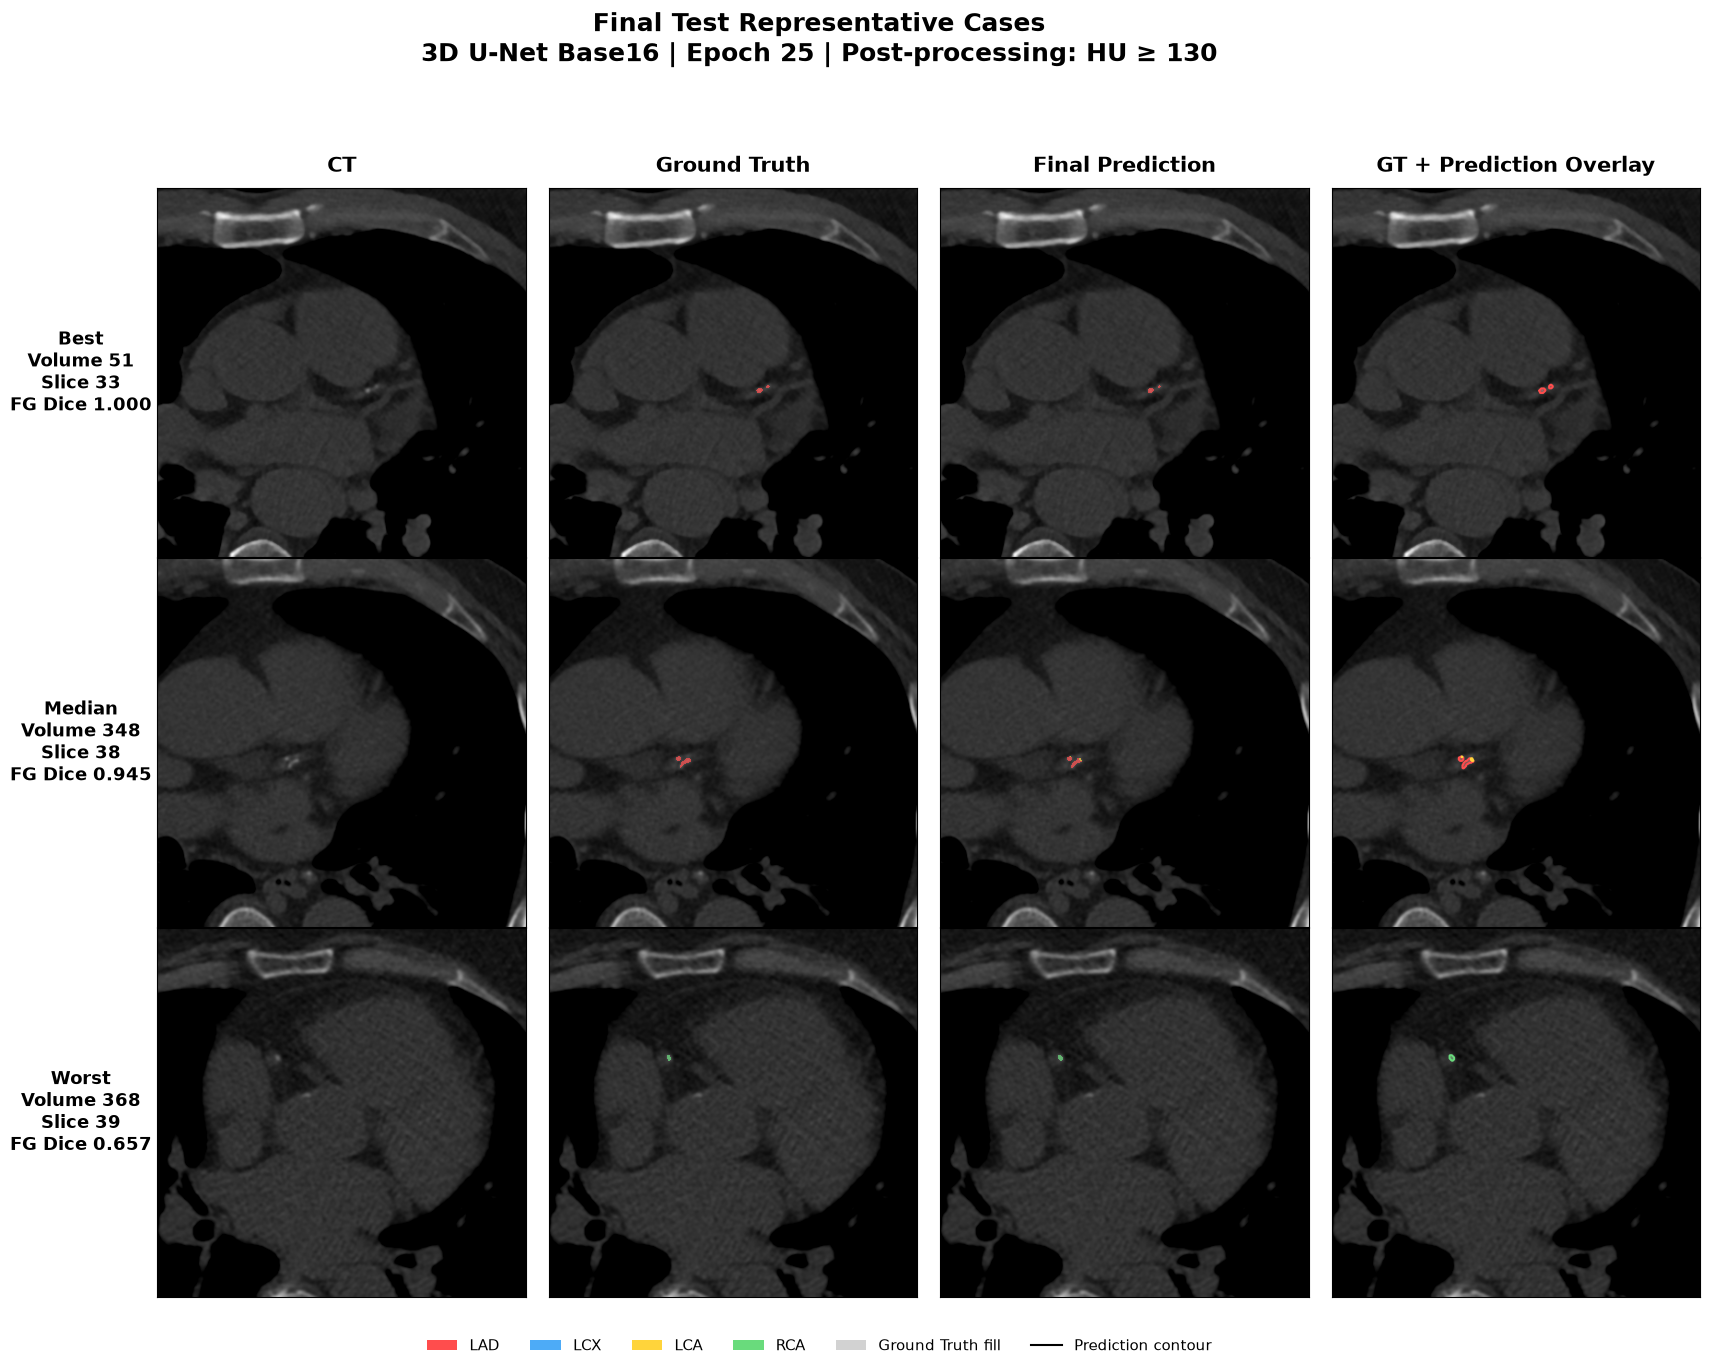


REPRESENTATIVE VISUALIZATION PASS ✅
Saved : /home/korea1/workspace/datasets/COCA/final_visualizations/final_test_best_median_worst_overlay.png
Rows  : Best / Median / Worst
Cols  : CT / GT / Prediction / Overlay
Model : Epoch 25 FROZEN 🔒
Post  : HU >= 130 only FROZEN 🔒


In [499]:
# ============================================================
# FINAL VISUALIZATION - BEST / MEDIAN / WORST OVERLAY
# - Best   : Volume 51
# - Median : Volume 348
# - Worst  : Volume 368
# - Column : CT / Ground Truth / Prediction / Overlay
# - Final Prediction = Epoch 25 + HU >= 130
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# ============================================================
# 1. Visualization 설정
# ============================================================

FINAL_VIS_ROOT = (
    "/home/korea1/workspace/datasets/COCA/"
    "final_visualizations"
)

os.makedirs(
    FINAL_VIS_ROOT,
    exist_ok=True
)

REPRESENTATIVE_FIGURE_PATH = os.path.join(
    FINAL_VIS_ROOT,
    "final_test_best_median_worst_overlay.png"
)

CASE_ORDER = [
    "Best",
    "Median",
    "Worst",
]

# 앞 단계에서 확정된 representative_cases 사용
assert representative_cases == {
    "Best": "51",
    "Median": "348",
    "Worst": "368",
}

CLASS_NAMES = {
    1: "LAD",
    2: "LCX",
    3: "LCA",
    4: "RCA",
}

# Class visualization colors
CLASS_COLORS = {
    1: "#ff4d4d",  # LAD
    2: "#4dabf7",  # LCX
    3: "#ffd43b",  # LCA
    4: "#69db7c",  # RCA
}

seg_cmap = ListedColormap([
    CLASS_COLORS[1],
    CLASS_COLORS[2],
    CLASS_COLORS[3],
    CLASS_COLORS[4],
])

seg_norm = BoundaryNorm(
    [0.5, 1.5, 2.5, 3.5, 4.5],
    seg_cmap.N
)

# CT display window
CT_VMIN = -200
CT_VMAX = 1000

# ============================================================
# 2. Representative Slice 선택 함수
# - GT 또는 Prediction foreground가 가장 많이 존재하는 slice
# - 시각적으로 가장 정보량이 많은 axial slice 선택
# ============================================================

def select_visualization_slice(
    gt,
    pred
):
    slice_scores = []

    for z in range(gt.shape[0]):
        gt_fg = int(
            np.sum(gt[z] > 0)
        )

        pred_fg = int(
            np.sum(pred[z] > 0)
        )

        union_fg = int(
            np.sum(
                (gt[z] > 0)
                | (pred[z] > 0)
            )
        )

        slice_scores.append(
            (
                union_fg,
                gt_fg + pred_fg,
                gt_fg,
                z,
            )
        )

    # union → 전체 FG → GT 순으로 우선
    best_score = max(
        slice_scores
    )

    return int(
        best_score[-1]
    )

# ============================================================
# 3. Case 데이터 준비
# ============================================================

visualization_cases = []

print("====== FINAL REPRESENTATIVE VISUALIZATION ======")

for case_name in CASE_ORDER:
    volume_id = representative_cases[
        case_name
    ]

    ct_hu = np.load(
        os.path.join(
            TEST_CACHE_ROOT,
            f"{volume_id}_ct.npy"
        ),
        mmap_mode="r"
    )

    gt = np.load(
        os.path.join(
            TEST_CACHE_ROOT,
            f"{volume_id}_gt.npy"
        ),
        mmap_mode="r"
    )

    pred = np.load(
        os.path.join(
            FINAL_TEST_POST_PRED_ROOT,
            f"{volume_id}_pred.npy"
        ),
        mmap_mode="r"
    )

    assert ct_hu.shape == gt.shape == pred.shape

    z_index = select_visualization_slice(
        gt,
        pred
    )

    metric_row = test_case_metrics_df[
        test_case_metrics_df[
            "volume_id"
        ] == volume_id
    ].iloc[0]

    visualization_cases.append({
        "case_name": case_name,
        "volume_id": volume_id,
        "z_index": z_index,
        "ct": np.asarray(
            ct_hu[z_index]
        ),
        "gt": np.asarray(
            gt[z_index]
        ),
        "pred": np.asarray(
            pred[z_index]
        ),
        "foreground_dice": float(
            metric_row[
                "foreground_dice"
            ]
        ),
    })

    print(
        f"{case_name:6s} "
        f"| Volume={volume_id:>3s} "
        f"| Slice={z_index:02d} "
        f"| GT FG={np.sum(gt[z_index] > 0):,} "
        f"| Pred FG={np.sum(pred[z_index] > 0):,} "
        f"| Volume FG Dice="
        f"{metric_row['foreground_dice']:.6f}"
    )

# ============================================================
# 4. Figure 생성
# ============================================================

fig, axes = plt.subplots(
    nrows=3,
    ncols=4,
    figsize=(18, 14)
)

column_titles = [
    "CT",
    "Ground Truth",
    "Final Prediction",
    "GT + Prediction Overlay",
]

for col, title in enumerate(
    column_titles
):
    axes[0, col].set_title(
        title,
        fontsize=15,
        fontweight="bold",
        pad=12
    )

# ============================================================
# 5. Best / Median / Worst 표시
# ============================================================

for row_idx, case in enumerate(
    visualization_cases
):
    ct_slice = case["ct"]
    gt_slice = case["gt"]
    pred_slice = case["pred"]

    # --------------------------------------------------------
    # 5-1. CT
    # --------------------------------------------------------

    ax = axes[row_idx, 0]

    ax.imshow(
        ct_slice,
        cmap="gray",
        vmin=CT_VMIN,
        vmax=CT_VMAX
    )

    # --------------------------------------------------------
    # 5-2. Ground Truth
    # --------------------------------------------------------

    ax = axes[row_idx, 1]

    ax.imshow(
        ct_slice,
        cmap="gray",
        vmin=CT_VMIN,
        vmax=CT_VMAX
    )

    gt_masked = np.ma.masked_where(
        gt_slice == 0,
        gt_slice
    )

    ax.imshow(
        gt_masked,
        cmap=seg_cmap,
        norm=seg_norm,
        alpha=0.70,
        interpolation="nearest"
    )

    # --------------------------------------------------------
    # 5-3. Final Prediction
    # --------------------------------------------------------

    ax = axes[row_idx, 2]

    ax.imshow(
        ct_slice,
        cmap="gray",
        vmin=CT_VMIN,
        vmax=CT_VMAX
    )

    pred_masked = np.ma.masked_where(
        pred_slice == 0,
        pred_slice
    )

    ax.imshow(
        pred_masked,
        cmap=seg_cmap,
        norm=seg_norm,
        alpha=0.70,
        interpolation="nearest"
    )

    # --------------------------------------------------------
    # 5-4. GT + Prediction Overlay
    # - GT = translucent fill
    # - Prediction = solid contour
    # --------------------------------------------------------

    ax = axes[row_idx, 3]

    ax.imshow(
        ct_slice,
        cmap="gray",
        vmin=CT_VMIN,
        vmax=CT_VMAX
    )

    ax.imshow(
        gt_masked,
        cmap=seg_cmap,
        norm=seg_norm,
        alpha=0.32,
        interpolation="nearest"
    )

    for class_id in range(1, 5):
        pred_class = (
            pred_slice == class_id
        )

        if np.any(pred_class):
            ax.contour(
                pred_class.astype(
                    np.uint8
                ),
                levels=[0.5],
                colors=[
                    CLASS_COLORS[
                        class_id
                    ]
                ],
                linewidths=1.4
            )

    # --------------------------------------------------------
    # 5-5. Row Label
    # --------------------------------------------------------

    axes[row_idx, 0].set_ylabel(
        (
            f"{case['case_name']}\n"
            f"Volume {case['volume_id']}\n"
            f"Slice {case['z_index']}\n"
            f"FG Dice "
            f"{case['foreground_dice']:.3f}"
        ),
        fontsize=13,
        fontweight="bold",
        rotation=0,
        labelpad=55,
        va="center"
    )

# ============================================================
# 6. Axis 정리
# ============================================================

for ax_row in axes:
    for ax in ax_row:
        ax.set_xticks([])
        ax.set_yticks([])

# ============================================================
# 7. Legend
# ============================================================

class_legend = [
    Patch(
        facecolor=CLASS_COLORS[class_id],
        label=CLASS_NAMES[class_id]
    )
    for class_id in range(1, 5)
]

style_legend = [
    Patch(
        facecolor="gray",
        alpha=0.35,
        label="Ground Truth fill"
    ),
    Line2D(
        [0],
        [0],
        color="black",
        linewidth=1.5,
        label="Prediction contour"
    ),
]

fig.legend(
    handles=class_legend + style_legend,
    loc="lower center",
    ncol=6,
    frameon=False,
    fontsize=11,
    bbox_to_anchor=(0.5, 0.015)
)

# ============================================================
# 8. Figure Title / Save
# ============================================================

fig.suptitle(
    (
        "Final Test Representative Cases\n"
        "3D U-Net Base16 | Epoch 25 | "
        "Post-processing: HU ≥ 130"
    ),
    fontsize=18,
    fontweight="bold",
    y=0.985
)

plt.tight_layout(
    rect=[
        0.04,
        0.055,
        1.0,
        0.94
    ]
)

plt.savefig(
    REPRESENTATIVE_FIGURE_PATH,
    dpi=220,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 9. Final QC
# ============================================================

assert os.path.exists(
    REPRESENTATIVE_FIGURE_PATH
)

print("\n==========================================")
print("REPRESENTATIVE VISUALIZATION PASS ✅")
print(
    "Saved :",
    REPRESENTATIVE_FIGURE_PATH
)
print("Rows  : Best / Median / Worst")
print("Cols  : CT / GT / Prediction / Overlay")
print("Model : Epoch 25 FROZEN 🔒")
print("Post  : HU >= 130 only FROZEN 🔒")
print("==========================================")

====== ROI / ERROR-FOCUSED VISUALIZATION ======
Best   | Volume= 51 | Slice=33 | Mode=foreground | Union=  39 | Mismatch=   0 | ROI=Y[157:277] X[172:292]
Median | Volume=348 | Slice=38 | Mode=mismatch   | Union=  77 | Mismatch=   8 | ROI=Y[161:281] X[86:206]
Worst  | Volume=368 | Slice=43 | Mode=mismatch   | Union=  11 | Mismatch=  11 | ROI=Y[185:305] X[186:306]


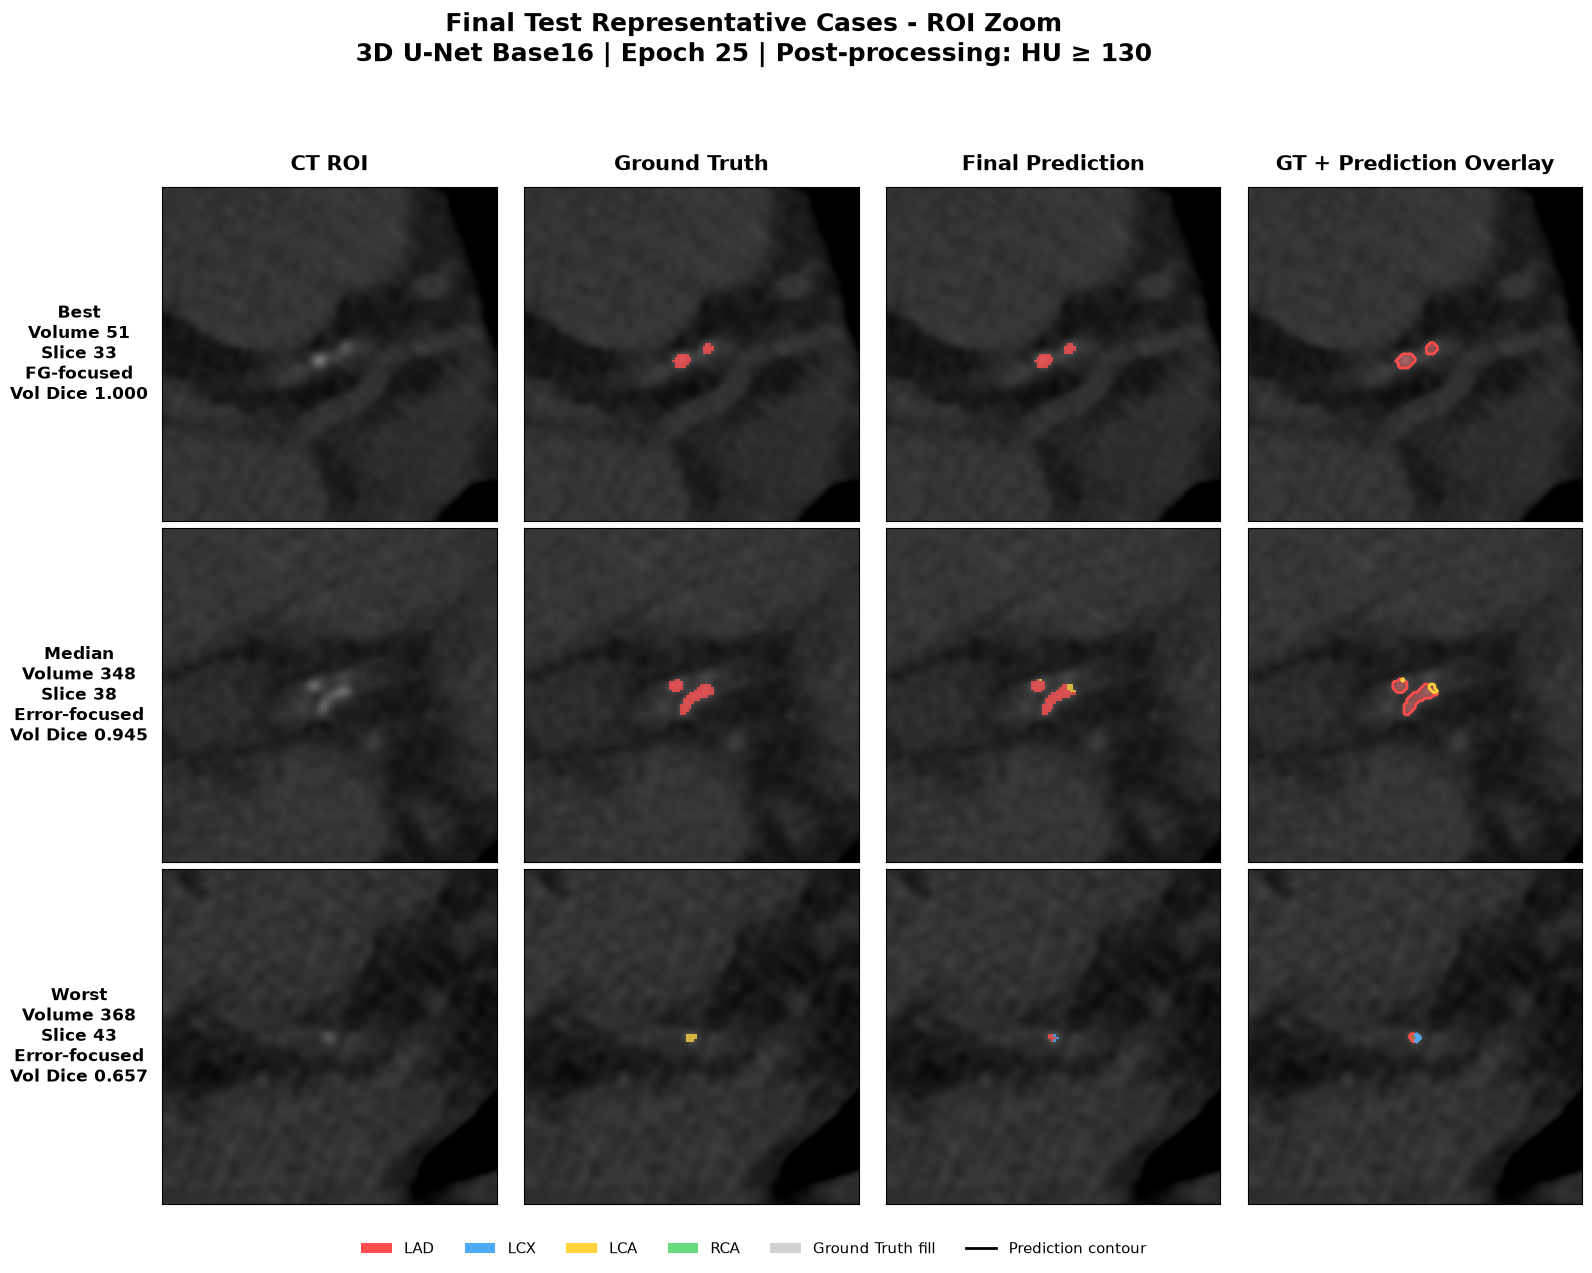


ROI ZOOM VISUALIZATION PASS ✅
Saved : /home/korea1/workspace/datasets/COCA/final_visualizations/final_test_best_median_worst_roi_zoom.png
Best  : Foreground-focused Slice
Median: Error-focused Slice
Worst : Error-focused Slice
Model : FROZEN 🔒
Post  : HU >= 130 only FROZEN 🔒


In [500]:
# ============================================================
# FINAL VISUALIZATION - ROI ZOOM / ERROR-FOCUSED CASES
# - Best   : foreground가 가장 풍부한 slice
# - Median : GT-Pred mismatch가 가장 큰 slice
# - Worst  : GT-Pred mismatch가 가장 큰 slice
# - 병변 주변 ROI를 자동 crop하여 확대
# - Final model / prediction은 변경하지 않음
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# ============================================================
# 1. Output / Style
# ============================================================

ROI_FIGURE_PATH = os.path.join(
    FINAL_VIS_ROOT,
    "final_test_best_median_worst_roi_zoom.png"
)

CASE_ORDER = [
    "Best",
    "Median",
    "Worst",
]

CLASS_NAMES = {
    1: "LAD",
    2: "LCX",
    3: "LCA",
    4: "RCA",
}

CLASS_COLORS = {
    1: "#ff4d4d",
    2: "#4dabf7",
    3: "#ffd43b",
    4: "#69db7c",
}

seg_cmap = ListedColormap([
    CLASS_COLORS[1],
    CLASS_COLORS[2],
    CLASS_COLORS[3],
    CLASS_COLORS[4],
])

seg_norm = BoundaryNorm(
    [0.5, 1.5, 2.5, 3.5, 4.5],
    seg_cmap.N
)

CT_VMIN = -200
CT_VMAX = 1000

ROI_MARGIN = 35
ROI_MIN_SIZE = 120

# ============================================================
# 2. Slice 선택 함수
# ============================================================

def select_roi_slice(gt, pred, mode):
    scores = []

    for z in range(gt.shape[0]):
        gt_z = gt[z]
        pred_z = pred[z]

        foreground_union = (
            (gt_z > 0)
            | (pred_z > 0)
        )

        mismatch = (
            foreground_union
            & (gt_z != pred_z)
        )

        union_count = int(
            np.sum(foreground_union)
        )

        mismatch_count = int(
            np.sum(mismatch)
        )

        gt_count = int(
            np.sum(gt_z > 0)
        )

        if mode == "foreground":
            score = (
                union_count,
                gt_count,
                mismatch_count,
                z,
            )

        else:
            score = (
                mismatch_count,
                union_count,
                gt_count,
                z,
            )

        scores.append(score)

    return int(
        max(scores)[-1]
    )

# ============================================================
# 3. ROI Bounding Box 함수
# ============================================================

def get_roi_bounds(
    gt_slice,
    pred_slice,
    margin=ROI_MARGIN,
    min_size=ROI_MIN_SIZE
):
    mask = (
        (gt_slice > 0)
        | (pred_slice > 0)
    )

    ys, xs = np.where(mask)

    assert len(ys) > 0, (
        "Foreground가 없는 slice입니다."
    )

    y_center = int(
        round(
            (ys.min() + ys.max()) / 2
        )
    )

    x_center = int(
        round(
            (xs.min() + xs.max()) / 2
        )
    )

    target_height = max(
        int(ys.max() - ys.min() + 1)
        + 2 * margin,
        min_size
    )

    target_width = max(
        int(xs.max() - xs.min() + 1)
        + 2 * margin,
        min_size
    )

    height, width = gt_slice.shape

    y1 = y_center - target_height // 2
    y2 = y1 + target_height

    x1 = x_center - target_width // 2
    x2 = x1 + target_width

    if y1 < 0:
        y2 -= y1
        y1 = 0

    if x1 < 0:
        x2 -= x1
        x1 = 0

    if y2 > height:
        y1 -= y2 - height
        y2 = height

    if x2 > width:
        x1 -= x2 - width
        x2 = width

    y1 = max(0, y1)
    x1 = max(0, x1)

    return (
        int(y1),
        int(y2),
        int(x1),
        int(x2),
    )

# ============================================================
# 4. Case별 Slice / ROI 준비
# ============================================================

roi_cases = []

print("====== ROI / ERROR-FOCUSED VISUALIZATION ======")

for case_name in CASE_ORDER:
    volume_id = representative_cases[
        case_name
    ]

    ct = np.load(
        os.path.join(
            TEST_CACHE_ROOT,
            f"{volume_id}_ct.npy"
        ),
        mmap_mode="r"
    )

    gt = np.load(
        os.path.join(
            TEST_CACHE_ROOT,
            f"{volume_id}_gt.npy"
        ),
        mmap_mode="r"
    )

    pred = np.load(
        os.path.join(
            FINAL_TEST_POST_PRED_ROOT,
            f"{volume_id}_pred.npy"
        ),
        mmap_mode="r"
    )

    assert ct.shape == gt.shape == pred.shape

    # Best는 풍부한 FG, Median/Worst는 error-focused
    selection_mode = (
        "foreground"
        if case_name == "Best"
        else "mismatch"
    )

    z_index = select_roi_slice(
        gt,
        pred,
        selection_mode
    )

    gt_slice = np.asarray(
        gt[z_index]
    )

    pred_slice = np.asarray(
        pred[z_index]
    )

    ct_slice = np.asarray(
        ct[z_index]
    )

    y1, y2, x1, x2 = get_roi_bounds(
        gt_slice,
        pred_slice
    )

    gt_roi = gt_slice[
        y1:y2,
        x1:x2
    ]

    pred_roi = pred_slice[
        y1:y2,
        x1:x2
    ]

    ct_roi = ct_slice[
        y1:y2,
        x1:x2
    ]

    fg_union = (
        (gt_slice > 0)
        | (pred_slice > 0)
    )

    mismatch = (
        fg_union
        & (gt_slice != pred_slice)
    )

    mismatch_count = int(
        np.sum(mismatch)
    )

    union_count = int(
        np.sum(fg_union)
    )

    metric_row = test_case_metrics_df[
        test_case_metrics_df[
            "volume_id"
        ] == volume_id
    ].iloc[0]

    roi_cases.append({
        "case_name": case_name,
        "volume_id": volume_id,
        "z_index": z_index,
        "selection_mode": selection_mode,
        "ct": ct_roi,
        "gt": gt_roi,
        "pred": pred_roi,
        "mismatch_count": mismatch_count,
        "union_count": union_count,
        "foreground_dice": float(
            metric_row["foreground_dice"]
        ),
        "roi_bounds": (
            y1, y2, x1, x2
        ),
    })

    print(
        f"{case_name:6s} "
        f"| Volume={volume_id:>3s} "
        f"| Slice={z_index:02d} "
        f"| Mode={selection_mode:10s} "
        f"| Union={union_count:4d} "
        f"| Mismatch={mismatch_count:4d} "
        f"| ROI=Y[{y1}:{y2}] X[{x1}:{x2}]"
    )

# ============================================================
# 5. Figure
# ============================================================

fig, axes = plt.subplots(
    3,
    4,
    figsize=(17, 13)
)

column_titles = [
    "CT ROI",
    "Ground Truth",
    "Final Prediction",
    "GT + Prediction Overlay",
]

for col, title in enumerate(
    column_titles
):
    axes[0, col].set_title(
        title,
        fontsize=15,
        fontweight="bold",
        pad=12
    )

# ============================================================
# 6. Plot
# ============================================================

for row_idx, case in enumerate(
    roi_cases
):
    ct_roi = case["ct"]
    gt_roi = case["gt"]
    pred_roi = case["pred"]

    gt_masked = np.ma.masked_where(
        gt_roi == 0,
        gt_roi
    )

    pred_masked = np.ma.masked_where(
        pred_roi == 0,
        pred_roi
    )

    # --------------------------------------------------------
    # CT
    # --------------------------------------------------------

    axes[row_idx, 0].imshow(
        ct_roi,
        cmap="gray",
        vmin=CT_VMIN,
        vmax=CT_VMAX
    )

    # --------------------------------------------------------
    # GT
    # --------------------------------------------------------

    axes[row_idx, 1].imshow(
        ct_roi,
        cmap="gray",
        vmin=CT_VMIN,
        vmax=CT_VMAX
    )

    axes[row_idx, 1].imshow(
        gt_masked,
        cmap=seg_cmap,
        norm=seg_norm,
        alpha=0.78,
        interpolation="nearest"
    )

    # --------------------------------------------------------
    # Prediction
    # --------------------------------------------------------

    axes[row_idx, 2].imshow(
        ct_roi,
        cmap="gray",
        vmin=CT_VMIN,
        vmax=CT_VMAX
    )

    axes[row_idx, 2].imshow(
        pred_masked,
        cmap=seg_cmap,
        norm=seg_norm,
        alpha=0.78,
        interpolation="nearest"
    )

    # --------------------------------------------------------
    # Overlay
    # GT fill + Prediction contour
    # --------------------------------------------------------

    axes[row_idx, 3].imshow(
        ct_roi,
        cmap="gray",
        vmin=CT_VMIN,
        vmax=CT_VMAX
    )

    axes[row_idx, 3].imshow(
        gt_masked,
        cmap=seg_cmap,
        norm=seg_norm,
        alpha=0.35,
        interpolation="nearest"
    )

    for class_id in range(1, 5):
        pred_class = (
            pred_roi == class_id
        )

        if np.any(pred_class):
            axes[row_idx, 3].contour(
                pred_class.astype(
                    np.uint8
                ),
                levels=[0.5],
                colors=[
                    CLASS_COLORS[
                        class_id
                    ]
                ],
                linewidths=2.0
            )

    # --------------------------------------------------------
    # Row Label
    # --------------------------------------------------------

    selection_text = (
        "FG-focused"
        if case["selection_mode"]
        == "foreground"
        else "Error-focused"
    )

    axes[row_idx, 0].set_ylabel(
        (
            f"{case['case_name']}\n"
            f"Volume {case['volume_id']}\n"
            f"Slice {case['z_index']}\n"
            f"{selection_text}\n"
            f"Vol Dice {case['foreground_dice']:.3f}"
        ),
        fontsize=12,
        fontweight="bold",
        rotation=0,
        labelpad=60,
        va="center"
    )

# ============================================================
# 7. Axis / Legend
# ============================================================

for ax_row in axes:
    for ax in ax_row:
        ax.set_xticks([])
        ax.set_yticks([])

class_legend = [
    Patch(
        facecolor=CLASS_COLORS[class_id],
        label=CLASS_NAMES[class_id]
    )
    for class_id in range(1, 5)
]

style_legend = [
    Patch(
        facecolor="gray",
        alpha=0.35,
        label="Ground Truth fill"
    ),
    Line2D(
        [0],
        [0],
        color="black",
        linewidth=2,
        label="Prediction contour"
    ),
]

fig.legend(
    handles=class_legend + style_legend,
    loc="lower center",
    ncol=6,
    frameon=False,
    fontsize=11,
    bbox_to_anchor=(0.5, 0.015)
)

# ============================================================
# 8. Title / Save
# ============================================================

fig.suptitle(
    (
        "Final Test Representative Cases - ROI Zoom\n"
        "3D U-Net Base16 | Epoch 25 | "
        "Post-processing: HU ≥ 130"
    ),
    fontsize=18,
    fontweight="bold",
    y=0.985
)

plt.tight_layout(
    rect=[
        0.05,
        0.055,
        1.0,
        0.94
    ]
)

plt.savefig(
    ROI_FIGURE_PATH,
    dpi=240,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 9. QC
# ============================================================

assert os.path.exists(
    ROI_FIGURE_PATH
)

print("\n==========================================")
print("ROI ZOOM VISUALIZATION PASS ✅")
print("Saved :", ROI_FIGURE_PATH)
print("Best  : Foreground-focused Slice")
print("Median: Error-focused Slice")
print("Worst : Error-focused Slice")
print("Model : FROZEN 🔒")
print("Post  : HU >= 130 only FROZEN 🔒")
print("==========================================")

====== REPRESENTATIVE ERROR ANALYSIS ======
Best   | Volume= 51 | Slice=33 | TP= 39 | FN=  0 | FP=  0 | WrongClass=  0
       Class Confusion : None
Median | Volume=348 | Slice=38 | TP= 69 | FN=  1 | FP=  0 | WrongClass=  7
       Class Confusion : LAD→LCA(7)
Worst  | Volume=368 | Slice=43 | TP=  0 | FN=  2 | FP=  0 | WrongClass=  9
       Class Confusion : LCA→LAD(6), LCA→LCX(3)


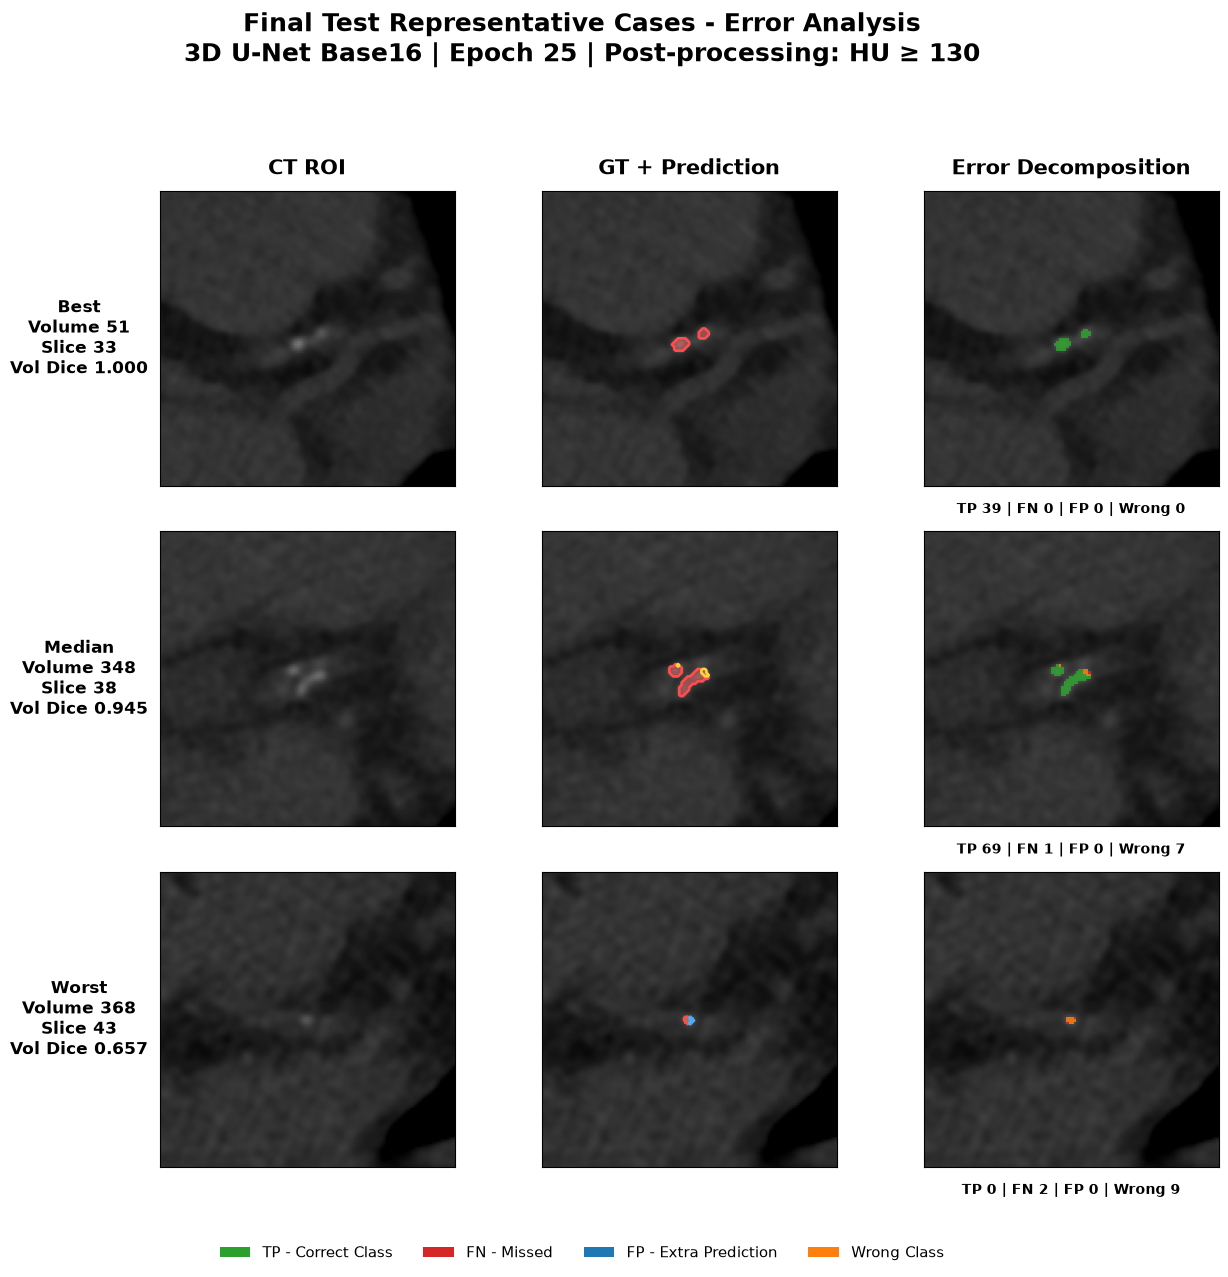


REPRESENTATIVE ERROR MAP PASS ✅
Saved : /home/korea1/workspace/datasets/COCA/final_visualizations/final_test_representative_error_map.png
Green : Correct class TP
Red   : FN
Blue  : FP
Orange: Wrong vessel class
Model : FROZEN 🔒
Post  : HU >= 130 only FROZEN 🔒


In [501]:
# ============================================================
# FINAL VISUALIZATION - TP / FP / FN / WRONG-CLASS ERROR MAP
# - 앞 단계와 동일한 Best / Median / Worst ROI 사용
# - TP          : GT와 Prediction class가 정확히 일치
# - FN          : GT는 있으나 Prediction이 Background
# - FP          : GT는 Background이나 Prediction 존재
# - Wrong Class : GT / Prediction 모두 FG지만 class가 다름
# - Model / Prediction은 변경하지 않음
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt

from collections import Counter
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

# ============================================================
# 1. Pre-flight / Output
# ============================================================

assert "roi_cases" in globals()
assert len(roi_cases) == 3

ERROR_FIGURE_PATH = os.path.join(
    FINAL_VIS_ROOT,
    "final_test_representative_error_map.png"
)

ERROR_COLORS = {
    1: "#2ca02c",  # TP
    2: "#d62728",  # FN
    3: "#1f77b4",  # FP
    4: "#ff7f0e",  # Wrong Class
}

ERROR_NAMES = {
    1: "TP - Correct Class",
    2: "FN - Missed",
    3: "FP - Extra Prediction",
    4: "Wrong Class",
}

error_cmap = ListedColormap([
    ERROR_COLORS[1],
    ERROR_COLORS[2],
    ERROR_COLORS[3],
    ERROR_COLORS[4],
])

error_norm = BoundaryNorm(
    [0.5, 1.5, 2.5, 3.5, 4.5],
    error_cmap.N
)

CT_VMIN = -200
CT_VMAX = 1000

# ============================================================
# 2. Error Map 생성 함수
# ============================================================

def build_multiclass_error_map(gt, pred):
    error_map = np.zeros(
        gt.shape,
        dtype=np.uint8
    )

    # TP: 같은 foreground class
    tp_mask = (
        (gt > 0)
        & (pred > 0)
        & (gt == pred)
    )

    # FN: GT foreground, Prediction background
    fn_mask = (
        (gt > 0)
        & (pred == 0)
    )

    # FP: GT background, Prediction foreground
    fp_mask = (
        (gt == 0)
        & (pred > 0)
    )

    # Wrong class: 둘 다 foreground지만 class 불일치
    wrong_class_mask = (
        (gt > 0)
        & (pred > 0)
        & (gt != pred)
    )

    error_map[tp_mask] = 1
    error_map[fn_mask] = 2
    error_map[fp_mask] = 3
    error_map[wrong_class_mask] = 4

    return {
        "map": error_map,
        "tp": int(np.sum(tp_mask)),
        "fn": int(np.sum(fn_mask)),
        "fp": int(np.sum(fp_mask)),
        "wrong_class": int(
            np.sum(wrong_class_mask)
        ),
    }

# ============================================================
# 3. Figure
# ============================================================

fig, axes = plt.subplots(
    nrows=3,
    ncols=3,
    figsize=(14, 13)
)

column_titles = [
    "CT ROI",
    "GT + Prediction",
    "Error Decomposition",
]

for col, title in enumerate(column_titles):
    axes[0, col].set_title(
        title,
        fontsize=15,
        fontweight="bold",
        pad=12
    )

print("====== REPRESENTATIVE ERROR ANALYSIS ======")

# ============================================================
# 4. Best / Median / Worst
# ============================================================

for row_idx, case in enumerate(roi_cases):
    ct = case["ct"]
    gt = case["gt"]
    pred = case["pred"]

    error_result = build_multiclass_error_map(
        gt,
        pred
    )

    error_map = error_result["map"]

    # --------------------------------------------------------
    # 4-1. Class confusion pair 계산
    # --------------------------------------------------------

    wrong_mask = (
        (gt > 0)
        & (pred > 0)
        & (gt != pred)
    )

    confusion_pairs = Counter(
        zip(
            gt[wrong_mask].tolist(),
            pred[wrong_mask].tolist()
        )
    )

    confusion_text = []

    for (gt_class, pred_class), count in (
        confusion_pairs.most_common()
    ):
        confusion_text.append(
            f"{CLASS_NAMES[gt_class]}"
            f"→{CLASS_NAMES[pred_class]}"
            f"({count})"
        )

    confusion_text = (
        ", ".join(confusion_text)
        if confusion_text
        else "None"
    )

    # --------------------------------------------------------
    # 4-2. CT
    # --------------------------------------------------------

    axes[row_idx, 0].imshow(
        ct,
        cmap="gray",
        vmin=CT_VMIN,
        vmax=CT_VMAX
    )

    # --------------------------------------------------------
    # 4-3. GT fill + Prediction contour
    # --------------------------------------------------------

    axes[row_idx, 1].imshow(
        ct,
        cmap="gray",
        vmin=CT_VMIN,
        vmax=CT_VMAX
    )

    gt_masked = np.ma.masked_where(
        gt == 0,
        gt
    )

    axes[row_idx, 1].imshow(
        gt_masked,
        cmap=seg_cmap,
        norm=seg_norm,
        alpha=0.38,
        interpolation="nearest"
    )

    for class_id in range(1, 5):
        pred_class = pred == class_id

        if np.any(pred_class):
            axes[row_idx, 1].contour(
                pred_class.astype(
                    np.uint8
                ),
                levels=[0.5],
                colors=[
                    CLASS_COLORS[class_id]
                ],
                linewidths=2.0
            )

    # --------------------------------------------------------
    # 4-4. Error Map
    # --------------------------------------------------------

    axes[row_idx, 2].imshow(
        ct,
        cmap="gray",
        vmin=CT_VMIN,
        vmax=CT_VMAX
    )

    error_masked = np.ma.masked_where(
        error_map == 0,
        error_map
    )

    axes[row_idx, 2].imshow(
        error_masked,
        cmap=error_cmap,
        norm=error_norm,
        alpha=0.85,
        interpolation="nearest"
    )

    # --------------------------------------------------------
    # 4-5. Row Label
    # --------------------------------------------------------

    axes[row_idx, 0].set_ylabel(
        (
            f"{case['case_name']}\n"
            f"Volume {case['volume_id']}\n"
            f"Slice {case['z_index']}\n"
            f"Vol Dice {case['foreground_dice']:.3f}"
        ),
        fontsize=12,
        fontweight="bold",
        rotation=0,
        labelpad=58,
        va="center"
    )

    # --------------------------------------------------------
    # 4-6. Error count annotation
    # --------------------------------------------------------

    error_summary = (
        f"TP {error_result['tp']} | "
        f"FN {error_result['fn']} | "
        f"FP {error_result['fp']} | "
        f"Wrong {error_result['wrong_class']}"
    )

    axes[row_idx, 2].text(
        0.5,
        -0.055,
        error_summary,
        transform=axes[row_idx, 2].transAxes,
        ha="center",
        va="top",
        fontsize=10,
        fontweight="bold"
    )

    print(
        f"{case['case_name']:6s} "
        f"| Volume={case['volume_id']:>3s} "
        f"| Slice={case['z_index']:02d} "
        f"| TP={error_result['tp']:3d} "
        f"| FN={error_result['fn']:3d} "
        f"| FP={error_result['fp']:3d} "
        f"| WrongClass="
        f"{error_result['wrong_class']:3d}"
    )

    print(
        "       Class Confusion :",
        confusion_text
    )

# ============================================================
# 5. Axis
# ============================================================

for ax_row in axes:
    for ax in ax_row:
        ax.set_xticks([])
        ax.set_yticks([])

# ============================================================
# 6. Error Legend
# ============================================================

error_legend = [
    Patch(
        facecolor=ERROR_COLORS[code],
        label=ERROR_NAMES[code]
    )
    for code in range(1, 5)
]

fig.legend(
    handles=error_legend,
    loc="lower center",
    ncol=4,
    frameon=False,
    fontsize=11,
    bbox_to_anchor=(0.5, 0.012)
)

# ============================================================
# 7. Title / Save
# ============================================================

fig.suptitle(
    (
        "Final Test Representative Cases - Error Analysis\n"
        "3D U-Net Base16 | Epoch 25 | "
        "Post-processing: HU ≥ 130"
    ),
    fontsize=18,
    fontweight="bold",
    y=0.985
)

plt.tight_layout(
    rect=[
        0.055,
        0.06,
        1.0,
        0.94
    ]
)

plt.savefig(
    ERROR_FIGURE_PATH,
    dpi=240,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 8. Final QC
# ============================================================

assert os.path.exists(
    ERROR_FIGURE_PATH
)

print("\n==========================================")
print("REPRESENTATIVE ERROR MAP PASS ✅")
print("Saved :", ERROR_FIGURE_PATH)
print("Green : Correct class TP")
print("Red   : FN")
print("Blue  : FP")
print("Orange: Wrong vessel class")
print("Model : FROZEN 🔒")
print("Post  : HU >= 130 only FROZEN 🔒")
print("==========================================")

====== REPRESENTATIVE 3D VISUALIZATION ======
Best   | Volume= 51 | Shape=(46, 400, 400) | Spacing=(3.0, 0.404296875, 0.404296875)
       LAD | GT=   39 | Pred=   39
       LCX | GT=   37 | Pred=   37
       LCA | GT=    0 | Pred=    0
       RCA | GT=   23 | Pred=   23
Median | Volume=348 | Shape=(49, 400, 400) | Spacing=(3.0, 0.404296875, 0.404296875)
       LAD | GT=  137 | Pred=  129
       LCX | GT=    0 | Pred=    0
       LCA | GT=    0 | Pred=    7
       RCA | GT=    0 | Pred=    0
Worst  | Volume=368 | Shape=(50, 400, 400) | Spacing=(3.0, 0.36328125, 0.36328125)
       LAD | GT=    0 | Pred=    6
       LCX | GT=    0 | Pred=    3
       LCA | GT=   11 | Pred=    0
       RCA | GT=   24 | Pred=   26


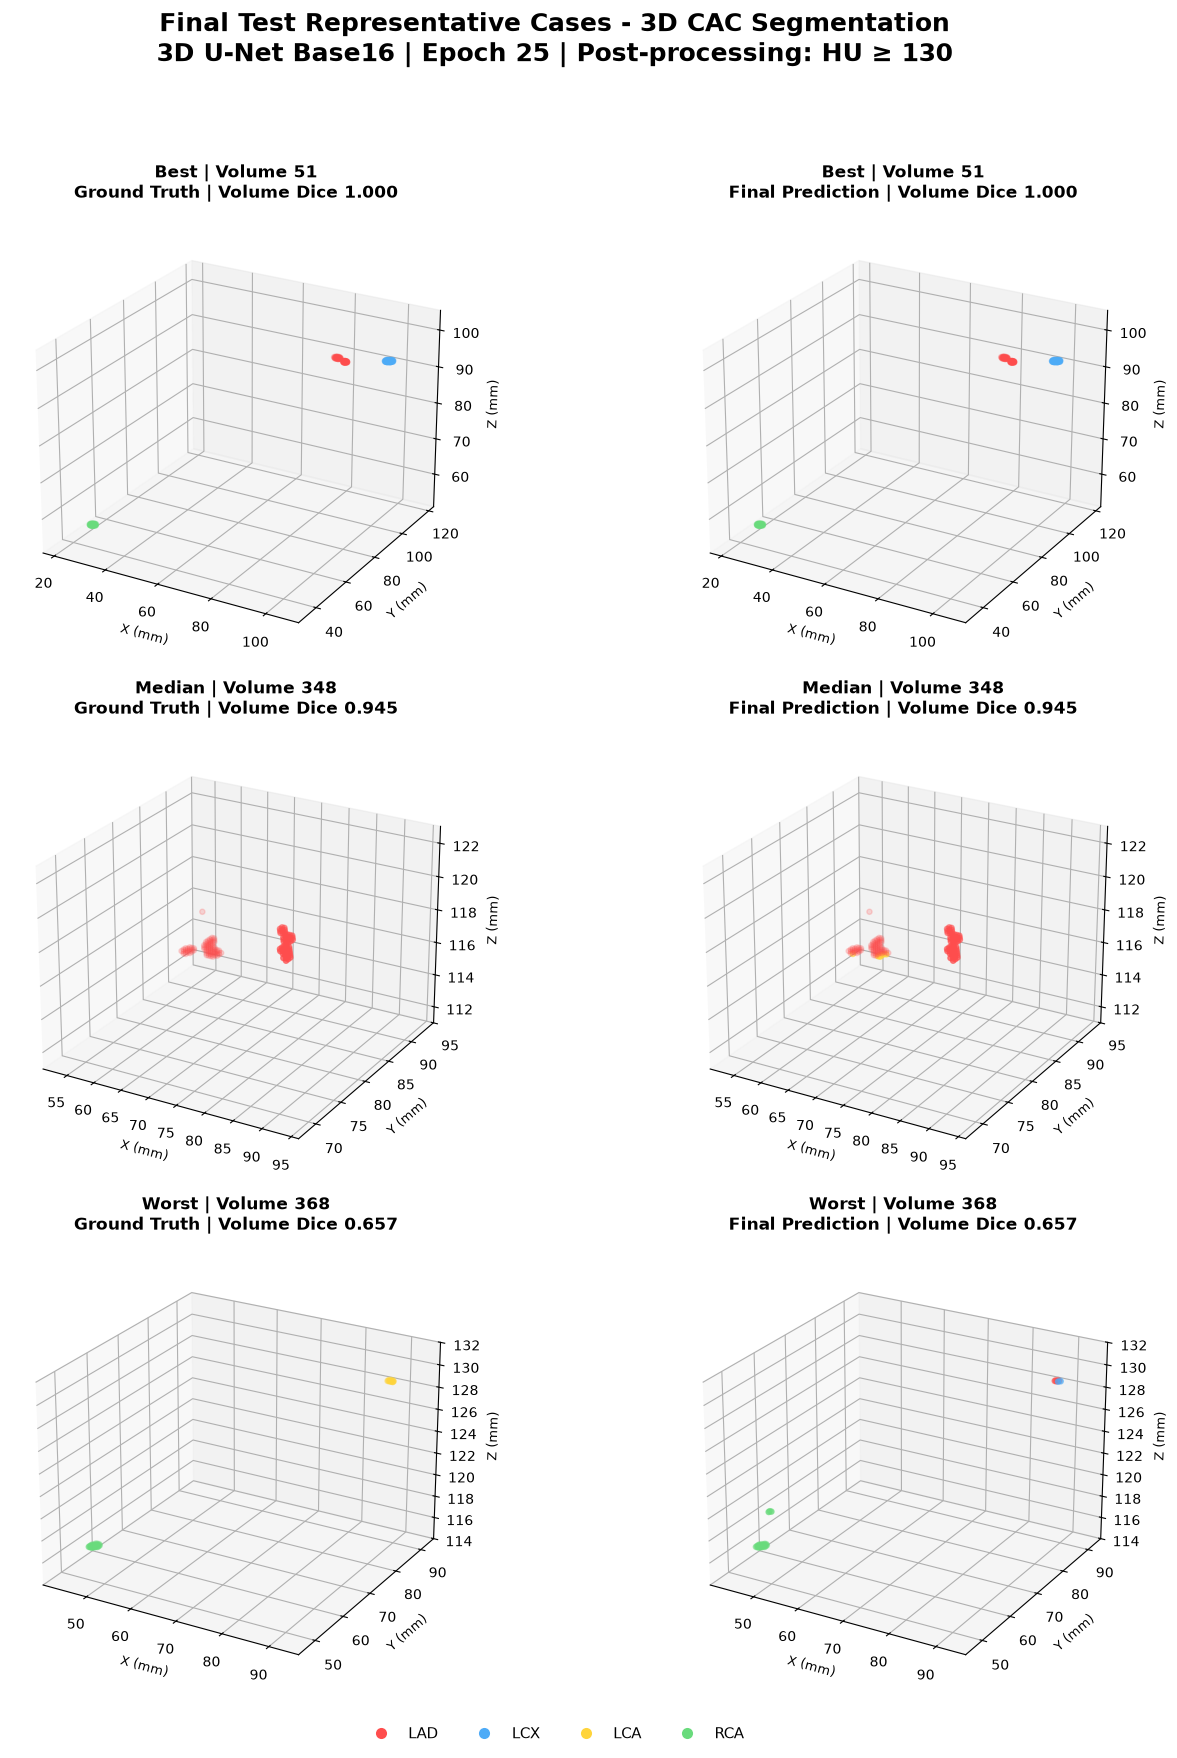


REPRESENTATIVE 3D VISUALIZATION PASS ✅
Saved : /home/korea1/workspace/datasets/COCA/final_visualizations/final_test_representative_3d_gt_vs_prediction.png
Rows  : Best / Median / Worst
Left  : Ground Truth
Right : Final HU130 Prediction
Units : Physical millimeters
Model : FROZEN 🔒
Post  : HU >= 130 only FROZEN 🔒


In [502]:
# ============================================================
# FINAL VISUALIZATION - 3D GT vs PREDICTION
# - Best / Median / Worst 대표 Test case
# - Final HU130 prediction 사용
# - 실제 physical spacing [Z, Y, X] mm 반영
# - 각 혈관 class의 CAC voxel을 3D 위치로 표시
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D

# ============================================================
# 1. Output / 설정
# ============================================================

THREED_FIGURE_PATH = os.path.join(
    FINAL_VIS_ROOT,
    "final_test_representative_3d_gt_vs_prediction.png"
)

CASE_ORDER = [
    "Best",
    "Median",
    "Worst",
]

CLASS_NAMES = {
    1: "LAD",
    2: "LCX",
    3: "LCA",
    4: "RCA",
}

CLASS_COLORS = {
    1: "#ff4d4d",
    2: "#4dabf7",
    3: "#ffd43b",
    4: "#69db7c",
}

# 너무 큰 병변에서도 matplotlib이 무거워지지 않게 제한
MAX_POINTS_PER_CLASS = 5000

# ============================================================
# 2. Physical Coordinate 변환
# - array order = [Z, Y, X]
# - display     = X, Y, Z(mm)
# ============================================================

def get_class_xyz(
    mask,
    class_id,
    spacing_zyx,
    max_points=MAX_POINTS_PER_CLASS
):
    coords = np.argwhere(
        mask == class_id
    )

    if len(coords) == 0:
        return (
            np.array([]),
            np.array([]),
            np.array([])
        )

    # 필요 시 deterministic subsampling
    if len(coords) > max_points:
        indices = np.linspace(
            0,
            len(coords) - 1,
            max_points,
            dtype=int
        )
        coords = coords[indices]

    z_spacing, y_spacing, x_spacing = (
        spacing_zyx
    )

    z_mm = (
        coords[:, 0]
        * z_spacing
    )

    y_mm = (
        coords[:, 1]
        * y_spacing
    )

    x_mm = (
        coords[:, 2]
        * x_spacing
    )

    return (
        x_mm,
        y_mm,
        z_mm
    )

# ============================================================
# 3. Figure 생성
# ============================================================

fig = plt.figure(
    figsize=(15, 18)
)

print("====== REPRESENTATIVE 3D VISUALIZATION ======")

for row_idx, case_name in enumerate(
    CASE_ORDER
):
    volume_id = representative_cases[
        case_name
    ]

    gt = np.load(
        os.path.join(
            TEST_CACHE_ROOT,
            f"{volume_id}_gt.npy"
        ),
        mmap_mode="r"
    )

    pred = np.load(
        os.path.join(
            FINAL_TEST_POST_PRED_ROOT,
            f"{volume_id}_pred.npy"
        ),
        mmap_mode="r"
    )

    spacing = tuple(
        float(v)
        for v in test_spacing_zyx[
            volume_id
        ]
    )

    assert gt.shape == pred.shape
    assert len(spacing) == 3

    metric_row = test_case_metrics_df[
        test_case_metrics_df[
            "volume_id"
        ] == volume_id
    ].iloc[0]

    # --------------------------------------------------------
    # 3-1. GT / Prediction subplot
    # --------------------------------------------------------

    for col_idx, (
        volume,
        title
    ) in enumerate([
        (gt, "Ground Truth"),
        (pred, "Final Prediction"),
    ]):
        subplot_index = (
            row_idx * 2
            + col_idx
            + 1
        )

        ax = fig.add_subplot(
            3,
            2,
            subplot_index,
            projection="3d"
        )

        for class_id in range(1, 5):
            x_mm, y_mm, z_mm = get_class_xyz(
                volume,
                class_id,
                spacing
            )

            if len(x_mm) == 0:
                continue

            ax.scatter(
                x_mm,
                y_mm,
                z_mm,
                s=14,
                alpha=0.82,
                c=CLASS_COLORS[class_id],
                depthshade=True
            )

        ax.set_title(
            (
                f"{case_name} | Volume {volume_id}\n"
                f"{title} | "
                f"Volume Dice "
                f"{metric_row['foreground_dice']:.3f}"
            ),
            fontsize=12,
            fontweight="bold",
            pad=10
        )

        ax.set_xlabel(
            "X (mm)",
            fontsize=9
        )

        ax.set_ylabel(
            "Y (mm)",
            fontsize=9
        )

        ax.set_zlabel(
            "Z (mm)",
            fontsize=9
        )

        # 동일 case의 GT / Pred가 같은 view를 갖도록
        full_fg = (
            (gt > 0)
            | (pred > 0)
        )

        full_coords = np.argwhere(
            full_fg
        )

        if len(full_coords) > 0:
            z_spacing, y_spacing, x_spacing = (
                spacing
            )

            x_all = (
                full_coords[:, 2]
                * x_spacing
            )

            y_all = (
                full_coords[:, 1]
                * y_spacing
            )

            z_all = (
                full_coords[:, 0]
                * z_spacing
            )

            x_margin = max(
                3.0,
                (x_all.max() - x_all.min())
                * 0.15
            )

            y_margin = max(
                3.0,
                (y_all.max() - y_all.min())
                * 0.15
            )

            z_margin = max(
                3.0,
                (z_all.max() - z_all.min())
                * 0.15
            )

            ax.set_xlim(
                x_all.min() - x_margin,
                x_all.max() + x_margin
            )

            ax.set_ylim(
                y_all.min() - y_margin,
                y_all.max() + y_margin
            )

            ax.set_zlim(
                z_all.min() - z_margin,
                z_all.max() + z_margin
            )

        ax.view_init(
            elev=24,
            azim=-60
        )

        ax.grid(True)

    # --------------------------------------------------------
    # 3-2. Case voxel summary
    # --------------------------------------------------------

    print(
        f"{case_name:6s} "
        f"| Volume={volume_id:>3s} "
        f"| Shape={tuple(gt.shape)} "
        f"| Spacing={spacing}"
    )

    for class_id in range(1, 5):
        gt_count = int(
            np.sum(gt == class_id)
        )

        pred_count = int(
            np.sum(pred == class_id)
        )

        print(
            f"       "
            f"{CLASS_NAMES[class_id]:3s} "
            f"| GT={gt_count:5d} "
            f"| Pred={pred_count:5d}"
        )

# ============================================================
# 4. Legend / Title
# ============================================================

legend_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="",
        markerfacecolor=CLASS_COLORS[class_id],
        markeredgecolor="none",
        markersize=8,
        label=CLASS_NAMES[class_id]
    )
    for class_id in range(1, 5)
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=4,
    frameon=False,
    fontsize=11,
    bbox_to_anchor=(0.5, 0.015)
)

fig.suptitle(
    (
        "Final Test Representative Cases - "
        "3D CAC Segmentation\n"
        "3D U-Net Base16 | Epoch 25 | "
        "Post-processing: HU ≥ 130"
    ),
    fontsize=18,
    fontweight="bold",
    y=0.985
)

plt.tight_layout(
    rect=[
        0.02,
        0.04,
        1.0,
        0.95
    ]
)

# ============================================================
# 5. Save
# ============================================================

plt.savefig(
    THREED_FIGURE_PATH,
    dpi=220,
    bbox_inches="tight"
)

plt.show()

assert os.path.exists(
    THREED_FIGURE_PATH
)

print("\n==========================================")
print("REPRESENTATIVE 3D VISUALIZATION PASS ✅")
print("Saved :", THREED_FIGURE_PATH)
print("Rows  : Best / Median / Worst")
print("Left  : Ground Truth")
print("Right : Final HU130 Prediction")
print("Units : Physical millimeters")
print("Model : FROZEN 🔒")
print("Post  : HU >= 130 only FROZEN 🔒")
print("==========================================")

====== 3D CT CONTEXT SETUP ======
Volume       : 368
Shape        : (50, 400, 400)
Spacing      : (3.0, 0.36328125, 0.36328125)
ROI          : Z[35:48] Y[103:282] X[93:283]
Plane Center : Z=40, Y=171, X=164


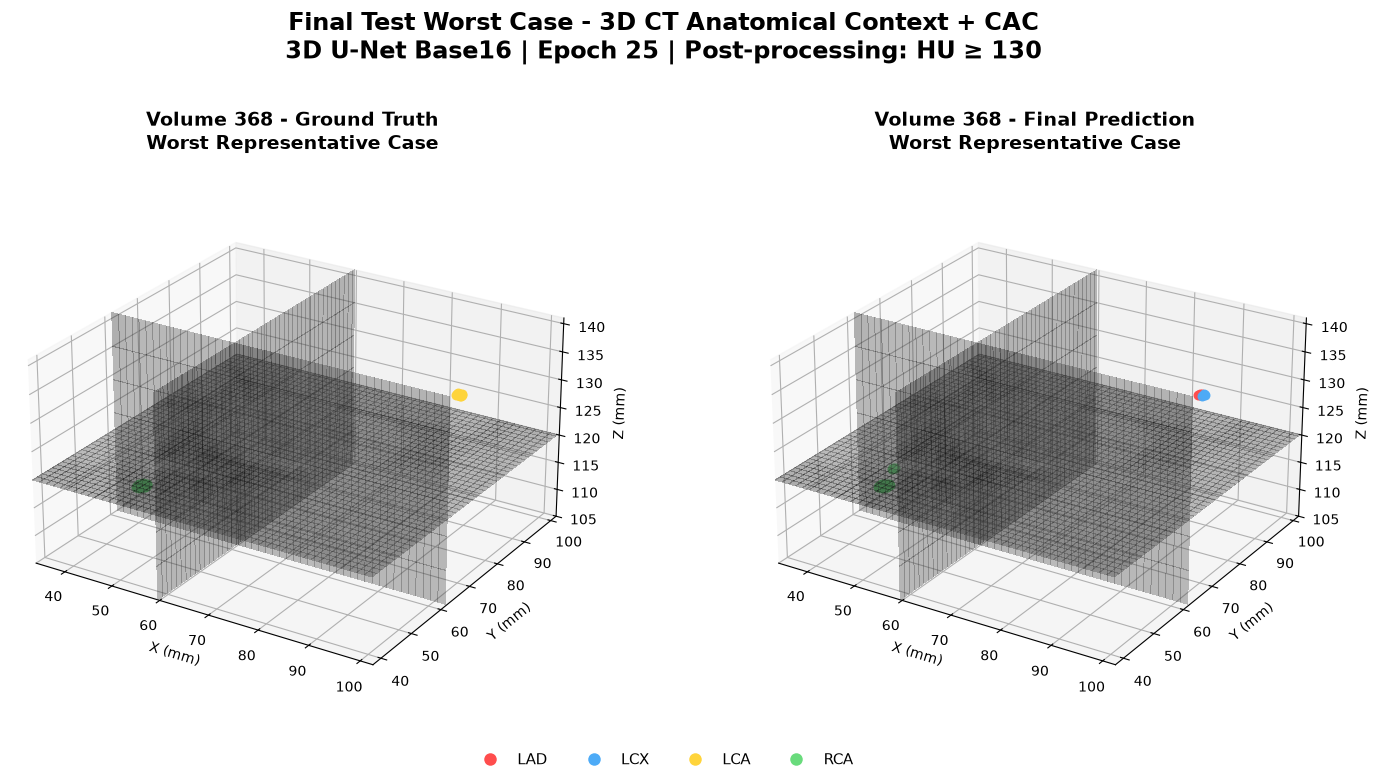


3D CT ANATOMICAL CONTEXT PASS ✅
Saved : /home/korea1/workspace/datasets/COCA/final_visualizations/final_test_worst_volume368_3d_ct_context.png
Case  : Worst Volume 368
Left  : Ground Truth
Right : Final Prediction
CT    : Axial + Coronal + Sagittal planes
CAC   : Physical 3D voxel coordinates
Model : FROZEN 🔒
Post  : HU >= 130 only FROZEN 🔒


: 

In [ ]:
# ============================================================
# FINAL VISUALIZATION - 3D CT ANATOMICAL CONTEXT
# - Worst Case : Volume 368
# - Orthogonal CT planes + CAC segmentation
# - Left  : Ground Truth
# - Right : Final Prediction
# - 혈관 surface rendering이 아닌 CT anatomical context 시각화
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.colors import Normalize
from matplotlib.lines import Line2D

# ============================================================
# 1. 설정
# ============================================================

CONTEXT_VOLUME_ID = "368"

CONTEXT_FIGURE_PATH = os.path.join(
    FINAL_VIS_ROOT,
    "final_test_worst_volume368_3d_ct_context.png"
)

CLASS_NAMES = {
    1: "LAD",
    2: "LCX",
    3: "LCA",
    4: "RCA",
}

CLASS_COLORS = {
    1: "#ff4d4d",
    2: "#4dabf7",
    3: "#ffd43b",
    4: "#69db7c",
}

CT_VMIN = -200
CT_VMAX = 1000

PLANE_DOWNSAMPLE = 2
XY_MARGIN = 35
Z_MARGIN = 4

# ============================================================
# 2. 데이터 Load
# ============================================================

ct = np.load(
    os.path.join(
        TEST_CACHE_ROOT,
        f"{CONTEXT_VOLUME_ID}_ct.npy"
    ),
    mmap_mode="r"
)

gt = np.load(
    os.path.join(
        TEST_CACHE_ROOT,
        f"{CONTEXT_VOLUME_ID}_gt.npy"
    ),
    mmap_mode="r"
)

pred = np.load(
    os.path.join(
        FINAL_TEST_POST_PRED_ROOT,
        f"{CONTEXT_VOLUME_ID}_pred.npy"
    ),
    mmap_mode="r"
)

spacing = tuple(
    float(v)
    for v in test_spacing_zyx[
        CONTEXT_VOLUME_ID
    ]
)

assert ct.shape == gt.shape == pred.shape

z_spacing, y_spacing, x_spacing = spacing

# ============================================================
# 3. GT + Prediction 전체 CAC를 포함하는 3D ROI
# ============================================================

union_mask = (
    (gt > 0)
    | (pred > 0)
)

coords = np.argwhere(
    union_mask
)

assert len(coords) > 0

z_min, y_min, x_min = coords.min(axis=0)
z_max, y_max, x_max = coords.max(axis=0)

z1 = max(
    0,
    int(z_min) - Z_MARGIN
)

z2 = min(
    ct.shape[0],
    int(z_max) + Z_MARGIN + 1
)

y1 = max(
    0,
    int(y_min) - XY_MARGIN
)

y2 = min(
    ct.shape[1],
    int(y_max) + XY_MARGIN + 1
)

x1 = max(
    0,
    int(x_min) - XY_MARGIN
)

x2 = min(
    ct.shape[2],
    int(x_max) + XY_MARGIN + 1
)

# Orthogonal plane 위치
z_center = int(
    np.round(
        coords[:, 0].mean()
    )
)

y_center = int(
    np.round(
        coords[:, 1].mean()
    )
)

x_center = int(
    np.round(
        coords[:, 2].mean()
    )
)

print("====== 3D CT CONTEXT SETUP ======")
print("Volume       :", CONTEXT_VOLUME_ID)
print("Shape        :", tuple(ct.shape))
print("Spacing      :", spacing)
print(
    "ROI          :",
    f"Z[{z1}:{z2}] "
    f"Y[{y1}:{y2}] "
    f"X[{x1}:{x2}]"
)
print(
    "Plane Center :",
    f"Z={z_center}, "
    f"Y={y_center}, "
    f"X={x_center}"
)

# ============================================================
# 4. CT Plane Helper
# ============================================================

ct_norm = Normalize(
    vmin=CT_VMIN,
    vmax=CT_VMAX,
    clip=True
)

def make_gray_facecolors(image, alpha=0.32):
    colors = plt.cm.gray(
        ct_norm(image)
    )

    colors[..., 3] = alpha

    return colors

def add_ct_planes(ax):
    ds = PLANE_DOWNSAMPLE

    # --------------------------------------------------------
    # Axial plane : Z 고정
    # --------------------------------------------------------

    ys = np.arange(
        y1,
        y2,
        ds
    )

    xs = np.arange(
        x1,
        x2,
        ds
    )

    axial = np.asarray(
        ct[
            z_center,
            y1:y2:ds,
            x1:x2:ds
        ]
    )

    X, Y = np.meshgrid(
        xs * x_spacing,
        ys * y_spacing
    )

    Z = np.full_like(
        X,
        z_center * z_spacing,
        dtype=float
    )

    ax.plot_surface(
        X,
        Y,
        Z,
        facecolors=make_gray_facecolors(
            axial
        ),
        shade=False,
        linewidth=0,
        antialiased=False
    )

    # --------------------------------------------------------
    # Coronal plane : Y 고정
    # --------------------------------------------------------

    zs = np.arange(
        z1,
        z2,
        ds
    )

    xs = np.arange(
        x1,
        x2,
        ds
    )

    coronal = np.asarray(
        ct[
            z1:z2:ds,
            y_center,
            x1:x2:ds
        ]
    )

    X, Z = np.meshgrid(
        xs * x_spacing,
        zs * z_spacing
    )

    Y = np.full_like(
        X,
        y_center * y_spacing,
        dtype=float
    )

    ax.plot_surface(
        X,
        Y,
        Z,
        facecolors=make_gray_facecolors(
            coronal
        ),
        shade=False,
        linewidth=0,
        antialiased=False
    )

    # --------------------------------------------------------
    # Sagittal plane : X 고정
    # --------------------------------------------------------

    zs = np.arange(
        z1,
        z2,
        ds
    )

    ys = np.arange(
        y1,
        y2,
        ds
    )

    sagittal = np.asarray(
        ct[
            z1:z2:ds,
            y1:y2:ds,
            x_center
        ]
    )

    Y, Z = np.meshgrid(
        ys * y_spacing,
        zs * z_spacing
    )

    X = np.full_like(
        Y,
        x_center * x_spacing,
        dtype=float
    )

    ax.plot_surface(
        X,
        Y,
        Z,
        facecolors=make_gray_facecolors(
            sagittal
        ),
        shade=False,
        linewidth=0,
        antialiased=False
    )

# ============================================================
# 5. CAC Scatter Helper
# ============================================================

def add_cac_points(ax, segmentation):
    for class_id in range(1, 5):
        class_coords = np.argwhere(
            segmentation == class_id
        )

        if len(class_coords) == 0:
            continue

        z_mm = (
            class_coords[:, 0]
            * z_spacing
        )

        y_mm = (
            class_coords[:, 1]
            * y_spacing
        )

        x_mm = (
            class_coords[:, 2]
            * x_spacing
        )

        ax.scatter(
            x_mm,
            y_mm,
            z_mm,
            s=38,
            c=CLASS_COLORS[class_id],
            alpha=0.95,
            depthshade=False
        )

# ============================================================
# 6. Plot
# ============================================================

fig = plt.figure(
    figsize=(15, 8)
)

panels = [
    (
        gt,
        "Ground Truth"
    ),
    (
        pred,
        "Final Prediction"
    ),
]

for index, (
    segmentation,
    panel_title
) in enumerate(
    panels,
    start=1
):
    ax = fig.add_subplot(
        1,
        2,
        index,
        projection="3d"
    )

    add_ct_planes(ax)
    add_cac_points(
        ax,
        segmentation
    )

    ax.set_title(
        (
            f"Volume 368 - {panel_title}\n"
            "Worst Representative Case"
        ),
        fontsize=14,
        fontweight="bold",
        pad=12
    )

    ax.set_xlabel(
        "X (mm)"
    )

    ax.set_ylabel(
        "Y (mm)"
    )

    ax.set_zlabel(
        "Z (mm)"
    )

    # 동일 physical ROI
    ax.set_xlim(
        x1 * x_spacing,
        (x2 - 1) * x_spacing
    )

    ax.set_ylim(
        y1 * y_spacing,
        (y2 - 1) * y_spacing
    )

    ax.set_zlim(
        z1 * z_spacing,
        (z2 - 1) * z_spacing
    )

    x_extent = (
        (x2 - x1)
        * x_spacing
    )

    y_extent = (
        (y2 - y1)
        * y_spacing
    )

    z_extent = (
        (z2 - z1)
        * z_spacing
    )

    ax.set_box_aspect(
        (
            x_extent,
            y_extent,
            z_extent
        )
    )

    ax.view_init(
        elev=25,
        azim=-58
    )

# ============================================================
# 7. Legend / Title
# ============================================================

legend_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="",
        markerfacecolor=CLASS_COLORS[class_id],
        markeredgecolor="none",
        markersize=9,
        label=CLASS_NAMES[class_id]
    )
    for class_id in range(1, 5)
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=4,
    frameon=False,
    fontsize=11,
    bbox_to_anchor=(
        0.5,
        0.015
    )
)

fig.suptitle(
    (
        "Final Test Worst Case - "
        "3D CT Anatomical Context + CAC\n"
        "3D U-Net Base16 | Epoch 25 | "
        "Post-processing: HU ≥ 130"
    ),
    fontsize=17,
    fontweight="bold",
    y=0.98
)

plt.tight_layout(
    rect=[
        0.0,
        0.06,
        1.0,
        0.91
    ]
)

# ============================================================
# 8. Save
# ============================================================

plt.savefig(
    CONTEXT_FIGURE_PATH,
    dpi=240,
    bbox_inches="tight"
)

plt.show()

assert os.path.exists(
    CONTEXT_FIGURE_PATH
)

print("\n==========================================")
print("3D CT ANATOMICAL CONTEXT PASS ✅")
print("Saved :", CONTEXT_FIGURE_PATH)
print("Case  : Worst Volume 368")
print("Left  : Ground Truth")
print("Right : Final Prediction")
print("CT    : Axial + Coronal + Sagittal planes")
print("CAC   : Physical 3D voxel coordinates")
print("Model : FROZEN 🔒")
print("Post  : HU >= 130 only FROZEN 🔒")
print("==========================================")